In [1]:
import torch
import matplotlib.pyplot as plt
import torch.nn as nn


%matplotlib inline
import slmsuite
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib as mpl
from slmsuite.holography import toolbox
from slmsuite.holography.toolbox import phase
from matplotlib import pyplot as plt
from src.plots import *
from src.config import base_path
from src.utils import get_cam
from slmsuite.hardware.slms.simulated import SimulatedSLM
from slmsuite.hardware.cameras.simulated import SimulatedCamera
from slmsuite.hardware.cameraslms import FourierSLM
from slmsuite.holography.algorithms import FeedbackHologram

from src.slm_initialise import slm_initialise
from src.utils import plot_cam
import pickle
%load_ext autoreload
%autoreload 2
# mpl.rc('image', cmap='Blues')

In [21]:
#Create a virtual SLM and camera
from slmsuite.hardware.slms.simulated import SimulatedSLM
from slmsuite.hardware.cameras.simulated import SimulatedCamera
from slmsuite.hardware.cameraslms import FourierSLM
wav_um = 1.064
slm_shape = (1024, 1280) # (give height, width)
cam_shape = (1080,1440) # (give height, width)
slm = SimulatedSLM((slm_shape[1], slm_shape[0]), pitch_um=(8, 8), wav_um=wav_um) #(width,height)
slm.set_source_analytic(sim=False,x0 =  100*80, y0 = 0, a =  1, c = 0,wx = 500*8,wy = 500*8)
slm.fit_source_amplitude()
cam = SimulatedCamera(slm,(cam_shape[1], cam_shape[0]), pitch_um=(3.45,3.45)) #(width,height)
# The setup (a FourierSLM setup with a camera placed in the Fourier plane of an SLM) holds the camera and SLM.
# Tie the camera and SLM together with an analytic calibration.
fs = FourierSLM(cam, slm)
M, b = fs.fourier_calibration_build(
    f_eff=80000.,                              # f_eff of 80000 wavelengths or 80 mm with the default 1 um wavelength
    theta=5 * np.pi / 180,
)
cam.set_affine(M, b)
fs.fourier_calibrate_analytic(M, b)


{'M': array([[24578.57759466, -2150.34690512],
        [ 2150.34690512, 24578.57759466]]),
 'b': array([[720.],
        [540.]]),
 'a': array([[0],
        [0]]),
 '__version__': '0.2.1',
 '__time__': '2025-08-25 22:41:22.372839',
 '__timestamp__': 1756179682.372839,
 '__meta__': {'__class__': '<slmsuite.hardware.cameraslms.FourierSLM object at 0x0000014BDD3CA0C0>',
  'name': 'camera-SLM',
  'cam': {'__class__': '<slmsuite.hardware.cameras.simulated.SimulatedCamera object at 0x0000014C01A45C40>',
   'name': 'camera',
   'shape': (1080, 1440),
   'bitdepth': 8,
   'bitresolution': 256,
   'pitch_um': array([3.45, 3.45]),
   'exposure_s': 1,
   'exposure_bounds_s': None,
   'averaging': None,
   'hdr': None,
   'woi': (0, 1440, 0, 1080),
   'default_shape': (1080, 1440)},
  'slm': {'__class__': '<slmsuite.hardware.slms.simulated.SimulatedSLM object at 0x0000014C00AD4140>',
   'name': 'SLM',
   'shape': (1024, 1280),
   'bitdepth': 8,
   'bitresolution': 256,
   'pitch_um': array([8., 8.]

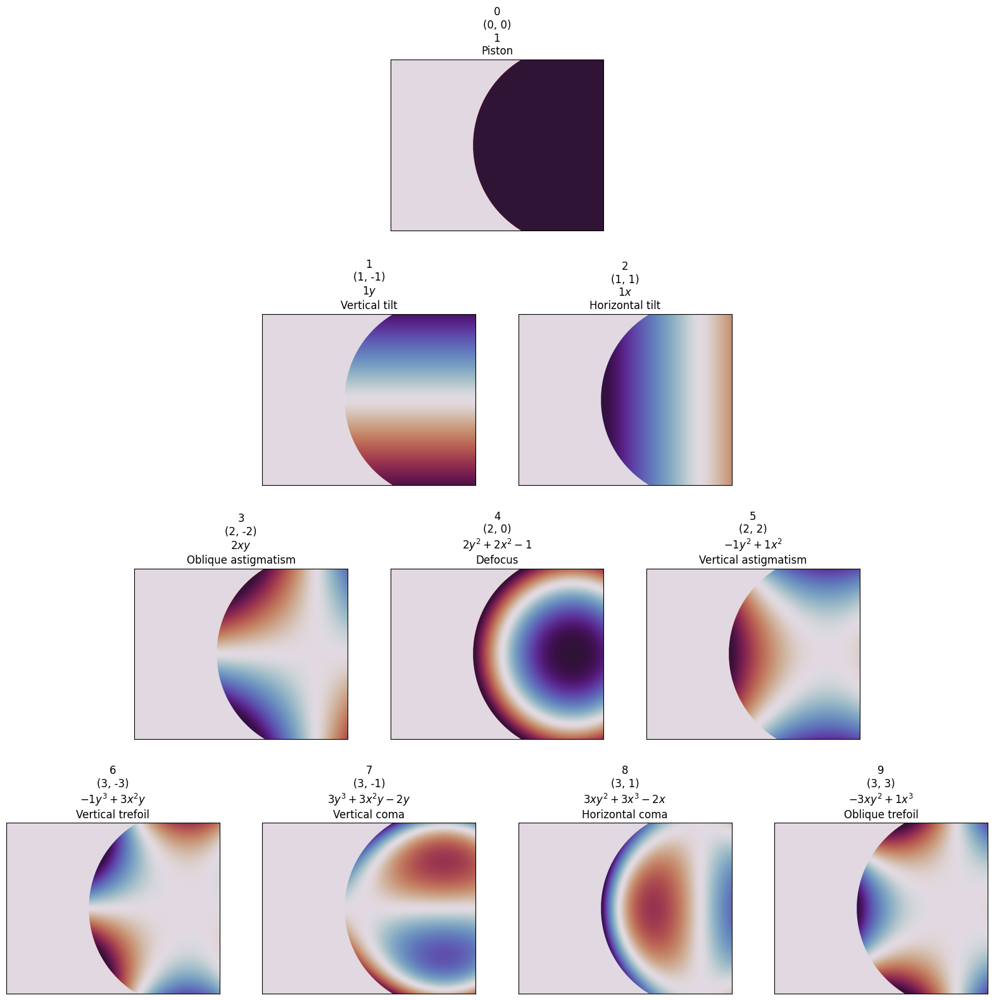

In [23]:
from slmsuite.holography.toolbox.phase import zernike_pyramid_plot

plt.figure(figsize=(20,20))
zernike_pyramid_plot(fs.slm, order=3)

In [12]:
slm.get_source_center()

array([640, 511], dtype=int64)

In [14]:
plt.imshow(slm.source['amplitude'])

KeyError: 'amplitude'

In [178]:
from slmsuite.holography.toolbox.phase import zernike

zernke_42 = zernike(slm, 2)

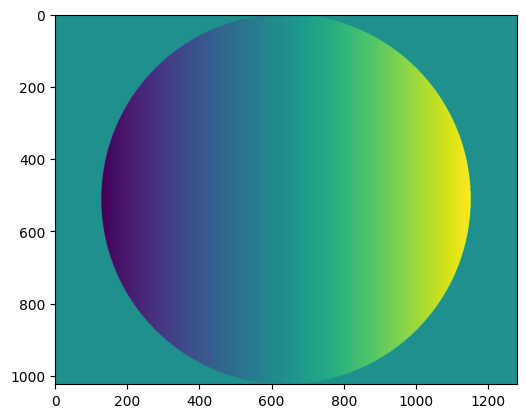

In [179]:
plt.imshow(zernke_42)

# test this peak detection from cgpt

In [22]:
import numpy as np
from skimage.feature import peak_local_max

def refine_centers(image, expected_centers, patch_size=40, min_distance=1, threshold_abs=None):
    half = patch_size // 2
    refined_centers = []

    for (x_exp, y_exp) in expected_centers:
        x_exp, y_exp = int(round(x_exp)), int(round(y_exp))
        patch = image[y_exp - half:y_exp + half, x_exp - half:x_exp + half]

        # Detect all peaks in this patch
        peaks = peak_local_max(
            patch,
            min_distance=min_distance,
            threshold_abs=threshold_abs,
            num_peaks=1  # adjust if needed
        )

        if len(peaks) == 0:
            refined_centers.append((x_exp, y_exp))
            continue

        # Find the peak closest to the expected center (in patch coordinates)
        patch_center = np.array([half, half])
        distances = np.linalg.norm(peaks - patch_center, axis=1)
        closest_peak = peaks[np.argmin(distances)]

        # Convert local peak coords to global image coords
        y_actual = y_exp - half + closest_peak[0]
        x_actual = x_exp - half + closest_peak[1]

        refined_centers.append((x_actual, y_actual))

    return refined_centers
import numpy as np

def find_actual_centers(image, expected_centers, patch_size=20):
    half = patch_size // 2
    actual_centers = []

    for (x_exp, y_exp) in expected_centers:
        x_exp, y_exp = int(round(x_exp)), int(round(y_exp))
        patch = image[y_exp - half:y_exp + half, x_exp - half:x_exp + half]

        Y, X = np.indices(patch.shape)
        total = patch.sum()
        if total == 0:
            actual_centers.append((x_exp, y_exp))  # fallback
            continue

        x_center = (X * patch).sum() / total
        y_center = (Y * patch).sum() / total

        # Convert to global coordinates
        actual_x = x_exp - half + x_center
        actual_y = y_exp - half + y_center

        actual_centers.append((actual_x, actual_y))

    return actual_centers


In [27]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)])

In [4]:
spot_locations

NameError: name 'spot_locations' is not defined

In [157]:
refined_centres = refine_centers(loaded[5]["images"][0],spot_locations,40)

# Actual SLM

In [122]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb,g
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
from slmsuite.holography.toolbox.phase import zernike_sum,zernike_get_string,ZERNIKE_NAMES 
from src.algos import *
from src.zernike import get_zernike_calibrations,get_cholo_phase,get_cholo_bb_g_phase,fit_metric,fit_metric_udf,plot_parabola,get_zernike_dict_from_metrics_df,get_zernike_metrics_df,zernike_names
from src import global_store
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [123]:
fs = slm_initialise(force=True,verbose=True)

Display Positions:
#,  Position
0,  x=1920, y=0, width=1280, height=1024
1,  x=0, y=0, width=1920, height=1200 (main)
Initializing pyglet... success
Searching for window with display_number=0... success
Creating window... [Errno 2] No such file or directory: 'C:\\Users\\QC\\Envs\\SLM_new\\Lib\\site-packages\\slmsuite\\hardware\\..\\..\\docs\\source\\static\\slmsuite-notext-16x16.png'
success
Looking for cameras... success
ThorCam sn '12975' initializing... success


array([[2, 1, 1, ..., 2, 1, 1],
       [1, 2, 2, ..., 2, 1, 1],
       [2, 1, 1, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 2, 2, 1],
       [2, 2, 1, ..., 1, 1, 2],
       [2, 1, 1, ..., 1, 2, 1]], dtype=uint16)

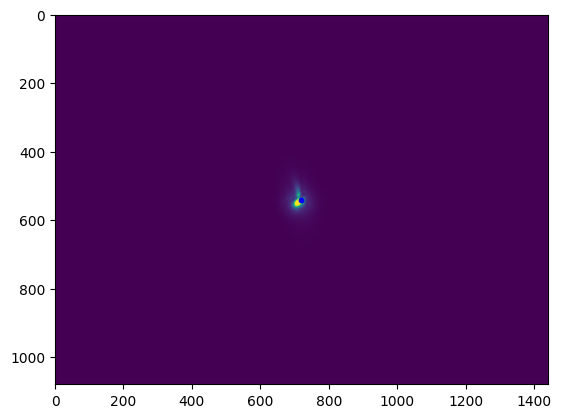

In [124]:
plot_cam(global_store.fs,phase="zero",centre=True, save=True)

In [373]:
fs.cam.pitch_um

array([3.45, 3.45])

smooth:   0%|          | 0/16 [00:00<?, ?it/s]

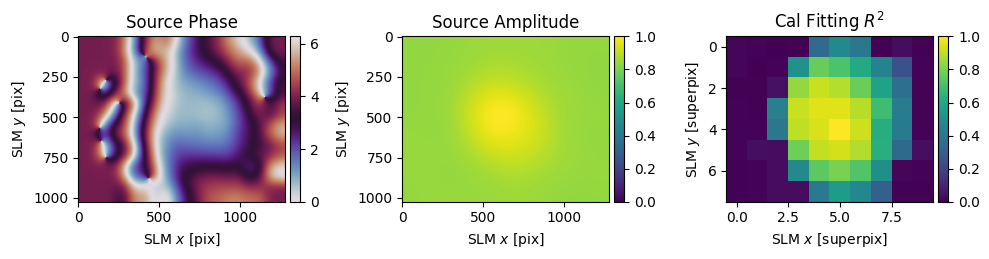

array([[1, 2, 1, ..., 1, 1, 1],
       [1, 1, 2, ..., 1, 2, 1],
       [2, 1, 1, ..., 1, 1, 2],
       ...,
       [1, 1, 1, ..., 1, 1, 2],
       [1, 2, 1, ..., 1, 2, 1],
       [1, 1, 2, ..., 2, 1, 2]], dtype=uint16)

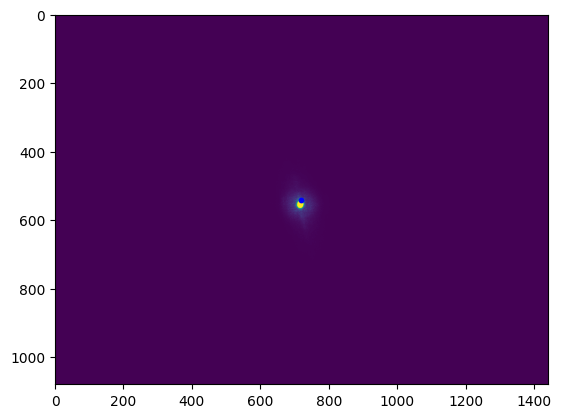

In [125]:
calibrate(fs,vendor = False,refresh = False)
sp_calibrate(fs,refresh=False)
plot_cam(fs,phase="zero",centre=True, save=True)

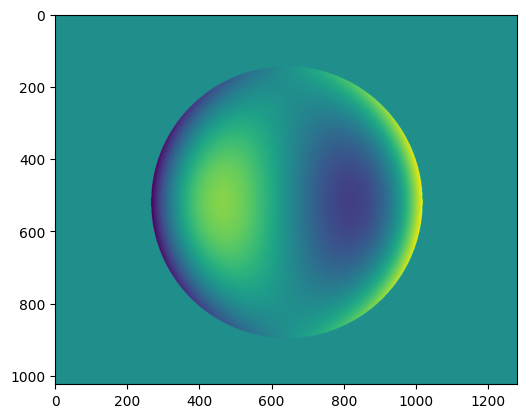

In [5]:
from slmsuite.holography.toolbox.phase import zernike
zernke_42 = zernike(fs.slm, 8,use_mask = True)
plt.imshow(zernke_42)

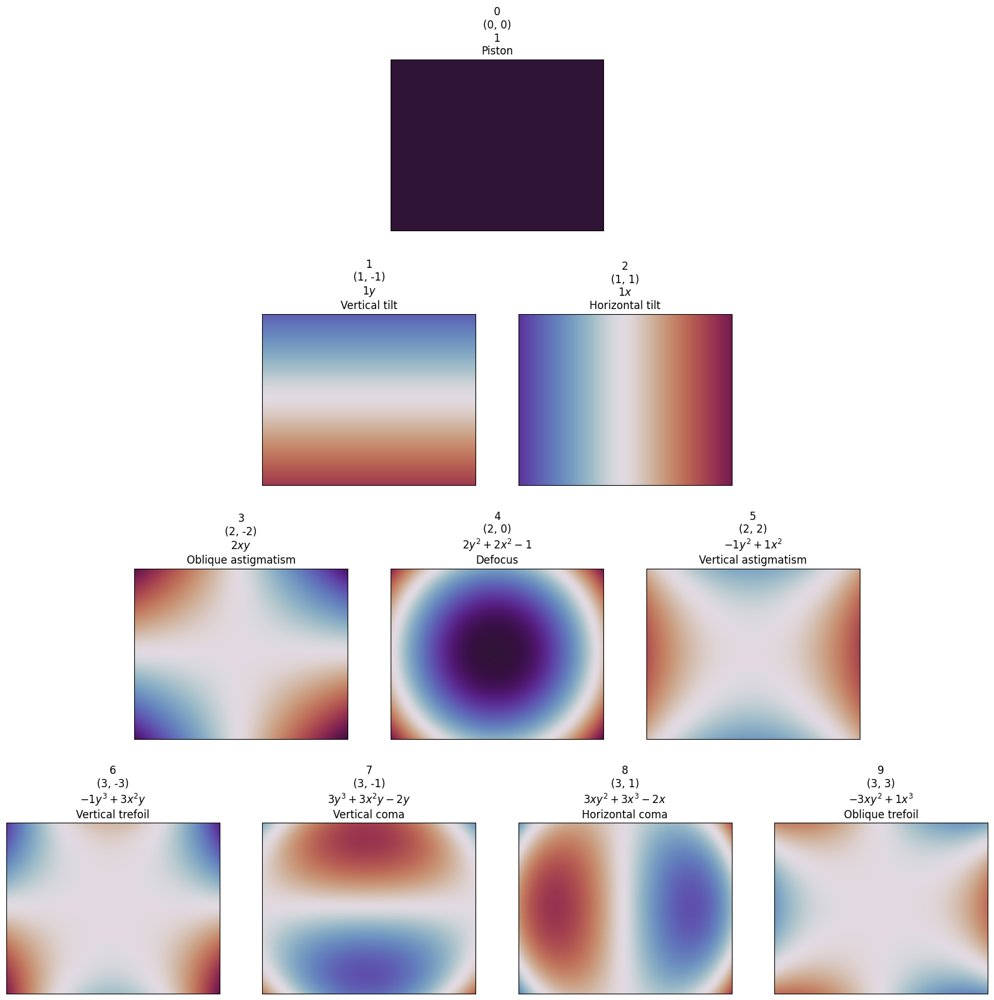

In [33]:
from slmsuite.holography.toolbox.phase import zernike_pyramid_plot

plt.figure(figsize=(20,20))
zernike_pyramid_plot(fs.slm, order=3,use_mask = False)

# Zernike testing

Iterate a single zernike polynomial and get the cam images
(shift the zernike polynomials to the slm centre)
visualise the plots to see the effect of aberration
calculate metric and visualise for convexity or atleast a minima

for a given zernike term
    for a given spot 
        find fit metrics (rmse error??)


In [55]:
np.linspace(-1.5, 1.5, 31)

array([-1.5, -1.4, -1.3, -1.2, -1.1, -1. , -0.9, -0.8, -0.7, -0.6, -0.5,
       -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5,  0.6,
        0.7,  0.8,  0.9,  1. ,  1.1,  1.2,  1.3,  1.4,  1.5])

writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writin

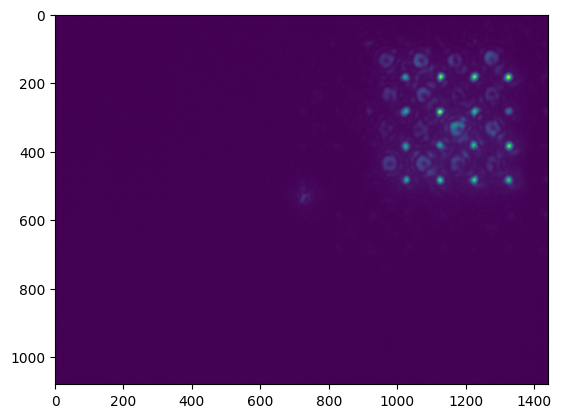

In [56]:
base_phase = np.load(base_path/ 'data' / 'zernike' / 'raw' / 'spots_uc_32_spot_bb_phase.npy')
data = {}
zernike_indices = [i for i in range(3,25)]
for zernike_index in zernike_indices:
    zernike_term_phase = zernike(fs.slm, zernike_index,use_mask = False)
    data[zernike_index] = {
        "w": [],
        "images": []
    }
    for w in np.linspace(-1.5, 1.5, 31):  
        phase = base_phase + w * zernike_term_phase
        image = save_cam(fs,phase = phase,sleep = 4)
        data[zernike_index]["w"].append(w)
        data[zernike_index]["images"].append(image)
save_path = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_80w.pkl"
with open(save_path, 'wb') as f:
    pickle.dump(data, f)

In [57]:
save_path = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_80w.pkl"
with open(save_path, 'rb') as f:
    loaded = pickle.load(f)

# Access:
loaded[7]["w"]
loaded[7]["images"][0]


array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 2, ..., 1, 1, 2],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [1, 2, 1, ..., 1, 1, 1],
       [1, 2, 1, ..., 1, 1, 2],
       [1, 1, 2, ..., 2, 2, 1]], dtype=uint16)

In [ ]:
# plt.imshow(loaded[32]["images"][150])

KeyError: 32

In [59]:
from lmfit.models import Gaussian2dModel
import numpy as np

def get_tweezer_metrics(target, waist_multiplier=7):
    ny, nx = target.shape
    y, x = np.mgrid[:ny, :nx]
    x_flat = x.ravel()
    y_flat = y.ravel()
    z_flat = target.ravel()

    # Fit 2D Gaussian
    model = Gaussian2dModel()
    params = model.guess(z_flat, x=x_flat, y=y_flat)
    result = model.fit(z_flat, params, x=x_flat, y=y_flat, max_nfev=10000)

    # Best-fit parameters
    height = result.params["height"].value
    sigmax = result.params["sigmax"].value
    sigmay = result.params["sigmay"].value
    centerx = result.params["centerx"].value
    centery = result.params["centery"].value

    # Fit quality
    fitted = result.best_fit
    residuals = z_flat - fitted
    rmse = np.sqrt(np.mean(residuals**2))
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((z_flat - np.mean(z_flat))**2)
    r_squared = 1 - (ss_res / ss_tot)

    # FWHM and ellipticity
    fwhm_x = 2 * np.sqrt(2 * np.log(2)) * sigmax
    fwhm_y = 2 * np.sqrt(2 * np.log(2)) * sigmay
    ellipticity = sigmax / sigmay if sigmay != 0 else np.inf

    # === Strehl-style metric ===
    # Use window size based on waist multiplier (e.g., 5x or 7x waist)
    sigma_avg = (sigmax + sigmay) / 2
    window_size = int(round(waist_multiplier * sigma_avg))

    # Make sure it's odd (centered box)
    if window_size % 2 == 0:
        window_size += 1

    half = window_size // 2
    cx, cy = int(round(centerx)), int(round(centery))

    # Crop patch around fitted center
    y_start = max(cy - half, 0)
    y_end   = min(cy + half + 1, ny)
    x_start = max(cx - half, 0)
    x_end   = min(cx + half + 1, nx)

    patch = target[y_start:y_end, x_start:x_end]
    if patch.size > 0 and patch.sum() > 0:
        strehl_prime = patch.max() / patch.sum()
    else:
        strehl_prime = 0.0  # fallback in case of zero patch

    return {
        "height": height,
        "sigmax": sigmax,
        "sigmay": sigmay,
        "centerx": centerx,
        "centery": centery,
        "fwhm_x": fwhm_x,
        "fwhm_y": fwhm_y,
        "ellipticity": ellipticity,
        "strehl_prime": strehl_prime,
        "rmse": rmse,
        "r_squared": r_squared,
        "window_px": window_size
    }


In [60]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)])
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)])

In [61]:
spot_locations

array([[1030,  180],
       [1030,  280],
       [1030,  380],
       [1030,  480],
       [1130,  180],
       [1130,  280],
       [1130,  380],
       [1130,  480],
       [1230,  180],
       [1230,  280],
       [1230,  380],
       [1230,  480],
       [1330,  180],
       [1330,  280],
       [1330,  380],
       [1330,  480]])

In [62]:
# refined_centres[0][1]
# plt.imshow()

In [63]:
results = []
crop_pixels = 30

for zernike_index, zernike_data in loaded.items():
    images = zernike_data["images"]  # list of images at different w

    for w_index, image in enumerate(images):
        refined_centres = refine_centers(image, spot_locations, 200)
        for (expected, refined) in zip(spot_locations, refined_centres):
            cx, cy = refined
            crop_details = (
                slice(cy - crop_pixels, cy + crop_pixels),
                slice(cx - crop_pixels, cx + crop_pixels)
            )

            cropped_image = image[crop_details]
            metrics = get_tweezer_metrics(cropped_image)

            results.append({
                "zernike_index": zernike_index,
                "w_index": w_index,
                "w":zernike_data['w'][w_index],
                "expected_x": expected[0],
                "expected_y": expected[1],
                "refined_x": cx,
                "refined_y": cy,
                **metrics
            })



In [64]:

# pdf = pd.DataFrame(results)

In [65]:
pdf = pd.DataFrame(results)

In [ ]:
import pandas as pd
load_path = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_80w_pdf.csv"
# pdf.to_csv(load_path)
pdf = pd.read_csv(load_path)

In [134]:
pdf[(pdf['w_index'] == 4)&(pdf['zernike_index'] == 7)&(pdf['expected_y']==180)]

,Unnamed: 0,zernike_index,w_index,w,expected_x,expected_y,refined_x,refined_y,height,sigmax,sigmay,centerx,centery,fwhm_x,fwhm_y,ellipticity,strehl_prime,rmse,r_squared,window_px
2048,2048,7,4,-1.1,1030,180,1125,184,78.224216,8.668359,7.382955,32.487898,29.155838,20.412425,17.385530,1.174104,0.002184,5.571545,0.862859,57
2052,2052,7,4,-1.1,1130,180,1224,183,80.655969,8.158191,7.504928,32.180415,29.874907,19.211071,17.672754,1.087045,0.002431,3.956971,0.935269,55
2056,2056,7,4,-1.1,1230,180,1324,182,99.204377,8.003252,7.118814,30.899539,31.684333,18.846218,16.763525,1.124240,0.002583,4.162641,0.950713,53
2060,2060,7,4,-1.1,1330,180,1324,182,99.204377,8.003252,7.118814,30.899539,31.684333,18.846218,16.763525,1.124240,0.002583,4.162641,0.950713,53


In [51]:
pdf[(pdf['zernike_index'] == 7)&(pdf['expected_y']==180)&(pdf['expected_x']==1030)]

,zernike_index,w_index,w,expected_x,expected_y,refined_x,refined_y,height,sigmax,sigmay,centerx,centery,fwhm_x,fwhm_y,ellipticity,strehl_prime,rmse,r_squared,window_px
1920,7,0,0.000000,1030,180,1125,182,140.191790,5.633258,6.271790,30.615333,29.997931,13.265308,14.768937,0.898190,0.004133,4.439261,0.958723,43
1936,7,1,0.344828,1030,180,1124,181,140.909978,5.642965,6.254514,30.585943,31.050802,13.288167,14.728256,0.902223,0.004091,4.457284,0.958808,43
1952,7,2,0.689655,1030,180,1124,182,140.882305,5.647762,6.268966,29.742252,30.075870,13.299462,14.762287,0.900908,0.004161,4.445980,0.959099,43
1968,7,3,1.034483,1030,180,1123,181,139.855722,5.652258,6.264871,29.910403,31.130798,13.310051,14.752643,0.902215,0.004013,4.456801,0.958241,43
1984,7,4,1.379310,1030,180,1122,182,139.042313,5.664528,6.258125,29.851062,30.106225,13.338944,14.736758,0.905148,0.004147,4.439448,0.958128,43
2000,7,5,1.724138,1030,180,1121,182,138.161154,5.718981,6.245469,29.840166,30.133124,13.467171,14.706956,0.915701,0.004142,4.511519,0.956465,43
2016,7,6,2.068966,1030,180,1120,182,137.558798,5.730122,6.224471,30.111698,30.189091,13.493405,14.657510,0.920580,0.004102,4.522698,0.955800,43
2032,7,7,2.413793,1030,180,1119,182,136.548741,5.777526,6.209303,30.152740,30.220121,13.605034,14.621791,0.930463,0.004078,4.518129,0.955393,43
2048,7,8,2.758621,1030,180,1119,182,135.258773,5.831740,6.220841,29.173049,30.270878,13.732699,14.648962,0.937452,0.004050,4.481203,0.955762,43
2064,7,9,3.103448,1030,180,1118,181,134.259483,5.864163,6.245188,29.155345,31.317693,13.809048,14.706294,0.938989,0.004012,4.516727,0.954744,43


In [197]:
pdf['strehl_prime_scaled'] = pdf['strehl_prime']*200

<Axes: >

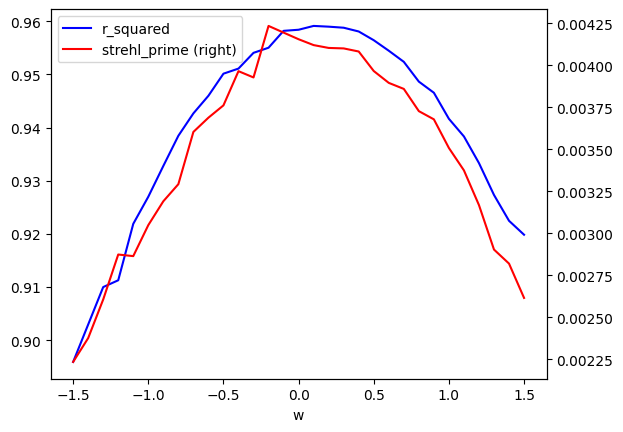

In [139]:
subset = pdf[
    (pdf['zernike_index'] == 3) &
    (pdf['expected_y'] == 180) &
    (pdf['expected_x'] == 1030)
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)

In [ ]:
#15 - 31 bad data or no trends
#35-37, 43-46 too many oscillations

{'height': 80.73212775567761,
 'sigmax': 6.763867516581283,
 'sigmay': 6.50473431040791,
 'centerx': 43.579810910779855,
 'centery': 42.18726084479169,
 'fwhm_x': 15.927690809979312,
 'fwhm_y': 15.317478741749117,
 'ellipticity': 1.039837631147939,
 'strehl_prime': 0.0036013523445538732,
 'rmse': 5.646980991164243,
 'r_squared': 0.7210885826707873,
 'window_px': 47}

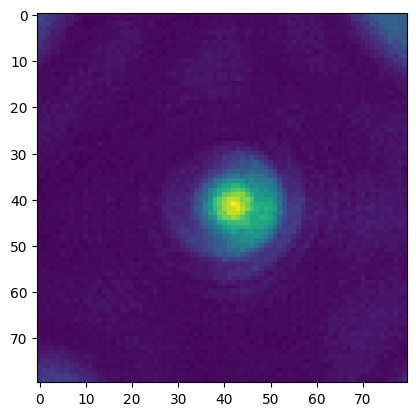

In [ ]:
zernike_index = 7
crop_pixels = 40
w =70
refined_centre = (1030,	180)
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[zernike_index]["images"][w][crop_details])
get_tweezer_metrics(loaded[zernike_index]["images"][w][crop_details])



In [252]:
bb_locations

array([[ 980,  130],
       [ 980,  230],
       [ 980,  330],
       [ 980,  430],
       [1080,  130],
       [1080,  230],
       [1080,  330],
       [1080,  430],
       [1180,  130],
       [1180,  230],
       [1180,  330],
       [1180,  430],
       [1280,  130],
       [1280,  230],
       [1280,  330],
       [1280,  430]])

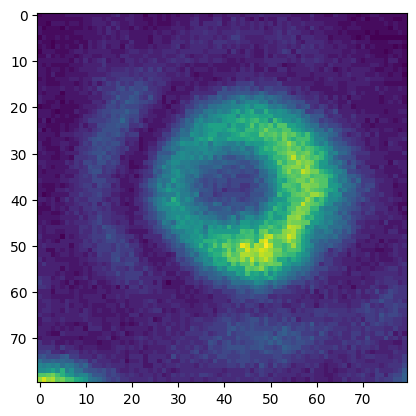

In [306]:
crop_pixels = 40
refined_centre = (1091, 134)
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[7]["images"][1][crop_details])

In [390]:
import numpy as np
from scipy import ndimage as ndi
from scipy.signal import fftconvolve

# ----------------------- utilities -----------------------

def robust_norm(patch):
    """Robustly normalize to ~zero-mean, unit-scale using MAD."""
    med = np.median(patch)
    mad = np.median(np.abs(patch - med)) + 1e-9
    z = (patch - med) / (1.4826 * mad)
    return z.astype(np.float32)

def crop_patch_centered(img, y, x, half):
    """
    Return a (2*half+1, 2*half+1) patch centered on (y,x).
    Reflect-pads if near borders so the patch stays centered.
    """
    H, W = img.shape
    size = 2*half + 1
    y1, y2 = y - half, y + half + 1
    x1, x2 = x - half, x + half + 1

    pad_top    = max(0, -y1)
    pad_bottom = max(0, y2 - H)
    pad_left   = max(0, -x1)
    pad_right  = max(0, x2 - W)

    y1c, y2c = max(0, y1), min(H, y2)
    x1c, x2c = max(0, x1), min(W, x2)
    patch = img[y1c:y2c, x1c:x2c]

    if pad_top or pad_bottom or pad_left or pad_right:
        patch = np.pad(patch, ((pad_top, pad_bottom), (pad_left, pad_right)), mode='reflect')

    # ensure exact shape (can happen if image is tiny)
    patch = patch[:size, :size]
    return patch

def ring_kernel(radius, thickness=3, center_frac=0.45):
    """
    Build a zero-mean, unit-energy ring template:
      +1 on an annulus at 'radius' (±thickness/2),
      -1 in a central disk of radius = center_frac * radius,
    normalized so sum=0 and ||K||_2 = 1. (Good for NCC-like scoring.)
    """
    r  = float(radius)
    t  = float(thickness)
    rc = max(1.0, center_frac * r)

    size = int(np.ceil(2*(r + t) + 5))  # generous margin, odd
    if size % 2 == 0: size += 1
    c = size // 2

    yy, xx = np.mgrid[0:size, 0:size]
    rr = np.sqrt((yy - c)**2 + (xx - c)**2)

    ring  = (np.abs(rr - r) <= (t/2.0)).astype(np.float32)
    center = (rr <= rc).astype(np.float32)

    # Zero-mean by balancing areas
    Ar = ring.sum() + 1e-9
    Ac = center.sum() + 1e-9
    ker = (ring / Ar) - (center / Ac)

    # Unit L2-norm
    ker /= np.sqrt((ker**2).sum() + 1e-12)
    return ker

def quad_peak_subpixel(Z):
    """Sub-pixel peak from a 2D quadratic fit around the discrete maximum."""
    h, w = Z.shape
    cy, cx = h//2, w//2
    y, x = np.mgrid[-cy:h-cy, -cx:w-cx]
    A = np.column_stack([x*x, y*y, x*y, x, y, np.ones_like(x)])
    b = Z.reshape(-1, 1)
    try:
        coef, *_ = np.linalg.lstsq(A, b, rcond=None)
        a, b2, c, d, e, f = coef.flatten()
        det = 4*a*b2 - c*c
        if abs(det) < 1e-10:
            return 0.0, 0.0
        x0 = (c*e - 2*b2*d) / det
        y0 = (c*d - 2*a*e) / det
        # clamp within window
        return float(np.clip(y0, -cy, cy)), float(np.clip(x0, -cx, cx))
    except np.linalg.LinAlgError:
        return 0.0, 0.0

def ringness_metrics(patch, cy, cx, r_best, thickness=3, center_frac=0.45):
    """
    Compute bottle-ness:
      - I_center: mean in disk of radius rc
      - I_ring:   mean in annulus |r - r_best| <= t/2
      - I_bg:     mean in outer annulus [r_best+1.5t, r_best+3t]
    Returns: contrast = I_ring - I_center, ratio = I_ring / (I_center+eps), snr = (I_ring - I_bg)/std
    """
    H, W = patch.shape
    yy, xx = np.mgrid[0:H, 0:W]
    rr = np.sqrt((yy - cy)**2 + (xx - cx)**2)
    t = float(thickness)
    rc = max(1.0, center_frac * float(r_best))

    center_mask = (rr <= rc)
    ring_mask   = (np.abs(rr - r_best) <= (t/2.0))
    bg_mask     = (rr >= (r_best + 1.5*t)) & (rr <= (r_best + 3.0*t))

    if not np.any(center_mask) or not np.any(ring_mask):
        return 0.0, 1.0, 0.0, np.nan, np.nan, np.nan

    I_center = float(patch[center_mask].mean())
    I_ring   = float(patch[ring_mask].mean())
    I_bg     = float(patch[bg_mask].mean()) if np.any(bg_mask) else float(np.median(patch))

    contrast = I_ring - I_center
    ratio    = I_ring / (I_center + 1e-6)
    snr      = (I_ring - I_bg) / (patch.std() + 1e-6)
    return contrast, ratio, snr, I_center, I_ring, I_bg

# ----------------------- main function -----------------------

def refine_bottle_centers(
    image,
    expected_centers_xy,
    patch_half=40,                 # half-size of patch; should exceed max radius + margins
    radii=(6, 24),                 # search radii range (pixels)
    radius_step=1,
    thickness=3,                   # ring thickness (pixels)
    center_frac=0.45,              # central "dark core" radius ~ fraction of ring radius
    ring_contrast_thresh=0.03,     # absolute contrast (on normalized patch)
    ring_ratio_thresh=1.15,        # I_ring / I_center must exceed this
    snr_thresh=1.2,                # ring vs bg SNR
    subpix_window=5,               # odd window for quadratic fit
    use_fft=True
):
    """
    Args:
      image: 2D numpy array (grayscale). If RGB, pass image.mean(axis=-1).
      expected_centers_xy: list/array of (x, y) guesses (note: x=col, y=row).
    Returns:
      refined_xy: (N,2) subpixel (x,y)
      is_bottle:  (N,) boolean mask (True = passes ringness test)
      info: dict of arrays: best_radius, contrast, ratio, snr
    """
    img = np.asarray(image, dtype=np.float32)
    if img.ndim == 3:
        img = (0.2989*img[...,0] + 0.5870*img[...,1] + 0.1140*img[...,2]).astype(np.float32)
    H, W = img.shape

    # Prebuild kernels for all radii
    R_list = list(range(int(radii[0]), int(radii[1]) + 1, int(max(1, radius_step))))
    kernels = [ring_kernel(r, thickness=thickness, center_frac=center_frac) for r in R_list]

    refined_xy = []
    is_bottle  = []
    best_radii = []
    contrasts  = []
    ratios     = []
    snrs       = []

    hw = subpix_window // 2

    for (x_exp, y_exp) in np.asarray(expected_centers_xy, dtype=float):
        y0 = int(round(y_exp))
        x0 = int(round(x_exp))

        # Extract patch centered at expected location; robustly normalize
        patch = crop_patch_centered(img, y0, x0, patch_half)
        patch_n = robust_norm(patch)

        # Bandpass a bit to emphasize rings (optional but helpful)
        # (LoG-like) small-scale emphasis; keep amplitude similar
        patch_bp = patch_n - ndi.gaussian_filter(patch_n, sigma=6)

        # Template matching across radii
        best_score = -1e9
        best_yx = (patch_half, patch_half)
        best_r  = None
        best_resp_map = None

        for r, ker in zip(R_list, kernels):
            # correlate
            if use_fft:
                resp = fftconvolve(patch_bp, ker[::-1, ::-1], mode='same')  # correlation via conv with flipped ker
            else:
                resp = ndi.correlate(patch_bp, ker, mode='reflect')
            # take the local max near the center (rings should be close to expected)
            # search window ±(patch_half//2)
            y1 = patch_half - (patch_half//2)
            y2 = patch_half + (patch_half//2) + 1
            x1 = y1
            x2 = y2
            win = resp[y1:y2, x1:x2]
            iy, ix = np.unravel_index(np.argmax(win), win.shape)
            py, px = y1 + iy, x1 + ix

            score = resp[py, px]
            if score > best_score:
                best_score = score
                best_yx = (py, px)
                best_r = r
                best_resp_map = resp

        # Subpixel refinement on the response map
        py, px = best_yx
        yA, yB = max(hw, py)-hw, min(best_resp_map.shape[0]-hw, py+1+hw)
        xA, xB = max(hw, px)-hw, min(best_resp_map.shape[1]-hw, px+1+hw)
        Z = best_resp_map[yA:yB, xA:xB]
        if Z.shape[0] >= 2*hw+1 and Z.shape[1] >= 2*hw+1:
            dy, dx = quad_peak_subpixel(Z)
            sub_y = (yA + Z.shape[0]//2) + dy
            sub_x = (xA + Z.shape[1]//2) + dx
        else:
            sub_y, sub_x = float(py), float(px)

        # Bottle-vs-tweezer test by ringness metrics on the ORIGINAL (not bandpassed) patch
        contrast, ratio, snr, I_c, I_r, I_bg = ringness_metrics(
            patch, sub_y, sub_x, best_r, thickness=thickness, center_frac=center_frac
        )
        accepted = (contrast >= ring_contrast_thresh) and (ratio >= ring_ratio_thresh) and (snr >= snr_thresh)

        # Map back to global image coords (patch is centered at y0,x0)
        y_ref = y0 + (sub_y - patch_half)
        x_ref = x0 + (sub_x - patch_half)

        refined_xy.append([x_ref, y_ref])
        is_bottle.append(accepted)
        best_radii.append(best_r if best_r is not None else np.nan)
        contrasts.append(contrast)
        ratios.append(ratio)
        snrs.append(snr)

    refined_xy = np.asarray(refined_xy, dtype=np.int32)
    is_bottle  = np.asarray(is_bottle, dtype=bool)
    info = {
        "best_radius": np.asarray(best_radii, dtype=np.float32),
        "contrast":    np.asarray(contrasts, dtype=np.float32),
        "ratio":       np.asarray(ratios, dtype=np.float32),
        "snr":         np.asarray(snrs, dtype=np.float32),
    }
    return refined_xy, is_bottle, info


In [391]:
bb_locations

array([[ 980,  130],
       [ 980,  230],
       [ 980,  330],
       [ 980,  430],
       [1080,  130],
       [1080,  230],
       [1080,  330],
       [1080,  430],
       [1180,  130],
       [1180,  230],
       [1180,  330],
       [1180,  430],
       [1280,  130],
       [1280,  230],
       [1280,  330],
       [1280,  430]])

In [545]:
refined_centres,is_bottle,info = refine_bottle_centers(loaded[7]["images"][1],bb_locations)

In [546]:
refined_centres

array([[ 994,  131],
       [1000,  231],
       [ 993,  333],
       [1000,  433],
       [1095,  131],
       [1100,  231],
       [1094,  332],
       [1100,  431],
       [1195,  132],
       [1200,  230],
       [1200,  331],
       [1200,  431],
       [1300,  125],
       [1300,  231],
       [1300,  331],
       [1300,  431]])

In [394]:
bb_locations

array([[ 980,  130],
       [ 980,  230],
       [ 980,  330],
       [ 980,  430],
       [1080,  130],
       [1080,  230],
       [1080,  330],
       [1080,  430],
       [1180,  130],
       [1180,  230],
       [1180,  330],
       [1180,  430],
       [1280,  130],
       [1280,  230],
       [1280,  330],
       [1280,  430]])

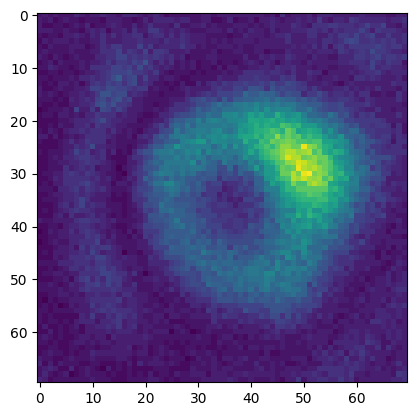

In [423]:
crop_pixels = 35
refined_centre = refined_centres[5]
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[7]["images"][1][crop_details])

{'height': 18.639300830714223,
 'sigmax': 21.63552976381632,
 'sigmay': 19.124297030928453,
 'centerx': 44.10374404065087,
 'centery': 31.485248016537778,
 'fwhm_x': 50.94777917269839,
 'fwhm_y': 45.03427799555619,
 'ellipticity': 1.1313111132308087,
 'strehl_prime': 0.0008903177939903549,
 'rmse': 3.713752980858549,
 'r_squared': 0.5720951435228543,
 'window_px': 143}

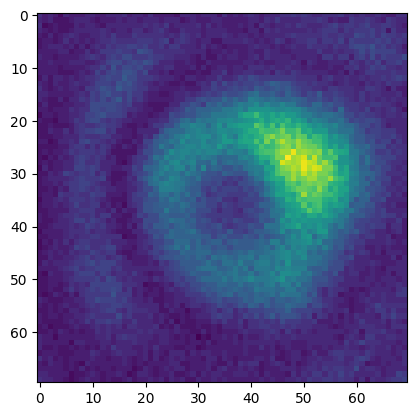

In [431]:
zernike_index = 7
crop_pixels = 35
w = 0
refined_centre =refined_centres[5]
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[zernike_index]["images"][w][crop_details])
get_tweezer_metrics(loaded[zernike_index]["images"][w][crop_details])


In [95]:
import numpy as np
from scipy.optimize import curve_fit, least_squares
from scipy.ndimage import map_coordinates

# ----------------------------------
# Bottle-beam model with OFFSET
# ----------------------------------
def bb(x, y, A, w, xc, yc, B):
    r = np.sqrt((x - xc)**2 + (y - yc)**2)
    return B + A * (r**4) * np.exp(-(r**2)/(w**2))

# ------------- helpers -------------
def _robust_norm(p):
    p = np.asarray(p, dtype=np.float32)
    p1, p99 = np.percentile(p, [1, 99])
    if p99 <= p1: p1, p99 = float(p.min()), float(p.max())
    q = (p - p1) / (p99 - p1 + 1e-9)
    return np.clip(q, 0, 1).astype(np.float32)

def _radial_profile(img, cy, cx, nbins=240, rmax=None):
    H, W = img.shape
    yy, xx = np.mgrid[0:H, 0:W]
    rr = np.sqrt((yy - cy)**2 + (xx - cx)**2)
    if rmax is None: rmax = min(H, W)/2 - 1
    bins = np.linspace(0, rmax, nbins+1)
    idx = np.clip(np.digitize(rr.ravel(), bins)-1, 0, nbins-1)
    prof = np.zeros(nbins, dtype=np.float64)
    counts = np.bincount(idx, minlength=nbins)
    sums   = np.bincount(idx, weights=img.ravel(), minlength=nbins)
    prof[counts>0] = sums[counts>0] / counts[counts>0]
    rc = 0.5*(bins[:-1] + bins[1:])
    return rc, prof

def _model_fwhm_for_w(w):
    # FWHM of r^4 exp(-r^2/w^2) above the OFFSET baseline:
    # solve s^2 e^{-s} = 2 e^{-2} for s=(r/w)^2; FWHM = w(√s2 - √s1)
    from math import sqrt, e
    from scipy.optimize import brentq
    c = 2.0 * (e**-2)
    f = lambda s: (s**2) * np.exp(-s) - c
    s1 = brentq(f, 1e-9, 2.0 - 1e-6)
    s2 = brentq(f, 2.0 + 1e-6, 10.0)
    return w * (sqrt(s2) - sqrt(s1))

def _sample_circle(img, cy, cx, r, ntheta=360):
    theta = np.linspace(0, 2*np.pi, ntheta, endpoint=False)
    yy = cy + r*np.sin(theta)
    xx = cx + r*np.cos(theta)
    vals = map_coordinates(img, [yy, xx], order=1, mode='reflect')
    return vals, theta

def _escape_intensity(img, cy, cx, r0, band_half, ntheta=360, r_step=0.5, center_radius=None):
    H, W = img.shape
    rmax_patch = min(H, W)/2 - 1
    r1 = max(0.0, r0 - band_half)
    r2 = min(rmax_patch, r0 + band_half)
    r_grid = np.arange(r1, r2 + 1e-6, r_step)
    if center_radius and center_radius > 0:
        YY, XX = np.mgrid[0:H, 0:W]
        RR = np.sqrt((YY - cy)**2 + (XX - cx)**2)
        I_center = float(img[RR <= center_radius].mean())
    else:
        I_center = float(img[int(round(cy)), int(round(cx))])

    best = (np.inf, 0.0, r0)
    for k in range(ntheta):
        th = 2*np.pi*k/ntheta
        yy = cy + r_grid*np.sin(th)
        xx = cx + r_grid*np.cos(th)
        vals = map_coordinates(img, [yy, xx], order=1, mode='reflect')
        imax = int(np.argmax(vals))
        barrier = float(vals[imax] - I_center)
        if barrier < best[0]:
            best = (barrier, th, float(r_grid[imax]))
    barrier, th, r_at = best
    return float(barrier), float(np.degrees(th)), r_at

# ------------- main -------------
def get_bottle_metrics(
    cropped_image,
    nbins_profile=240,
    center_frac=0.35,
    ntheta_uniformity=360,
    ntheta_escape=360,
    escape_r_step=0.5,
    waist_multiplier=7,
    use_lmfit=False   # if True and lmfit is available, it will try it first
):
    """
    Fits: I(x,y) = B + A * r^4 * exp(-r^2 / w^2)  (A,w,xc,yc,B)
    with SciPy by default; robust fallback to soft-L1. Then computes metrics.
    """
    img = np.asarray(cropped_image, dtype=np.float32)
    if img.ndim == 3:
        img = (0.2989*img[...,0] + 0.5870*img[...,1] + 0.1140*img[...,2]).astype(np.float32)

    patch = _robust_norm(img)
    H, W = patch.shape
    cy0 = (H - 1)/2.0
    cx0 = (W - 1)/2.0

    # Initials from radial profile
    rmax = min(H, W)/2 - 1
    r, prof = _radial_profile(patch, cy0, cx0, nbins=nbins_profile, rmax=rmax)
    start = max(3, int(0.05*len(r)))
    kpk = start + int(np.argmax(prof[start:]))
    r0_hint = float(r[kpk])
    w0 = max(1e-3, r0_hint/np.sqrt(2.0))  # r_peak = √2 w
    B0 = float(np.median(patch))
    # closed-form A0 for (w0,cx0,cy0,B0)
    YY, XX = np.mgrid[0:H, 0:W]
    rr = np.sqrt((XX - cx0)**2 + (YY - cy0)**2)
    phi = (rr**4) * np.exp(-(rr**2)/(w0**2))
    y = (patch - B0).ravel()
    A0 = float((y @ phi.ravel()) / (phi.ravel() @ phi.ravel() + 1e-12))
    p0 = [max(A0, 1e-6), w0, cx0, cy0, B0]

    # Bounds
    pad = 0.35 * min(H, W)
    B_lo = float(patch.min() - 0.2)
    B_hi = float(patch.max() + 0.2)
    bounds = (
        [0.0, 1e-6, cx0 - pad, cy0 - pad, B_lo],
        [np.inf, np.inf, cx0 + pad, cy0 + pad, B_hi]
    )

    A, w, cx, cy, B = p0
    fit_method = "scipy"

    # Prefer lmfit only if requested and available; else SciPy
    if use_lmfit:
        try:
            import lmfit
            m = lmfit.Model(lambda x, y, A, w, xc, yc, B: bb(x, y, A, w, xc, yc, B))
            pars = m.make_params(A=A, w=w, xc=cx, yc=cy, B=B)
            pars['A'].min = 0.0
            pars['w'].min = 1e-6
            pars['xc'].min, pars['xc'].max = cx0 - pad, cx0 + pad
            pars['yc'].min, pars['yc'].max = cy0 - pad, cy0 + pad
            pars['B'].min,  pars['B'].max  = B_lo, B_hi
            res = m.fit(patch, x=XX, y=YY, params=pars, method='least_squares', max_nfev=20000)
            A, w, cx, cy, B = [float(res.params[k].value) for k in ('A','w','xc','yc','B')]
            fit_method = "lmfit"
        except Exception:
            pass  # fall through to SciPy

    if fit_method != "lmfit":
        try:
            xdata = np.vstack([XX.ravel(), YY.ravel()])
            popt, _ = curve_fit(
                lambda XY, A, w, xc, yc, B: bb(XY[0], XY[1], A, w, xc, yc, B).ravel(),
                xdata, patch.ravel(), p0=p0, bounds=bounds, maxfev=30000
            )
            A, w, cx, cy, B = [float(v) for v in popt]
        except Exception:
            # robust fallback: soft-L1 least squares
            def resid(p):
                A_, w_, xc_, yc_, B_ = p
                return (bb(XX, YY, max(A_,0.0), max(w_,1e-6), xc_, yc_, B_) - patch).ravel()
            rs = least_squares(resid, p0, bounds=bounds, loss='soft_l1', f_scale=0.1, max_nfev=30000)
            A, w, cx, cy, B = [float(v) for v in rs.x]
            fit_method = "scipy_soft_l1"

    # Fit quality
    model = bb(XX, YY, A, w, cx, cy, B)
    resid = (patch - model).ravel()
    rmse = float(np.sqrt(np.mean(resid**2)))
    ss_res = float(np.sum(resid**2))
    ss_tot = float(np.sum((patch.ravel() - patch.mean())**2) + 1e-12)
    r2 = 1.0 - ss_res/ss_tot

    # Derived geometry from fitted w
    r_peak = float(np.sqrt(2.0) * w)
    fwhm = float(_model_fwhm_for_w(w))

    # Regions & stats (use fitted center)
    RR = np.sqrt((XX - cx)**2 + (YY - cy)**2)
    r_center = max(1.0, center_frac * r_peak)
    band_half = 0.5 * fwhm

    center_mask = RR <= r_center
    ring_mask   = np.abs(RR - r_peak) <= band_half
    bg_mask     = (RR >= r_peak + 1.5*band_half) & (RR <= r_peak + 3.0*band_half)

    I_center = float(patch[center_mask].mean()) if np.any(center_mask) else 0.0
    I_ring   = float(patch[ring_mask].mean())   if np.any(ring_mask)   else float(model[ring_mask].mean())
    I_bg     = float(patch[bg_mask].mean())     if np.any(bg_mask)     else float(np.median(patch))
    std_bg   = float(patch[bg_mask].std()+1e-6) if np.any(bg_mask)     else float(patch.std()+1e-6)

    contrast = (I_ring - I_center) / (I_ring + 1e-9)
    center_suppression = I_center / (I_ring + 1e-9)
    snr_rb = (I_ring - I_bg) / std_bg

    # Uniformity & escape
    vals_ring, _ = _sample_circle(patch, cy, cx, r_peak, ntheta=ntheta_uniformity)
    uniformity_std_pct = 100.0 * (vals_ring.std() / (vals_ring.mean() + 1e-9))

    escape_I, escape_theta_deg, escape_r = _escape_intensity(
        patch, cy, cx, r_peak, band_half, ntheta=ntheta_escape, r_step=escape_r_step, center_radius=r_center
    )

    # Cleanliness / encircled energy (normalized profile)
    r_prof, prof = _radial_profile(patch, cy, cx, nbins=nbins_profile, rmax=rmax)
    beyond = r_prof >= (r_peak + fwhm)
    outer_ring_ratio = float(prof[beyond].max() / (I_ring + 1e-9)) if np.any(beyond) else 0.0
    Er = 2*np.pi * r_prof * prof
    m_band = (r_prof >= (r_peak - band_half)) & (r_prof <= (r_peak + band_half))
    E_band = np.trapz(Er[m_band], r_prof[m_band]) if np.any(m_band) else 0.0
    E_tot  = np.trapz(Er, r_prof) + 1e-12
    encircled_energy_in_ring = float(E_band / E_tot)

    # Strehl-like (comparable to your tweezer metric)
    sigma_like = max(fwhm/2.355, 1.0)
    window_size = int(round(waist_multiplier * sigma_like))
    if window_size % 2 == 0: window_size += 1
    half = window_size // 2
    y0, y1 = int(max(cy - half, 0)), int(min(cy + half + 1, H))
    x0, x1 = int(max(cx - half, 0)), int(min(cx + half + 1, W))
    box = patch[y0:y1, x0:x1]
    strehl_prime = float(box.max() / (box.sum() + 1e-12)) if box.size else 0.0

    # Analytical derivatives at r=0 for I=B + A r^4 e^{-r^2/w^2}
    d2I_dr2_at0 = 0.0
    d4I_dr4_at0 = float(24.0 * A)

    return {
        # fitted params (offset included)
        "A": float(A), "w_px": float(w), "offset": float(B),
        "centerx": float(cx), "centery": float(cy),
        "fit_method": fit_method, "rmse": float(rmse), "r_squared": float(r2),

        # derived geometry
        "r_peak_px": r_peak, "fwhm_px": fwhm,

        # intensities & SNR
        "I_center": I_center, "I_ring": I_ring, "I_bg": I_bg,
        "contrast": contrast, "center_suppression": center_suppression, "snr_rb": snr_rb,

        # ring uniformity & escape
        "uniformity_std_pct": uniformity_std_pct,
        "escape_intensity": escape_I,
        "escape_theta_deg": escape_theta_deg,
        "escape_radius_px": escape_r,

        # cleanliness
        "outer_ring_ratio": outer_ring_ratio,
        "encircled_energy_in_ring": encircled_energy_in_ring,

        # strehl-like
        "strehl_prime": strehl_prime, "window_px": int(window_size),

        # model derivatives at origin
        "d2I_dr2_at0": d2I_dr2_at0, "d4I_dr4_at0": d4I_dr4_at0,
    }


In [8]:
zernike_index = 4
crop_pixels = 35
w = 100
refined_centres,is_bottle,info = refine_bottle_centers(loaded[zernike_index]["images"][w],bb_locations)
refined_centre =refined_centres[5]
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[zernike_index]["images"][w][crop_details])
get_bottle_metrics(loaded[zernike_index]["images"][w][crop_details])

NameError: name 'refine_bottle_centers' is not defined

In [720]:
results = []
crop_pixels = 35

for zernike_index, zernike_data in loaded.items():
    images = zernike_data["images"]
    for w_index, image in enumerate(images):
        refined_centres,is_bottle,info = refine_bottle_centers(loaded[zernike_index]["images"][w_index],bb_locations)
        for (expected, refined) in zip(bb_locations, refined_centres):
            cx, cy = refined  # (x, y)
            crop = (
                slice(int(cy - crop_pixels), int(cy + crop_pixels)),
                slice(int(cx - crop_pixels), int(cx + crop_pixels)),
            )
            cropped = image[crop]
            metrics = get_bottle_metrics(cropped)
            results.append({
                "zernike_index": zernike_index,
                "w_index": w_index,
                "w": zernike_data['w'][w_index],
                "expected_x": expected[0],
                "expected_y": expected[1],
                "refined_x": float(cx),
                "refined_y": float(cy),
                **metrics
            })


ValueError: attempt to get argmax of an empty sequence

In [ ]:
pdf_bb = pd.DataFrame(results)

In [709]:
pdf_bb

,zernike_index,w_index,w,expected_x,expected_y,refined_x,refined_y,A,w_px,offset,...,uniformity_std_pct,escape_intensity,escape_theta_deg,escape_radius_px,outer_ring_ratio,encircled_energy_in_ring,strehl_prime,window_px,d2I_dr2_at0,d4I_dr4_at0
0,3,80,-2.0,980,130,970.0,133.0,0.000192,9.256999,0.106588,...,12.732630,0.438789,85.0,13.194002,0.228350,0.571560,0.001463,33,0.0,0.004605
1,3,80,-2.0,980,230,978.0,232.0,0.000203,8.996592,0.091935,...,22.015939,0.207300,72.0,17.477564,0.196894,0.558815,0.001705,31,0.0,0.004870
2,3,80,-2.0,980,330,968.0,333.0,0.000174,8.944317,0.108704,...,36.676139,0.146277,275.0,15.434115,0.304115,0.523270,0.001942,31,0.0,0.004188
3,3,80,-2.0,980,430,977.0,433.0,0.000188,9.189989,0.141101,...,13.129047,0.337426,36.0,11.638307,0.264624,0.515074,0.001399,33,0.0,0.004509
4,3,80,-2.0,1080,130,1069.0,133.0,0.000184,9.265948,0.068280,...,19.295446,0.457243,267.0,14.701441,0.179065,0.609102,0.001600,33,0.0,0.004413
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3275,7,120,2.0,1180,430,1172.0,432.0,0.000157,9.252606,0.098557,...,30.225599,0.287027,66.0,14.690351,0.226818,0.555118,0.001752,33,0.0,0.003759
3276,7,120,2.0,1280,130,1271.0,125.0,0.000235,8.562407,0.081121,...,26.321149,0.124189,287.0,9.616689,0.246881,0.530291,0.001818,31,0.0,0.005628
3277,7,120,2.0,1280,230,1273.0,232.0,0.000143,9.542606,0.107002,...,22.796612,0.363895,84.0,13.431387,0.247963,0.583812,0.001690,33,0.0,0.003434
3278,7,120,2.0,1280,330,1274.0,333.0,0.000193,8.989174,0.102463,...,22.933467,0.243425,283.0,15.471398,0.222585,0.540776,0.001779,31,0.0,0.004628


In [6]:
subset = pdf_bb[
    (pdf_bb['zernike_index'] == 7) &
    (pdf_bb['expected_y'] == 430) &
    (pdf_bb['expected_x'] == 980)
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="rmse", label="escape_intensity", color="red", ax=ax, secondary_y=True)

NameError: name 'pdf_bb' is not defined

In [711]:
pdf_bb[
    (pdf_bb['zernike_index'] == 6) &
    (pdf_bb['expected_y'] == 130) &
    (pdf_bb['expected_x'] == 980)
]

,zernike_index,w_index,w,expected_x,expected_y,refined_x,refined_y,A,w_px,offset,...,uniformity_std_pct,escape_intensity,escape_theta_deg,escape_radius_px,outer_ring_ratio,encircled_energy_in_ring,strehl_prime,window_px,d2I_dr2_at0,d4I_dr4_at0
1968,6,80,-2.0,980,130,970.0,132.0,0.000182,9.303857,0.098953,...,14.561471,0.433740,72.0,16.232949,0.226568,0.572381,0.001531,33,0.0,0.004358
1984,6,81,-1.9,980,130,970.0,132.0,0.000190,9.308962,0.101170,...,12.065042,0.527702,280.0,15.737192,0.228357,0.572367,0.001469,33,0.0,0.004553
2000,6,82,-1.8,980,130,970.0,132.0,0.000182,9.311812,0.097460,...,13.991317,0.449772,74.0,12.239560,0.217188,0.573830,0.001529,33,0.0,0.004360
2016,6,83,-1.7,980,130,970.0,132.0,0.000190,9.310094,0.101196,...,13.092314,0.528144,292.0,15.738133,0.239758,0.572902,0.001463,33,0.0,0.004557
2032,6,84,-1.6,980,130,970.0,132.0,0.000189,9.304666,0.102576,...,11.788479,0.511575,68.0,15.233621,0.235062,0.573276,0.001469,33,0.0,0.004533
2048,6,85,-1.5,980,130,970.0,132.0,0.000190,9.304529,0.100732,...,13.201540,0.463771,76.0,15.733507,0.232485,0.574533,0.001467,33,0.0,0.004553
2064,6,86,-1.4,980,130,970.0,132.0,0.000190,9.306467,0.100566,...,13.441609,0.513813,86.0,11.735118,0.215545,0.574715,0.001469,33,0.0,0.004550
2080,6,87,-1.3,980,130,970.0,132.0,0.000186,9.314780,0.100776,...,12.813327,0.485493,75.0,13.242027,0.233423,0.571959,0.001484,33,0.0,0.004474
2096,6,88,-1.2,980,130,969.0,132.0,0.000189,9.299569,0.100523,...,12.374707,0.482719,83.0,15.729385,0.236886,0.557143,0.001474,33,0.0,0.004537
2112,6,89,-1.1,980,130,970.0,132.0,0.000190,9.309831,0.102392,...,12.348248,0.528126,76.0,13.237914,0.224605,0.574155,0.001459,33,0.0,0.004551


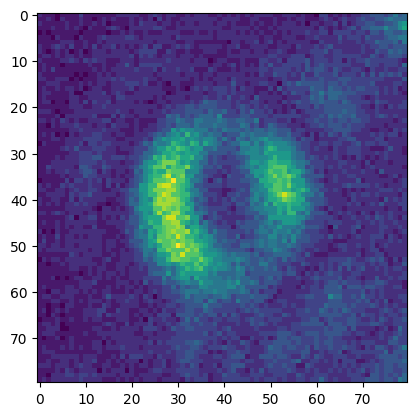

In [712]:
zernike_index = 6
expected_y = 330
expected_x = 980
crop_pixels = 40
refined_centre = pdf_bb[
    (pdf_bb['zernike_index'] == zernike_index) &
    (pdf_bb['expected_y'] == expected_y) &
    (pdf_bb['expected_x'] == expected_x) &
    (pdf_bb['w_index'] == 100)
][['refined_x','refined_y']].astype('int').values[0]
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[zernike_index]["images"][w][crop_details])

In [713]:
pdf_bb[
    (pdf_bb['zernike_index'] == zernike_index) &
    (pdf_bb['expected_y'] == expected_y) &
    (pdf_bb['expected_x'] == expected_x)
][['w_index','r_squared','rmse']]

,w_index,r_squared,rmse
1970,80,0.684073,0.126737
1986,81,0.685294,0.127032
2002,82,0.687263,0.125654
2018,83,0.689549,0.125185
2034,84,0.688059,0.124955
2050,85,0.692426,0.124424
2066,86,0.692266,0.114329
2082,87,0.687135,0.124540
2098,88,0.682530,0.125127
2114,89,0.688096,0.124828


In [ ]:
save_path = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_100w_pdf_bb.csv"
pdf_bb.to_csv(save_path)

# combination of zernikes

In [600]:
fs.slm.get_source_center()

array([627.38755535, 500.34136285])

In [602]:
fs.slm.fit_source_amplitude()

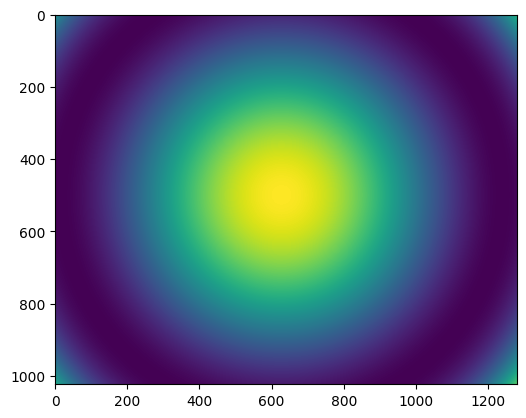

In [604]:
plt.imshow(zernike(fs.slm, 12,use_mask = False))

In [ ]:
def combination_zernike(testing_x, testing_y, iterations, save_path):
    w_matrix = effective_zernikes_df[(effective_zernikes_df['expected_x']==testing_x)&(effective_zernikes_df['expected_y']==testing_y)]
    zernike_weights = w_matrix.set_index('zernike_index')['w_star'].to_dict()

    base_phase = np.load(base_path/ 'data' / 'zernike' / 'raw' / 'spots_uc_32_spot_bb_phase.npy')
    datas = []

    for i in range(iterations):
        print("iteration", i+1)
        data = {}
        zernike_sum_phase = np.zeros(base_phase.shape)

        # no zernike
        phase = base_phase 
        image = save_cam(fs,phase = phase,sleep = 5)
        data[-2] = {
                "w": [],
                "images": []
            }
        data[-2]["w"].append(-2)
        data[-2]["images"].append(image)

        # separate zernike terms
        counter = 0
        for zernike_index in zernike_weights.keys():
            if zernike_index in [5,8]:
                zernike_term_phase = zernike(fs.slm, zernike_index,use_mask = False)
                data[zernike_index] = {
                    "w": [],
                    "images": []
                }
                w = zernike_weights[zernike_index]
                phase = base_phase + w * zernike_term_phase
                image = save_cam(fs,phase = phase,sleep = 5)
                data[zernike_index]["w"].append(w)
                data[zernike_index]["images"].append(image)
                # print(zernike_index,w)
                zernike_sum_phase = zernike_sum_phase + (w * zernike_term_phase)
                counter += 1

        #run all at once
        # phase = base_phase + zernike_sum(grid = fs.slm,indices = tuple(zernike_weights.keys()),weights=tuple(zernike_weights.values()))
        phase = base_phase + zernike_sum_phase
        image = save_cam(fs,phase = phase,sleep = 5)
        data[-1] = {
                "w": [],
                "images": []
            }
        data[-1]["w"].append(-1)
        data[-1]["images"].append(image)
        datas.append(data)

    with open(save_path, 'wb') as f:
        pickle.dump(datas, f)
    with open(save_path, 'rb') as f:
        loaded = pickle.load(f)

        results = []
        crop_pixels = 30
        counter = 0
        for loaded_i in loaded:
            for zernike_index, zernike_data in loaded_i.items():
                images = zernike_data["images"]  # list of images at different w

                for w_index, image in enumerate(images):
                    refined_centres = refine_centers(image, spot_locations, 200)
                    for (expected, refined) in zip(spot_locations, refined_centres):
                        cx, cy = refined
                        crop_details = (
                            slice(cy - crop_pixels, cy + crop_pixels),
                            slice(cx - crop_pixels, cx + crop_pixels)
                        )

                        cropped_image = image[crop_details]
                        metrics = get_tweezer_metrics(cropped_image)

                        results.append({
                            "counter":counter,
                            "zernike_index": zernike_index,
                            "w_index": w_index,
                            "w":zernike_data['w'][w_index],
                            "expected_x": expected[0],
                            "expected_y": expected[1],
                            "refined_x": cx,
                            "refined_y": cy,
                            **metrics
                        })

            counter+=1
    
    combo_pdf = pd.DataFrame(results)
    combo_pdf2 = (
        combo_pdf[(combo_pdf['expected_x'] == testing_x) & (combo_pdf['expected_y'] == testing_y)]
        [['zernike_index','rmse','w','strehl_prime','r_squared']]
        .groupby('zernike_index', sort=False)
        .mean()
    )
    baseline = combo_pdf2.loc[-2, "strehl_prime"]
    combo_pdf2["improvement %"] = (combo_pdf2["strehl_prime"] - baseline)*100/baseline


    return combo_pdf, combo_pdf2


iteration 1
writing phase
writing phase
writing phase
writing phase
iteration 2
writing phase
writing phase
writing phase
writing phase
iteration 3
writing phase
writing phase
writing phase
writing phase
iteration 4
writing phase
writing phase
writing phase
writing phase
iteration 5
writing phase
writing phase
writing phase
writing phase
iteration 6
writing phase
writing phase
writing phase
writing phase
iteration 7
writing phase
writing phase
writing phase
writing phase
iteration 8
writing phase
writing phase
writing phase
writing phase
iteration 9
writing phase
writing phase
writing phase
writing phase
iteration 10
writing phase
writing phase
writing phase
writing phase


,rmse,w,strehl_prime,r_squared,improvement %
zernike_index,,,,,
-2,5.310205,-2.000000,0.003275,0.923544,0.000000
5,5.291435,0.309434,0.003425,0.926841,4.576479
8,5.316314,0.188982,0.003491,0.925700,6.614347
-1,5.271633,-1.000000,0.003528,0.928951,7.736368


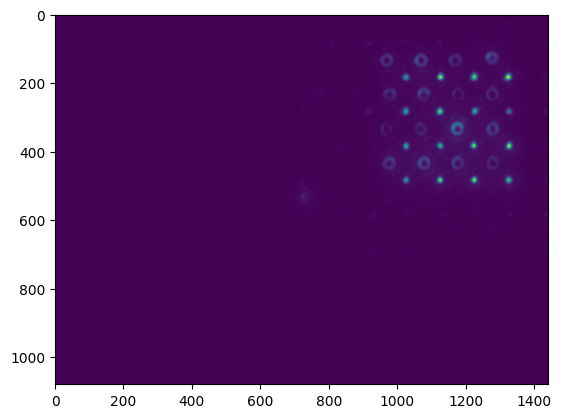

In [148]:
testing_x = 1030
testing_y = 380
iterations = 10
save_path = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_zcombo_test11_1030_380.pkl"

result_1030_180, result_1030_180_summary = combination_zernike(testing_x=testing_x, testing_y=testing_y, iterations=iterations, save_path=save_path)
result_1030_180_summary

In [ ]:
def global_zernike():
    
    pass

In [538]:
spot_locations

array([[1030,  180],
       [1030,  280],
       [1030,  380],
       [1030,  480],
       [1130,  180],
       [1130,  280],
       [1130,  380],
       [1130,  480],
       [1230,  180],
       [1230,  280],
       [1230,  380],
       [1230,  480],
       [1330,  180],
       [1330,  280],
       [1330,  380],
       [1330,  480]])

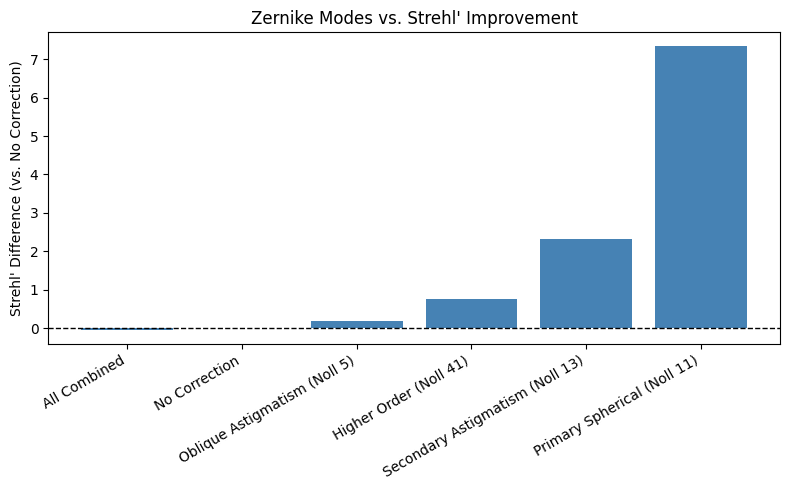

In [390]:
import pandas as pd
import matplotlib.pyplot as plt

# Data
data = [
    [-1, 6.041888, 0.003838, 0.892104, -0.033850],
    [-2, 6.046149, 0.003839, 0.898999, 0.005579],
    [4, 6.050305, 0.003847, 0.899600, 0.199839],
    [40, 5.985621, 0.003869, 0.901965, 0.774671],
    [12, 5.984202, 0.003928, 0.902394, 2.319291],
    [8, 5.952230, 0.004121, 0.901683, 7.338876]
]

df = pd.DataFrame(data, columns=['zernike_index', 'val1', 'val2', 'val3', 'strehl_prime'])

# Reference (no correction: index -2)
strehl_no_corr = df.loc[df['zernike_index'] == -2, 'strehl_prime'].values[0]

# Difference from no correction
df['strehl_diff'] = df['strehl_prime'] - strehl_no_corr

# Zernike names mapping (shifted by -1 as you mentioned)
zernike_names = {
    -2: 'No Correction',
    -1: 'All Combined',
    4: 'Oblique Astigmatism (Noll 5)',
    8: 'Primary Spherical (Noll 11)',
    12: 'Secondary Astigmatism (Noll 13)',
    40: 'Higher Order (Noll 41)'
}

df['zernike_name'] = df['zernike_index'].map(zernike_names)

# Plot
plt.figure(figsize=(8,5))
plt.bar(df['zernike_name'], df['strehl_diff'], color='steelblue')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.ylabel("Strehl' Difference (vs. No Correction)")
plt.title("Zernike Modes vs. Strehl' Improvement")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


# Zernike fits

In [111]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# -----------------------
CSV_PATH = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_80w_pdf.csv"
OUT_DIR =  base_path / "data" / "zernike" / "raw" /"summary"
os.makedirs(OUT_DIR, exist_ok=True)
METRIC = "strehl_prime"

zernike_names = {
    0: "Piston",
    1: "Tilt X",
    2: "Tilt Y",
    3: "Defocus",
    4: "Astigmatism 45°",
    5: "Astigmatism 0°",
    6: "Coma X",
    7: "Coma Y",
    8: "Trefoil X",
    9: "Trefoil Y",
    10: "Primary Spherical",
    11: "Secondary Astigmatism 0°",
    12: "Secondary Astigmatism 45°",
    13: "Secondary Coma X",
    14: "Secondary Coma Y",
    15: "Quadrafoil 0°",
    16: "Quadrafoil 45°",
    17: "Secondary Spherical",
    18: "Tertiary Astigmatism 0°",
    19: "Tertiary Astigmatism 45°",
    20: "Tertiary Coma X",
    21: "Tertiary Coma Y",
    22: "Tertiary Trefoil X",
    23: "Tertiary Trefoil Y",
    24: "Tertiary Spherical"
}

def quad_fit_with_cov(ws, ys):
    ws = np.asarray(ws, float)
    ys = np.asarray(ys, float)
    if len(ws) < 3 or len(np.unique(ws)) < 3:
        return False, None, None, None, None
    try:
        coeffs, cov = np.polyfit(ws, ys, deg=2, cov=True)
        a, b, c = coeffs
        return True, float(a), float(b), float(c), cov
    except Exception:
        return False, None, None, None, None

def vertex_from_quad(a, b, c):
    w_star = -b / (2*a)
    y_star = c - b*b / (4*a)
    return float(w_star), float(y_star)

def se_w_from_cov(a, b, cov):
    try:
        import math
        J = np.array([b/(2*a*a), -1/(2*a)])
        Sigma = cov[:2, :2]
        var_w = float(J @ Sigma @ J.T)
        return float(np.sqrt(max(var_w, 0.0)))
    except Exception:
        return np.nan

def fit_group(gdf, metric=METRIC):
    g = gdf.sort_values("w").copy()
    ws = g["w"].to_numpy(dtype=float)
    ys = g[metric].to_numpy(dtype=float)

    ok, a, b, c, cov = quad_fit_with_cov(ws, ys)
    w_min, w_max = (float(np.min(ws)), float(np.max(ws))) if len(ws) else (np.nan, np.nan)

    result = {
        "w_star": np.nan,
        "w_star_se": np.nan,
        "w_star%": np.nan,
        "y_star": np.nan,
        "method": None,
        "a": np.nan, "b": np.nan, "c": np.nan,
        "concave": False,
        "vertex_in_range": False,
        "w_min": w_min, "w_max": w_max,
        "argmax_w": float(ws[np.argmax(ys)]) if len(ws) else np.nan,
        "argmax_y": float(np.max(ys)) if len(ys) else np.nan,
        "n_points": int(len(ws))
    }

    if ok and a < 0:
        wv, yv = vertex_from_quad(a, b, c)
        result.update({
            "a": a, "b": b, "c": c,
            "concave": True,
            "vertex_in_range": (w_min <= wv <= w_max)
        })
        if result["vertex_in_range"]:
            result["w_star"] = wv
            result["y_star"] = yv
            result["method"] = "quad_fit"
            result["w_star_se"] = se_w_from_cov(a, b, cov) if cov is not None else np.nan
            return result

    result["w_star"] = result["argmax_w"]
    result["y_star"] = result["argmax_y"]
    result["method"] = "argmax"
    return result

def build_W_minimal(df, metric=METRIC):
    points = df[["expected_x","expected_y"]].drop_duplicates().sort_values(["expected_x","expected_y"]).to_records(index=False)
    zds = sorted(df["zernike_index"].unique())

    long_records = []
    wide_rows = []

    for (x0, y0) in points:
        row = {"expected_x": x0, "expected_y": y0}
        gspot = df[(df["expected_x"]==x0) & (df["expected_y"]==y0)]
        for zd in zds:
            g = gspot[gspot["zernike_index"]==zd]
            if g.empty:
                row[f"Z{zd}"] = np.nan
                continue
            fit = fit_group(g, metric=metric)
            row[f"Z{zd}"] = fit["w_star"]
            rec = {
                "expected_x": x0, "expected_y": y0, "zernike_index": zd,
                "w_star": fit["w_star"],
                "w_star_se": fit["w_star_se"],
                "y_star": fit["y_star"],
                "method": fit["method"],
                "a": fit["a"], "b": fit["b"], "c": fit["c"],
                "concave": fit["concave"],
                "vertex_in_range": fit["vertex_in_range"],
                "w_min": fit["w_min"], "w_max": fit["w_max"],
                "argmax_w": fit["argmax_w"], "argmax_y": fit["argmax_y"],
                "n_points": fit["n_points"]
            }
            long_records.append(rec)
        wide_rows.append(row)

    W = pd.DataFrame(wide_rows).sort_values(["expected_x","expected_y"])
    weights_long = pd.DataFrame(long_records).sort_values(["zernike_index","expected_x","expected_y"])
    weights_long['zernike_name'] = weights_long['zernike_index'].apply(lambda x : zernike_names[x] if x < 25 else x)
    cols = weights_long.columns.tolist()
    cols.insert(3, cols.pop(cols.index('zernike_name')))
    weights_long = weights_long[cols]

    weights_long['w_star%'] = weights_long['w_star_se']/weights_long['w_star']*100
    cols = weights_long.columns.tolist()
    cols.insert(6, cols.pop(cols.index('w_star%')))
    weights_long = weights_long[cols]
    return W, weights_long, zds

# Load and run
df = pd.read_csv(CSV_PATH)
for c in list(df.columns):
    if c.lower().startswith("unnamed"):
        df = df.drop(columns=[c])

W_df, weights_long_df, zds = build_W_minimal(df, metric=METRIC)

Z_cols = [f"Z{zd}" for zd in zds]
W_mat = W_df[Z_cols].fillna(0.0).to_numpy()
coords = W_df[["expected_x","expected_y"]].to_numpy()

os.makedirs(OUT_DIR, exist_ok=True)
W_csv = os.path.join(OUT_DIR, "W_matrix_minimal.csv")
weights_long_csv = os.path.join(OUT_DIR, "weights_long_minimal.csv")
W_df.to_csv(W_csv, index=False)
weights_long_df.to_csv(weights_long_csv, index=False)

summary = (weights_long_df
           .groupby("zernike_index")
           .agg(n=("w_star", "size"),
                concave_frac=("concave", "mean"),
                vertex_in_range_frac=("vertex_in_range", "mean"),
                median_w_star_se=("w_star_se", "median"),
                mean_w_star_se=("w_star_se", "mean"))
           .reset_index()
           .sort_values("zernike_index"))
summary_csv = os.path.join(OUT_DIR, "summary_minimal.csv")
summary.to_csv(summary_csv, index=False)

# PDF
first100 = weights_long_df.head(100)
pdf_path = os.path.join(OUT_DIR, "report_first100.pdf")

from matplotlib.backends.backend_pdf import PdfPages
with PdfPages(pdf_path) as pdf:
    for _, row in first100.iterrows():
        x0 = row["expected_x"]; y0 = row["expected_y"]; zd = row["zernike_index"]
        g = df[(df["expected_x"]==x0) & (df["expected_y"]==y0) & (df["zernike_index"]==zd)].sort_values("w")
        if g.empty:
            continue

        ws = g["w"].to_numpy(dtype=float)
        ys = g[METRIC].to_numpy(dtype=float)

        plt.figure()
        plt.plot(ws, ys, marker="o")
        plt.xlabel("w")
        plt.ylabel(METRIC)
        title = f"Z{int(zd)} @ ({int(x0)}, {int(y0)})"
        plt.title(title)

        if row["method"] == "quad_fit" and np.isfinite(row["a"]) and np.isfinite(row["b"]) and np.isfinite(row["c"]):
            a, b, c = row["a"], row["b"], row["c"]
            wgrid = np.linspace(np.min(ws), np.max(ws), 200)
            yfit = a*wgrid*wgrid + b*wgrid + c
            plt.plot(wgrid, yfit)
            plt.axvline(row["w_star"], linestyle="--")
        else:
            plt.axvline(row["argmax_w"], linestyle="--")

        txt = [
            f"method: {row['method']}",
            f"w*: {row['w_star']:.4g}",
            f"se(w*): {row['w_star_se']:.2g}" if np.isfinite(row["w_star_se"]) else "se(w*): n/a",
            f"concave: {bool(row['concave'])}, in-range: {bool(row['vertex_in_range'])}",
            f"n_points: {int(row['n_points'])}",
        ]
        plt.text(0.02, 0.98, "\n".join(txt), transform=plt.gca().transAxes,
                 va="top", ha="left")
        pdf.savefig()
        plt.close()

print("W_matrix_minimal:", W_csv)
print("weights_long_minimal:", weights_long_csv)
print("summary_minimal:", summary_csv)
print("report_first100.pdf:", pdf_path)

W_matrix_minimal: C:\Users\QC\Documents\GitHub\holography\data\zernike\raw\summary\W_matrix_minimal.csv
weights_long_minimal: C:\Users\QC\Documents\GitHub\holography\data\zernike\raw\summary\weights_long_minimal.csv
summary_minimal: C:\Users\QC\Documents\GitHub\holography\data\zernike\raw\summary\summary_minimal.csv
report_first100.pdf: C:\Users\QC\Documents\GitHub\holography\data\zernike\raw\summary\report_first100.pdf


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
# -----------------------
CSV_PATH = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_80w_pdf.csv"
OUT_DIR =  base_path / "data" / "zernike" / "raw" /"summary"
os.makedirs(OUT_DIR, exist_ok=True)
METRIC = "strehl_prime"

zernike_names = {
    0: "Piston",
    1: "Tilt X",
    2: "Tilt Y",
    3: "Defocus",
    4: "Astigmatism 45°",
    5: "Astigmatism 0°",
    6: "Coma X",
    7: "Coma Y",
    8: "Trefoil X",
    9: "Trefoil Y",
    10: "Primary Spherical",
    11: "Secondary Astigmatism 0°",
    12: "Secondary Astigmatism 45°",
    13: "Secondary Coma X",
    14: "Secondary Coma Y",
    15: "Quadrafoil 0°",
    16: "Quadrafoil 45°",
    17: "Secondary Spherical",
    18: "Tertiary Astigmatism 0°",
    19: "Tertiary Astigmatism 45°",
    20: "Tertiary Coma X",
    21: "Tertiary Coma Y",
    22: "Tertiary Trefoil X",
    23: "Tertiary Trefoil Y",
    24: "Tertiary Spherical"
}

def quad_fit_with_cov(ws, ys):
    ws = np.asarray(ws, float)
    ys = np.asarray(ys, float)
    if len(ws) < 3 or len(np.unique(ws)) < 3:
        return False, None, None, None, None
    try:
        coeffs, cov = np.polyfit(ws, ys, deg=2, cov=True)
        a, b, c = coeffs
        return True, float(a), float(b), float(c), cov
    except Exception:
        return False, None, None, None, None

def vertex_from_quad(a, b, c):
    w_star = -b / (2*a)
    y_star = c - b*b / (4*a)
    return float(w_star), float(y_star)

def se_w_from_cov(a, b, cov):
    try:
        import math
        J = np.array([b/(2*a*a), -1/(2*a)])
        Sigma = cov[:2, :2]
        var_w = float(J @ Sigma @ J.T)
        return float(np.sqrt(max(var_w, 0.0)))
    except Exception:
        return np.nan

def fit_group(gdf, metric=METRIC):
    g = gdf.sort_values("w").copy()
    ws = g["w"].to_numpy(dtype=float)
    ys = g[metric].to_numpy(dtype=float)

    ok, a, b, c, cov = quad_fit_with_cov(ws, ys)
    w_min, w_max = (float(np.min(ws)), float(np.max(ws))) if len(ws) else (np.nan, np.nan)

    result = {
        "w_star": np.nan,
        "w_star_se": np.nan,
        "w_star%": np.nan,
        "y_star": np.nan,
        "method": None,
        "a": np.nan, "b": np.nan, "c": np.nan,
        "concave": False,
        "vertex_in_range": False,
        "w_min": w_min, "w_max": w_max,
        "argmax_w": float(ws[np.argmax(ys)]) if len(ws) else np.nan,
        "argmax_y": float(np.max(ys)) if len(ys) else np.nan,
        "n_points": int(len(ws))
    }

    if ok and a < 0:
        wv, yv = vertex_from_quad(a, b, c)
        result.update({
            "a": a, "b": b, "c": c,
            "concave": True,
            "vertex_in_range": (w_min <= wv <= w_max)
        })
        if result["vertex_in_range"]:
            result["w_star"] = wv
            result["y_star"] = yv
            result["method"] = "quad_fit"
            result["w_star_se"] = se_w_from_cov(a, b, cov) if cov is not None else np.nan
            return result

    result["w_star"] = result["argmax_w"]
    result["y_star"] = result["argmax_y"]
    result["method"] = "argmax"
    return result

def build_W_minimal(df, metric=METRIC):
    points = df[["expected_x","expected_y"]].drop_duplicates().sort_values(["expected_x","expected_y"]).to_records(index=False)
    zds = sorted(df["zernike_index"].unique())

    long_records = []
    wide_rows = []

    for (x0, y0) in points:
        row = {"expected_x": x0, "expected_y": y0}
        gspot = df[(df["expected_x"]==x0) & (df["expected_y"]==y0)]
        for zd in zds:
            g = gspot[gspot["zernike_index"]==zd]
            if g.empty:
                row[f"Z{zd}"] = np.nan
                continue
            fit = fit_group(g, metric=metric)
            row[f"Z{zd}"] = fit["w_star"]
            rec = {
                "expected_x": x0, "expected_y": y0, "zernike_index": zd,
                "w_star": fit["w_star"],
                "w_star_se": fit["w_star_se"],
                "y_star": fit["y_star"],
                "method": fit["method"],
                "a": fit["a"], "b": fit["b"], "c": fit["c"],
                "concave": fit["concave"],
                "vertex_in_range": fit["vertex_in_range"],
                "w_min": fit["w_min"], "w_max": fit["w_max"],
                "argmax_w": fit["argmax_w"], "argmax_y": fit["argmax_y"],
                "n_points": fit["n_points"]
            }
            long_records.append(rec)
        wide_rows.append(row)

    W = pd.DataFrame(wide_rows).sort_values(["expected_x","expected_y"])
    weights_long = pd.DataFrame(long_records).sort_values(["zernike_index","expected_x","expected_y"])
    weights_long['zernike_name'] = weights_long['zernike_index'].apply(lambda x : zernike_names[x] if x < 25 else x)
    cols = weights_long.columns.tolist()
    cols.insert(3, cols.pop(cols.index('zernike_name')))
    weights_long = weights_long[cols]

    weights_long['w_star%'] = weights_long['w_star_se']/weights_long['w_star']*100
    cols = weights_long.columns.tolist()
    cols.insert(6, cols.pop(cols.index('w_star%')))
    weights_long = weights_long[cols]
    return W, weights_long, zds

# Load and run
df = pd.read_csv(CSV_PATH)
for c in list(df.columns):
    if c.lower().startswith("unnamed"):
        df = df.drop(columns=[c])

W_df, weights_long_df, zds = build_W_minimal(df, metric=METRIC)

Z_cols = [f"Z{zd}" for zd in zds]
W_mat = W_df[Z_cols].fillna(0.0).to_numpy()
coords = W_df[["expected_x","expected_y"]].to_numpy()

os.makedirs(OUT_DIR, exist_ok=True)
W_csv = os.path.join(OUT_DIR, "W_matrix_minimal.csv")
weights_long_csv = os.path.join(OUT_DIR, "weights_long_minimal.csv")
W_df.to_csv(W_csv, index=False)
weights_long_df.to_csv(weights_long_csv, index=False)

summary = (weights_long_df
           .groupby("zernike_index")
           .agg(n=("w_star", "size"),
                concave_frac=("concave", "mean"),
                vertex_in_range_frac=("vertex_in_range", "mean"),
                median_w_star_se=("w_star_se", "median"),
                mean_w_star_se=("w_star_se", "mean"))
           .reset_index()
           .sort_values("zernike_index"))
summary_csv = os.path.join(OUT_DIR, "summary_minimal.csv")
summary.to_csv(summary_csv, index=False)

# PDF
first100 = weights_long_df.head(100)
pdf_path = os.path.join(OUT_DIR, "report_first100.pdf")

from matplotlib.backends.backend_pdf import PdfPages
with PdfPages(pdf_path) as pdf:
    for _, row in first100.iterrows():
        x0 = row["expected_x"]; y0 = row["expected_y"]; zd = row["zernike_index"]
        g = df[(df["expected_x"]==x0) & (df["expected_y"]==y0) & (df["zernike_index"]==zd)].sort_values("w")
        if g.empty:
            continue

        ws = g["w"].to_numpy(dtype=float)
        ys = g[METRIC].to_numpy(dtype=float)

        plt.figure()
        plt.plot(ws, ys, marker="o")
        plt.xlabel("w")
        plt.ylabel(METRIC)
        title = f"Z{int(zd)} @ ({int(x0)}, {int(y0)})"
        plt.title(title)

        if row["method"] == "quad_fit" and np.isfinite(row["a"]) and np.isfinite(row["b"]) and np.isfinite(row["c"]):
            a, b, c = row["a"], row["b"], row["c"]
            wgrid = np.linspace(np.min(ws), np.max(ws), 200)
            yfit = a*wgrid*wgrid + b*wgrid + c
            plt.plot(wgrid, yfit)
            plt.axvline(row["w_star"], linestyle="--")
        else:
            plt.axvline(row["argmax_w"], linestyle="--")

        txt = [
            f"method: {row['method']}",
            f"w*: {row['w_star']:.4g}",
            f"se(w*): {row['w_star_se']:.2g}" if np.isfinite(row["w_star_se"]) else "se(w*): n/a",
            f"concave: {bool(row['concave'])}, in-range: {bool(row['vertex_in_range'])}",
            f"n_points: {int(row['n_points'])}",
        ]
        plt.text(0.02, 0.98, "\n".join(txt), transform=plt.gca().transAxes,
                 va="top", ha="left")
        pdf.savefig()
        plt.close()

print("W_matrix_minimal:", W_csv)
print("weights_long_minimal:", weights_long_csv)
print("summary_minimal:", summary_csv)
print("report_first100.pdf:", pdf_path)

In [112]:
weights_long_df.head()

,expected_x,expected_y,zernike_index,zernike_name,w_star,w_star_se,w_star%,y_star,method,a,b,c,concave,vertex_in_range,w_min,w_max,argmax_w,argmax_y,n_points
0,1030,180,3,Defocus,0.108861,0.010899,10.011708,0.004114,quad_fit,-0.000780,0.000170,0.004105,True,True,-1.5,1.5,-0.2,0.004234,31
22,1030,280,3,Defocus,0.108861,0.010899,10.011708,0.004114,quad_fit,-0.000780,0.000170,0.004105,True,True,-1.5,1.5,-0.2,0.004234,31
44,1030,380,3,Defocus,0.036457,0.013806,37.869842,0.003275,quad_fit,-0.000574,0.000042,0.003275,True,True,-1.5,1.5,0.2,0.003309,31
66,1030,480,3,Defocus,0.027386,0.010262,37.471452,0.003793,quad_fit,-0.000876,0.000048,0.003793,True,True,-1.5,1.5,-0.1,0.003939,31
88,1130,180,3,Defocus,0.108861,0.010899,10.011708,0.004114,quad_fit,-0.000780,0.000170,0.004105,True,True,-1.5,1.5,-0.2,0.004234,31


In [ ]:
effective_zernikes_df = weights_long_df[
    (weights_long_df['w_star%'].abs() < 30)
][['expected_x', 'expected_y', 'zernike_index','zernike_name','w_star','w_star_se', 'w_star%', 'y_star']].sort_values(by='w_star', key=abs,ascending=False).head(1000)

effective_zernikes_df.head(1000)

,expected_x,expected_y,zernike_index,zernike_name,w_star,w_star_se,w_star%,y_star
192,1230,180,19,Tertiary Astigmatism 45°,0.696509,0.199434,28.633417,0.002967
258,1230,480,19,Tertiary Astigmatism 45°,0.665250,0.181397,27.267576,0.002719
346,1330,480,19,Tertiary Astigmatism 45°,0.616759,0.183853,29.809561,0.002601
214,1230,280,19,Tertiary Astigmatism 45°,0.591340,0.164970,27.897570,0.002984
332,1330,480,5,Astigmatism 0°,0.327682,0.026026,7.942305,0.003399
...,...,...,...,...,...,...,...,...
154,1130,480,3,Defocus,0.093847,0.017450,18.594510,0.003819
2,1030,180,5,Astigmatism 0°,0.084893,0.010908,12.848781,0.004017
112,1130,280,5,Astigmatism 0°,0.078673,0.010485,13.327290,0.004019
24,1030,280,5,Astigmatism 0°,0.078673,0.010485,13.327290,0.004019


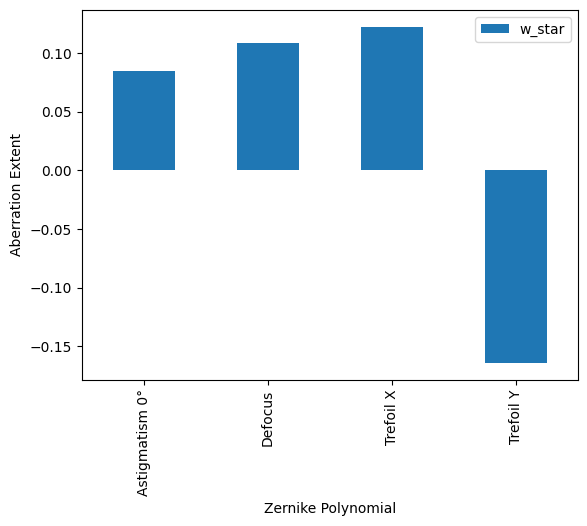

In [122]:
ax = effective_zernikes_df[
    (effective_zernikes_df['expected_y'] == 180) &
    (effective_zernikes_df['expected_x'] == 1030)
][['zernike_name','w_star']].sort_values(by='w_star', key=abs).plot.bar("zernike_name","w_star")

ax.set_ylabel('Aberration Extent')
ax.set_xlabel('Zernike Polynomial')
plt.show()

In [129]:
effective_zernikes_df[
    (effective_zernikes_df['expected_y'] == 180) &
    (effective_zernikes_df['expected_x'] == 1030)
][['zernike_index','zernike_name','w_star','w_star_se','w_star%']].sort_values(by='w_star', key=abs)

,zernike_index,zernike_name,w_star,w_star_se,w_star%
2,5,Astigmatism 0°,0.084893,0.010908,12.848781
0,3,Defocus,0.108861,0.010899,10.011708
5,8,Trefoil X,0.122428,0.030828,25.180211
6,9,Trefoil Y,-0.164091,0.033505,-20.418230


In [121]:
subset = pdf[(pdf['zernike_index'] == 9) & (pdf['expected_y'] == 480) & (pdf['expected_x'] == 1030)]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)

TypeError: 'PdfPages' object is not subscriptable

# Zernike Perturbations Iterative

In [393]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
# -----------------------

def quad_fit_with_cov(ws, ys):
    ws = np.asarray(ws, float)
    ys = np.asarray(ys, float)
    if len(ws) < 3 or len(np.unique(ws)) < 3:
        return False, None, None, None, None
    try:
        coeffs, cov = np.polyfit(ws, ys, deg=2, cov=True)
        a, b, c = coeffs
        return True, float(a), float(b), float(c), cov
    except Exception:
        return False, None, None, None, None

def vertex_from_quad(a, b, c):
    w_star = -b / (2*a)
    y_star = c - b*b / (4*a)
    return float(w_star), float(y_star)

def se_w_from_cov(a, b, cov):
    try:
        import math
        J = np.array([b/(2*a*a), -1/(2*a)])
        Sigma = cov[:2, :2]
        var_w = float(J @ Sigma @ J.T)
        return float(np.sqrt(max(var_w, 0.0)))
    except Exception:
        return np.nan

def fit_group(gdf, metric=METRIC):
    g = gdf.sort_values("w").copy()
    ws = g["w"].to_numpy(dtype=float)
    ys = g[metric].to_numpy(dtype=float)

    ok, a, b, c, cov = quad_fit_with_cov(ws, ys)
    w_min, w_max = (float(np.min(ws)), float(np.max(ws))) if len(ws) else (np.nan, np.nan)

    result = {
        "w_star": np.nan,
        "w_star_se": np.nan,
        "w_star%": np.nan,
        "y_star": np.nan,
        "method": None,
        "a": np.nan, "b": np.nan, "c": np.nan,
        "concave": False,
        "vertex_in_range": False,
        "w_min": w_min, "w_max": w_max,
        "argmax_w": float(ws[np.argmax(ys)]) if len(ws) else np.nan,
        "argmax_y": float(np.max(ys)) if len(ys) else np.nan,
        "n_points": int(len(ws))
    }

    if ok and a < 0:
        wv, yv = vertex_from_quad(a, b, c)
        result.update({
            "a": a, "b": b, "c": c,
            "concave": True,
            "vertex_in_range": (w_min <= wv <= w_max)
        })
        if result["vertex_in_range"]:
            result["w_star"] = wv
            result["y_star"] = yv
            result["method"] = "quad_fit"
            result["w_star_se"] = se_w_from_cov(a, b, cov) if cov is not None else np.nan
            return result

    result["w_star"] = result["argmax_w"]
    result["y_star"] = result["argmax_y"]
    result["method"] = "argmax"
    return result

def build_W_minimal(df, metric=METRIC):
    points = df[["expected_x","expected_y"]].drop_duplicates().sort_values(["expected_x","expected_y"]).to_records(index=False)
    zds = sorted(df["zernike_index"].unique())

    long_records = []
    wide_rows = []

    for (x0, y0) in points:
        row = {"expected_x": x0, "expected_y": y0}
        gspot = df[(df["expected_x"]==x0) & (df["expected_y"]==y0)]
        for zd in zds:
            g = gspot[gspot["zernike_index"]==zd]
            if g.empty:
                row[f"Z{zd}"] = np.nan
                continue
            fit = fit_group(g, metric=metric)
            row[f"Z{zd}"] = fit["w_star"]
            rec = {
                "expected_x": x0, "expected_y": y0, "zernike_index": zd,
                "w_star": fit["w_star"],
                "w_star_se": fit["w_star_se"],
                "y_star": fit["y_star"],
                "method": fit["method"],
                "a": fit["a"], "b": fit["b"], "c": fit["c"],
                "concave": fit["concave"],
                "vertex_in_range": fit["vertex_in_range"],
                "w_min": fit["w_min"], "w_max": fit["w_max"],
                "argmax_w": fit["argmax_w"], "argmax_y": fit["argmax_y"],
                "n_points": fit["n_points"]
            }
            long_records.append(rec)
        wide_rows.append(row)

    W = pd.DataFrame(wide_rows).sort_values(["expected_x","expected_y"])
    weights_long = pd.DataFrame(long_records).sort_values(["zernike_index","expected_x","expected_y"])
    weights_long['zernike_name'] = weights_long['zernike_index'].apply(lambda x : zernike_names[x] if x < 25 else x)
    cols = weights_long.columns.tolist()
    cols.insert(3, cols.pop(cols.index('zernike_name')))
    weights_long = weights_long[cols]

    weights_long['w_star%'] = weights_long['w_star_se']/weights_long['w_star']*100
    cols = weights_long.columns.tolist()
    cols.insert(6, cols.pop(cols.index('w_star%')))
    weights_long = weights_long[cols]
    return W, weights_long, zds
def get_weights_long_df(df):
    # CSV_PATH = base_path / "data" / "zernike" / "raw" / f"{file_name}.csv"
    OUT_DIR =  base_path / "data" / "zernike" / "raw" /"summary"
    os.makedirs(OUT_DIR, exist_ok=True)
    METRIC = "strehl_prime"

    zernike_names = {
        0: "Piston",
        1: "Tilt X",
        2: "Tilt Y",
        3: "Defocus",
        4: "Astigmatism 45°",
        5: "Astigmatism 0°",
        6: "Coma X",
        7: "Coma Y",
        8: "Trefoil X",
        9: "Trefoil Y",
        10: "Primary Spherical",
        11: "Secondary Astigmatism 0°",
        12: "Secondary Astigmatism 45°",
        13: "Secondary Coma X",
        14: "Secondary Coma Y",
        15: "Quadrafoil 0°",
        16: "Quadrafoil 45°",
        17: "Secondary Spherical",
        18: "Tertiary Astigmatism 0°",
        19: "Tertiary Astigmatism 45°",
        20: "Tertiary Coma X",
        21: "Tertiary Coma Y",
        22: "Tertiary Trefoil X",
        23: "Tertiary Trefoil Y",
        24: "Tertiary Spherical"
    }

    # Load and run
    # df = pd.read_csv(CSV_PATH)
    for c in list(df.columns):
        if c.lower().startswith("unnamed"):
            df = df.drop(columns=[c])

    W_df, weights_long_df, zds = build_W_minimal(df, metric=METRIC)

    Z_cols = [f"Z{zd}" for zd in zds]
    W_mat = W_df[Z_cols].fillna(0.0).to_numpy()
    coords = W_df[["expected_x","expected_y"]].to_numpy()

    os.makedirs(OUT_DIR, exist_ok=True)
    W_csv = os.path.join(OUT_DIR, "W_matrix_minimal.csv")
    weights_long_csv = os.path.join(OUT_DIR, "weights_long_minimal.csv")
    W_df.to_csv(W_csv, index=False)
    weights_long_df.to_csv(weights_long_csv, index=False)

    summary = (weights_long_df
            .groupby("zernike_index")
            .agg(n=("w_star", "size"),
                    concave_frac=("concave", "mean"),
                    vertex_in_range_frac=("vertex_in_range", "mean"),
                    median_w_star_se=("w_star_se", "median"),
                    mean_w_star_se=("w_star_se", "mean"))
            .reset_index()
            .sort_values("zernike_index"))
    summary_csv = os.path.join(OUT_DIR, "summary_minimal.csv")
    summary.to_csv(summary_csv, index=False)

    # PDF
    first100 = weights_long_df.head(100)
    pdf_path = os.path.join(OUT_DIR, "report_first100.pdf")

    from matplotlib.backends.backend_pdf import PdfPages
    with PdfPages(pdf_path) as pdf:
        for _, row in first100.iterrows():
            x0 = row["expected_x"]; y0 = row["expected_y"]; zd = row["zernike_index"]
            g = df[(df["expected_x"]==x0) & (df["expected_y"]==y0) & (df["zernike_index"]==zd)].sort_values("w")
            if g.empty:
                continue

            ws = g["w"].to_numpy(dtype=float)
            ys = g[METRIC].to_numpy(dtype=float)

            plt.figure()
            plt.plot(ws, ys, marker="o")
            plt.xlabel("w")
            plt.ylabel(METRIC)
            title = f"Z{int(zd)} @ ({int(x0)}, {int(y0)})"
            plt.title(title)

            if row["method"] == "quad_fit" and np.isfinite(row["a"]) and np.isfinite(row["b"]) and np.isfinite(row["c"]):
                a, b, c = row["a"], row["b"], row["c"]
                wgrid = np.linspace(np.min(ws), np.max(ws), 200)
                yfit = a*wgrid*wgrid + b*wgrid + c
                plt.plot(wgrid, yfit)
                plt.axvline(row["w_star"], linestyle="--")
            else:
                plt.axvline(row["argmax_w"], linestyle="--")

            txt = [
                f"method: {row['method']}",
                f"w*: {row['w_star']:.4g}",
                f"se(w*): {row['w_star_se']:.2g}" if np.isfinite(row["w_star_se"]) else "se(w*): n/a",
                f"concave: {bool(row['concave'])}, in-range: {bool(row['vertex_in_range'])}",
                f"n_points: {int(row['n_points'])}",
            ]
            plt.text(0.02, 0.98, "\n".join(txt), transform=plt.gca().transAxes,
                    va="top", ha="left")
            pdf.savefig()
            plt.close()

    print("W_matrix_minimal:", W_csv)
    print("weights_long_minimal:", weights_long_csv)
    print("summary_minimal:", summary_csv)
    print("report_first100.pdf:", pdf_path)
    return weights_long_df
def get_zernike_dict_from_weights_long_df(weights_long_df,spot_locations):
    effective_zernikes_df = weights_long_df[
        (weights_long_df['w_star%'].abs() < 30)
    ][['expected_x', 'expected_y', 'zernike_index','zernike_name','w_star','w_star_se', 'w_star%', 'y_star']].sort_values(by='w_star', key=abs,ascending=False)
    zernike_calibrations = []
    for spot_location in spot_locations:
        testing_x = spot_location[0]
        testing_y = spot_location[1]
        w_matrix = effective_zernikes_df[(effective_zernikes_df['expected_x']==testing_x)&(effective_zernikes_df['expected_y']==testing_y)]
        zernike_weights = w_matrix.set_index('zernike_index')['w_star'].to_dict()
        zernike_calibrations.append(zernike_weights)
    return zernike_calibrations

In [394]:
from slmsuite.holography.toolbox.phase import zernike_sum
from slmsuite.holography.toolbox.phase import zernike
import numpy as np
import torch
class CompressedHolo:
    def __init__(self,zernike_calibrations,fs):
        """Pass a zernike calibration a list of dicts with keys zernike_index and weights"""
        self.zernike_calibrations = zernike_calibrations
        self.N = len(zernike_calibrations)
        self.H = fs.slm.shape[0]
        self.W = fs.slm.shape[1]
        self.kernel = self.compute_kernel(zernike_calibrations,fs)
        self.A_in = torch.ones(self.H,self.W)/np.sqrt(self.H*self.W)
    def zt(self,F_in):
        """zernike transform of the nearfield to farfield 
        Takes input the nearfield and outputs a array of size N
        NxHxW,HxW to Nx1
        """
        return torch.einsum('nhw,hw->n', self.kernel, F_in)
    def izt(self,F_out):
        """inverse zernike transform of the farfield to nearfield 
        Takes input the farfield spot array complex amplitudes and outputs a array of size HxW
        NxHxW,Nx1 to HxW
        """
        return torch.einsum('nhw,n->hw', torch.conj(self.kernel), F_out)
    def compute_kernel(self,zernike_calibrations,fs):
        """Compute the zernike kernel"""
        kernels = []
        for zernike_calibration in zernike_calibrations:
            kernels.append(zernike_sum(fs,tuple(zernike_calibration.keys()),tuple(zernike_calibration.values()),use_mask = False))
        return torch.exp(1j*torch.from_numpy(np.stack(kernels)).float())
    def optimize_gs(self,initial_phase,iters = 10):
        """Optimize the Gerchberg-Saxton algorithm using the zernike transform"""
        if initial_phase == None:
            initial_phase = torch.zeros(self.H,self.W)
        else :
            initial_phase = torch.tensor(initial_phase)
        phi_in = initial_phase
        for iter in range(iters):
            F_in = self.A_in*torch.exp(1j*phi_in)
            phi_out = torch.angle(self.zt(F_in))
            F_out = torch.exp(1j*phi_out)/np.sqrt(self.N)
            phi_in = torch.angle(self.izt(F_out))
        return phi_in.numpy()
    def lens(self,z):
        """ create a lens phase with a quadratic phase near focus
        Args:
            z (float): Propagation distance.
            Returns: lens (torch.Tensor): Lens phase, shape (H, W)"""
        
        return torch.exp(1j * z * self.q_tensor)
    def forward_propagate(self,F_in,z=0):
        """ forward propagation of the field F_in through a lens with a quadratic phase near focus
        Args:
            F_in (torch.Tensor): Input field, shape (H, W).
            z (float): Propagation distance.
            Returns: farfield (torch.Tensor): Output field after propagation, shape (H, W)"""
        if z == 0:
            field_nf = F_in
        else:
            field_nf = F_in * self.lens(z)
        return torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(field_nf), norm='ortho'))

False

In [882]:
import pandas as pd
def get_zernike_data(base_phase,file_name = "zernike_data_temp",nz = 21):
    "iterates the top 20 zernike polynomials over the given phase mask and saves the data to the file_name"
    data = {}
    zernike_indices = [i for i in range(1,nz+1)]
    for zernike_index in zernike_indices:
        zernike_term_phase = zernike(fs.slm, zernike_index,use_mask = False)
        data[zernike_index] = {
            "w": [],
            "images": []
        }
        for w in np.linspace(-1, 1, 21):  
            phase = base_phase + w * zernike_term_phase
            if np.isnan(phase).any() == True:
                print("na's exist")
            image = save_cam(fs,phase = phase,sleep = 4)
            data[zernike_index]["w"].append(w)
            data[zernike_index]["images"].append(image)
    save_path = base_path / "data" / "zernike" / "raw" / f"{file_name}.pkl"
    with open(save_path, 'wb') as f:
        pickle.dump(data, f)
    return data
def get_zernike_metrics_df(loaded,spot_locations,file_name = "zernike_data_temp"):
    "Computes tweezer level metrics like strehl ratio etc into a dataframe using the get_tweezer_metrics and expected tweezer locations and the data from iterating zernike modes"
    results = []
    crop_pixels = 30

    for zernike_index, zernike_data in loaded.items():
        images = zernike_data["images"]  # list of images at different w

        for w_index, image in enumerate(images):
            refined_centres = refine_centers(image, spot_locations, 200)
            spot_index = 0
            for (expected, refined) in zip(spot_locations, refined_centres):
                cx, cy = refined
                crop_details = (
                    slice(cy - crop_pixels, cy + crop_pixels),
                    slice(cx - crop_pixels, cx + crop_pixels)
                )

                cropped_image = image[crop_details]
                metrics = get_tweezer_metrics(cropped_image)

                results.append({
                    "zernike_index": zernike_index,
                    "w_index": w_index,
                    "w":zernike_data['w'][w_index],
                    "spot_index":spot_index,
                    "expected_x": expected[0],
                    "expected_y": expected[1],
                    "refined_x": cx,
                    "refined_y": cy,
                    **metrics
                })
                spot_index+=1
    
    pdf = pd.DataFrame(results)
    load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
    pdf.to_csv(load_path)
    return pdf

    

def get_zernike_calibrations(phase,spot_locations,file_name,nz):
    "iterates the zenike polynomials takes the spot level zernike metric dataframe fits parabolas and returns the top zernike modes with aberration weights as a dict"
    data = get_zernike_data(base_phase=phase,file_name = file_name,nz=nz)
    zernike_metrics_df = get_zernike_metrics_df(loaded=data,spot_locations = spot_locations,file_name=file_name)
    weights_long_df = get_weights_long_df(df = zernike_metrics_df)
    zernike_calibrations = get_zernike_dict_from_weights_long_df(weights_long_df=weights_long_df,spot_locations=spot_locations)  
    return zernike_calibrations

def get_cholo_phase(zernike_calibrations):
    "get the phase mask using gerchberg saxton algorithm in zernike space"
    cholo = CompressedHolo(zernike_calibrations = zernike_calibrations,fs=fs)
    phase = cholo.optimize_gs(initial_phase=None,iters = 30)
    return phase



In [ ]:
zernike_calibrations = []
nz = 20
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10,1024+65] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations.append({i+1: float(v) for i, v in enumerate(zernike_arr)})

writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writin

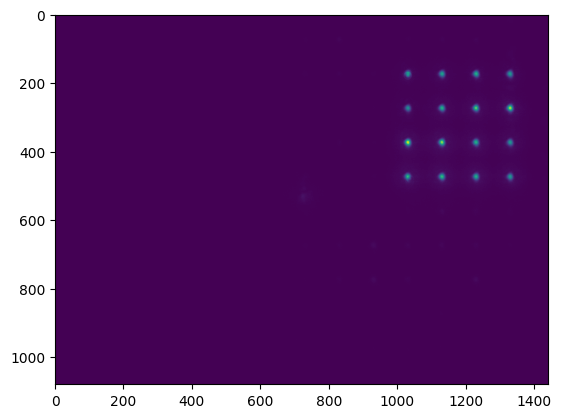

In [458]:
phases = []
calibs = []
calibs_full = []
for i in range(8):
    file_name = f"zernike_pert_test_iter_{i}"
    phase = get_cholo_phase(zernike_calibrations=zernike_calibrations)
    zernike_calibrations_new = get_zernike_calibrations(phase,spot_locations,file_name,nz)
    zernike_calibrations = [{k: d1[k] +  d2.get(k, 0) for k in d1} for d1, d2 in zip(zernike_calibrations, zernike_calibrations_new)]
    phases.append(phase)
    calibs.append(zernike_calibrations_new)
    calibs_full.append(zernike_calibrations)
    

In [463]:

calibs[0][0]

{6: 0.38624604501092574, 3: 0.19647938165809034, 4: 0.16128075235727335}

In [472]:
calibs[3]

[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}, {}, {}, {}, {}, {}, {}]

In [468]:
calibs[7][0]

{}

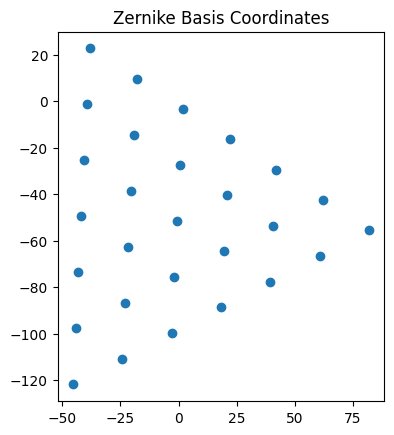

In [ ]:
from slmsuite.holography.toolbox import format_vectors
from slmsuite.holography.toolbox.phase import zernike_convert_index

center = format_vectors((512, 640))
res = (320*4, 320*4)
((i0, i1), (i2, i3)) = limits = (
    (int(center[0] - res[0]/2), int(center[0] + res[0]/2)),
    (int(center[1] - res[1]/2), int(center[1] + res[1]/2))
)

N = 28
i = np.arange(N)
nl = zernike_convert_index(i, from_index="ansi", to_index="radial")
ij = 50 * np.vstack((nl[:, 1], (3-nl[:, 0]) * np.sqrt(3))) + center
sz = convert_vector(ij, from_units="ij", to_units="zernike", hardware=fs)

plt.title("Zernike Basis Coordinates")
plt.scatter(sz[0], sz[1])
plt.gca().set_aspect("equal")

base = np.zeros((N,N))

base[2, :] = sz[0]      # Tilt x term
base[1, :] = sz[1]      # Tilt y term

In [264]:
perturbation = np.diag(np.ones(N))
print((base + 10*perturbation)[:10, :10].astype(int))

[[ 10   0   0   0   0   0   0   0   0   0]
 [-55 -56 -42 -77 -53 -29 -88 -64 -40 -16]
 [ 82  60  72  39  40  42  18  19  20  22]
 [  0   0   0  10   0   0   0   0   0   0]
 [  0   0   0   0  10   0   0   0   0   0]
 [  0   0   0   0   0  10   0   0   0   0]
 [  0   0   0   0   0   0  10   0   0   0]
 [  0   0   0   0   0   0   0  10   0   0]
 [  0   0   0   0   0   0   0   0  10   0]
 [  0   0   0   0   0   0   0   0   0  10]]


In [238]:
zernike_calibrations = []
for zernike_arr in (base + 10*perturbation).T:
    zernike_calibrations.append({i: float(v) for i, v in enumerate(zernike_arr)})

In [954]:
zernike_calibrations = []
nz = 5
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10,1024+65] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations.append({i+1: float(v) for i, v in enumerate(zernike_arr)})

In [955]:
cholo = CompressedHolo(zernike_calibrations = zernike_calibrations,fs=fs)
phase = cholo.optimize_gs(initial_phase=None,iters = 100)

writing phase


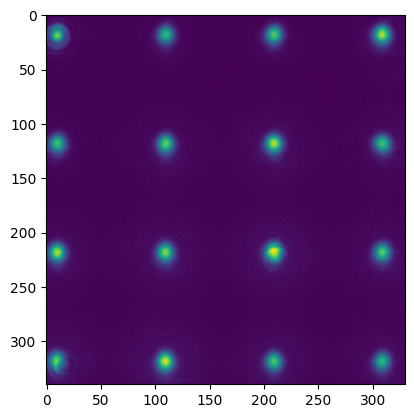

In [956]:
image = plot_cam(fs = fs,phase=phase+zernike(fs,1,0))
plt.imshow(image[180-20:480+20,1030-10:1330+20])

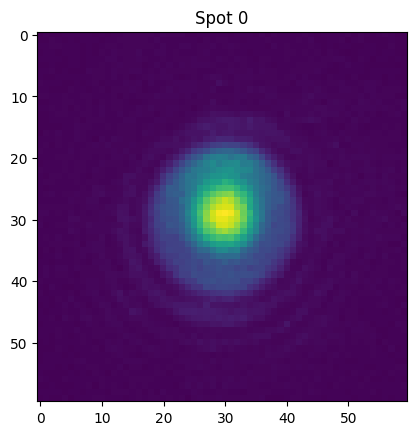

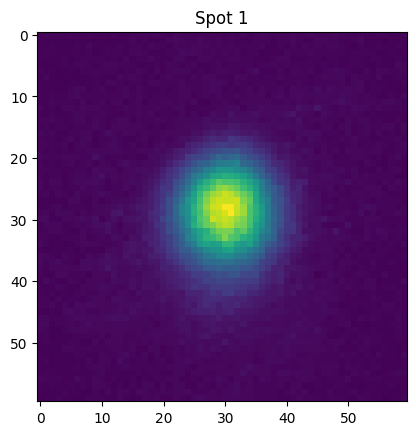

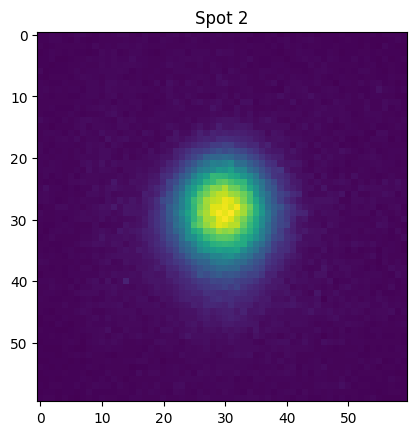

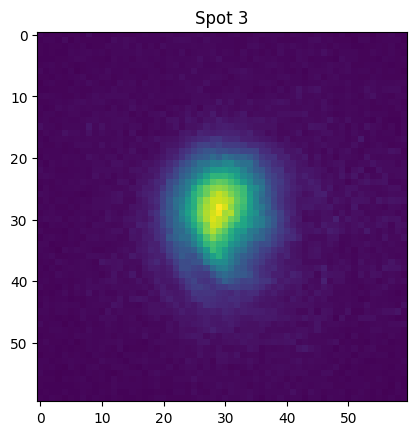

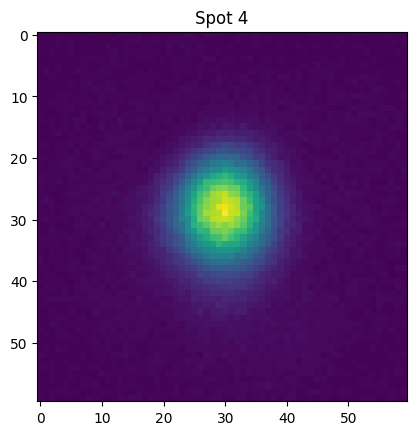

...

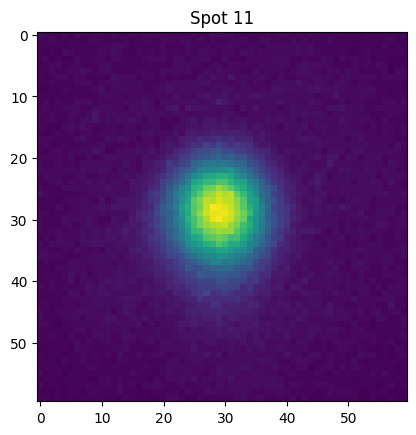

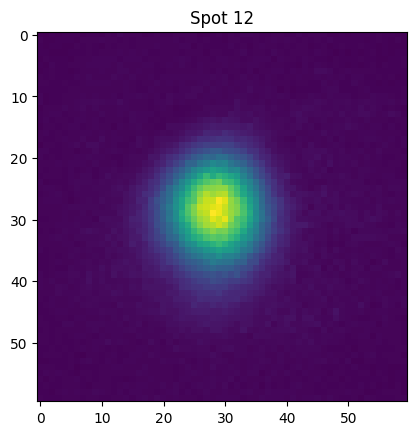

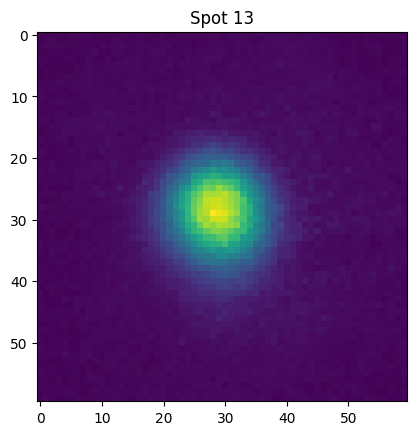

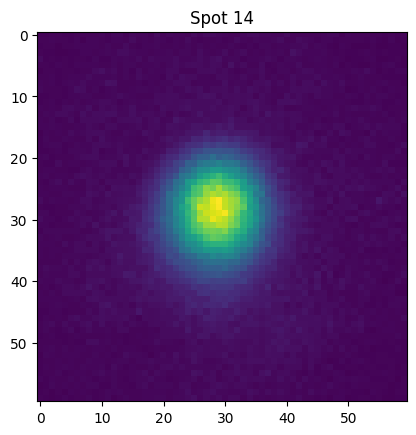

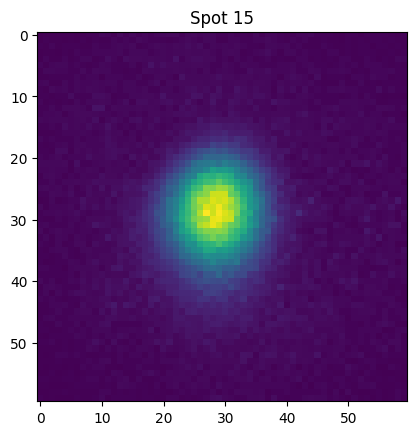

In [957]:
for s in range(16):
    p_size = 30
    plt.imshow(image[spot_locations[s][1]-p_size:spot_locations[s][1]+p_size,spot_locations[s][0]-p_size:spot_locations[s][0]+p_size])
    plt.title(f"Spot {s}")
    plt.show()

writing phase


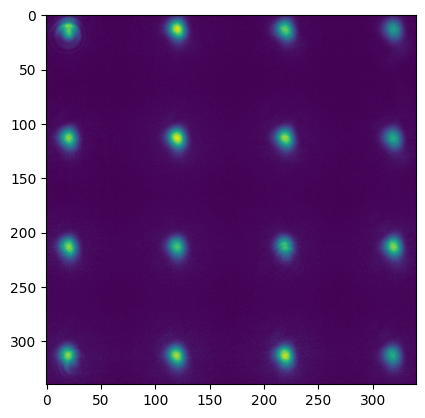

In [951]:
image = plot_cam(fs = fs,phase=phases[1])
plt.imshow(image[180-20:480+20,1030-20:1330+20])

writing phase


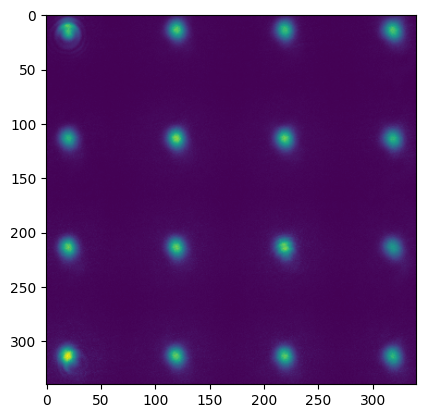

In [409]:
image = plot_cam(fs = fs,phase=phases[2])
plt.imshow(image[180-20:480+20,1030-20:1330+20])

In [640]:
s = 5
zi = 4
spot_locations[s]

array([1130,  280])

In [641]:
calibs[0][s]

{6: 0.30346977369848827,
 3: 0.17817741875003462,
 4: 0.1492222541692444,
 5: 0.1351575904939567}

<Axes: >

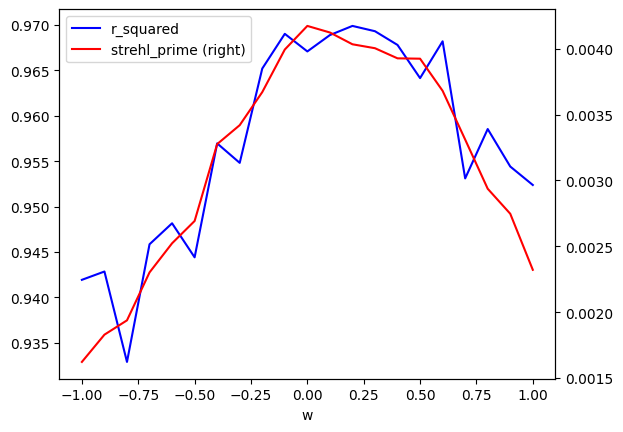

In [642]:
file_name = f"zernike_pert_test_iter_{0}"
load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
pdf = pd.read_csv(load_path)

subset = pdf[
    (pdf['zernike_index'] == zi) &
    (pdf['expected_y'] == spot_locations[s][1]) &
    (pdf['expected_x'] == spot_locations[s][0])
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)


<Axes: >

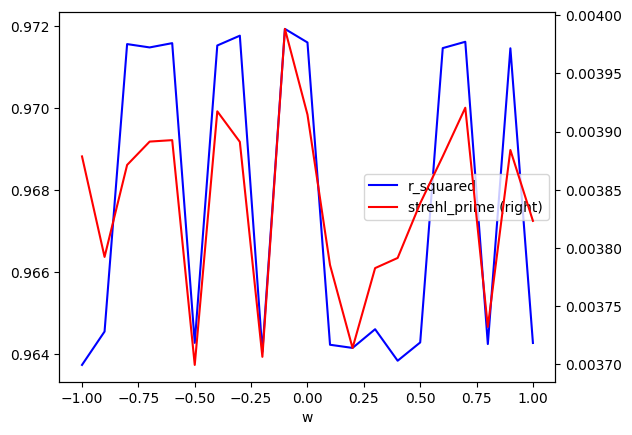

In [643]:
file_name = f"zernike_pert_test_iter_{1}"
load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
pdf = pd.read_csv(load_path)

subset = pdf[
    (pdf['zernike_index'] == zi) &
    (pdf['expected_y'] == spot_locations[s][1]) &
    (pdf['expected_x'] == spot_locations[s][0])
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)

<Axes: >

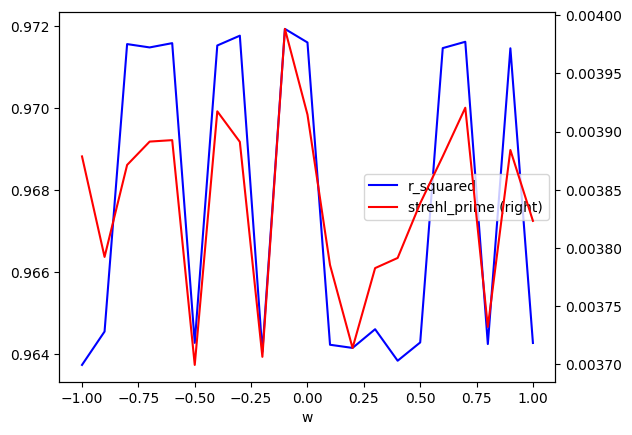

In [644]:
file_name = f"zernike_pert_test_iter_{1}"
load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
pdf = pd.read_csv(load_path)

subset = pdf[
    (pdf['zernike_index'] == zi) &
    (pdf['expected_y'] == spot_locations[s][1]) &
    (pdf['expected_x'] == spot_locations[s][0])
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)

In [300]:
spot_locations

array([[1030,  180],
       [1030,  280],
       [1030,  380],
       [1030,  480],
       [1130,  180],
       [1130,  280],
       [1130,  380],
       [1130,  480],
       [1230,  180],
       [1230,  280],
       [1230,  380],
       [1230,  480],
       [1330,  180],
       [1330,  280],
       [1330,  380],
       [1330,  480]])

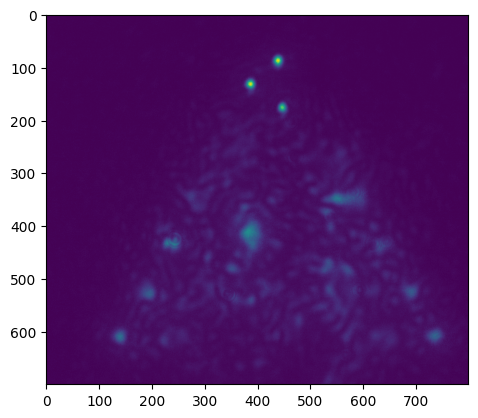

In [241]:
plt.imshow(image[100:800,500:1300])

In [623]:
image = get_cam(fs=fs,phase = toolbox.phase.blaze(fs,vector = (0.003,-0.003)))

writing phase


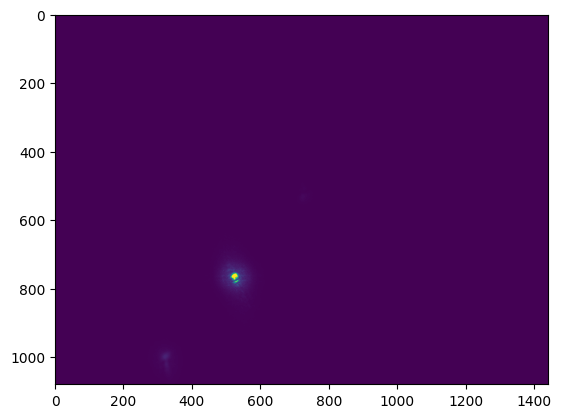

In [624]:
plt.imshow(image)

In [ ]:
image[330:360,490:520].sum()
image[750:790,510:540].sum()

1359

490881

AttributeError: 'AxesImage' object has no attribute 'sum'

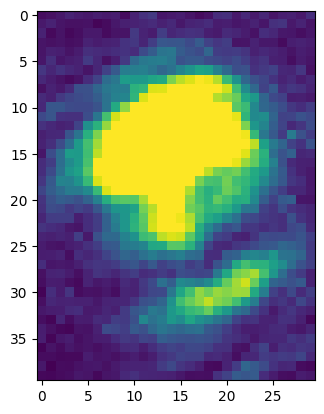

In [ ]:
plt.imshow()

<Axes: >

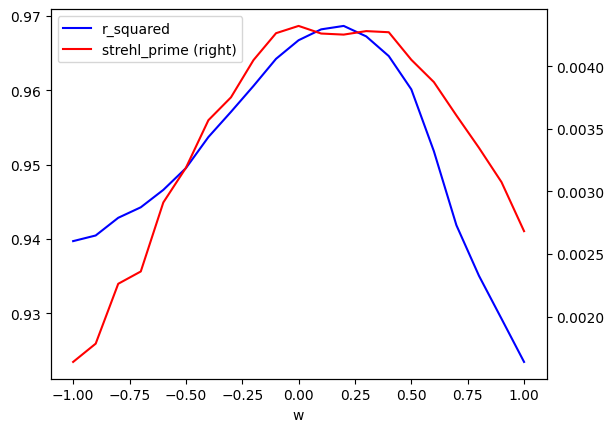

In [876]:
s=0
file_name = f"zernike_pert_test_iter_{0}"
load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
pdf = pd.read_csv(load_path)

subset = pdf[
    (pdf['zernike_index'] == 4) &
    (pdf['expected_y'] == spot_locations[s][1]) &
    (pdf['expected_x'] == spot_locations[s][0])
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)

In [877]:
subset[['w','strehl_prime']]

,w,strehl_prime
1008,-1.0,0.001638
1024,-0.9,0.001784
1040,-0.8,0.002262
1056,-0.7,0.002361
1072,-0.6,0.002912
1088,-0.5,0.003188
1104,-0.4,0.003569
1120,-0.3,0.003751
1136,-0.2,0.004049
1152,-0.1,0.004264


In [879]:
sweep = subset['w'].to_numpy()
result = subset[metric].to_numpy()

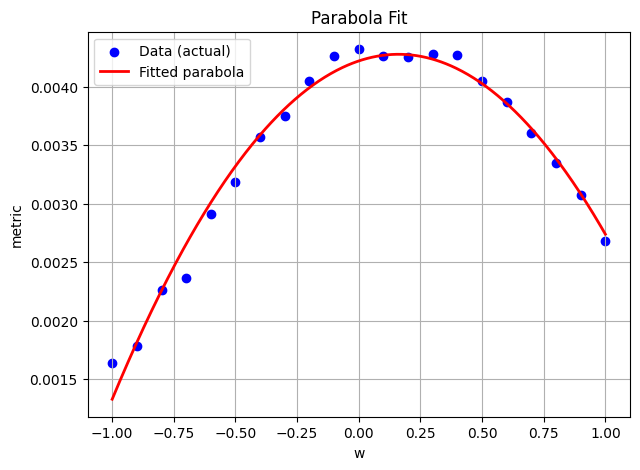

In [880]:
popt = fit_metric(sweep,result)
plot_parabola(popt,sweep,result)

In [ ]:
pdf.groupby('zernike_index','expected_x','expected_y').apply()

,Unnamed: 0,zernike_index,w_index,w,expected_x,expected_y,refined_x,refined_y,height,sigmax,sigmay,centerx,centery,fwhm_x,fwhm_y,ellipticity,strehl_prime,rmse,r_squared,window_px
0,0,1,0,-1.0,1030,180,1126,273,223.650413,5.641966,6.311167,29.689018,31.230456,13.285814,14.861664,0.893965,0.004291,6.070148,0.970517,43
1,1,1,0,-1.0,1030,280,1025,374,330.544776,5.647196,6.451385,31.068125,30.380415,13.298130,15.191850,0.875346,0.003910,8.839915,0.972148,43
2,2,1,0,-1.0,1030,380,1025,374,330.544776,5.647196,6.451385,31.068125,30.380415,13.298130,15.191850,0.875346,0.003910,8.839915,0.972148,43
3,3,1,0,-1.0,1030,480,1126,473,229.581731,5.907394,6.588165,29.543655,31.202570,13.910850,15.513943,0.896668,0.003709,8.122006,0.952205,45
4,4,1,0,-1.0,1130,180,1224,274,271.472472,5.623549,6.309124,31.055362,29.973471,13.242446,14.856852,0.891336,0.004173,6.696710,0.975752,43
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6715,6715,20,20,1.0,1230,480,1132,473,230.812316,6.040143,6.732589,27.933202,31.141610,14.223450,15.854034,0.897150,0.003542,8.355921,0.951658,45
6716,6716,20,20,1.0,1330,180,1329,274,301.669715,5.886420,6.555781,30.069719,29.985033,13.861459,15.437686,0.897897,0.003866,8.020268,0.973885,45
6717,6717,20,20,1.0,1330,280,1329,274,301.669715,5.886420,6.555781,30.069719,29.985033,13.861459,15.437686,0.897897,0.003866,8.020268,0.973885,45
6718,6718,20,20,1.0,1330,380,1231,473,209.151981,5.942585,6.863683,28.490671,31.107285,13.993717,16.162738,0.865801,0.003653,7.842115,0.948283,45


In [884]:
file_name = f"zernike_pert_test_iter_{0}"
save_path = base_path / "data" / "zernike" / "raw" / f"{file_name}.pkl"
with open(save_path, 'rb') as f:
    loaded = pickle.load(f)
pdf = get_zernike_metrics_df(loaded,spot_locations,file_name = file_name)

In [887]:
pdf

,zernike_index,w_index,w,spot_index,expected_x,expected_y,refined_x,refined_y,height,sigmax,sigmay,centerx,centery,fwhm_x,fwhm_y,ellipticity,strehl_prime,rmse,r_squared,window_px
0,1,0,-1.0,0,1030,180,1126,273,223.650413,5.641966,6.311167,29.689018,31.230456,13.285814,14.861664,0.893965,0.004291,6.070148,0.970517,43
1,1,0,-1.0,1,1030,280,1025,374,330.544776,5.647196,6.451385,31.068125,30.380415,13.298130,15.191850,0.875346,0.003910,8.839915,0.972148,43
2,1,0,-1.0,2,1030,380,1025,374,330.544776,5.647196,6.451385,31.068125,30.380415,13.298130,15.191850,0.875346,0.003910,8.839915,0.972148,43
3,1,0,-1.0,3,1030,480,1126,473,229.581731,5.907394,6.588165,29.543655,31.202570,13.910850,15.513943,0.896668,0.003709,8.122006,0.952205,45
4,1,0,-1.0,4,1130,180,1224,274,271.472472,5.623549,6.309124,31.055362,29.973471,13.242446,14.856852,0.891336,0.004173,6.696710,0.975752,43
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6715,20,20,1.0,11,1230,480,1132,473,230.812316,6.040143,6.732589,27.933202,31.141610,14.223450,15.854034,0.897150,0.003542,8.355921,0.951658,45
6716,20,20,1.0,12,1330,180,1329,274,301.669715,5.886420,6.555781,30.069719,29.985033,13.861459,15.437686,0.897897,0.003866,8.020268,0.973885,45
6717,20,20,1.0,13,1330,280,1329,274,301.669715,5.886420,6.555781,30.069719,29.985033,13.861459,15.437686,0.897897,0.003866,8.020268,0.973885,45
6718,20,20,1.0,14,1330,380,1231,473,209.151981,5.942585,6.863683,28.490671,31.107285,13.993717,16.162738,0.865801,0.003653,7.842115,0.948283,45


In [894]:
pdf['zernike_index'].value_counts()

zernike_index
1     336
2     336
19    336
18    336
17    336
16    336
15    336
14    336
13    336
12    336
11    336
10    336
9     336
8     336
7     336
6     336
5     336
4     336
3     336
20    336
Name: count, dtype: int64

In [895]:
def fit_metric_udf(sweep,result):
    "udf for pandas which returns mean,error"
    popt,perr = fit_metric(sweep,result)
    return popt[0]

In [902]:
def fit_metric_udf(sweep,result):
    "udf for pandas which returns mean,error"
    popt,perr = fit_metric(sweep,result)
    return pd.Series({"avg_sales": popt[0], "total_profit": perr[0]})

In [910]:
res = pdf.groupby(["zernike_index","spot_index"]).apply(lambda g : fit_metric_udf(g['w'].to_numpy(),g['strehl_prime'].to_numpy())).reset_index()

Optimal parameters not found: The maximum number of function evaluations is exceeded.
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the

In [911]:
res

,zernike_index,spot_index,avg_sales,total_profit
0,1,0,0.700000,0.000000
1,1,1,0.000000,1.569924
2,1,2,0.000000,1.569924
3,1,3,0.425282,0.234747
4,1,4,0.000000,5483.989437
...,...,...,...,...
315,20,11,0.000000,1733.319717
316,20,12,0.000000,2.061552
317,20,13,0.000000,2.061552
318,20,14,0.000000,3941.807992


# Zernike formatted code

In [422]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)])



zernike_calibrations = []
nz = 20
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10,1024+65] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations.append({i+1: float(v) for i, v in enumerate(zernike_arr)})
zernike_indices = [i+1 for i in range(nz)]

writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
very high error in the fit, setting values to 0
very high error in the fit, setting values to 0
A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
very high error in the fit, setting values to 0
very high error in the f

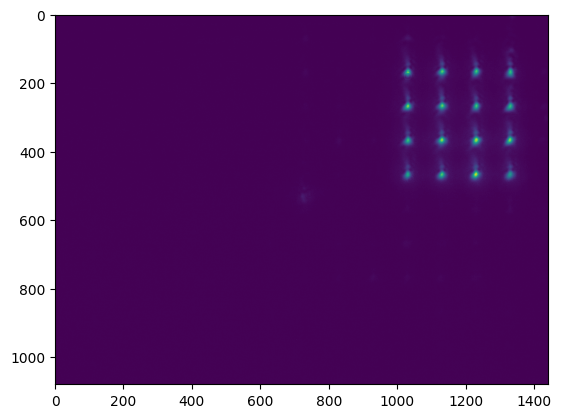

In [423]:
phases = []
calibs = []
calibs_full = []
for i in range(5):
    for zi in range(1,nz+1):
        file_name = f"zernike_pert_test_iter_{i}_{zi}"
        phase = get_cholo_phase(zernike_calibrations=zernike_calibrations,fs = fs)
        zernike_calibrations_new = get_zernike_calibrations(phase,spot_locations,[zi],file_name)
        zernike_calibrations = [{k: d1[k] -  d2.get(k, 0) for k in d1} for d1, d2 in zip(zernike_calibrations, zernike_calibrations_new)]
        phases.append(phase)
        calibs.append(zernike_calibrations_new)
        calibs_full.append(zernike_calibrations)

writing phase


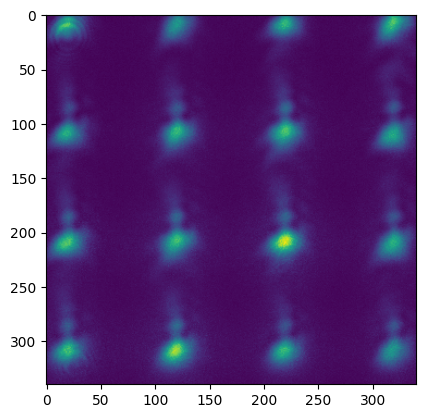

In [424]:
image = plot_cam(fs = global_store.fs,phase=phases[0])
plt.imshow(image[180-20:480+20,1030-20:1330+20])

writing phase


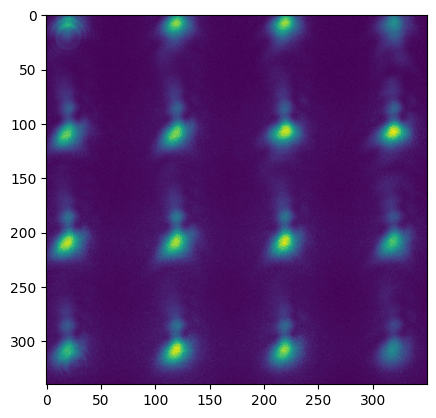

In [425]:
image = plot_cam(fs = global_store.fs,phase=phases[20])
plt.imshow(image[180-20:480+20,1030-20:1330+30])

writing phase


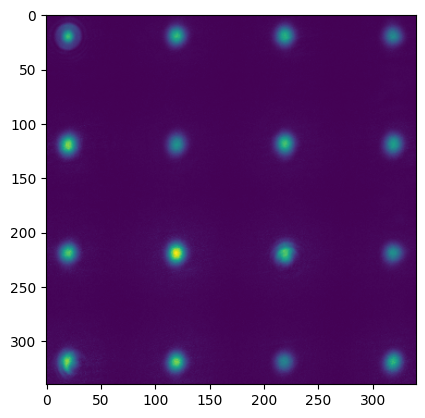

In [125]:
image = plot_cam(fs = global_store.fs,phase=phases[40])
plt.imshow(image[180-20:480+20,1030-20:1330+20])

writing phase


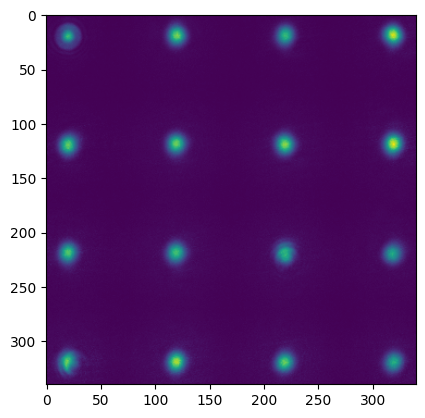

In [126]:
image = plot_cam(fs = global_store.fs,phase=phases[60])
plt.imshow(image[180-20:480+20,1030-20:1330+20])

writing phase


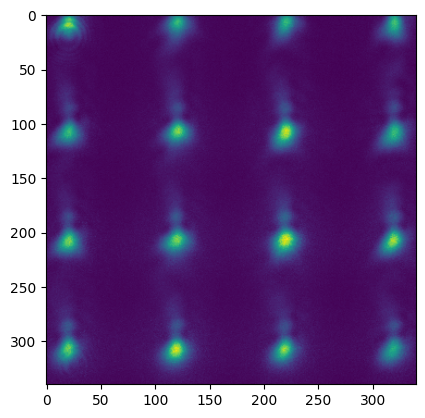

In [426]:
image = plot_cam(fs = global_store.fs,phase=phases[80])
plt.imshow(image[180-20:480+20,1030-20:1330+20])

<Axes: >

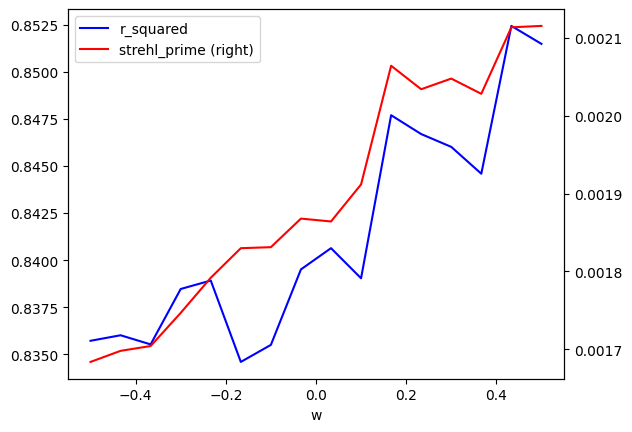

In [427]:
import pandas as pd
s=0
zi = 4
file_name = f"zernike_pert_test_iter_{0}_{zi}"
load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
pdf = pd.read_csv(load_path)

subset = pdf[
    (pdf['zernike_index'] == zi) &
    (pdf['expected_y'] == spot_locations[s][1]) &
    (pdf['expected_x'] == spot_locations[s][0])
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)

Optimal parameters not found: The maximum number of function evaluations is exceeded.
(0.5, -0.00010029134135410594, 15)
[0. 0. 0.]


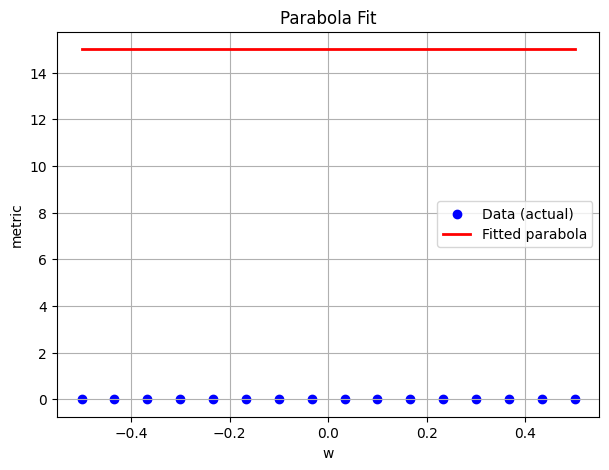

In [428]:
popt,perr = fit_metric(subset['w'].to_numpy(),subset['strehl_prime'].to_numpy())
print(popt)
print(perr)
plot_parabola(popt=popt,sweep=subset['w'].to_numpy(),result = subset['strehl_prime'].to_numpy())

<Axes: >

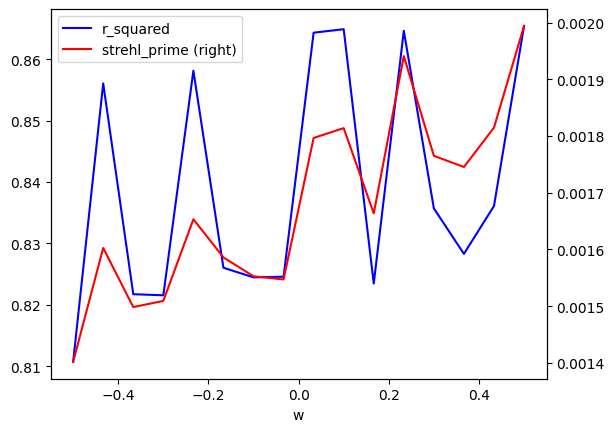

In [429]:
import pandas as pd
file_name = f"zernike_pert_test_iter_{1}_{zi}"
load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
pdf = pd.read_csv(load_path)

subset = pdf[
    (pdf['zernike_index'] == zi) &
    (pdf['expected_y'] == spot_locations[s][1]) &
    (pdf['expected_x'] == spot_locations[s][0])
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)

A Zernike aberration optimized out of the range of the measurement.
very high error in the fit, setting values to 0
[0. 0. 0.]
[2.31933464e+02 2.86586649e-04 5.13889617e-02]


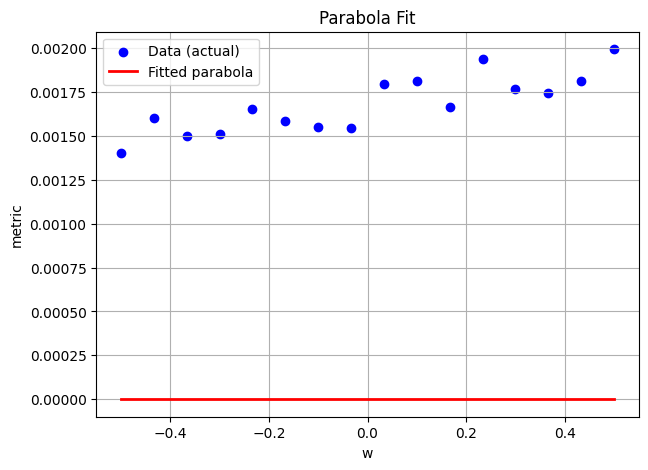

In [430]:
popt,perr = fit_metric(subset['w'].to_numpy(),subset['strehl_prime'].to_numpy())
print(popt)
print(perr)
plot_parabola(popt=popt,sweep=subset['w'].to_numpy(),result = subset['strehl_prime'].to_numpy())

<Axes: >

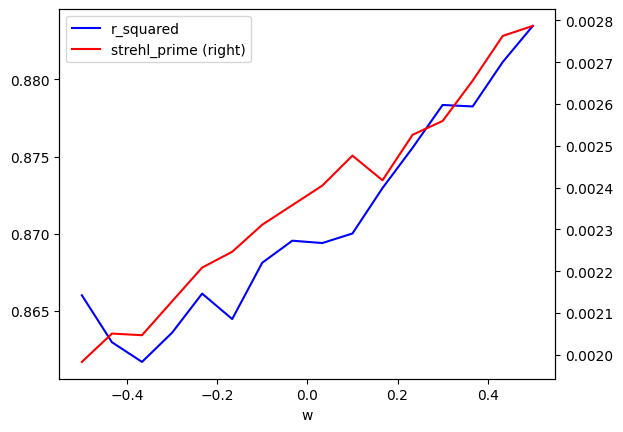

In [431]:
import pandas as pd
file_name = f"zernike_pert_test_iter_{4}_{zi}"
load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
pdf = pd.read_csv(load_path)

subset = pdf[
    (pdf['zernike_index'] == zi) &
    (pdf['expected_y'] == spot_locations[s][1]) &
    (pdf['expected_x'] == spot_locations[s][0])
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)

Optimal parameters not found: The maximum number of function evaluations is exceeded.
(0.5, -0.0003529501717138441, 15)
[0. 0. 0.]


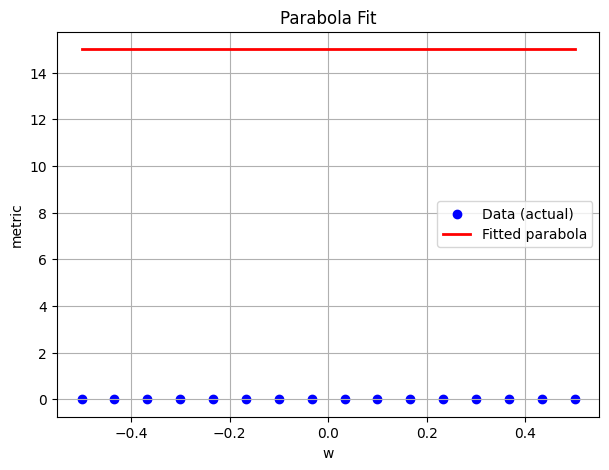

In [432]:
popt,perr = fit_metric(subset['w'].to_numpy(),subset['strehl_prime'].to_numpy())
print(popt)
print(perr)
plot_parabola(popt=popt,sweep=subset['w'].to_numpy(),result = subset['strehl_prime'].to_numpy())

In [433]:
for i in range(6):
    print(calibs[i][s][zi])

KeyError: 4

In [109]:
calibs

[[{1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0},
  {1: 0.0}],
 [{2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0},
  {2: 0.0}],
 [{3: 0.0},
  {3: 0.10428383718615546},
  {3: 0.17966224485128296},
  {3: 0.0},
  {3: 0.0},
  {3: 0.0},
  {3: 0.0},
  {3: 0.2},
  {3: 0.0},
  {3: 0.14885541449365192},
  {3: 0.14885541449365192},
  {3: 0.11956962112690407},
  {3: 0.14161226397248938},
  {3: 0.0},
  {3: 0.2},
  {3: 0.125625392780067}],
 [{4: 0.2},
  {4: 0.19471717099152483},
  {4: 0.15574087619078184},
  {4: 0.18344679476915776},
  {4: 0.13065519853104562},
  {4: 0.12393494920140001},
  {4: 0.1281588931466159},
  {4: 0.12299273474167172},
  {4: 0.09282119750921713},
  {4: 0.0},
  {4: 0.11441630704007678},
  {4: 0.1405493801444461},
  {4: 0.1

In [ ]:
calibs[1][s][1]

0.0

4 1


KeyError: 1

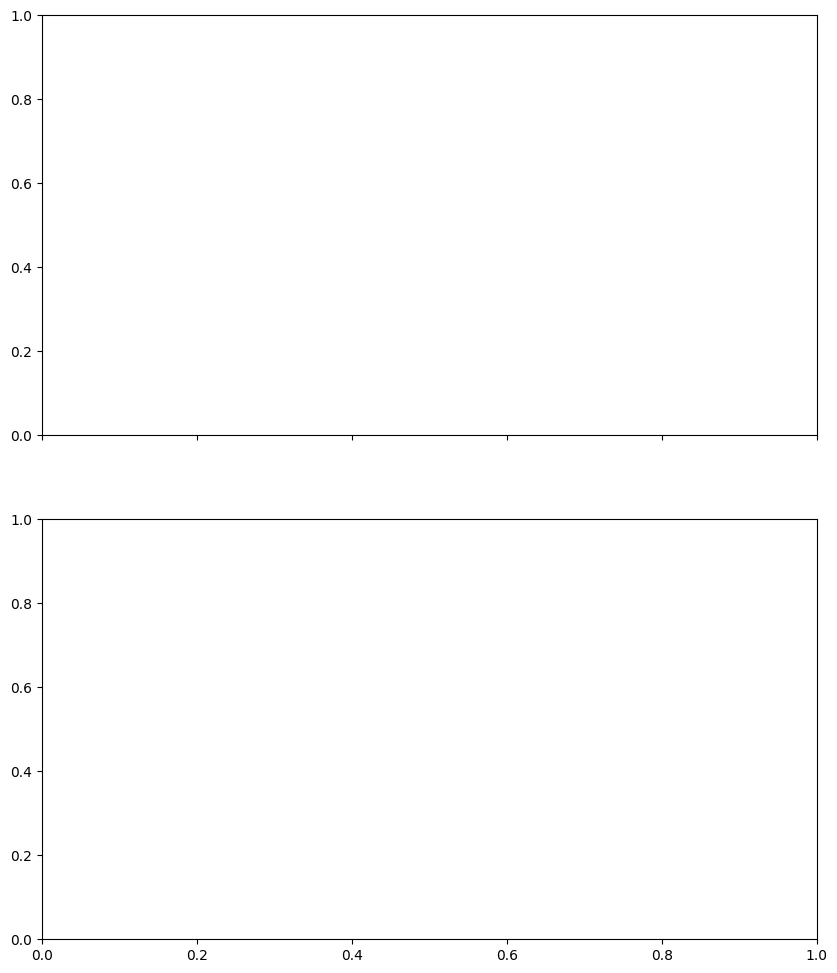

In [108]:
import matplotlib.pyplot as plt
  # or an integer index
zi_range = range(1, 5)   # 1 to 20
i_vals = [3,7,11,15,19]
s = 4
# Group zi into chunks of 4
groups = [zi_range[i:i+2] for i in range(0, len(zi_range), 2)]
fig, axes = plt.subplots(len(groups), 1, figsize=(10, 12), sharex=True)
for ax, group in zip(axes, groups):
    for zi in group:
        print(s,zi)
        y_vals = [calibs[i][s][zi] for i in i_vals]
        ax.plot(i_vals, y_vals, label=f"zi={zi}")
    ax.set_ylabel("Value")
    ax.legend(fontsize=8, ncol=2)
    ax.grid(True)

axes[-1].set_xlabel("i")
fig.suptitle(f"Trends of zi=1…20 for s={s}", fontsize=14)
plt.tight_layout()
plt.show()


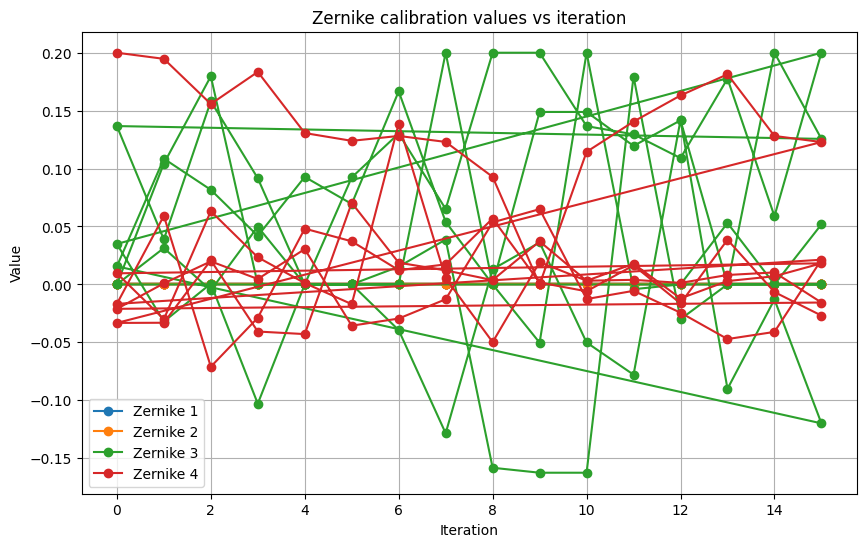

In [110]:
import matplotlib.pyplot as plt
import pandas as pd

# your calibs list goes here

# Flatten into records: (iter, zernike_index, value)
records = []
for iter_idx, calib_run in enumerate(calibs):
    for step_idx, d in enumerate(calib_run):
        for zidx, val in d.items():
            records.append({
                "iteration": step_idx,
                "run": iter_idx,
                "zernike_index": zidx,
                "value": val
            })

df = pd.DataFrame(records)

# Plot: one curve per zernike_index
plt.figure(figsize=(10,6))
for zidx, subdf in df.groupby("zernike_index"):
    plt.plot(subdf["iteration"], subdf["value"], marker="o", label=f"Zernike {zidx}")

plt.xlabel("Iteration")
plt.ylabel("Value")
plt.title("Zernike calibration values vs iteration")
plt.legend()
plt.grid(True)
plt.show()


In [187]:
calibs[20]

[{1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0},
 {1: 0.0}]

In [440]:
pdf[(pdf['w_index'] == 8)&(pdf['spot_index'] == 14)]

,Unnamed: 0,zernike_index,w_index,w,spot_index,expected_x,expected_y,refined_x,refined_y,height,...,sigmay,centerx,centery,fwhm_x,fwhm_y,ellipticity,strehl_prime,rmse,r_squared,window_px
142,142,1,8,0.033333,14,1330,380,1231,366,110.281417,...,11.365648,28.320703,32.138357,21.231725,26.764056,0.793292,0.001646,9.487192,0.859913,71


In [434]:
import pandas as pd
for i in range(5):
    file_name = f"zernike_pert_test_iter_{i}_{2}"
    load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
    pdf = pd.read_csv(load_path)
    print(pdf[(pdf['w_index'] == 8)]['r_squared'].mean())

0.8374897117145279
0.8408912018840973
0.8419669067759452
0.8452683099865258
0.8564134361958358


In [442]:
import pandas as pd
for i in range(5):
    file_name = f"zernike_pert_test_iter_{i}_{1}"
    load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
    pdf = pd.read_csv(load_path)
    print(pdf[(pdf['w_index'] == 10)]['strehl_prime'].mean())

0.0015082444671158752
0.0016341879507038
0.0017557903942188187
0.0017455233450753686
0.0018694858117002124


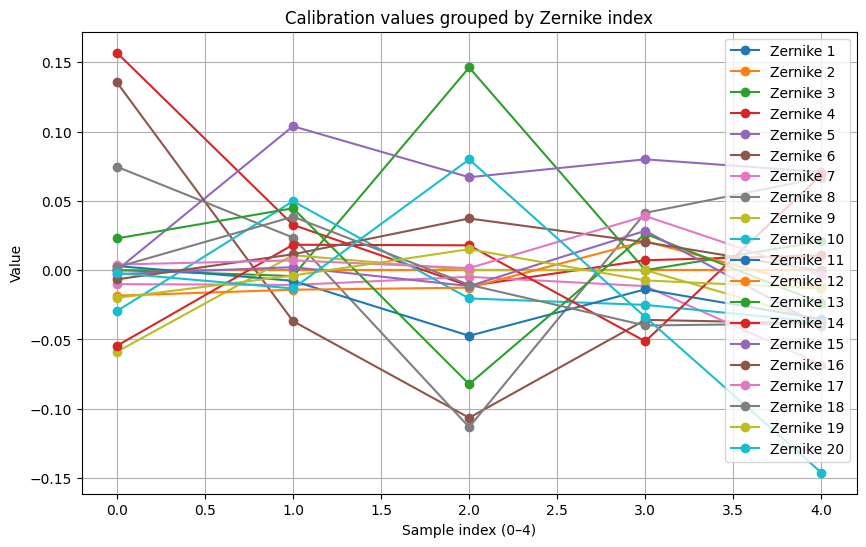

In [183]:
import matplotlib.pyplot as plt

nz = 20   # number of zernike indices
grouped = {j: [] for j in range(nz)}

# collect values
for i in range(len(calibs)):
    j = i % nz
    grouped[j].append(calibs[i][0][j+1])   # store values for zernike j+1

# plot each Zernike index separately
plt.figure(figsize=(10,6))
for j in range(nz):
    plt.plot(range(len(grouped[j])), grouped[j], marker="o", label=f"Zernike {j+1}")

plt.xlabel("Sample index (0–4)")
plt.ylabel("Value")
plt.title("Calibration values grouped by Zernike index")
plt.legend()
plt.grid(True)
plt.show()


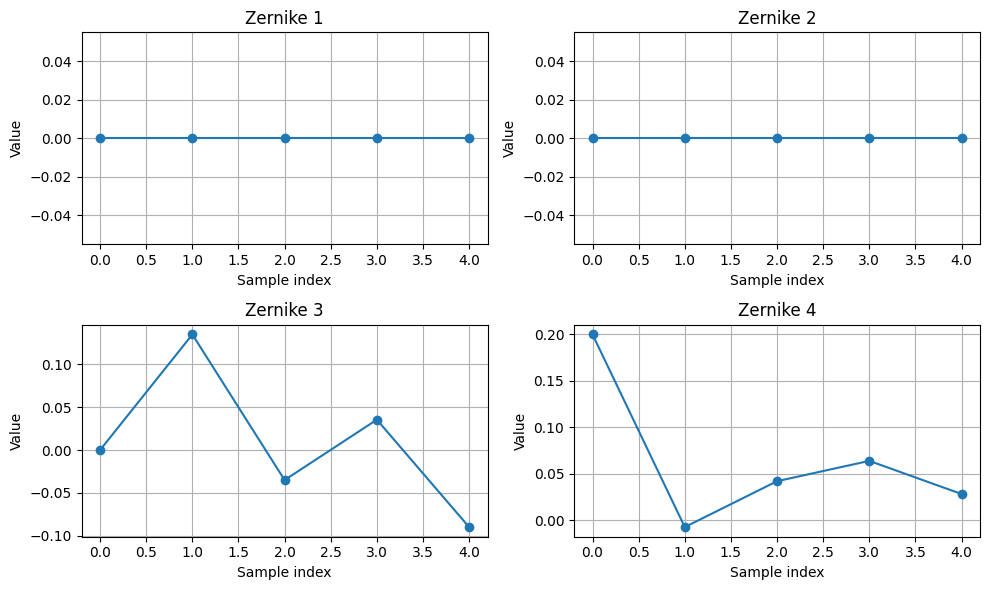

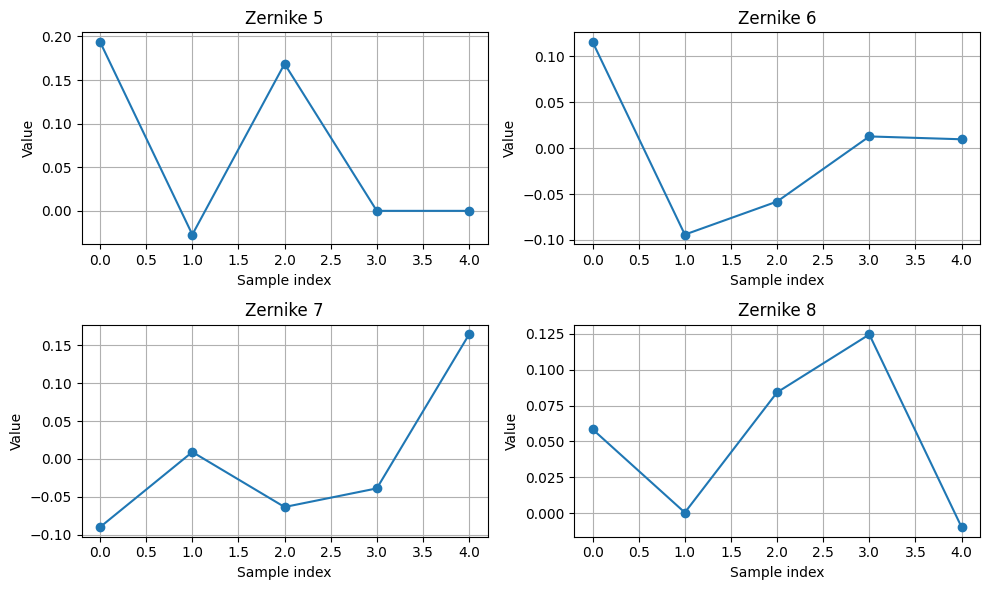

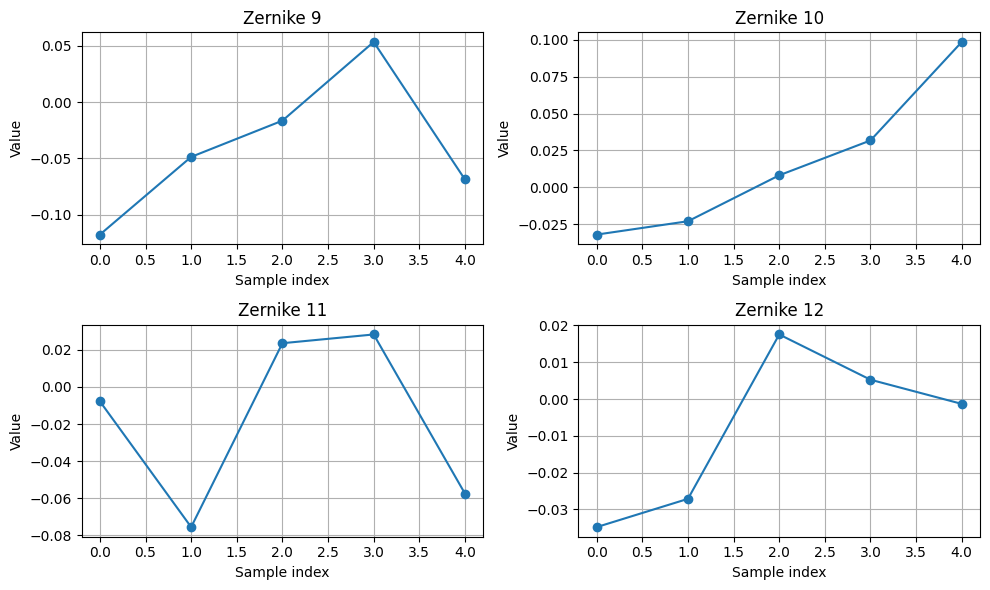

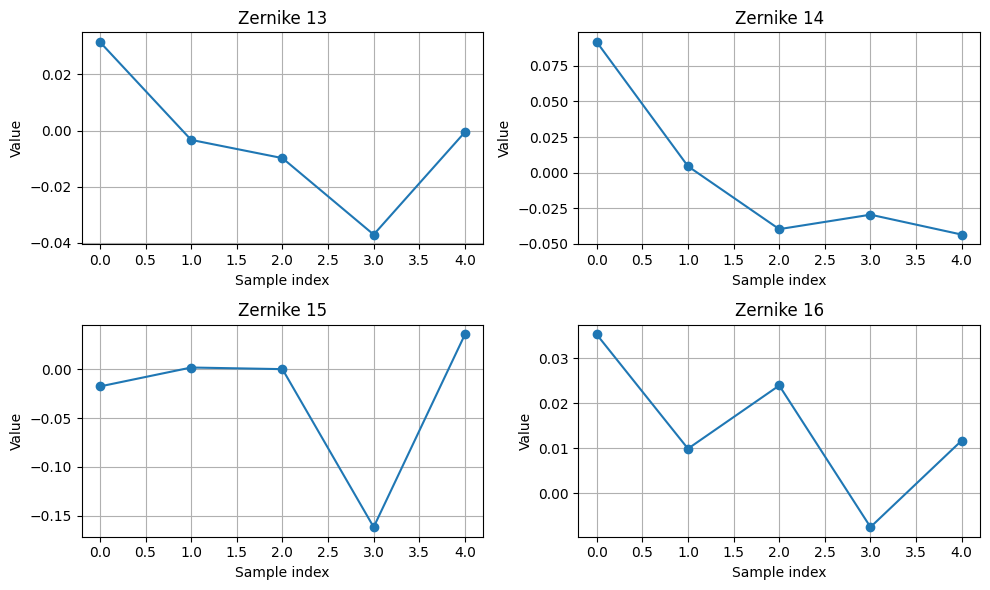

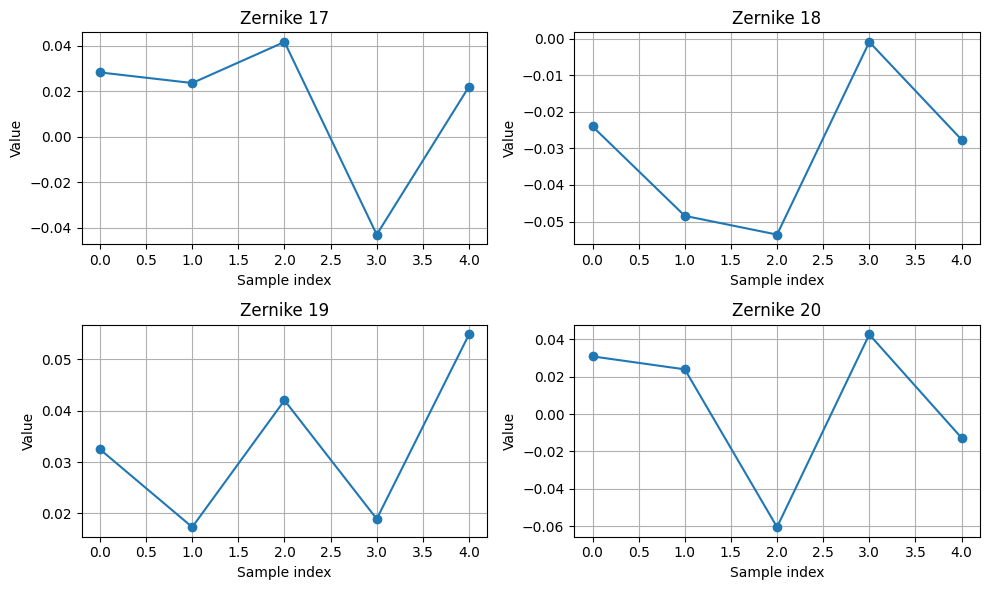

In [277]:
import matplotlib.pyplot as plt

nz = 20   # number of Zernike indices
grouped = {j: [] for j in range(nz)}

# collect values
for i in range(len(calibs)):
    j = i % nz
    grouped[j].append(calibs[i][3][j+1])

# make plots: 4 per figure (2x2 layout)
plots_per_fig = 4
rows, cols = 2, 2

for fig_start in range(0, nz, plots_per_fig):
    fig, axes = plt.subplots(rows, cols, figsize=(10, 6))
    axes = axes.flatten()

    for k in range(plots_per_fig):
        j = fig_start + k
        if j >= nz:
            axes[k].axis("off")  # hide extra axes
            continue
        axes[k].plot(range(len(grouped[j])), grouped[j], marker="o")
        axes[k].set_title(f"Zernike {j+1}")
        axes[k].set_xlabel("Sample index")
        axes[k].set_ylabel("Value")
        axes[k].grid(True)

    plt.tight_layout()
    plt.show()


In [276]:
import pandas as pd
for i in range(1,21):
    file_name = f"zernike_pert_test_iter_{0}_{i}"
    load_path = base_path / "data" / "zernike" / "raw" / f"{file_name}_df.csv"
    pdf = pd.read_csv(load_path)
    print(pdf[(pdf['w_index'] == 7)&(pdf['spot_index'] == 3)]['strehl_prime'].mean())

0.0036508053972717
0.0035946614923442
0.003611277146842
0.0039609290878326
0.0039214694125385
0.0041559261402493
0.0042227907406836
0.0041552802006513
0.0041172755538282
0.0042067419061915
0.0040286888036496
0.0039144785947685
0.0042448414276004
0.0042233615986327
0.0044039483675018
0.0038363416645886
0.0038876735780863
0.0038344217219453
0.0039202121526576
0.0039805080056405


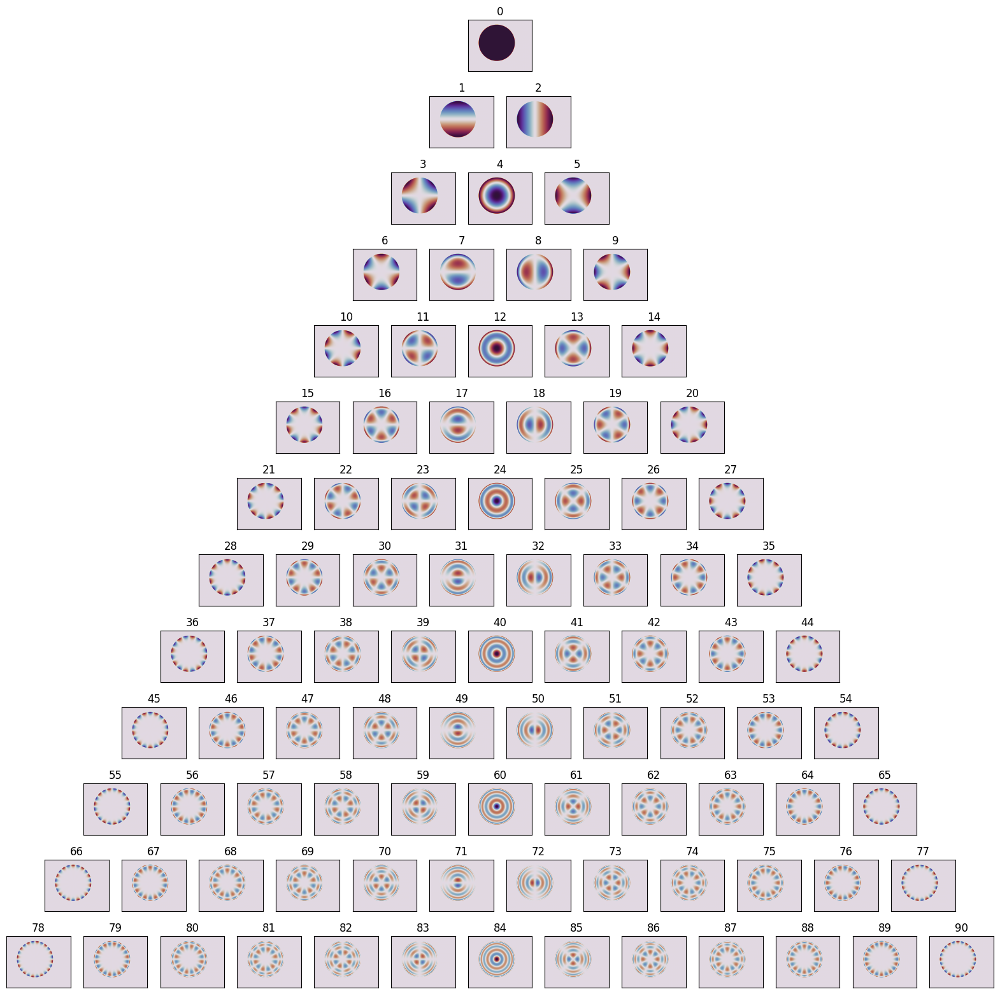

In [267]:
from slmsuite.holography.toolbox.phase import zernike_pyramid_plot

plt.figure(figsize=(20,20))
zernike_pyramid_plot(fs.slm, order=12, titles=["ansi"])

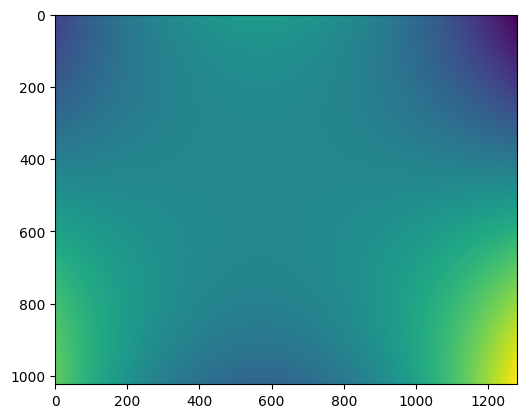

In [271]:
plt.imshow(zernike(fs,6,use_mask = False))

In [414]:
zernike_calibrations2 = []
nz = 20
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10,1024+65] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations2.append({i+1: float(v) for i, v in enumerate(zernike_arr)})

In [415]:
phase = get_cholo_phase(zernike_calibrations=zernike_calibrations2,fs = fs)

writing phase


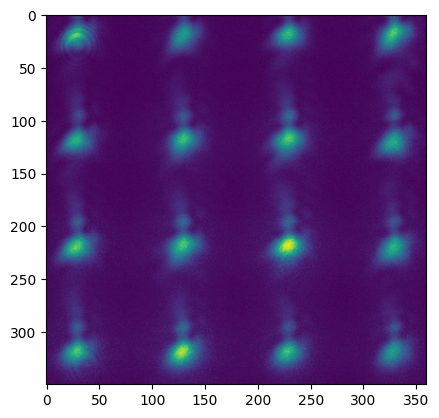

In [416]:
image = plot_cam(fs = global_store.fs,phase=phase)
plt.imshow(image[180-30:480+20,1030-30:1330+30])

writing phase


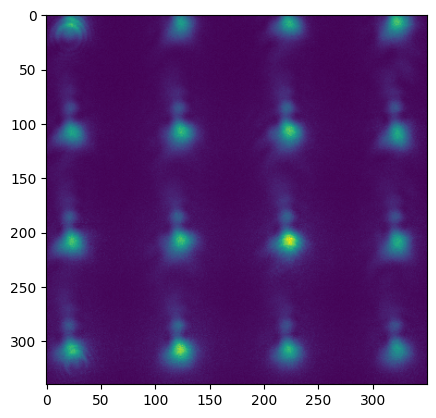

In [421]:
image = plot_cam(fs = global_store.fs,phase=phase +1*zernike(grid = fs,index = 7,weight = -1,use_mask = False))
plt.imshow(image[180-20:480+20,1030-20:1330+30])

In [356]:
amp = fs.slm.source['amplitude']/np.sqrt((fs.slm.source['amplitude']**2).sum())

# SLMSuite zernike calibration

array([[2, 1, 1, ..., 1, 1, 1],
       [1, 2, 1, ..., 1, 2, 2],
       [1, 1, 1, ..., 1, 2, 1],
       ...,
       [1, 1, 1, ..., 2, 2, 1],
       [1, 2, 2, ..., 1, 2, 2],
       [1, 1, 2, ..., 2, 2, 2]], dtype=uint16)

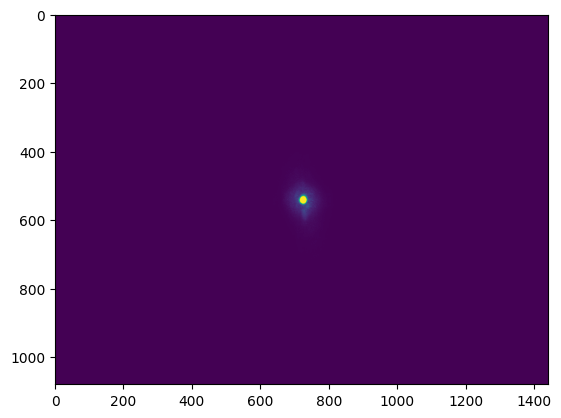

In [459]:
plot_cam(fs,phase="zero")

In [361]:
from slmsuite.holography.toolbox import convert_vector

points_ij = fs.wavefront_calibration_points(100)

points_zernike = convert_vector(
    points_ij,
    from_units="ij",
    to_units="zernike",
    hardware=fs
)

In [363]:
phase_slm = fs.slm.source['phase'].copy()

array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 2, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [2, 2, 1, ..., 1, 1, 1],
       [2, 2, 1, ..., 1, 1, 2],
       [1, 1, 1, ..., 1, 2, 2]], dtype=uint16)

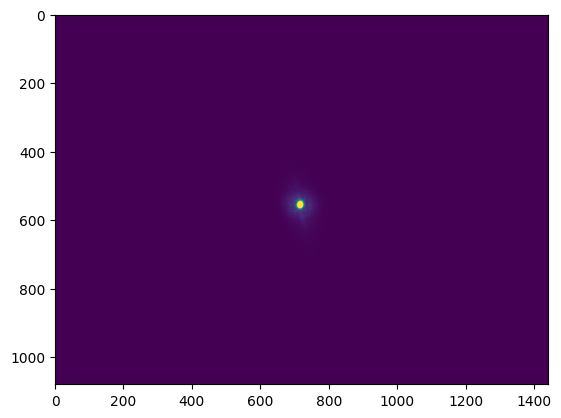

In [362]:
plot_cam(fs,phase = 'zero')

In [364]:
fs.calibrations.keys()

dict_keys(['fourier', 'settle', 'wavefront_superpixel'])

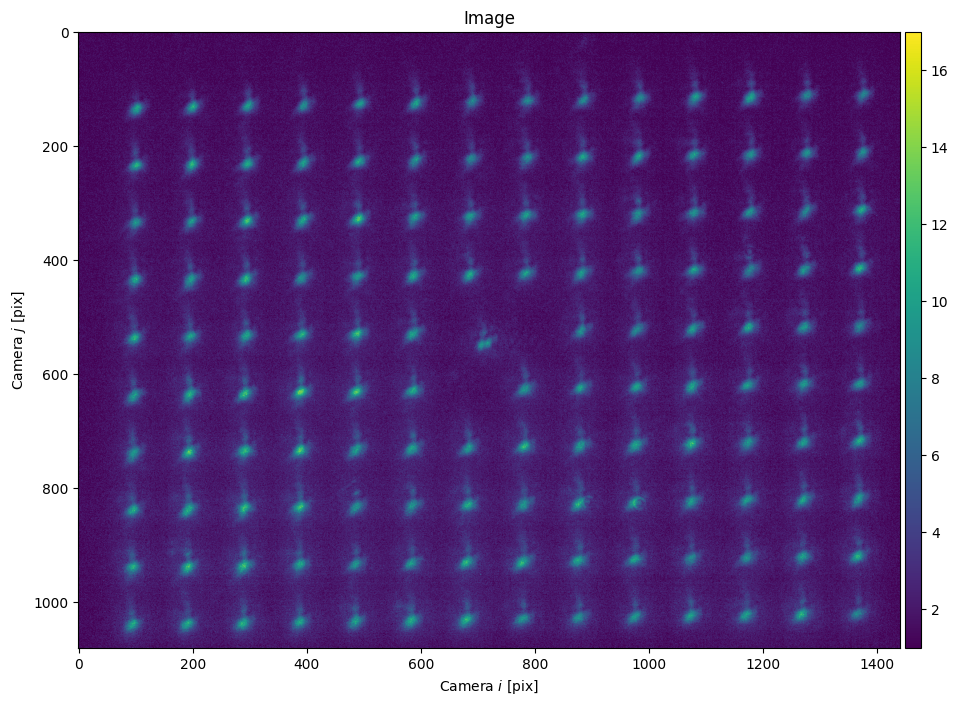

In [365]:
out = fs.wavefront_calibrate_zernike(points_zernike, perturbation=0, plot=True)

Z_4:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


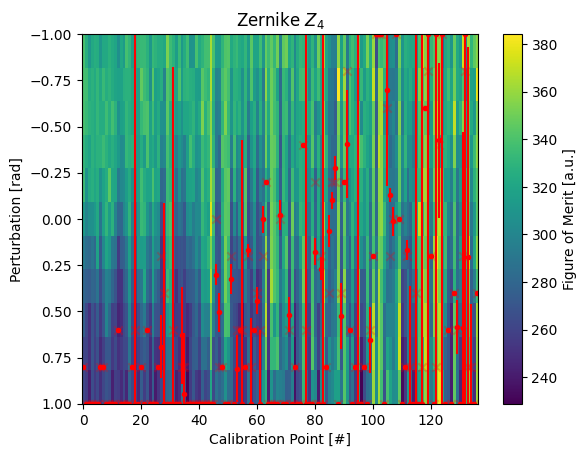

Z_3:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


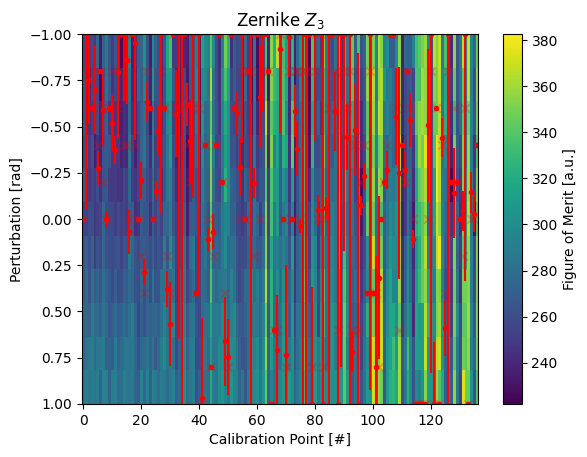

Z_5:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


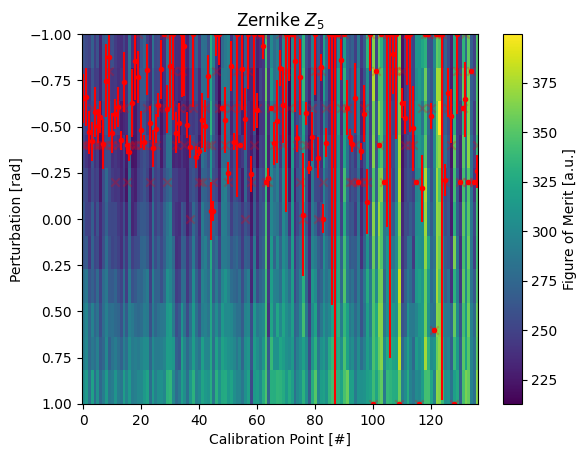

Z_6:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


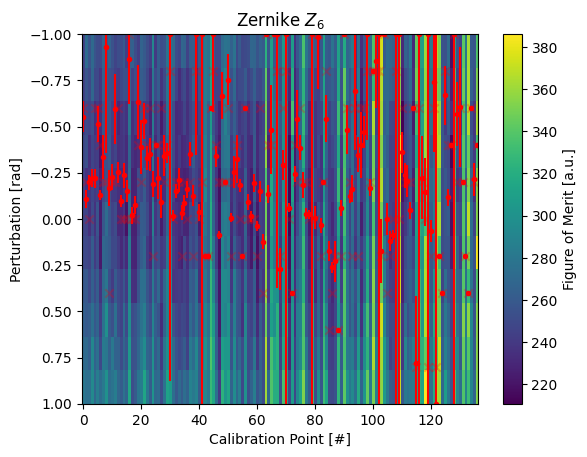

Z_7:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


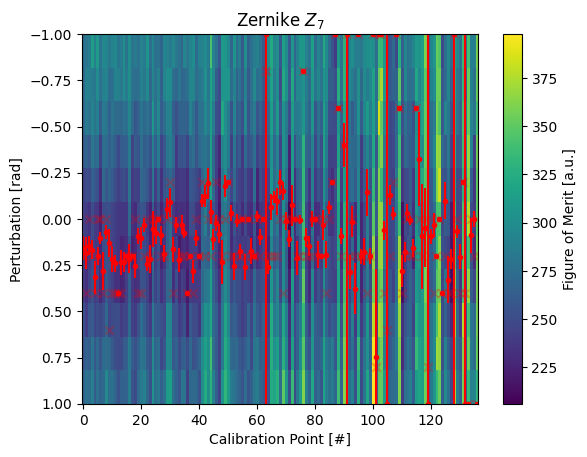

Z_8:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


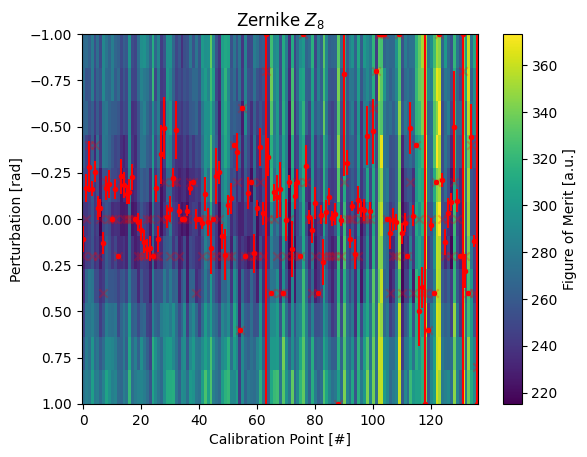

Z_9:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


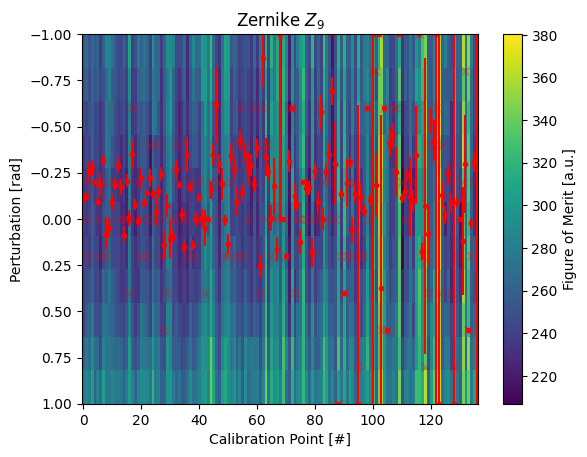

In [366]:
fs.wavefront_calibrate_zernike(points_zernike, zernike_indices=9, perturbation=1, plot=True);

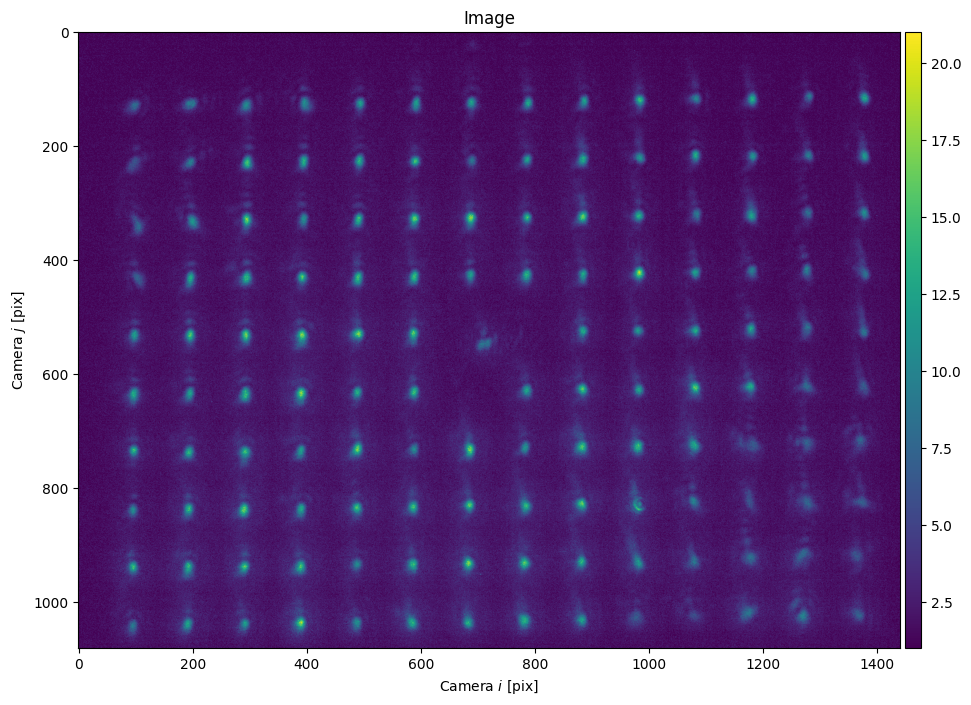

In [367]:
fs.wavefront_calibrate_zernike(None, zernike_indices=9, perturbation=0, plot=True)

Z_4:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


Z_3:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


Z_5:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


... (34 outputs left out)

Z_9:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


Z_4:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


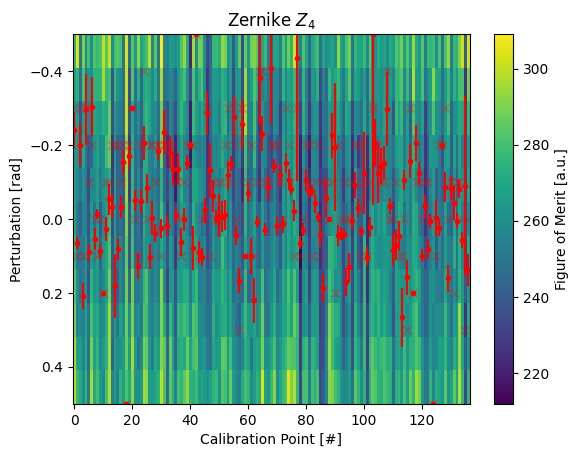

Z_3:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


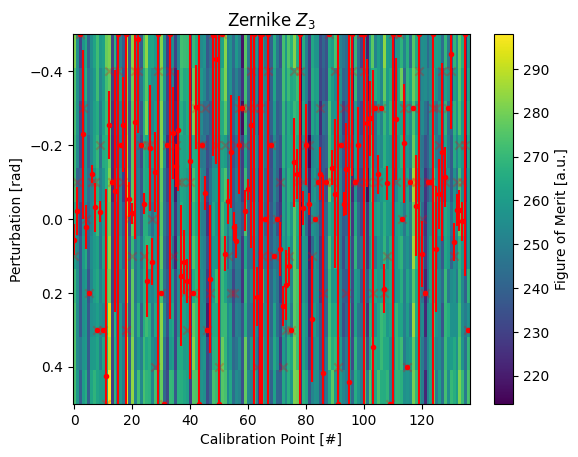

Z_5:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


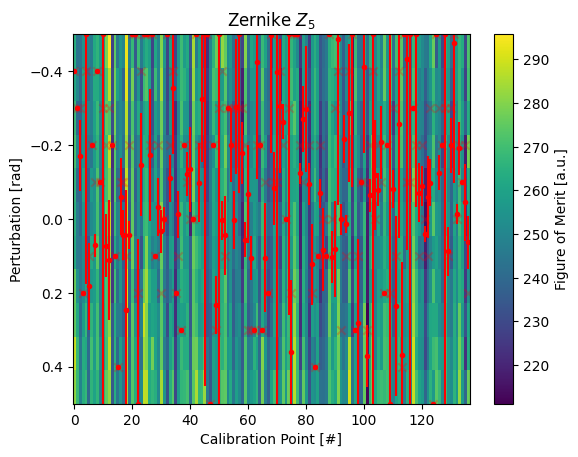

Z_6:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


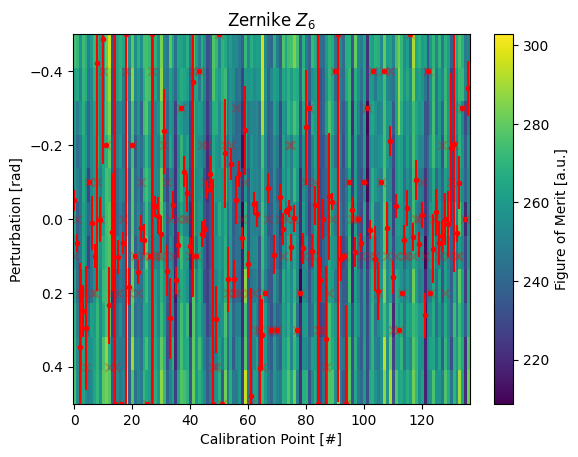

Z_7:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


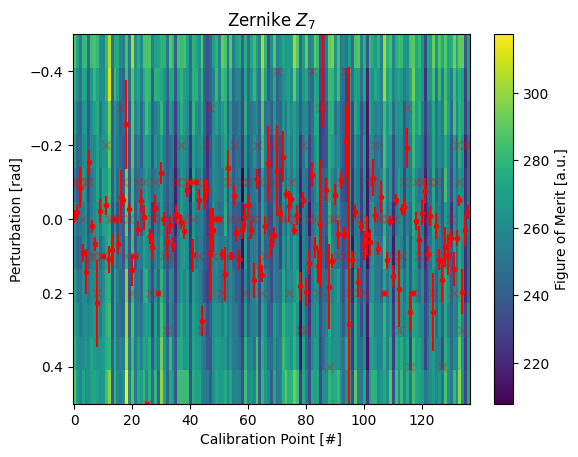

Z_8:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


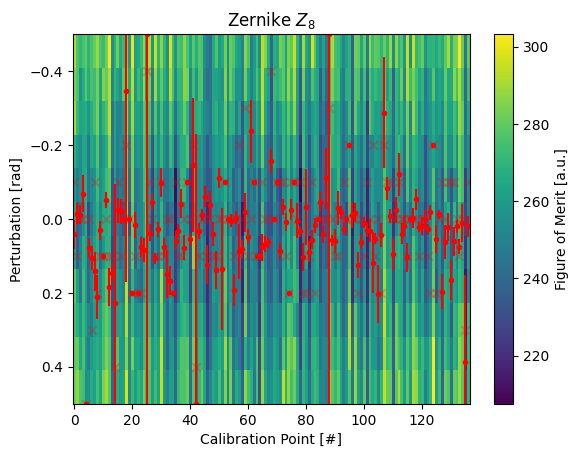

Z_9:   0%|          | 0/11 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)


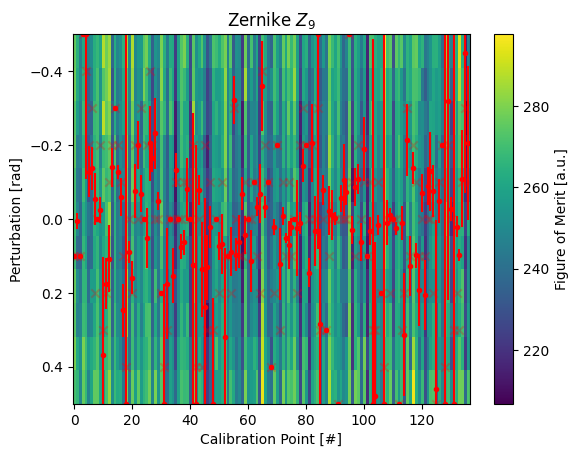

In [93]:
N = 4

for i in range(N):
    fs.wavefront_calibrate_zernike(None, zernike_indices=9, perturbation=0.5, plot=(i == N-1))

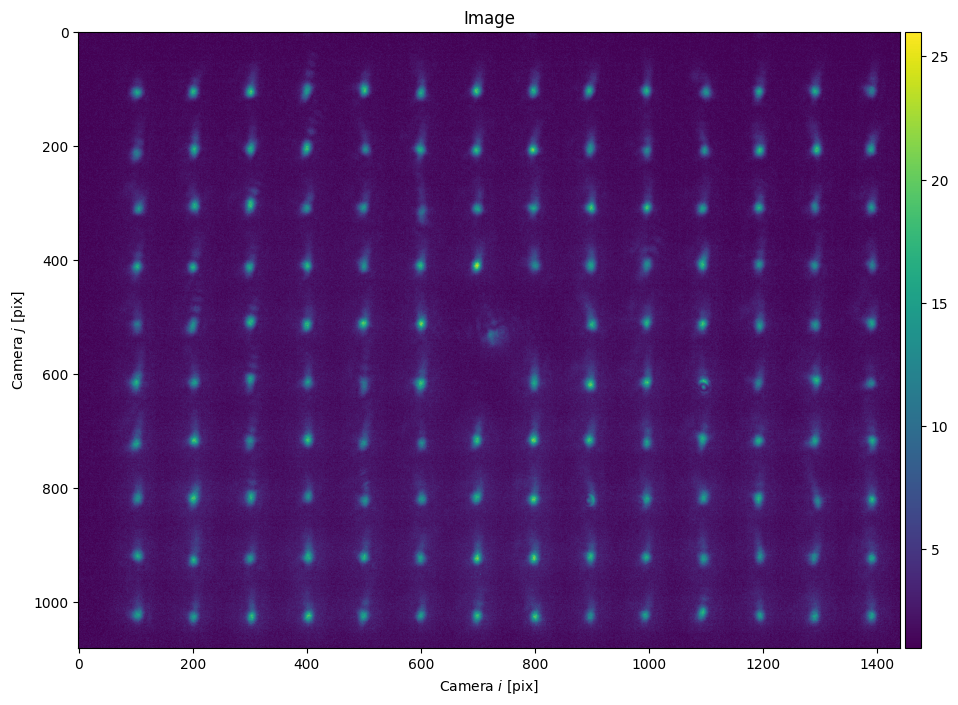

In [94]:
fs.wavefront_calibrate_zernike(None, zernike_indices=9, perturbation=0, plot=True)

In [26]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)])



zernike_calibrations = []
nz = 20
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10,1024+65] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations.append({i+1: float(v) for i, v in enumerate(zernike_arr)})
zernike_indices = [i+1 for i in range(nz)]

In [86]:
spot_locations = np.array([[640+(i)*rad ,512 + (j)*rad] for i in range(-n,n+10) for j in range(-n,n)])
zernike_calibrations = []
nz = 2
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10,1024+65] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations.append({i+1: float(v) for i, v in enumerate(zernike_arr)})
zernike_indices = [i+1 for i in range(nz)]

In [87]:
phase = get_cholo_phase(zernike_calibrations=zernike_calibrations,fs = fs)

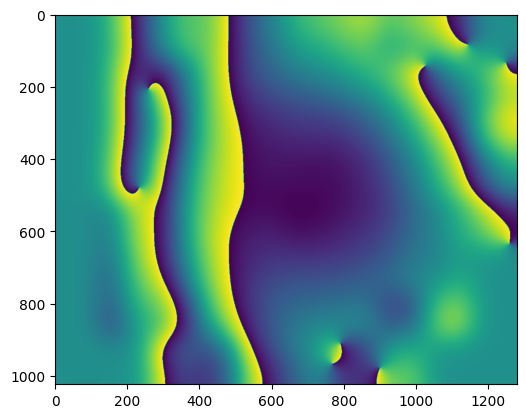

In [88]:
plt.imshow(fs.slm.source['phase'])

writing phase


array([[1, 2, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 2, 1, 1],
       [1, 1, 2, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 2, 2, 1],
       [2, 2, 2, ..., 2, 2, 1],
       [1, 1, 1, ..., 2, 2, 2]], dtype=uint16)

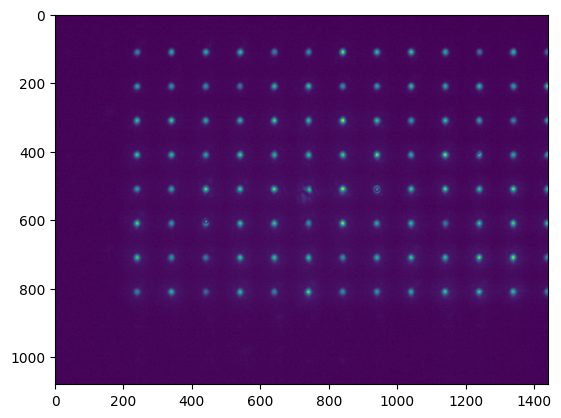

In [89]:
plot_cam(fs,phase = phase)

writing phase


array([[1, 2, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [2, 1, 1, ..., 2, 1, 1],
       ...,
       [1, 1, 1, ..., 1, 1, 2],
       [2, 1, 1, ..., 1, 1, 2],
       [1, 2, 1, ..., 3, 1, 3]], dtype=uint16)

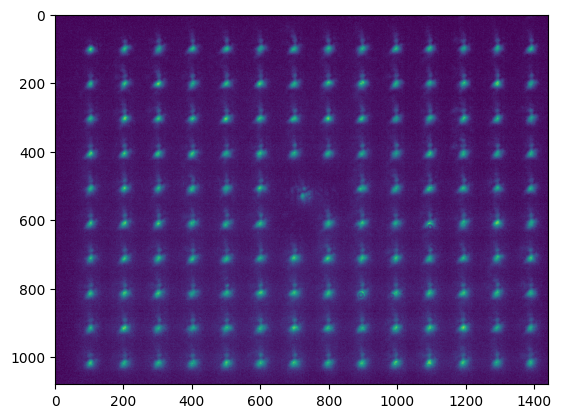

In [41]:
plot_cam(fs,phase = phase + phase_slm)

# Bottle Beam Aberration Correction

In [96]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)])



zernike_calibrations = []
nz = 20
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10,1024+65] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations.append({i+1: float(v) for i, v in enumerate(zernike_arr)})
zernike_indices = [i+1 for i in range(nz)]

In [97]:
phases = []
calibs = []
calibs_full = []
for i in range(5):
    for zi in range(1,nz+1):
        file_name = f"zernike_pert_test_iter_{i}_{zi}"
        phase = get_cholo_phase(zernike_calibrations=zernike_calibrations,fs = fs)
        zernike_calibrations_new = get_zernike_calibrations(phase,spot_locations,[zi],file_name)
        zernike_calibrations = [{k: d1[k] -  d2.get(k, 0) for k in d1} for d1, d2 in zip(zernike_calibrations, zernike_calibrations_new)]
        phases.append(phase)
        calibs.append(zernike_calibrations_new)
        calibs_full.append(zernike_calibrations)

writing phase


KeyboardInterrupt: 

In [98]:
phase = get_cholo_phase(zernike_calibrations=zernike_calibrations,fs = fs)

In [ ]:
def bottle_beam_phase(fs):
    ro = 240
    return np.array([[np.pi if ((i-fs.slm.get_source_center()[1])**2 + (j-fs.slm.get_source_center()[0])**2) <= ro**2 else 0 for j in range(1280)] for i in range(1024)])

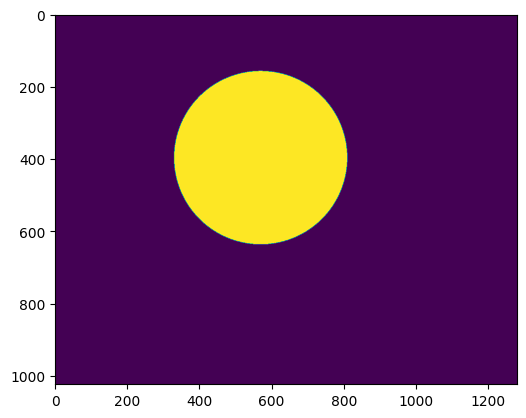

In [102]:
plt.imshow(bottle_beam_phase(fs))

writing phase


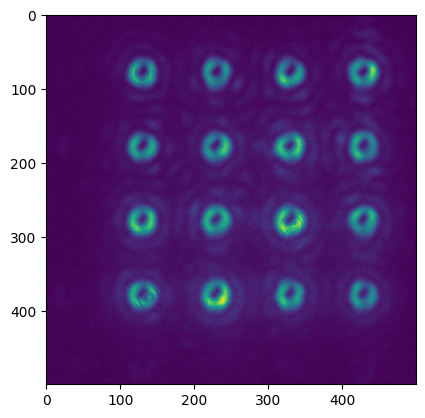

In [107]:
image = plot_cam(fs=fs,phase= phase+bottle_beam_phase(fs))
plt.imshow(image[100:600,900:1400])

In [108]:
spot_locations[0]

array([1030,  180])

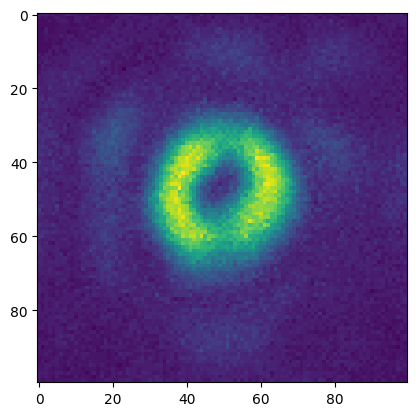

In [116]:
i = 6
plt.imshow(image[spot_locations[i][1]-50:spot_locations[i][1]+50,spot_locations[i][0]-50:spot_locations[i][0]+50])

In [118]:
get_bottle_metrics(image[spot_locations[i][1]-50:spot_locations[i][1]+50,spot_locations[i][0]-50:spot_locations[i][0]+50])

{'A': 0.00024084546729346212,
 'w_px': 9.048092128222388,
 'offset': 0.07758332891182258,
 'centerx': 49.42486528845353,
 'centery': 47.78043146333597,
 'fit_method': 'scipy',
 'rmse': 0.06344053677631116,
 'r_squared': 0.9150800198495451,
 'r_peak_px': 12.795934601333343,
 'fwhm_px': 10.551131962794623,
 'I_center': 0.22503726184368134,
 'I_ring': 0.7838906645774841,
 'I_bg': 0.15916506946086884,
 'contrast': 0.7129226399476275,
 'center_suppression': 0.2870773587766844,
 'snr_rb': 7.776442325672419,
 'uniformity_std_pct': 11.776553525493336,
 'escape_intensity': 0.46398140490055084,
 'escape_theta_deg': 272.0,
 'escape_radius_px': 14.520368619936043,
 'outer_ring_ratio': 0.21694696067201252,
 'encircled_energy_in_ring': 0.44130331752469254,
 'strehl_prime': 0.001482929386530285,
 'window_px': 31,
 'd2I_dr2_at0': 0.0,
 'd4I_dr4_at0': 0.005780291215043091}

In [ ]:
def bb(x, y, A, w, xc, yc, B):
    r = np.sqrt((x - xc)**2 + (y - yc)**2)
    return B + A * (r**4) * np.exp(-(r**2)/(w**2))

In [ ]:
H, W = patch.shape
cy0 = (H - 1)/2.0
cx0 = (W - 1)/2.0

In [119]:
popt, _ = curve_fit(
                lambda XY, A, w, xc, yc, B: bb(XY[0], XY[1], A, w, xc, yc, B).ravel(),
                xdata, patch.ravel(), p0=p0, bounds=bounds, maxfev=30000
            )

NameError: name 'xdata' is not defined

In [314]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize, ndimage

def bb(x, y, A, w, xc, yc, B):
    r = np.sqrt((x - xc)**2 + (y - yc)**2)
    return B + A * (r**4) * np.exp(-(r**2)/(w**2))

def _initial_guess(roi, xg, yg, approx_center=None):
    # Background ~ median; amplitude ~ (max - median)
    B0 = float(np.median(roi))
    A0 = float(np.max(roi) - B0)
    A0 = max(A0, 1e-6)

    # Center: use provided approx if any; else intensity COM (fine for a ring)
    if approx_center is not None:
        xc0, yc0 = approx_center
    else:
        # Center-of-mass in image coordinates
        cy, cx = ndimage.center_of_mass(roi - B0 + 1e-6)
        yc0 = float(yg.min() + cy)
        xc0 = float(xg.min() + cx)

    # Width: rough radial scale from second moment
    r2 = (xg - xc0)**2 + (yg - yc0)**2
    w0 = np.sqrt(max(np.average(r2, weights=np.clip(roi - B0, 0, None)), 1.0))

    return (A0, w0, xc0, yc0, B0)

def fit_bottle_beam(image, approx_center=None, patch_size=None):
    """
    image: 2D numpy array
    approx_center: (xc, yc) in pixel coords (x=cols, y=rows). If given with patch_size,
                   we fit a crop around it for speed/robustness.
    patch_size: half-size of ROI box (int). If None, fit the whole image.
    """
    H, W = image.shape

    # Choose ROI
    if approx_center is not None and patch_size is not None:
        xc_a, yc_a = approx_center
        xc_a = int(round(xc_a))
        yc_a = int(round(yc_a))
        x0 = max(0, xc_a - patch_size)
        x1 = min(W, xc_a + patch_size)
        y0 = max(0, yc_a - patch_size)
        y1 = min(H, yc_a + patch_size)
        roi = image[y0:y1, x0:x1]
        yy, xx = np.mgrid[y0:y1, x0:x1]  # absolute coords so fit returns global xc,yc
    else:
        roi = image
        yy, xx = np.mgrid[0:H, 0:W]

    # Initial guess
    A0, w0, xc0, yc0, B0 = _initial_guess(roi, xx, yy, approx_center)

    # Flatten for curve_fit
    x_flat = xx.ravel()
    y_flat = yy.ravel()
    z_flat = roi.ravel().astype(np.float64)

    # Bounds: A >= 0, w > 0, xc,yc within image, B free (>= min-abs-margin)
    eps = 1e-6
    lower = [0.0, eps, 0.0, 0.0, -np.inf]
    upper = [np.inf, np.inf, W-1.0, H-1.0, np.inf]

    p0 = [A0, max(w0, 2.0), np.clip(xc0, 0, W-1), np.clip(yc0, 0, H-1), B0]

    popt, pcov = optimize.curve_fit(
        lambda XY, A, w, xc, yc, B: bb(XY[0], XY[1], A, w, xc, yc, B),
        (x_flat, y_flat), z_flat, p0=p0, bounds=(lower, upper), maxfev=20000
    )
    perr = np.sqrt(np.diag(pcov)) if pcov.size else np.full_like(popt, np.nan, dtype=float)

    # Predictions on ROI for metrics
    z_pred = bb(x_flat, y_flat, *popt)
    resid = z_flat - z_pred
    rmse = float(np.sqrt(np.mean(resid**2)))
    ss_res = float(np.sum(resid**2))
    ss_tot = float(np.sum((z_flat - np.mean(z_flat))**2))
    r2 = float(1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan

    # Line scans through fitted center on FULL image
    xc, yc = popt[2], popt[3]
    x_idx = int(np.clip(round(xc), 0, W-1))
    y_idx = int(np.clip(round(yc), 0, H-1))

    x_axis = np.arange(W)
    y_axis = np.arange(H)

    scan_h_data = image[y_idx, :]                   # horizontal (y fixed = yc)
    scan_v_data = image[:, x_idx]                   # vertical (x fixed = xc)

    scan_h_model = bb(x_axis, np.full_like(x_axis, yc, dtype=float), *popt)
    scan_v_model = bb(np.full_like(y_axis, xc, dtype=float), y_axis, *popt)

    out = {
        "params": {"A": popt[0], "w": popt[1], "xc": popt[2], "yc": popt[3], "B": popt[4]},
        "param_err": {"A": perr[0], "w": perr[1], "xc": perr[2], "yc": perr[3], "B": perr[4]},
        "rmse": rmse,
        "r2": r2,
        "center_indices": {"x_idx": x_idx, "y_idx": y_idx},
        "line_scans": {
            "x": x_axis, "y": y_axis,
            "horizontal_data": scan_h_data, "horizontal_model": scan_h_model,
            "vertical_data": scan_v_data,   "vertical_model":   scan_v_model,
        },
        "roi_bbox": ((yy.min(), yy.max()), (xx.min(), xx.max()))  # (y0,y1), (x0,x1)
    }
    return out

# ---------- Example plotting helpers ----------

def plot_fit_overview(image, fitres):
    A, w, xc, yc, B = (fitres["params"][k] for k in ("A","w","xc","yc","B"))
    H, W = image.shape
    yy, xx = np.mgrid[0:H, 0:W]
    model_full = bb(xx, yy, A, w, xc, yc, B)

    fig, axs = plt.subplots(1, 3, figsize=(14,4))
    im0 = axs[0].imshow(image, origin="upper")
    axs[0].set_title("Image")
    axs[0].plot([xc],[yc],'r+', ms=12)
    plt.colorbar(im0, ax=axs[0], fraction=0.046)

    im1 = axs[1].imshow(model_full, origin="upper")
    axs[1].set_title("Fitted model")
    axs[1].plot([xc],[yc],'r+', ms=12)
    plt.colorbar(im1, ax=axs[1], fraction=0.046)

    im2 = axs[2].imshow(image - model_full, origin="upper")
    axs[2].set_title(f"Residual (RMSE={fitres['rmse']:.3g}, R²={fitres['r2']:.3f})")
    plt.colorbar(im2, ax=axs[2], fraction=0.046)

    for ax in axs: ax.axis('off')
    plt.tight_layout()
    plt.show()

def plot_line_scans(fitres):
    L = fitres["line_scans"]
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    axes[0].plot(L["x"], L["horizontal_data"], '.', label="data")
    axes[0].plot(L["x"], L["horizontal_model"], '-', label="model")
    axes[0].set_title("Horizontal scan (y = yc)")
    axes[0].set_xlabel("x (px)"); axes[0].set_ylabel("Intensity"); axes[0].legend()

    axes[1].plot(L["y"], L["vertical_data"], '.', label="data")
    axes[1].plot(L["y"], L["vertical_model"], '-', label="model")
    axes[1].set_title("Vertical scan (x = xc)")
    axes[1].set_xlabel("y (px)"); axes[1].set_ylabel("Intensity"); axes[1].legend()

    plt.tight_layout(); plt.show()


writing phase
Params: {'A': 0.0069537267383200435, 'w': 9.307009789479618, 'xc': 49.68175248489899, 'yc': 49.418615563993804, 'B': 4.1648911967658595}
Uncertainties: {'A': 8.957107875450562e-05, 'w': 0.02226901384096439, 'xc': 0.0489423418604387, 'yc': 0.04894234186241366, 'B': 0.0431321242491513}
RMSE: 3.91868195051013 R^2: 0.7556745698654461


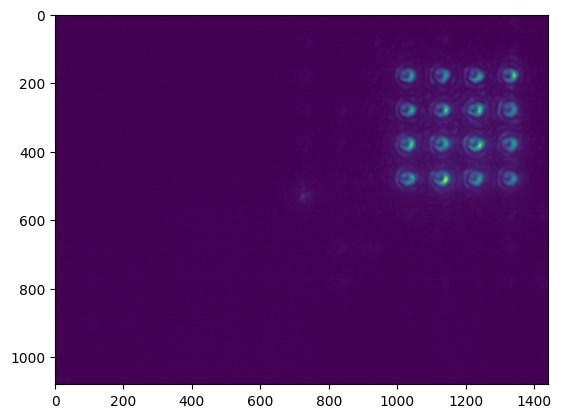

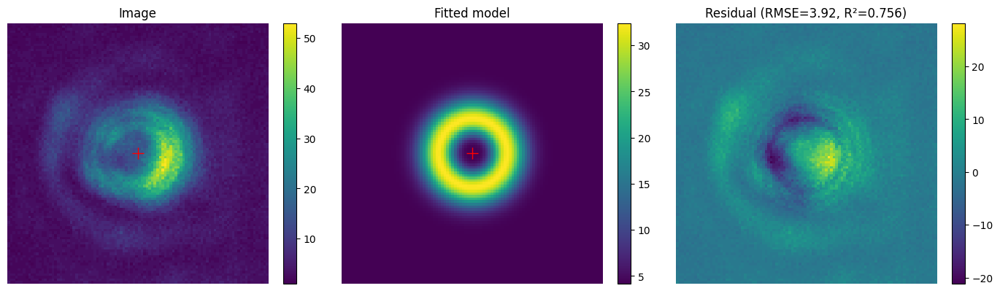

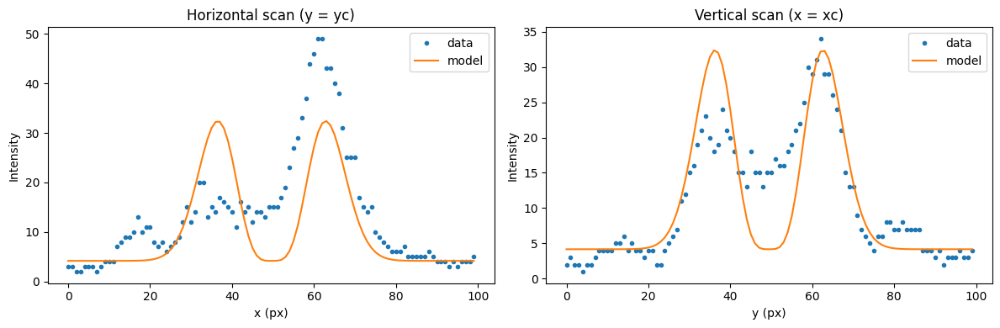

Params: {'A': 0.006602341922740623, 'w': 9.306022041105022, 'xc': 49.780659657459985, 'yc': 49.171886984215824, 'B': 4.833198313276845}
Uncertainties: {'A': 9.87405524848395e-05, 'w': 0.02585236946826939, 'xc': 0.05681800868344843, 'yc': 0.056818008696784536, 'B': 0.047521310298108965}
RMSE: 4.317549200114531 R^2: 0.6964633209011875


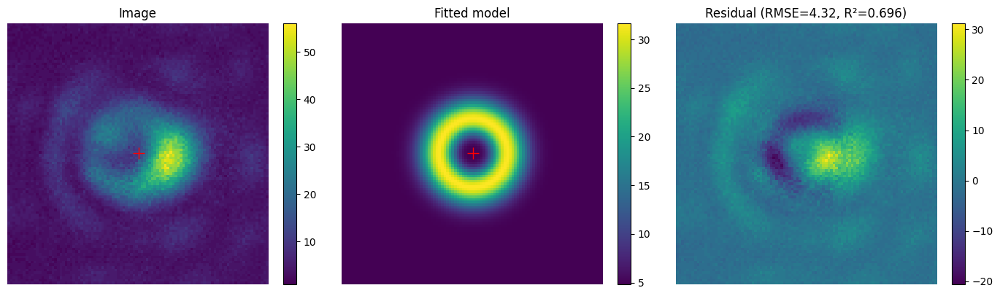

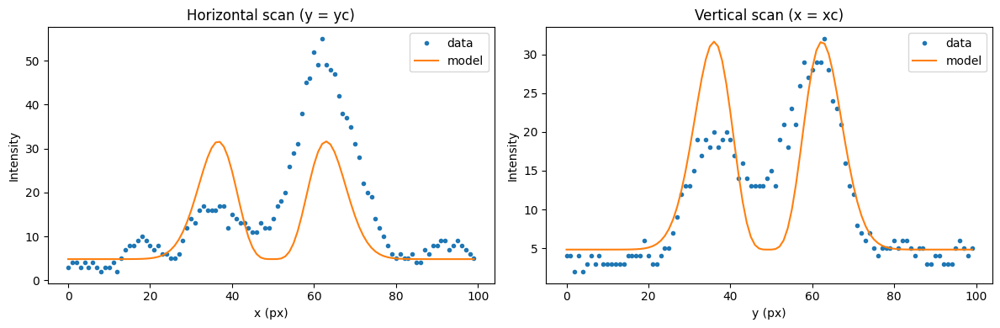

Params: {'A': 0.008637000184511977, 'w': 9.254772094878462, 'xc': 49.86471495967907, 'yc': 49.31740100799156, 'B': 6.31583513432044}
Uncertainties: {'A': 0.00012544983647498148, 'w': 0.024963978599103324, 'xc': 0.05487787547916592, 'yc': 0.05487787548316087, 'B': 0.05866362813811549}
RMSE: 5.336052573745701 R^2: 0.7090586598915363


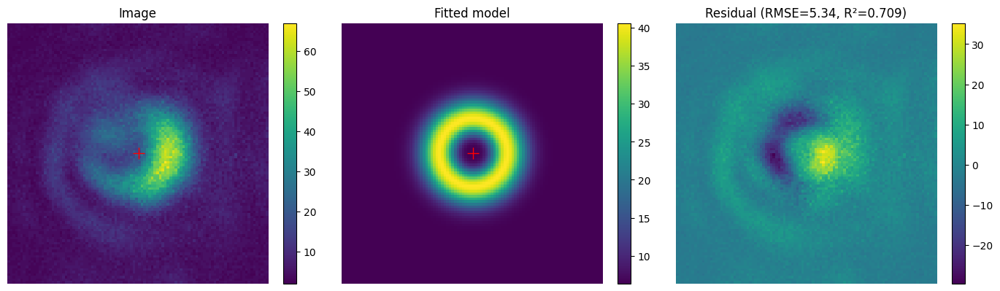

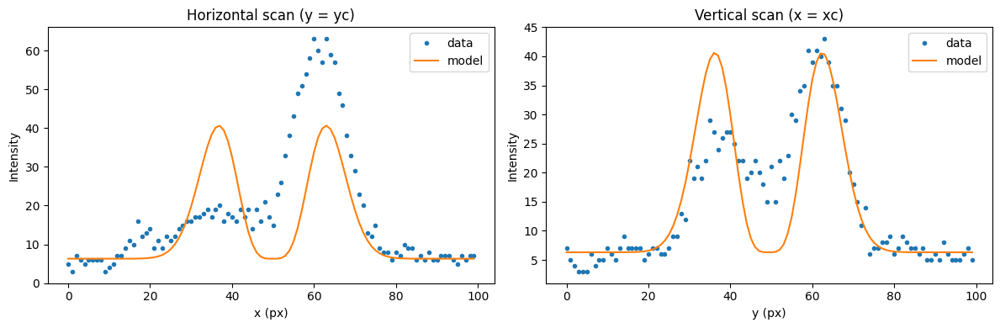

Params: {'A': 0.0067384179850758915, 'w': 9.42887479547663, 'xc': 50.57458828512152, 'yc': 49.732030810800396, 'B': 6.2123310942043455}
Uncertainties: {'A': 9.199198432316442e-05, 'w': 0.0239237395929012, 'xc': 0.05255043313026178, 'yc': 0.052550433131558036, 'B': 0.047406946612791746}
RMSE: 4.295074382766043 R^2: 0.7327032984092139


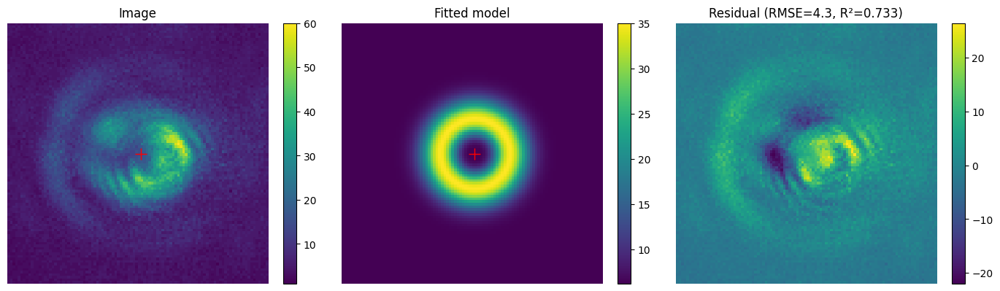

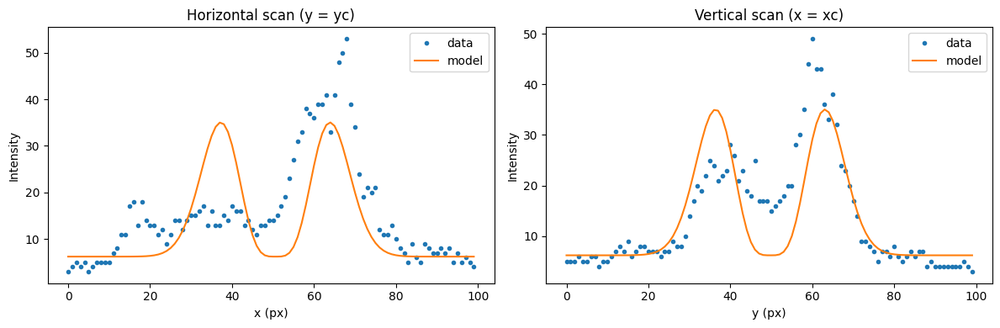

Params: {'A': 0.005643242876811323, 'w': 9.419776382173335, 'xc': 50.06427386350155, 'yc': 49.19480938457882, 'B': 4.577250774169674}
Uncertainties: {'A': 8.532216748309306e-05, 'w': 0.02646872604594326, 'xc': 0.05814309174270024, 'yc': 0.05814309175383379, 'B': 0.04374882029621752}
RMSE: 3.9644797458001375 R^2: 0.690940699667492


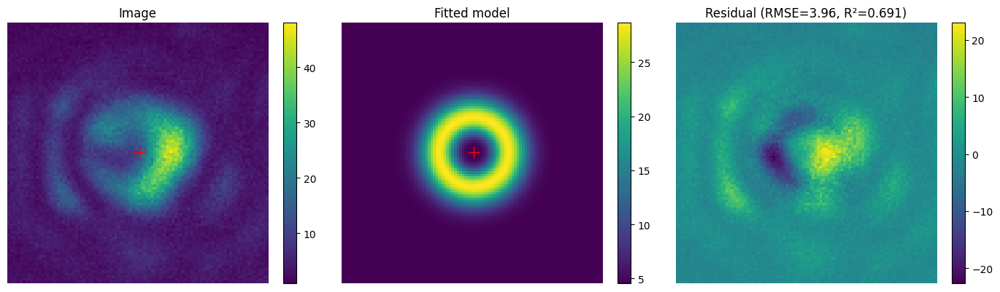

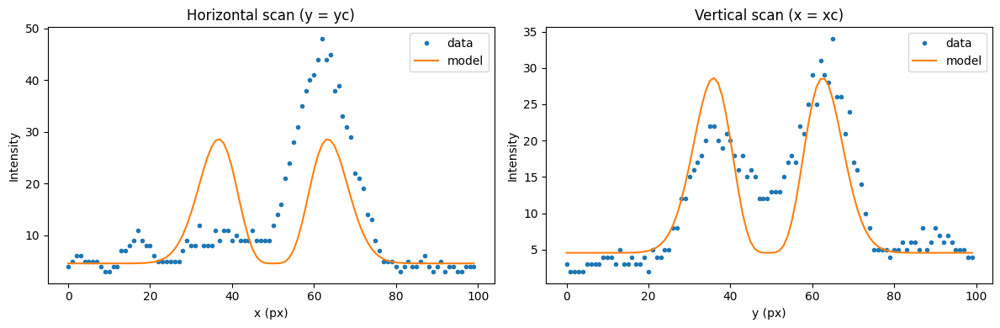

Params: {'A': 0.10811158085087955, 'w': 5.237786943336605, 'xc': 61.187752085937205, 'yc': 49.754543615841925, 'B': 7.3381831256933525}
Uncertainties: {'A': 0.0024659610599044425, 'w': 0.02191814670686035, 'xc': 0.048773757663876975, 'yc': 0.048773757663381864, 'B': 0.06267238439684769}
RMSE: 6.090412611643686 R^2: 0.5239882749968128


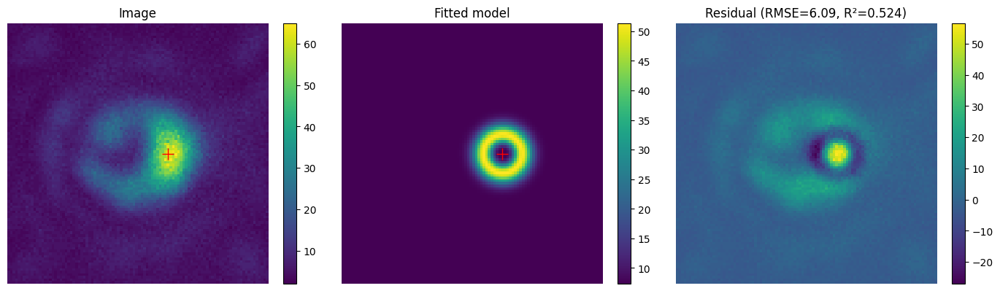

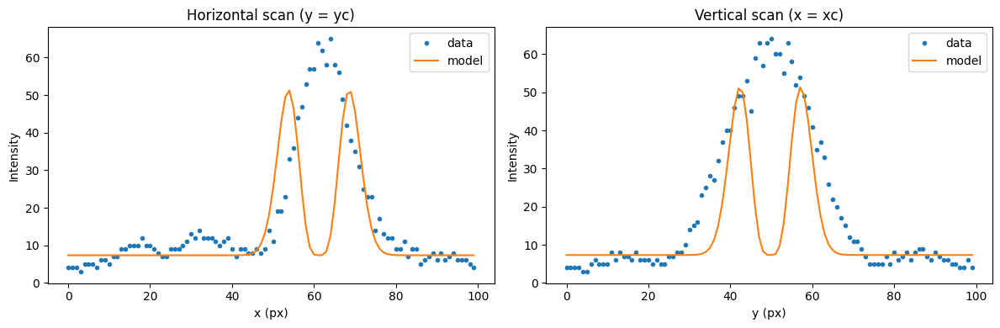

Params: {'A': 0.006559615368963293, 'w': 9.510043871038683, 'xc': 49.3710943557813, 'yc': 48.89844997978324, 'B': 7.062628490082509}
Uncertainties: {'A': 9.100239730527037e-05, 'w': 0.02452984088721257, 'xc': 0.05386186288781614, 'yc': 0.0538618628757147, 'B': 0.049042983325647695}
RMSE: 4.434930246918038 R^2: 0.7257559146090766


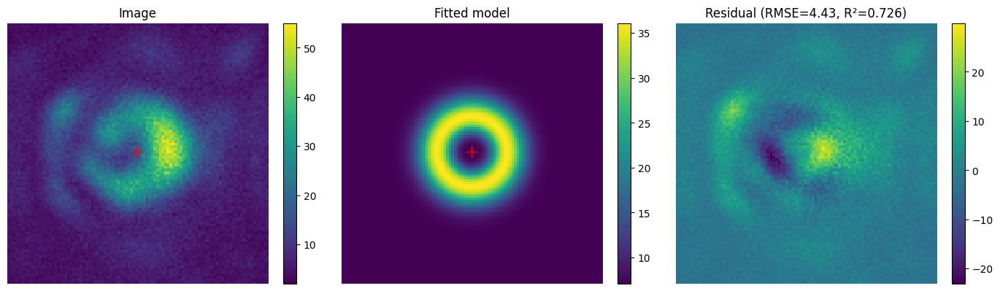

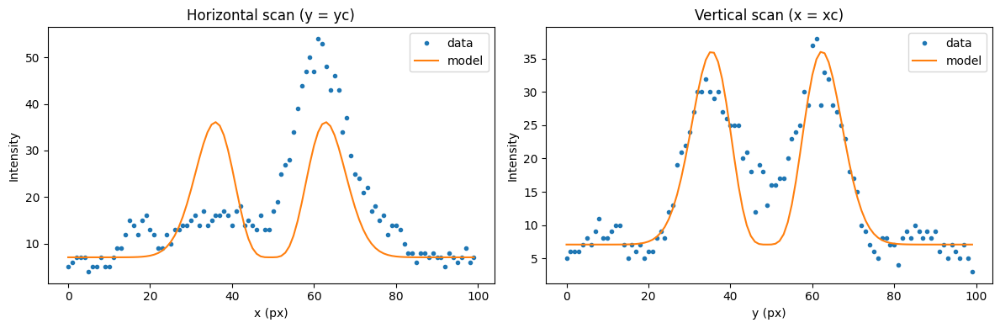

Params: {'A': 0.008493374575937991, 'w': 9.523502596458293, 'xc': 49.48723807480874, 'yc': 49.64705779226827, 'B': 7.344658173102916}
Uncertainties: {'A': 0.00013046348569468398, 'w': 0.027200070139928326, 'xc': 0.059721374619202884, 'yc': 0.05972137462009865, 'B': 0.07083056232845288}
RMSE: 6.403152696885483 R^2: 0.6833008590129936


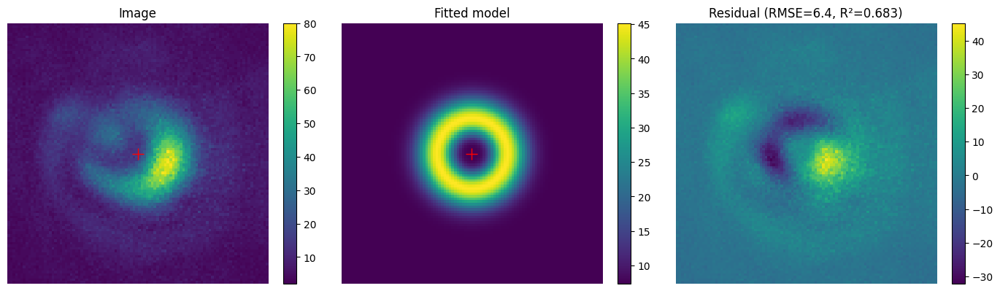

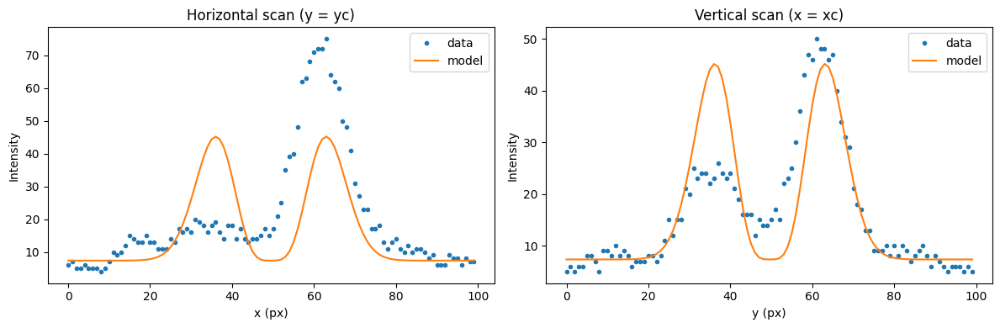

Params: {'A': 0.00752040996484584, 'w': 9.091886822243355, 'xc': 49.11707353861608, 'yc': 49.72648381158213, 'B': 4.682618821593944}
Uncertainties: {'A': 0.00011705670739235332, 'w': 0.02626304016849475, 'xc': 0.057774101428085596, 'yc': 0.05777410143476652, 'B': 0.04990753353027202}
RMSE: 4.556042500380389 R^2: 0.6809782888442509


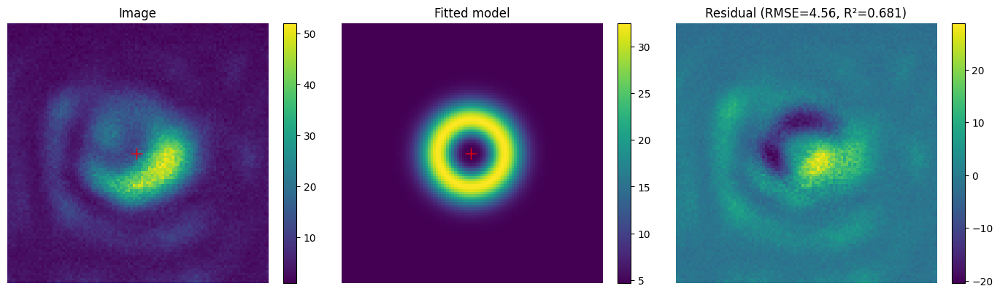

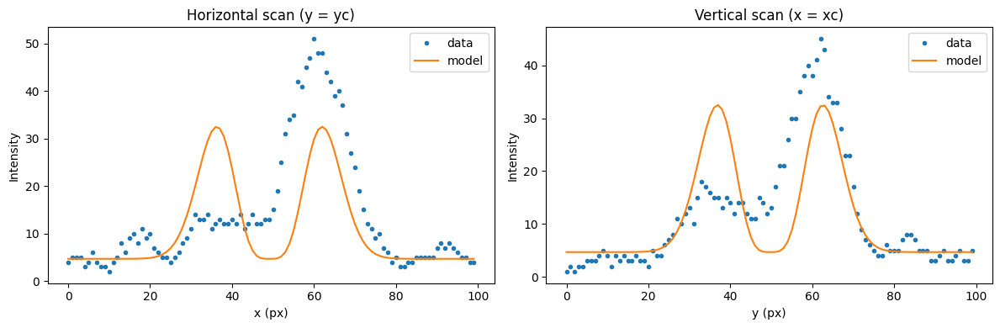

Params: {'A': 0.008481171299972879, 'w': 9.224697021073355, 'xc': 48.97996685439324, 'yc': 49.31266027811413, 'B': 6.710214193227745}
Uncertainties: {'A': 0.00012968698403764087, 'w': 0.026192478583073706, 'xc': 0.05758601916510299, 'yc': 0.05758601916753936, 'B': 0.05962579601868203}
RMSE: 5.4272309581925136 R^2: 0.6876282116913366


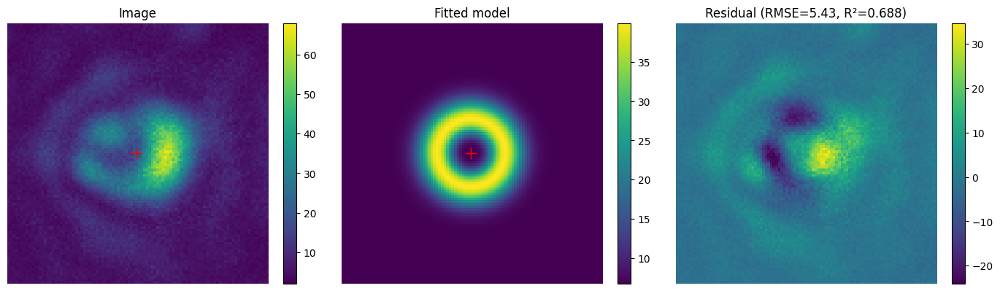

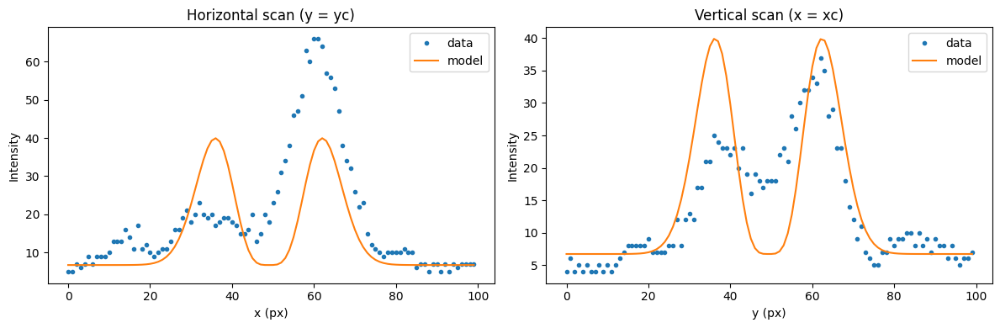

Params: {'A': 0.007760151816355376, 'w': 9.632676022065827, 'xc': 48.86213191033933, 'yc': 49.57766962019973, 'B': 7.4793816225402905}
Uncertainties: {'A': 0.00011028035976656304, 'w': 0.025465958344550097, 'xc': 0.055885520647805595, 'yc': 0.05588552065942611, 'B': 0.06354783211175458}
RMSE: 5.729995772898777 R^2: 0.7151253389272161


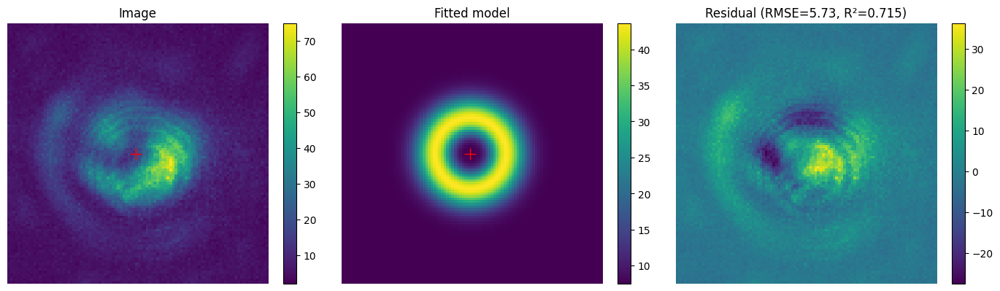

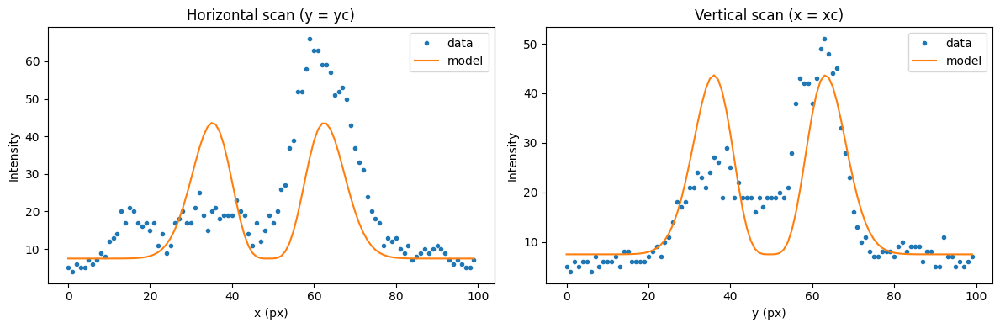

Params: {'A': 0.007016269370621649, 'w': 9.236014360849572, 'xc': 48.6900513194207, 'yc': 49.59302682633548, 'B': 6.853010913204933}
Uncertainties: {'A': 0.00010168086665071627, 'w': 0.024855523660732595, 'xc': 0.054643936172833564, 'yc': 0.05464393617267754, 'B': 0.047048908716955704}
RMSE: 4.281378215816085 R^2: 0.7101229331170303


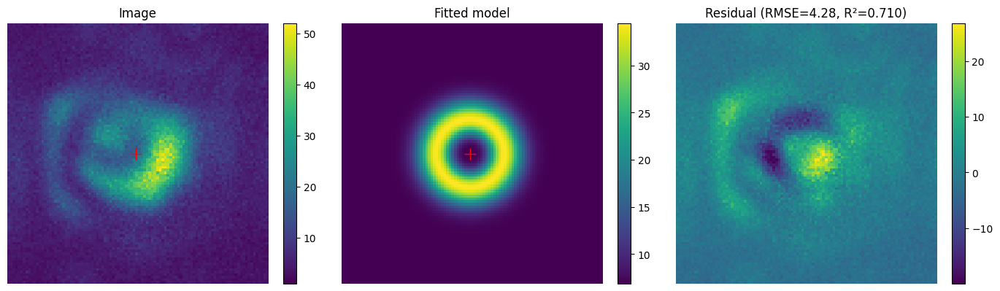

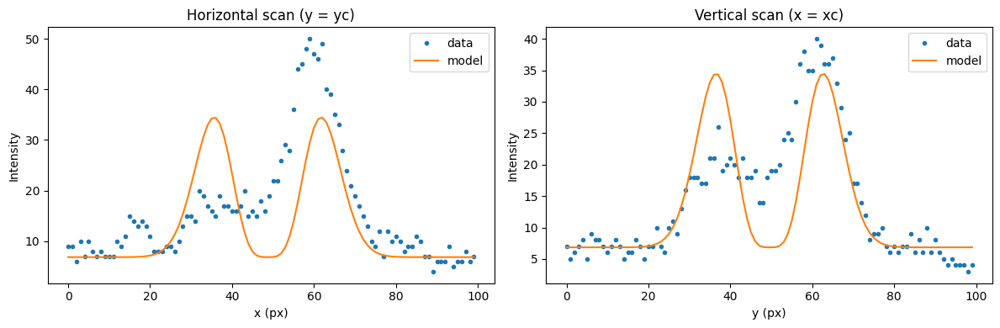

Params: {'A': 0.007469781310564716, 'w': 9.396858959473859, 'xc': 48.59036210896681, 'yc': 49.39946122359192, 'B': 4.638549949938189}
Uncertainties: {'A': 0.00011783189449548376, 'w': 0.027545595759790226, 'xc': 0.060514865502073946, 'yc': 0.060514865502168745, 'B': 0.05965527699895692}
RMSE: 5.408760617130408 R^2: 0.6727244869495997


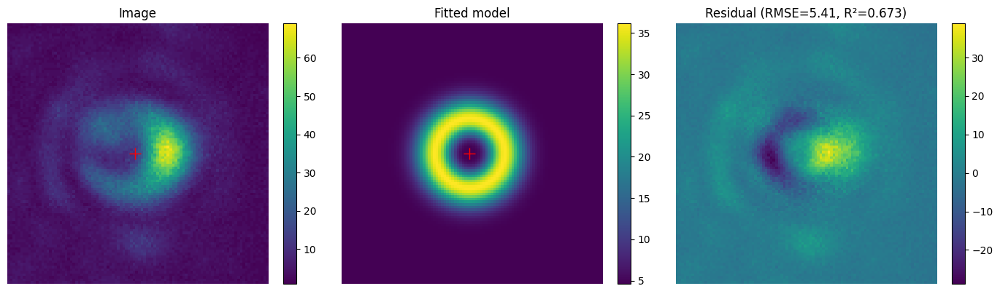

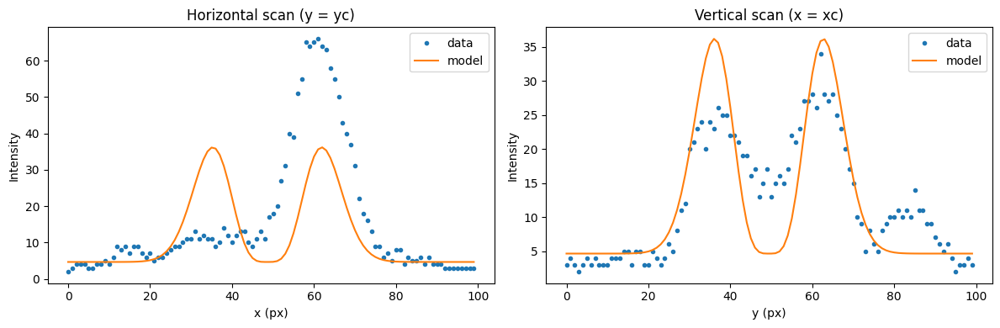

Params: {'A': 0.005537415238864103, 'w': 9.536476205687899, 'xc': 48.47118241221915, 'yc': 48.72171897450714, 'B': 5.93263483060902}
Uncertainties: {'A': 7.883151073128152e-05, 'w': 0.025244761328831175, 'xc': 0.055424920455141906, 'yc': 0.05542492046058491, 'B': 0.043104217548592096}
RMSE: 3.895478891265501 R^2: 0.7151517881916936


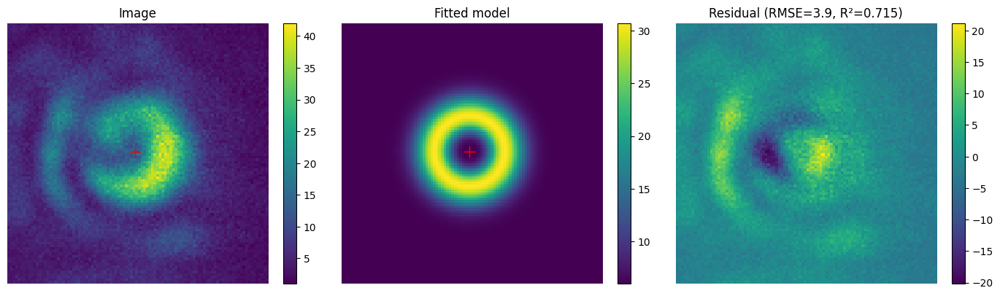

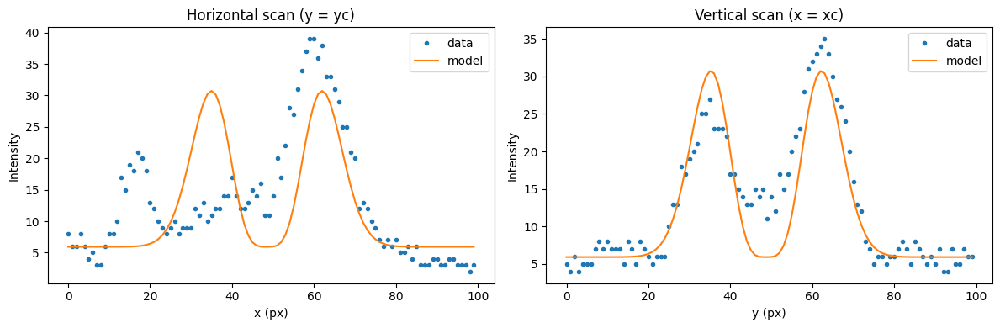

Params: {'A': 0.006286721323980599, 'w': 9.465583542771325, 'xc': 48.405523556976895, 'yc': 49.17663437001076, 'B': 6.120387467585693}
Uncertainties: {'A': 8.798935020083555e-05, 'w': 0.02462650449584782, 'xc': 0.05408510594002604, 'yc': 0.05408510594860848, 'B': 0.04627311920137412}
RMSE: 4.188788506210732 R^2: 0.7225639400714532


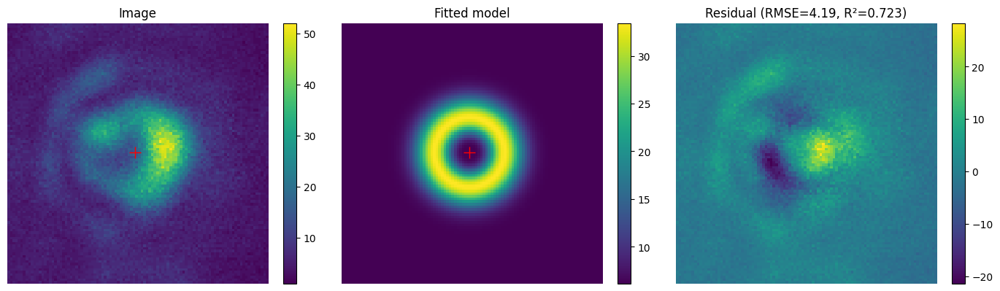

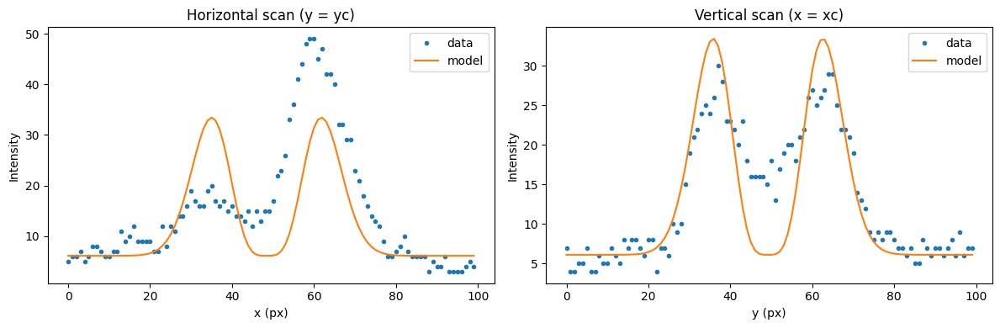

Params: {'A': 0.005871960514087972, 'w': 9.29730967199439, 'xc': 47.92009903709859, 'yc': 49.611506423890006, 'B': 5.461694747875808}
Uncertainties: {'A': 8.325038174218966e-05, 'w': 0.024484003935075518, 'xc': 0.05381270145036865, 'yc': 0.053812701459497014, 'B': 0.03987121956462919}
RMSE: 3.6232147414157736 R^2: 0.718623631294304


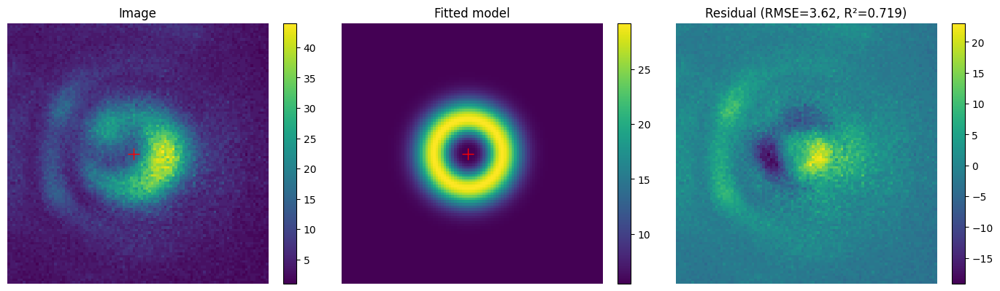

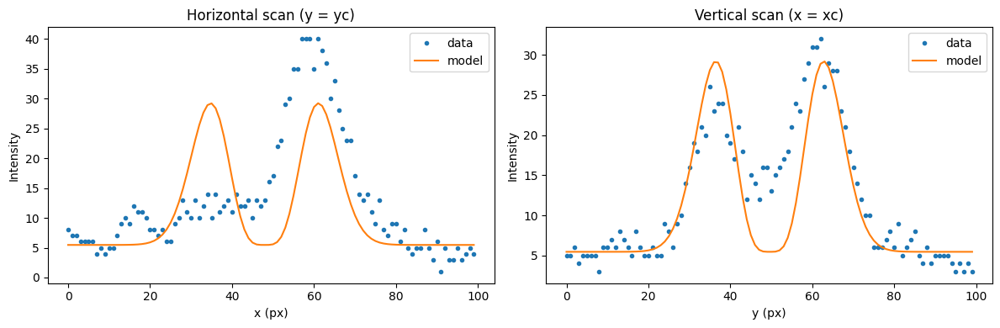

writing phase
Params: {'A': 0.006938097336518435, 'w': 9.381299144543013, 'xc': 49.403095251030656, 'yc': 49.47173266239714, 'B': 4.062746523850611}
Uncertainties: {'A': 8.233369629247971e-05, 'w': 0.020686374226546535, 'xc': 0.045449028089035316, 'yc': 0.04544902808757814, 'B': 0.04132472296050812}
RMSE: 3.7481235199794556 R^2: 0.7842129675603202


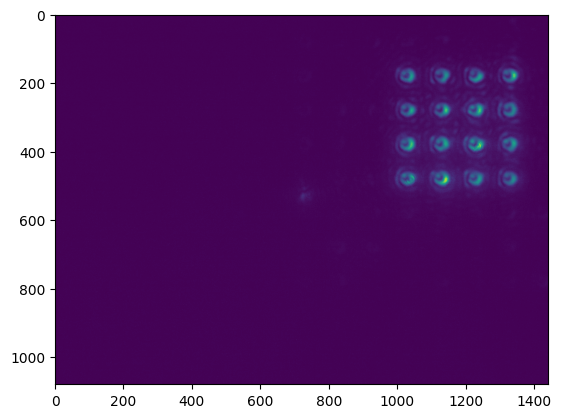

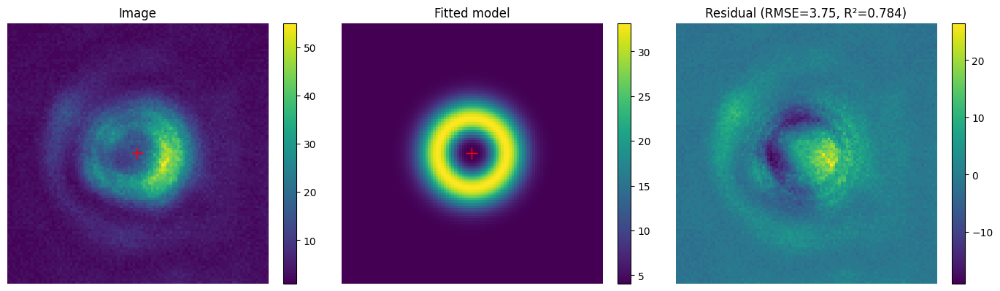

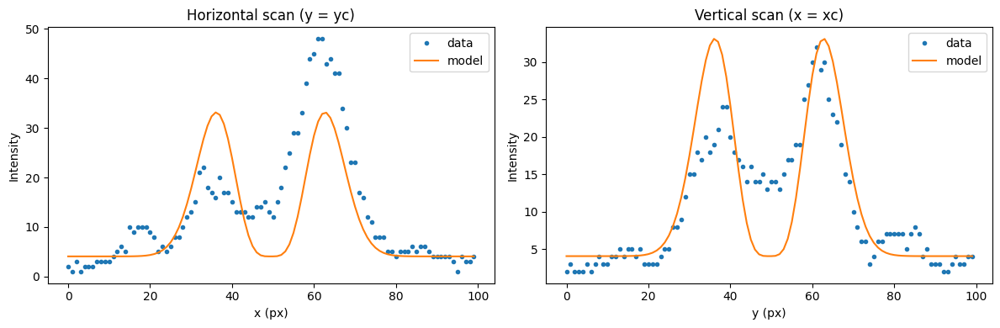

Params: {'A': 0.006745730010759737, 'w': 9.332414037784858, 'xc': 49.513854449965514, 'yc': 49.256164941856255, 'B': 4.75790469168937}
Uncertainties: {'A': 9.269664725870788e-05, 'w': 0.02382421277234309, 'xc': 0.05235443299907008, 'yc': 0.05235443299623143, 'B': 0.0452758580813794}
RMSE: 4.111074774113914 R^2: 0.7308315399049649


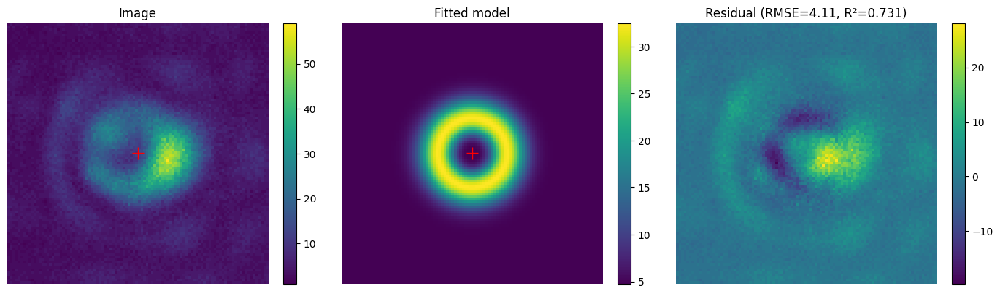

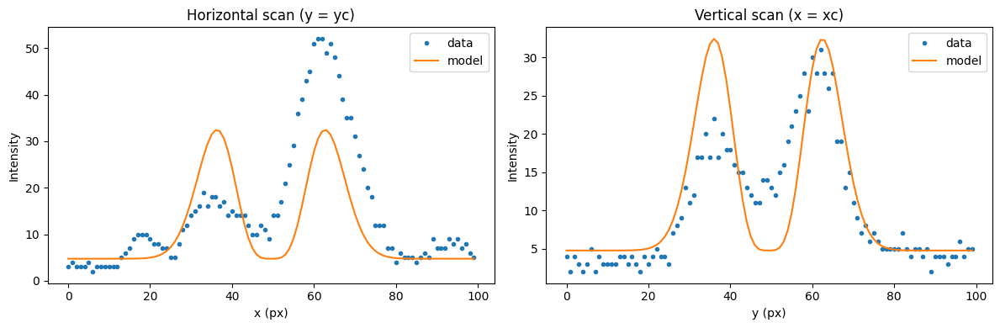

Params: {'A': 0.008581037584125886, 'w': 9.339962075037668, 'xc': 49.499821502720565, 'yc': 49.30070936441887, 'B': 6.197363872203326}
Uncertainties: {'A': 0.00011492502800415759, 'w': 0.0232393499789103, 'xc': 0.05106746710576508, 'yc': 0.05106746711702996, 'B': 0.05636992596569182}
RMSE: 5.117543469953279 R^2: 0.7407679670872276


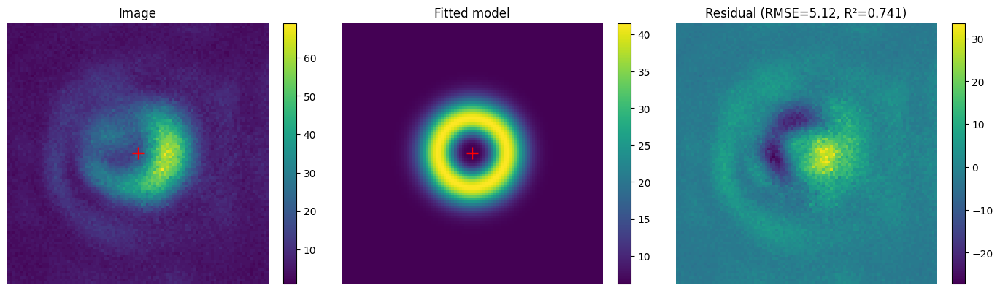

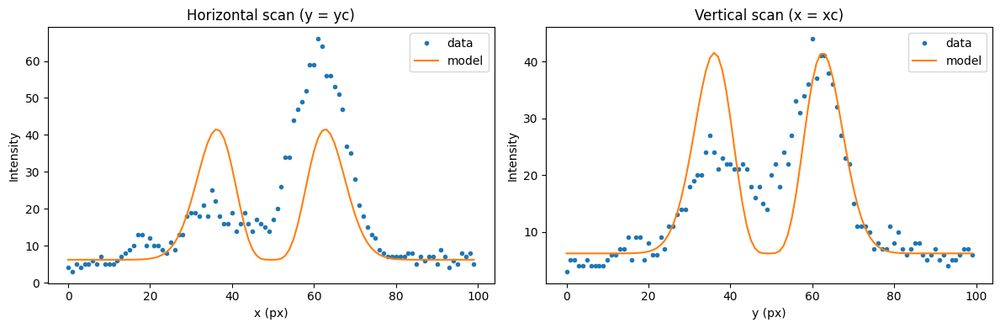

Params: {'A': 0.006858951235002277, 'w': 9.461713768307048, 'xc': 50.235087854962195, 'yc': 49.72380509811666, 'B': 6.130379435624614}
Uncertainties: {'A': 8.803518599682404e-05, 'w': 0.022574087716348036, 'xc': 0.04957842976069021, 'yc': 0.04957842976188684, 'B': 0.046198514825765855}
RMSE: 4.182410665880588 R^2: 0.7559400096068454


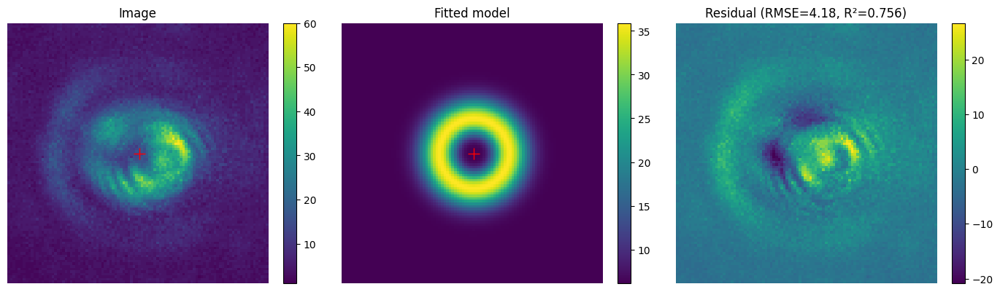

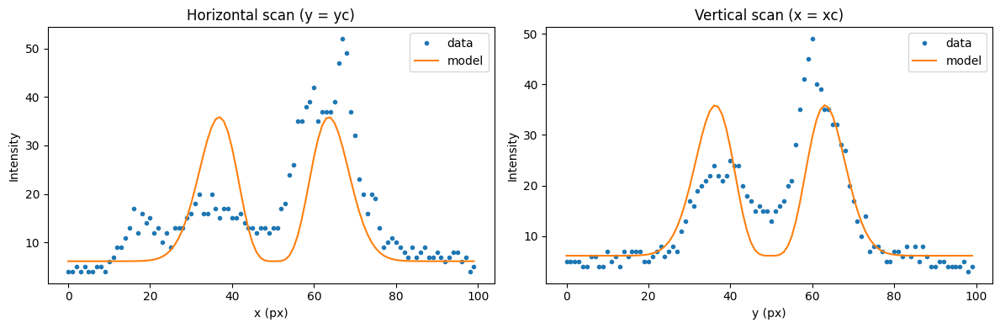

Params: {'A': 0.005695480715097331, 'w': 9.46726429085255, 'xc': 49.76927949811791, 'yc': 49.249229570376755, 'B': 4.5090391336258415}
Uncertainties: {'A': 7.979335490959154e-05, 'w': 0.024655490375415007, 'xc': 0.05414835054599626, 'yc': 0.054148350554026566, 'B': 0.04200179768102866}
RMSE: 3.8019866667507642 R^2: 0.7221538055202097


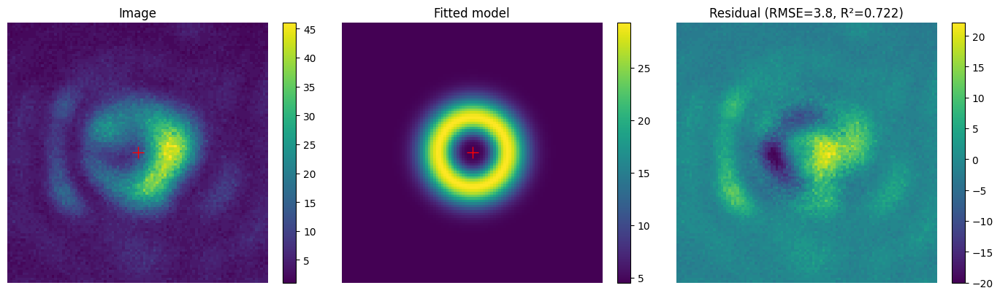

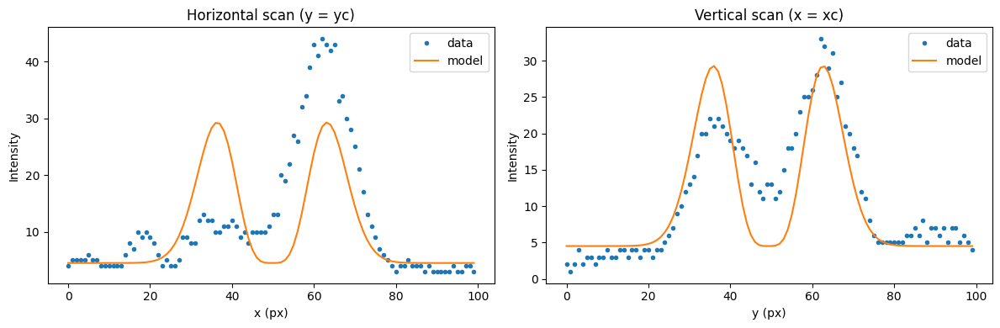

Params: {'A': 0.1115371537422713, 'w': 5.200996592651405, 'xc': 61.26355899744042, 'yc': 49.935387021862574, 'B': 7.405264641854438}
Uncertainties: {'A': 0.002628070577228001, 'w': 0.022480970789487676, 'xc': 0.05002976079224455, 'yc': 0.050029760794040895, 'B': 0.06445303004402769}
RMSE: 6.26601208985137 R^2: 0.5079373824865336


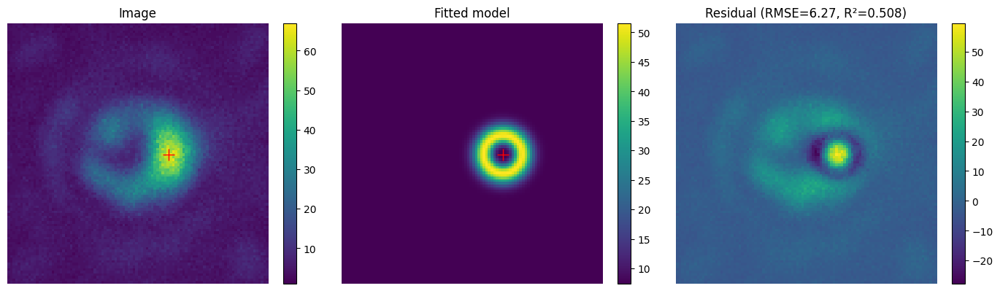

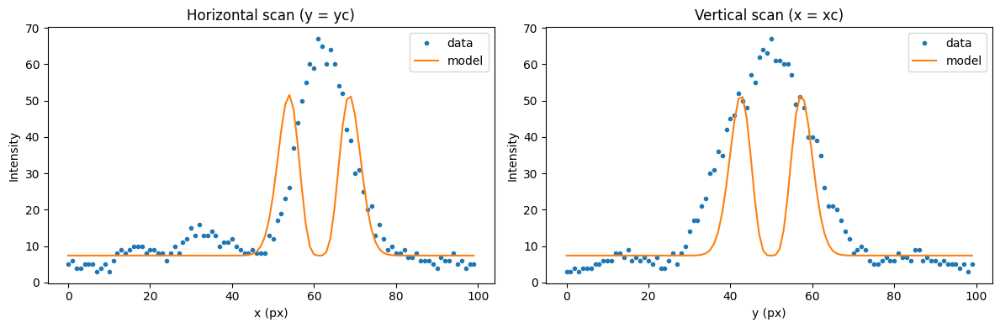

Params: {'A': 0.006805063102850382, 'w': 9.507906673401447, 'xc': 49.13247135551606, 'yc': 48.9327074741871, 'B': 7.011104672392825}
Uncertainties: {'A': 8.765919039868751e-05, 'w': 0.022771083673488447, 'xc': 0.0500005290670901, 'yc': 0.0500005290596936, 'B': 0.04718584784543714}
RMSE: 4.2672035967393045 R^2: 0.7542861474657991


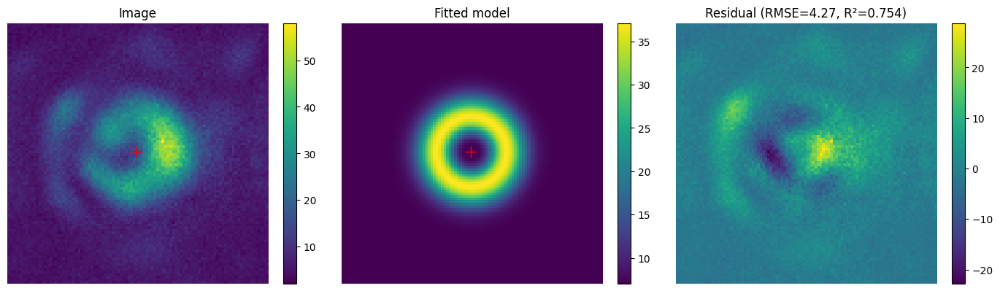

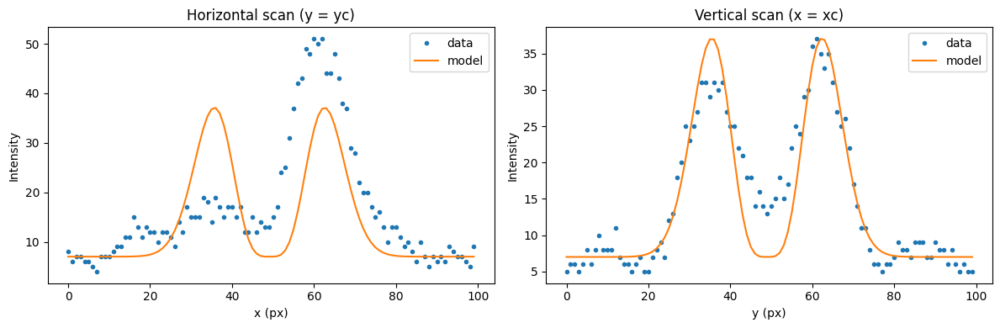

Params: {'A': 0.008534352771869494, 'w': 9.582233452117466, 'xc': 49.33147332924511, 'yc': 49.630153939264865, 'B': 7.253217100115819}
Uncertainties: {'A': 0.00012242431267221946, 'w': 0.025565041311739686, 'xc': 0.05611619582082964, 'yc': 0.056116195830949456, 'B': 0.06863562608752909}
RMSE: 6.196162079215352 R^2: 0.7116868145372824


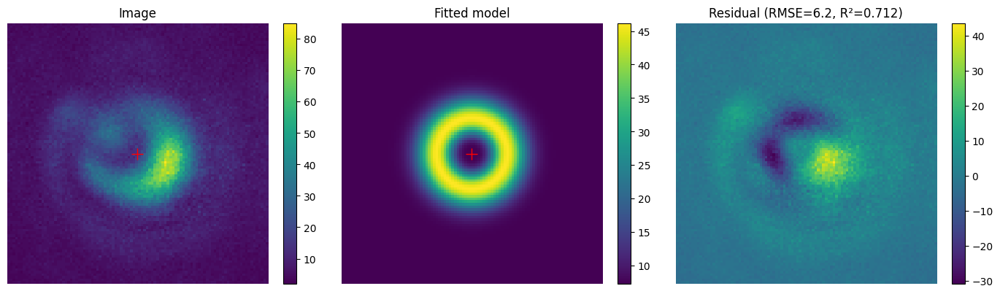

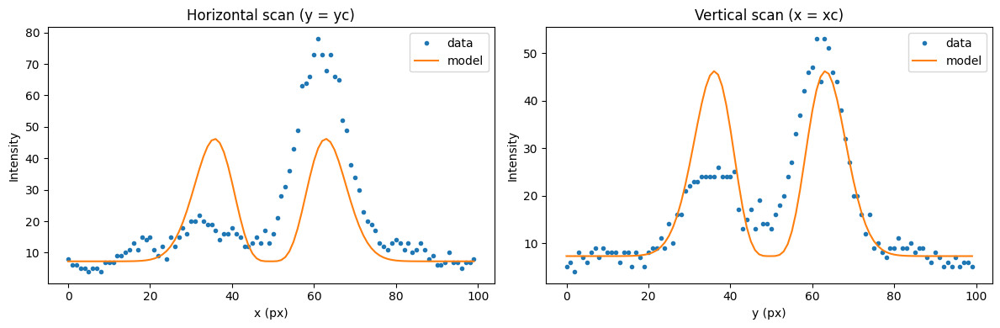

Params: {'A': 0.007590701605075684, 'w': 9.13040703646413, 'xc': 48.89032595805084, 'yc': 49.72055072634176, 'B': 4.592461705971796}
Uncertainties: {'A': 0.00011109730567225205, 'w': 0.02480385310500081, 'xc': 0.05455519811655144, 'yc': 0.05455519811062781, 'B': 0.04841966504158336}
RMSE: 4.416472999244837 R^2: 0.706825537334377


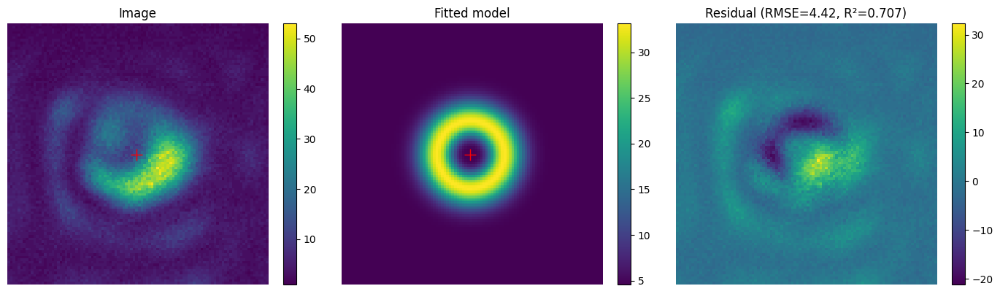

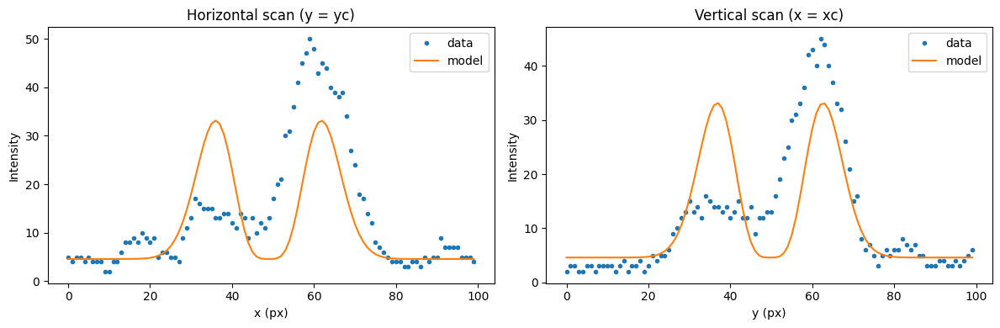

Params: {'A': 0.00863176749611752, 'w': 9.254083090079043, 'xc': 48.7241439555952, 'yc': 49.393412594496034, 'B': 6.645822936275854}
Uncertainties: {'A': 0.0001230693104645559, 'w': 0.02450321228871856, 'xc': 0.053865143259890454, 'yc': 0.053865143263473046, 'B': 0.05752812133132781}
RMSE: 5.232847744517326 R^2: 0.7166583928286602


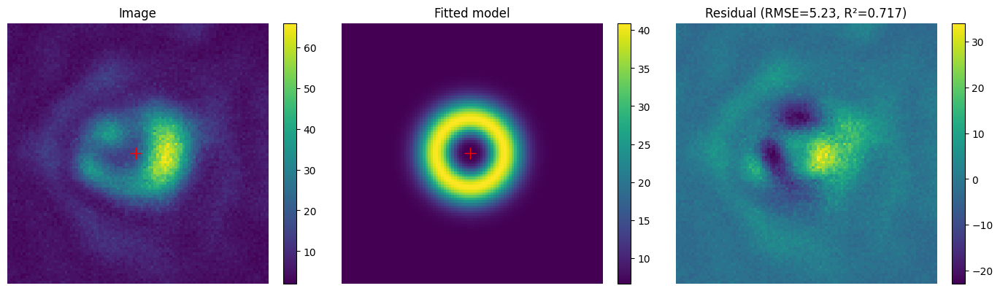

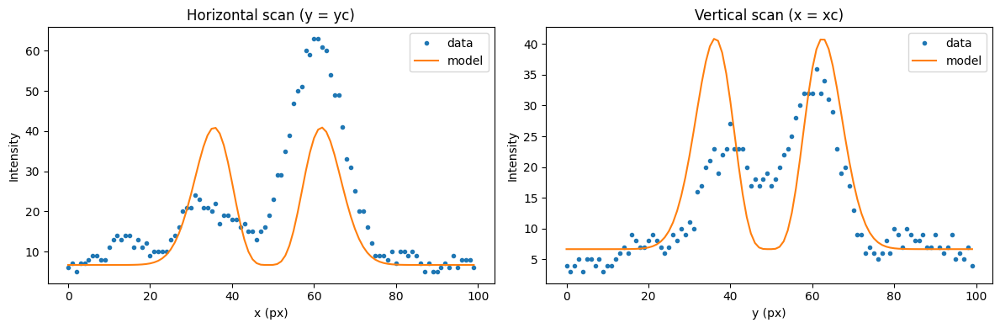

Params: {'A': 0.008324197752969468, 'w': 9.581067404619418, 'xc': 48.65138790916379, 'yc': 49.629688917504346, 'B': 7.401588631665725}
Uncertainties: {'A': 0.00010984068783306041, 'w': 0.0235133800354898, 'xc': 0.05161300457350213, 'yc': 0.05161300455746061, 'B': 0.06154162297685973}
RMSE: 5.555895643261098 R^2: 0.744728694039726


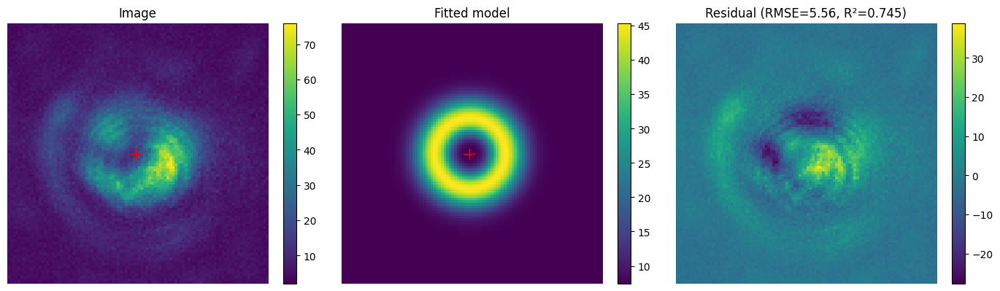

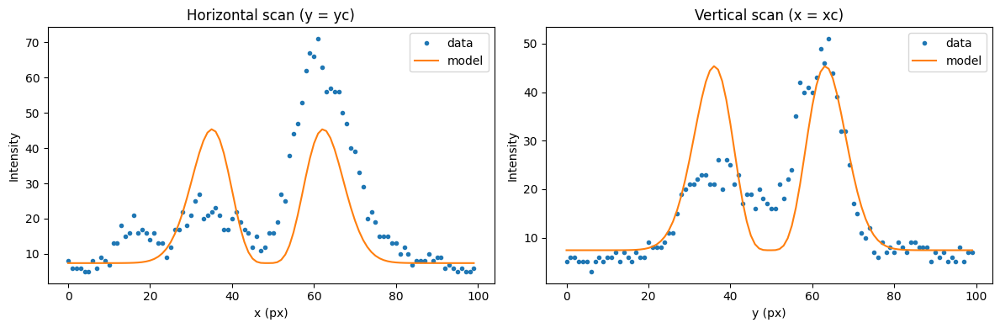

Params: {'A': 0.0071705756012374585, 'w': 9.279756645926765, 'xc': 48.41057165303547, 'yc': 49.601172843676956, 'B': 6.77531023421479}
Uncertainties: {'A': 9.519985462016749e-05, 'w': 0.022882703376849712, 'xc': 0.05029713461582208, 'yc': 0.050297134626571385, 'B': 0.04514750732903964}
RMSE: 4.104314010557278 R^2: 0.74452590049608


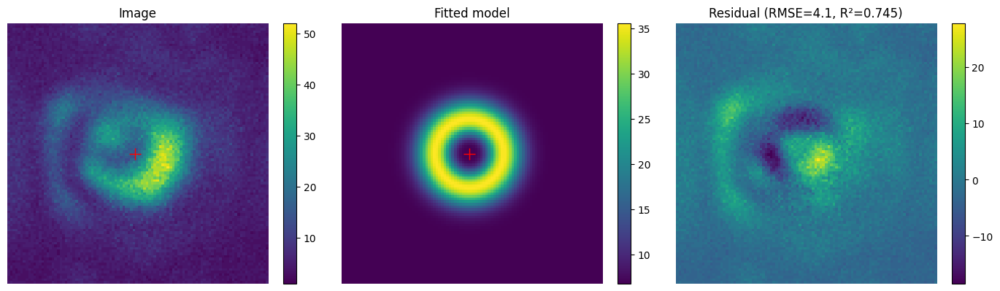

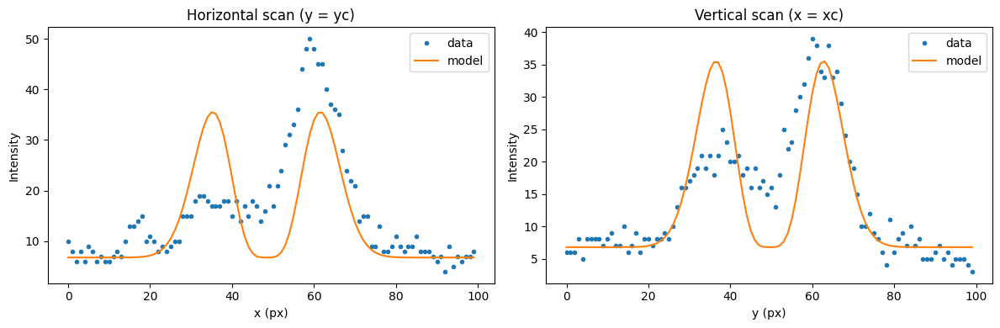

Params: {'A': 0.007425791836486815, 'w': 9.457712784298819, 'xc': 48.29801478139606, 'yc': 49.45728077179806, 'B': 4.562723568278955}
Uncertainties: {'A': 0.00011005042396458394, 'w': 0.026053675623383114, 'xc': 0.057221529406101354, 'yc': 0.05722152941740364, 'B': 0.05762417549504713}
RMSE: 5.21727445639516 R^2: 0.6991182465136949


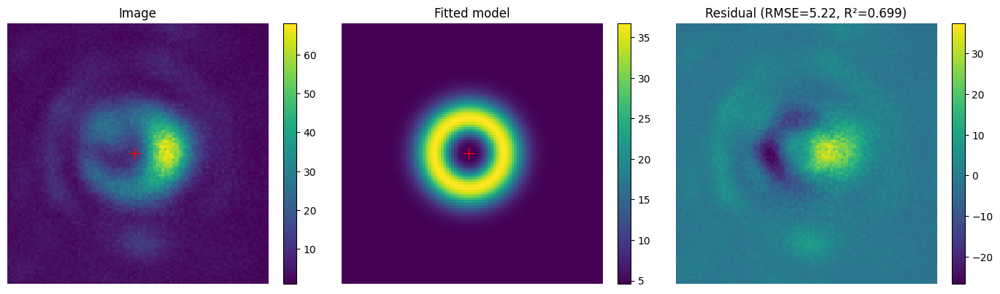

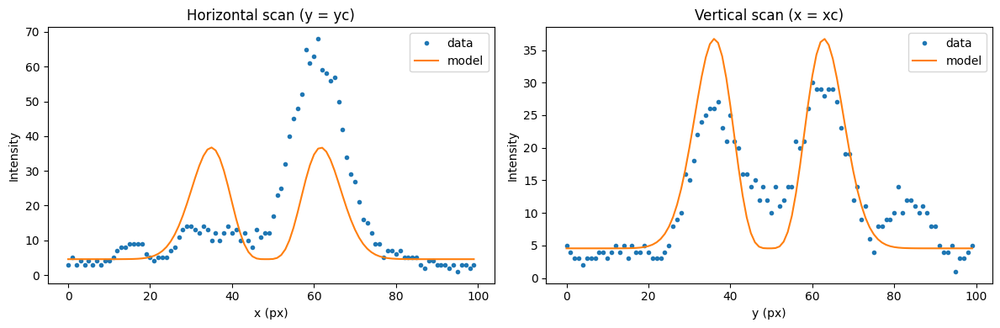

Params: {'A': 0.005689388841018432, 'w': 9.572892790110135, 'xc': 48.18282063322367, 'yc': 48.82203473033005, 'B': 5.86721089806139}
Uncertainties: {'A': 7.34631810310143e-05, 'w': 0.022988525300996005, 'xc': 0.05046284125405178, 'yc': 0.0504628412346087, 'B': 0.040976806686286386}
RMSE: 3.7000454924049064 R^2: 0.7529426822404072


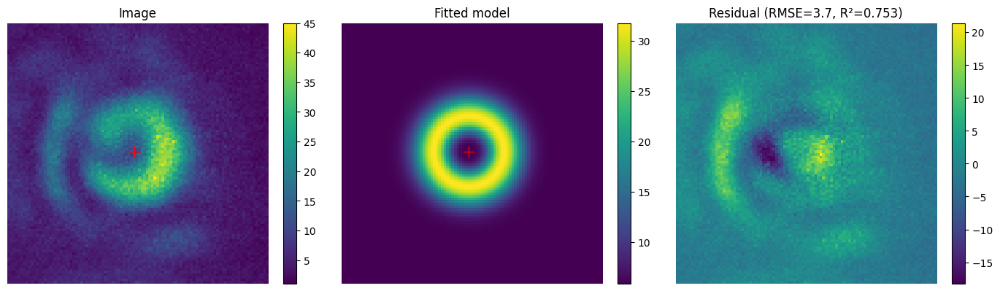

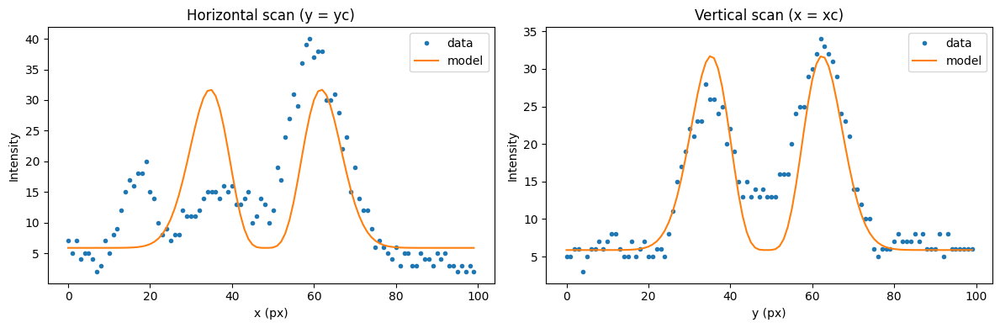

Params: {'A': 0.006545163010150631, 'w': 9.462299508137074, 'xc': 48.20761980585401, 'yc': 49.186947224010815, 'B': 6.09754383316272}
Uncertainties: {'A': 8.493977434345957e-05, 'w': 0.022826026339984557, 'xc': 0.050131617464159485, 'yc': 0.05013161746425082, 'B': 0.04458853019504918}
RMSE: 4.036601840314495 R^2: 0.7518414935115552


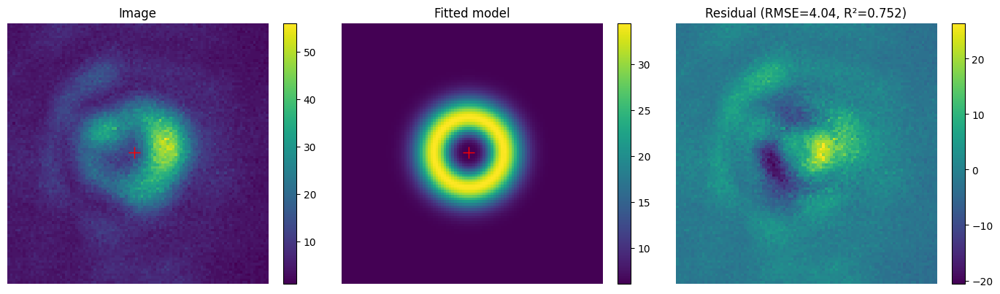

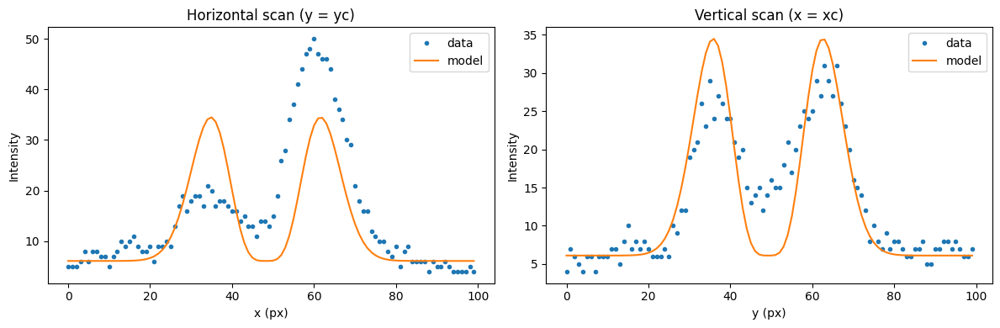

Params: {'A': 0.005976410156452998, 'w': 9.33791610568331, 'xc': 47.62936349499432, 'yc': 49.68452329541969, 'B': 5.428554484987717}
Uncertainties: {'A': 7.835433470580119e-05, 'w': 0.022744306599785755, 'xc': 0.04998008508442748, 'yc': 0.04998008507883572, 'B': 0.03838839159371562}
RMSE: 3.485252317626637 R^2: 0.7488797956522353


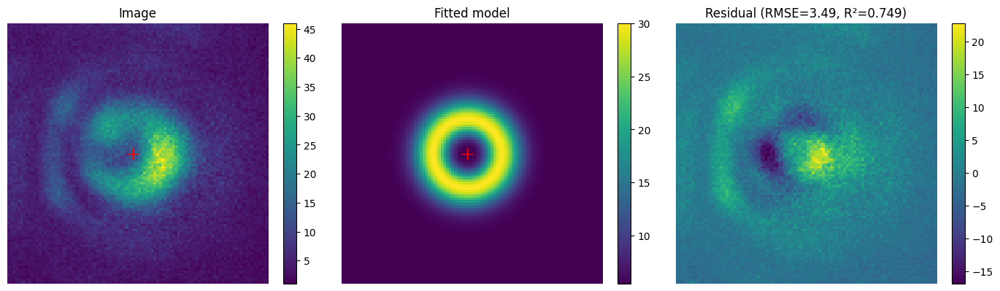

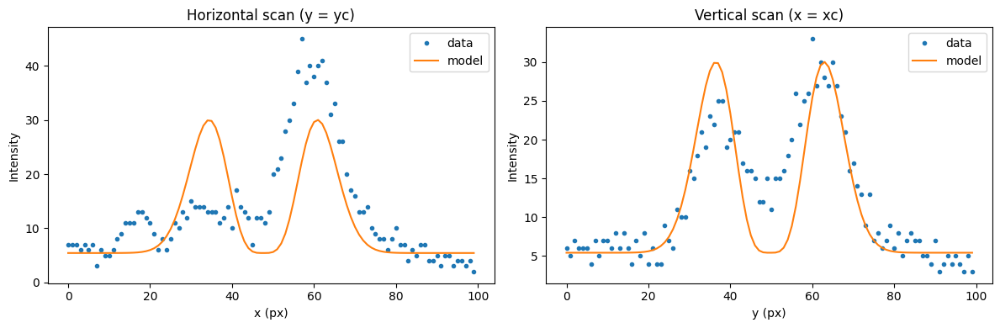

writing phase
Params: {'A': 0.0072843980943386845, 'w': 9.398326863453747, 'xc': 49.04966302664778, 'yc': 49.39793420650129, 'B': 3.965790168385249}
Uncertainties: {'A': 7.679050800968728e-05, 'w': 0.01841118607915001, 'xc': 0.040447231895799234, 'yc': 0.04044723188876354, 'B': 0.03890875884978891}
RMSE: 3.527618610877565 R^2: 0.8215043959220526


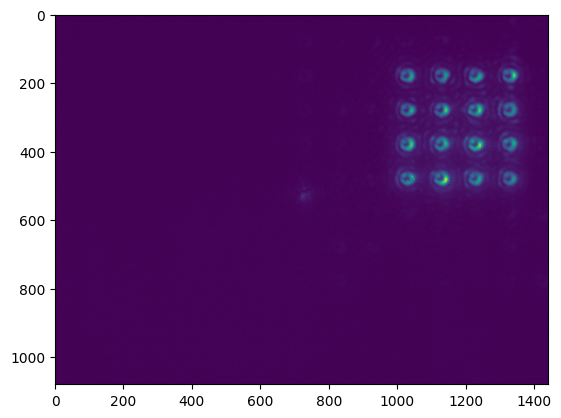

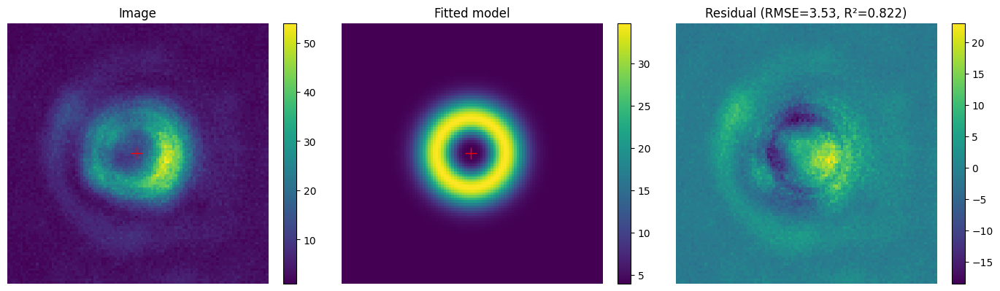

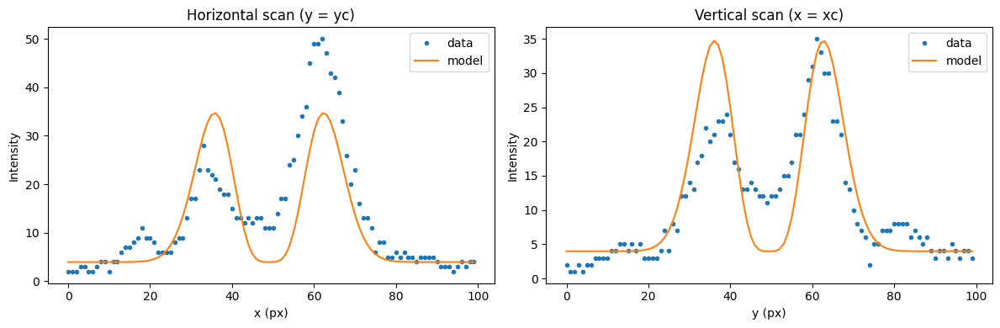

Params: {'A': 0.0071650768860587995, 'w': 9.315455025840482, 'xc': 49.184184507592356, 'yc': 49.31951978160931, 'B': 4.661718569065007}
Uncertainties: {'A': 8.860679749026271e-05, 'w': 0.021399671491571095, 'xc': 0.04702996434949518, 'yc': 0.04702996436843456, 'B': 0.042869928384371356}
RMSE: 3.894114935722206 R^2: 0.7703575795142641


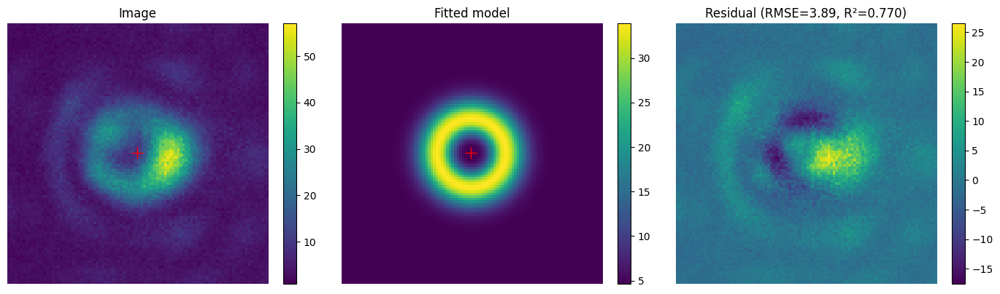

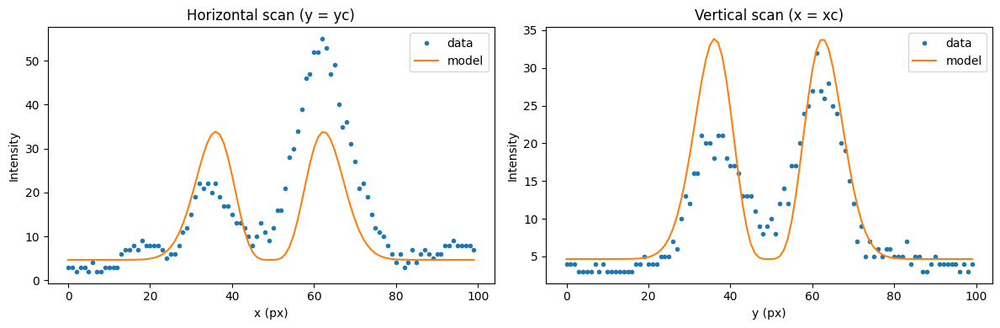

Params: {'A': 0.008741192786580011, 'w': 9.388824160617489, 'xc': 49.039492451636434, 'yc': 49.27807510932375, 'B': 6.097308581892326}
Uncertainties: {'A': 0.00010619611781312427, 'w': 0.02119570994380512, 'xc': 0.0465664937047556, 'yc': 0.04656649371749474, 'B': 0.05352504254511548}
RMSE: 4.853846366797458 R^2: 0.7761092343599224


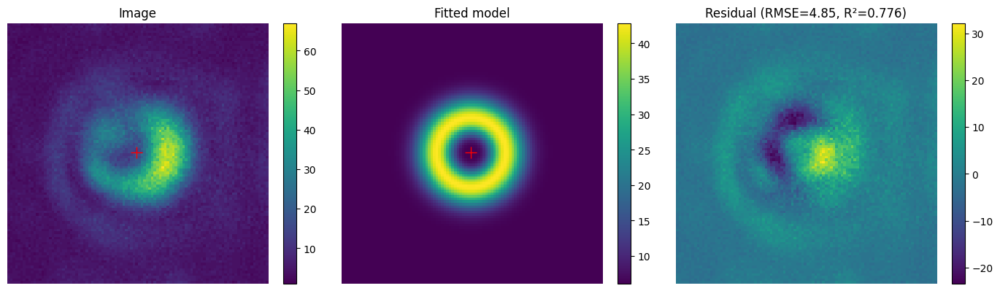

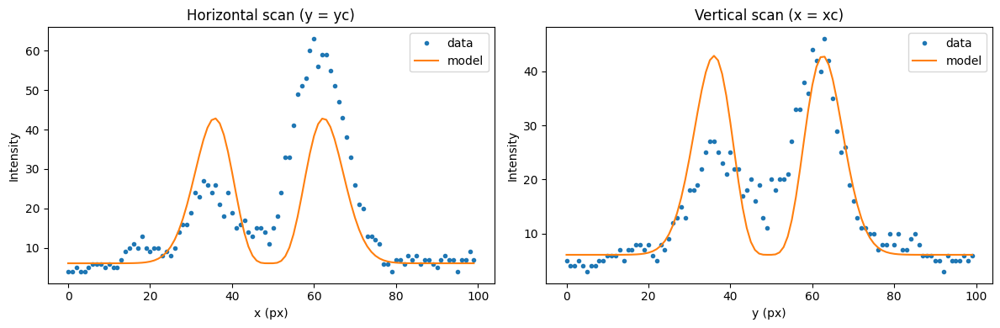

Params: {'A': 0.00714950212513027, 'w': 9.473573376333254, 'xc': 49.77956088335081, 'yc': 49.64089894434599, 'B': 6.062478899389206}
Uncertainties: {'A': 8.374487849522034e-05, 'w': 0.020628211121285617, 'xc': 0.04530234378219055, 'yc': 0.045302343776755724, 'B': 0.044235370809871624}
RMSE: 4.003582030174839 R^2: 0.788015511590421


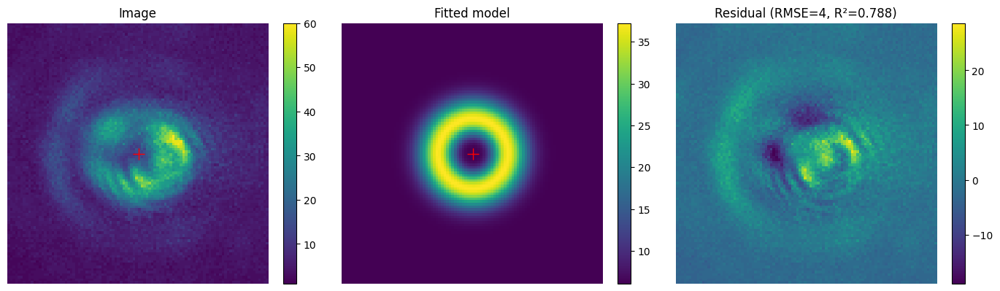

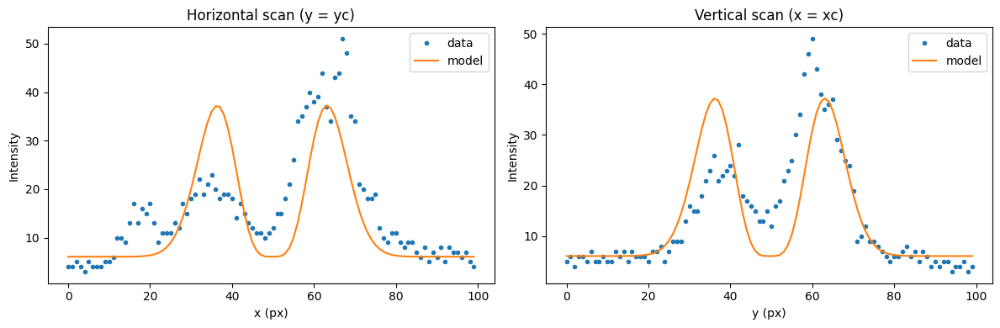

Params: {'A': 0.005899471883611822, 'w': 9.480613057948718, 'xc': 49.27102022473305, 'yc': 49.321484427169295, 'B': 4.470793712919099}
Uncertainties: {'A': 7.366059868059403e-05, 'w': 0.02200583060332135, 'xc': 0.04832623052624, 'yc': 0.04832623053275061, 'B': 0.039059865768617114}
RMSE: 3.534587284206809 R^2: 0.765844851345233


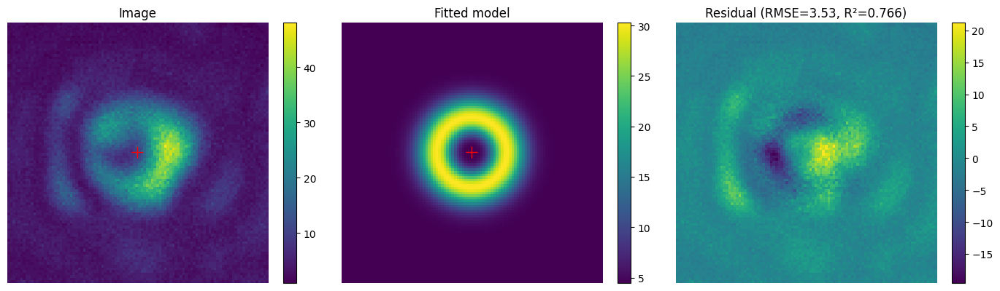

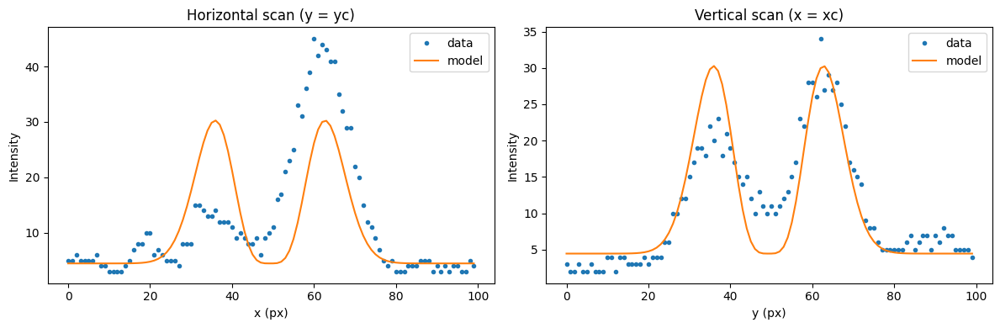

Params: {'A': 0.12015320895143894, 'w': 5.110031887880721, 'xc': 61.16850306738881, 'yc': 49.98246863132146, 'B': 7.495521620447455}
Uncertainties: {'A': 0.002982548568689222, 'w': 0.023265442729057045, 'xc': 0.05178454346933111, 'yc': 0.05178454346247854, 'B': 0.06690312716786277}
RMSE: 6.510688752966209 R^2: 0.4822975064023104


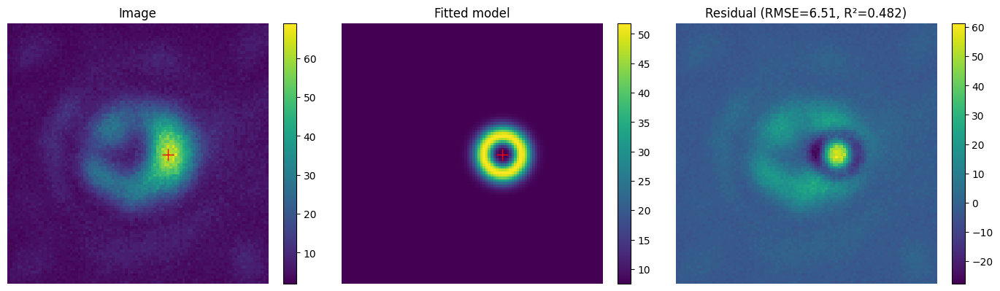

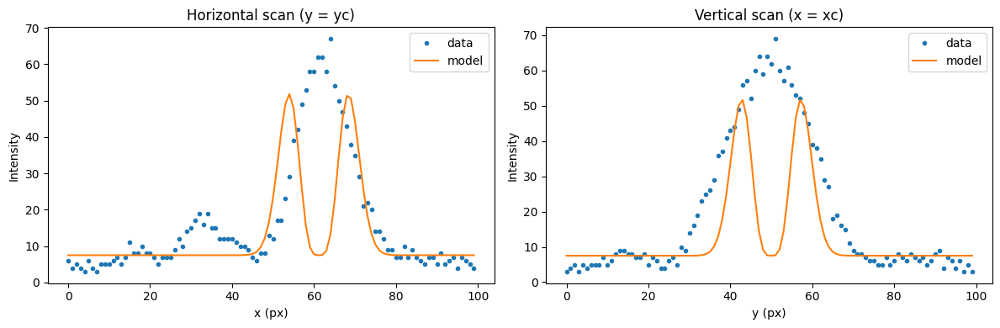

Params: {'A': 0.007335457338466269, 'w': 9.456233566199172, 'xc': 48.822171813306625, 'yc': 48.89732059946897, 'B': 6.978838760730911}
Uncertainties: {'A': 8.574091318776316e-05, 'w': 0.020545187563775415, 'xc': 0.045123574025540354, 'yc': 0.04512357402445638, 'B': 0.044858687617628186}
RMSE: 4.061630541469344 R^2: 0.7888313848058377


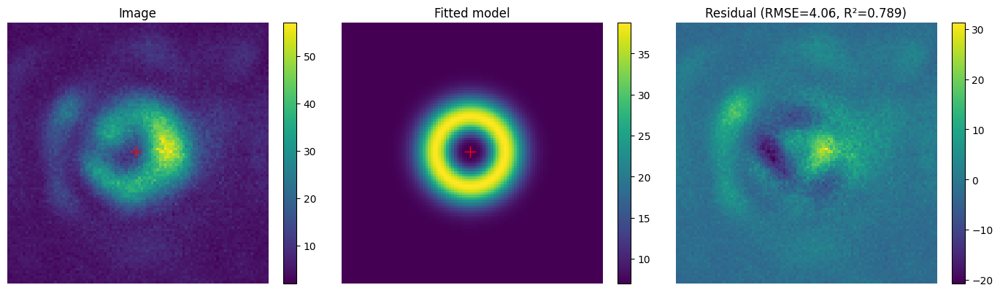

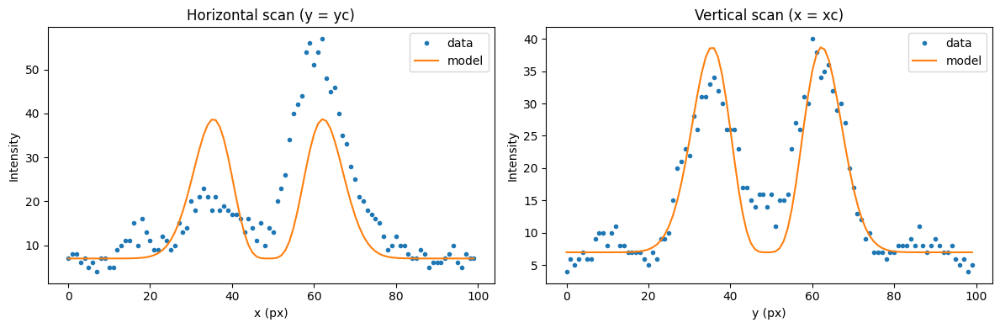

Params: {'A': 0.008769528282843574, 'w': 9.59988951469823, 'xc': 49.042195807238784, 'yc': 49.57844739750329, 'B': 7.188257681207324}
Uncertainties: {'A': 0.00011583704243247436, 'w': 0.023586086017815085, 'xc': 0.051768055585088096, 'yc': 0.051768055609416254, 'B': 0.0655704623198094}
RMSE: 5.916978519432159 R^2: 0.7441980923323399


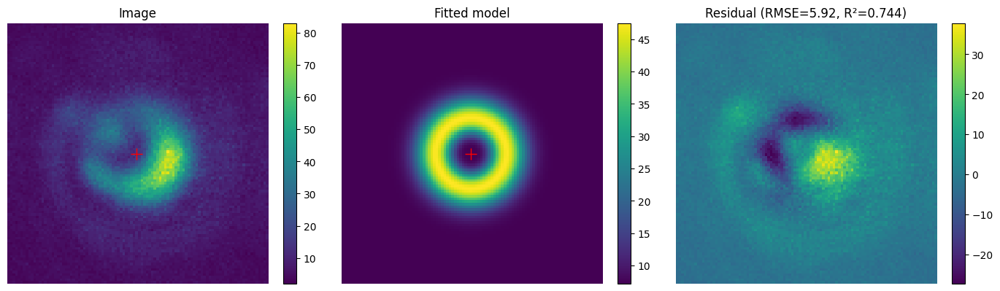

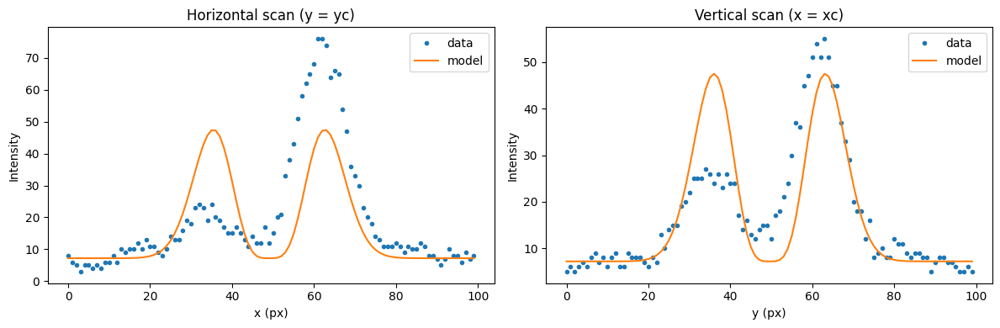

Params: {'A': 0.007973482282932369, 'w': 9.131175561246959, 'xc': 48.52588260961222, 'yc': 49.74756388024339, 'B': 4.526657184070519}
Uncertainties: {'A': 0.00010701868928609959, 'w': 0.022748204116319243, 'xc': 0.050033706653295325, 'yc': 0.0500337066503775, 'B': 0.04666250106025452}
RMSE: 4.256125742265349 R^2: 0.7413868392854175


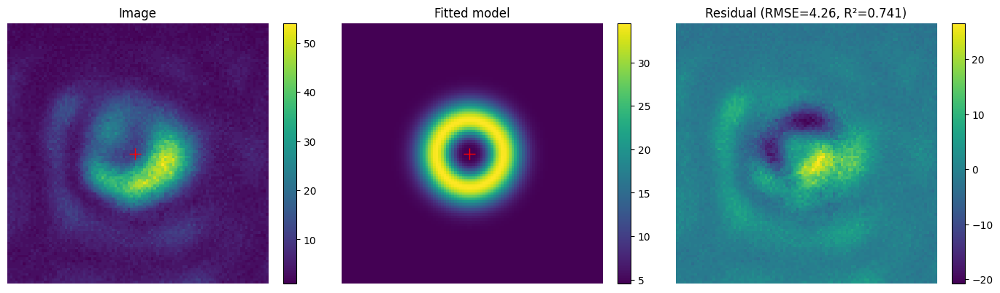

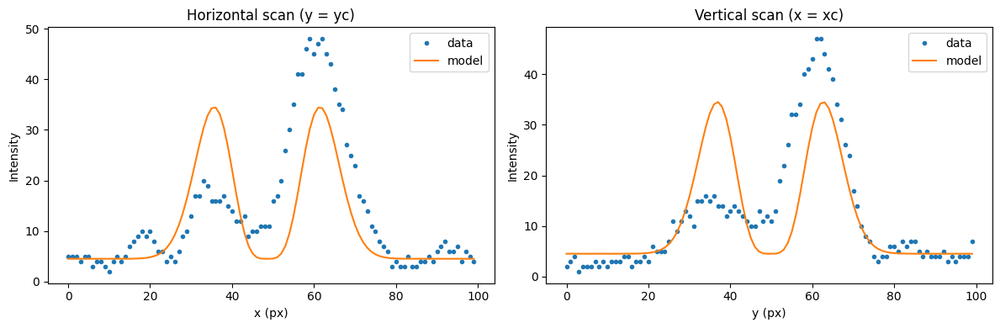

Params: {'A': 0.008951438748653003, 'w': 9.275264445132931, 'xc': 48.36385645186943, 'yc': 49.383935510383544, 'B': 6.543983992909487}
Uncertainties: {'A': 0.00011499711777717764, 'w': 0.022130963462455546, 'xc': 0.04864573872582209, 'yc': 0.04864573872757319, 'B': 0.05439876069451653}
RMSE: 4.9458371980637335 R^2: 0.7568688889101091


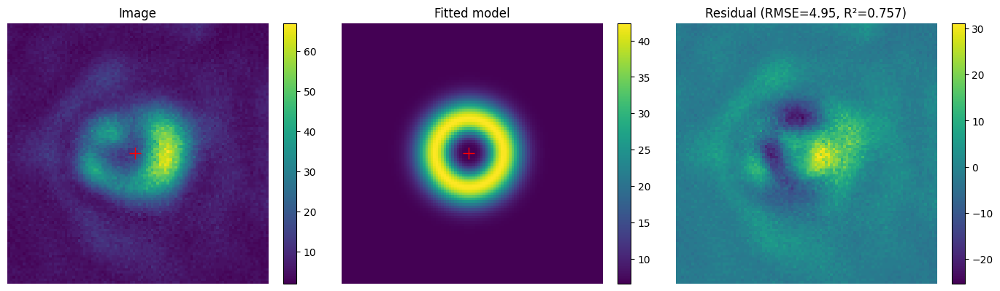

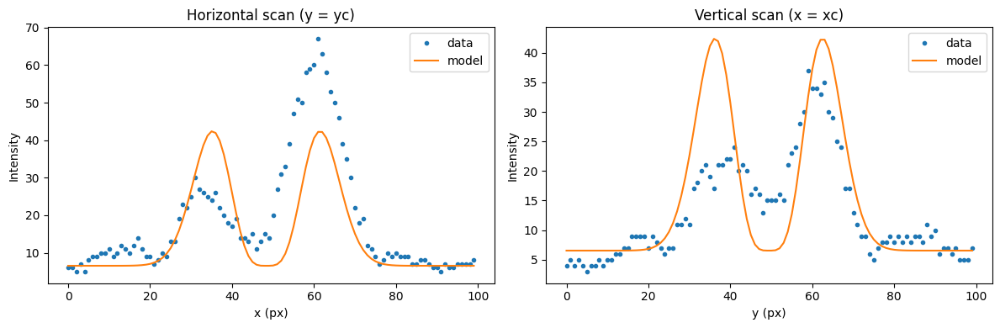

Params: {'A': 0.008913253553955345, 'w': 9.537226650885891, 'xc': 48.33116675325285, 'yc': 49.64479112592589, 'B': 7.318273854459834}
Uncertainties: {'A': 0.00010655362482488384, 'w': 0.02120050254905853, 'xc': 0.04654558169417996, 'yc': 0.04654558168980648, 'B': 0.0582863237079614}
RMSE: 5.267446160212332 R^2: 0.7807191102869135


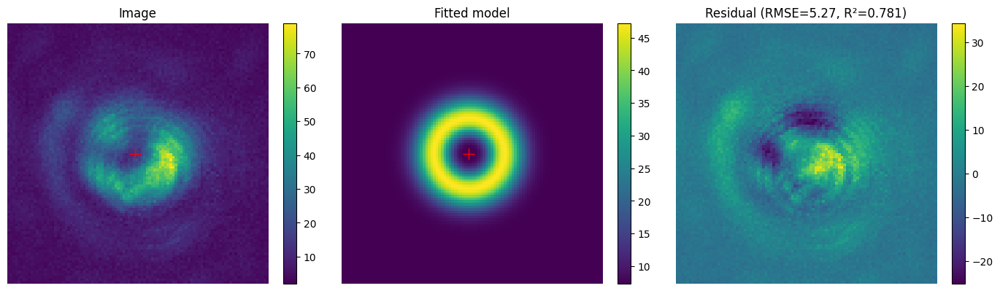

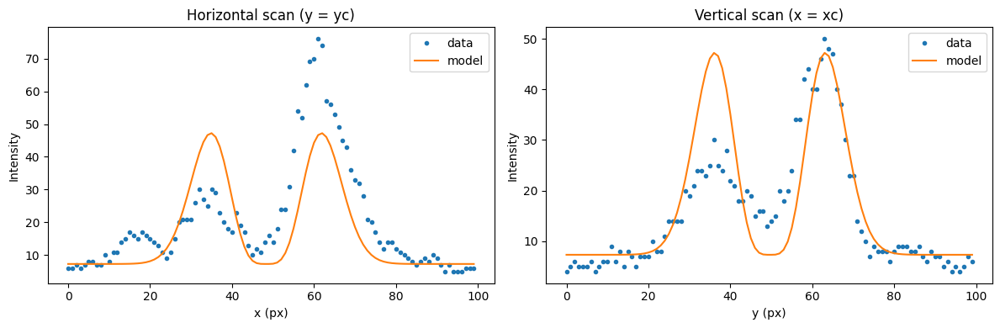

Params: {'A': 0.007420816330110973, 'w': 9.312648446836924, 'xc': 48.07092889084603, 'yc': 49.657436795083974, 'B': 6.685119179981393}
Uncertainties: {'A': 8.792468979302147e-05, 'w': 0.020496694403711133, 'xc': 0.045046054894551324, 'yc': 0.04504605488868764, 'B': 0.04247316157703179}
RMSE: 3.858320017138631 R^2: 0.7851661285509526


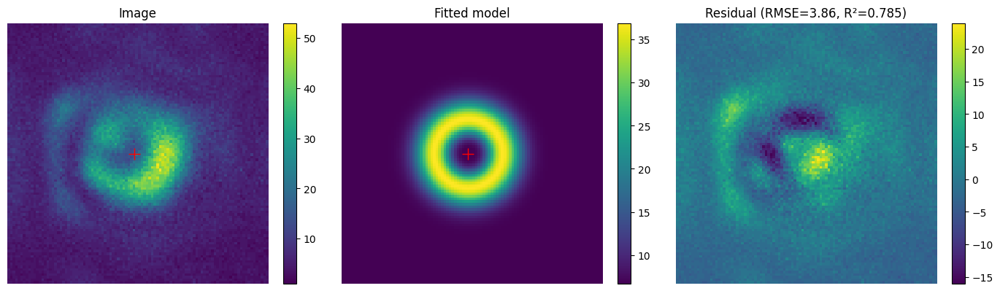

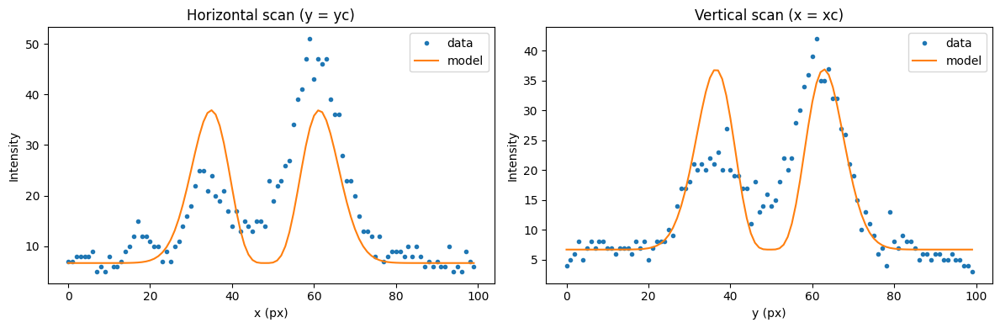

Params: {'A': 0.007538499881715221, 'w': 9.508826578009574, 'xc': 47.93656788985124, 'yc': 49.440546743419716, 'B': 4.53342387923613}
Uncertainties: {'A': 0.0001024312982959391, 'w': 0.024022046124315626, 'xc': 0.0527471577226416, 'yc': 0.05274715773361081, 'B': 0.055165353135077505}
RMSE: 4.98871472171881 R^2: 0.7339605134216007


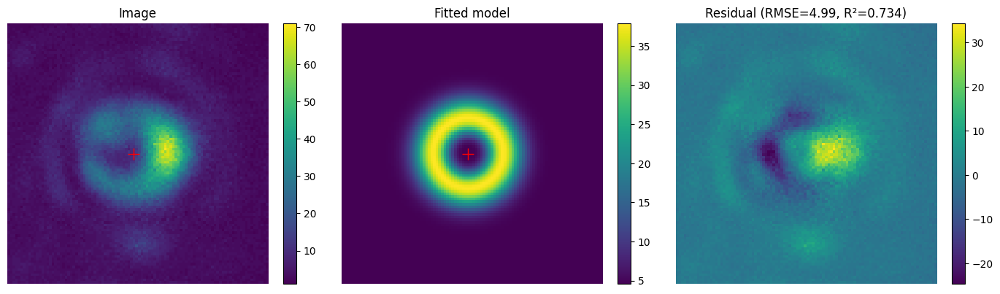

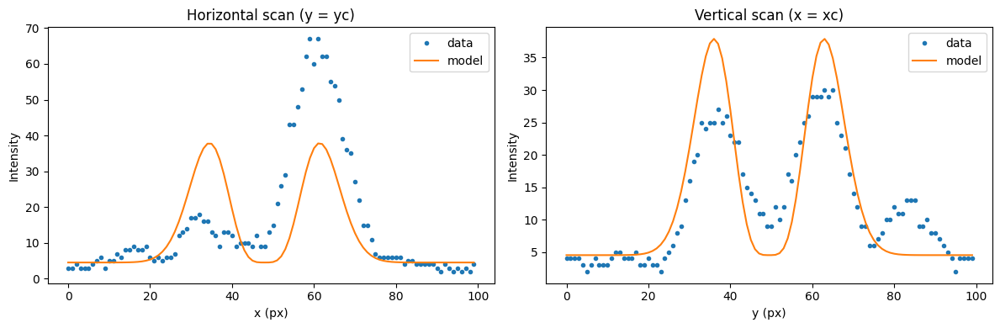

Params: {'A': 0.0059549136703037795, 'w': 9.577397566049722, 'xc': 47.824188438354525, 'yc': 48.88783971429487, 'B': 5.78177739728835}
Uncertainties: {'A': 6.922778111660749e-05, 'w': 0.020707389726050934, 'xc': 0.04545449621761649, 'yc': 0.045454496217931836, 'B': 0.03870941185012489}
RMSE: 3.4949369778322 R^2: 0.7898779527897448


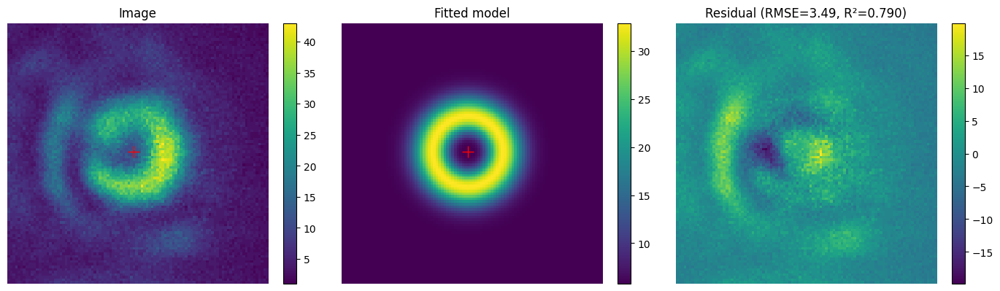

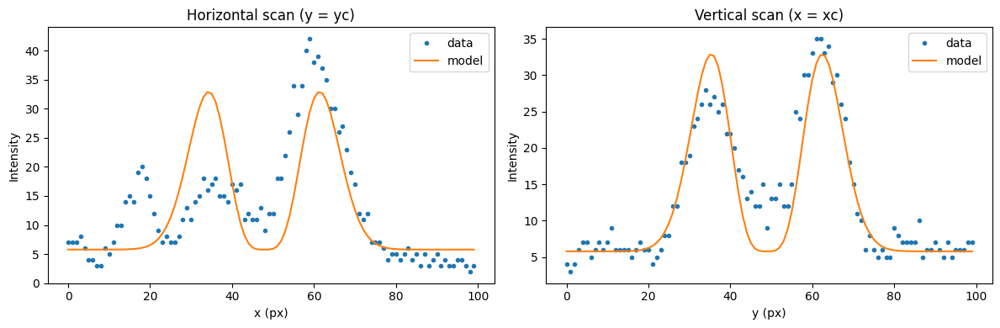

Params: {'A': 0.006911776284907388, 'w': 9.458691286952552, 'xc': 47.935450725728415, 'yc': 49.15596244139057, 'B': 6.046232515877447}
Uncertainties: {'A': 8.065647493734825e-05, 'w': 0.020517123711145273, 'xc': 0.04506143384594778, 'yc': 0.045061433851598026, 'B': 0.04225584065055023}
RMSE: 3.8257435221246086 R^2: 0.7893613166437545


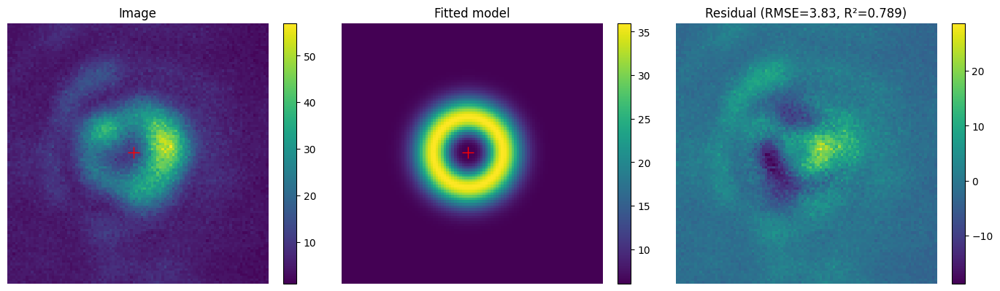

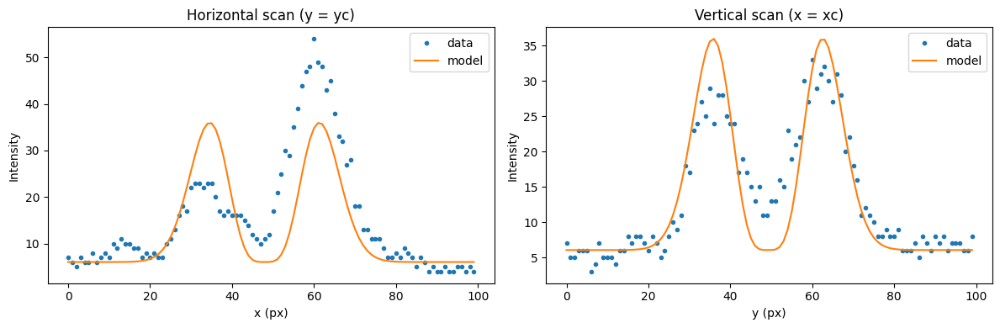

Params: {'A': 0.0062967434523110094, 'w': 9.333868388260687, 'xc': 47.2859122819438, 'yc': 49.72621486139915, 'B': 5.361630340153273}
Uncertainties: {'A': 7.404148466642709e-05, 'w': 0.020389805636526478, 'xc': 0.044806929429832915, 'yc': 0.04480692942903093, 'B': 0.03619349514109111}
RMSE: 3.286282098162206 R^2: 0.7875887090315785


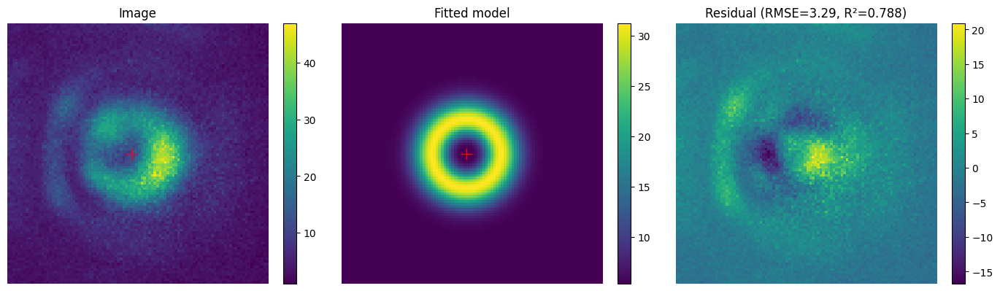

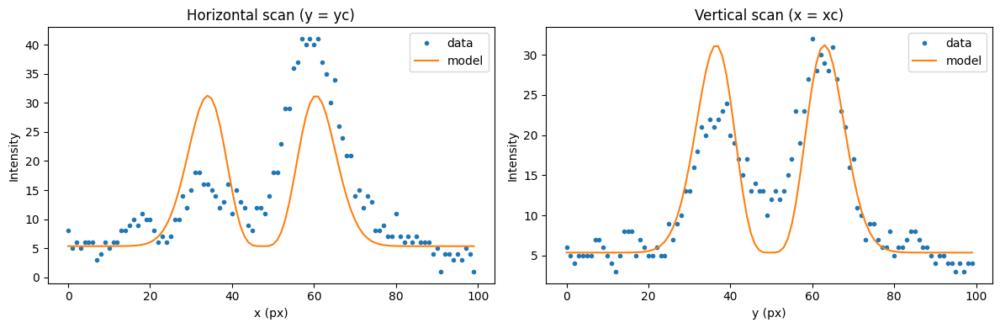

writing phase
Params: {'A': 0.007593444772000024, 'w': 9.386117509776476, 'xc': 48.84498506502807, 'yc': 49.338036174845165, 'B': 3.8583193697703515}
Uncertainties: {'A': 7.237582704344475e-05, 'w': 0.016623950509015984, 'xc': 0.03652288526565653, 'yc': 0.0365228852726012, 'B': 0.036424102860312876}
RMSE: 3.3032757803974935 R^2: 0.8492259142101815


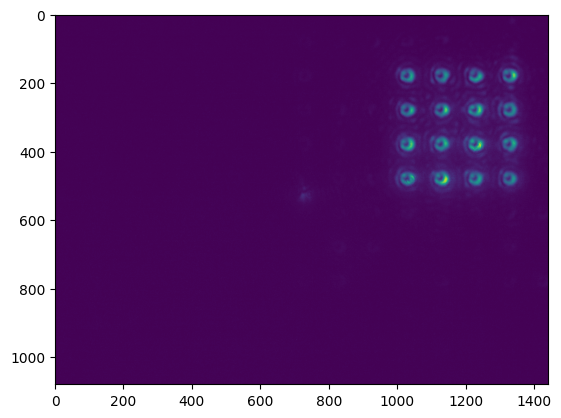

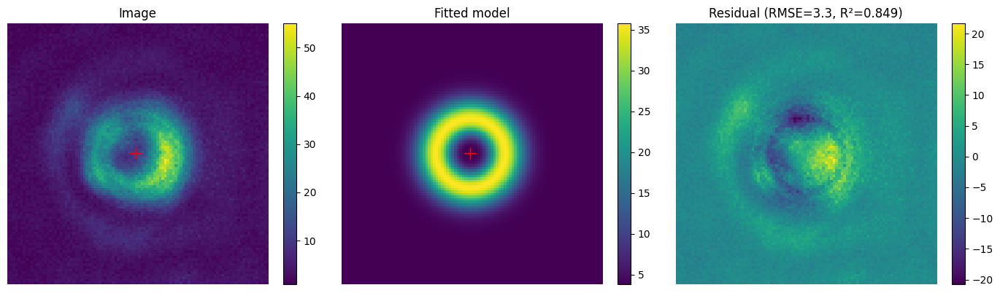

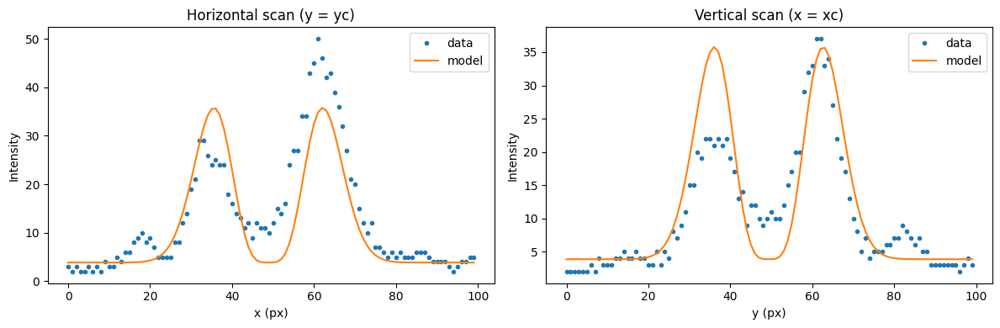

Params: {'A': 0.007509120407568933, 'w': 9.29487566423754, 'xc': 49.03116593282165, 'yc': 49.28565342093104, 'B': 4.5854009967734}
Uncertainties: {'A': 8.622856822818236e-05, 'w': 0.01982545069383477, 'xc': 0.043574266219360835, 'yc': 0.04357426622502043, 'B': 0.04124126607365948}
RMSE: 3.747921246002923 R^2: 0.795645115684231


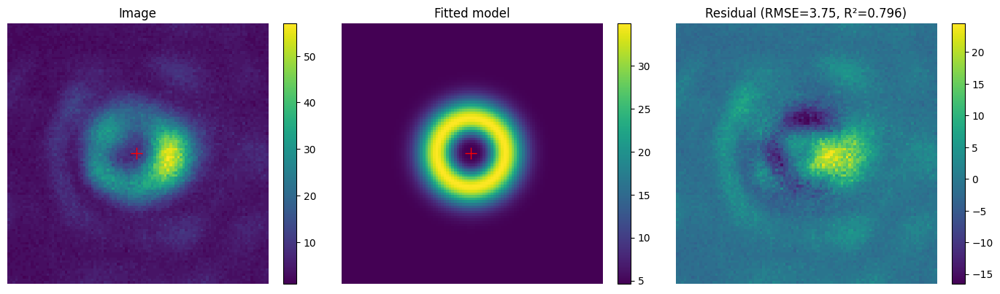

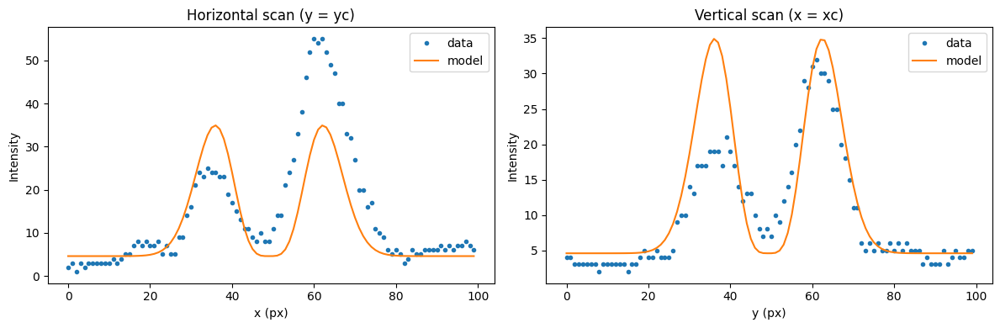

Params: {'A': 0.009124513617006223, 'w': 9.373431101322497, 'xc': 48.78544277475912, 'yc': 49.17654729601761, 'B': 6.010308617694576}
Uncertainties: {'A': 0.00010110970469228106, 'w': 0.01929970101896122, 'xc': 0.04240392920125565, 'yc': 0.04240392920467918, 'B': 0.050527167221266565}
RMSE: 4.583604716225122 R^2: 0.8065429078134154


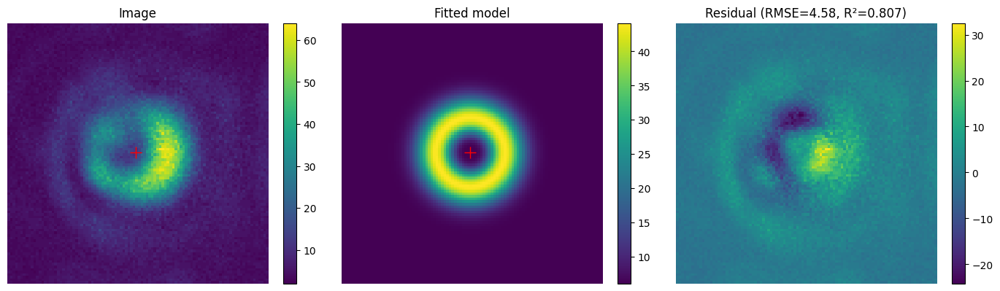

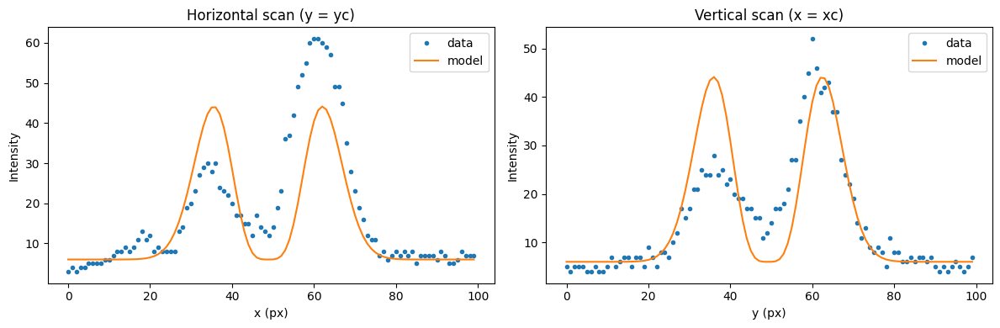

Params: {'A': 0.007423745527483353, 'w': 9.464046839257465, 'xc': 49.55307508164058, 'yc': 49.523970645600805, 'B': 5.9742070070699045}
Uncertainties: {'A': 8.047661910367931e-05, 'w': 0.019070846393805754, 'xc': 0.04188397757056315, 'yc': 0.04188397757471966, 'B': 0.04228636346532954}
RMSE: 3.828031355016276 R^2: 0.8127926209893529


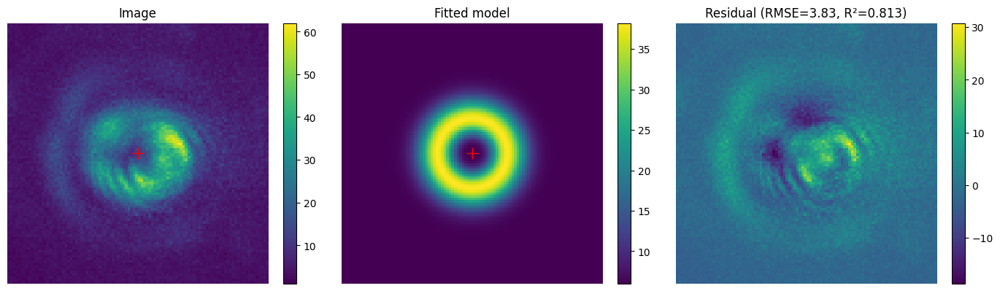

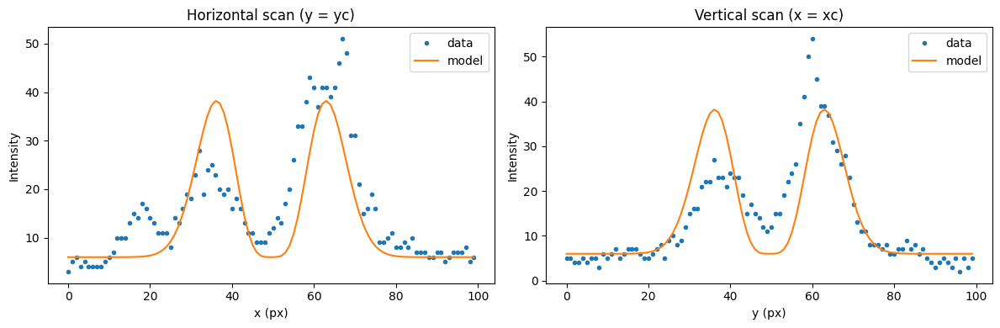

Params: {'A': 0.006089086669368047, 'w': 9.475158280495124, 'xc': 49.006529647747485, 'yc': 49.26856153096595, 'B': 4.392259602489079}
Uncertainties: {'A': 6.873696960209549e-05, 'w': 0.01988351339651136, 'xc': 0.04366657108822128, 'yc': 0.04366657109136392, 'B': 0.036339675738673693}
RMSE: 3.2888503100516706 R^2: 0.8000859851946777


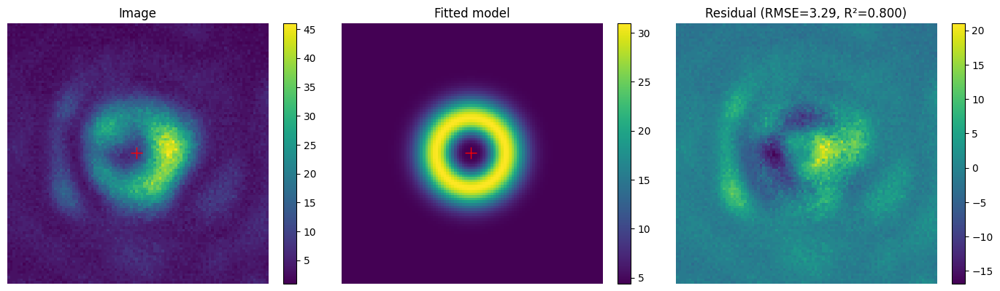

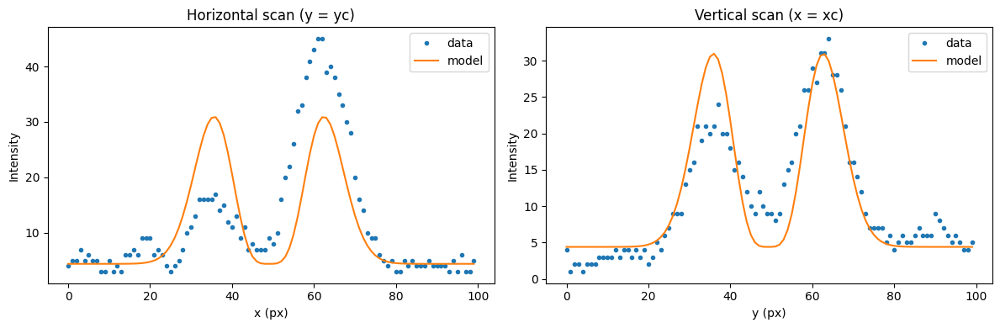

Params: {'A': 0.12965361351271595, 'w': 5.020878945499967, 'xc': 60.948872337009924, 'yc': 49.86136291457312, 'B': 7.530702377380643}
Uncertainties: {'A': 0.0033239165902246826, 'w': 0.023605238448119733, 'xc': 0.05254962646535752, 'yc': 0.052549626473323674, 'B': 0.06821406359322542}
RMSE: 6.644621209474296 R^2: 0.46660178371884464


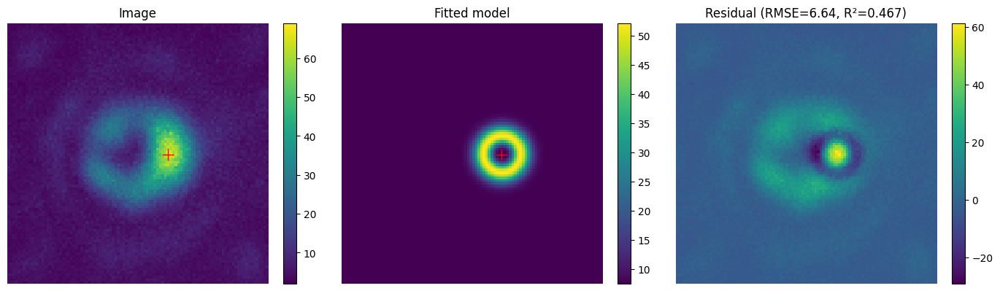

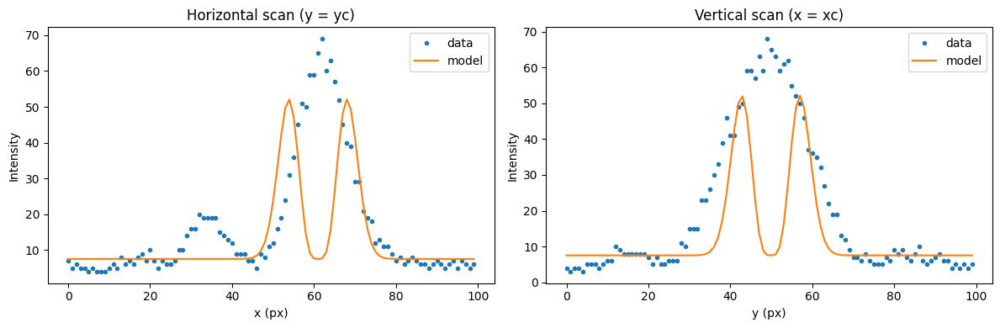

Params: {'A': 0.00778788610327532, 'w': 9.413707092654676, 'xc': 48.569886960220245, 'yc': 48.81092763777123, 'B': 6.8766359521427525}
Uncertainties: {'A': 8.317847855826392e-05, 'w': 0.018685274471598567, 'xc': 0.041046530424202726, 'yc': 0.04104653041391866, 'B': 0.0425064802494641}
RMSE: 3.852438692281275 R^2: 0.8175533338926013


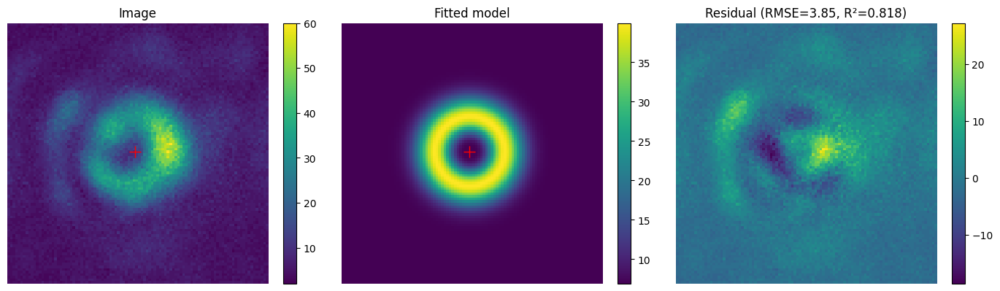

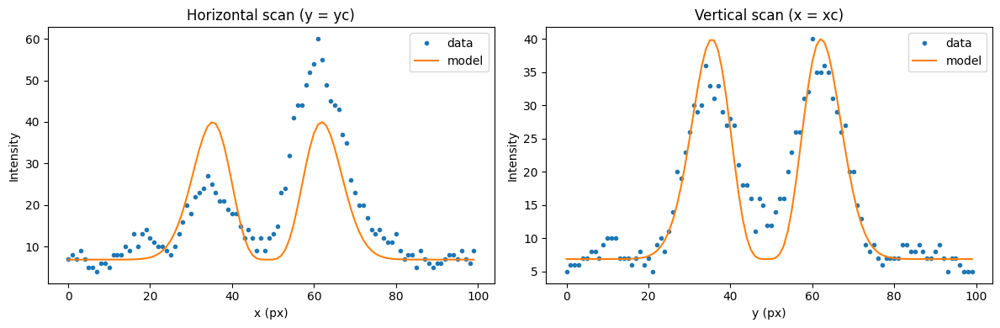

Params: {'A': 0.009021982748192249, 'w': 9.593316058896358, 'xc': 48.830441449418416, 'yc': 49.463339257946316, 'B': 7.064301409283232}
Uncertainties: {'A': 0.00011194917091836274, 'w': 0.02214077072166504, 'xc': 0.048597287923789555, 'yc': 0.04859728792166417, 'B': 0.06314320991709921}
RMSE: 5.698833967414017 R^2: 0.7673120017096291


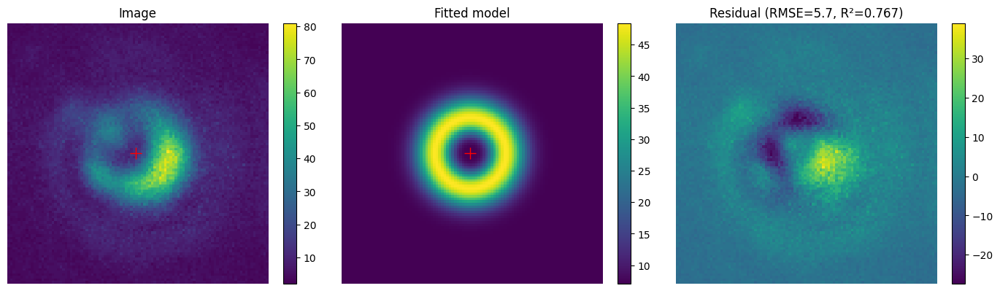

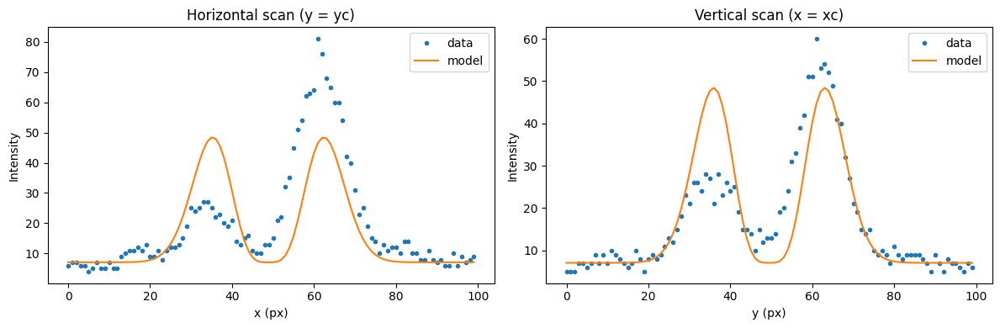

Params: {'A': 0.008366811160743488, 'w': 9.109258780614276, 'xc': 48.36118355387907, 'yc': 49.6941574155583, 'B': 4.422227802605281}
Uncertainties: {'A': 0.00010394418743871697, 'w': 0.021003492776412384, 'xc': 0.04620060604491274, 'yc': 0.04620060604474103, 'B': 0.04475903722803017}
RMSE: 4.084479931030504 R^2: 0.7700456986519032


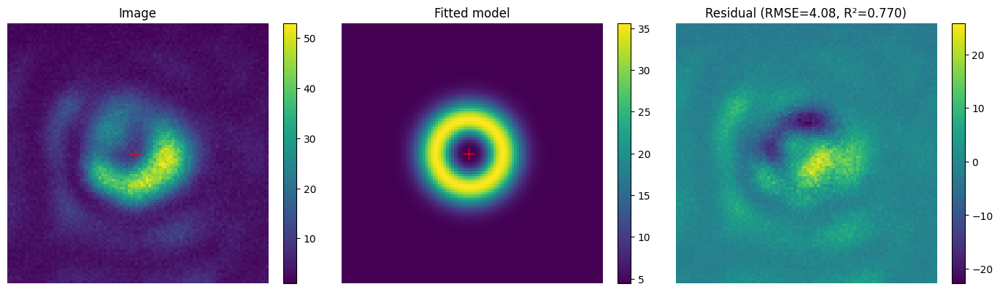

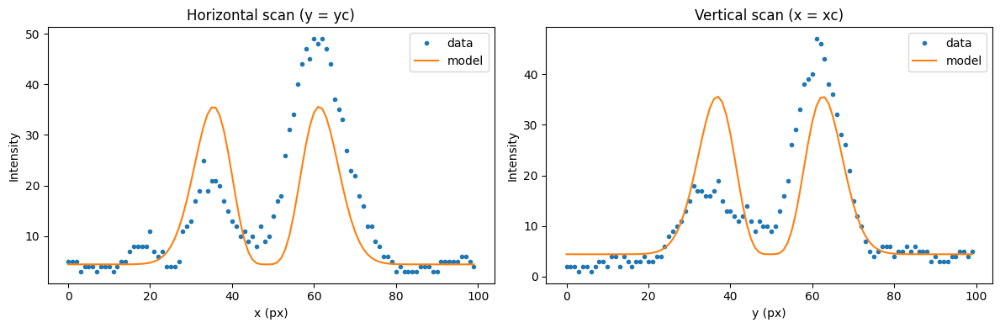

Params: {'A': 0.009405944008309623, 'w': 9.231928443024778, 'xc': 48.192809763311956, 'yc': 49.346331950469825, 'B': 6.462015454327014}
Uncertainties: {'A': 0.00011191326508723759, 'w': 0.020397136728522298, 'xc': 0.044843138236786505, 'yc': 0.04484313822950249, 'B': 0.05166438574519165}
RMSE: 4.701809972745106 R^2: 0.7842451813927105


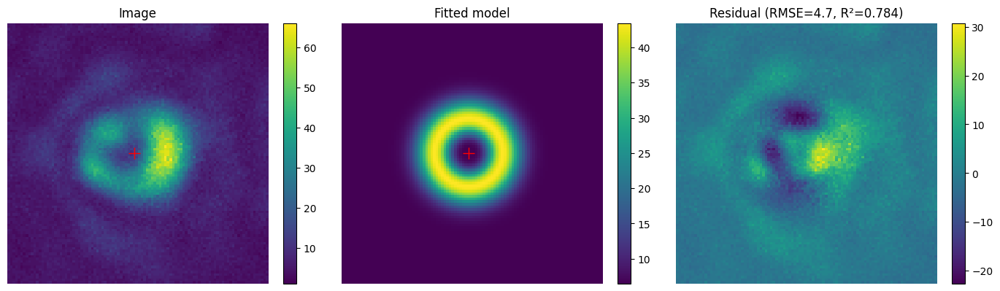

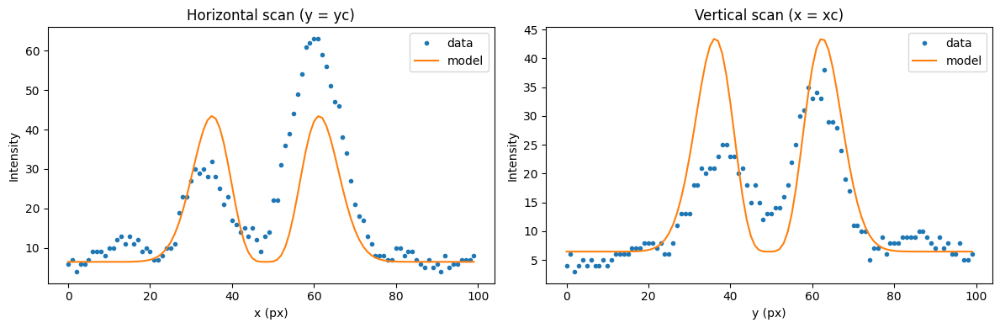

Params: {'A': 0.009417217379340018, 'w': 9.506037603738676, 'xc': 48.21455867055301, 'yc': 49.53586312166495, 'B': 7.174640146387426}
Uncertainties: {'A': 0.00010324335986406333, 'w': 0.01937620982317543, 'xc': 0.04254646212237428, 'yc': 0.04254646213009246, 'B': 0.05551758471620949}
RMSE: 5.020894863009139 R^2: 0.8090972335071033


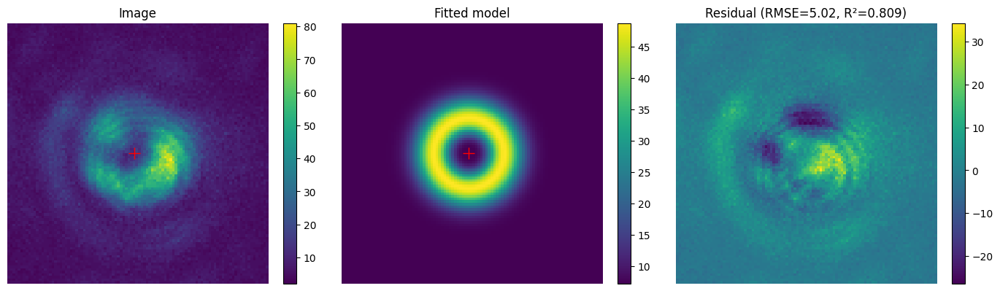

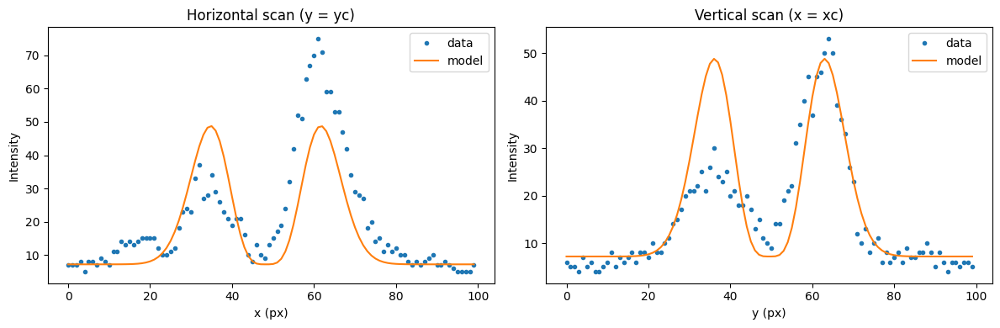

Params: {'A': 0.007820031144692804, 'w': 9.276859363202597, 'xc': 47.88491357619911, 'yc': 49.55966361524129, 'B': 6.574298788403924}
Uncertainties: {'A': 8.38882508314167e-05, 'w': 0.018483175058931926, 'xc': 0.040627305506930764, 'yc': 0.04062730551427725, 'B': 0.03971843897227906}
RMSE: 3.6109989402640448 R^2: 0.8169954909466172


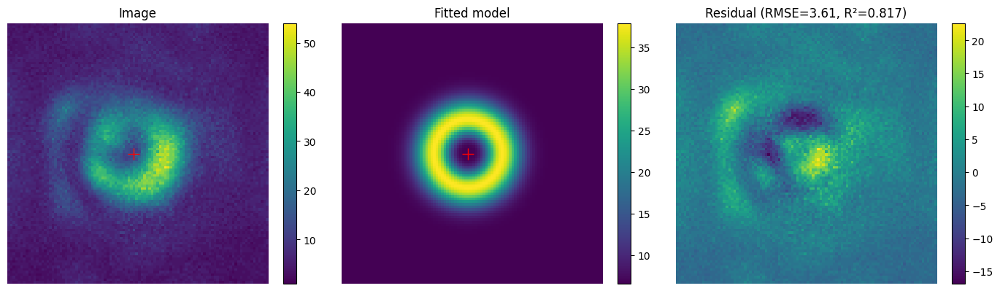

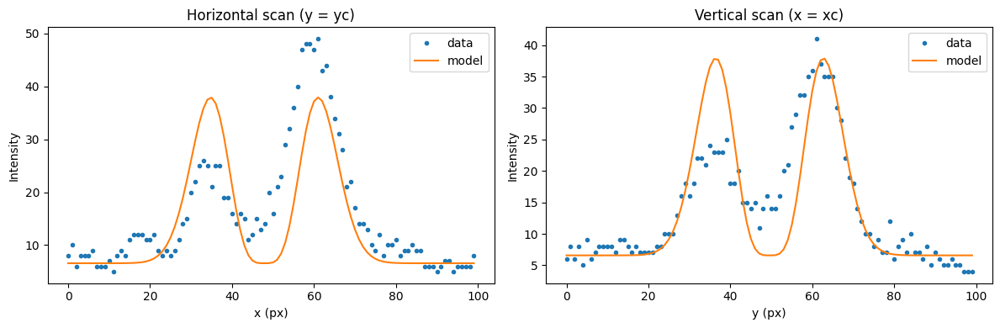

Params: {'A': 0.007884131009993021, 'w': 9.488957477268888, 'xc': 47.642421581623935, 'yc': 49.42273530107579, 'B': 4.421864438835958}
Uncertainties: {'A': 9.960478470065228e-05, 'w': 0.02228643804212145, 'xc': 0.04894059669620138, 'yc': 0.048940596703900434, 'B': 0.05306039359715849}
RMSE: 4.8005838688917075 R^2: 0.7615465897861134


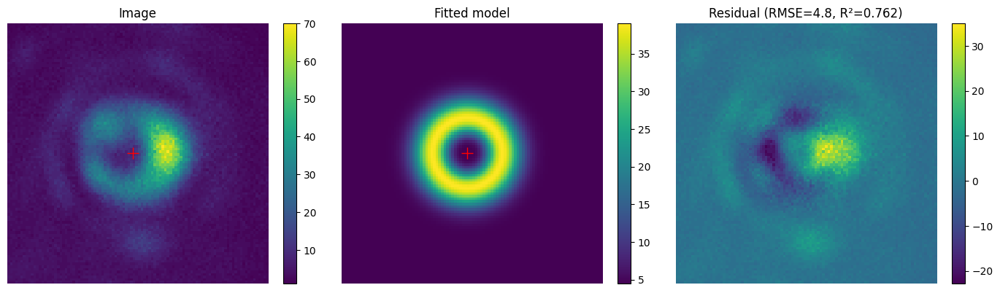

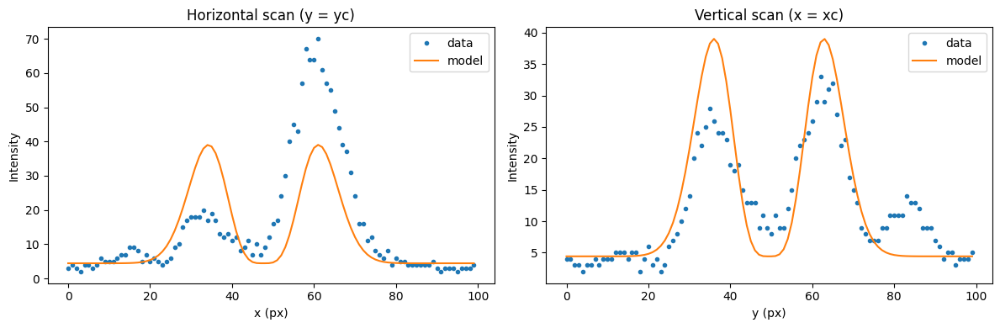

Params: {'A': 0.006235070747996176, 'w': 9.564505234286674, 'xc': 47.691388744004996, 'yc': 48.802745275500236, 'B': 5.689262968924388}
Uncertainties: {'A': 6.496287115242345e-05, 'w': 0.01853246675174755, 'xc': 0.040682789701277096, 'yc': 0.04068278968969091, 'B': 0.036069844386085556}
RMSE: 3.2576101934653243 R^2: 0.8240160923230798


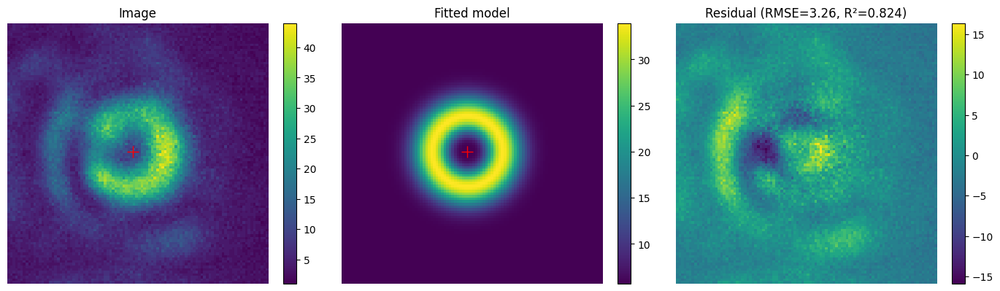

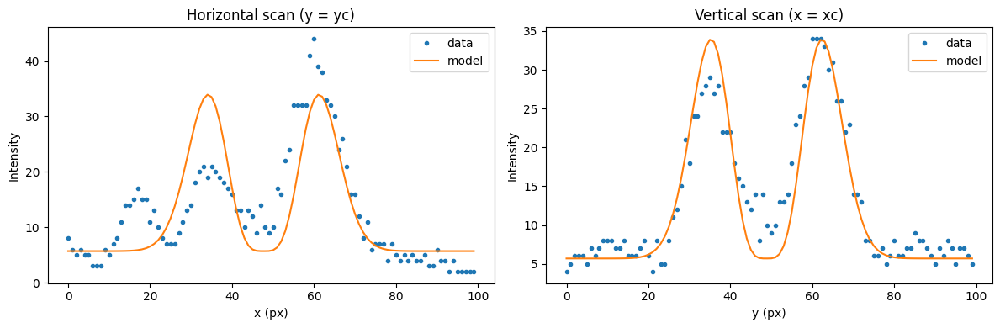

Params: {'A': 0.007296426835593314, 'w': 9.415919497523252, 'xc': 47.759437244043404, 'yc': 49.080782821508684, 'B': 5.938331936245824}
Uncertainties: {'A': 7.928926750421947e-05, 'w': 0.019015977802049094, 'xc': 0.04177258020163613, 'yc': 0.0417725802044689, 'B': 0.040568690486367444}
RMSE: 3.676625948808295 R^2: 0.8123234485256974


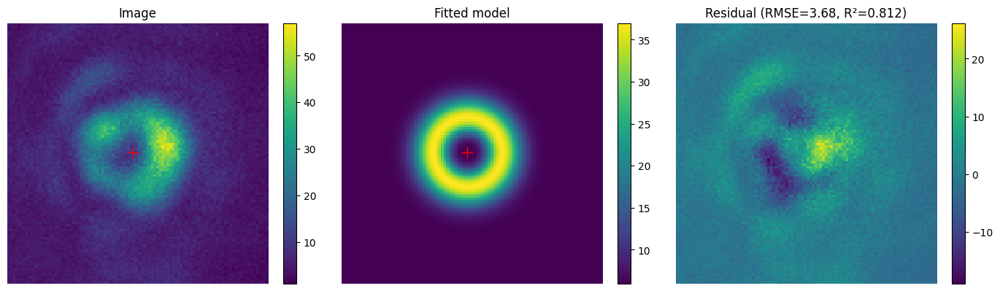

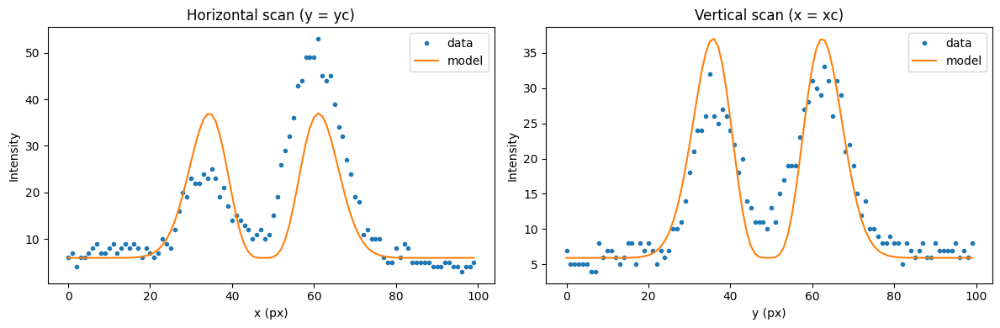

Params: {'A': 0.006575767255327078, 'w': 9.32471068118263, 'xc': 47.0380862171094, 'yc': 49.57642428710576, 'B': 5.27084539628499}
Uncertainties: {'A': 6.965687989991469e-05, 'w': 0.01834964217766179, 'xc': 0.04032527528978415, 'yc': 0.0403252752904592, 'B': 0.03387641632902462}
RMSE: 3.0765374394594365 R^2: 0.8204784259173139


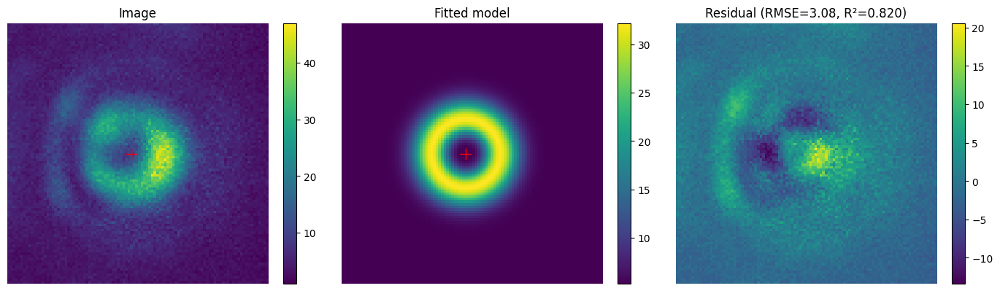

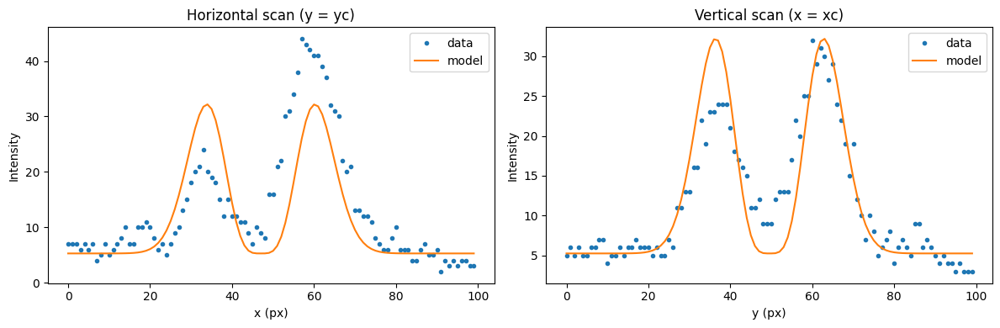

writing phase
Params: {'A': 0.007967558148084065, 'w': 9.3623819809409, 'xc': 48.838524801334145, 'yc': 49.21963937769341, 'B': 3.7229993504217775}
Uncertainties: {'A': 6.773204603839728e-05, 'w': 0.014787771691014067, 'xc': 0.03249224358858521, 'yc': 0.03249224358754536, 'B': 0.03363995292940629}
RMSE: 3.052441391440304 R^2: 0.8763410886496705


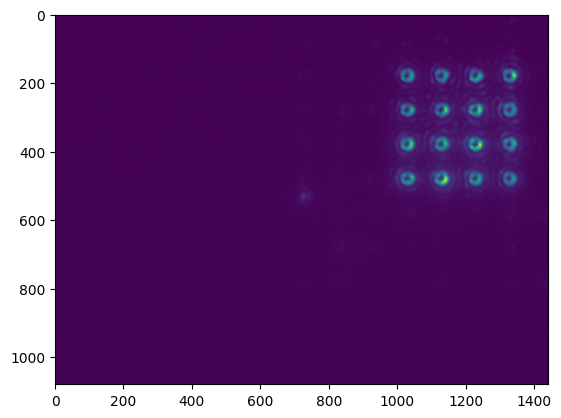

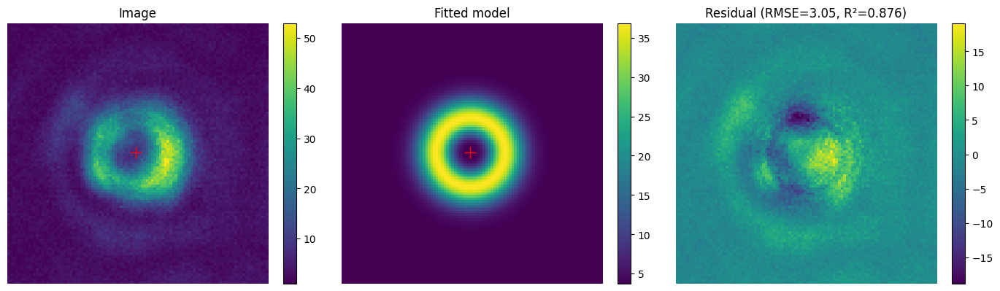

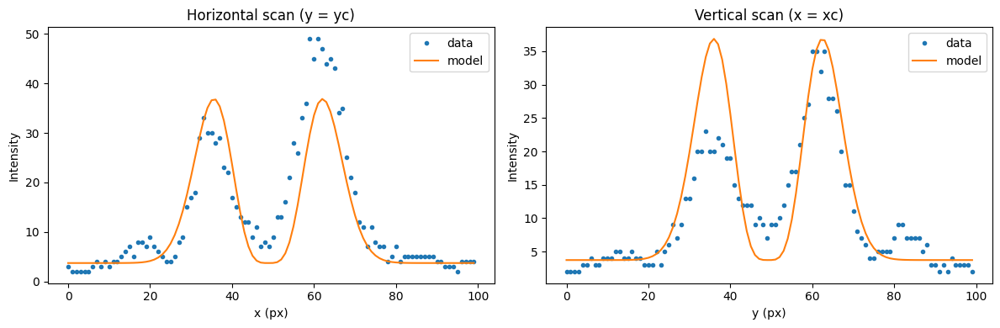

Params: {'A': 0.007825296265479469, 'w': 9.284004088934436, 'xc': 49.02243421531577, 'yc': 49.169196825861, 'B': 4.454480483641433}
Uncertainties: {'A': 8.1338821218965e-05, 'w': 0.017923754985360755, 'xc': 0.03939642368110895, 'yc': 0.039396423684764786, 'B': 0.03866612785196237}
RMSE: 3.5147613960231388 R^2: 0.8262002715754304


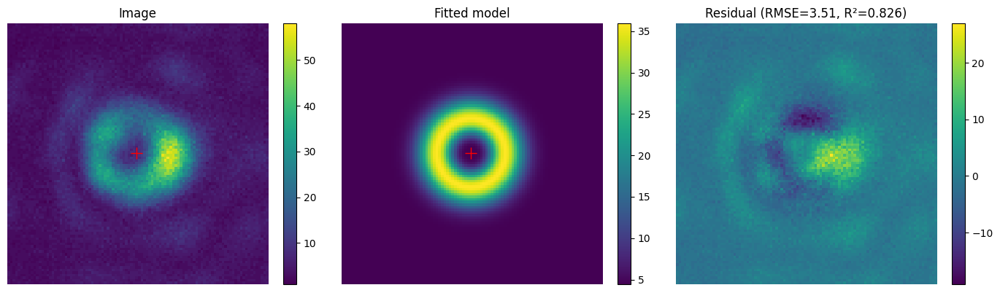

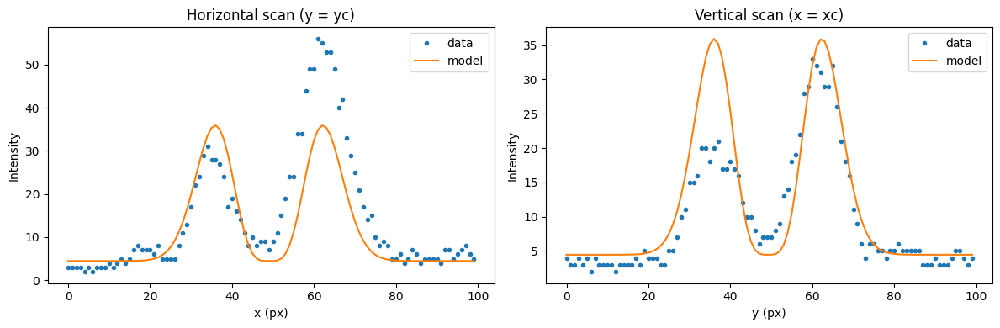

Params: {'A': 0.009808650465705351, 'w': 9.295691401315764, 'xc': 48.737035614419405, 'yc': 49.24411377505796, 'B': 5.926898447030113}
Uncertainties: {'A': 9.81195637817647e-05, 'w': 0.017272173259464365, 'xc': 0.03796229316361232, 'yc': 0.03796229316714516, 'B': 0.04694993556565379}
RMSE: 4.266634637770157 R^2: 0.8368790611604658


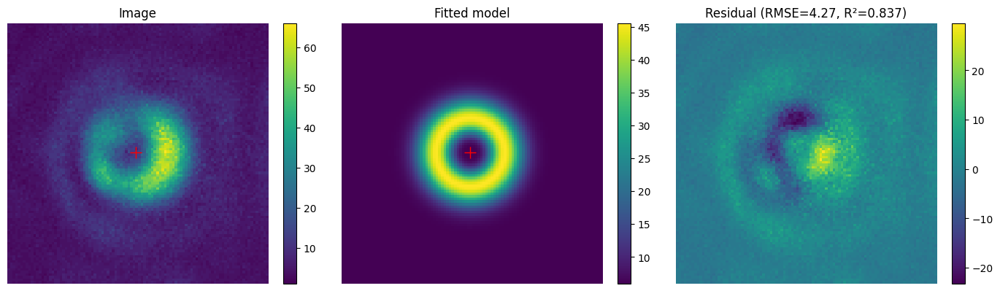

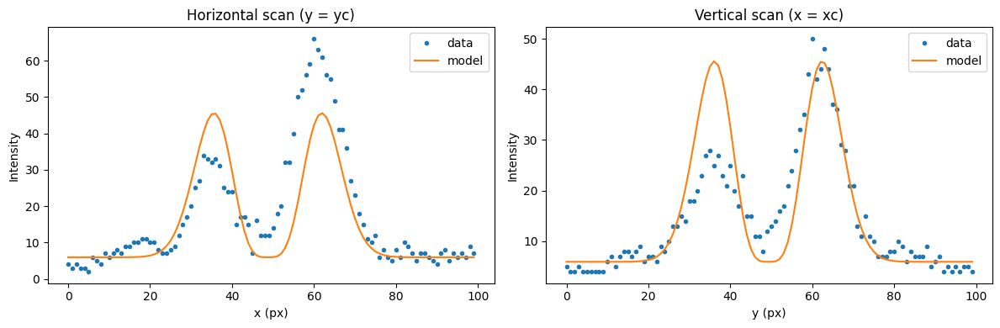

Params: {'A': 0.007750353351248421, 'w': 9.443263072691233, 'xc': 49.40746622865747, 'yc': 49.48052354371283, 'B': 5.858703231209967}
Uncertainties: {'A': 7.696214103486845e-05, 'w': 0.01742942939874637, 'xc': 0.03828266096553105, 'yc': 0.03828266096745538, 'B': 0.03997832941341542}
RMSE: 3.6208367277163847 R^2: 0.8381394009685827


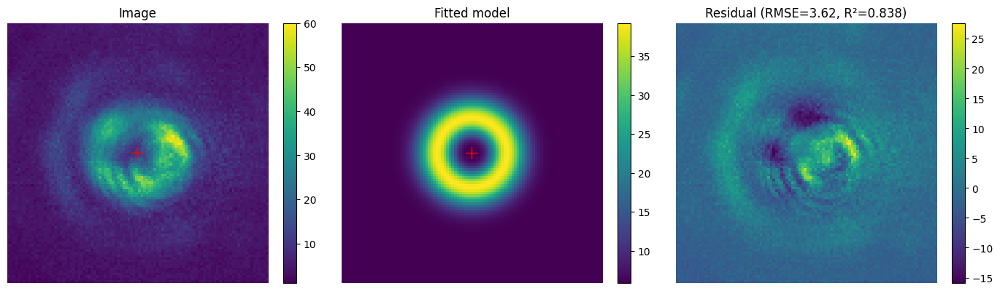

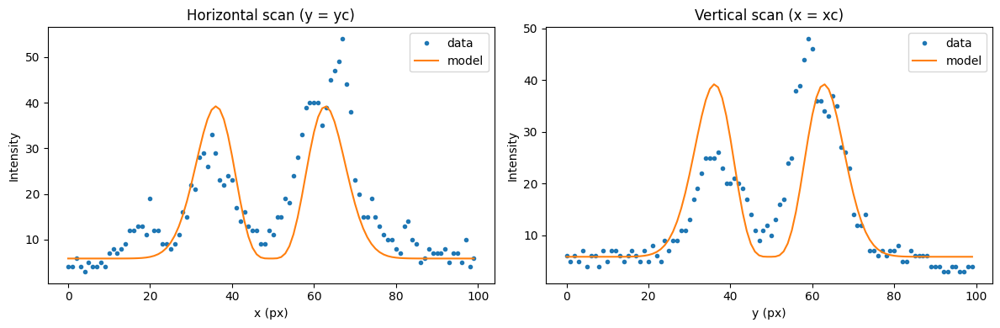

Params: {'A': 0.006430335303522242, 'w': 9.433439442815459, 'xc': 48.89063109794298, 'yc': 49.15525763057802, 'B': 4.2887957073380365}
Uncertainties: {'A': 6.421492120207266e-05, 'w': 0.017508886291564912, 'xc': 0.038458894072586146, 'yc': 0.03845889408457617, 'B': 0.033176052868074846}
RMSE: 3.005437089384635 R^2: 0.8366549262272063


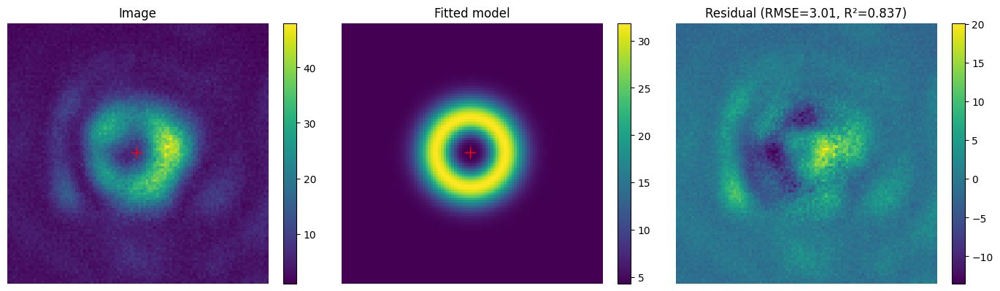

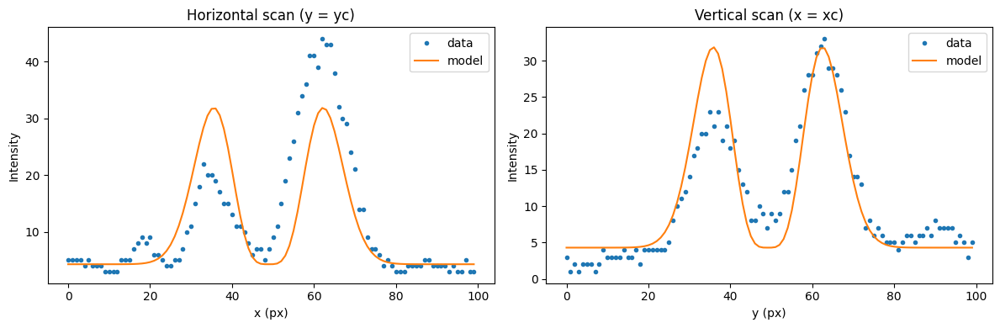

Params: {'A': 0.1277020099567072, 'w': 5.031997943153277, 'xc': 60.5145809966092, 'yc': 50.05123148194189, 'B': 7.499372228820114}
Uncertainties: {'A': 0.0033687613536938993, 'w': 0.024343614699736192, 'xc': 0.054192272021432036, 'yc': 0.05419227202619702, 'B': 0.06991155898270217}
RMSE: 6.809165328242917 R^2: 0.4523638944586458


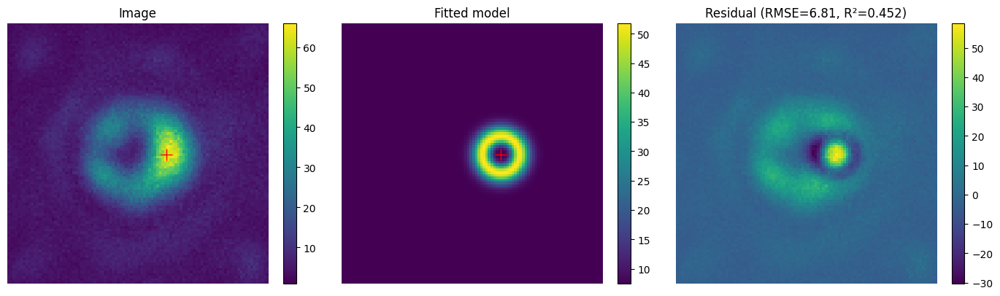

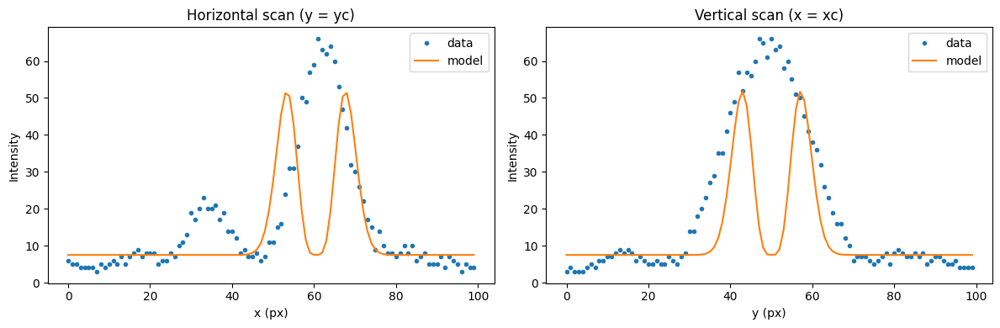

Params: {'A': 0.008294752746763953, 'w': 9.35557486832613, 'xc': 48.5067771280635, 'yc': 48.72451147006731, 'B': 6.791529895570776}
Uncertainties: {'A': 7.94405439208104e-05, 'w': 0.016647287475398558, 'xc': 0.03657915204731891, 'yc': 0.03657915203933855, 'B': 0.03930578598929831}
RMSE: 3.567105549654898 R^2: 0.8481378192390097


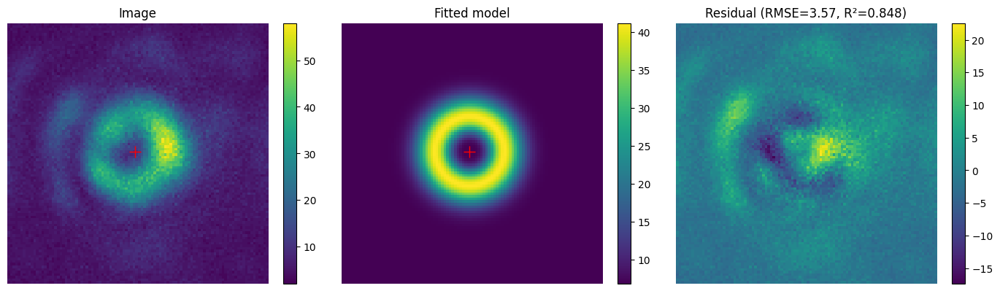

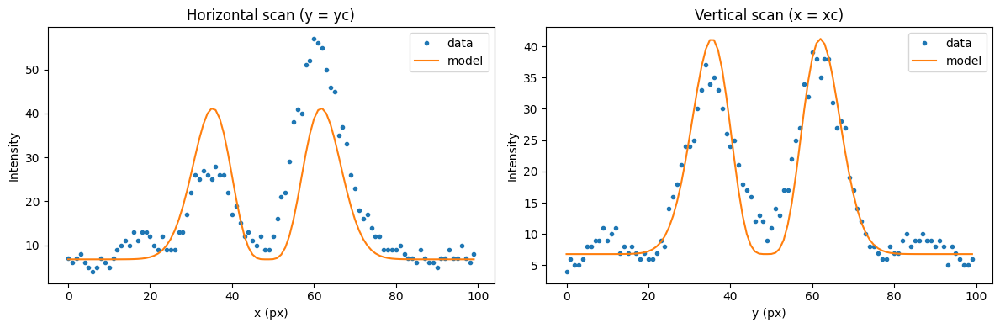

Params: {'A': 0.009420916794969385, 'w': 9.557079789165478, 'xc': 48.75263727593675, 'yc': 49.432318341435206, 'B': 6.976203940518472}
Uncertainties: {'A': 0.00010821678273937249, 'w': 0.02041543371811496, 'xc': 0.04481785353876953, 'yc': 0.04481785352705918, 'B': 0.05984270816686621}
RMSE: 5.405576721265861 R^2: 0.7939533745816425


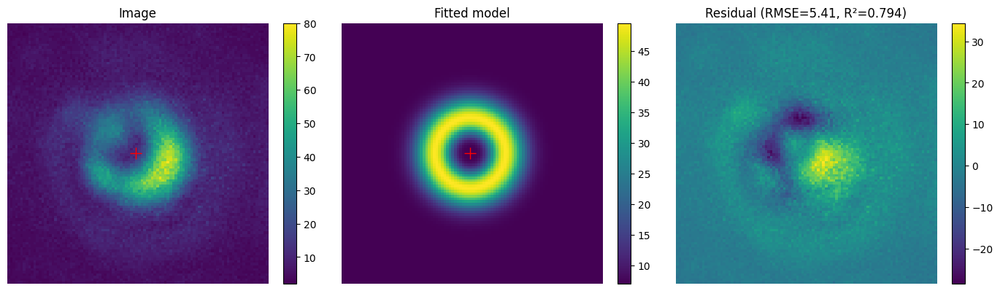

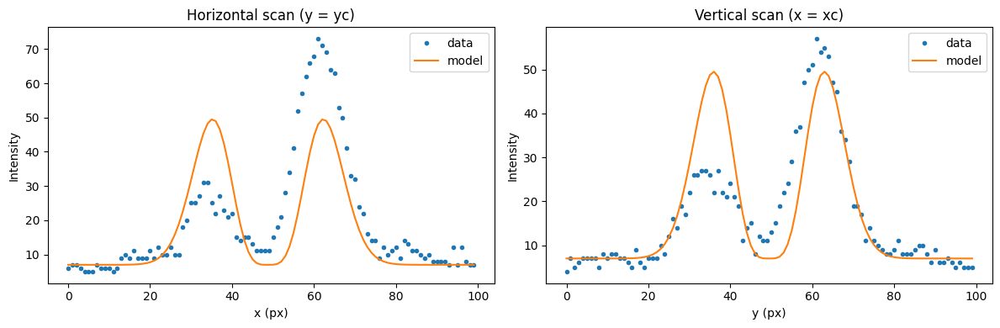

Params: {'A': 0.008617318265026125, 'w': 9.109167548097215, 'xc': 48.27167129429796, 'yc': 49.54478951630411, 'B': 4.319085033287331}
Uncertainties: {'A': 9.934097680213348e-05, 'w': 0.019489605785525124, 'xc': 0.0428705814799469, 'yc': 0.042870581481052716, 'B': 0.04277463717775056}
RMSE: 3.9034015987363126 R^2: 0.7954615621489927


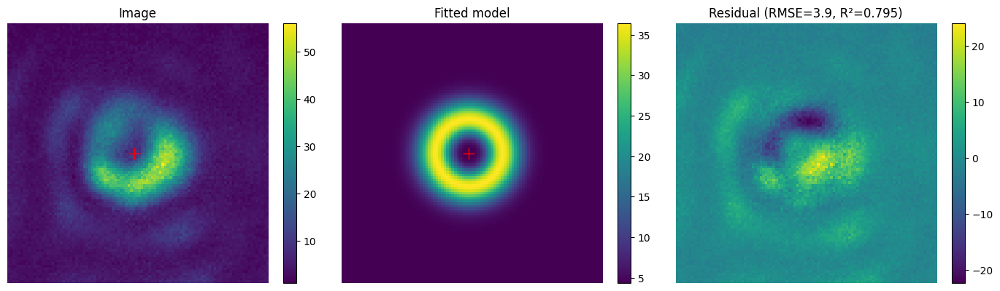

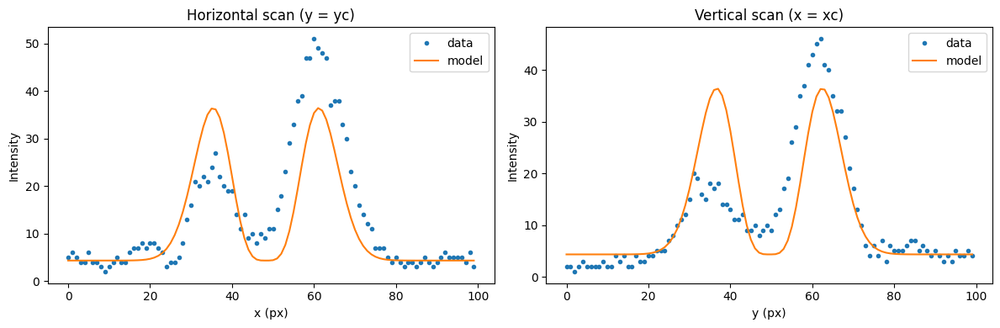

Params: {'A': 0.009944995972716867, 'w': 9.176862261148894, 'xc': 48.15567306932751, 'yc': 49.21604608779585, 'B': 6.358130180224242}
Uncertainties: {'A': 0.00010979306262390928, 'w': 0.018808687223596597, 'xc': 0.041360796390117194, 'yc': 0.04136079638220953, 'B': 0.04913150515854035}
RMSE: 4.476796201452619 R^2: 0.8088055361527109


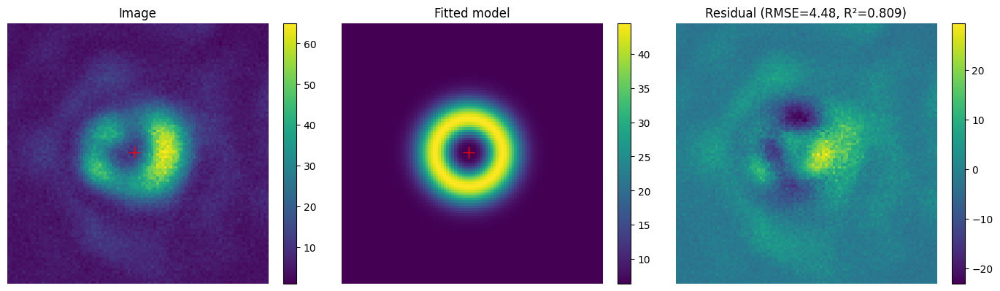

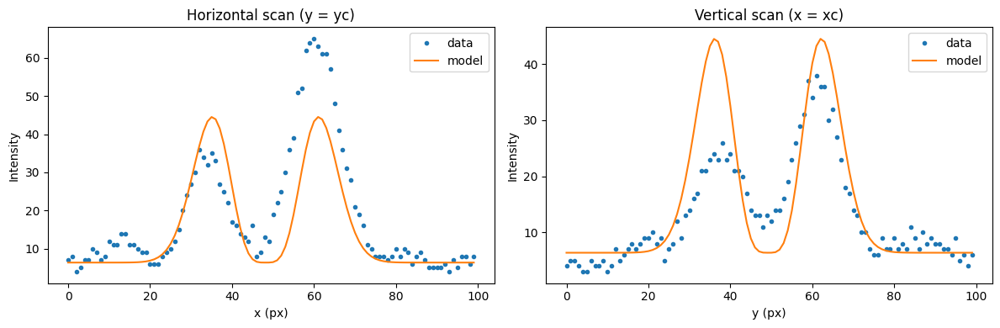

Params: {'A': 0.00991705377528937, 'w': 9.468166067120334, 'xc': 48.27784936136599, 'yc': 49.46473976146762, 'B': 7.067015952876649}
Uncertainties: {'A': 9.97323679627099e-05, 'w': 0.017700026487965467, 'xc': 0.03887261168990328, 'yc': 0.0388726116939006, 'B': 0.05252344519301791}
RMSE: 4.754302622641379 R^2: 0.8345470731412413


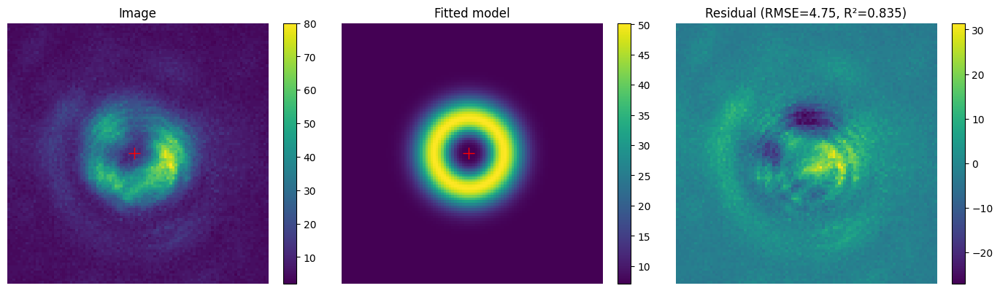

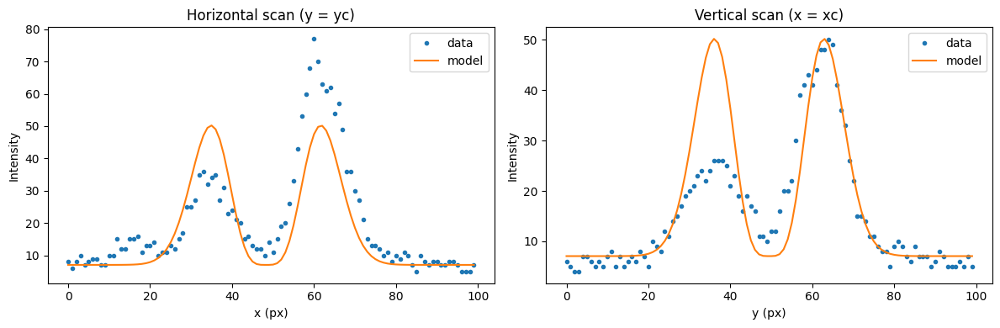

Params: {'A': 0.008311592522712715, 'w': 9.229420544119227, 'xc': 47.86612153008441, 'yc': 49.46008047377868, 'B': 6.471669472695916}
Uncertainties: {'A': 8.03032504590802e-05, 'w': 0.016558316280878164, 'xc': 0.03640388278202881, 'yc': 0.036403882773441976, 'B': 0.03701932230820564}
RMSE: 3.3691989726300644 R^2: 0.8464618984326847


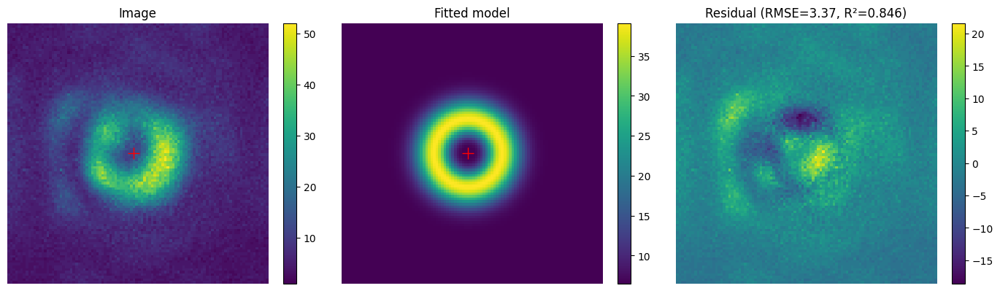

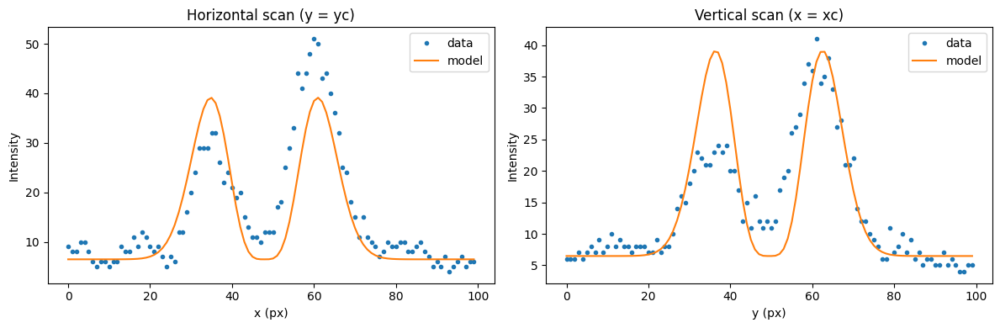

Params: {'A': 0.008348899264404384, 'w': 9.428906835170437, 'xc': 47.670021505489004, 'yc': 49.30639076502833, 'B': 4.346414749727792}
Uncertainties: {'A': 9.736480643419606e-05, 'w': 0.02043672717617196, 'xc': 0.044890921386684345, 'yc': 0.04489092138064243, 'B': 0.050176654521163905}
RMSE: 4.546006852578222 R^2: 0.7897572301588212


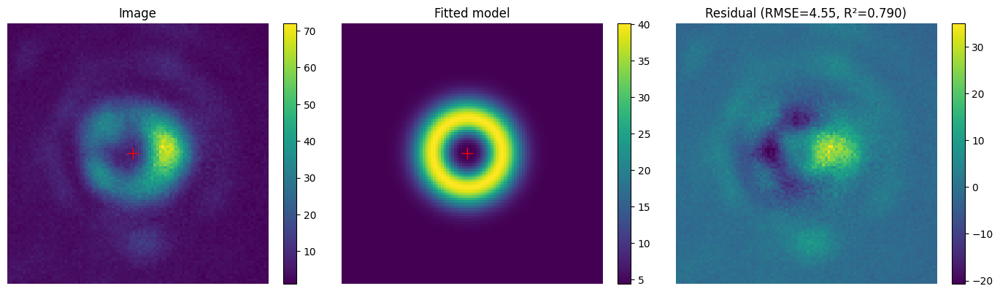

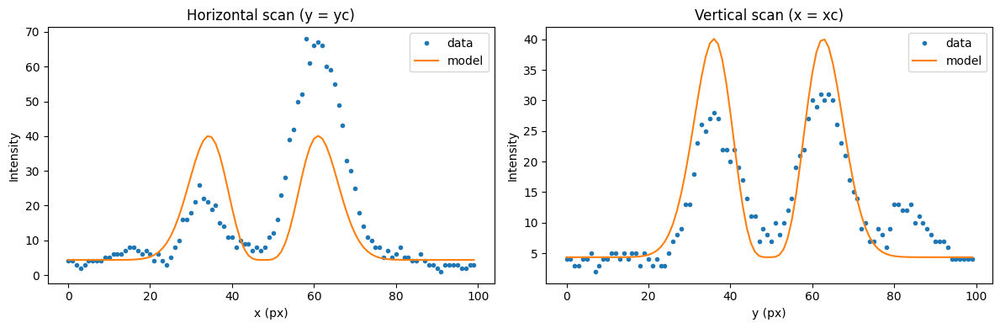

Params: {'A': 0.006672363130688942, 'w': 9.504249932551526, 'xc': 47.66802053515391, 'yc': 48.829441398179064, 'B': 5.595641986346716}
Uncertainties: {'A': 6.268065896876912e-05, 'w': 0.01659961190552982, 'xc': 0.036449881360233305, 'yc': 0.03644988135770673, 'B': 0.03367250757532107}
RMSE: 3.045398671040454 R^2: 0.8523512834570572


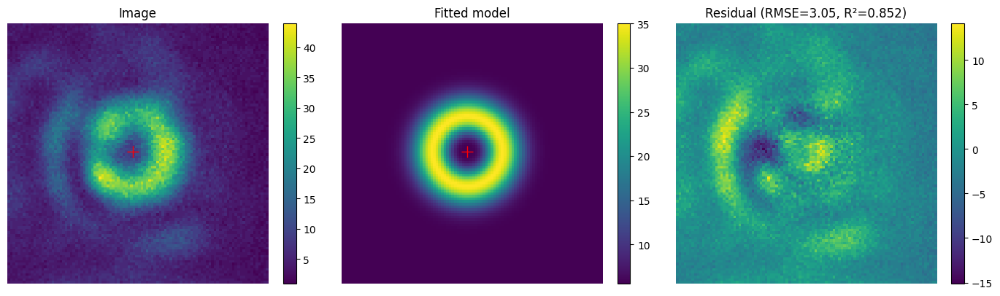

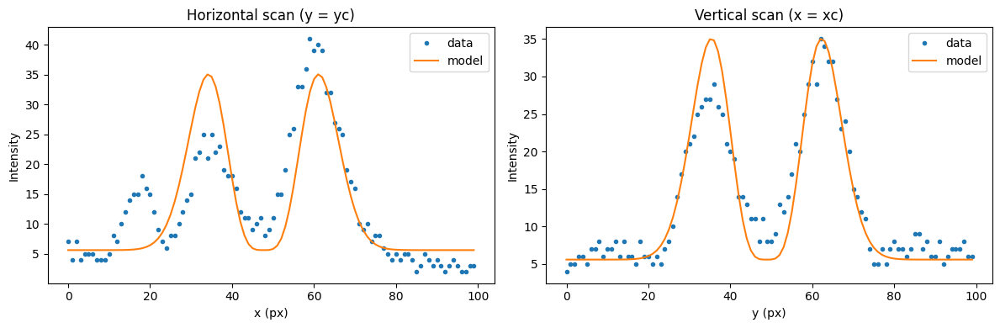

Params: {'A': 0.007633817671065837, 'w': 9.385351273698182, 'xc': 47.723318253618295, 'yc': 49.0049965280574, 'B': 5.870780031056046}
Uncertainties: {'A': 7.616587132322386e-05, 'w': 0.017400479636781867, 'xc': 0.03822905430881747, 'yc': 0.038229054310265784, 'B': 0.038315176636953774}
RMSE: 3.4748369651147595 R^2: 0.8371391484832859


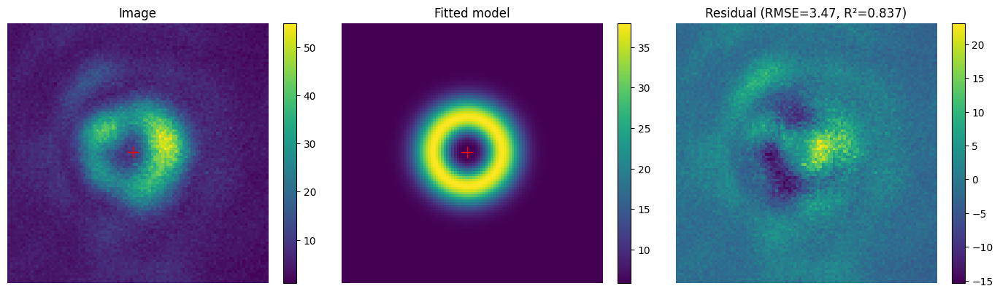

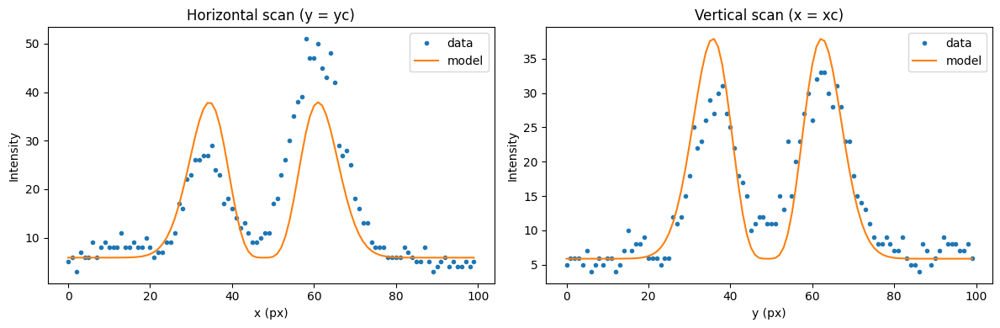

Params: {'A': 0.007063169480366647, 'w': 9.255590326111815, 'xc': 47.1023584296245, 'yc': 49.52745962166363, 'B': 5.187499783558254}
Uncertainties: {'A': 6.737504221050543e-05, 'w': 0.016396305617713366, 'xc': 0.03604358141534209, 'yc': 0.03604358141063937, 'B': 0.031520843695666996}
RMSE: 2.8670880194281785 R^2: 0.8496331528923642


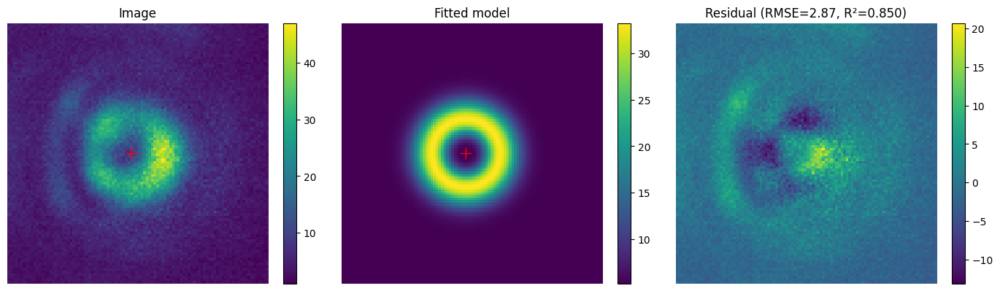

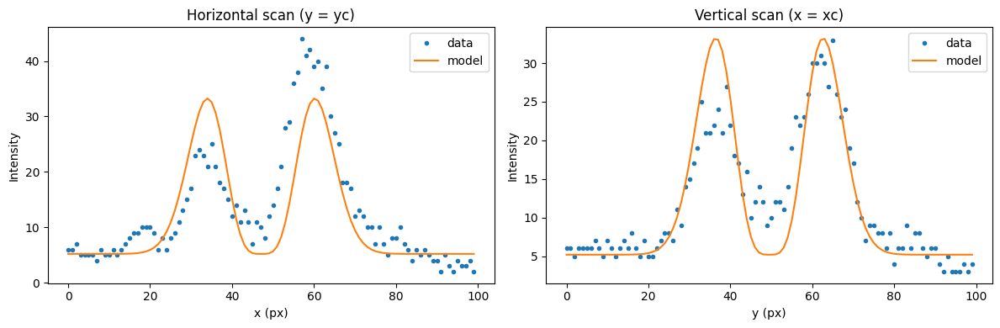

writing phase
Params: {'A': 0.00857042731593687, 'w': 9.280980653079176, 'xc': 48.9445216455022, 'yc': 49.1155780351984, 'B': 3.6504176330380225}
Uncertainties: {'A': 6.622224985032358e-05, 'w': 0.01331944523769312, 'xc': 0.02927653762612189, 'yc': 0.029276537628022018, 'B': 0.03142677525511838}
RMSE: 2.85689728670754 R^2: 0.895871312396181


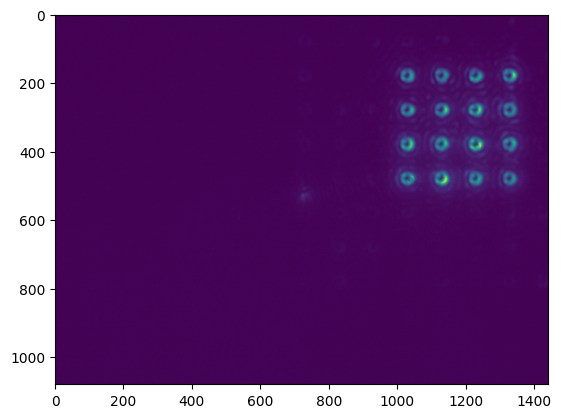

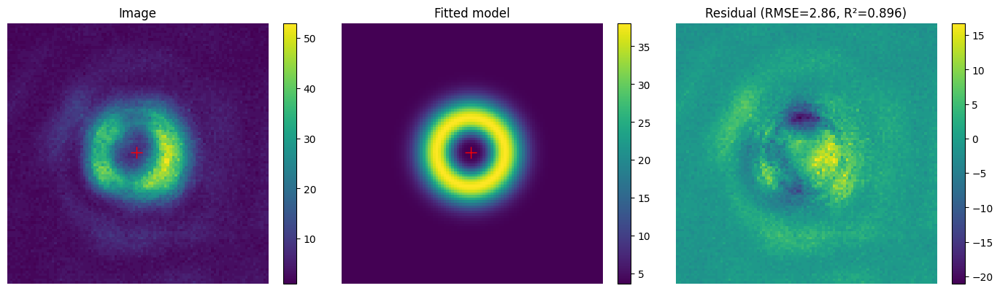

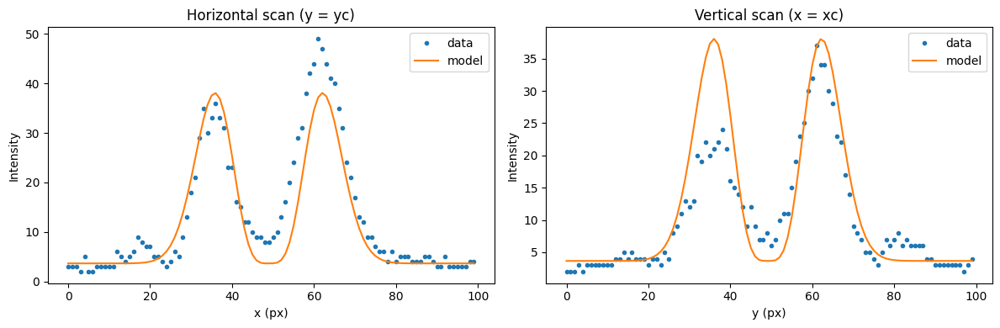

Params: {'A': 0.008316464433269699, 'w': 9.22449182751023, 'xc': 49.243714633751225, 'yc': 49.04074064746704, 'B': 4.398012117459352}
Uncertainties: {'A': 7.865050125758445e-05, 'w': 0.01619902043342415, 'xc': 0.035614725530092, 'yc': 0.035614725531986524, 'B': 0.03615671764152254}
RMSE: 3.2910547348258343 R^2: 0.8519601613464084


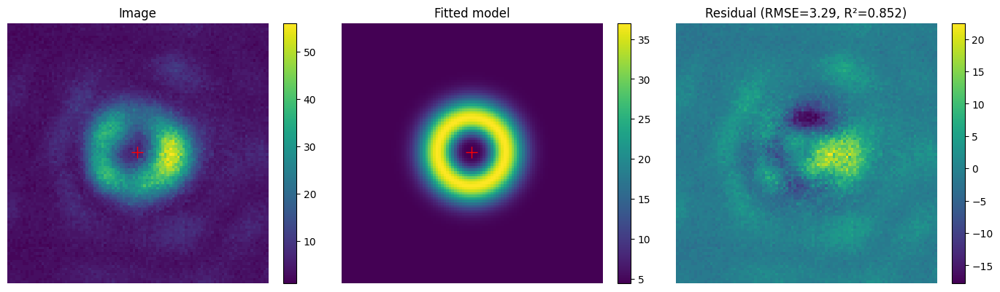

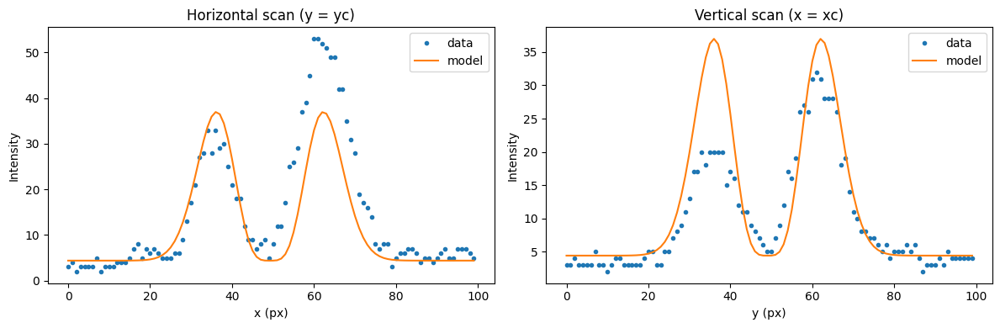

Params: {'A': 0.010607836705650117, 'w': 9.197153486194754, 'xc': 48.87754868007271, 'yc': 49.11853161081796, 'B': 5.825079828147224}
Uncertainties: {'A': 9.583343999734306e-05, 'w': 0.015426795571584303, 'xc': 0.033920955508374005, 'yc': 0.033920955508150594, 'B': 0.04338048462257104}
RMSE: 3.9509870587446883 R^2: 0.8632509893297778


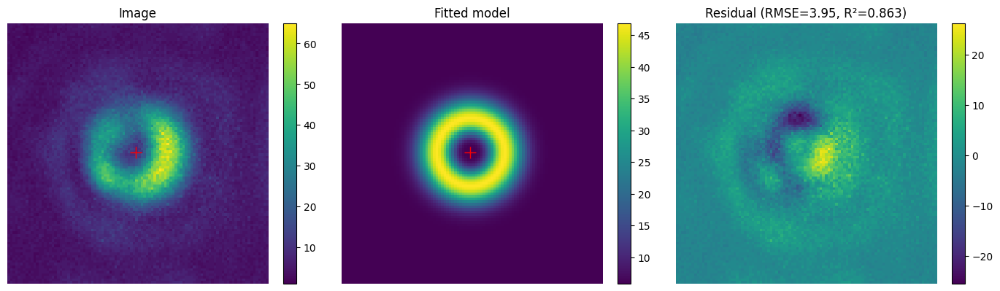

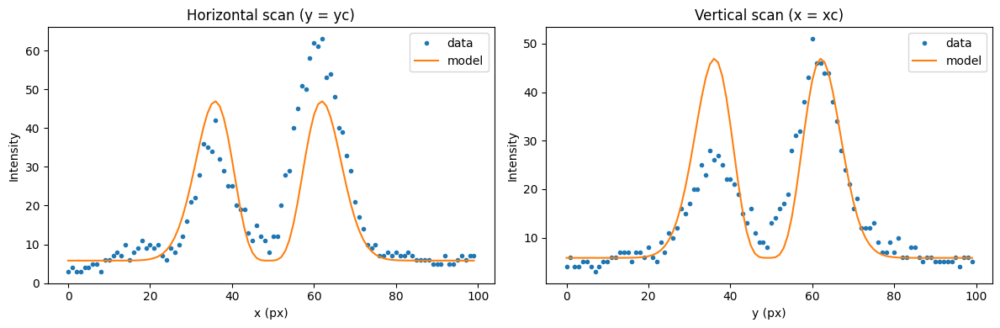

Params: {'A': 0.00819756252543556, 'w': 9.390662616373296, 'xc': 49.566785418269006, 'yc': 49.32281778604443, 'B': 5.802826464137479}
Uncertainties: {'A': 7.550580319277077e-05, 'w': 0.01607289970369794, 'xc': 0.03531150456379125, 'yc': 0.03531150455616034, 'B': 0.03809536992522493}
RMSE: 3.454481557046569 R^2: 0.8577593933457052


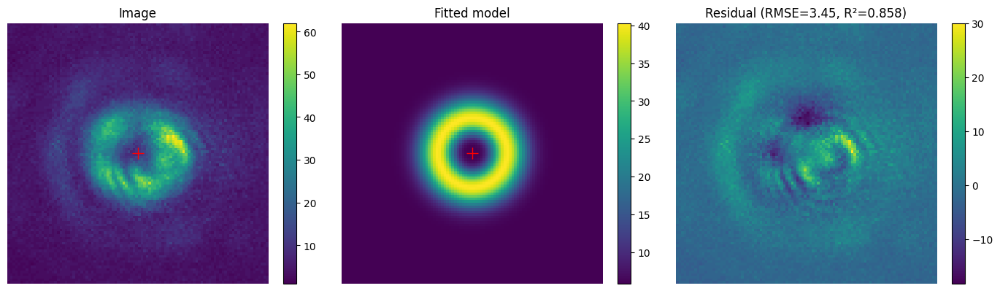

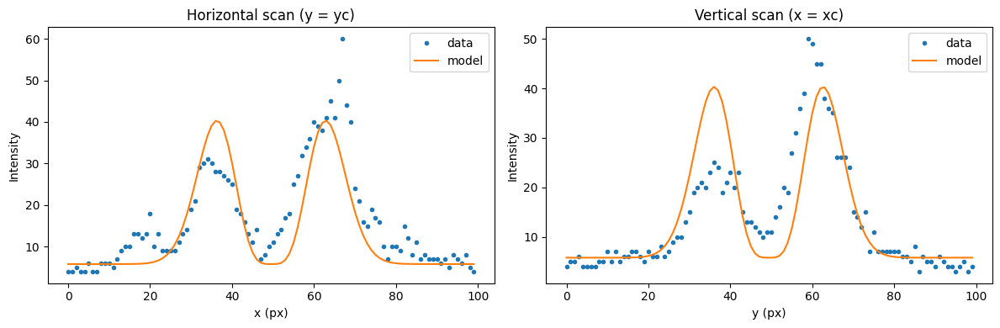

Params: {'A': 0.006874803304619611, 'w': 9.359515399114578, 'xc': 48.947797893513716, 'yc': 49.01708915843947, 'B': 4.169042634547368}
Uncertainties: {'A': 6.0617439360238715e-05, 'w': 0.015333190926234839, 'xc': 0.033691090152710275, 'yc': 0.03369109015388364, 'B': 0.03005836569727165}
RMSE: 2.7276318989823873 R^2: 0.8682138174850992


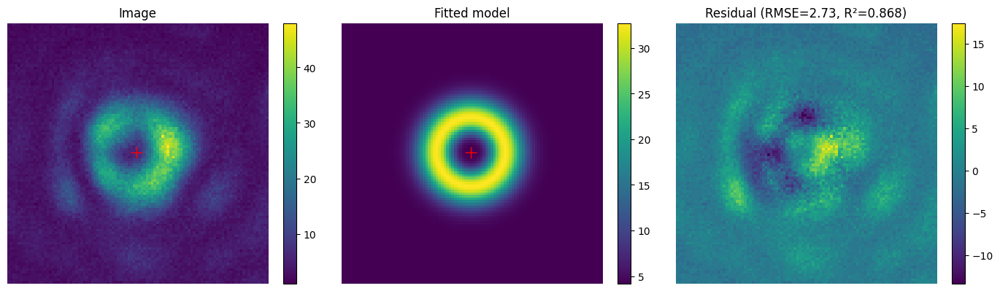

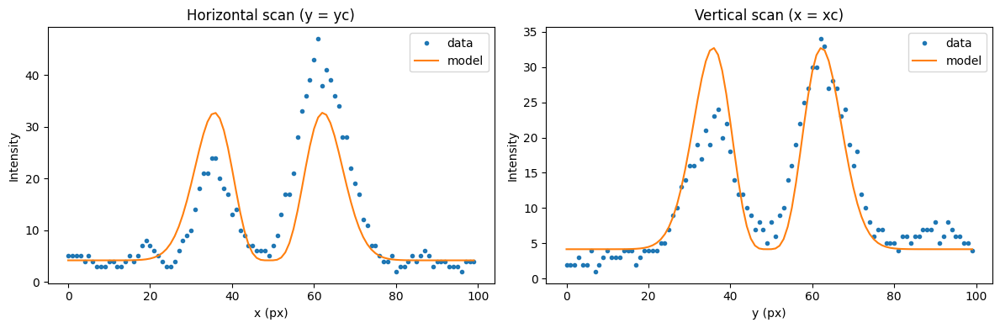

Params: {'A': 0.008262448243002795, 'w': 9.329814634204054, 'xc': 49.37304187541023, 'yc': 49.14828476755306, 'B': 5.417355530730093}
Uncertainties: {'A': 9.493827537830399e-05, 'w': 0.019915447988608382, 'xc': 0.04376530832077567, 'yc': 0.043765308304825494, 'B': 0.04630345651832594}
RMSE: 4.204629882291245 R^2: 0.7952348687781385


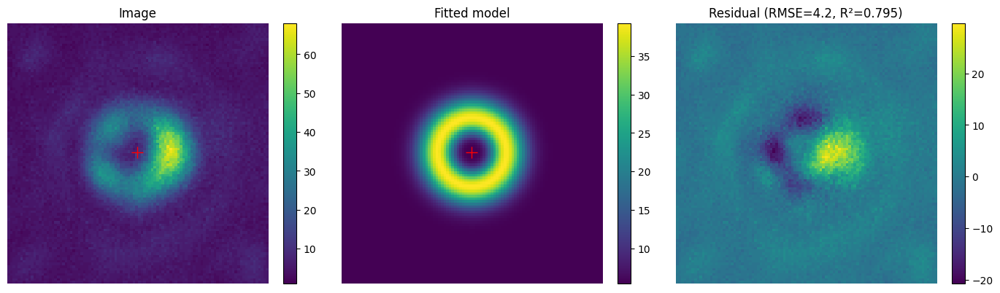

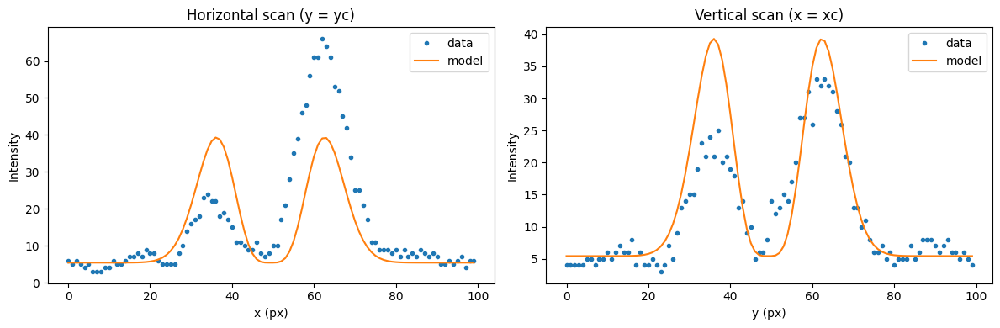

Params: {'A': 0.008918260817874607, 'w': 9.283351974781311, 'xc': 48.67524372194195, 'yc': 48.55667950537921, 'B': 6.700150488005047}
Uncertainties: {'A': 7.687714595304838e-05, 'w': 0.014863368410691002, 'xc': 0.03266978606017452, 'yc': 0.03266978605995643, 'B': 0.036531805357854386}
RMSE: 3.3207998029862895 R^2: 0.8736104219410432


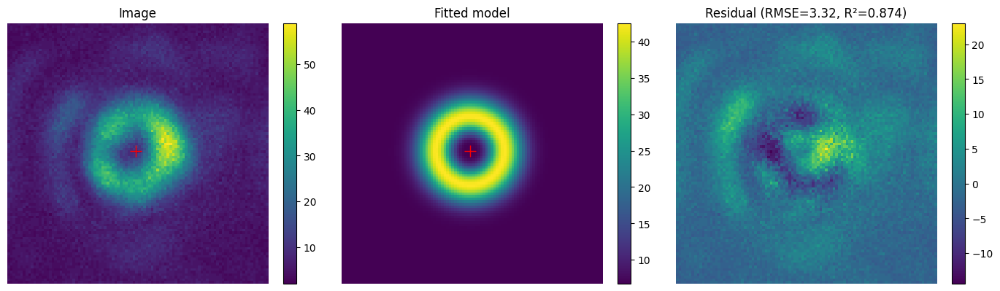

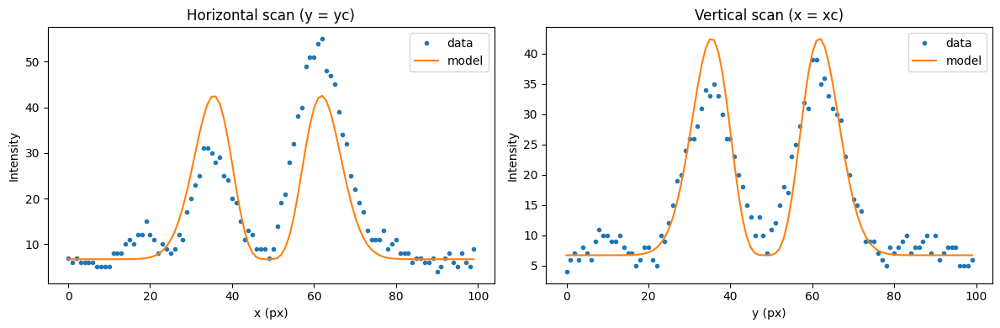

Params: {'A': 0.01002559188950489, 'w': 9.475483025187959, 'xc': 48.872783203703285, 'yc': 49.32574903901213, 'B': 6.921401380396572}
Uncertainties: {'A': 0.00010804472339209991, 'w': 0.018982961529798194, 'xc': 0.04168878989976386, 'yc': 0.04168878988797468, 'B': 0.0571310135630884}
RMSE: 5.170490087276295 R^2: 0.8145105578025995


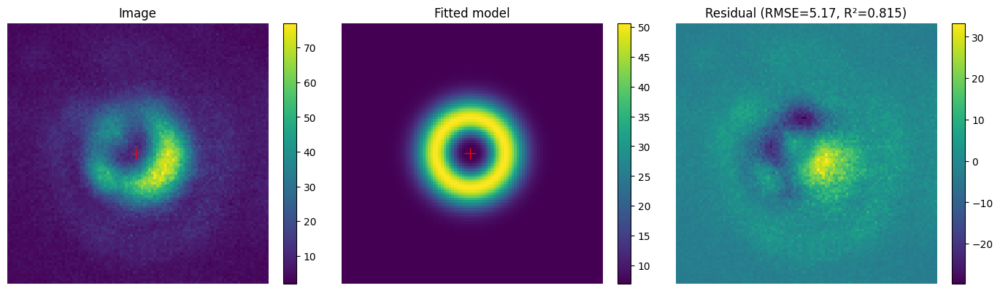

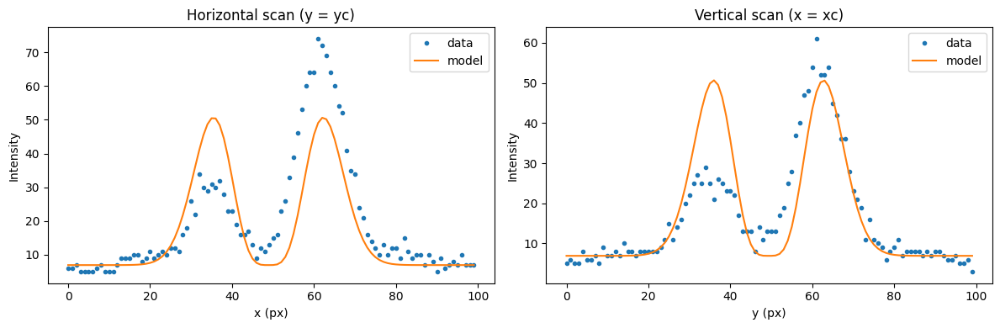

Params: {'A': 0.009091092238690292, 'w': 9.0616511500016, 'xc': 48.4165754424006, 'yc': 49.48700180751708, 'B': 4.228731309188092}
Uncertainties: {'A': 9.807237940692542e-05, 'w': 0.01813922133172729, 'xc': 0.039908221870124605, 'yc': 0.03990822186348452, 'B': 0.04109565284363296}
RMSE: 3.754090735471437 R^2: 0.8164670688569606


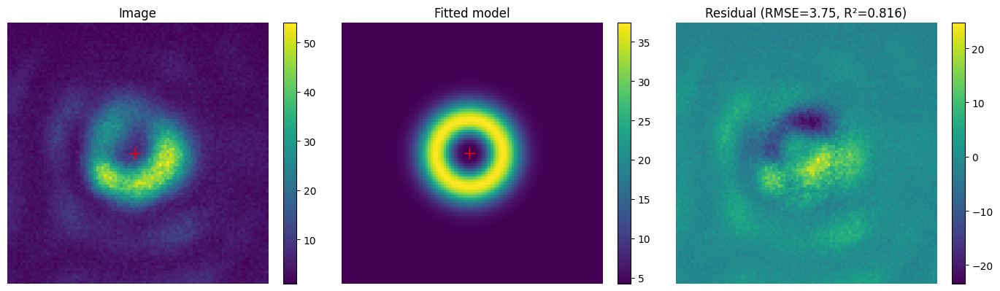

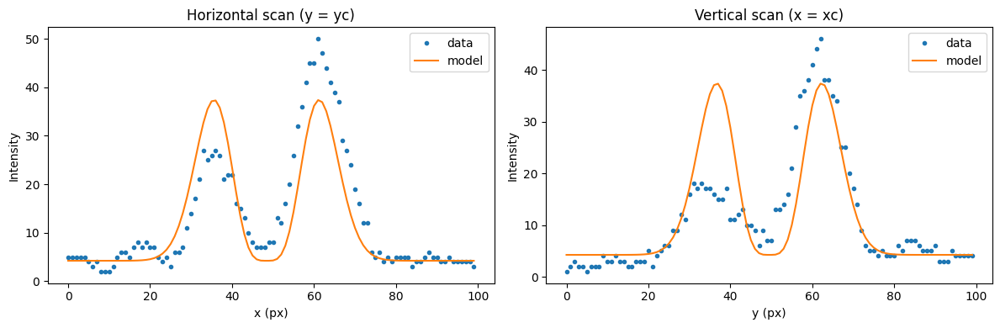

Params: {'A': 0.010700541255612173, 'w': 9.099585996315316, 'xc': 48.284518449928704, 'yc': 49.081851691765124, 'B': 6.307259273277006}
Uncertainties: {'A': 0.00010795043986788233, 'w': 0.01703690437548962, 'xc': 0.03747698933828394, 'yc': 0.03747698934811997, 'B': 0.04622805647127509}
RMSE: 4.219431521772946 R^2: 0.8355273368030937


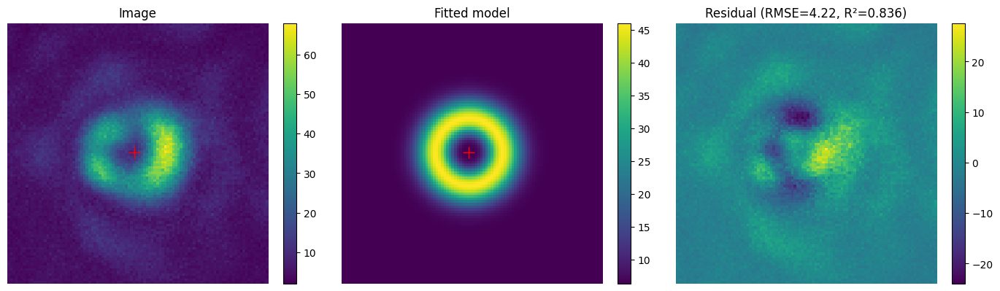

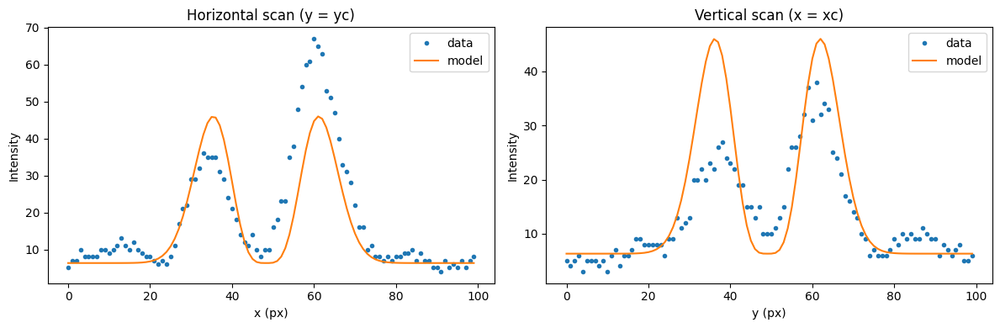

Params: {'A': 0.01050261274182475, 'w': 9.417133060392182, 'xc': 48.50597134084417, 'yc': 49.27162039098105, 'B': 6.948845948405702}
Uncertainties: {'A': 9.766049526379438e-05, 'w': 0.016274003542658014, 'xc': 0.03574906339342698, 'yc': 0.035749063392134954, 'B': 0.050002014280137834}
RMSE: 4.531414760324122 R^2: 0.8553041914324789


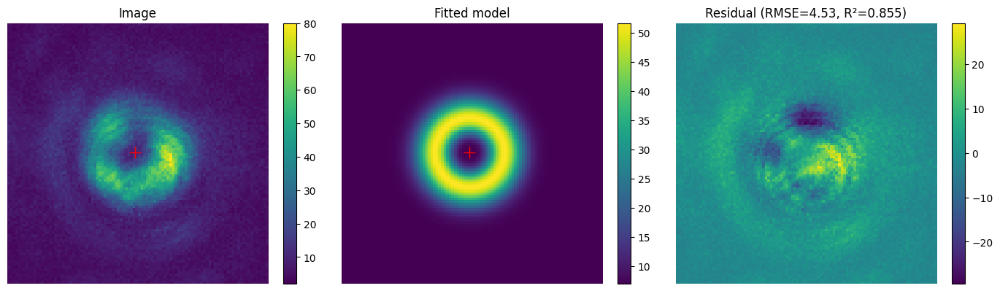

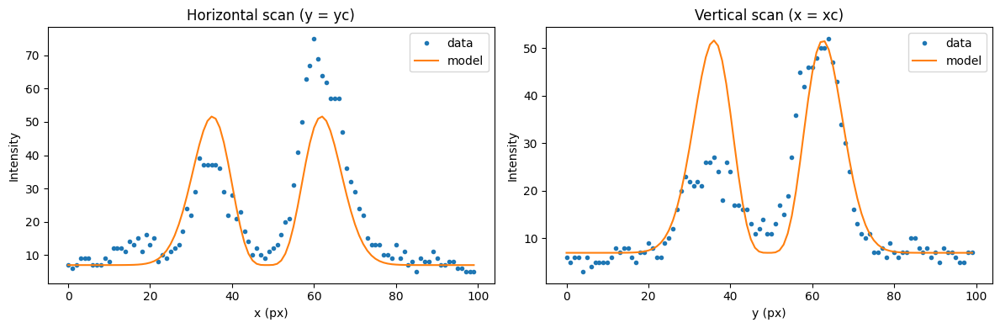

Params: {'A': 0.008851974284550703, 'w': 9.157489892517765, 'xc': 48.081532395443176, 'yc': 49.33834333070131, 'B': 6.398263320618792}
Uncertainties: {'A': 7.919994314940955e-05, 'w': 0.015209640928358564, 'xc': 0.033449186898536896, 'yc': 0.03344918689527268, 'B': 0.03505376022512756}
RMSE: 3.195423817563522 R^2: 0.865686434509986


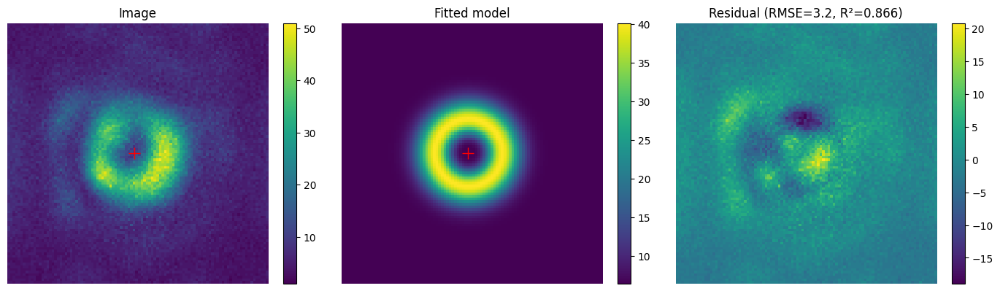

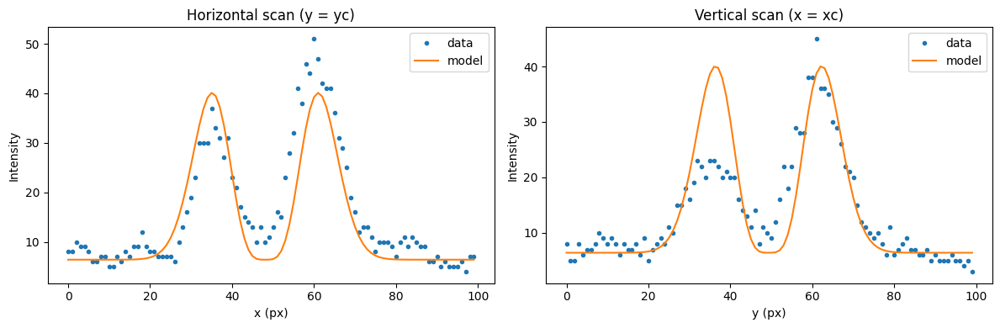

Params: {'A': 0.009000115307718813, 'w': 9.340743846867943, 'xc': 47.81097776978552, 'yc': 49.16228506338172, 'B': 4.267476686774136}
Uncertainties: {'A': 9.517499257307512e-05, 'w': 0.018351087229115975, 'xc': 0.04032558083149745, 'yc': 0.0403255808247855, 'B': 0.046703043023553464}
RMSE: 4.239860057470545 R^2: 0.8208954239022901


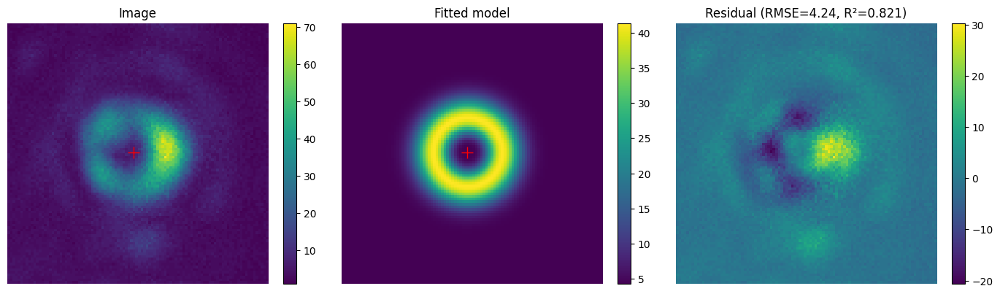

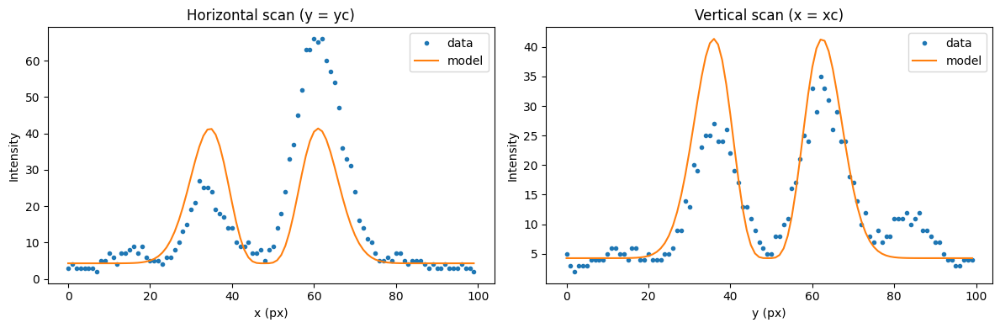

Params: {'A': 0.007232297048630425, 'w': 9.420840102274191, 'xc': 47.836840455914206, 'yc': 48.715063987632696, 'B': 5.539470404982925}
Uncertainties: {'A': 6.179279248615762e-05, 'w': 0.014959345418556695, 'xc': 0.03286060766096968, 'yc': 0.03286060766518138, 'B': 0.031702837663901196}
RMSE: 2.8728129082717033 R^2: 0.8750067817095842


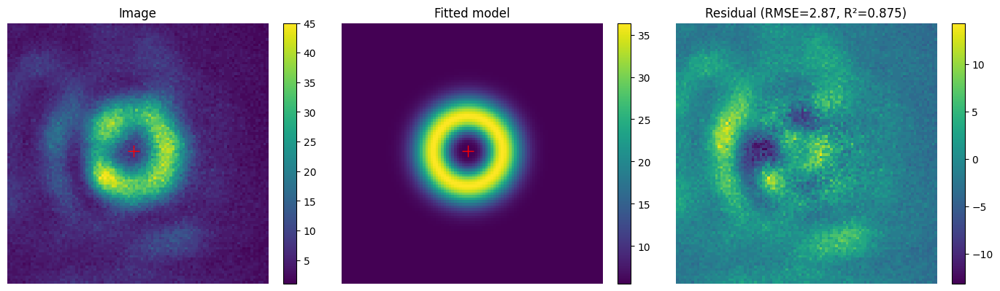

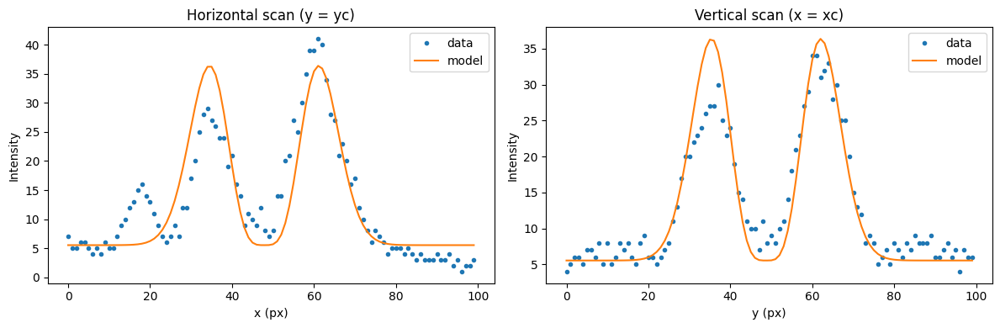

Params: {'A': 0.008143394195285076, 'w': 9.31362070970788, 'xc': 47.876087786466414, 'yc': 48.8700148154201, 'B': 5.831183390463026}
Uncertainties: {'A': 7.513736697208459e-05, 'w': 0.01596328928725319, 'xc': 0.0350827357696317, 'yc': 0.03508273577850784, 'B': 0.03631583121333987}
RMSE: 3.2989069699526503 R^2: 0.8576803740357014


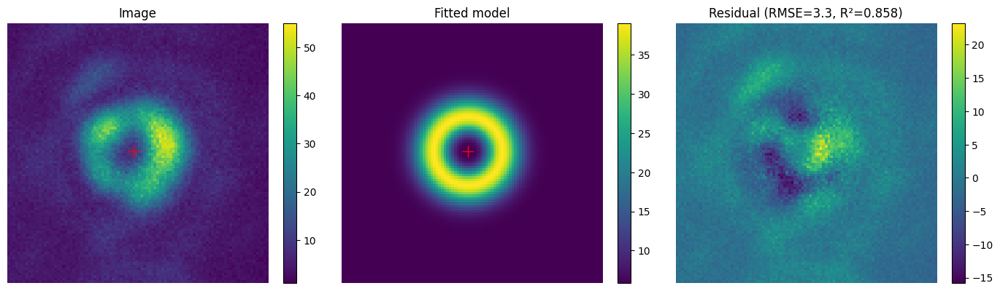

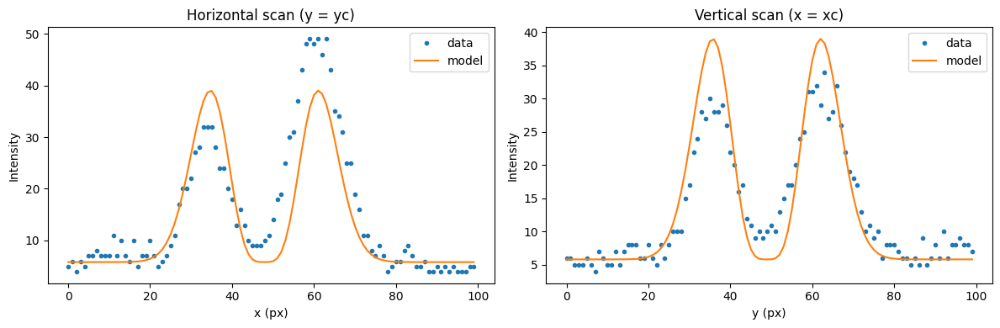

Params: {'A': 0.00749968137529321, 'w': 9.212190764539626, 'xc': 47.323595140611964, 'yc': 49.33336498188861, 'B': 5.113748742079979}
Uncertainties: {'A': 6.466116597588894e-05, 'w': 0.014747689164299515, 'xc': 0.03242560085676442, 'yc': 0.032425600874894614, 'B': 0.029519838325555648}
RMSE: 2.6876920286729447 R^2: 0.8738519183194149


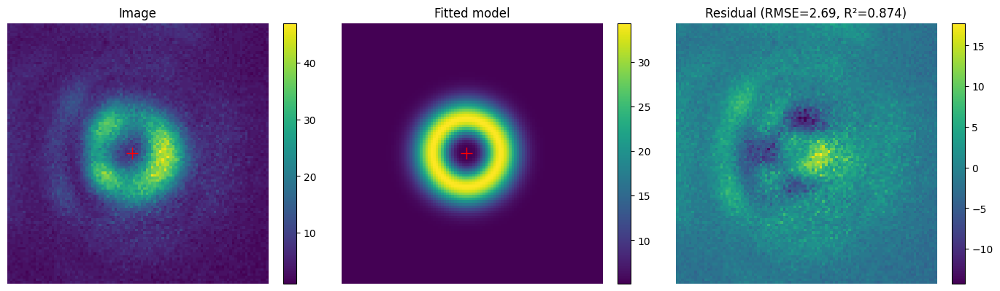

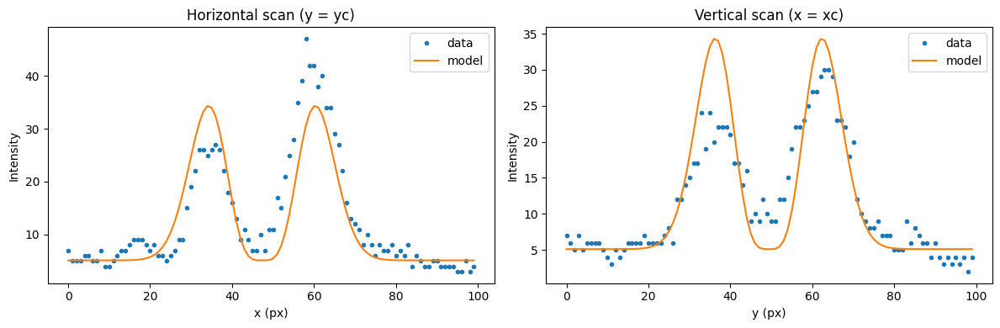

writing phase
Params: {'A': 0.009159959742098975, 'w': 9.205602534248865, 'xc': 48.963943480520584, 'yc': 49.00895737762673, 'B': 3.5883305860506134}
Uncertainties: {'A': 6.541185783274702e-05, 'w': 0.012205710606905373, 'xc': 0.026837343802052615, 'yc': 0.02683734380090656, 'B': 0.029751546443889897}
RMSE: 2.709186735750148 R^2: 0.9099126162186891


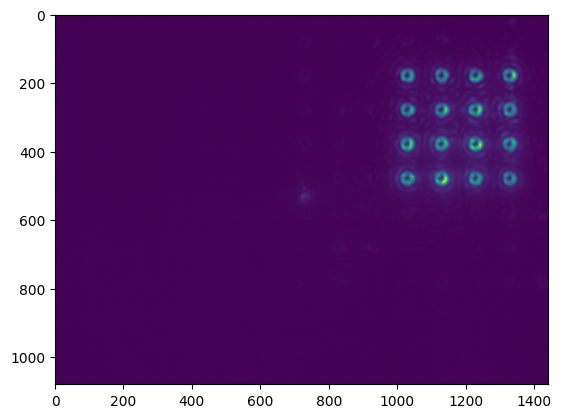

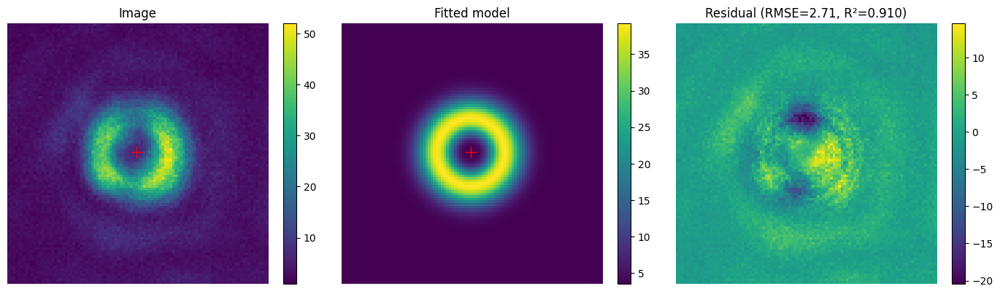

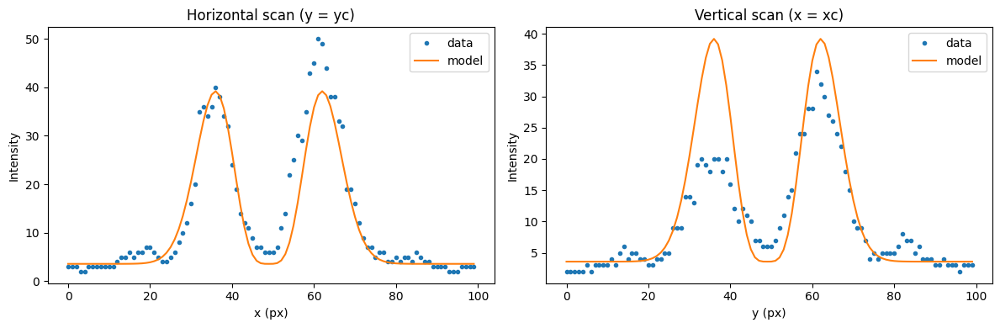

Params: {'A': 0.00880886984654727, 'w': 9.158993893152127, 'xc': 49.17889833880401, 'yc': 48.908193975387114, 'B': 4.312717562849077}
Uncertainties: {'A': 7.759609587157623e-05, 'w': 0.014977110629210866, 'xc': 0.032937591437329515, 'yc': 0.03293759144080487, 'B': 0.03437325718298966}
RMSE: 3.1332862762693505 R^2: 0.8692616464330993


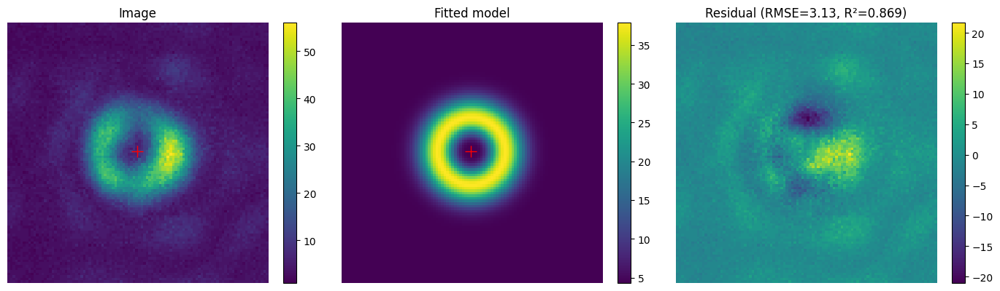

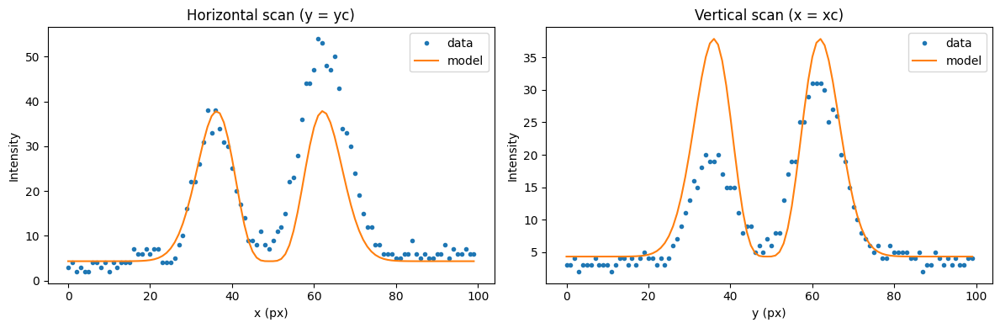

Params: {'A': 0.011130343419386728, 'w': 9.151840301414577, 'xc': 48.81082294296708, 'yc': 49.0291560496537, 'B': 5.723672652610722}
Uncertainties: {'A': 9.320177216229338e-05, 'w': 0.014225622964323281, 'xc': 0.03128588394939762, 'yc': 0.031285883952012504, 'B': 0.04111871399306725}
RMSE: 3.748760491013227 R^2: 0.8803800414033118


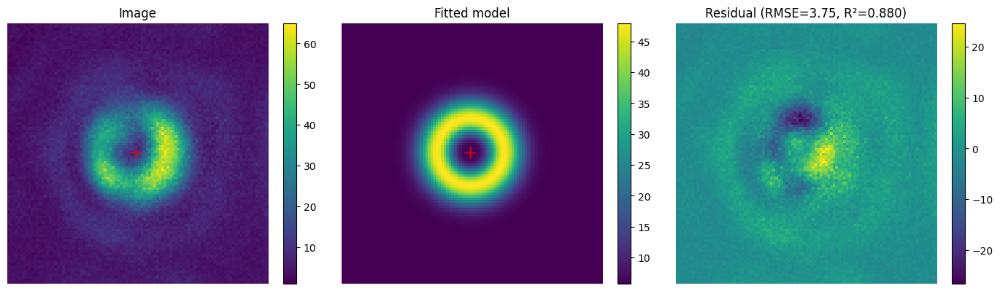

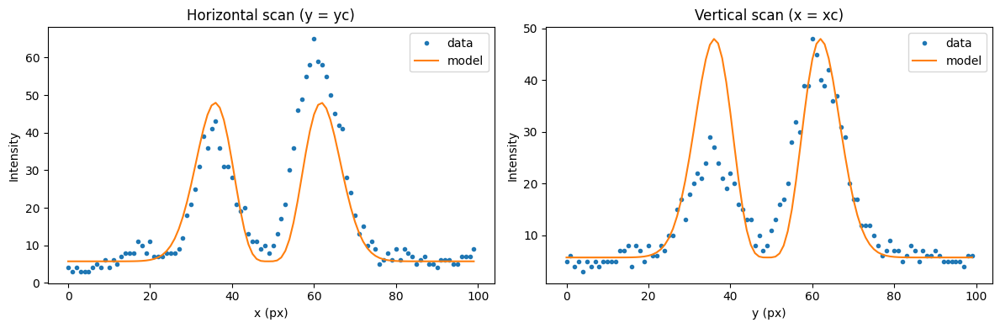

Params: {'A': 0.008463445433112343, 'w': 9.36132379469686, 'xc': 49.42660410938583, 'yc': 49.12986930848967, 'B': 5.739390885605014}
Uncertainties: {'A': 7.334362418512642e-05, 'w': 0.015072934408801007, 'xc': 0.0331189703009049, 'yc': 0.03311897031194877, 'B': 0.03640555070048987}
RMSE: 3.3034676640322673 R^2: 0.8721196422710328


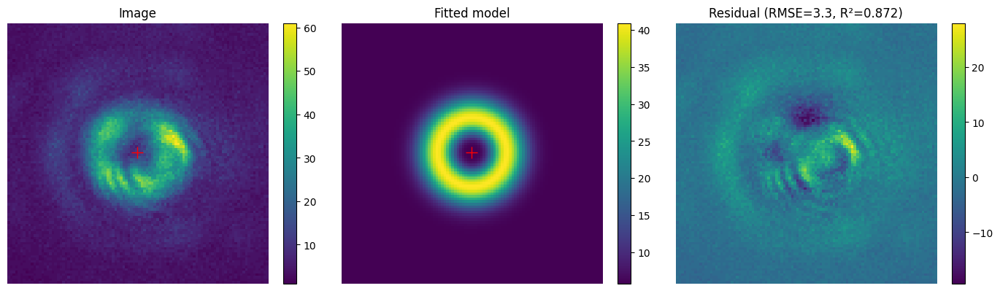

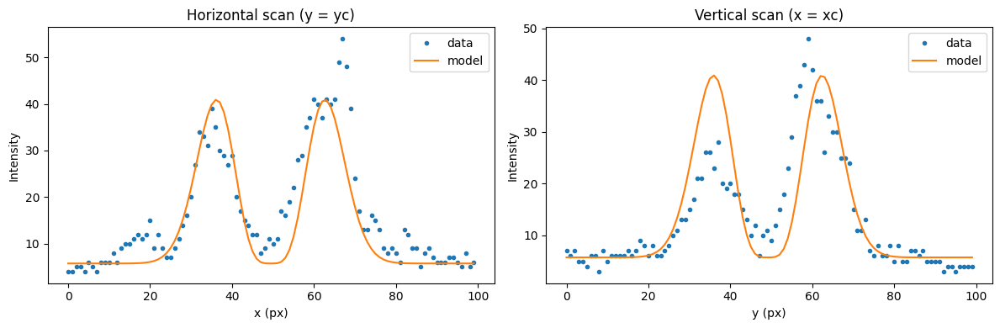

Params: {'A': 0.007500093959650528, 'w': 9.25821059062026, 'xc': 48.9474533164069, 'yc': 48.89807829633253, 'B': 4.109275802007468}
Uncertainties: {'A': 5.94615583457321e-05, 'w': 0.013631513449275509, 'xc': 0.02996546552054974, 'yc': 0.029965465517177582, 'B': 0.02785962826568086}
RMSE: 2.5339201268579767 R^2: 0.8910551364020589


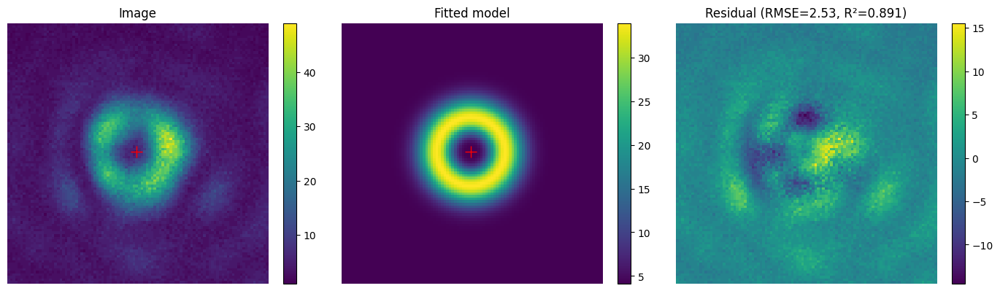

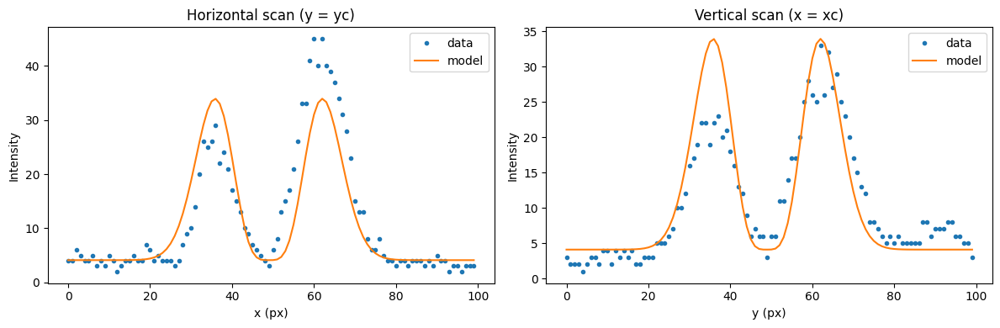

Params: {'A': 0.008646466241079013, 'w': 9.267586953713966, 'xc': 49.21478878582028, 'yc': 48.9505154510751, 'B': 5.350639211118627}
Uncertainties: {'A': 9.224014188415084e-05, 'w': 0.018361715727931917, 'xc': 0.04036197161658968, 'yc': 0.04036197161374322, 'B': 0.043445891656028794}
RMSE: 3.950705601752295 R^2: 0.8186999152141116


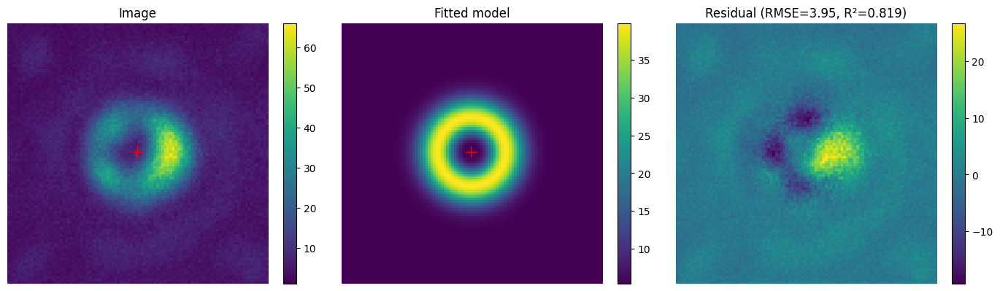

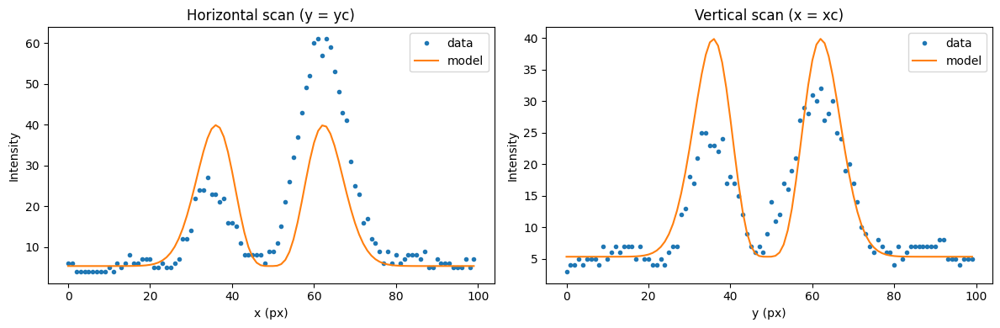

Params: {'A': 0.009334295380721959, 'w': 9.251511117463394, 'xc': 48.62042478532427, 'yc': 48.38084218190223, 'B': 6.600428897205091}
Uncertainties: {'A': 7.086488065240045e-05, 'w': 0.013043582973696158, 'xc': 0.028673888116921283, 'yc': 0.02867388810929912, 'B': 0.03307750816781326}
RMSE: 3.0089556986103787 R^2: 0.8992099195940115


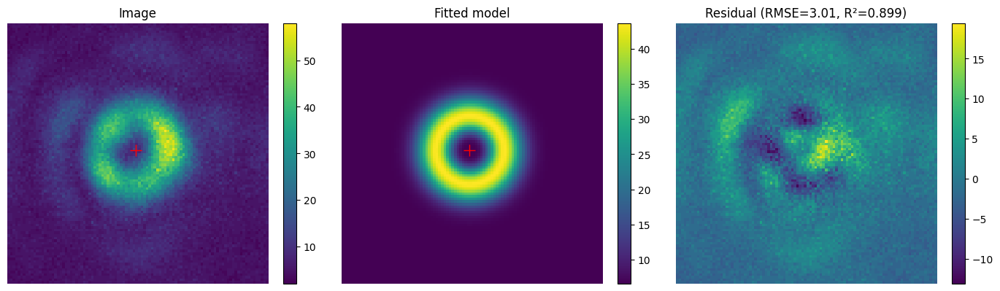

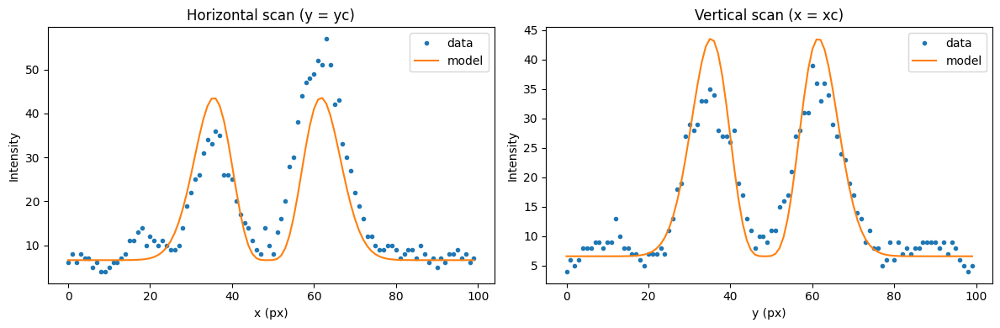

Params: {'A': 0.01053778125513002, 'w': 9.410399006426648, 'xc': 48.711273593991095, 'yc': 49.17446062822859, 'B': 6.828112018590362}
Uncertainties: {'A': 0.0001064550941149841, 'w': 0.01766714006448916, 'xc': 0.0388105411375084, 'yc': 0.038810541138013833, 'B': 0.054301812534082304}
RMSE: 4.921845731802547 R^2: 0.8335927216699619


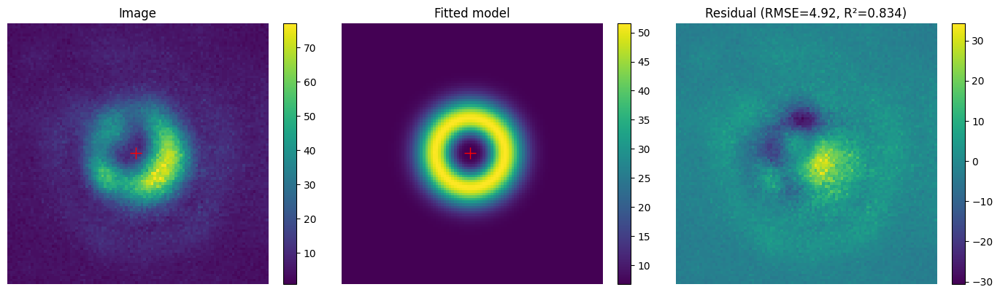

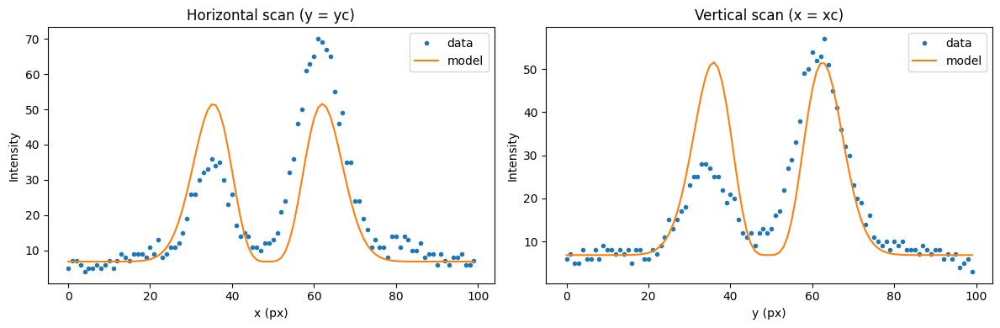

Params: {'A': 0.009455352945882336, 'w': 9.02693241545738, 'xc': 48.332054294310886, 'yc': 49.35019811139029, 'B': 4.157708593019481}
Uncertainties: {'A': 9.72339584749531e-05, 'w': 0.01722255910451712, 'xc': 0.0378969975774775, 'yc': 0.03789699756853446, 'B': 0.03993955626342915}
RMSE: 3.651239150073082 R^2: 0.8305535253791131


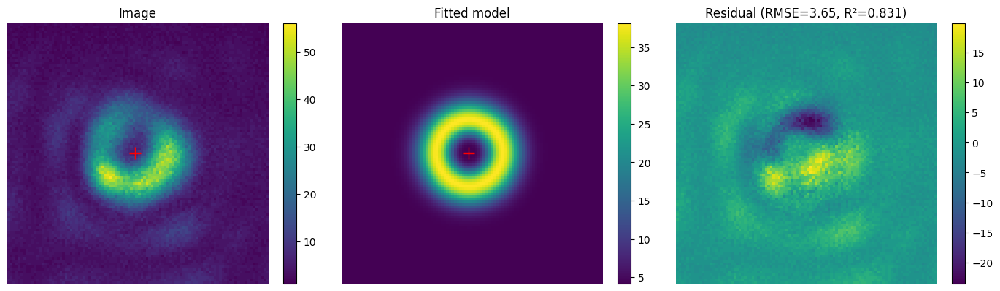

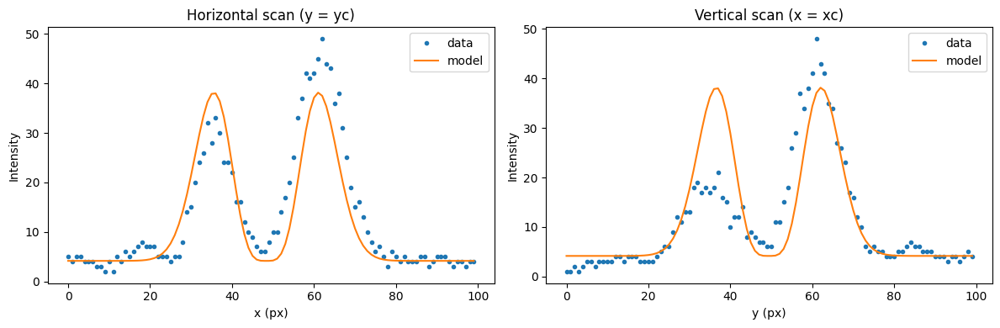

Params: {'A': 0.011371394682976814, 'w': 9.029196986744726, 'xc': 48.22938079441106, 'yc': 48.91558968070936, 'B': 6.2283188204893065}
Uncertainties: {'A': 0.00010618016896323586, 'w': 0.015642285186182225, 'xc': 0.03441939224777484, 'yc': 0.03441939224029721, 'B': 0.04367115895059057}
RMSE: 3.99218271719209 R^2: 0.8560029637923332


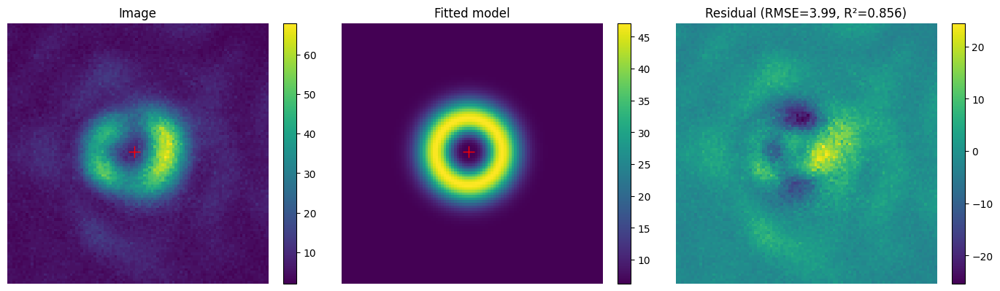

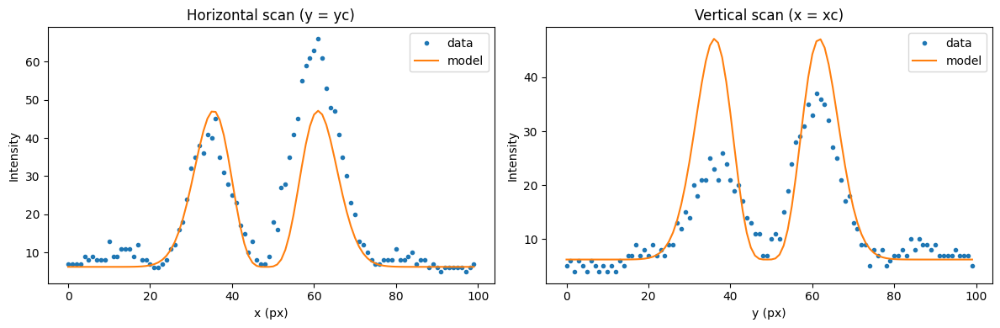

Params: {'A': 0.010955082134099606, 'w': 9.37649090162043, 'xc': 48.505545200327965, 'yc': 49.15990013844865, 'B': 6.834444421044265}
Uncertainties: {'A': 9.606644590147369e-05, 'w': 0.015278166570563752, 'xc': 0.03356764033267927, 'yc': 0.03356764033532511, 'B': 0.048088693908801806}
RMSE: 4.362091434936594 R^2: 0.8693925409722365


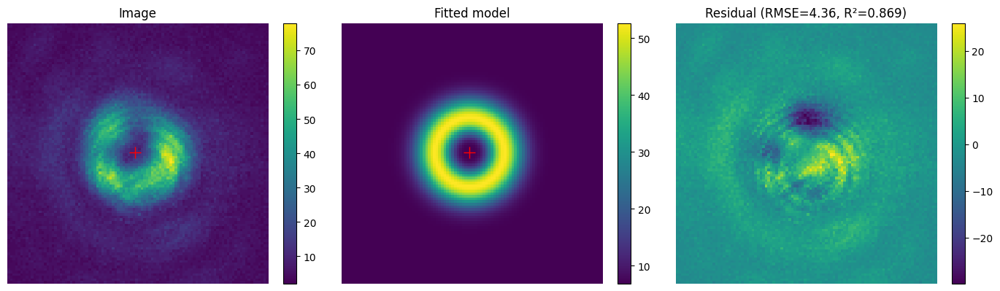

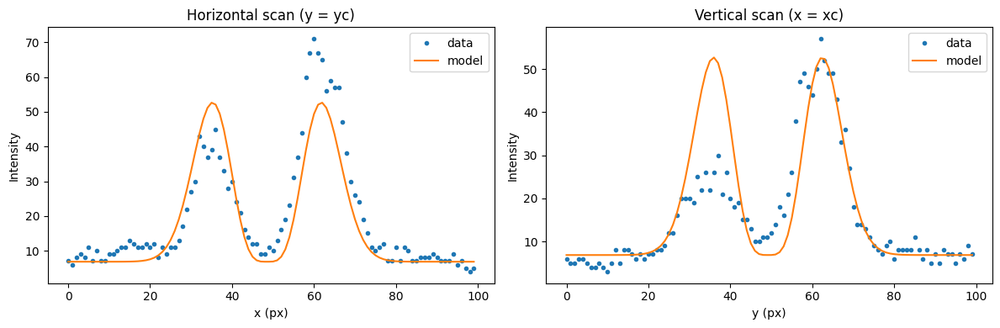

Params: {'A': 0.009292127645050052, 'w': 9.115478495001884, 'xc': 48.0588506114461, 'yc': 49.2092169394819, 'B': 6.289862639371241}
Uncertainties: {'A': 7.681788666547197e-05, 'w': 0.013986414715467974, 'xc': 0.03076458421877845, 'yc': 0.030764584217857518, 'B': 0.03319589983698679}
RMSE: 3.0288730262065227 R^2: 0.8831878944527063


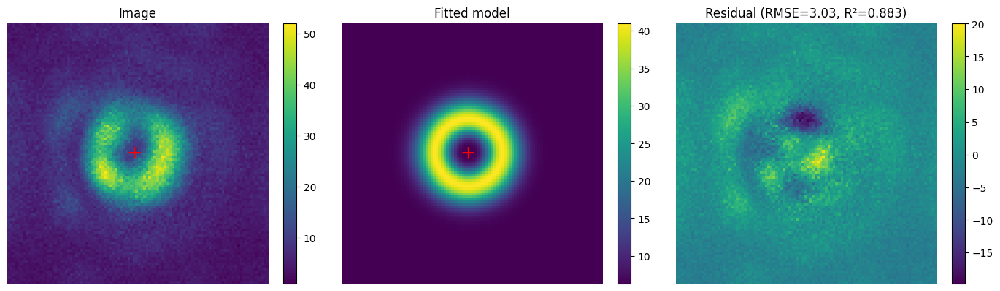

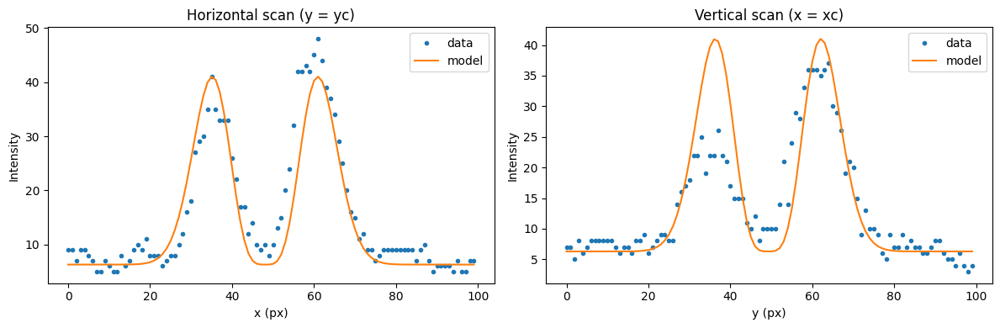

Params: {'A': 0.009557695210533165, 'w': 9.2699460189759, 'xc': 47.78311297941509, 'yc': 48.969933632245194, 'B': 4.212574442861049}
Uncertainties: {'A': 9.433409452543472e-05, 'w': 0.016992703634524414, 'xc': 0.037352278970443624, 'yc': 0.03735227896310435, 'B': 0.04449110535679179}
RMSE: 4.04553599189852 R^2: 0.8406370523114172


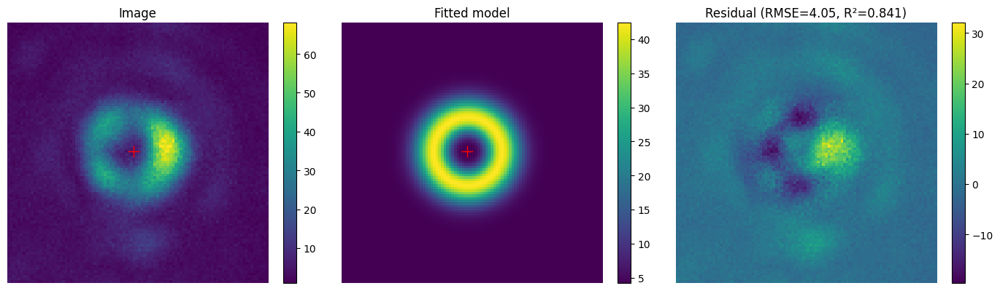

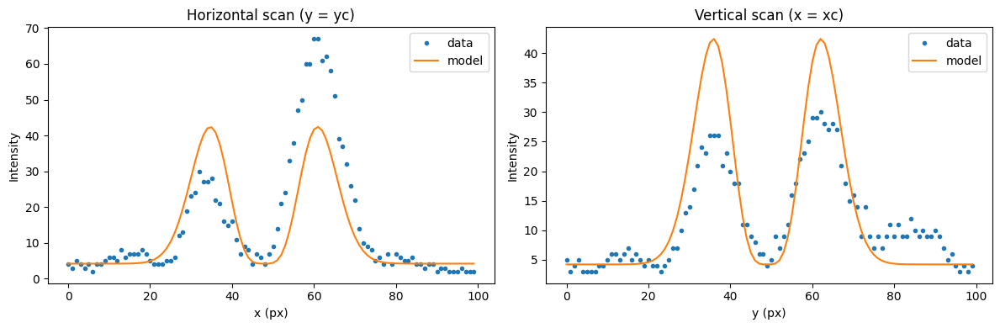

Params: {'A': 0.007658285680361886, 'w': 9.363804163152933, 'xc': 47.830155280949505, 'yc': 48.616313353541514, 'B': 5.458214392993051}
Uncertainties: {'A': 6.190966657902217e-05, 'w': 0.014064665507883423, 'xc': 0.030903211575074037, 'yc': 0.030903211575337864, 'B': 0.03077255775694638}
RMSE: 2.7921672847053713 R^2: 0.8868300189456225


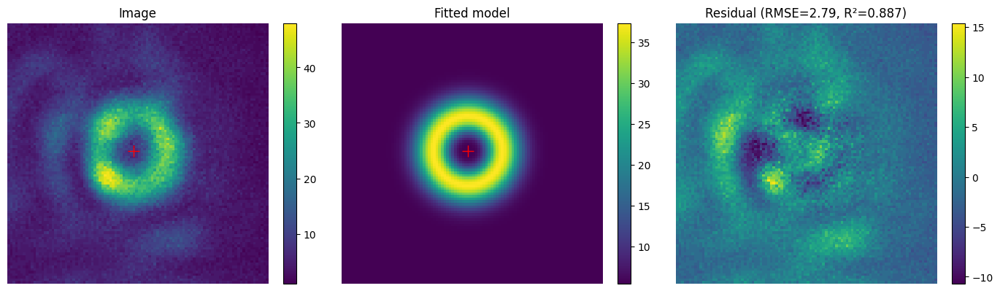

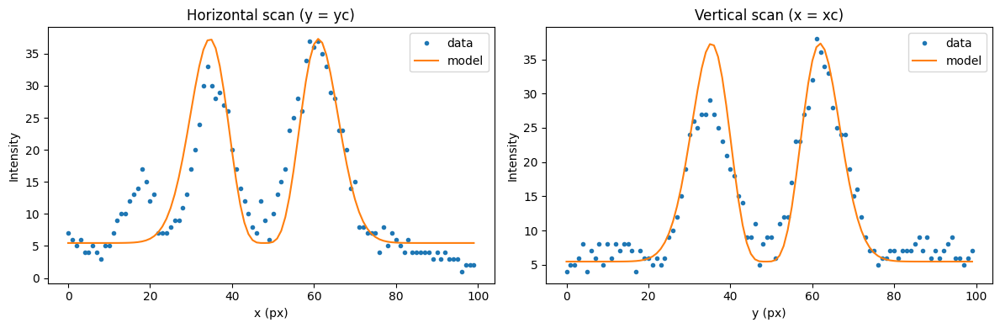

Params: {'A': 0.008630817302508332, 'w': 9.248115395968874, 'xc': 47.76228361283819, 'yc': 48.70614790733603, 'B': 5.747654891242106}
Uncertainties: {'A': 7.433841290019097e-05, 'w': 0.014792543860010271, 'xc': 0.03251913555302028, 'yc': 0.032519135563470206, 'B': 0.03463256914165711}
RMSE: 3.1506549538143815 R^2: 0.8739320504115253


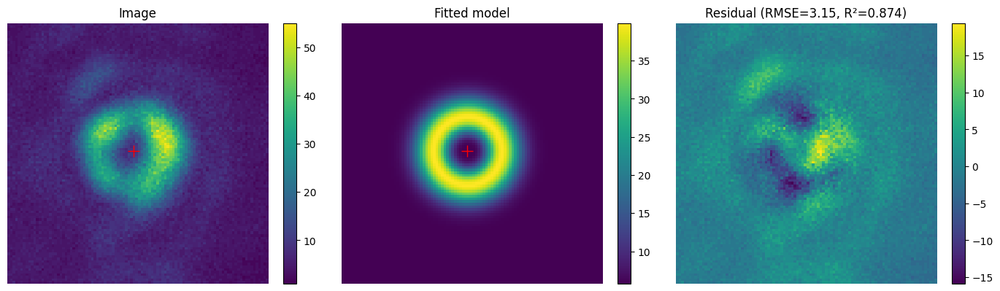

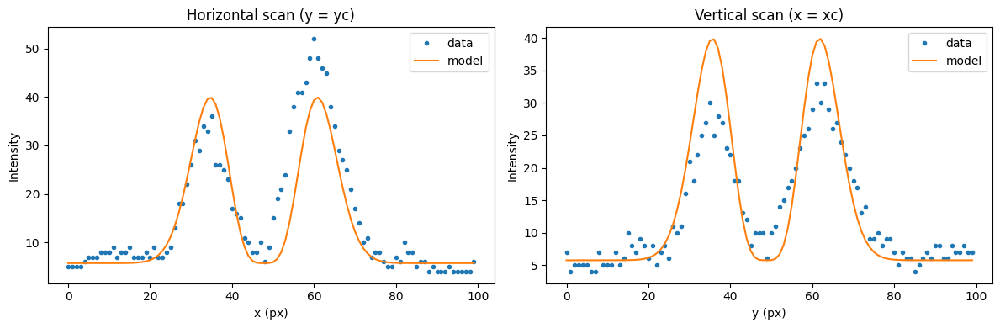

Params: {'A': 0.007815627972118116, 'w': 9.16982323015762, 'xc': 47.34835958599173, 'yc': 49.24861830202542, 'B': 5.044492944854647}
Uncertainties: {'A': 6.282950796676822e-05, 'w': 0.013684897846784203, 'xc': 0.03009436158204328, 'yc': 0.030094361584832776, 'B': 0.028003654691467247}
RMSE: 2.552053857919418 R^2: 0.8886451448010811


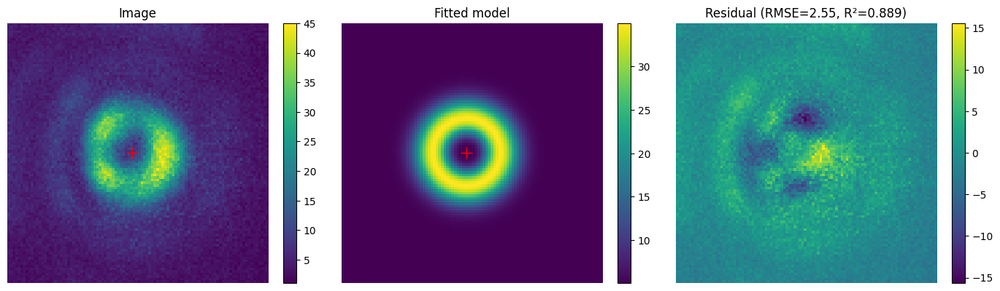

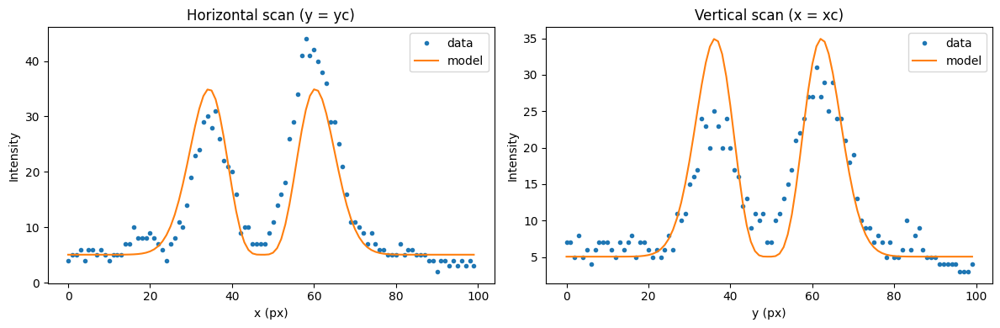

writing phase
Params: {'A': 0.009656694269135277, 'w': 9.147783164567777, 'xc': 49.193522458916064, 'yc': 48.85639161735501, 'B': 3.5560767659949715}
Uncertainties: {'A': 6.480883540132182e-05, 'w': 0.011396232404772237, 'xc': 0.025063746425937006, 'yc': 0.025063746430262032, 'B': 0.02852645058441793}
RMSE: 2.6009672517269706 R^2: 0.9197371446776743


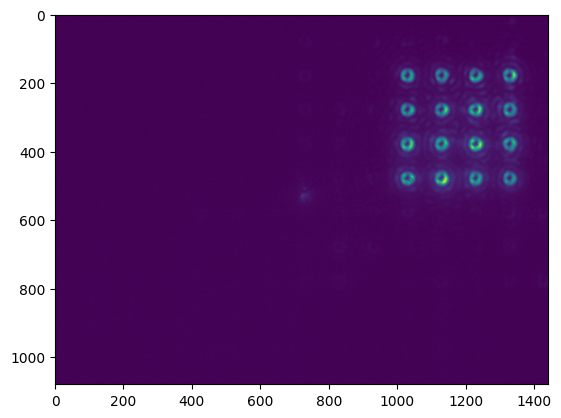

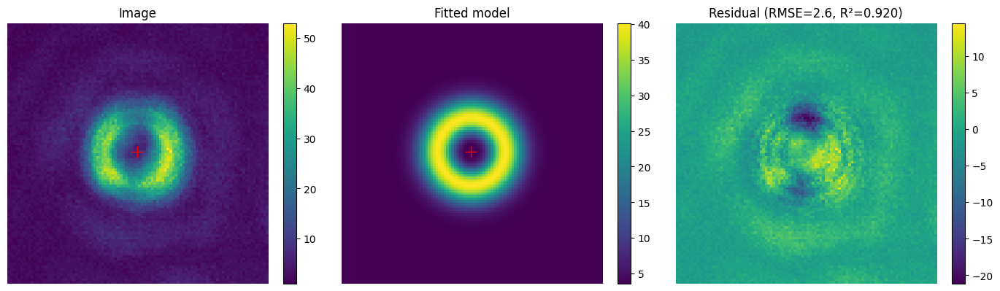

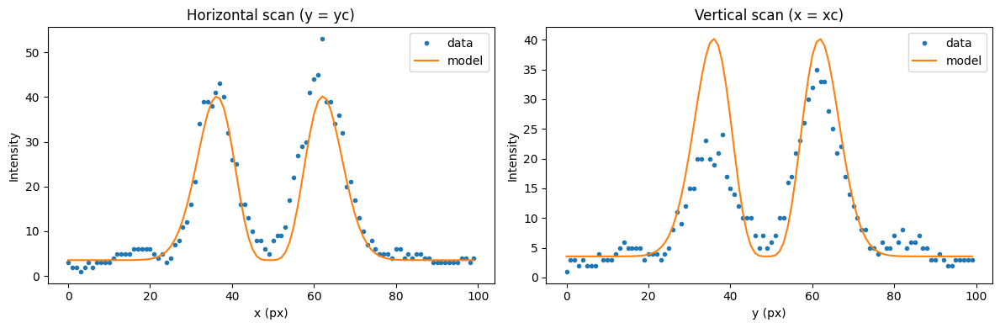

Params: {'A': 0.009318855872513892, 'w': 9.092774944000924, 'xc': 49.43261697340653, 'yc': 48.81661293970337, 'B': 4.24031448206142}
Uncertainties: {'A': 7.778167901074465e-05, 'w': 0.014084744850038012, 'xc': 0.03098386214470048, 'yc': 0.030983862146908767, 'B': 0.03317933513843193}
RMSE: 3.0288717297872596 R^2: 0.8812774684973358


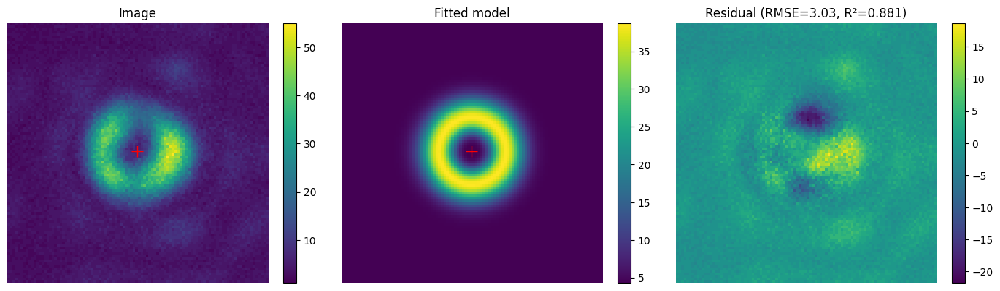

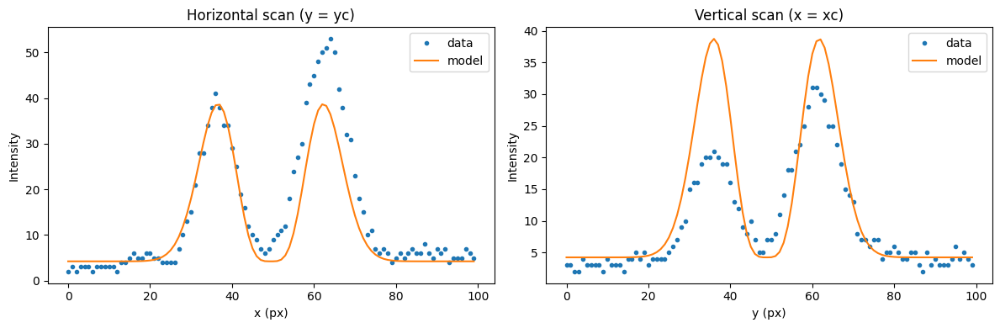

Params: {'A': 0.01171163924728147, 'w': 9.096614244258072, 'xc': 49.06880821440981, 'yc': 48.91537354070565, 'B': 5.664474443068241}
Uncertainties: {'A': 8.984584171523929e-05, 'w': 0.012951049768780133, 'xc': 0.02848947619544716, 'yc': 0.028489476206828457, 'B': 0.038409760580332464}
RMSE: 3.5060510134888676 R^2: 0.8978128168280372


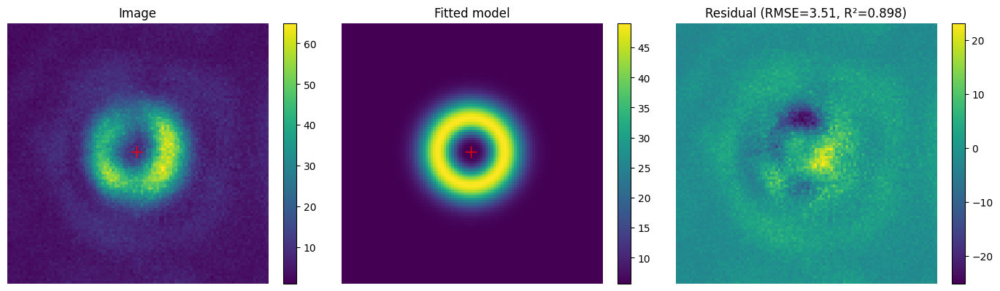

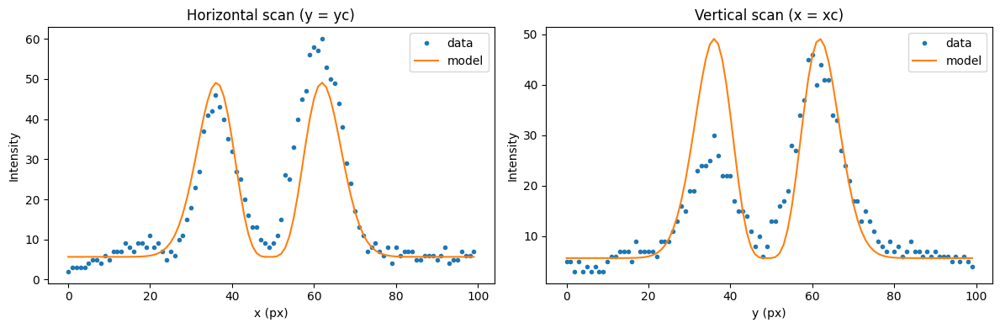

Params: {'A': 0.008966437319183342, 'w': 9.299795284768058, 'xc': 49.568486751519316, 'yc': 49.09267596141652, 'B': 5.714481852918183}
Uncertainties: {'A': 7.40142830514886e-05, 'w': 0.014259221186397327, 'xc': 0.03133959639621557, 'yc': 0.03133959640118196, 'B': 0.035497168464311425}
RMSE: 3.225550440483517 R^2: 0.8828130545978952


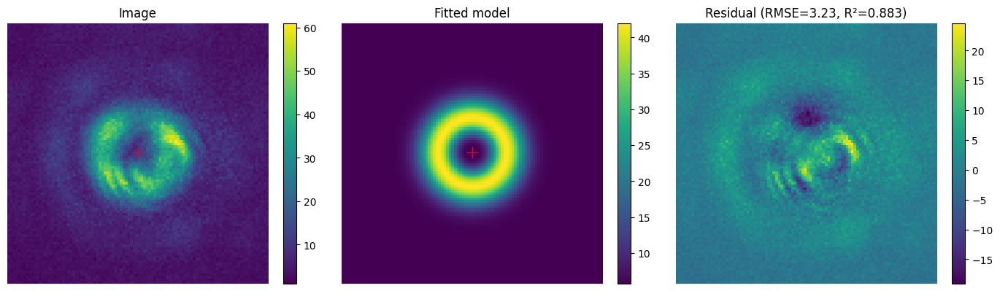

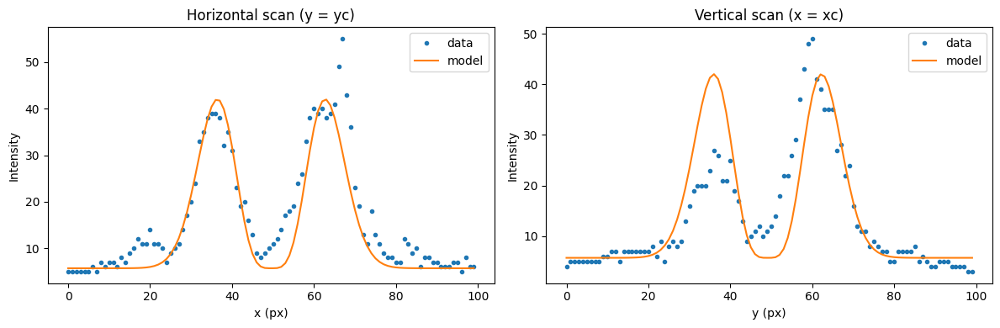

Params: {'A': 0.007897394437091447, 'w': 9.197847303510422, 'xc': 49.19198314241878, 'yc': 48.78813537871001, 'B': 4.0495400736966785}
Uncertainties: {'A': 5.739710549343698e-05, 'w': 0.01241154081959943, 'xc': 0.027290830282195994, 'yc': 0.027290830289955312, 'B': 0.02599188839240817}
RMSE: 2.3672401989657654 R^2: 0.9070089168515745


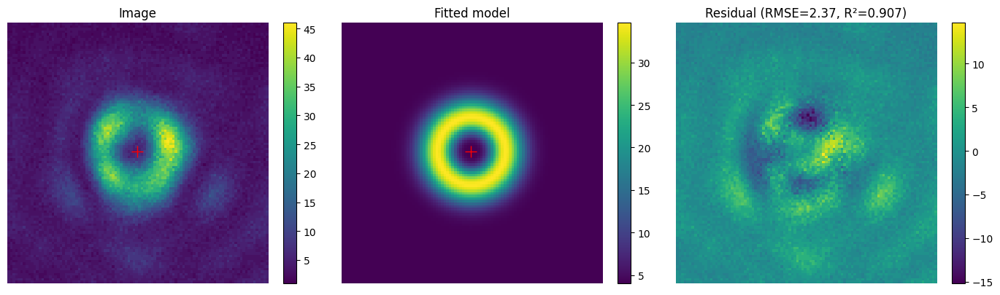

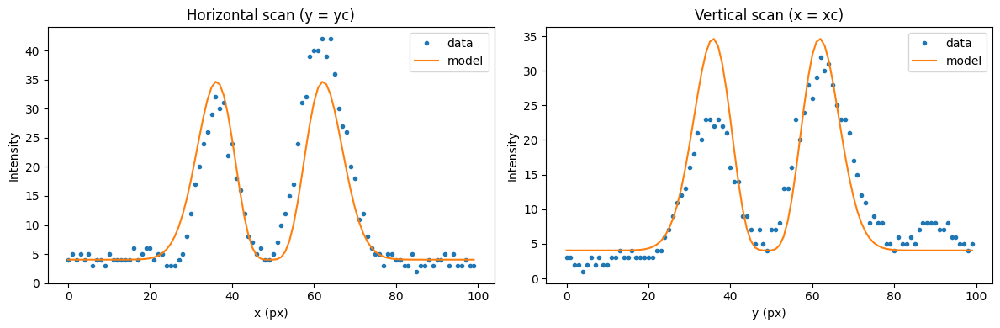

Params: {'A': 0.009085329388407686, 'w': 9.20626924255316, 'xc': 49.43251645356182, 'yc': 48.78524628949468, 'B': 5.305057709953446}
Uncertainties: {'A': 8.995700074319684e-05, 'w': 0.016924940326899732, 'xc': 0.03721365719830008, 'yc': 0.03721365720029775, 'B': 0.040930942902077716}
RMSE: 3.727131236185053 R^2: 0.8400938259694932


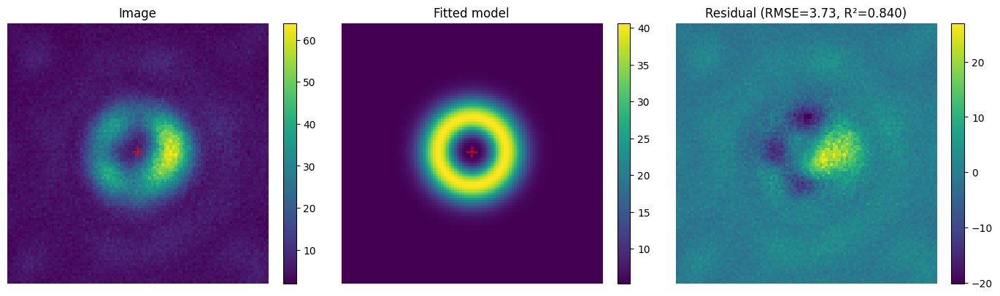

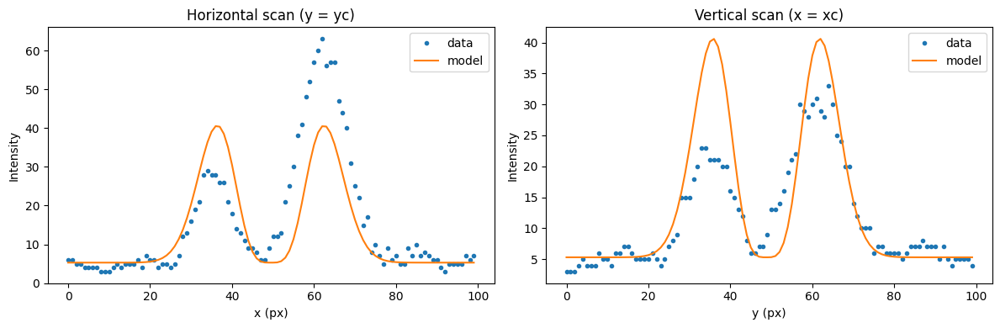

Params: {'A': 0.009895551033281555, 'w': 9.191199680178183, 'xc': 48.83921092503873, 'yc': 48.25845937511024, 'B': 6.556538460105594}
Uncertainties: {'A': 6.972197044491494e-05, 'w': 0.01202327351330021, 'xc': 0.02643785777741348, 'yc': 0.026437857778236644, 'B': 0.03145453161302016}
RMSE: 2.8651807016380086 R^2: 0.9121319845854392


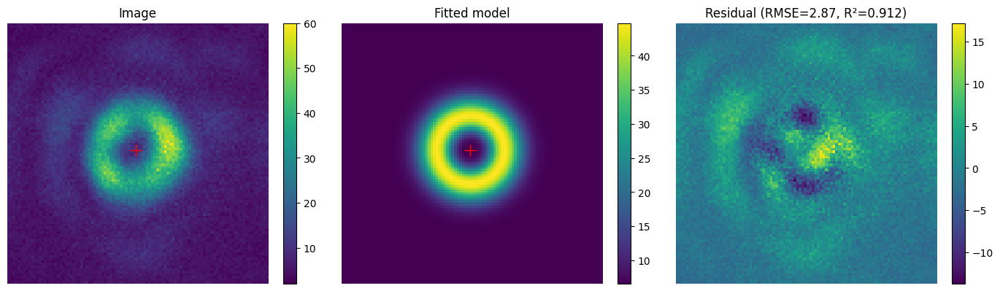

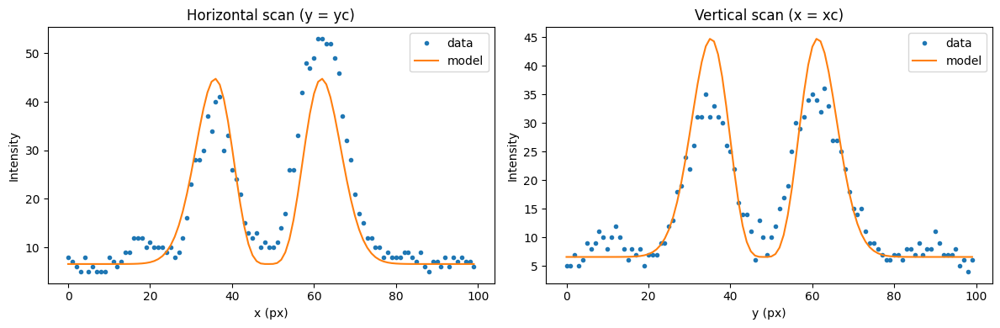

Params: {'A': 0.011167593544524278, 'w': 9.327460533540824, 'xc': 48.85581701796042, 'yc': 49.106925314702714, 'B': 6.828970028561888}
Uncertainties: {'A': 0.00010757545790947627, 'w': 0.016691561541027904, 'xc': 0.036681021003005014, 'yc': 0.036681020990714845, 'B': 0.05239792138649468}
RMSE: 4.758298274124746 R^2: 0.8467739214021404


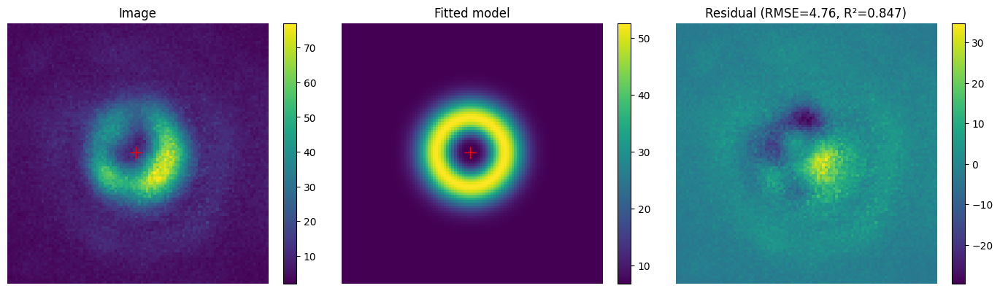

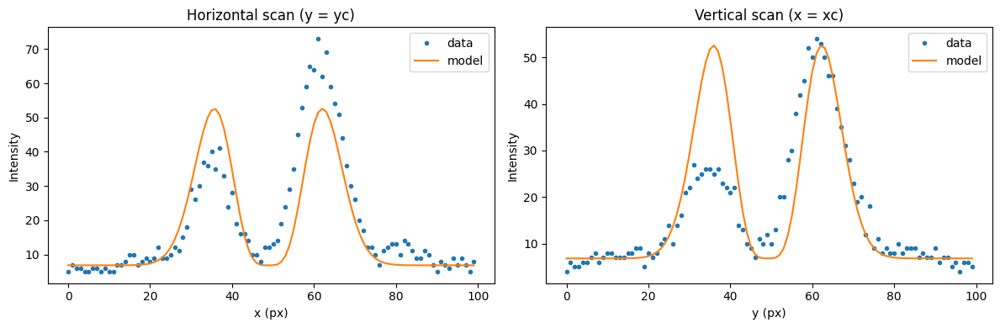

Params: {'A': 0.009849580776953842, 'w': 8.998998250045236, 'xc': 48.52455012798829, 'yc': 49.22932778847978, 'B': 4.095980669515386}
Uncertainties: {'A': 9.747394411666796e-05, 'w': 0.016520817585135832, 'xc': 0.036357109781850465, 'yc': 0.03635710978093001, 'B': 0.03939861253118351}
RMSE: 3.6039664089619006 R^2: 0.8412151690738209


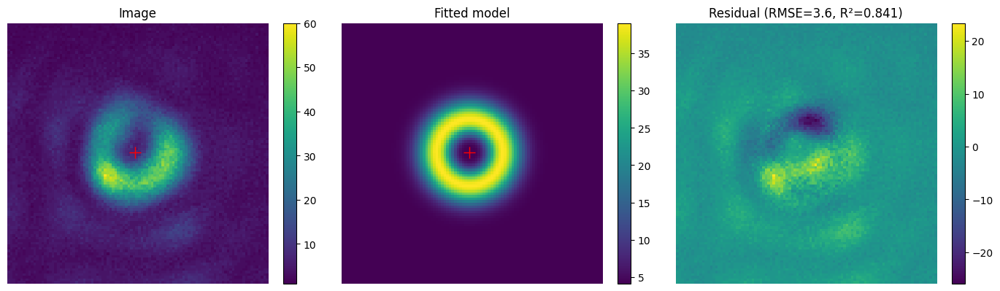

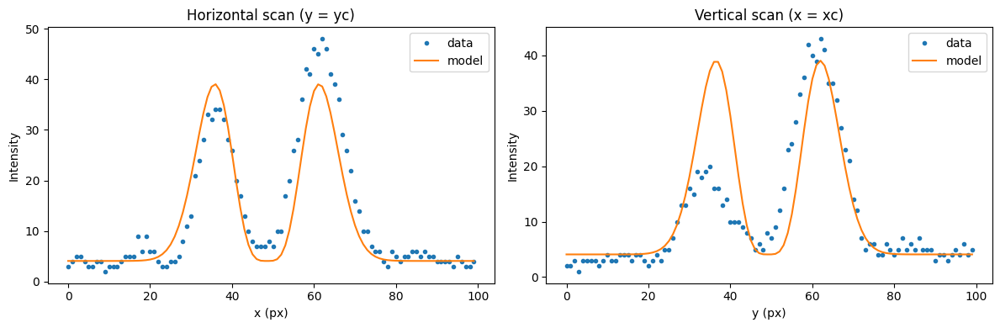

Params: {'A': 0.011988495454222944, 'w': 8.961214046630603, 'xc': 48.48554546008394, 'yc': 48.787189645171146, 'B': 6.177272097588812}
Uncertainties: {'A': 0.00010371777095607345, 'w': 0.014379830779149911, 'xc': 0.03165043866311507, 'yc': 0.031650438662064885, 'B': 0.04101619433257944}
RMSE: 3.754990023933918 R^2: 0.8740742137421204


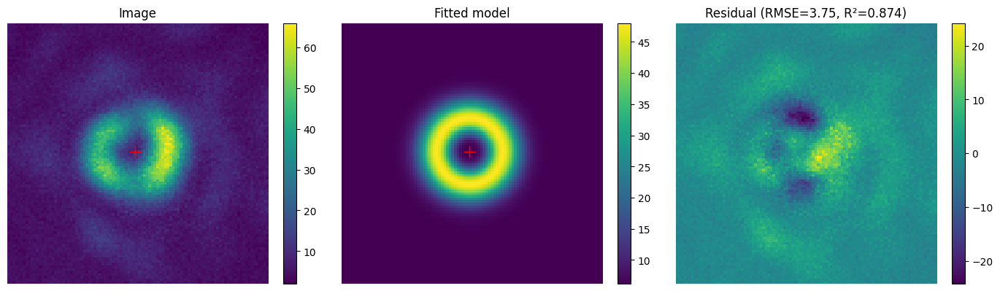

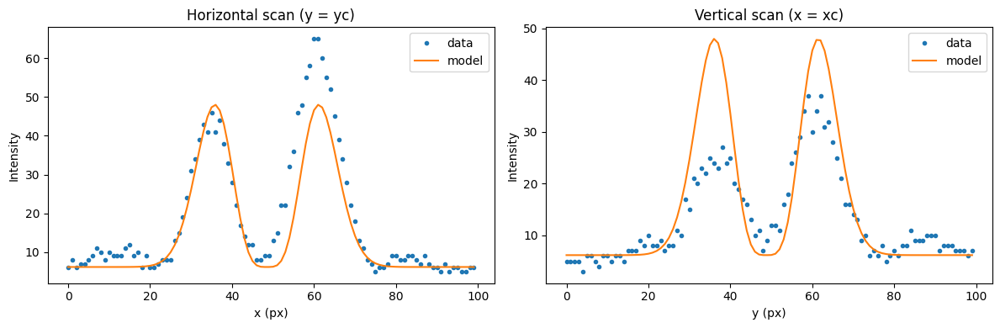

Params: {'A': 0.011307339717031743, 'w': 9.344064646625863, 'xc': 48.71785127148106, 'yc': 49.00244128750381, 'B': 6.778852428116445}
Uncertainties: {'A': 9.578801372777071e-05, 'w': 0.014706134538312075, 'xc': 0.03231550542408819, 'yc': 0.032315505431168484, 'B': 0.04709103230932408}
RMSE: 4.274759617928211 R^2: 0.8771692683914016


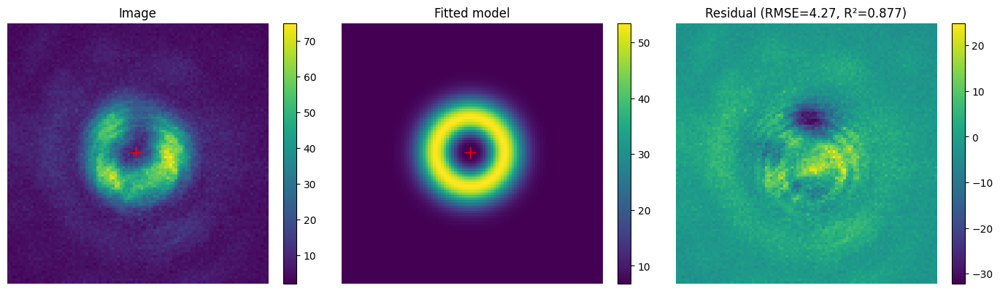

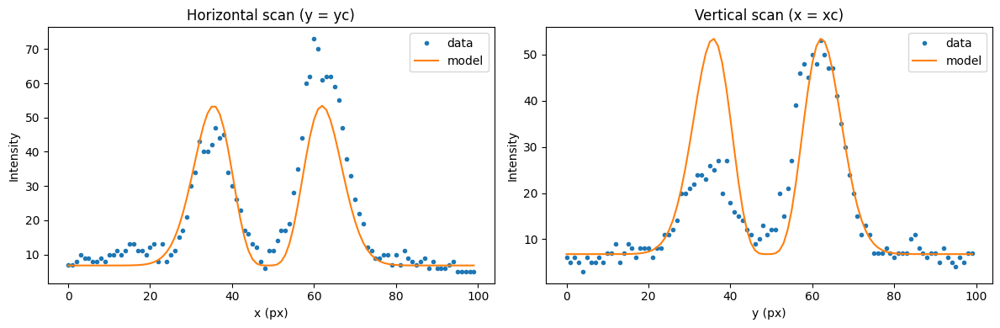

Params: {'A': 0.009809594431965595, 'w': 9.058379263208726, 'xc': 48.272731050603575, 'yc': 49.08315949898346, 'B': 6.256268239848923}
Uncertainties: {'A': 7.92082504579489e-05, 'w': 0.013572021165267872, 'xc': 0.029860306386065648, 'yc': 0.029860306384966947, 'B': 0.03312870025998333}
RMSE: 3.0265250962284878 R^2: 0.8881607317819993


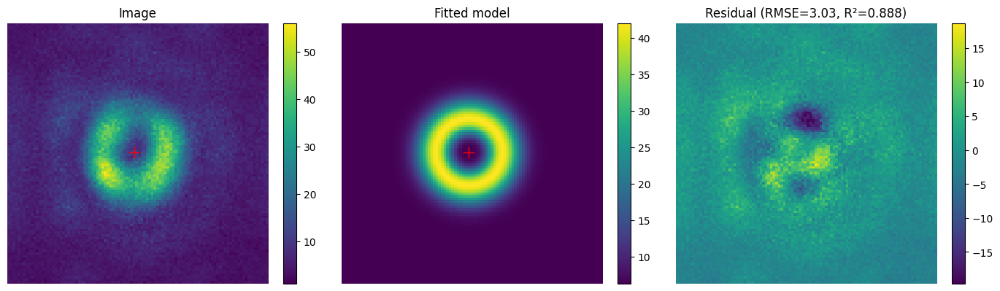

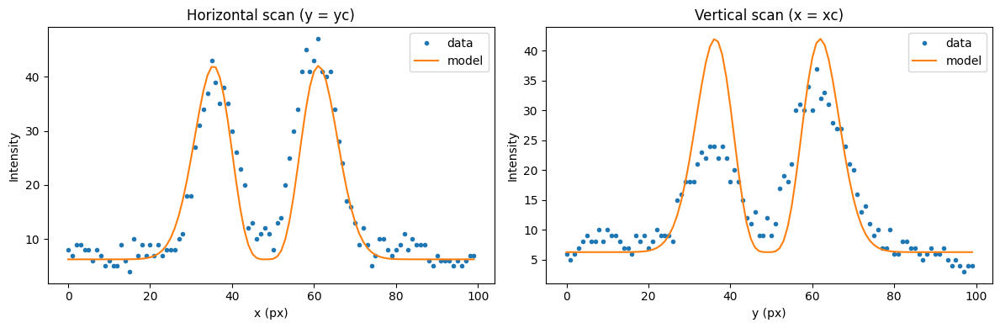

Params: {'A': 0.010101089046542576, 'w': 9.192347575637521, 'xc': 48.10663980443174, 'yc': 48.854902794514, 'B': 4.197411982351851}
Uncertainties: {'A': 9.229720533511675e-05, 'w': 0.015594440689363893, 'xc': 0.034290291724894756, 'yc': 0.034290291718963174, 'B': 0.0416662485077859}
RMSE: 3.7952649165255448 R^2: 0.8605693483665982


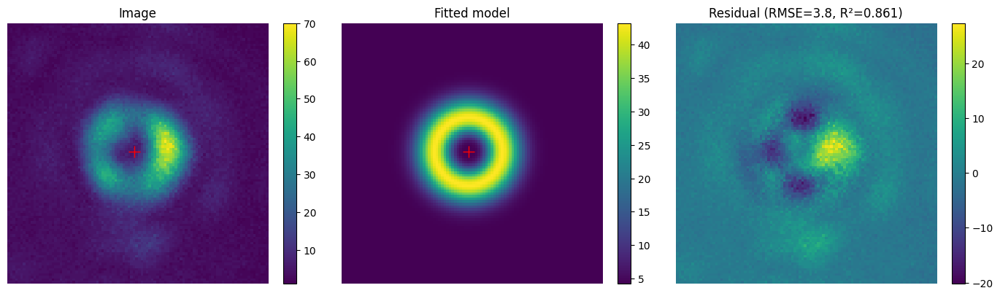

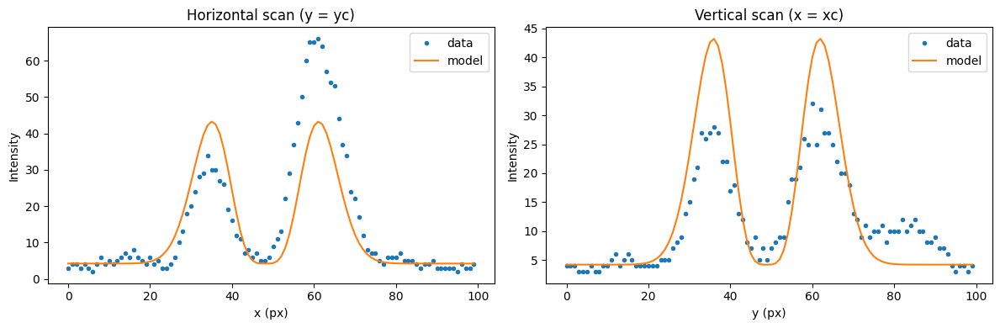

Params: {'A': 0.008129846104131797, 'w': 9.300304166329992, 'xc': 48.0271907152401, 'yc': 48.545814914443774, 'B': 5.389039522959619}
Uncertainties: {'A': 6.429675082043304e-05, 'w': 0.013662545717955322, 'xc': 0.03002812711262342, 'yc': 0.030028127118628938, 'B': 0.03084544382126896}
RMSE: 2.8028260616300607 R^2: 0.8913813834245945


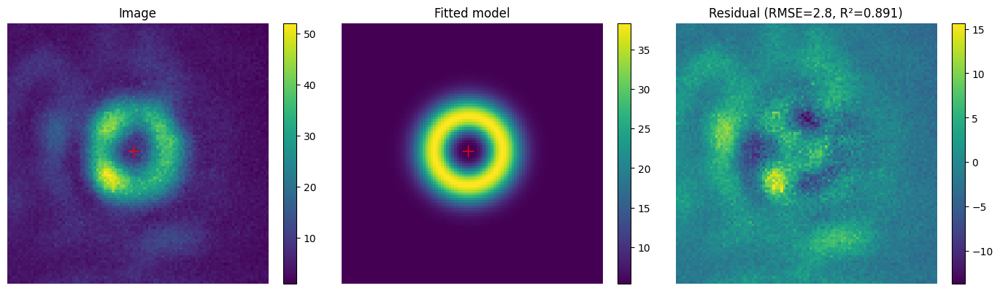

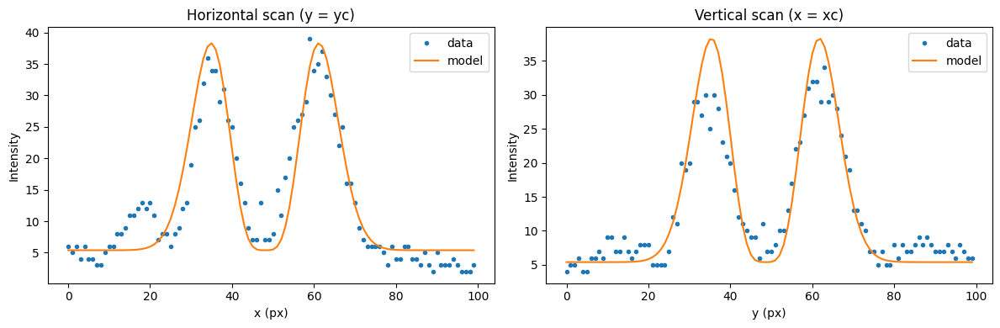

Params: {'A': 0.009227581276688553, 'w': 9.159042766832966, 'xc': 47.94841927789492, 'yc': 48.553261319152746, 'B': 5.7244044577932405}
Uncertainties: {'A': 7.400432551360012e-05, 'w': 0.013635780237713871, 'xc': 0.029987737699429164, 'yc': 0.029987737702500603, 'B': 0.032783096989334216}
RMSE: 2.9883323584664354 R^2: 0.8891518876499491


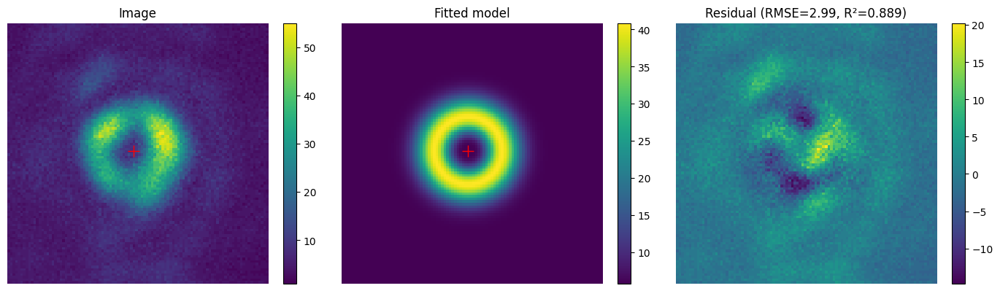

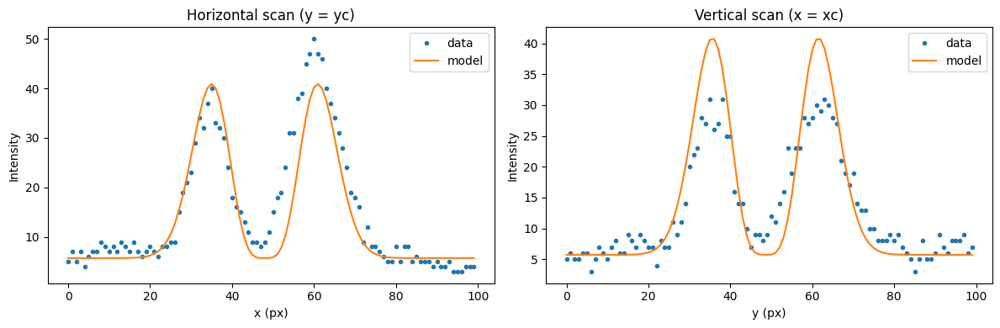

Params: {'A': 0.008260485989318235, 'w': 9.1168296877727, 'xc': 47.63395843266114, 'yc': 49.08538102183101, 'B': 5.018478674626035}
Uncertainties: {'A': 6.348989497194156e-05, 'w': 0.013005441310722463, 'xc': 0.02860666581224389, 'yc': 0.028606665813193308, 'B': 0.02745753003128493}
RMSE: 2.5052159947317505 R^2: 0.8974004411631503


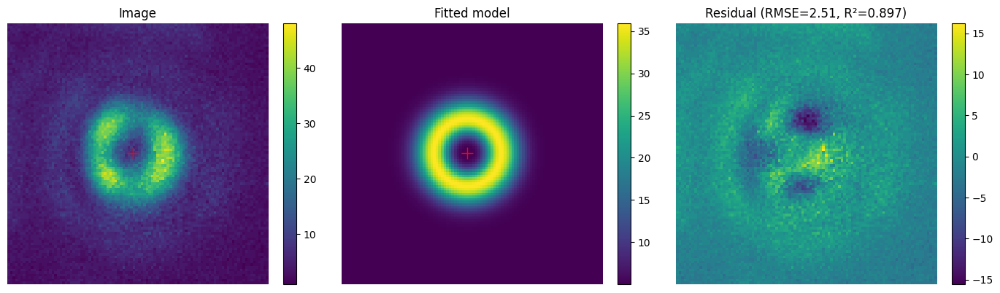

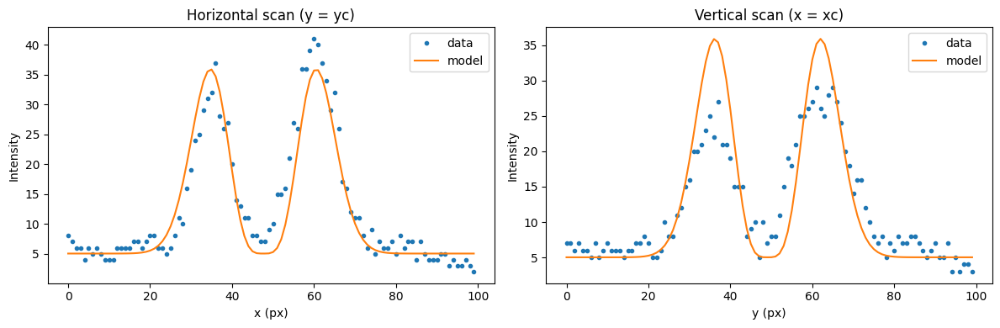

writing phase
Params: {'A': 0.010256234659581904, 'w': 9.088162020551755, 'xc': 49.449025781842344, 'yc': 48.82126950571612, 'B': 3.4945172779273146}
Uncertainties: {'A': 6.70726420682716e-05, 'w': 0.011029678560148231, 'xc': 0.02426374969008614, 'yc': 0.024263749693522383, 'B': 0.028535794036753454}
RMSE: 2.6052360357756053 R^2: 0.9236283141732773


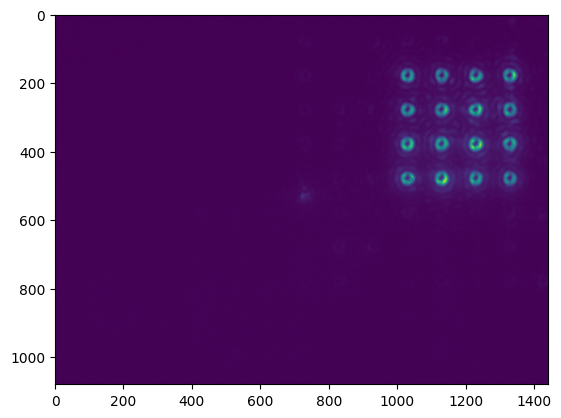

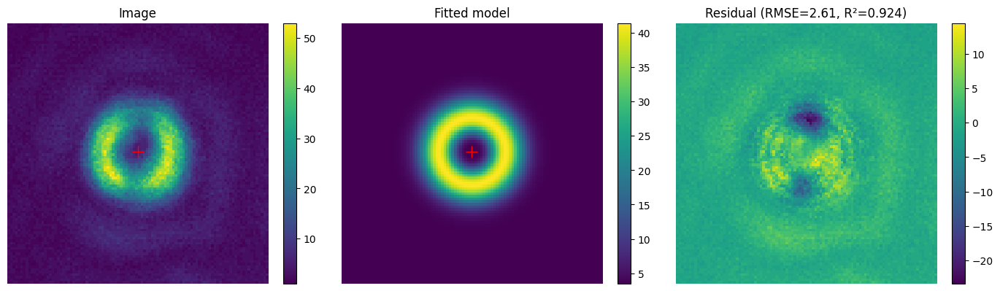

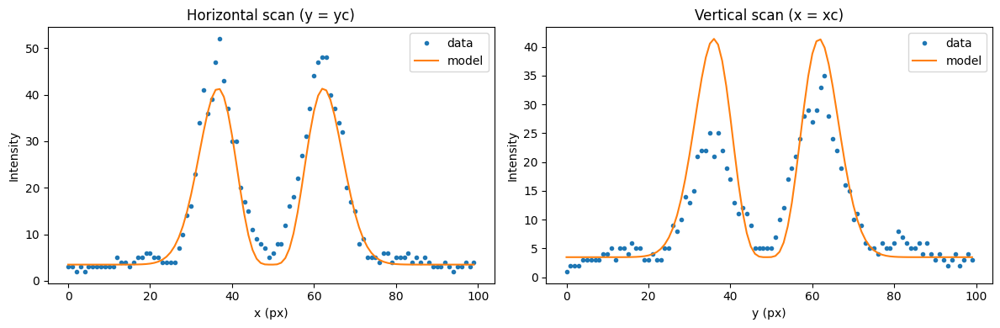

Params: {'A': 0.009609544095507303, 'w': 9.057780777625323, 'xc': 49.64574822833809, 'yc': 48.76139858877876, 'B': 4.260732344201431}
Uncertainties: {'A': 7.845247302811214e-05, 'w': 0.013721425314989806, 'xc': 0.03018909198251688, 'yc': 0.03018909197472177, 'B': 0.03280133144453046}
RMSE: 2.9966569126773495 R^2: 0.8859554681766404


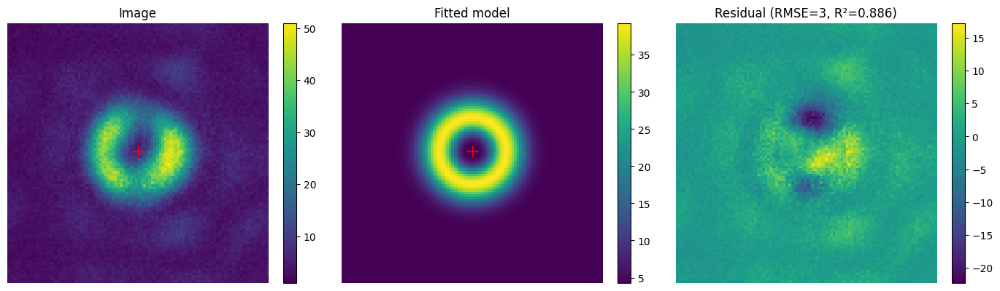

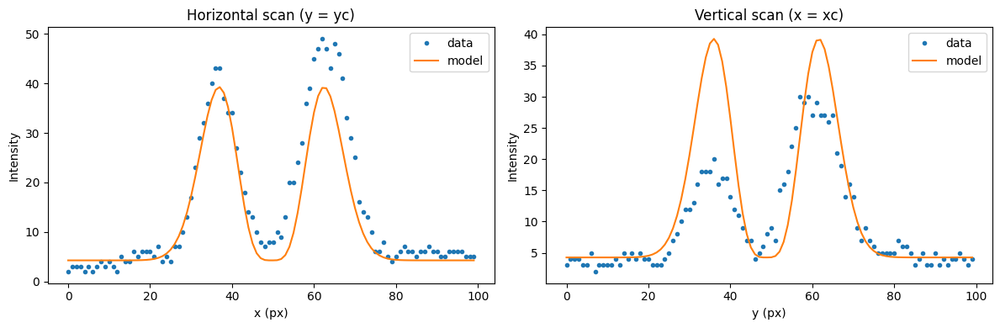

Params: {'A': 0.01227681668616616, 'w': 9.049335712653134, 'xc': 49.278092107061134, 'yc': 48.86501791144467, 'B': 5.634903555533719}
Uncertainties: {'A': 8.869856679106196e-05, 'w': 0.012131252778001488, 'xc': 0.026691434948892163, 'yc': 0.02669143494531931, 'B': 0.0369059146021785}
RMSE: 3.372263179944355 R^2: 0.9084442122418632


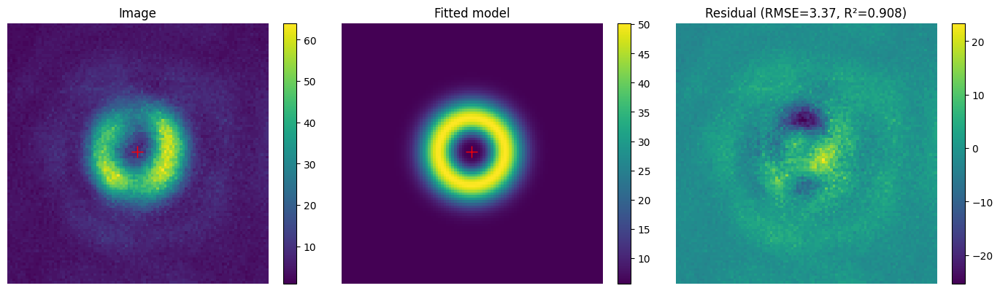

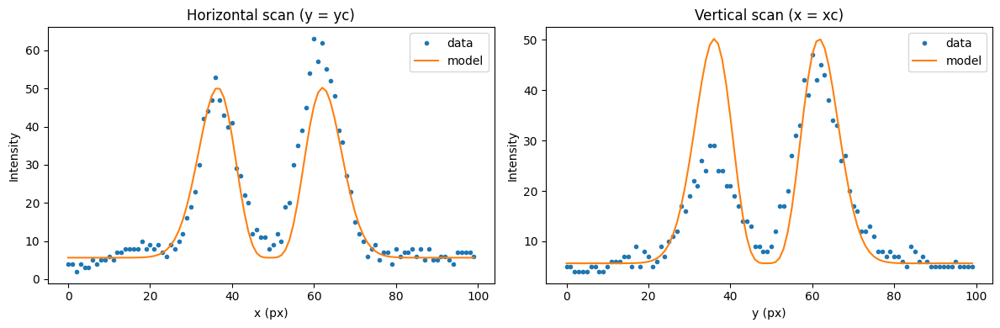

Params: {'A': 0.009394905428269158, 'w': 9.249897786594126, 'xc': 49.719786100172826, 'yc': 48.93402630414624, 'B': 5.702621736540563}
Uncertainties: {'A': 7.53732800725738e-05, 'w': 0.013781407768507252, 'xc': 0.03029607219883529, 'yc': 0.030296072204336458, 'B': 0.03514994853139472}
RMSE: 3.197594895800889 R^2: 0.8887586726079011


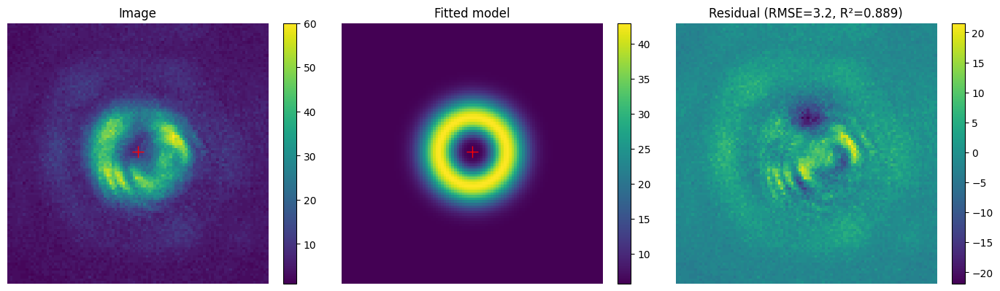

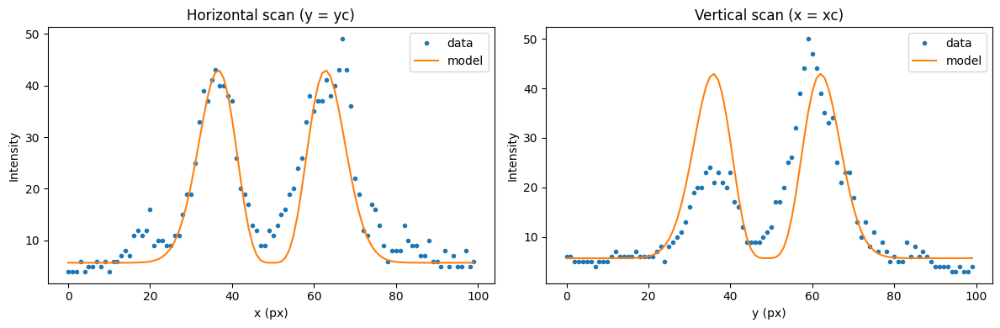

Params: {'A': 0.008279497238994774, 'w': 9.142418560592521, 'xc': 49.45088350556182, 'yc': 48.61208464230899, 'B': 4.030061143554827}
Uncertainties: {'A': 5.840516902529754e-05, 'w': 0.011971212372483877, 'xc': 0.02632890580721097, 'yc': 0.026328905804465837, 'B': 0.025629462618120182}
RMSE: 2.3371045736932428 R^2: 0.912080689334337


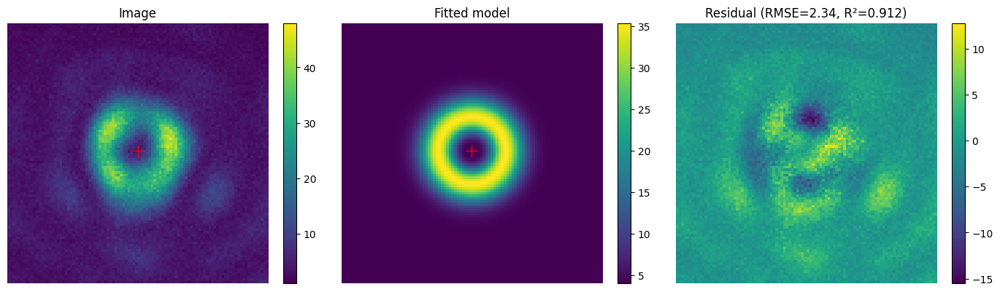

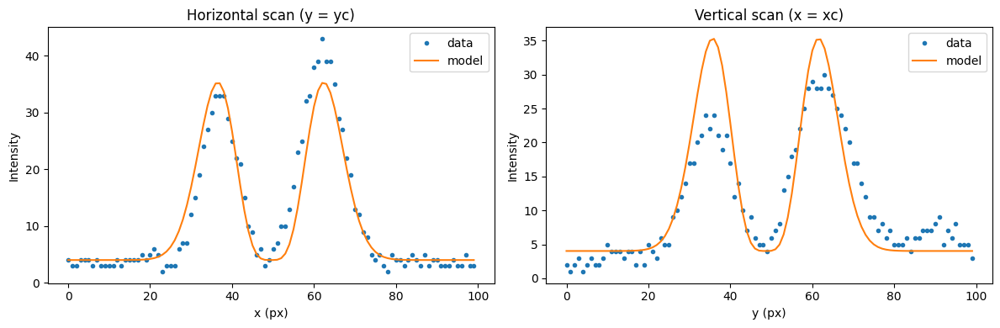

Params: {'A': 0.009566353464278617, 'w': 9.137018773437712, 'xc': 49.56737779361242, 'yc': 48.68728214045902, 'B': 5.3046348543428845}
Uncertainties: {'A': 8.924570452544276e-05, 'w': 0.01582213533600608, 'xc': 0.034799243845036396, 'yc': 0.03479924383889487, 'B': 0.039042788475658265}
RMSE: 3.5606662398470816 R^2: 0.8557540518981015


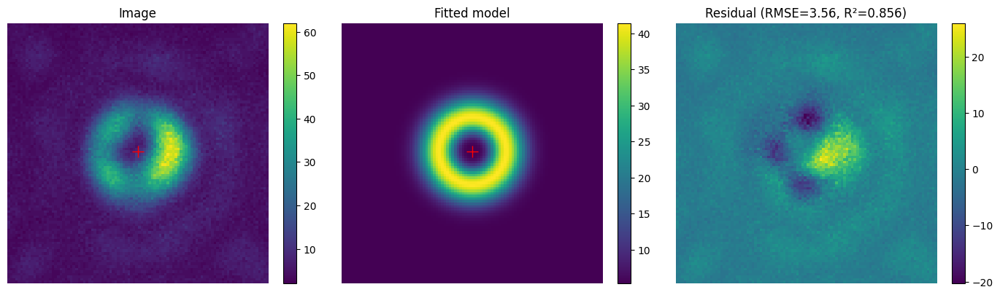

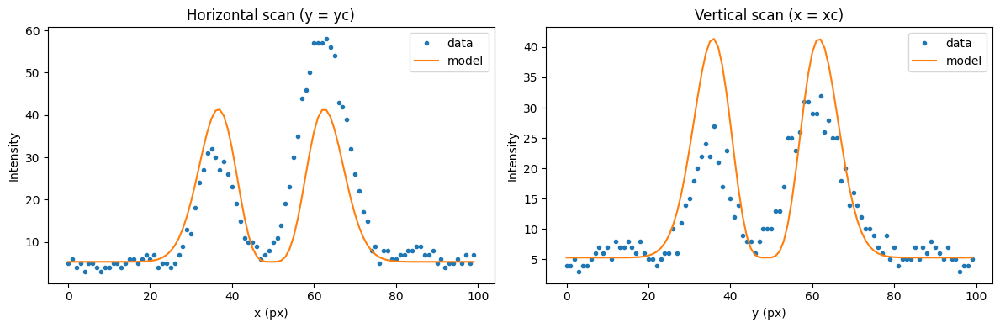

Params: {'A': 0.010341675071451756, 'w': 9.140456092596535, 'xc': 49.02866067428009, 'yc': 48.119160439267674, 'B': 6.554834498937916}
Uncertainties: {'A': 6.973442539971194e-05, 'w': 0.011440638723663419, 'xc': 0.02516219920257039, 'yc': 0.025162199202648422, 'B': 0.030566833090406073}
RMSE: 2.787455347329292 R^2: 0.9190566843837388


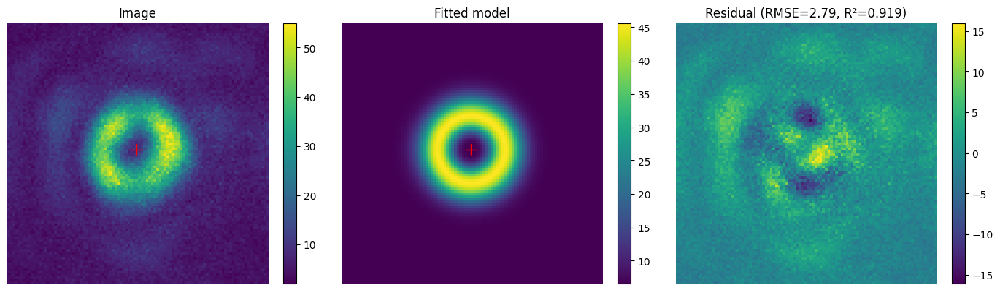

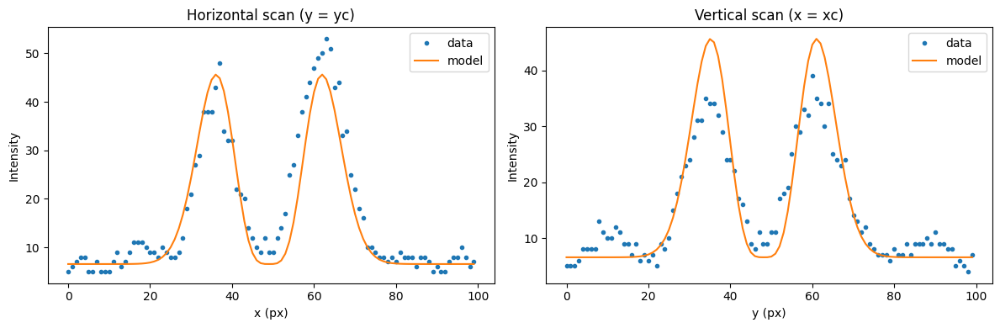

Params: {'A': 0.0115518319342507, 'w': 9.280641644663545, 'xc': 49.005573524107575, 'yc': 48.997211726880096, 'B': 6.832241656492059}
Uncertainties: {'A': 0.00010693683151159084, 'w': 0.015956756682196448, 'xc': 0.03507347885816869, 'yc': 0.03507347885367949, 'B': 0.05073884280941172}
RMSE: 4.612524517945805 R^2: 0.8570242131235922


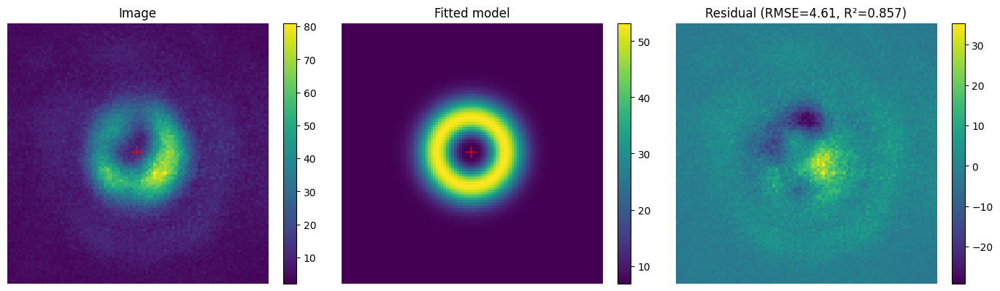

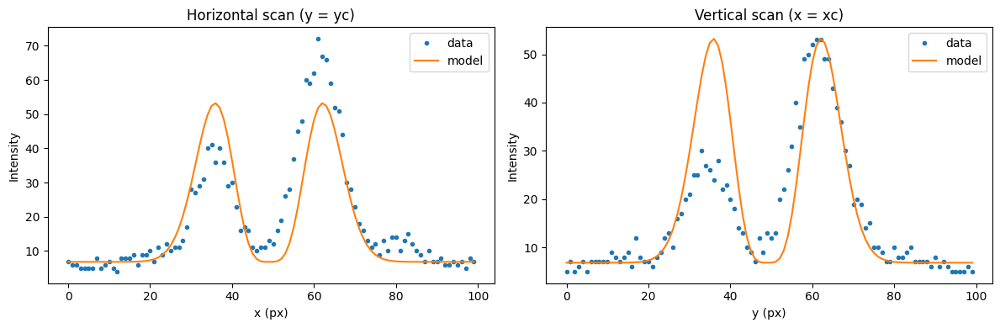

Params: {'A': 0.010440452537157311, 'w': 8.92721923113837, 'xc': 48.69323689601358, 'yc': 49.24993479454924, 'B': 4.075254225609272}
Uncertainties: {'A': 0.00010337633968781671, 'w': 0.016392891524881825, 'xc': 0.0360863052642465, 'yc': 0.036086305251550835, 'B': 0.040082397459402626}
RMSE: 3.6721761853323467 R^2: 0.8414057272675404


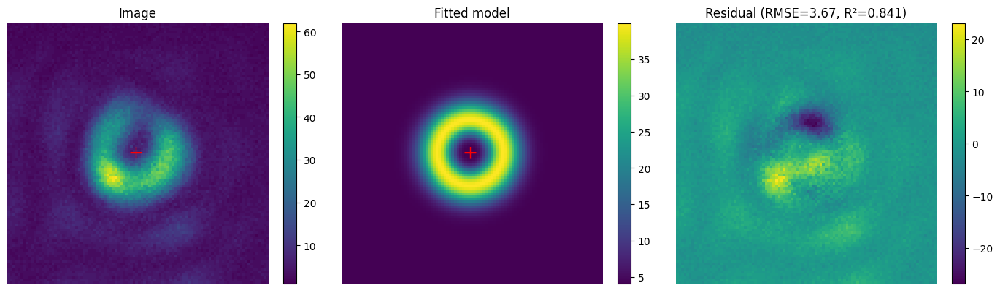

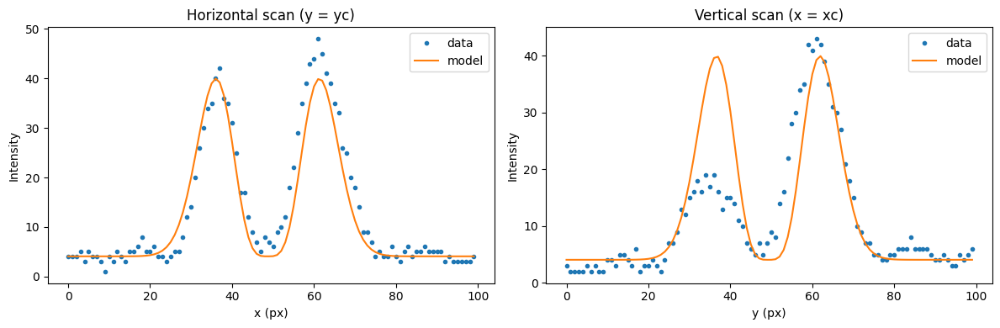

Params: {'A': 0.012455101227942513, 'w': 8.922617434599834, 'xc': 48.673876471592855, 'yc': 48.636722835471105, 'B': 6.189957901546902}
Uncertainties: {'A': 0.00010186533332055181, 'w': 0.013533207717854974, 'xc': 0.02979173612387976, 'yc': 0.029791736126008016, 'B': 0.039390964087178564}
RMSE: 3.609184902128981 R^2: 0.8860705493452199


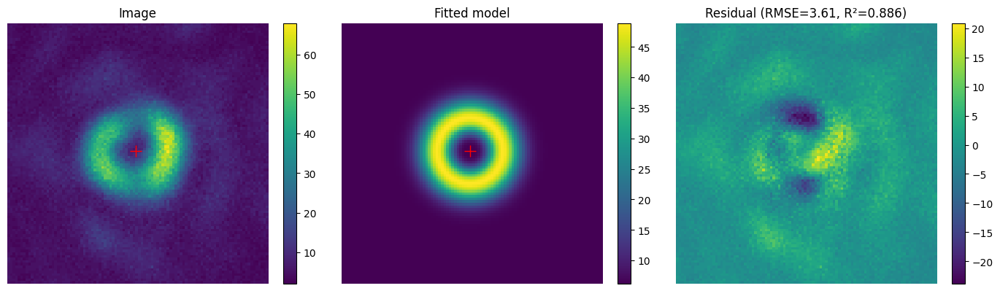

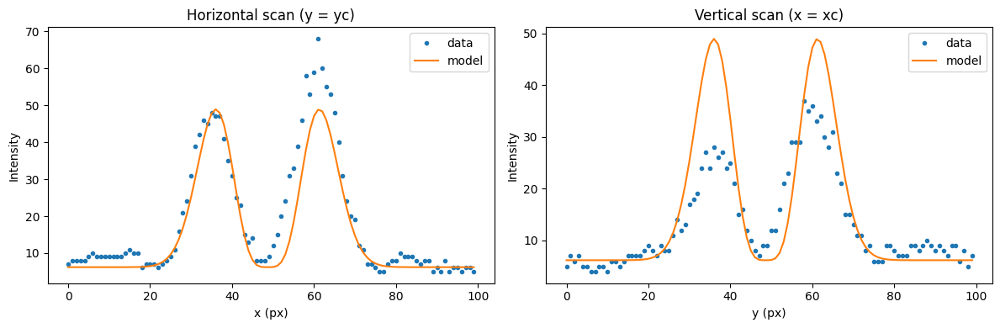

Params: {'A': 0.011679317734785376, 'w': 9.319800821496571, 'xc': 48.92628837426306, 'yc': 48.8634315501426, 'B': 6.789495434622581}
Uncertainties: {'A': 9.754033575261925e-05, 'w': 0.014459011555145469, 'xc': 0.031775895204461876, 'yc': 0.03177589520540064, 'B': 0.047307019482473275}
RMSE: 4.296736875057782 R^2: 0.880298435735544


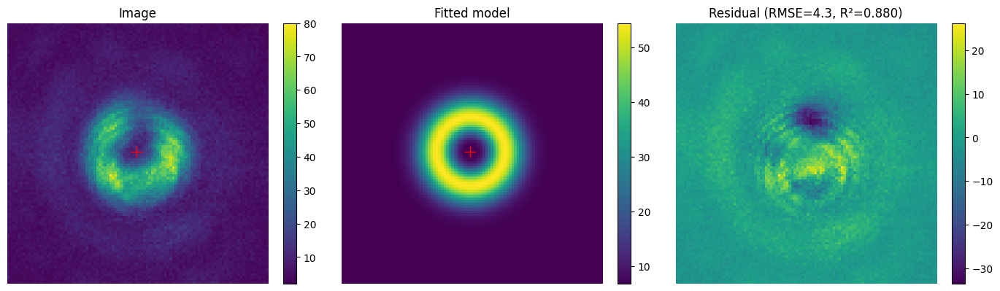

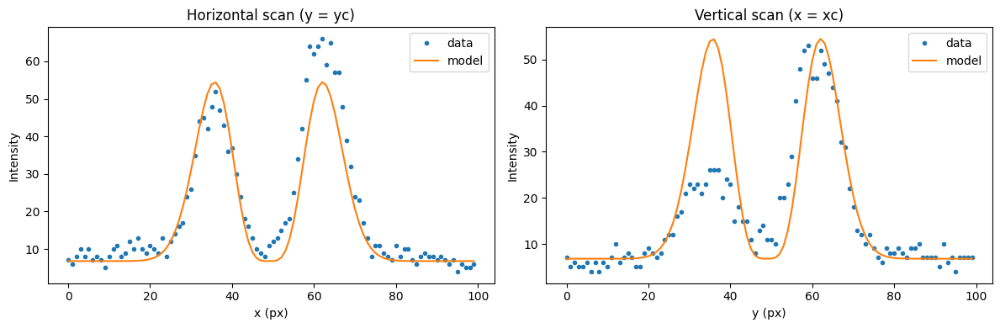

Params: {'A': 0.010141529402855351, 'w': 9.027308276038724, 'xc': 48.53683818370983, 'yc': 48.93404573259694, 'B': 6.250678296916718}
Uncertainties: {'A': 8.102231148160715e-05, 'w': 0.01338065594262937, 'xc': 0.029443120709288475, 'yc': 0.02944312071143585, 'B': 0.03328770502477489}
RMSE: 3.043107925212889 R^2: 0.890362438723984


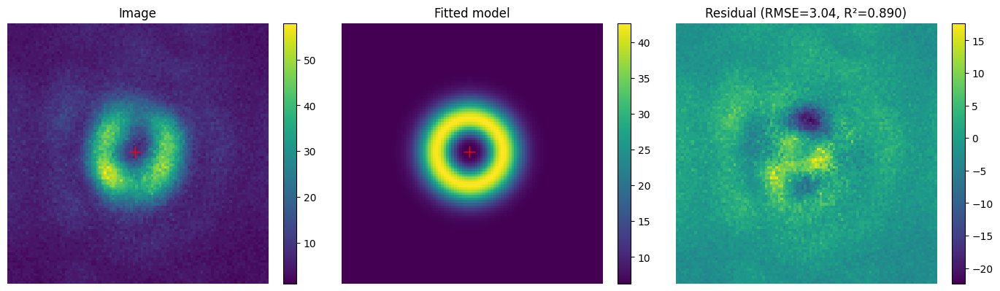

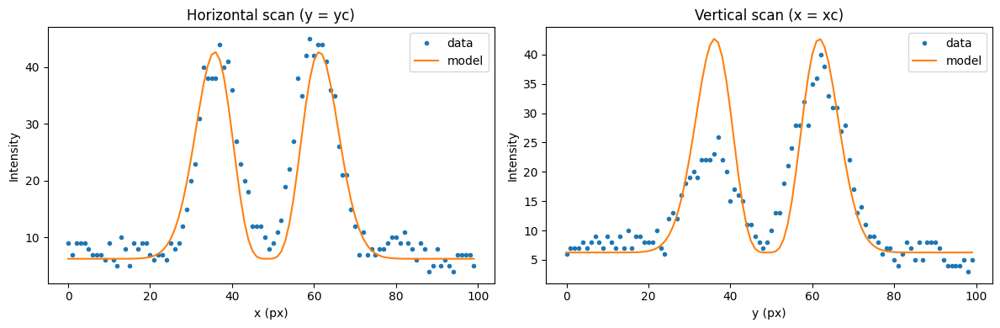

Params: {'A': 0.010558453150779324, 'w': 9.146715984676213, 'xc': 48.28881093436125, 'yc': 48.785505350655185, 'B': 4.182176169595229}
Uncertainties: {'A': 9.086539482226526e-05, 'w': 0.014611712785966006, 'xc': 0.03213570305838068, 'yc': 0.03213570305926274, 'B': 0.03997131644432877}
RMSE: 3.644566225415165 R^2: 0.8745163203120123


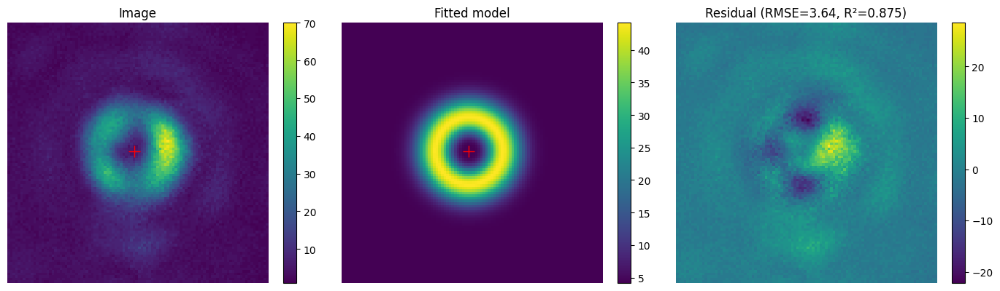

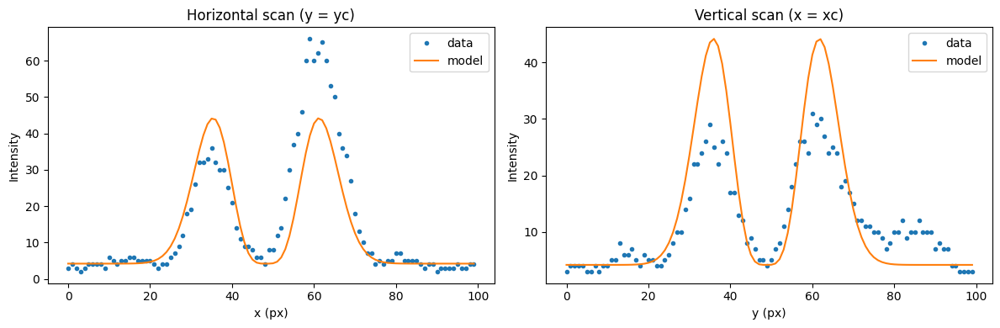

Params: {'A': 0.008583048294676732, 'w': 9.240159120957687, 'xc': 48.222582283660735, 'yc': 48.44174955298829, 'B': 5.372511324423553}
Uncertainties: {'A': 6.891554323331682e-05, 'w': 0.013777431478690984, 'xc': 0.030288618746936998, 'yc': 0.030288618748676898, 'B': 0.03196260089786018}
RMSE: 2.9082771596616683 R^2: 0.8886337868195945


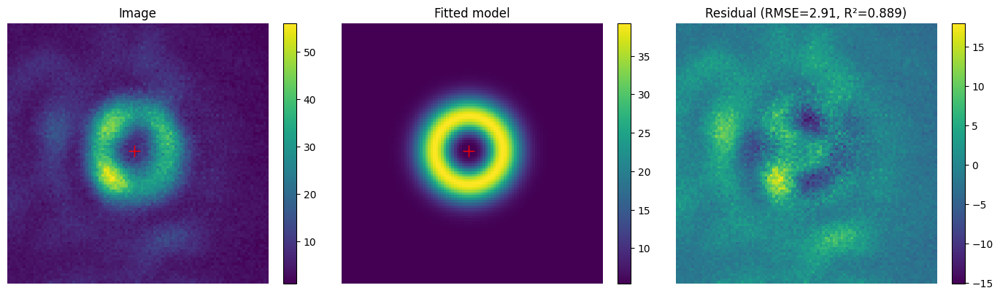

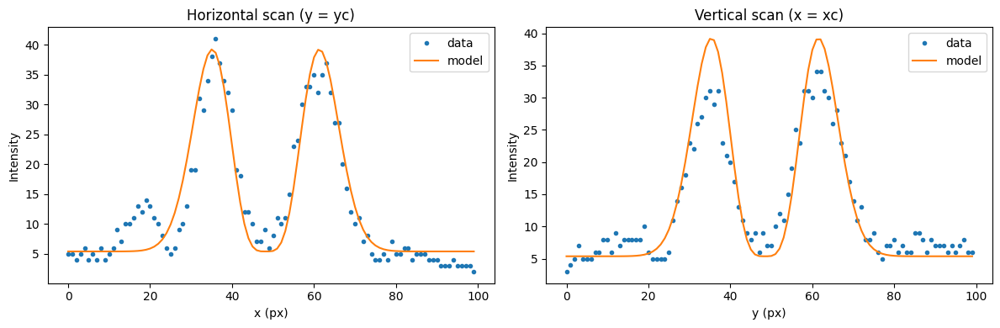

Params: {'A': 0.009820535917204987, 'w': 9.08497950905662, 'xc': 48.10460642314932, 'yc': 48.366952046770756, 'B': 5.748364888170077}
Uncertainties: {'A': 7.48292492431511e-05, 'w': 0.012846464642044973, 'xc': 0.028260805930545564, 'yc': 0.0282608059371191, 'B': 0.0317778941339031}
RMSE: 2.9014327361866346 R^2: 0.8990873411957329


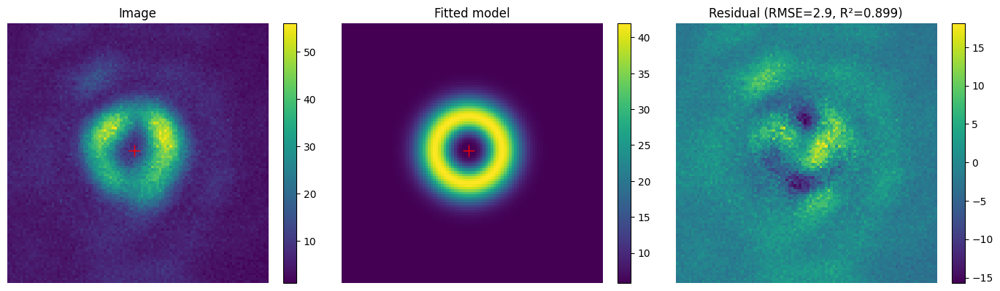

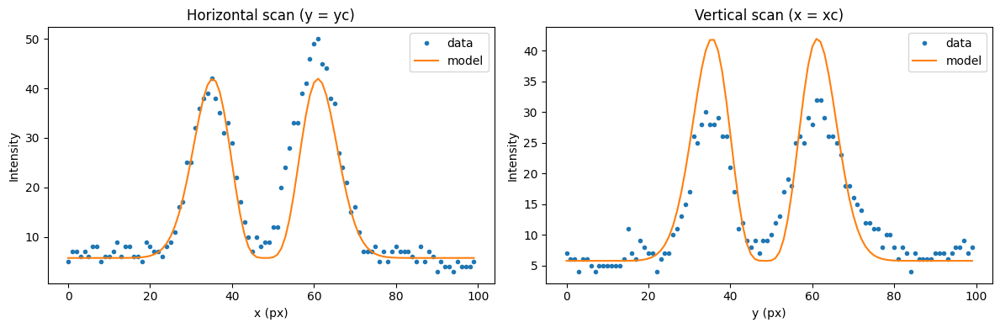

Params: {'A': 0.008613046335351931, 'w': 9.068499303087615, 'xc': 47.90469623694667, 'yc': 49.01541402190731, 'B': 5.000319898753194}
Uncertainties: {'A': 6.598217223480679e-05, 'w': 0.01289135155269271, 'xc': 0.028361528996937425, 'yc': 0.0283615289841278, 'B': 0.027757550740220537}
RMSE: 2.5352750762847145 R^2: 0.8981613113082995


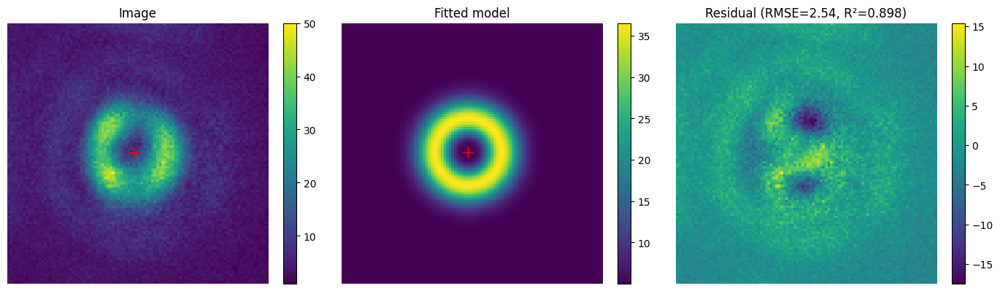

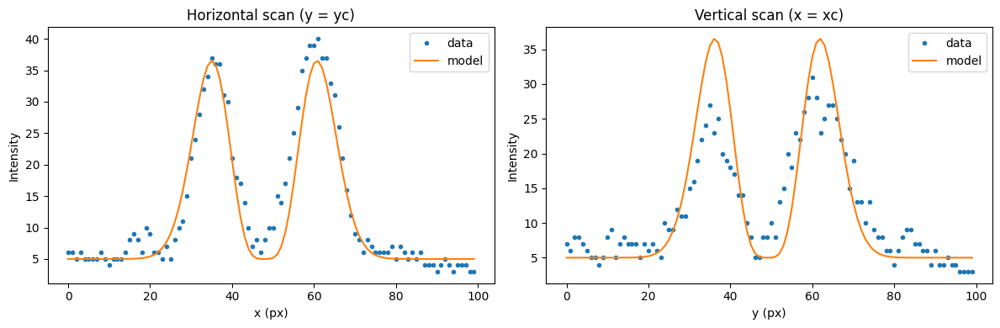

writing phase
Params: {'A': 0.0105430451471607, 'w': 9.045593382340295, 'xc': 49.5889999161496, 'yc': 48.720166957963826, 'B': 3.493455966798731}
Uncertainties: {'A': 7.063731084486128e-05, 'w': 0.011244921709432417, 'xc': 0.02474170039201774, 'yc': 0.02474170040164397, 'B': 0.02932783099742884}
RMSE: 2.680037203943848 R^2: 0.9202533648739296


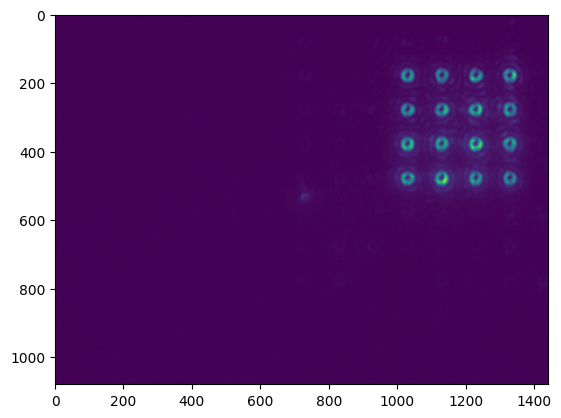

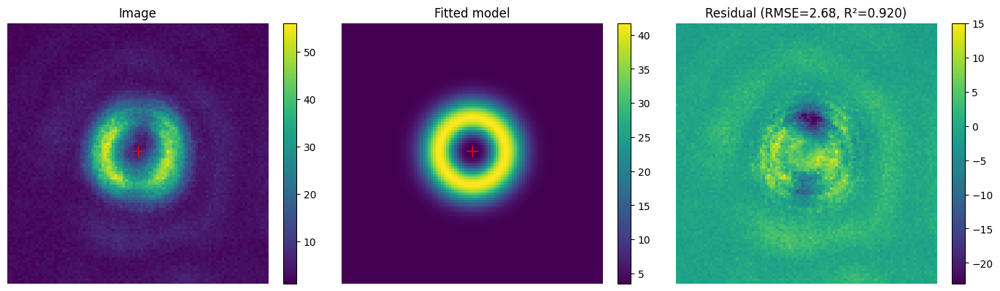

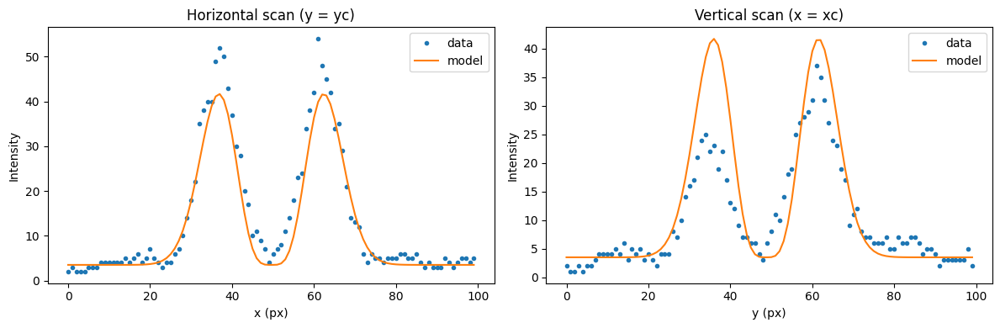

Params: {'A': 0.010017144782442615, 'w': 9.001717856282955, 'xc': 49.77082217941003, 'yc': 48.63422121617497, 'B': 4.249500336254095}
Uncertainties: {'A': 8.36197068135994e-05, 'w': 0.013939961871932855, 'xc': 0.030677112357631906, 'yc': 0.03067711235956191, 'B': 0.03385187333182484}
RMSE: 3.09639944921058 R^2: 0.8815877885158776


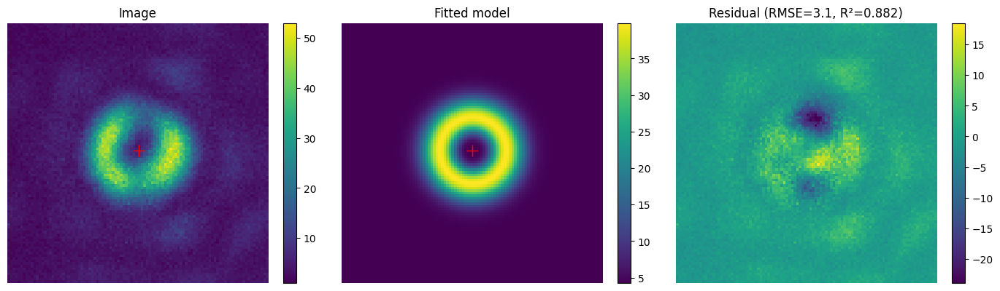

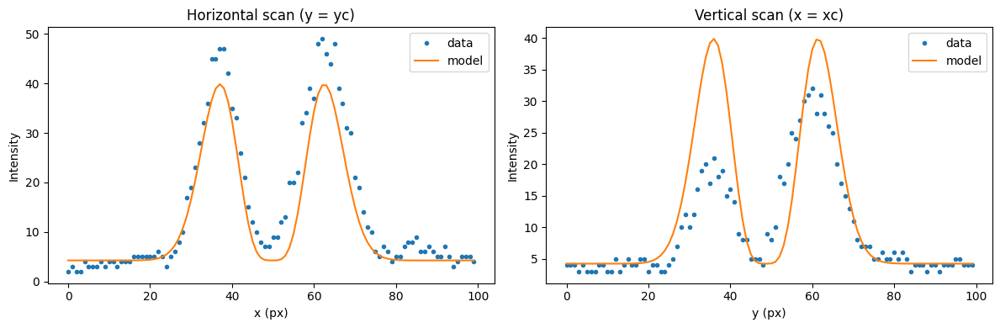

Params: {'A': 0.01256427015783118, 'w': 9.022301964122605, 'xc': 49.461581574682604, 'yc': 48.7157274348768, 'B': 5.625946782939927}
Uncertainties: {'A': 9.016784771405785e-05, 'w': 0.01201270032558045, 'xc': 0.026433592253913195, 'yc': 0.02643359225538367, 'B': 0.03693849307723867}
RMSE: 3.3772238907528265 R^2: 0.9096331401981198


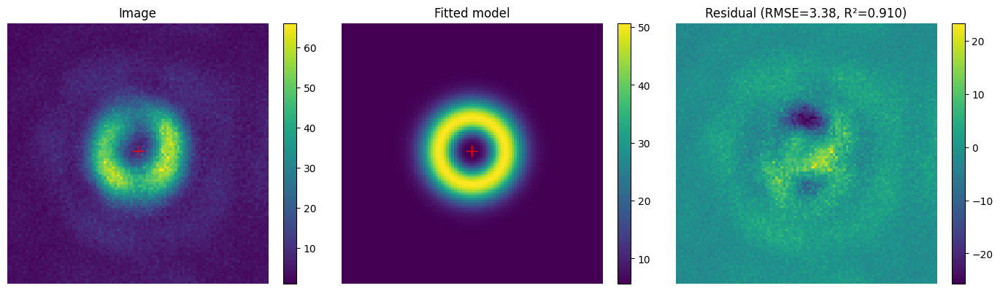

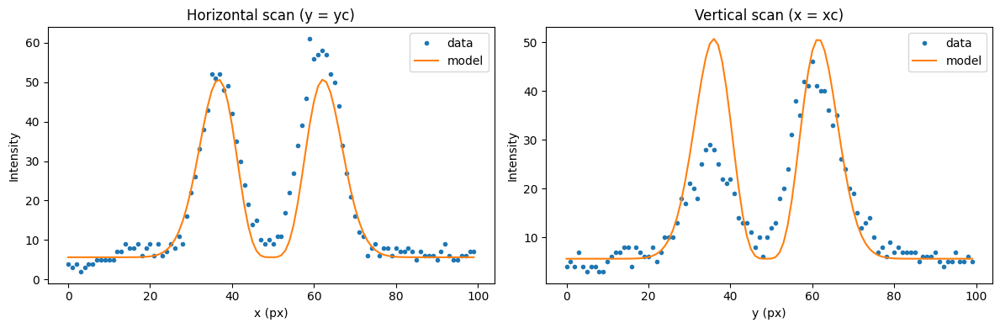

Params: {'A': 0.009566498944336688, 'w': 9.223927259329157, 'xc': 49.79777249827008, 'yc': 48.84024973735243, 'B': 5.690370764830851}
Uncertainties: {'A': 7.816404730284208e-05, 'w': 0.013994337939129277, 'xc': 0.030767646085160052, 'yc': 0.03076764609248947, 'B': 0.03592163954771922}
RMSE: 3.269698771916799 R^2: 0.8851923963217423


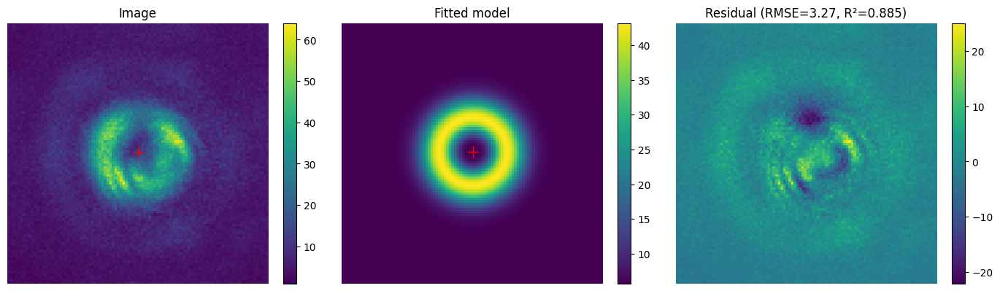

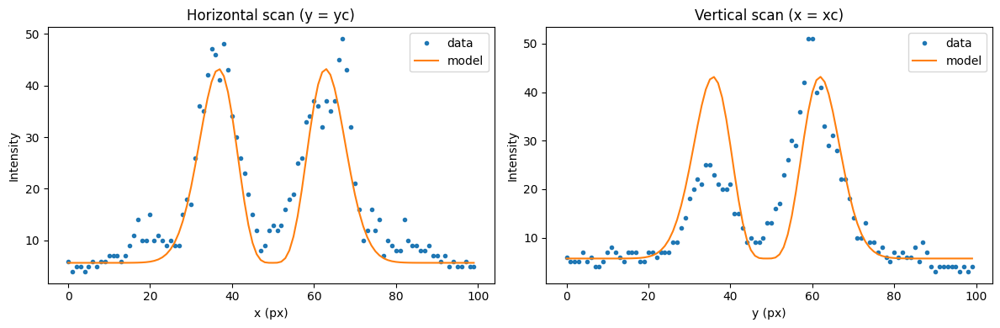

Params: {'A': 0.008505758737658497, 'w': 9.111187207856418, 'xc': 49.65006956914695, 'yc': 48.50281288857703, 'B': 4.020966962223739}
Uncertainties: {'A': 6.181027015969757e-05, 'w': 0.012288372238339706, 'xc': 0.027030055850122178, 'yc': 0.027030055843620743, 'B': 0.026645215328808737}
RMSE: 2.431402455900646 R^2: 0.9072921381791024


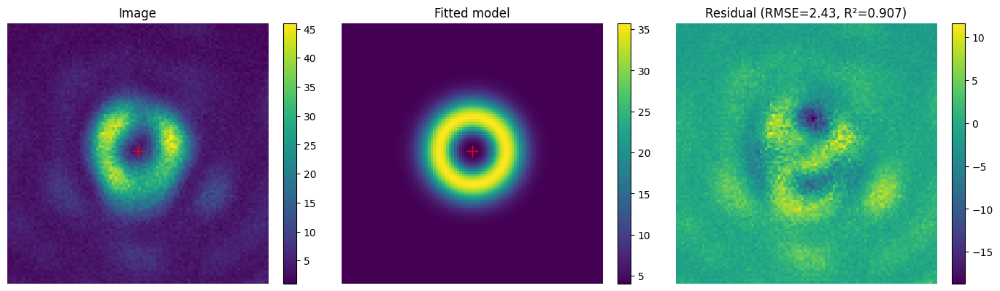

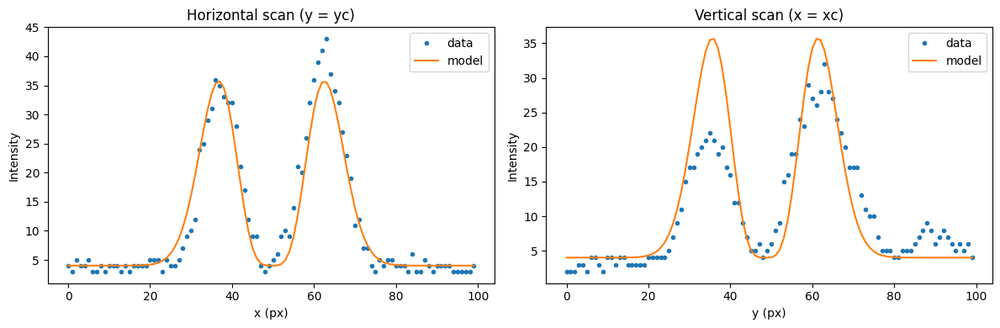

Params: {'A': 0.010003519783492907, 'w': 9.066465160153474, 'xc': 49.68962435746481, 'yc': 48.496199013800094, 'B': 5.321012884663343}
Uncertainties: {'A': 9.060931798067554e-05, 'w': 0.015238685152699176, 'xc': 0.03352605199448705, 'yc': 0.033526051981078414, 'B': 0.03807333889583861}
RMSE: 3.4776366557888676 R^2: 0.8631855724792429


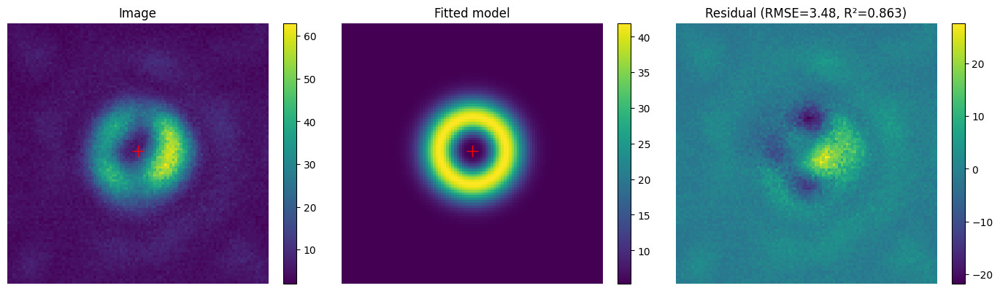

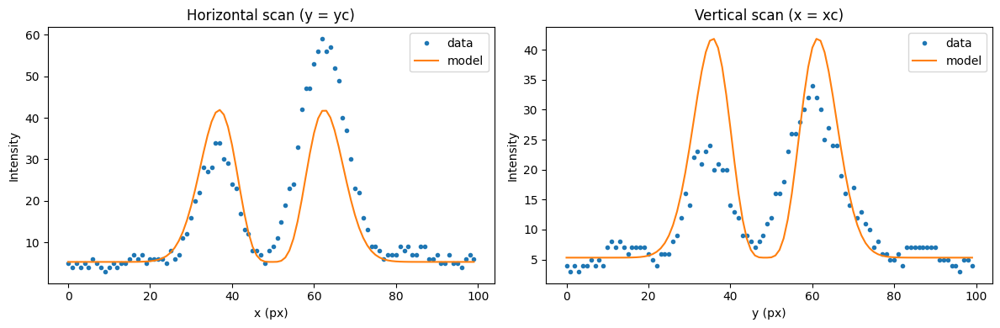

Params: {'A': 0.010798330034467646, 'w': 9.086118113382158, 'xc': 49.201527476198, 'yc': 47.92038484333871, 'B': 6.56715661266355}
Uncertainties: {'A': 7.353613191988259e-05, 'w': 0.011482808746630128, 'xc': 0.02526079148077294, 'yc': 0.025260791490558352, 'B': 0.031249096705281608}
RMSE: 2.853080531503678 R^2: 0.9177211959082257


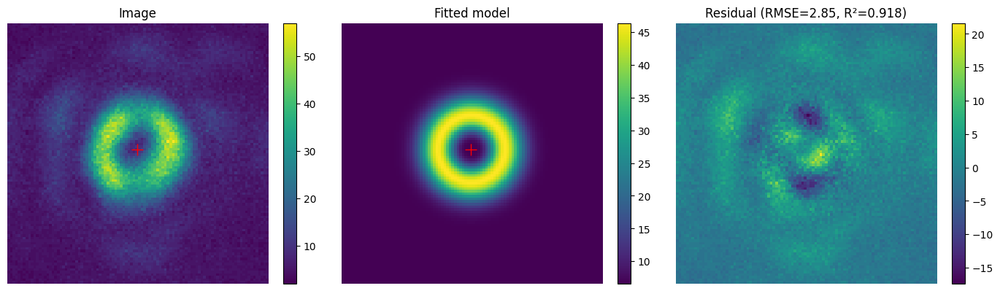

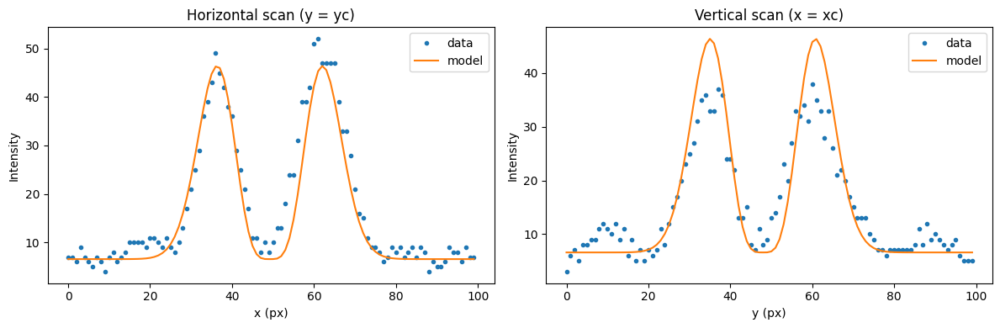

Params: {'A': 0.011866810834744987, 'w': 9.24626706931002, 'xc': 49.13310976082096, 'yc': 48.83930531098171, 'B': 6.8440878211528}
Uncertainties: {'A': 0.00010997145460815645, 'w': 0.015912453313035084, 'xc': 0.034981366814422925, 'yc': 0.0349813668176821, 'B': 0.05117988882114117}
RMSE: 4.656220033313803 R^2: 0.8569119499038287


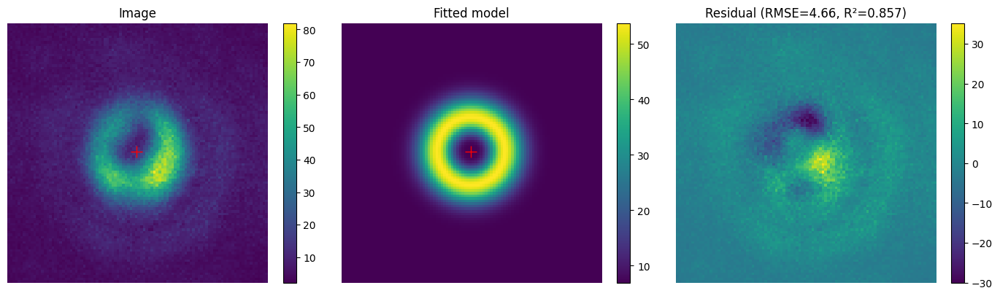

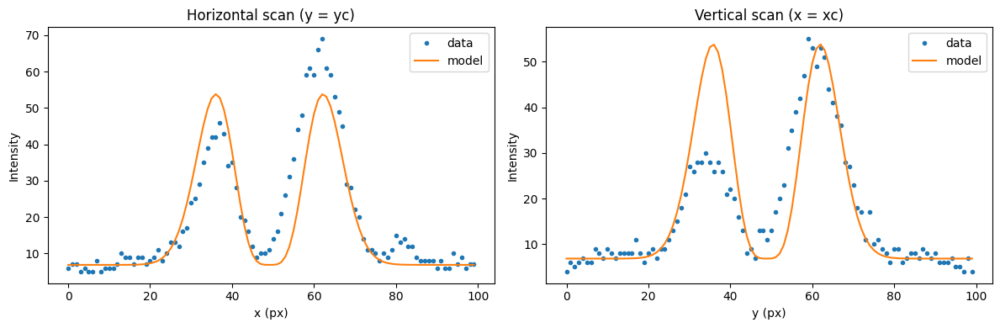

Params: {'A': 0.010654859535704941, 'w': 8.913081420260495, 'xc': 48.8432916829853, 'yc': 49.1665339133821, 'B': 4.068636715072806}
Uncertainties: {'A': 0.00010724120873894644, 'w': 0.01663620159245976, 'xc': 0.03662403888328844, 'yc': 0.03662403889120473, 'B': 0.041240271393963954}
RMSE: 3.779396247895698 R^2: 0.8370526403345093


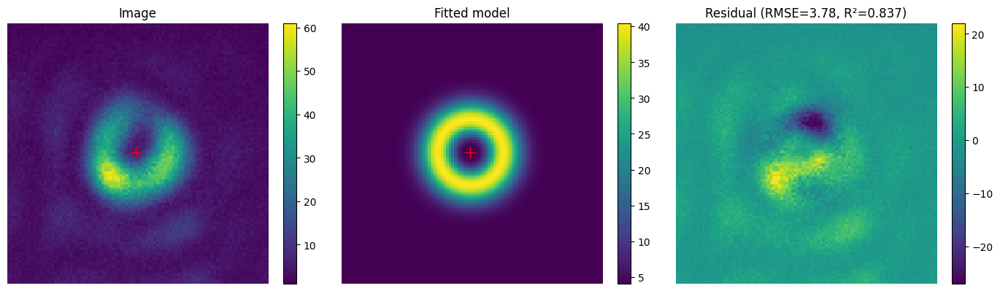

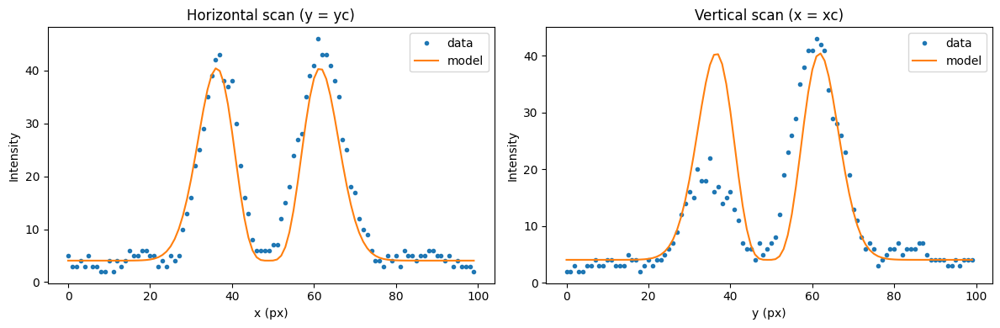

Params: {'A': 0.012472412139816277, 'w': 8.923117661273551, 'xc': 48.84865747130577, 'yc': 48.41115632322608, 'B': 6.192339043899813}
Uncertainties: {'A': 0.0001008664071746284, 'w': 0.013382675210826651, 'xc': 0.02946029620845267, 'yc': 0.029460296196911782, 'B': 0.03901603453968963}
RMSE: 3.574793901324487 R^2: 0.8883192847195687


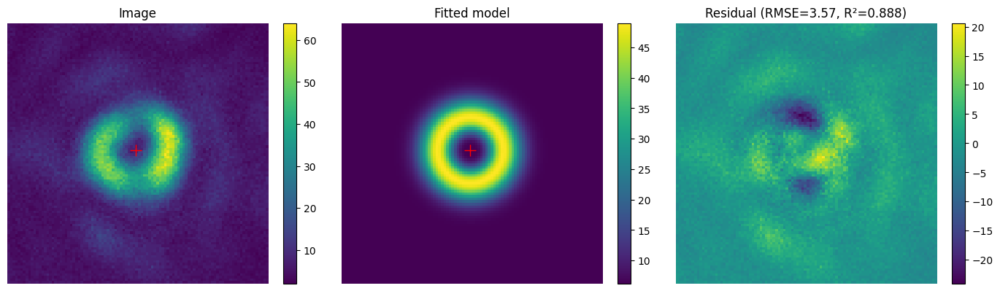

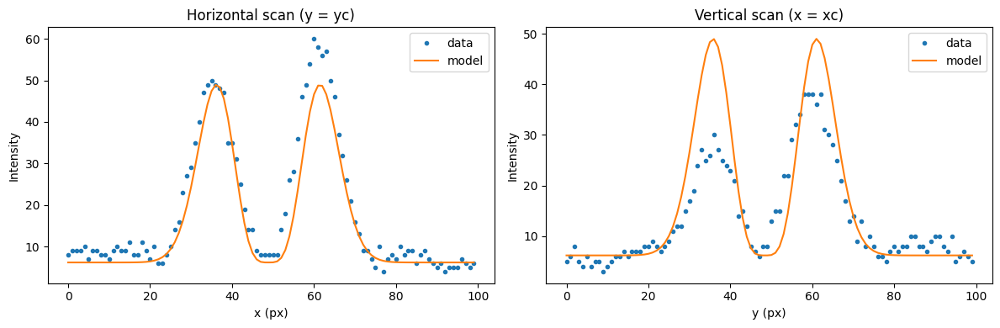

Params: {'A': 0.011771747543525944, 'w': 9.3036567208376, 'xc': 49.01225605441995, 'yc': 48.7313616359424, 'B': 6.793696493354453}
Uncertainties: {'A': 9.915983020395624e-05, 'w': 0.014557363056563632, 'xc': 0.03199432141784104, 'yc': 0.03199432141040182, 'B': 0.04765992604302504}
RMSE: 4.330375144998768 R^2: 0.8785404137898295


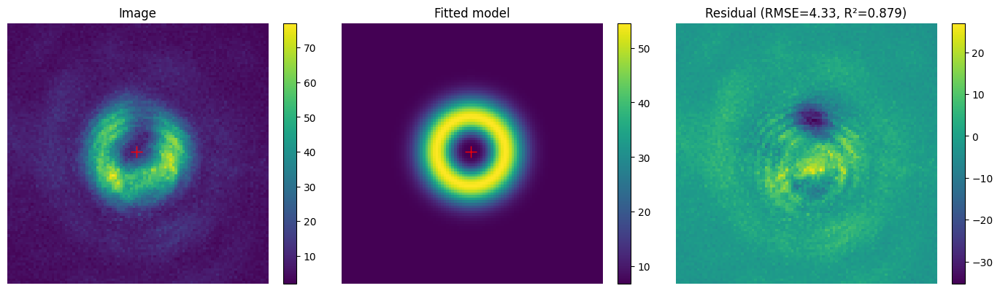

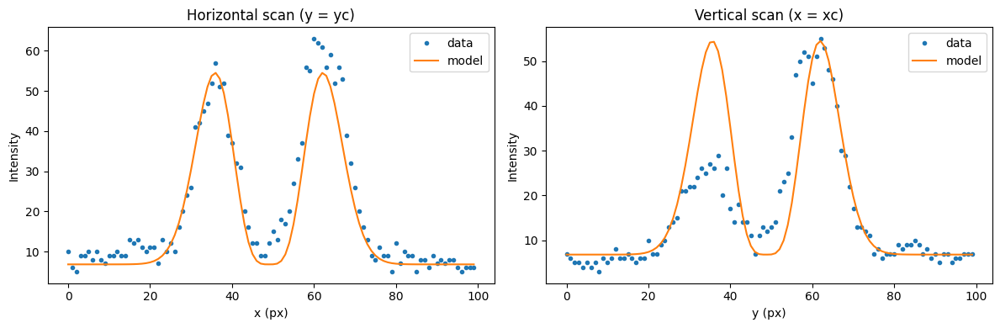

Params: {'A': 0.010245725815916666, 'w': 9.013530397695915, 'xc': 48.68236249492358, 'yc': 48.76522271445258, 'B': 6.236930080077119}
Uncertainties: {'A': 8.349971327013117e-05, 'w': 0.013627936425031923, 'xc': 0.029988971622111057, 'yc': 0.02998897162457086, 'B': 0.03403437108331665}
RMSE: 3.112296619582881 R^2: 0.886465671804521


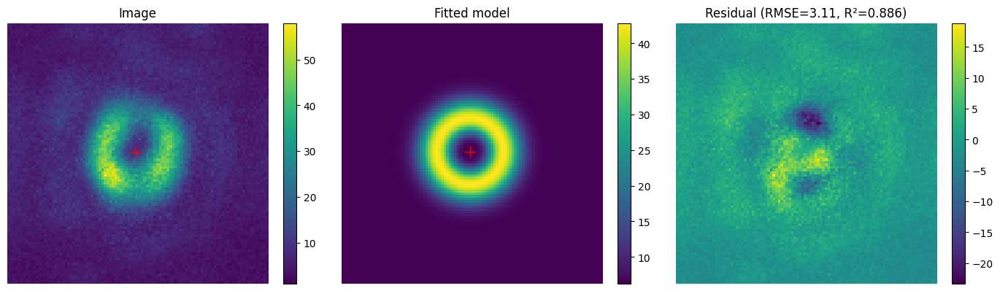

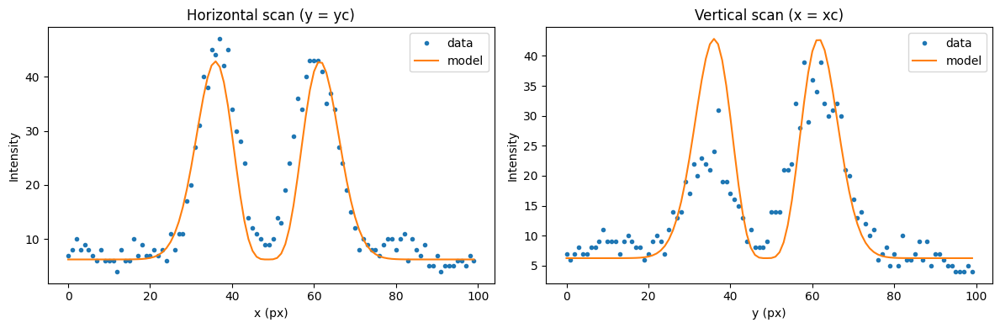

Params: {'A': 0.010973600874848197, 'w': 9.078168074143056, 'xc': 48.4634732404008, 'yc': 48.607853516188406, 'B': 4.219712882417059}
Uncertainties: {'A': 9.154666130870107e-05, 'w': 0.014054083132391924, 'xc': 0.03091832515217124, 'yc': 0.03091832515259532, 'B': 0.03872601584755743}
RMSE: 3.5363477391236637 R^2: 0.881438033768805


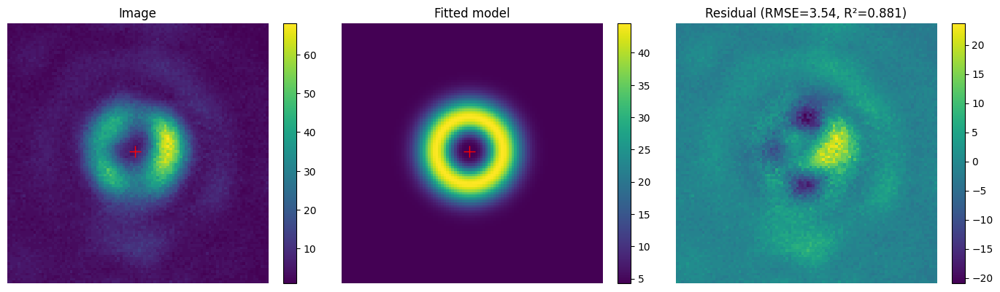

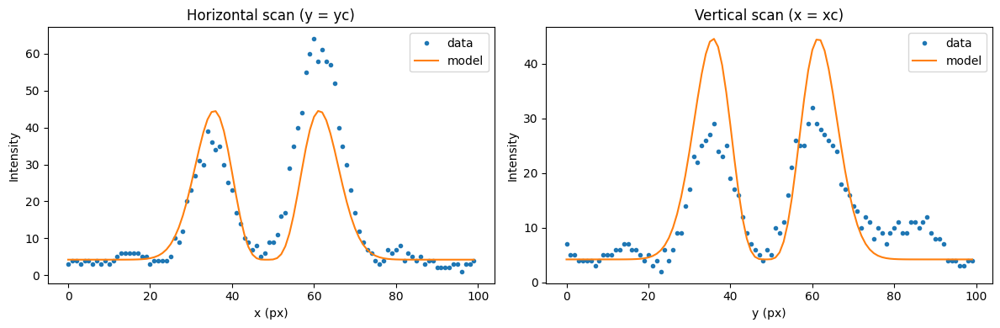

Params: {'A': 0.008835584139664702, 'w': 9.220659272194183, 'xc': 48.36225521609089, 'yc': 48.230677790055175, 'B': 5.345073167093116}
Uncertainties: {'A': 7.294756716362419e-05, 'w': 0.01413558632244849, 'xc': 0.031078633187603878, 'yc': 0.03107863317526239, 'B': 0.033462524470020384}
RMSE: 3.0460851595170024 R^2: 0.8830714085217901


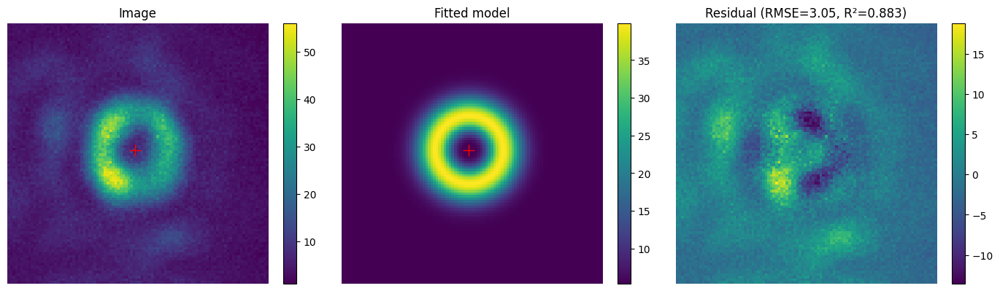

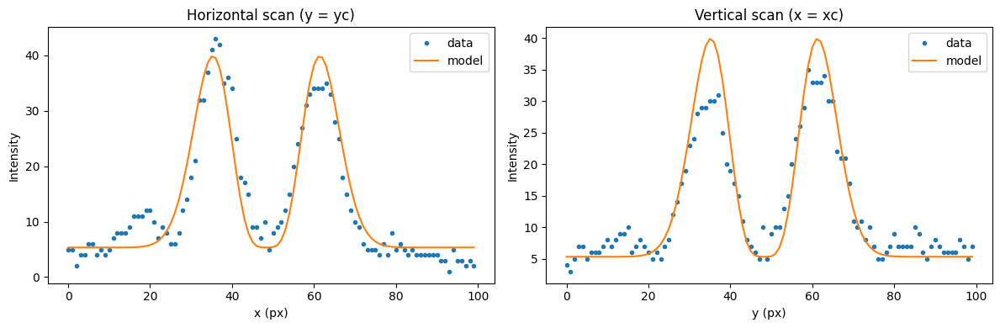

Params: {'A': 0.010185262073369554, 'w': 9.034488284713397, 'xc': 48.19722027922469, 'yc': 48.182377646239644, 'B': 5.768146575349382}
Uncertainties: {'A': 7.62947423382913e-05, 'w': 0.012556164290434919, 'xc': 0.02762805758724126, 'yc': 0.02762805758620351, 'B': 0.031475163093311054}
RMSE: 2.8769596060125644 R^2: 0.9022998603317328


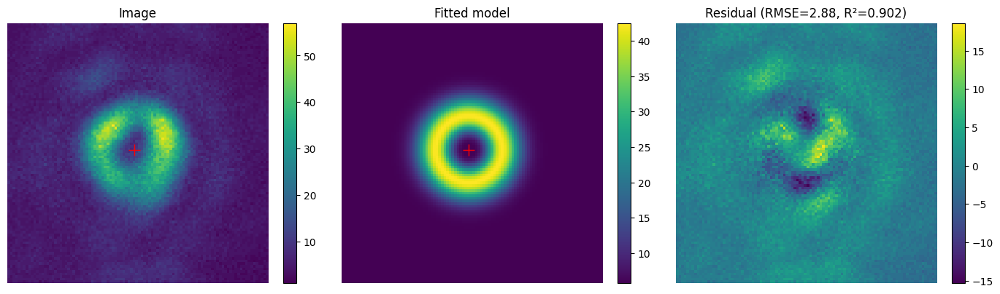

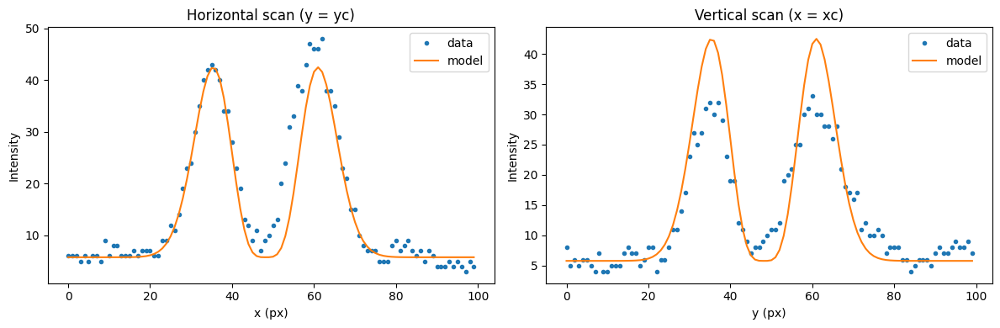

Params: {'A': 0.008883478555979235, 'w': 9.027092349715458, 'xc': 48.10421960312378, 'yc': 48.856838537406325, 'B': 5.005198909388703}
Uncertainties: {'A': 7.084768925059976e-05, 'w': 0.013356973979681185, 'xc': 0.02939103690713456, 'yc': 0.029391036915818125, 'B': 0.029103883225518448}
RMSE: 2.6606422027019176 R^2: 0.8907037086676031


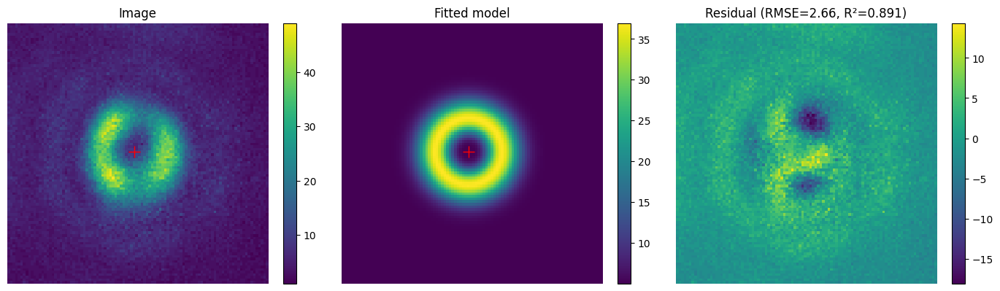

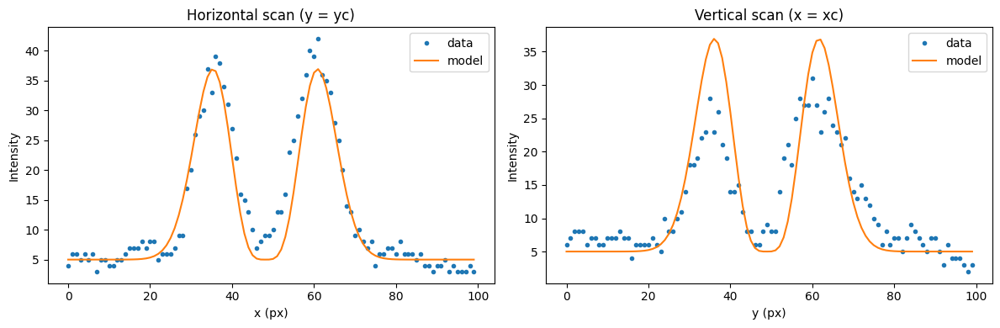

writing phase
Params: {'A': 0.01065453062700617, 'w': 9.028557500146684, 'xc': 49.88963129163612, 'yc': 48.66790168781942, 'B': 3.5584283815863236}
Uncertainties: {'A': 7.369727194801572e-05, 'w': 0.01158659124231933, 'xc': 0.02549528370048031, 'yc': 0.02549528370410948, 'B': 0.030300018153755867}
RMSE: 2.7699033244201106 R^2: 0.9154919812555704


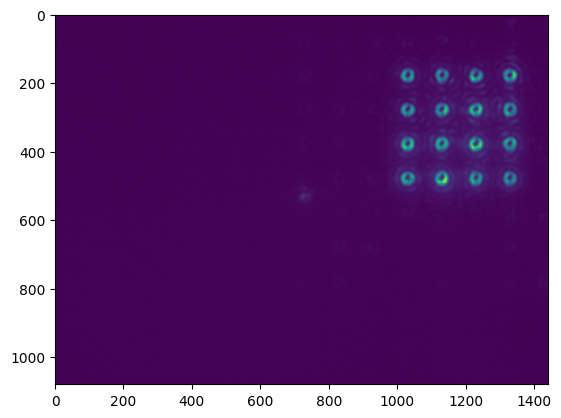

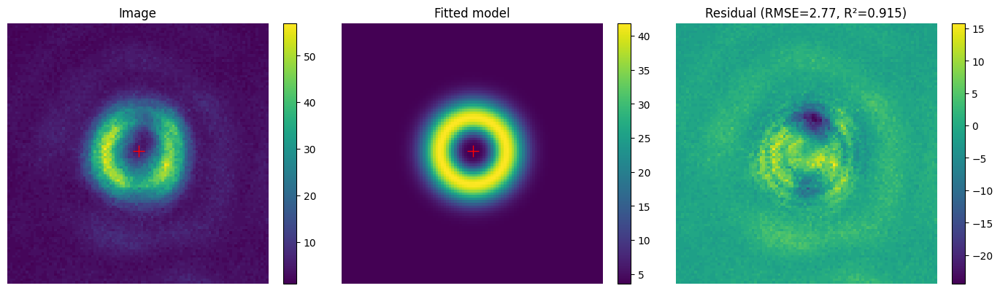

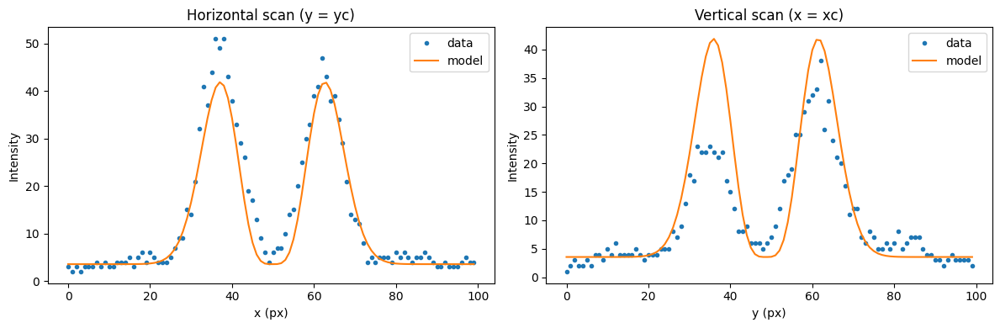

Params: {'A': 0.010293043506654427, 'w': 8.96518289385887, 'xc': 50.066048357729365, 'yc': 48.605385951523665, 'B': 4.286216174302272}
Uncertainties: {'A': 8.800344240075594e-05, 'w': 0.01421741283192844, 'xc': 0.031292437749745834, 'yc': 0.03129243775053275, 'B': 0.034881922227925945}
RMSE: 3.193131380682787 R^2: 0.8766380498704305


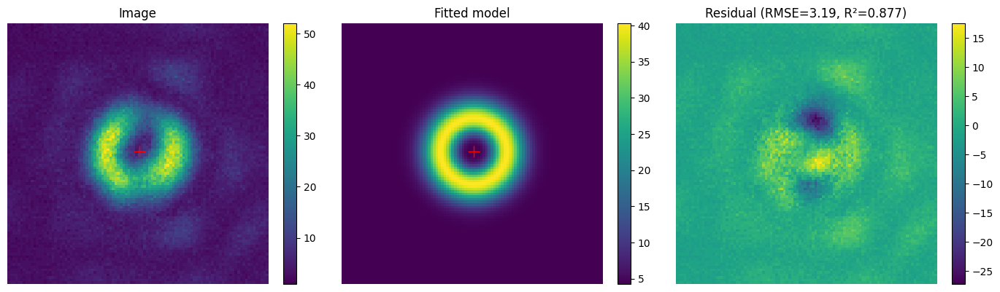

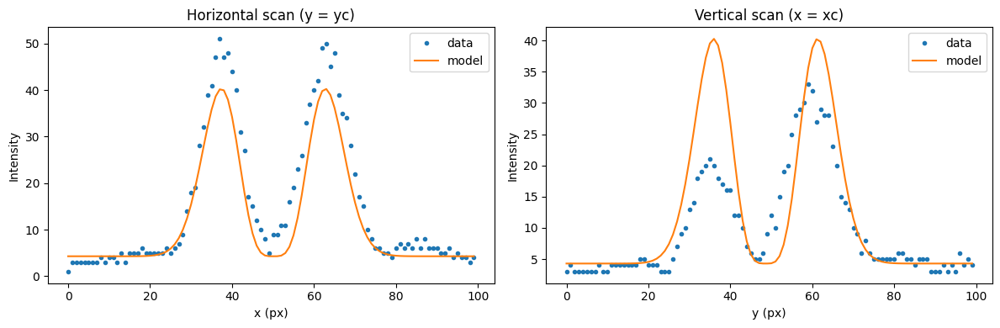

Params: {'A': 0.012757392269578168, 'w': 8.997853311827269, 'xc': 49.79228696676317, 'yc': 48.65491914106564, 'B': 5.710617982298086}
Uncertainties: {'A': 9.273017040788385e-05, 'w': 0.012132842541255823, 'xc': 0.026700687774975796, 'yc': 0.026700687763946063, 'B': 0.03745643221458619}
RMSE: 3.426391311913107 R^2: 0.9075838177308471


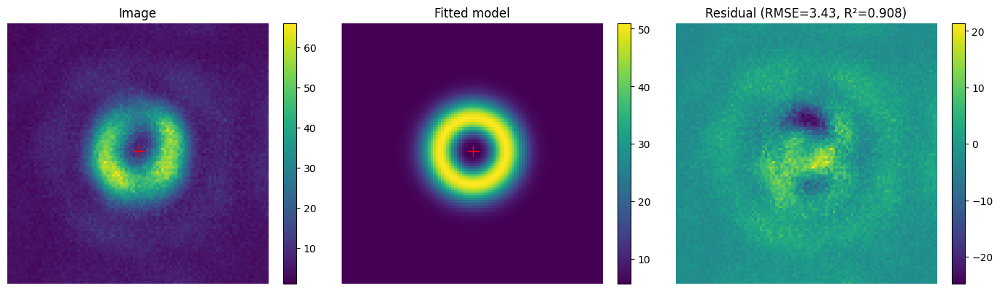

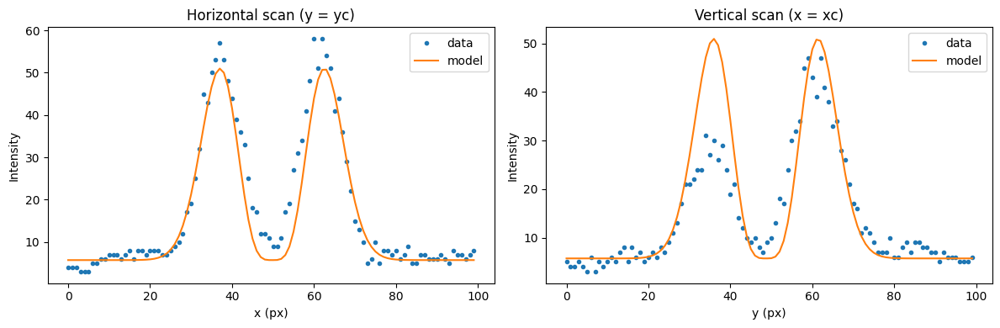

Params: {'A': 0.009685876698495813, 'w': 9.207640747480376, 'xc': 49.98304821629584, 'yc': 48.76700886111373, 'B': 5.738908471683947}
Uncertainties: {'A': 8.11310620575239e-05, 'w': 0.014320176070304962, 'xc': 0.031486253101035734, 'yc': 0.03148625310530639, 'B': 0.03694372699680021}
RMSE: 3.3639563386548503 R^2: 0.8801049645706767


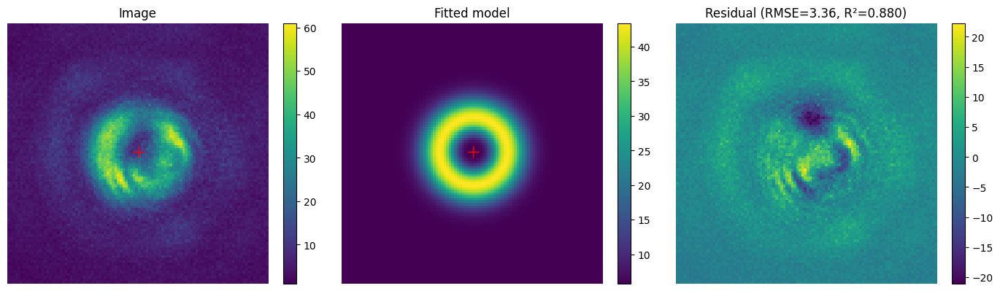

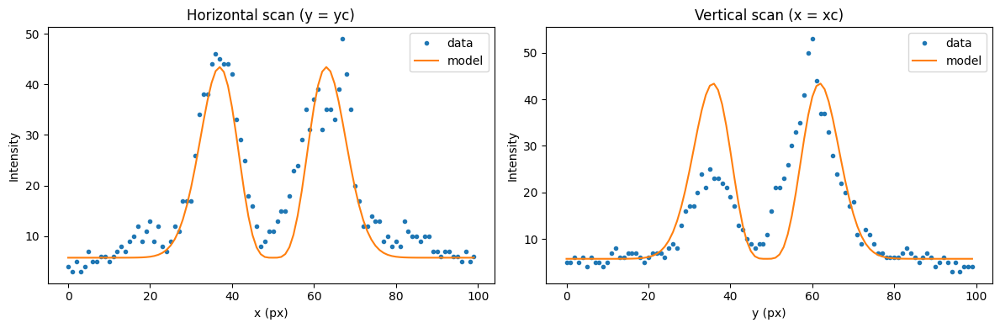

Params: {'A': 0.008788457087152545, 'w': 9.062857665660074, 'xc': 49.99031111317134, 'yc': 48.386623062711706, 'B': 4.09126748847627}
Uncertainties: {'A': 6.624078463899481e-05, 'w': 0.012675376051193177, 'xc': 0.02788703759325336, 'yc': 0.027887037583559874, 'B': 0.027776350112233443}
RMSE: 2.53730469549456 R^2: 0.9011133691222448


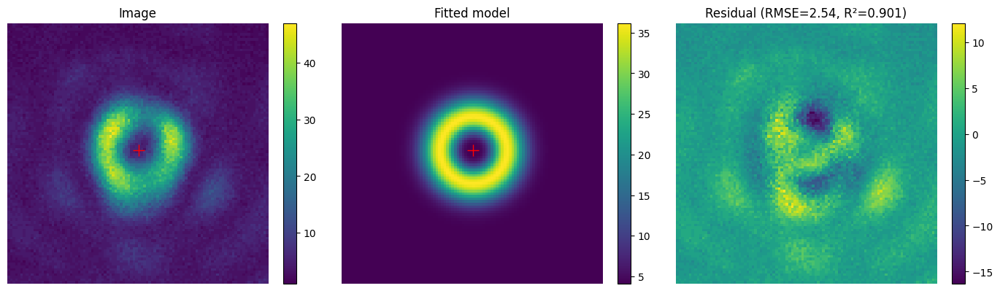

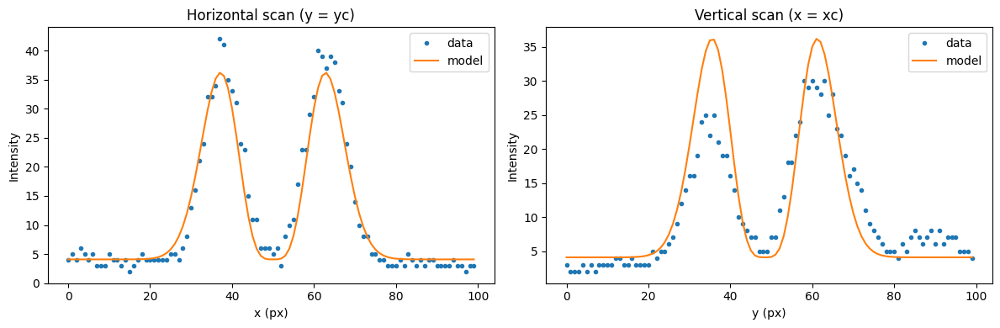

Params: {'A': 0.010400509453995585, 'w': 9.004890747809219, 'xc': 49.90528395884887, 'yc': 48.378737350694145, 'B': 5.388383200943576}
Uncertainties: {'A': 9.371908692315574e-05, 'w': 0.015053210410760031, 'xc': 0.033126555079376195, 'yc': 0.033126555065577046, 'B': 0.03800993915260541}
RMSE: 3.476495306708829 R^2: 0.8646557633646601


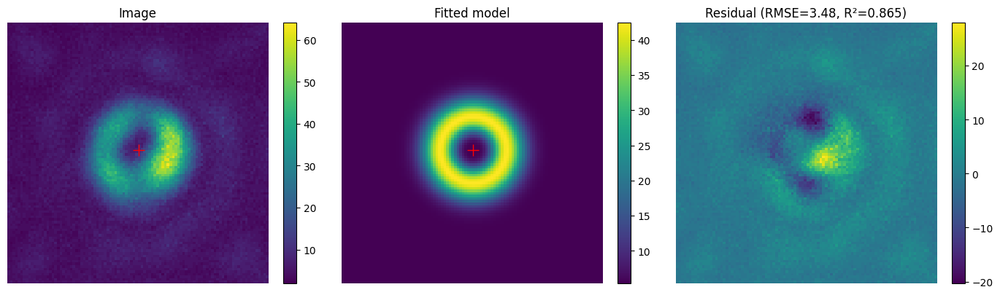

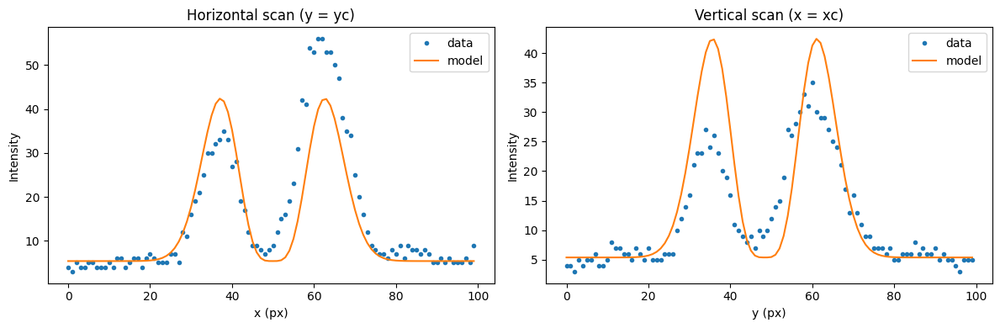

Params: {'A': 0.011188150590817432, 'w': 9.03720678605047, 'xc': 49.43286411602017, 'yc': 47.78913649127736, 'B': 6.6281875077053325}
Uncertainties: {'A': 7.855757618245483e-05, 'w': 0.011773347872305823, 'xc': 0.0259052854882989, 'yc': 0.025905285484977707, 'B': 0.0324593948710807}
RMSE: 2.9667471399711425 R^2: 0.9131184489107657


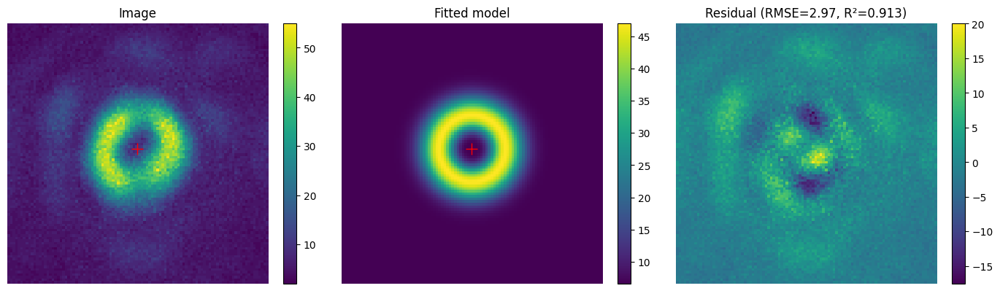

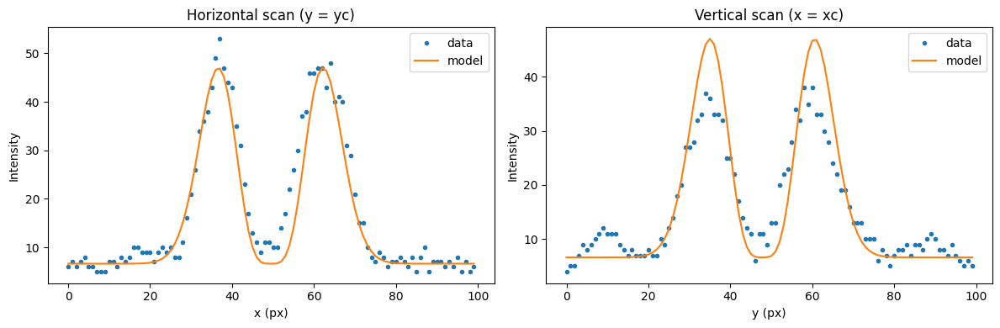

Params: {'A': 0.011981479706245352, 'w': 9.225833967152978, 'xc': 49.32489435887977, 'yc': 48.72176285854675, 'B': 6.919896951242802}
Uncertainties: {'A': 0.00011075343610983694, 'w': 0.015835743771369176, 'xc': 0.03481583200312009, 'yc': 0.034815831999306816, 'B': 0.05095345945528649}
RMSE: 4.63774365611507 R^2: 0.8576216231777964


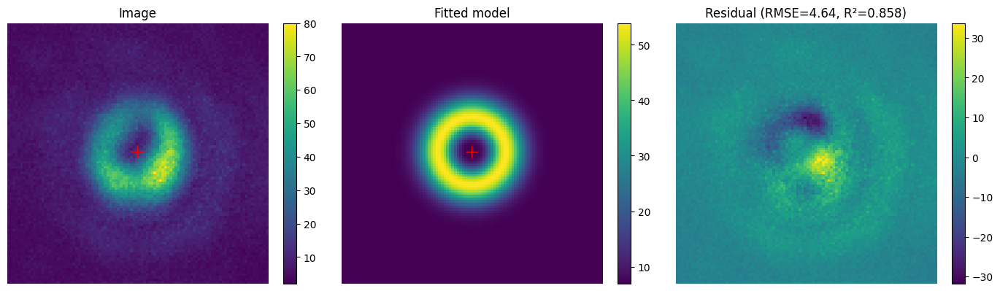

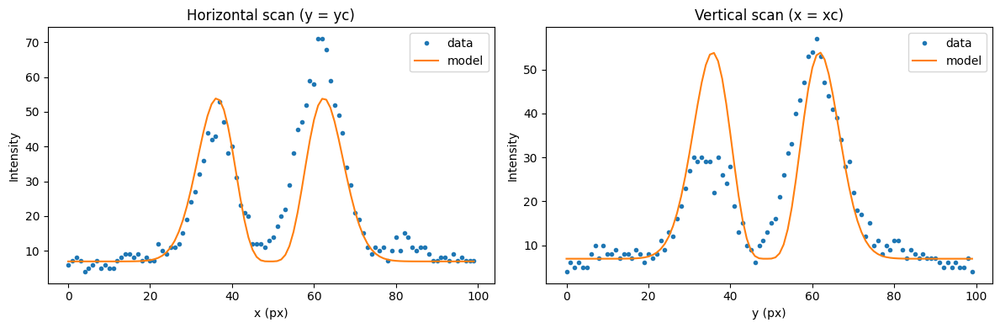

Params: {'A': 0.010791155446135015, 'w': 8.899376863211133, 'xc': 49.05708559827671, 'yc': 49.04456373605975, 'B': 4.118041559048993}
Uncertainties: {'A': 0.0001115852295180356, 'w': 0.01706421506191156, 'xc': 0.037568404542238566, 'yc': 0.037568404544023264, 'B': 0.04256948004076719}
RMSE: 3.902348583386724 R^2: 0.829620039149382


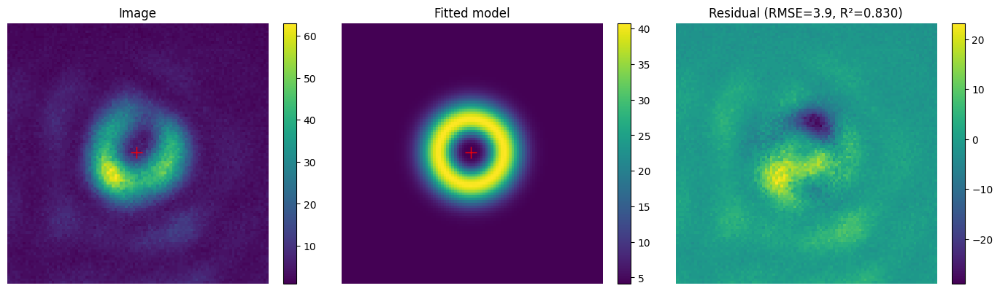

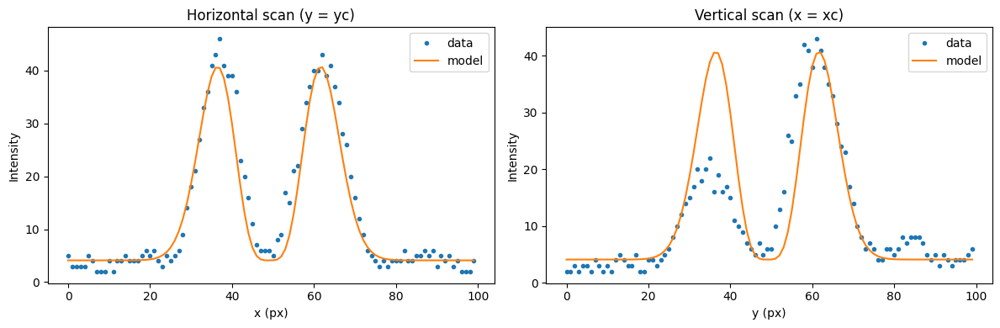

Params: {'A': 0.012725147186172467, 'w': 8.893117006922909, 'xc': 49.11416002982584, 'yc': 48.28186640914196, 'B': 6.254115737841706}
Uncertainties: {'A': 0.00010359321462514191, 'w': 0.013424537934892157, 'xc': 0.029556084061670318, 'yc': 0.02955608406282189, 'B': 0.03937650393476194}
RMSE: 3.6101288291423406 R^2: 0.8871037018801428


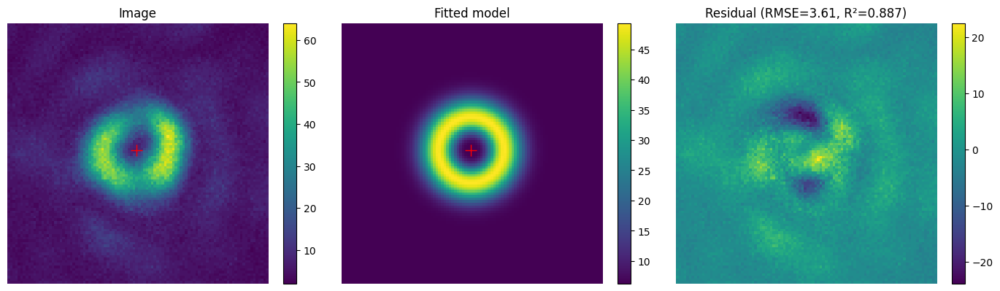

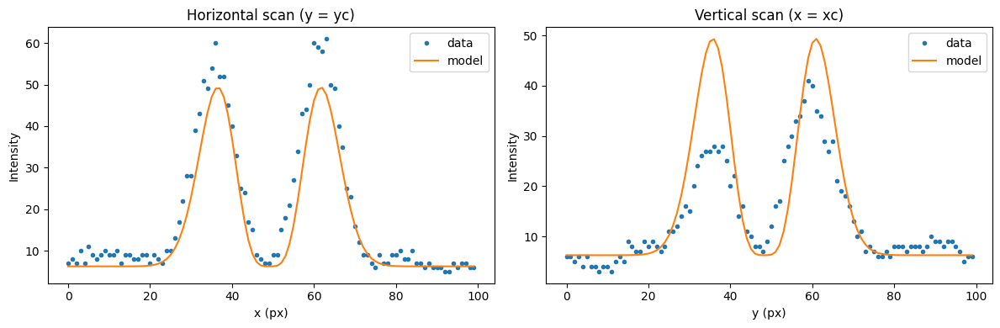

Params: {'A': 0.011962997213487033, 'w': 9.271513977148153, 'xc': 49.18676571398857, 'yc': 48.64151323470081, 'B': 6.897244892263053}
Uncertainties: {'A': 0.00010402310668640941, 'w': 0.014973151991616905, 'xc': 0.0329128027421673, 'yc': 0.03291280272966429, 'B': 0.049104007345731886}
RMSE: 4.4648252452128725 R^2: 0.8717276679842278


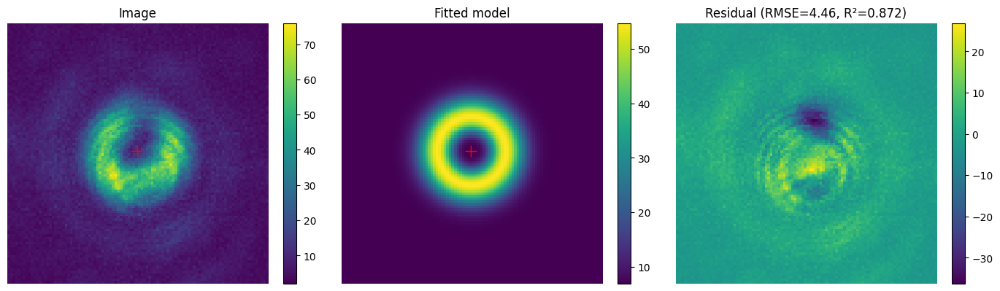

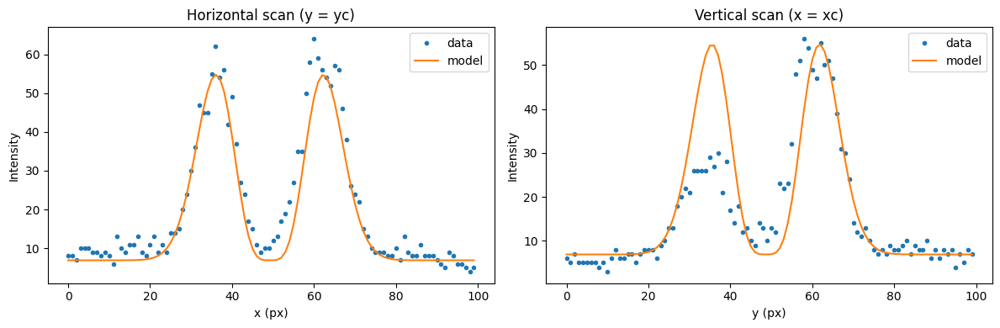

Params: {'A': 0.010434218966386563, 'w': 8.996916392720864, 'xc': 49.00898135326641, 'yc': 48.67721410683183, 'B': 6.291722163361312}
Uncertainties: {'A': 8.812980261519669e-05, 'w': 0.014096761242940655, 'xc': 0.031022795273621694, 'yc': 0.031022795270001634, 'B': 0.0355789588163153}
RMSE: 3.2547121036941857 R^2: 0.8791326744414308


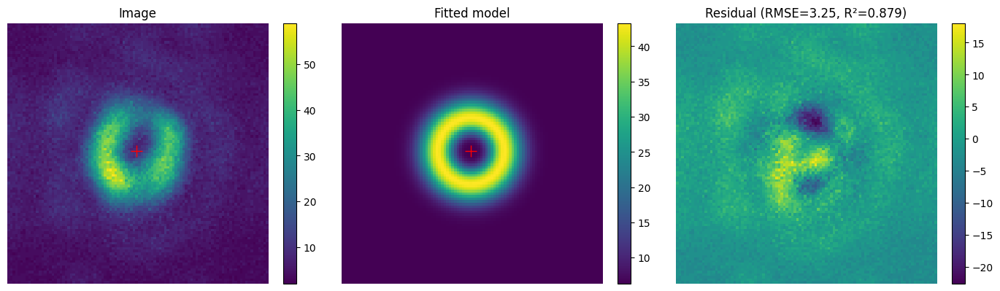

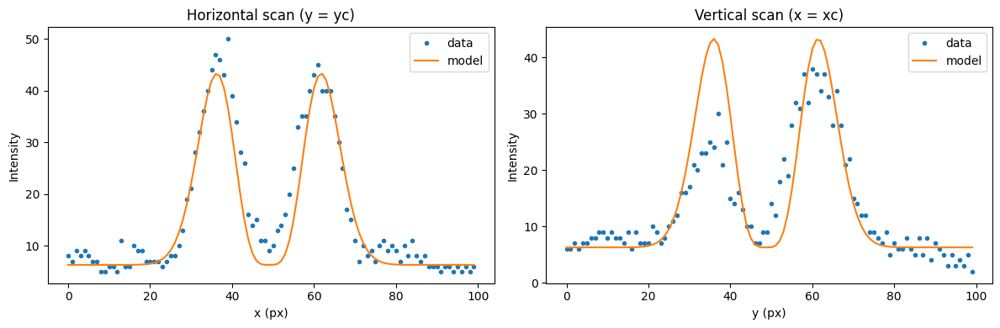

Params: {'A': 0.011202130026632555, 'w': 9.042075369482221, 'xc': 48.726624575538914, 'yc': 48.53331659618511, 'B': 4.292992060853018}
Uncertainties: {'A': 9.221619652873068e-05, 'w': 0.013810823786777848, 'xc': 0.03038778955696062, 'yc': 0.030387789552048794, 'B': 0.0382098250930644}
RMSE: 3.4919593362570156 R^2: 0.8843248347725545


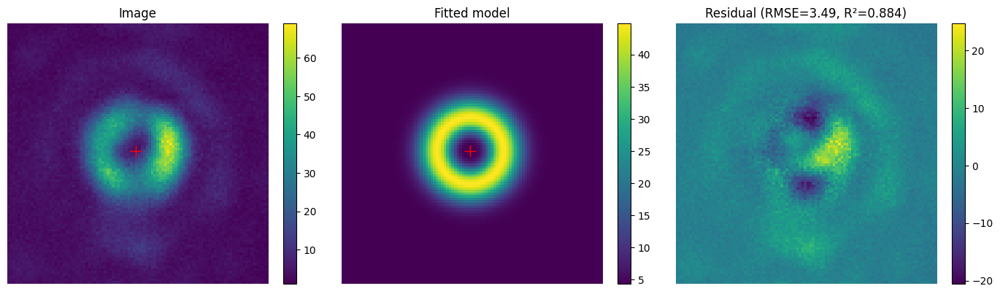

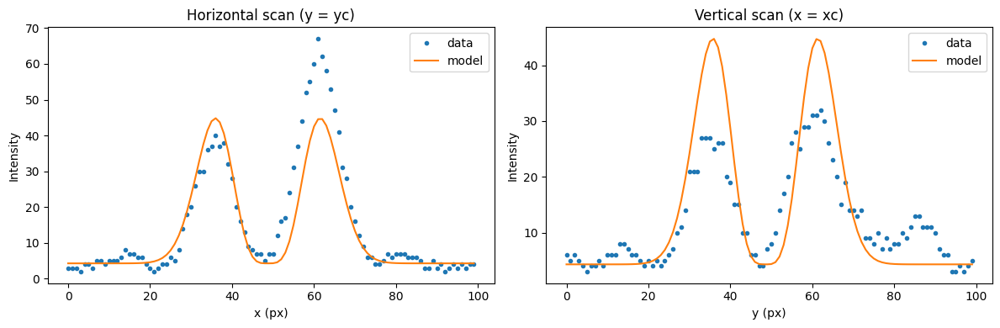

Params: {'A': 0.008996444400599579, 'w': 9.201500986622442, 'xc': 48.61913412963331, 'yc': 48.1760684353416, 'B': 5.363541308435917}
Uncertainties: {'A': 7.667303705024764e-05, 'w': 0.014560311138062212, 'xc': 0.03201509788126219, 'yc': 0.032015097877880656, 'B': 0.034792712235088015}
RMSE: 3.1685269803038594 R^2: 0.8764244773263371


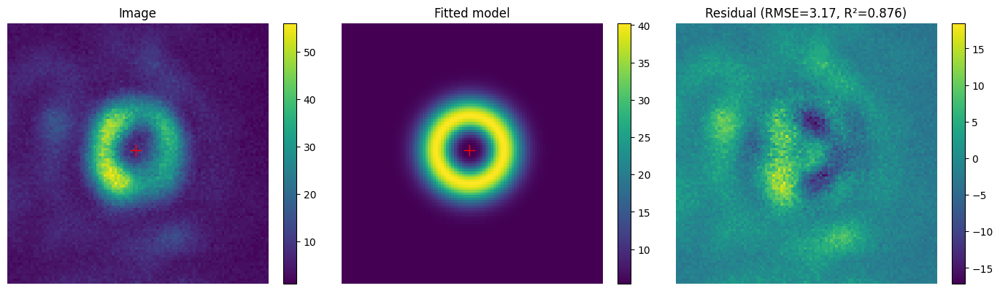

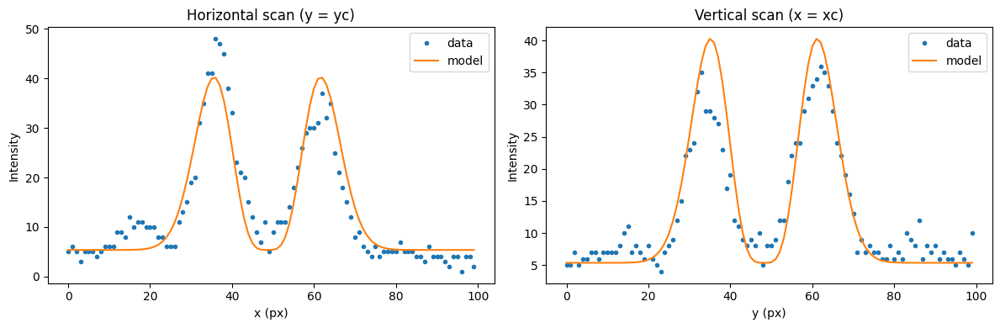

Params: {'A': 0.010556935414839796, 'w': 8.98239646898663, 'xc': 48.48858066203667, 'yc': 48.032293975649715, 'B': 5.838356894662157}
Uncertainties: {'A': 7.85370807975622e-05, 'w': 0.012395546733782658, 'xc': 0.027280573824925543, 'yc': 0.027280573829463046, 'B': 0.03144139297678003}
RMSE: 2.8771149519892347 R^2: 0.9036637541702875


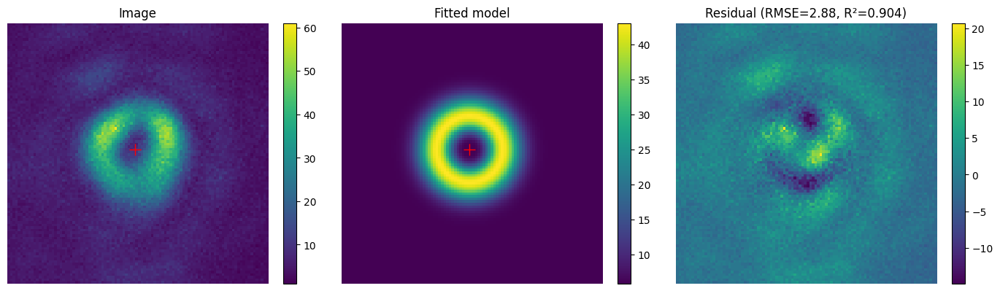

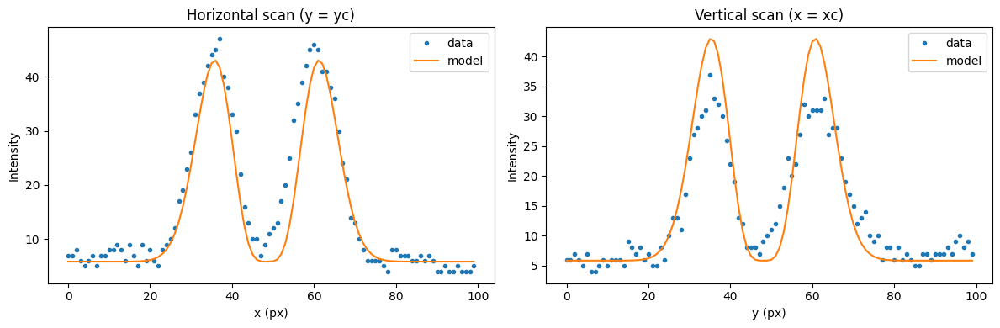

Params: {'A': 0.009028947722667598, 'w': 9.00878915185397, 'xc': 48.38405570885567, 'yc': 48.850719914133656, 'B': 5.043897127987923}
Uncertainties: {'A': 7.525235636805245e-05, 'w': 0.01392944147735052, 'xc': 0.03065305598730593, 'yc': 0.030653055990429955, 'B': 0.030589032212272032}
RMSE: 2.7975224099169584 R^2: 0.88188940712928


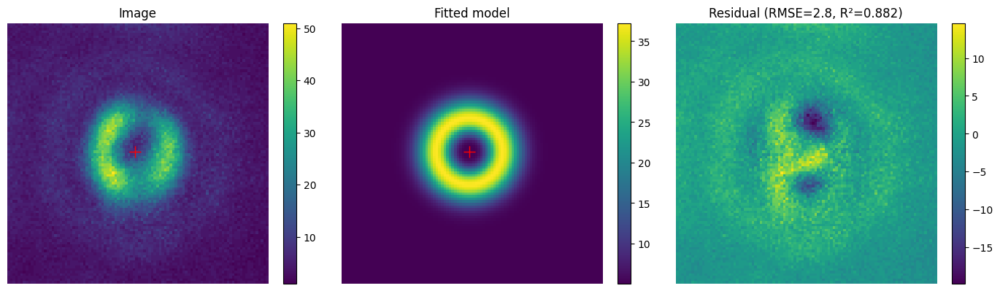

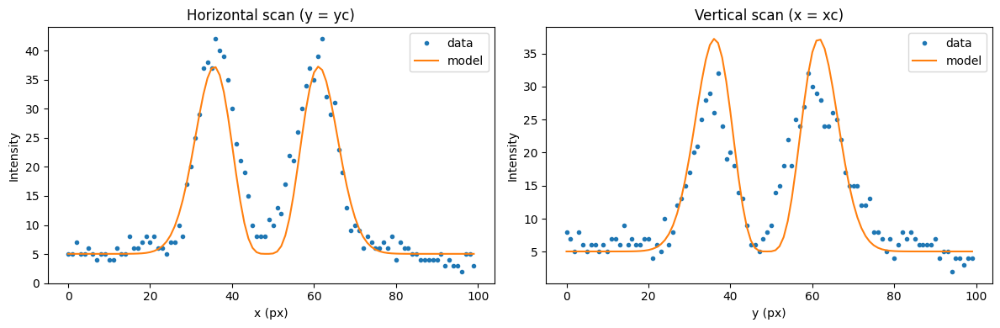

writing phase
Params: {'A': 0.010503886364014567, 'w': 9.028314498076663, 'xc': 50.04095742466628, 'yc': 48.52437082539048, 'B': 3.5775731842417886}
Uncertainties: {'A': 7.589339742475428e-05, 'w': 0.012102649235247188, 'xc': 0.026630851338690635, 'yc': 0.026630851337633824, 'B': 0.031198573344171542}
RMSE: 2.852060598515908 R^2: 0.9084966895239636


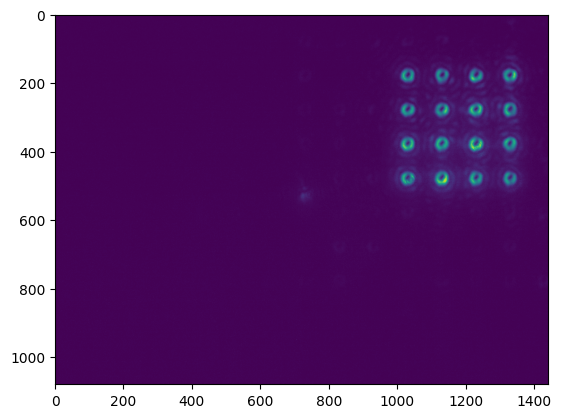

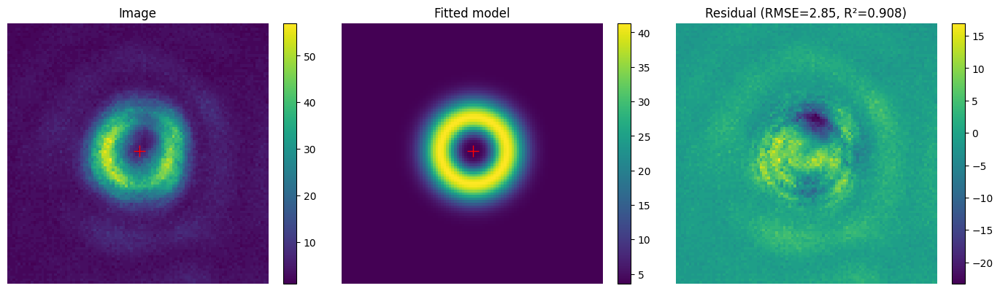

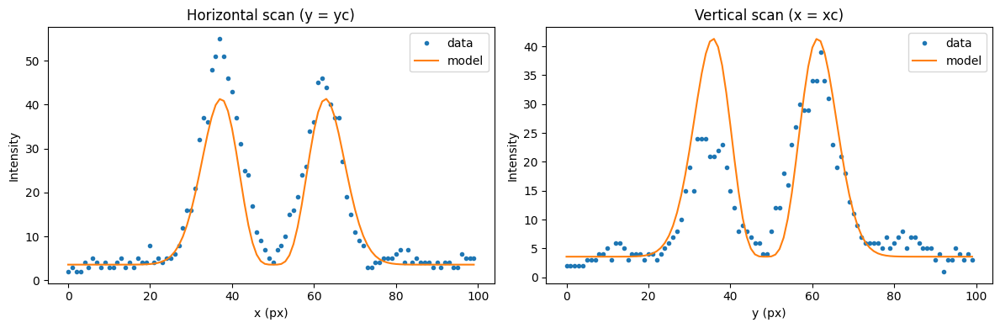

Params: {'A': 0.01039987198785313, 'w': 8.930472077100012, 'xc': 50.12793191374328, 'yc': 48.514435249138764, 'B': 4.333622642994223}
Uncertainties: {'A': 9.300520718135703e-05, 'w': 0.014811431561632525, 'xc': 0.03260454010873076, 'yc': 0.03260454010895402, 'B': 0.03612942838831515}
RMSE: 3.309792041337531 R^2: 0.8667201215219796


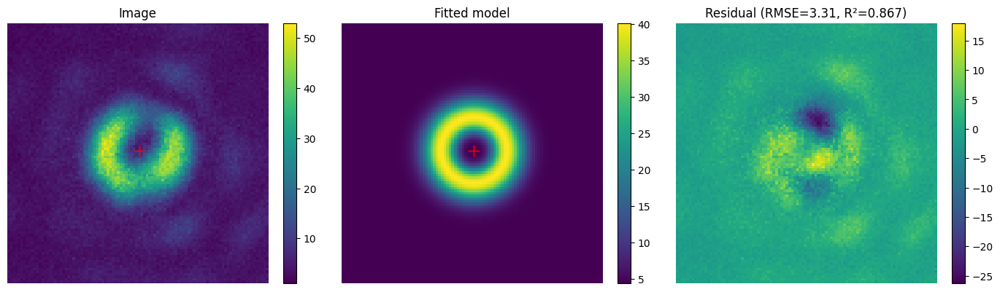

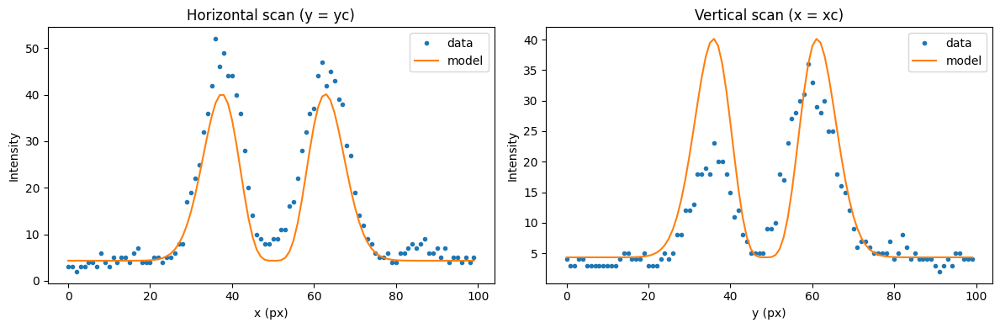

Params: {'A': 0.012667418270186174, 'w': 8.996008276643103, 'xc': 49.914313558960096, 'yc': 48.55360594173147, 'B': 5.7255125377390454}
Uncertainties: {'A': 9.603515101573447e-05, 'w': 0.012651823481708275, 'xc': 0.027843020677688103, 'yc': 0.027843020675057076, 'B': 0.03875011082637628}
RMSE: 3.54487408460154 R^2: 0.9002811179750358


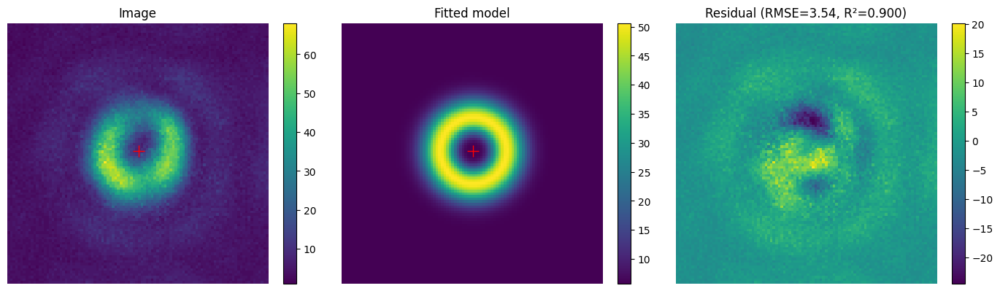

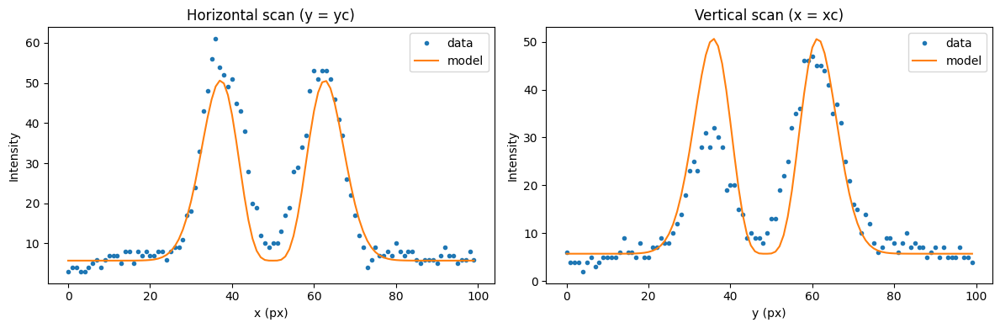

Params: {'A': 0.00986018922255734, 'w': 9.165536590897476, 'xc': 50.05185748500097, 'yc': 48.67687140730975, 'B': 5.765271355805684}
Uncertainties: {'A': 8.537445719581441e-05, 'w': 0.01473239678297062, 'xc': 0.03239850665062215, 'yc': 0.0323985066402708, 'B': 0.0379596654622162}
RMSE: 3.459702787214034 R^2: 0.8730993783284898


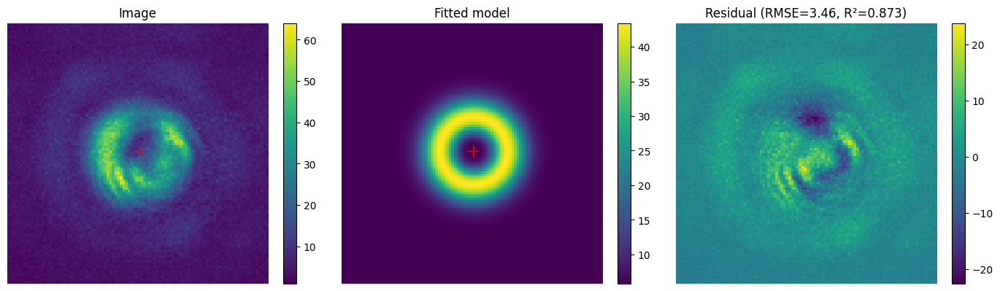

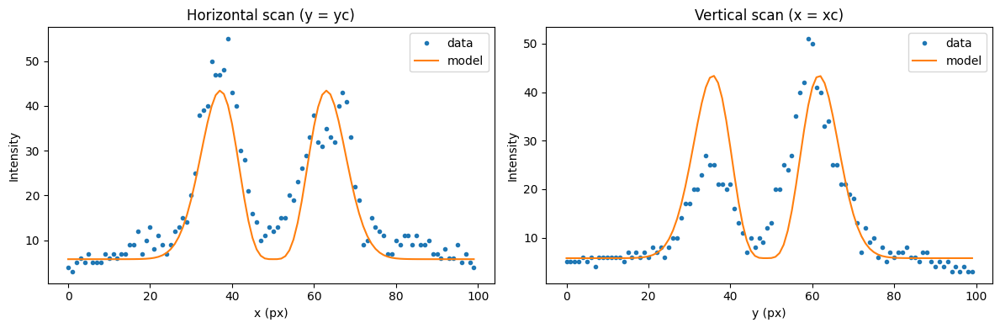

Params: {'A': 0.00874657340358309, 'w': 9.043430260414317, 'xc': 50.17028958541462, 'yc': 48.284175922195956, 'B': 4.078306187583994}
Uncertainties: {'A': 7.086116170286511e-05, 'w': 0.013594112244342245, 'xc': 0.029910791629232294, 'yc': 0.029910791628877817, 'B': 0.02938422701404225}
RMSE: 2.6853172098474865 R^2: 0.8875477502525382


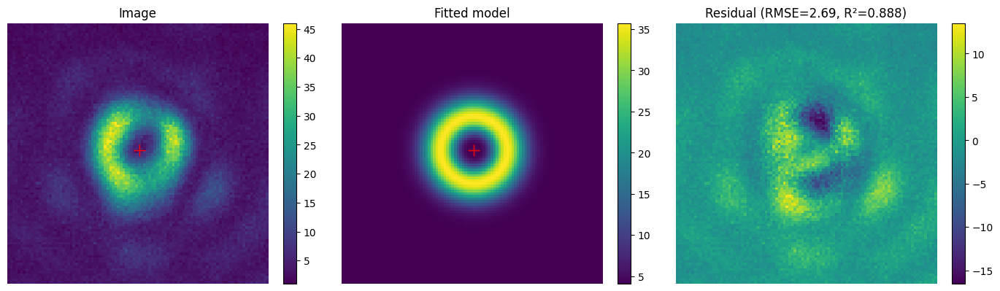

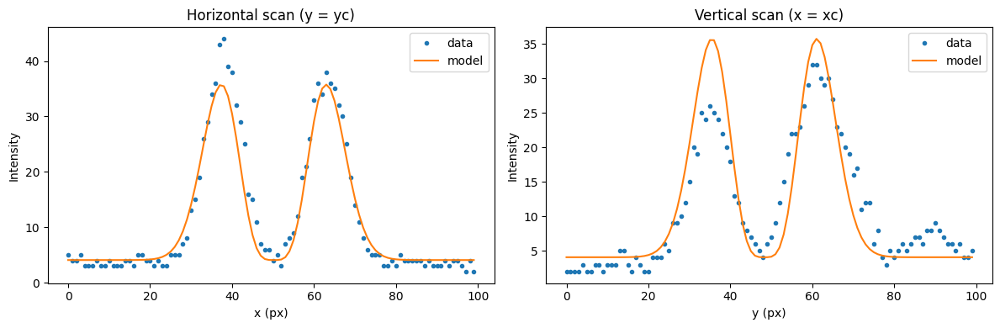

Params: {'A': 0.010469859767315586, 'w': 8.963959002346424, 'xc': 49.95279050190657, 'yc': 48.24682275117834, 'B': 5.430528765940738}
Uncertainties: {'A': 9.522305303575142e-05, 'w': 0.015121834054041714, 'xc': 0.03328323178687111, 'yc': 0.03328323178284036, 'B': 0.037716810776046134}
RMSE: 3.4527311886714074 R^2: 0.8626393079117192


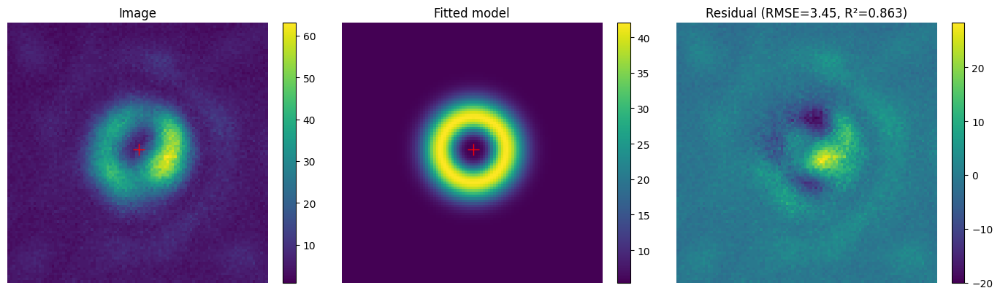

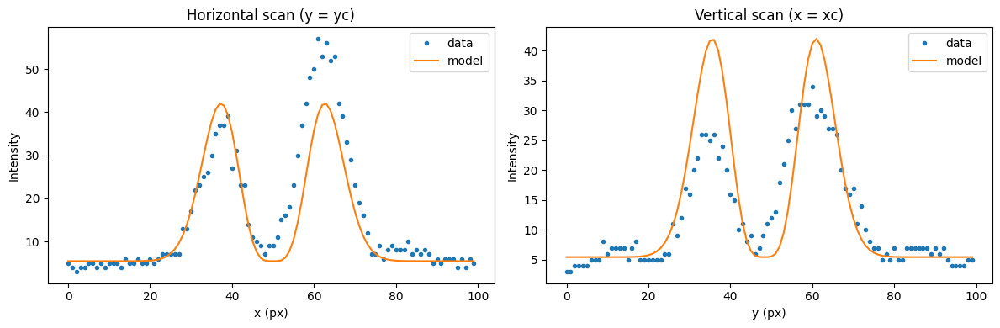

Params: {'A': 0.011236741238919538, 'w': 9.015018319049958, 'xc': 49.521383225120644, 'yc': 47.649969709693266, 'B': 6.65586824863269}
Uncertainties: {'A': 8.173233766604277e-05, 'w': 0.012165102488514755, 'xc': 0.026769764163375537, 'yc': 0.02676976416262262, 'B': 0.03334257173012417}
RMSE: 3.0489362698342912 R^2: 0.9074196883513906


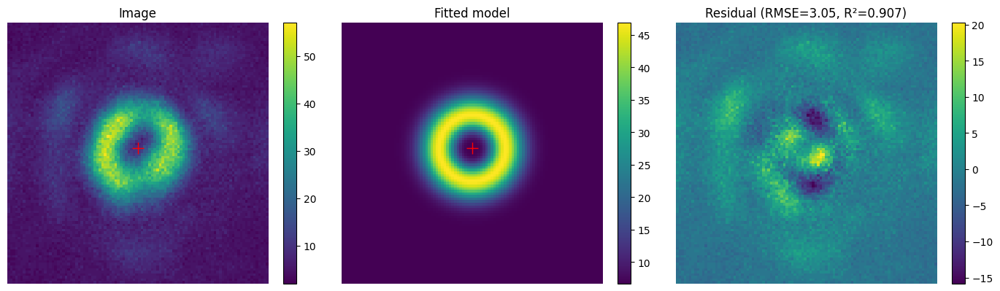

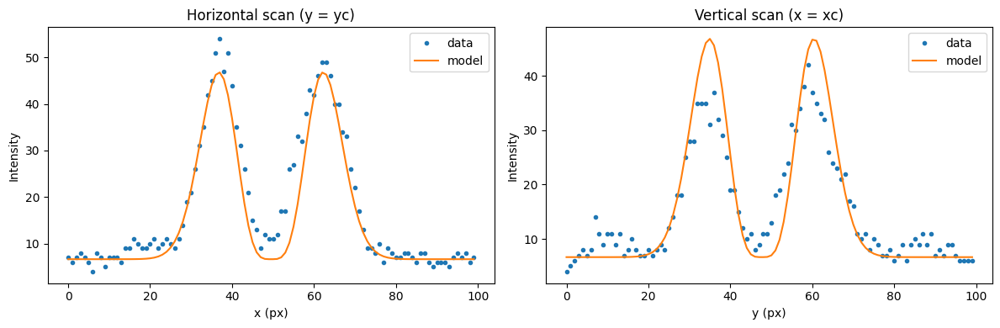

Params: {'A': 0.011936305991647403, 'w': 9.216466344071897, 'xc': 49.384928712324125, 'yc': 48.5482519543344, 'B': 6.973202661835995}
Uncertainties: {'A': 0.00011243889613001127, 'w': 0.01612053563749197, 'xc': 0.03544340702680593, 'yc': 0.03544340702263412, 'B': 0.05145600831830247}
RMSE: 4.684466516119915 R^2: 0.8529904232360344


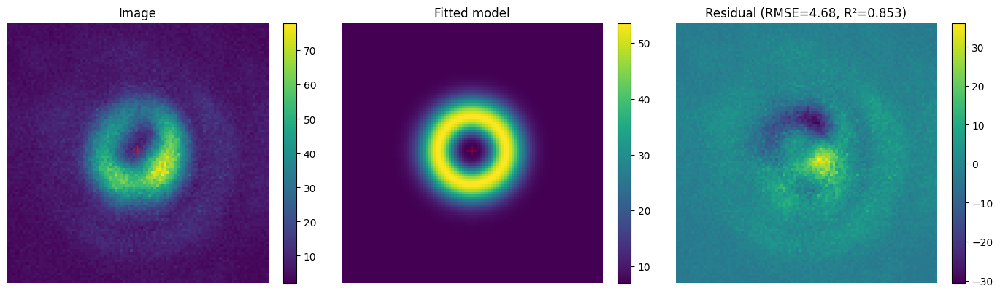

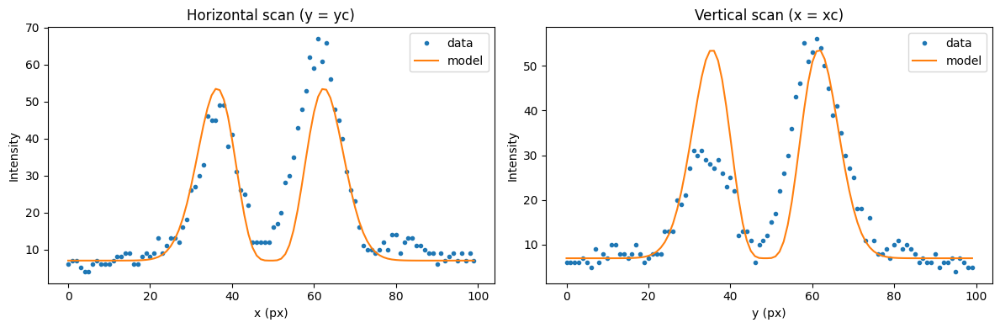

Params: {'A': 0.010744040718469417, 'w': 8.88653631528109, 'xc': 49.15150277044054, 'yc': 48.92537937426127, 'B': 4.116375241310319}
Uncertainties: {'A': 0.00011688269495168995, 'w': 0.01792587105211039, 'xc': 0.03946748767185533, 'yc': 0.039467487660474754, 'B': 0.044257603666777307}
RMSE: 4.058206804033112 R^2: 0.8148537242596088


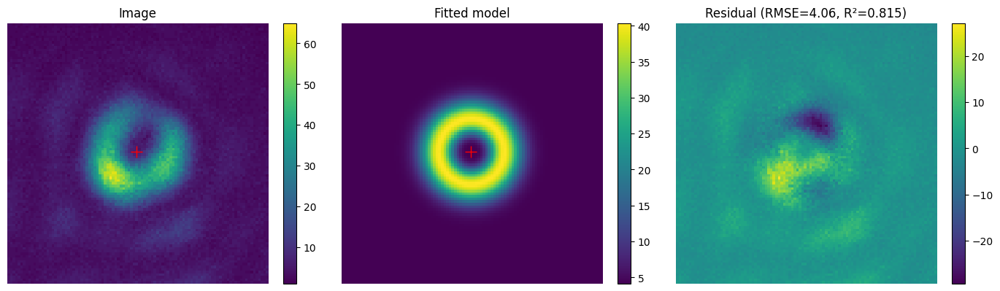

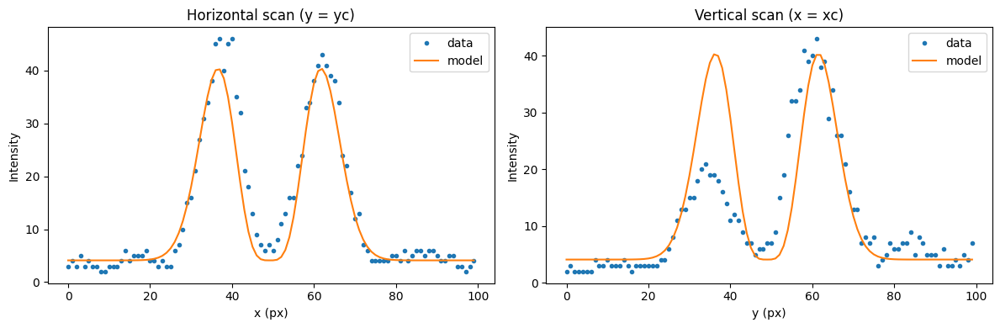

Params: {'A': 0.012587616598422132, 'w': 8.898240416354597, 'xc': 49.226462136010745, 'yc': 48.13606316617305, 'B': 6.2977190426914085}
Uncertainties: {'A': 0.00010458697178934437, 'w': 0.01370958017285777, 'xc': 0.03018301424485892, 'yc': 0.030183014241930352, 'B': 0.03987322893833975}
RMSE: 3.655271366959806 R^2: 0.8829315223556575


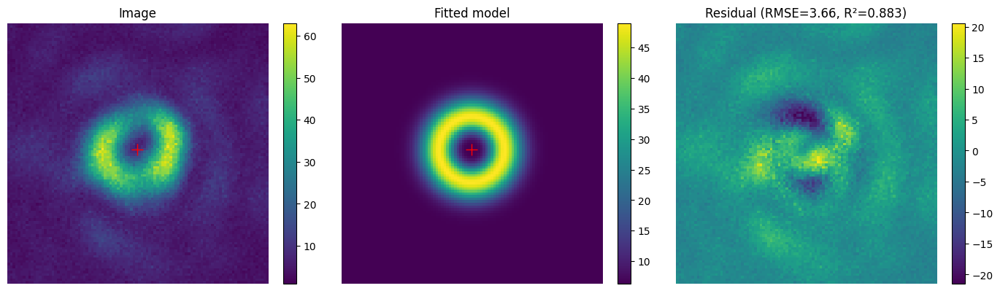

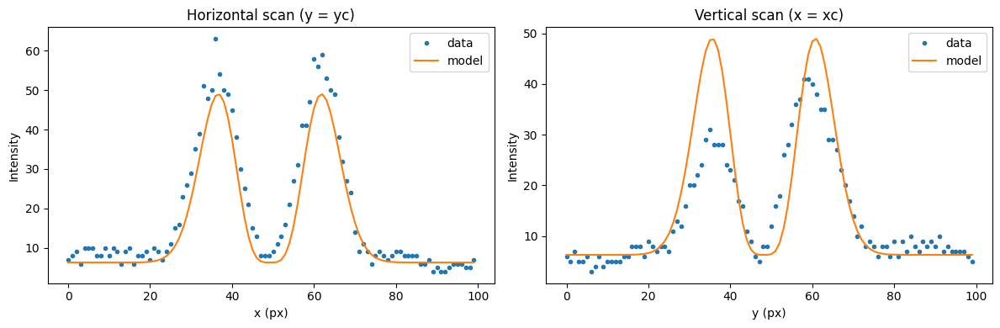

Params: {'A': 0.011742116969792415, 'w': 9.291909991404967, 'xc': 49.15336851483172, 'yc': 48.52909659249786, 'B': 6.902702251472364}
Uncertainties: {'A': 0.00010703152267554384, 'w': 0.015731929810204267, 'xc': 0.03457758733686882, 'yc': 0.034577587336223285, 'B': 0.051105829576829465}
RMSE: 4.644703905848713 R^2: 0.8607204831086188


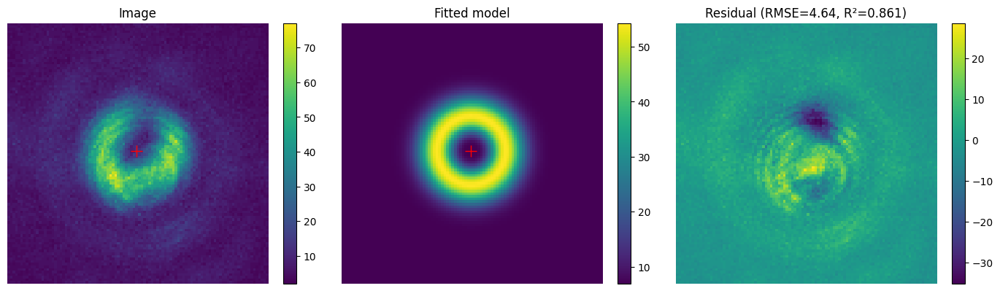

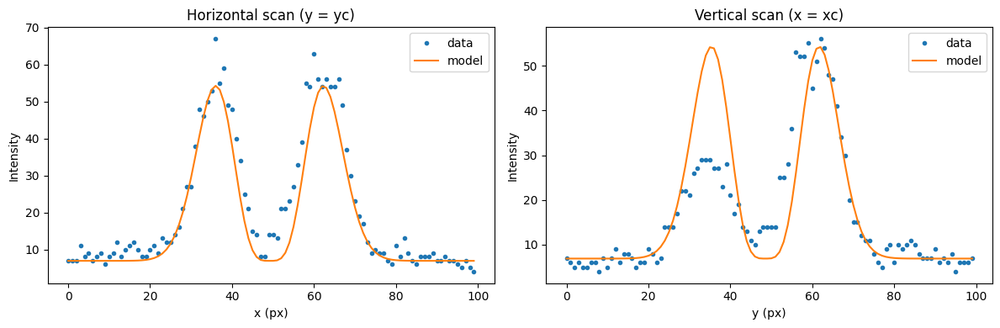

Params: {'A': 0.01034086993311643, 'w': 8.989074261246397, 'xc': 49.080254886863976, 'yc': 48.487445467249536, 'B': 6.323810977518567}
Uncertainties: {'A': 9.324678312340692e-05, 'w': 0.01503627927873577, 'xc': 0.0330914762389635, 'yc': 0.03309147623777311, 'B': 0.03747461447737105}
RMSE: 3.4287045030766046 R^2: 0.8645568122635079


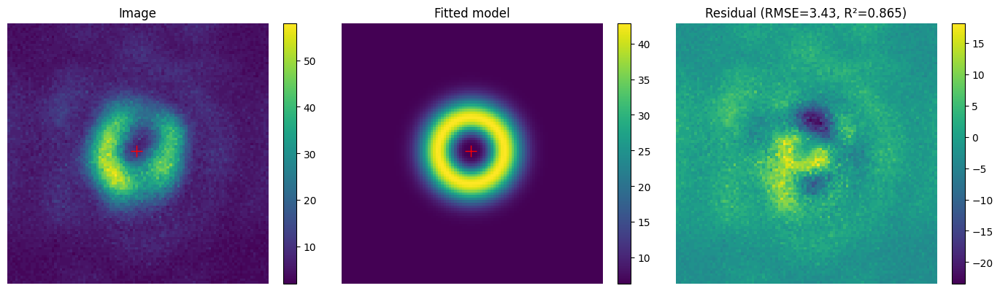

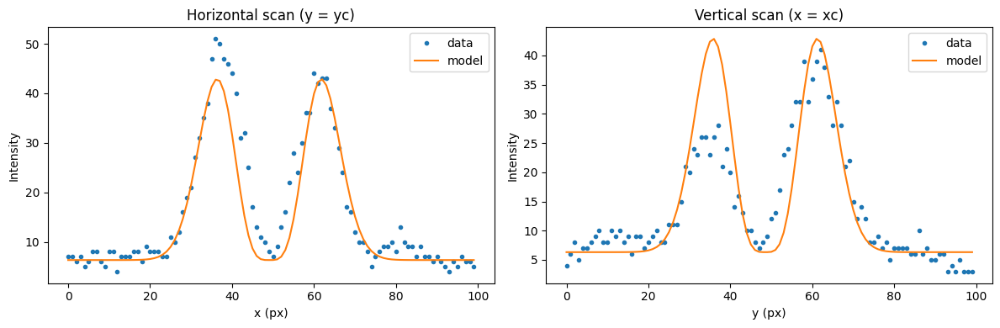

Params: {'A': 0.011058923243164818, 'w': 9.036994255600337, 'xc': 48.83526675788472, 'yc': 48.371467473659635, 'B': 4.344553905519144}
Uncertainties: {'A': 9.074069143021038e-05, 'w': 0.013757795296519462, 'xc': 0.030271757639974917, 'yc': 0.030271757635924074, 'B': 0.03748878401999811}
RMSE: 3.4264427001690483 R^2: 0.8850090039341536


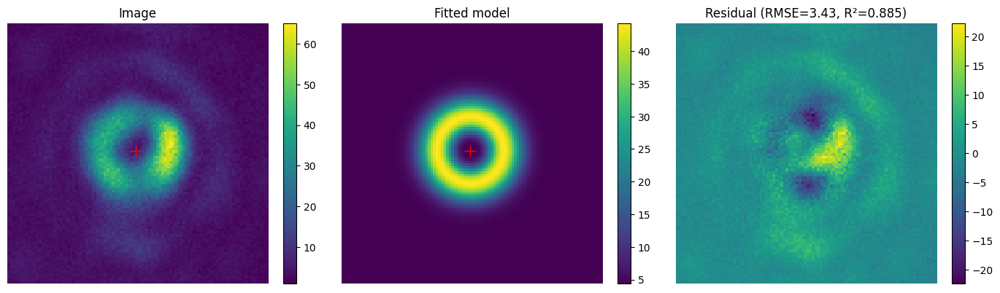

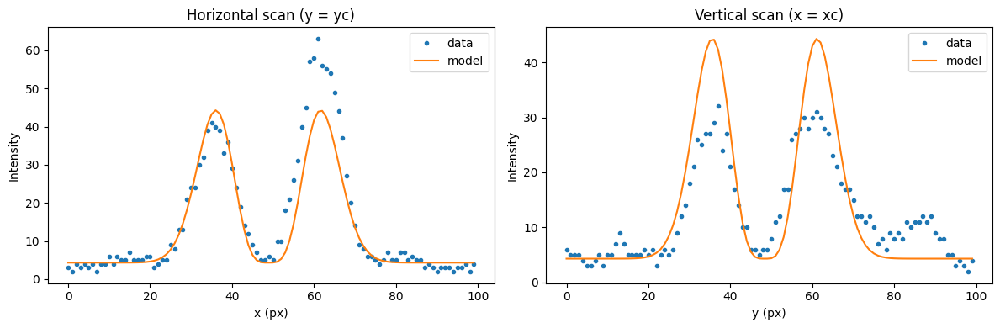

Params: {'A': 0.009097156762759072, 'w': 9.164247177369992, 'xc': 48.615294575662034, 'yc': 48.01275059189411, 'B': 5.401960915495529}
Uncertainties: {'A': 8.393640769846791e-05, 'w': 0.01569682771967692, 'xc': 0.03451961038460781, 'yc': 0.034519610378631174, 'B': 0.03729296194983506}
RMSE: 3.3990355659373708 R^2: 0.8583410758948756


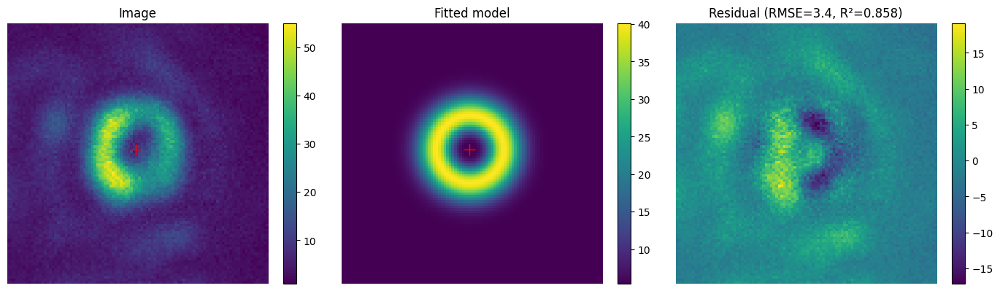

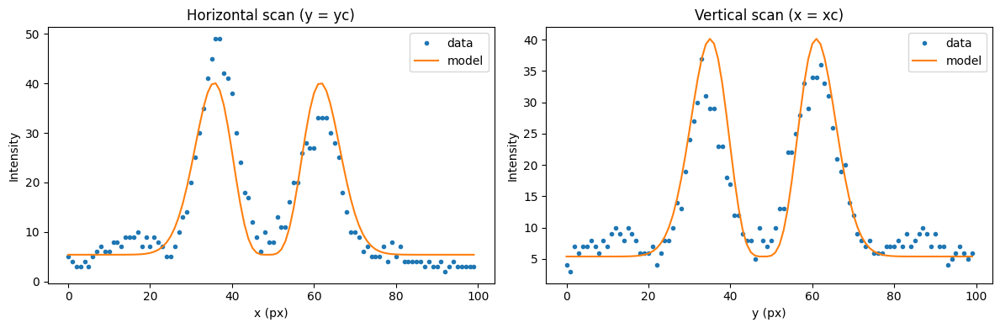

Params: {'A': 0.010785130494726215, 'w': 8.937958666862084, 'xc': 48.61974515714184, 'yc': 47.82375895819696, 'B': 5.884701252423001}
Uncertainties: {'A': 8.253819041510739e-05, 'w': 0.012685997262665255, 'xc': 0.027924941492597877, 'yc': 0.02792494149555104, 'B': 0.03220312109363835}
RMSE: 2.949633188482419 R^2: 0.8987620500764185


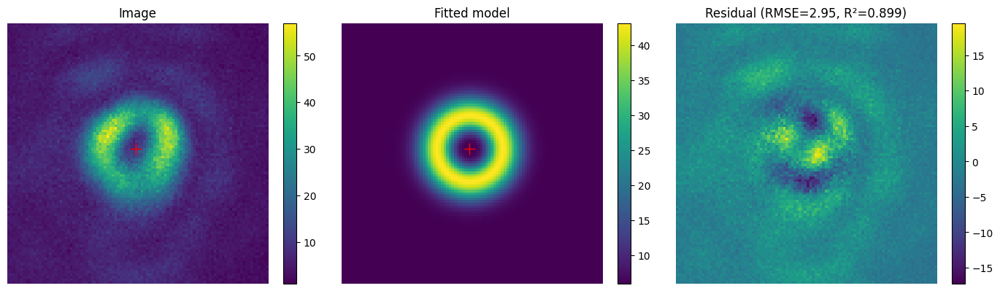

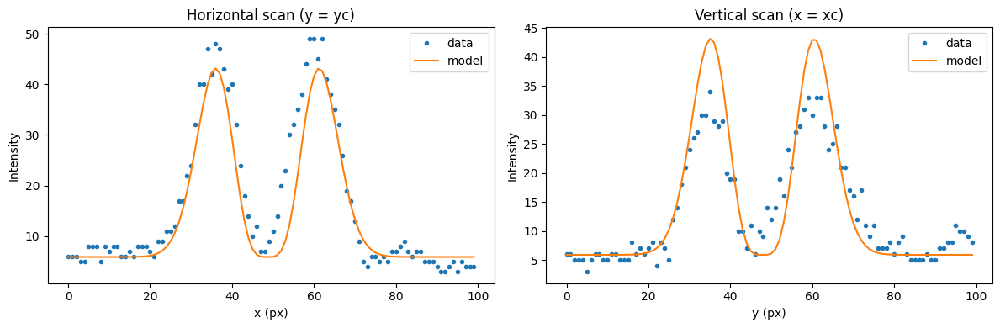

Params: {'A': 0.009102768888467743, 'w': 8.9836170200688, 'xc': 48.54496995339353, 'yc': 48.74167738493326, 'B': 5.081803098673295}
Uncertainties: {'A': 8.009838285832351e-05, 'w': 0.014663587578899103, 'xc': 0.03227199784221892, 'yc': 0.032271997840932924, 'B': 0.03208907848532755}
RMSE: 2.9363055950714605 R^2: 0.8702071842489503


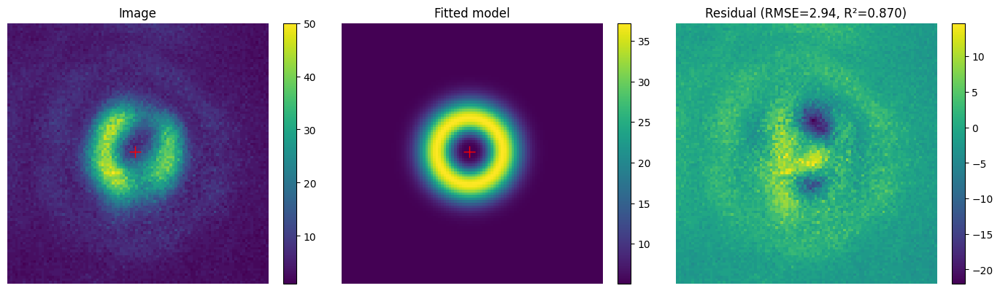

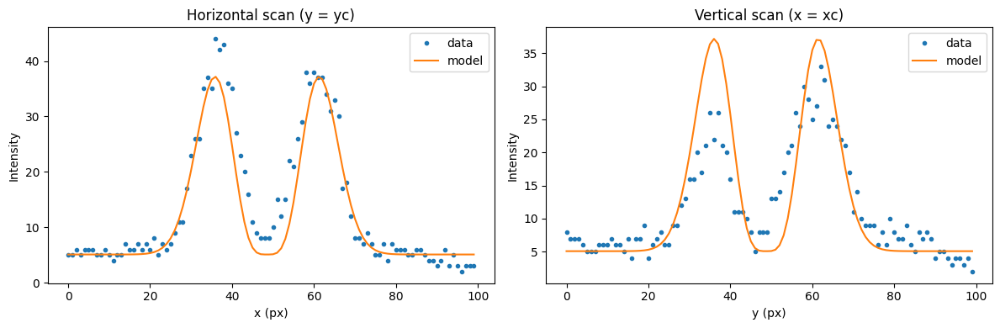

writing phase
Params: {'A': 0.010320872100065475, 'w': 9.02423148545197, 'xc': 50.17698743419169, 'yc': 48.445463973303916, 'B': 3.6420654627084033}
Uncertainties: {'A': 8.045095948051067e-05, 'w': 0.013050808459350265, 'xc': 0.028717686492635702, 'yc': 0.028717686488694497, 'B': 0.03299447498875948}
RMSE: 3.016502724109619 R^2: 0.8950850560359336


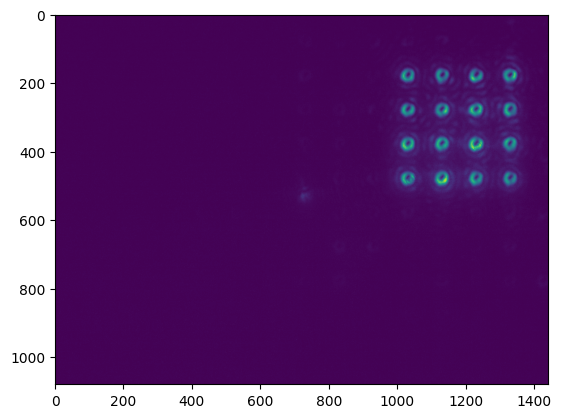

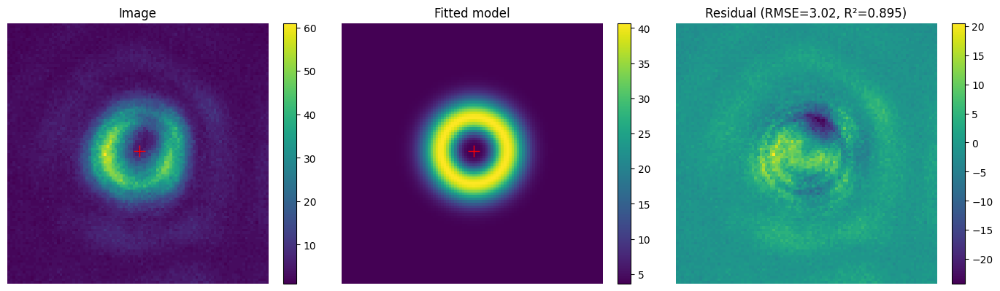

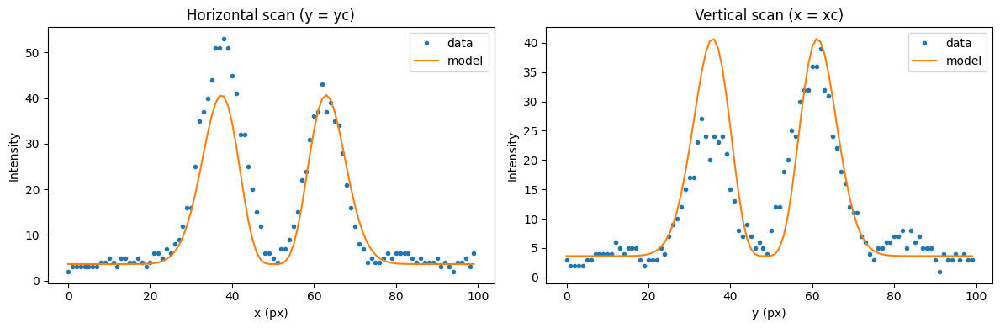

Params: {'A': 0.010405686089337606, 'w': 8.89292426117434, 'xc': 50.30882222193519, 'yc': 48.475784924463724, 'B': 4.368962820509263}
Uncertainties: {'A': 9.852268874020195e-05, 'w': 0.015613009795969444, 'xc': 0.0343743519907048, 'yc': 0.03437435199996457, 'B': 0.037444950114121814}
RMSE: 3.433053580336171 R^2: 0.8531361646161872


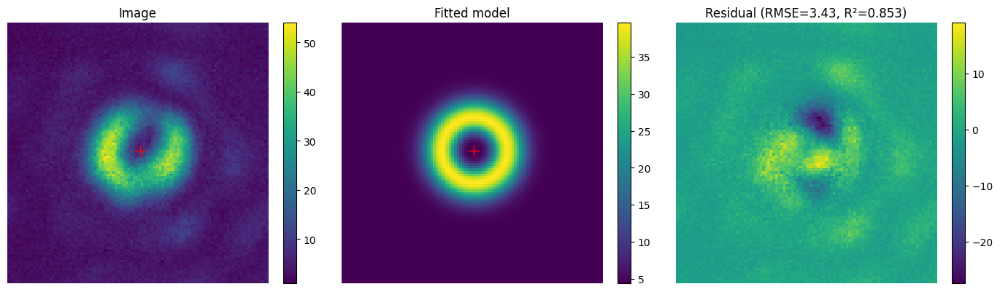

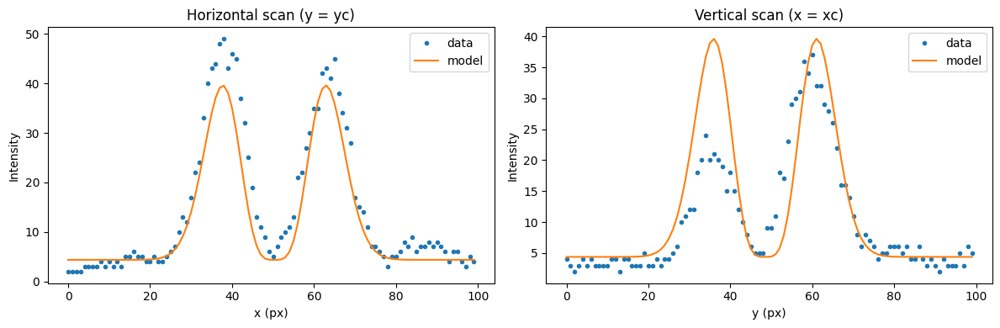

Params: {'A': 0.012364035424900058, 'w': 9.003545310975229, 'xc': 50.12036375159355, 'yc': 48.51007171802688, 'B': 5.758705091213302}
Uncertainties: {'A': 9.993541422172765e-05, 'w': 0.013500428076640753, 'xc': 0.029709621692808007, 'yc': 0.029709621693249866, 'B': 0.040499665482810865}
RMSE: 3.7043204383461656 R^2: 0.8881504718958118


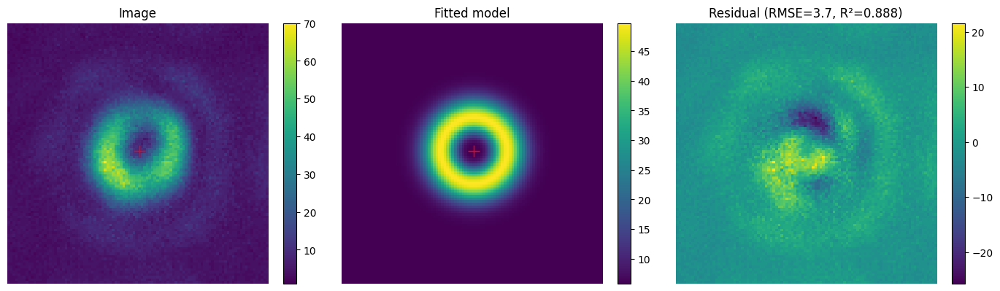

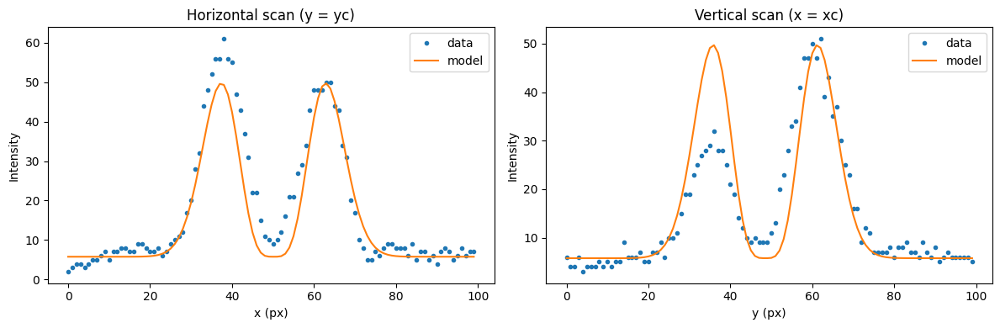

Params: {'A': 0.009675077586251836, 'w': 9.169078188098192, 'xc': 50.16203336338893, 'yc': 48.61010842695997, 'B': 5.781061985803737}
Uncertainties: {'A': 8.693045655237099e-05, 'w': 0.015294053434720331, 'xc': 0.03363315209739078, 'yc': 0.033633152089972355, 'B': 0.038729277815588666}
RMSE: 3.5295691872768193 R^2: 0.864653571699791


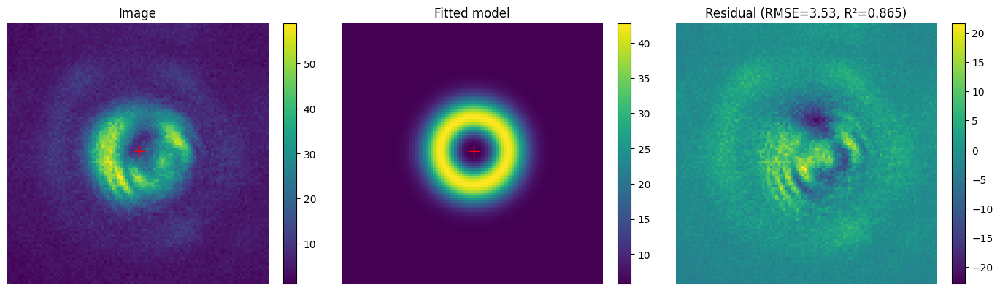

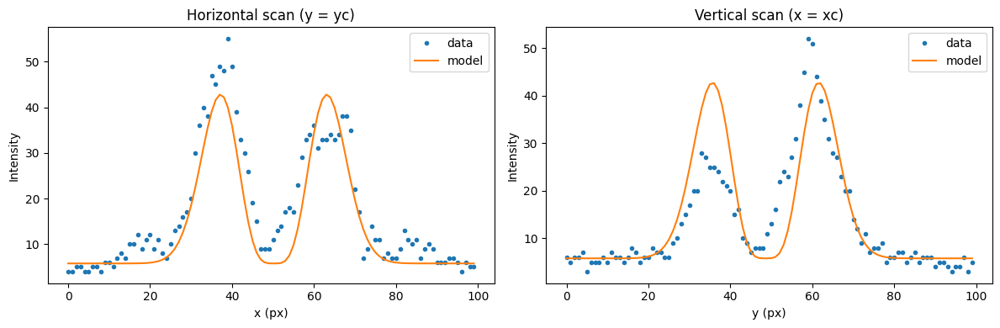

Params: {'A': 0.008512448391310065, 'w': 9.056792929861974, 'xc': 50.40458230691542, 'yc': 48.17864265104975, 'B': 4.1176403598669316}
Uncertainties: {'A': 7.553624498054265e-05, 'w': 0.014912384643468212, 'xc': 0.03280950882954288, 'yc': 0.03280950883131497, 'B': 0.031564145355300534}
RMSE: 2.883692458012096 R^2: 0.8680033341397779


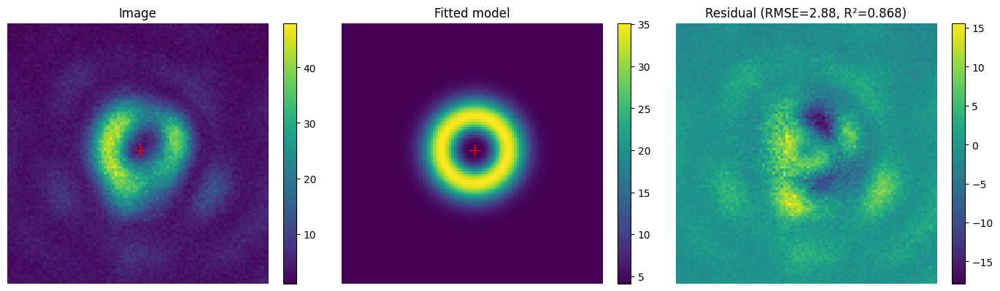

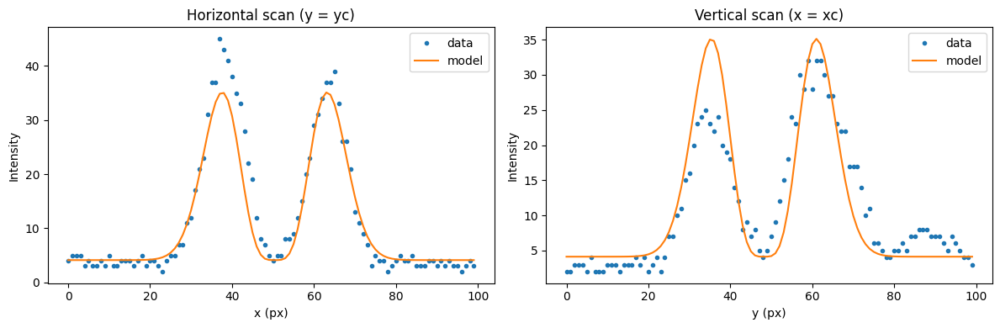

Params: {'A': 0.01037605965756003, 'w': 8.952083002510925, 'xc': 50.07243303251767, 'yc': 48.14191248270223, 'B': 5.459002419608318}
Uncertainties: {'A': 9.584187843187396e-05, 'w': 0.015336596653546893, 'xc': 0.033757583310338714, 'yc': 0.033757583312508874, 'B': 0.037701497768550946}
RMSE: 3.452209763312615 R^2: 0.8589800192475812


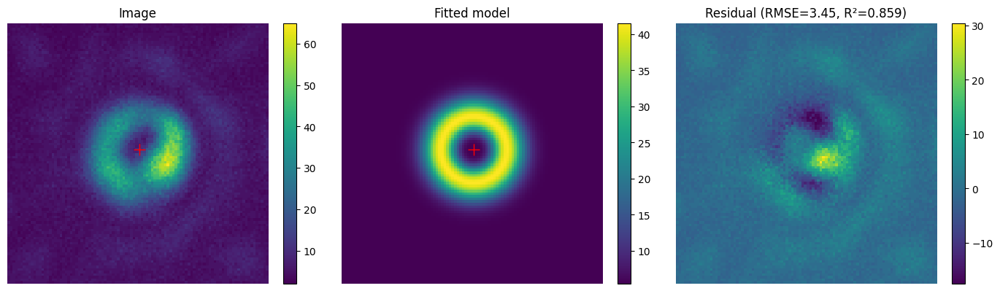

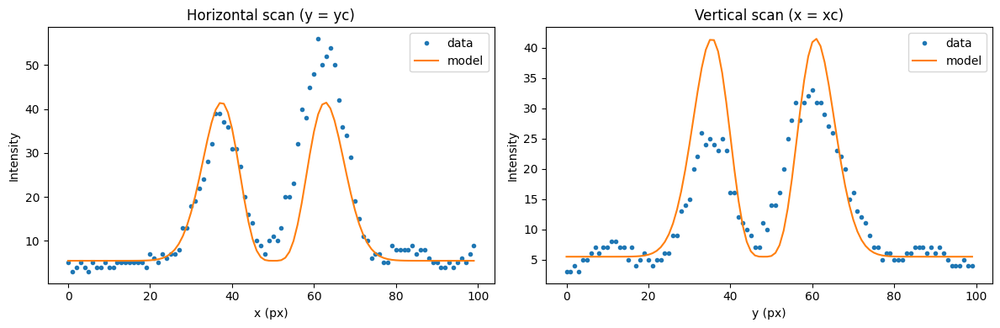

Params: {'A': 0.011147315520301957, 'w': 8.99820806134398, 'xc': 49.69101558563667, 'yc': 47.55860886645034, 'B': 6.655597221028459}
Uncertainties: {'A': 8.644233998728066e-05, 'w': 0.012944265132121149, 'xc': 0.028486339295064913, 'yc': 0.028486339291086626, 'B': 0.03492374468648717}
RMSE: 3.1946848895995186 R^2: 0.8961424980090624


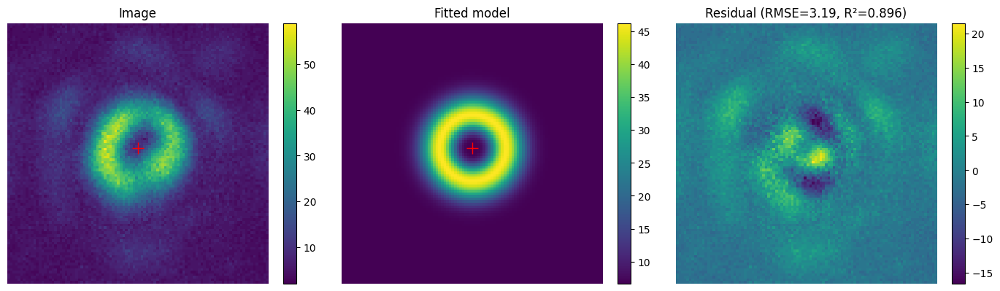

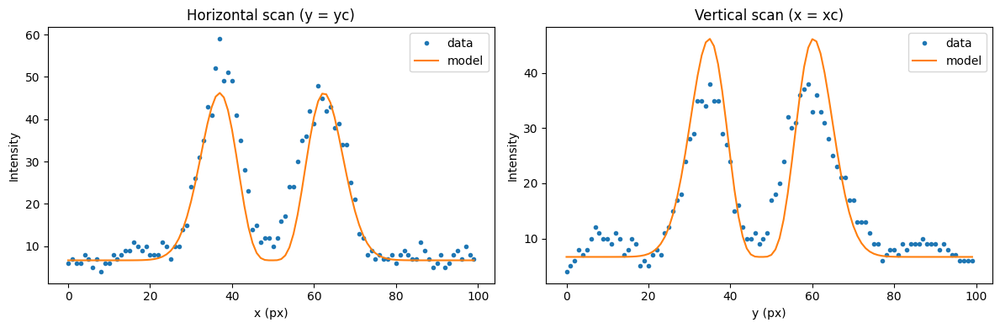

Params: {'A': 0.011659479088520804, 'w': 9.228054275538089, 'xc': 49.49780103883435, 'yc': 48.45576016626614, 'B': 6.985828529672636}
Uncertainties: {'A': 0.00011240382188792705, 'w': 0.016519707144055974, 'xc': 0.036319215685795686, 'yc': 0.03631921568776591, 'B': 0.05177756905348886}
RMSE: 4.71251925021762 R^2: 0.8470341849012168


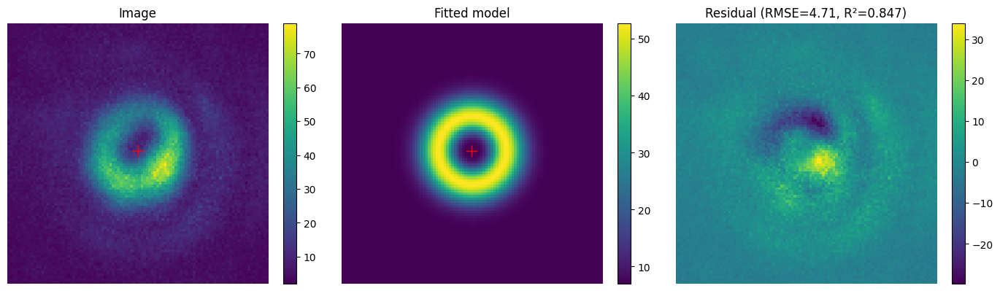

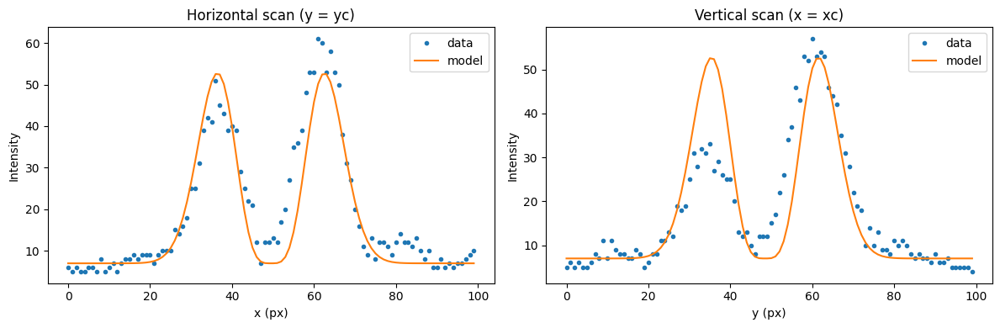

Params: {'A': 0.010358933676307061, 'w': 8.916337823028444, 'xc': 49.31769518959834, 'yc': 48.875394624120304, 'B': 4.1482010850161695}
Uncertainties: {'A': 0.00011953314525359584, 'w': 0.01907998105526527, 'xc': 0.04200337623671602, 'yc': 0.042003376223760935, 'B': 0.046054443143083684}
RMSE: 4.220289845966234 R^2: 0.7962448565047184


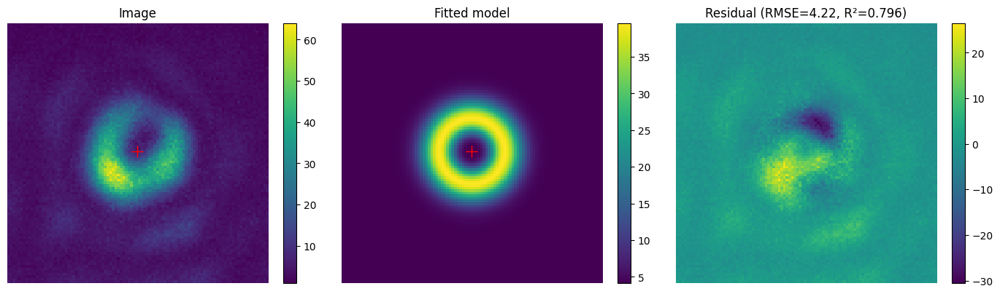

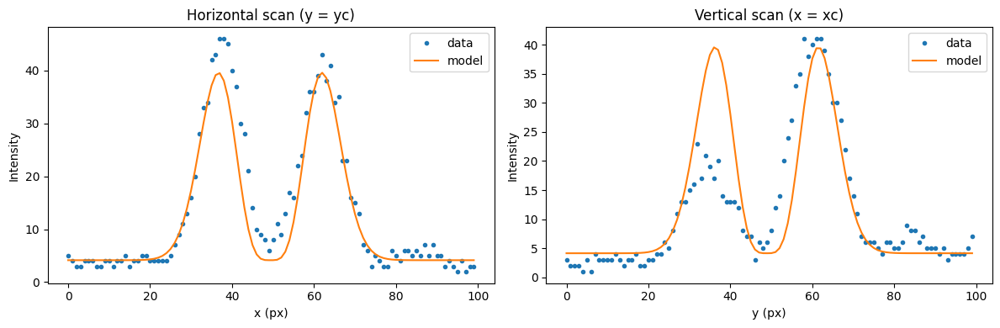

Params: {'A': 0.012066844375298928, 'w': 8.92105927476617, 'xc': 49.39800412660091, 'yc': 48.00173679068118, 'B': 6.332063269400144}
Uncertainties: {'A': 0.00010580044637660508, 'w': 0.01450563555476685, 'xc': 0.031932623788201074, 'yc': 0.031932623782899384, 'B': 0.040875587700705526}
RMSE: 3.745337710180133 R^2: 0.8712579579840182


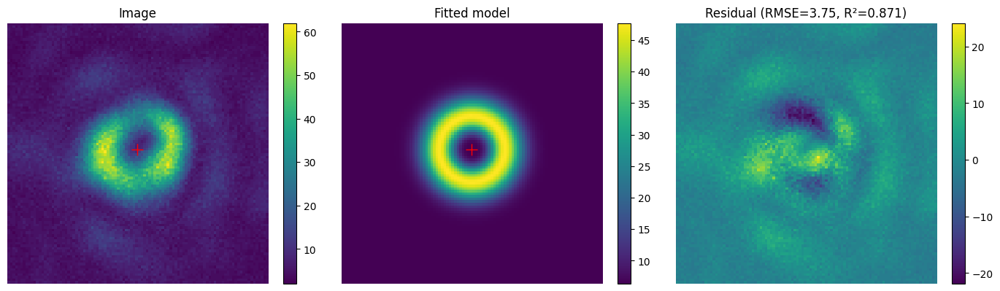

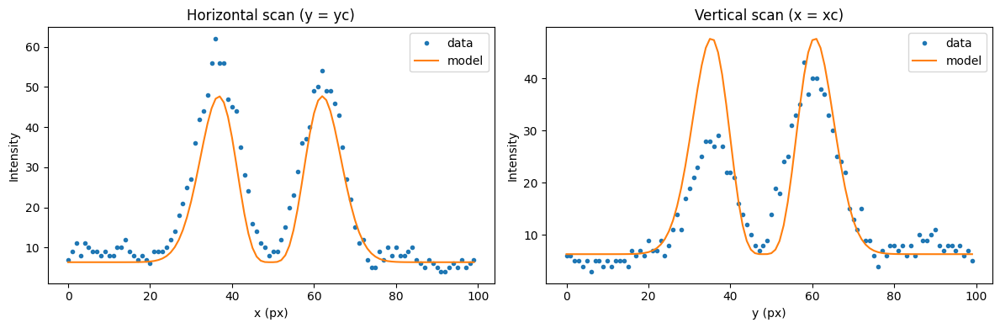

Params: {'A': 0.011437839597142943, 'w': 9.307982061389607, 'xc': 49.22710480221797, 'yc': 48.37942294528693, 'B': 6.9268402073472926}
Uncertainties: {'A': 0.00010965324509484355, 'w': 0.016575839096670306, 'xc': 0.03642985272194446, 'yc': 0.036429852719204577, 'B': 0.052831255907180526}
RMSE: 4.799771194858553 R^2: 0.848102026877636


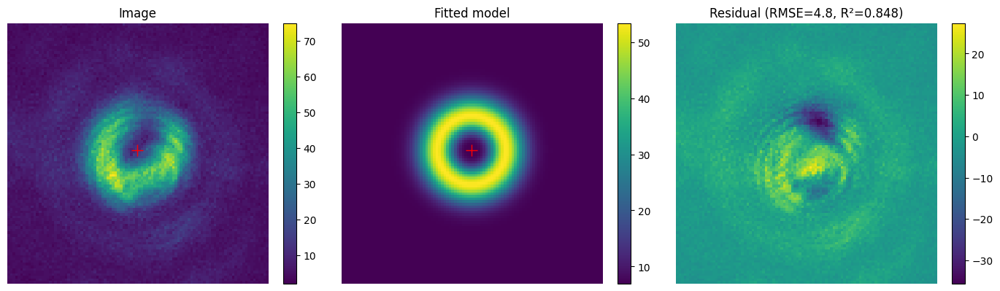

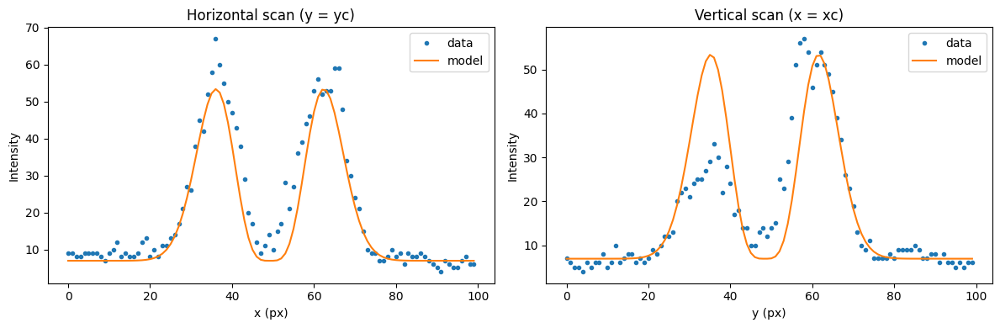

Params: {'A': 0.010033781509158627, 'w': 9.006946494192576, 'xc': 49.21896097655989, 'yc': 48.41151896165867, 'B': 6.361331827098488}
Uncertainties: {'A': 9.595762627476099e-05, 'w': 0.015979876295828133, 'xc': 0.035165502697996016, 'yc': 0.035165502718354606, 'B': 0.03896400693652447}
RMSE: 3.5635985091535316 R^2: 0.8501061816466088


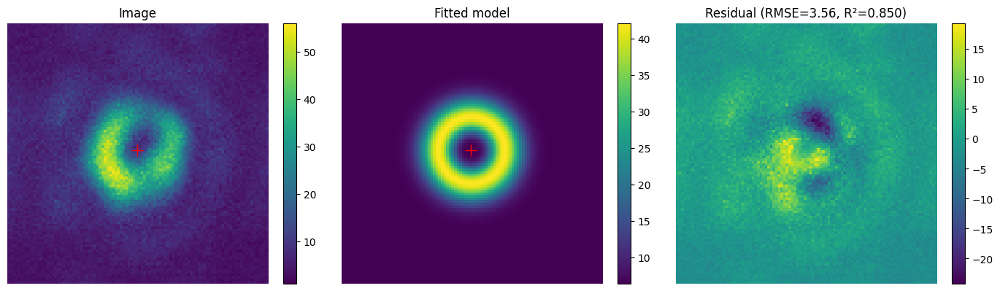

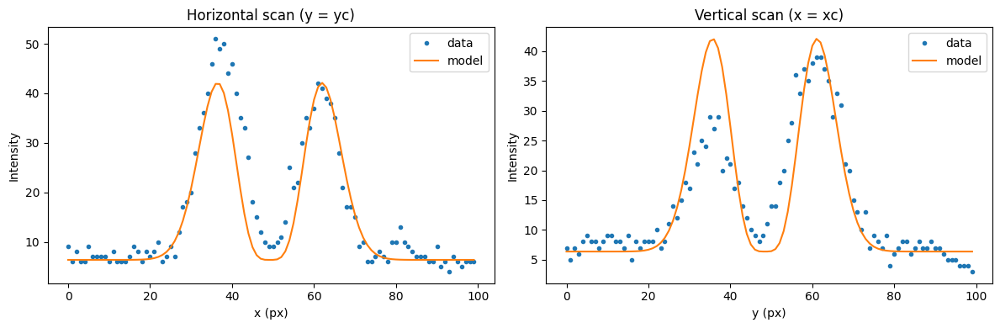

Params: {'A': 0.010916805659977782, 'w': 9.028727271191933, 'xc': 49.01182432191262, 'yc': 48.21427786285426, 'B': 4.3781512303851375}
Uncertainties: {'A': 8.97159946055644e-05, 'w': 0.013766431170695417, 'xc': 0.03029180990014772, 'yc': 0.030291809893509002, 'B': 0.036889586356061876}
RMSE: 3.3722821779015426 R^2: 0.8847171230333768


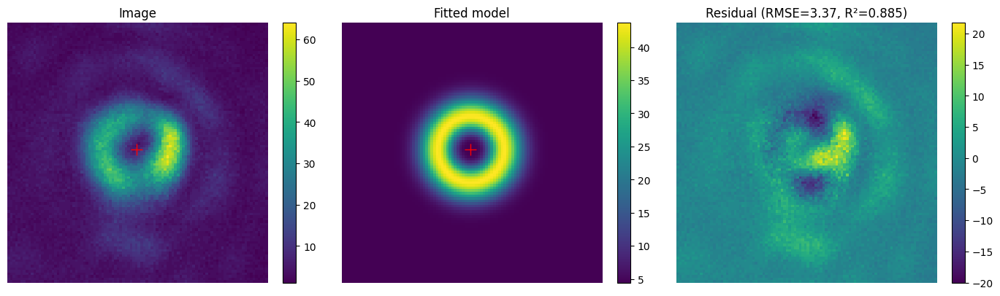

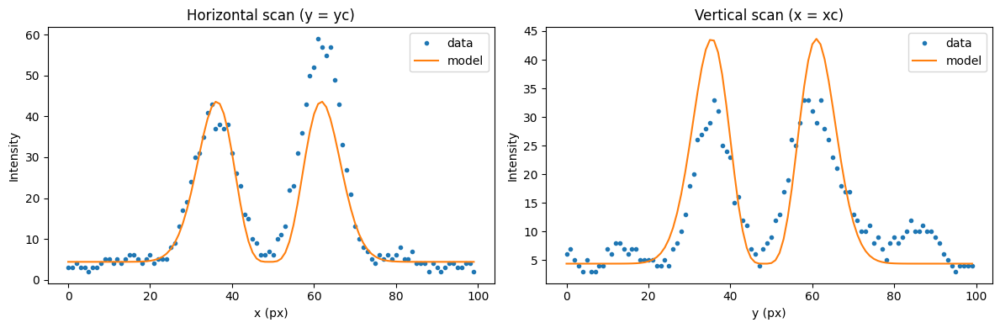

Params: {'A': 0.009043873625153088, 'w': 9.146912460638916, 'xc': 48.72358388799363, 'yc': 47.913686739766426, 'B': 5.41911400341669}
Uncertainties: {'A': 8.89359115940679e-05, 'w': 0.0166968780291931, 'xc': 0.03672159949953197, 'yc': 0.03672159949803307, 'B': 0.03912691667643327}
RMSE: 3.5675587445034314 R^2: 0.8422062682129114


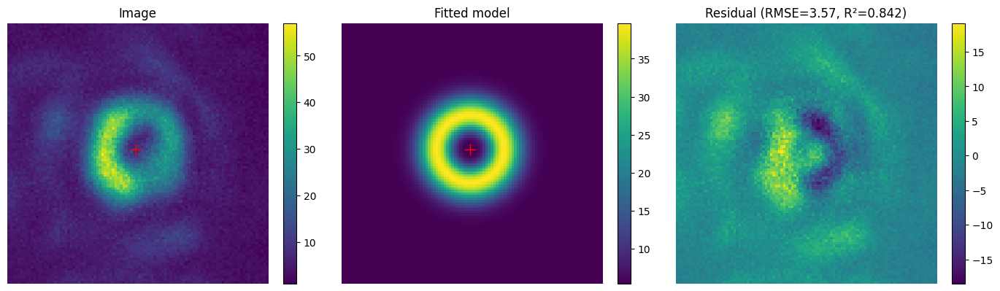

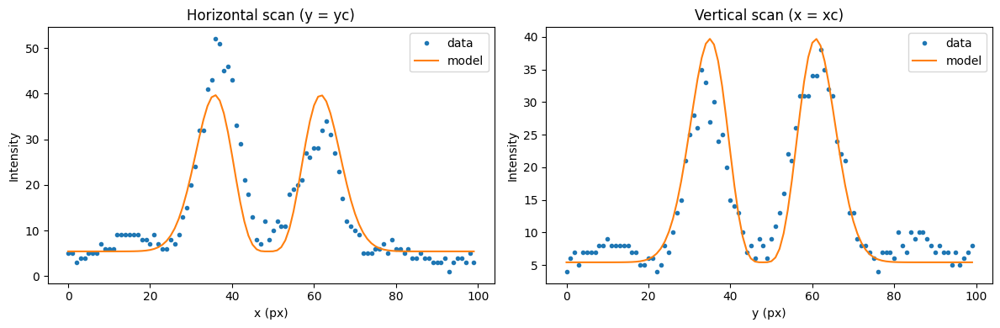

Params: {'A': 0.010714841263699, 'w': 8.909459986373568, 'xc': 48.76727182647028, 'yc': 47.751003416500964, 'B': 5.899461331499495}
Uncertainties: {'A': 8.532849770083609e-05, 'w': 0.013157264986422824, 'xc': 0.028965706818956213, 'yc': 0.028965706821646234, 'B': 0.03274446653430794}
RMSE: 3.0010440226478896 R^2: 0.8913839586414105


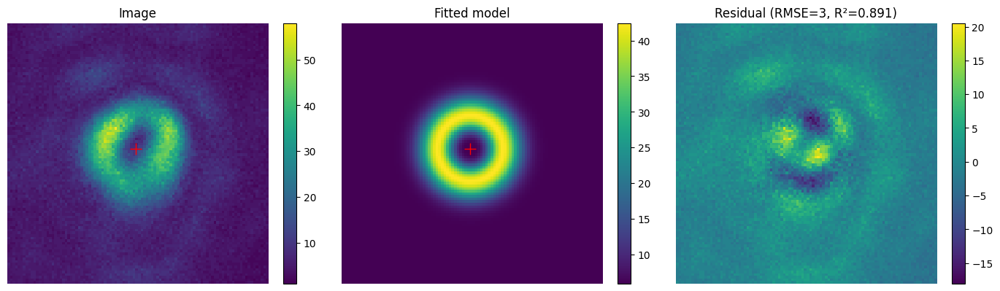

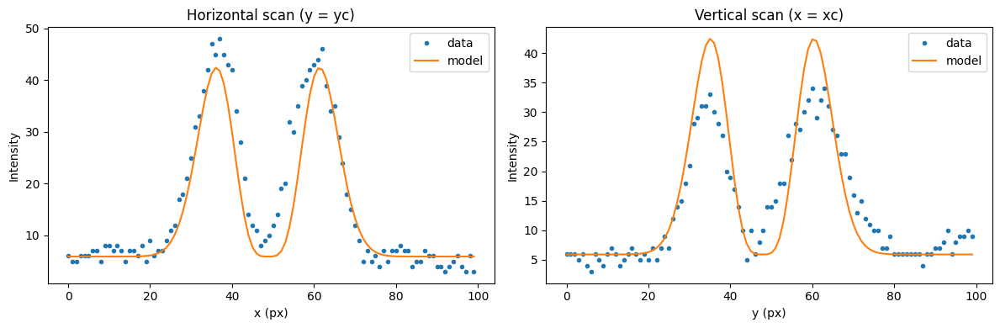

Params: {'A': 0.008815557246922625, 'w': 8.978500312330414, 'xc': 48.74483901626063, 'yc': 48.71563663694486, 'B': 5.122800390888438}
Uncertainties: {'A': 8.339345286616611e-05, 'w': 0.015754895921157423, 'xc': 0.03467451371361257, 'yc': 0.03467451370752002, 'B': 0.03331044417264032}
RMSE: 3.048402609362407 R^2: 0.8529866413302757


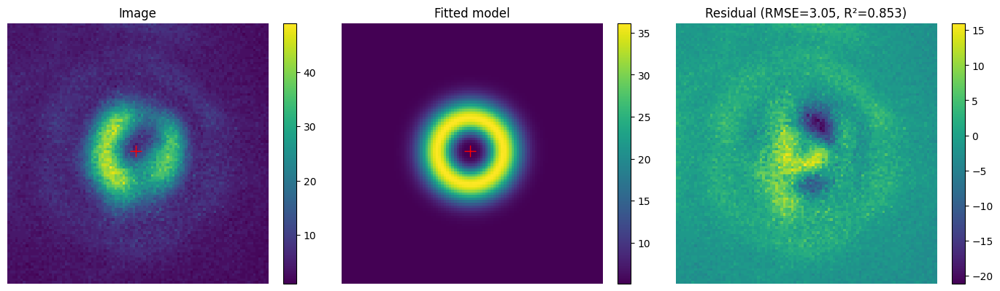

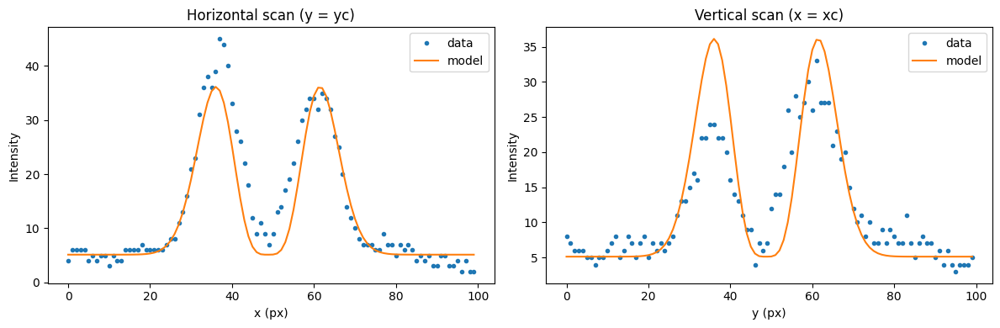

writing phase
Params: {'A': 0.009882028281144567, 'w': 9.046480880442397, 'xc': 50.343998485956426, 'yc': 48.42690754233235, 'B': 3.6810706524160937}
Uncertainties: {'A': 8.255868526716993e-05, 'w': 0.014023268583805188, 'xc': 0.030854657967826663, 'yc': 0.030854657969169086, 'B': 0.034294935273737795}
RMSE: 3.1338808084371497 R^2: 0.881254536189506


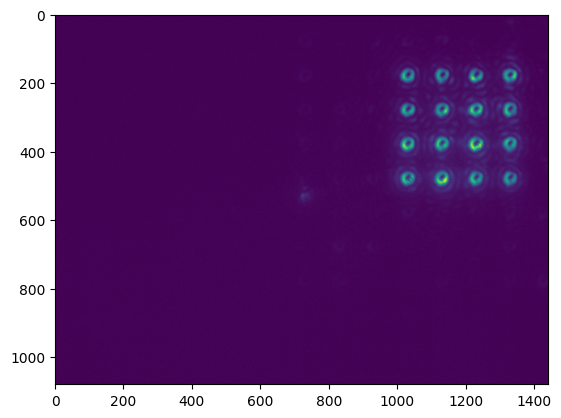

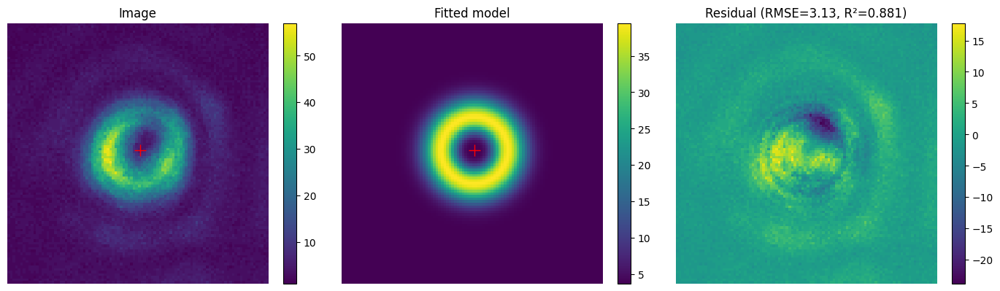

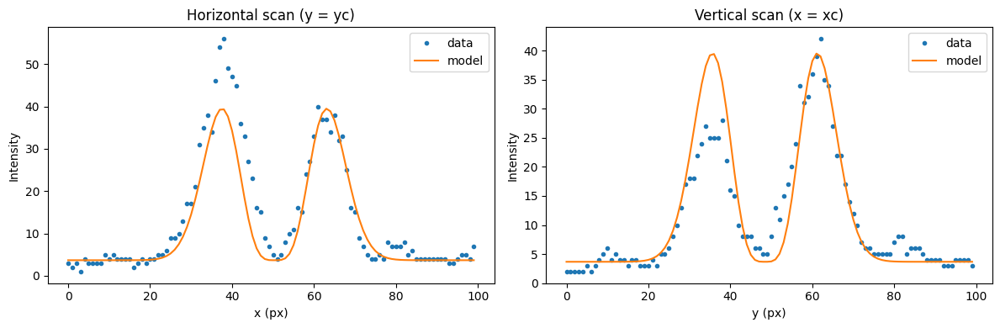

Params: {'A': 0.009978587032574185, 'w': 8.91096468201689, 'xc': 50.40201266309814, 'yc': 48.43487020021709, 'B': 4.411657094183533}
Uncertainties: {'A': 0.00010018349477609463, 'w': 0.01659053574358091, 'xc': 0.036523823982624985, 'yc': 0.03652382397782247, 'B': 0.03847872132880003}
RMSE: 3.526477745654824 R^2: 0.8377440745672053


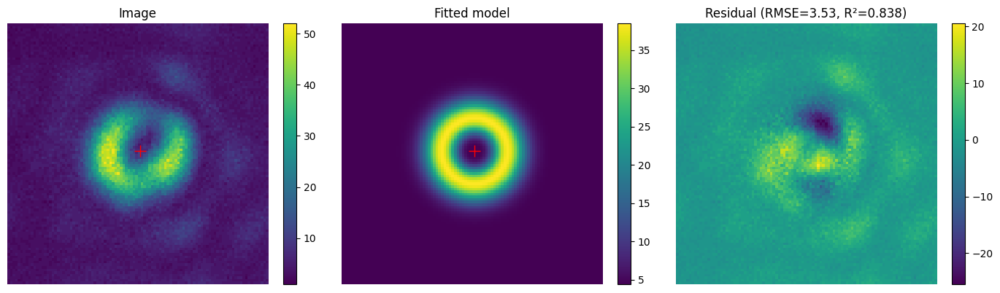

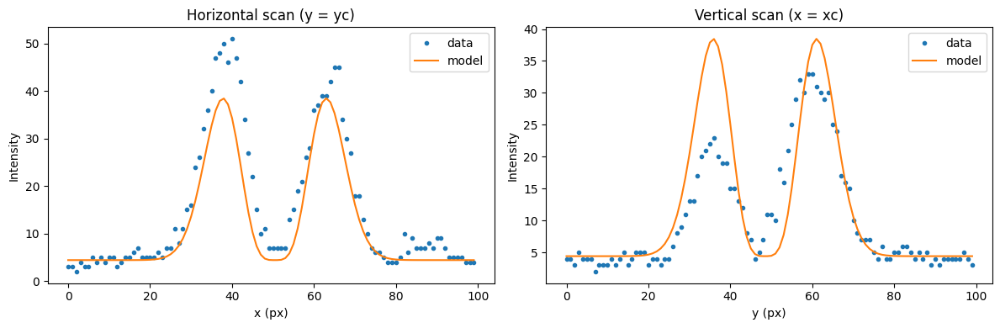

Params: {'A': 0.012013778281949595, 'w': 9.00442037414341, 'xc': 50.26755848431197, 'yc': 48.487413679597616, 'B': 5.795392212046454}
Uncertainties: {'A': 0.00010584998741461764, 'w': 0.014717815493014893, 'xc': 0.032388538470109605, 'yc': 0.032388538478335525, 'B': 0.042918258095963134}
RMSE: 3.925463819065286 R^2: 0.8698330257307415


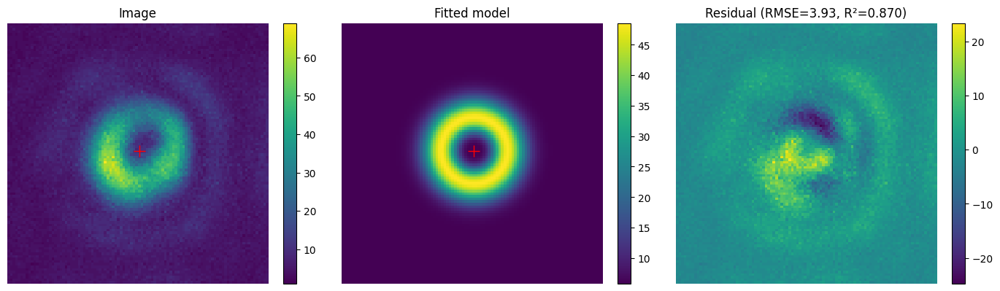

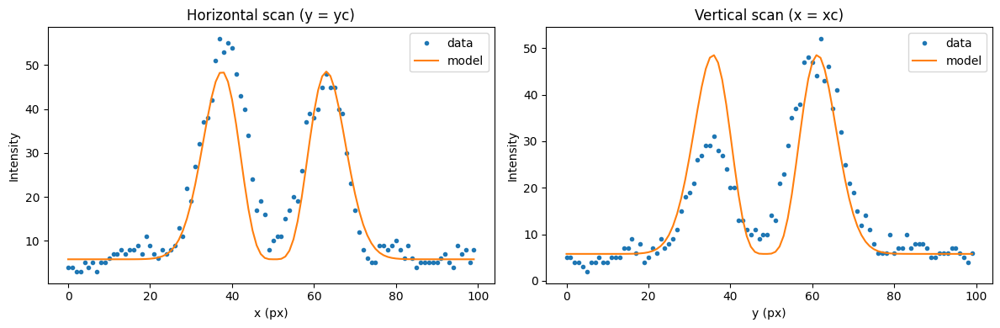

Params: {'A': 0.009443575842787658, 'w': 9.174567624538021, 'xc': 50.26364828654214, 'yc': 48.547274095431405, 'B': 5.767112181127473}
Uncertainties: {'A': 8.946176213140855e-05, 'w': 0.0161352713101776, 'xc': 0.03548223539735454, 'yc': 0.03548223540542287, 'B': 0.03998134964513014}
RMSE: 3.6432320786817356 R^2: 0.8517574607910887


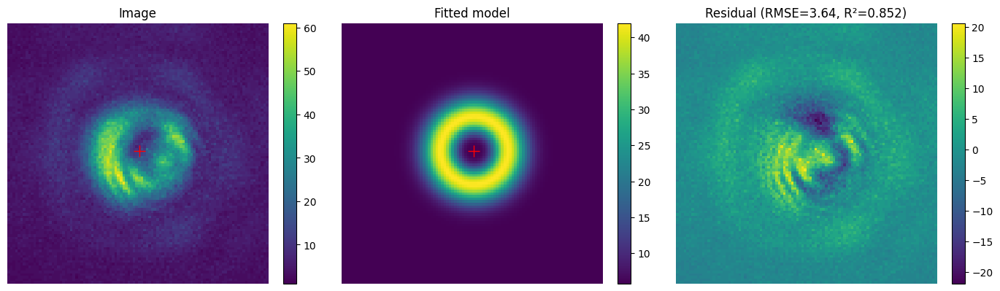

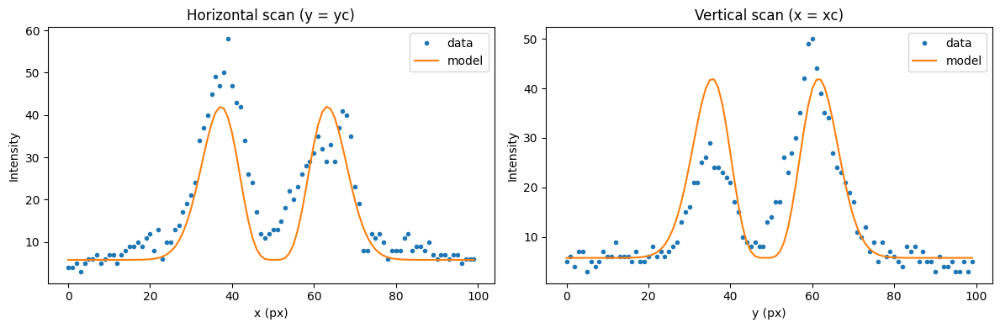

Params: {'A': 0.00790255443854211, 'w': 9.138106799008568, 'xc': 50.668623944930935, 'yc': 48.146771784723754, 'B': 4.144956022331326}
Uncertainties: {'A': 7.587134087915789e-05, 'w': 0.01628501615315305, 'xc': 0.03581713828145436, 'yc': 0.035817138277042596, 'B': 0.03321239992901518}
RMSE: 3.0288674281650314 R^2: 0.8485149696271218


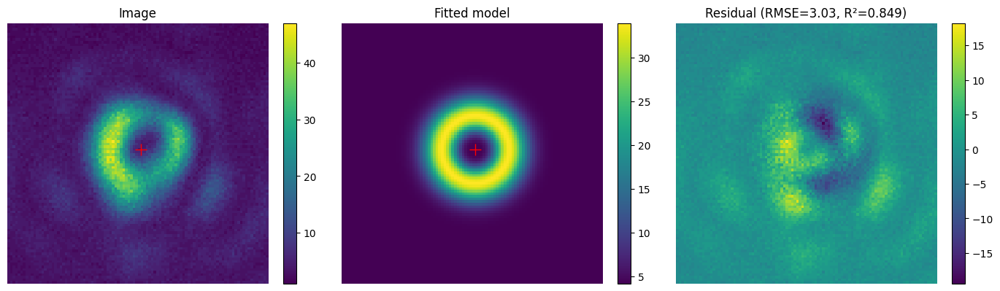

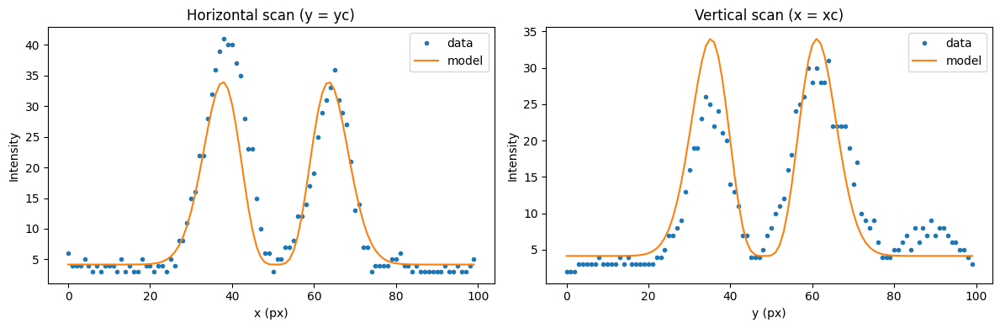

Params: {'A': 0.01011019337956999, 'w': 8.953669803520256, 'xc': 50.279235437107225, 'yc': 48.069097149270135, 'B': 5.460001724338391}
Uncertainties: {'A': 9.46929625560438e-05, 'w': 0.015554075458666343, 'xc': 0.03423605432233553, 'yc': 0.0342360543241391, 'B': 0.03728384119426995}
RMSE: 3.4138499911653373 R^2: 0.8555727377294673


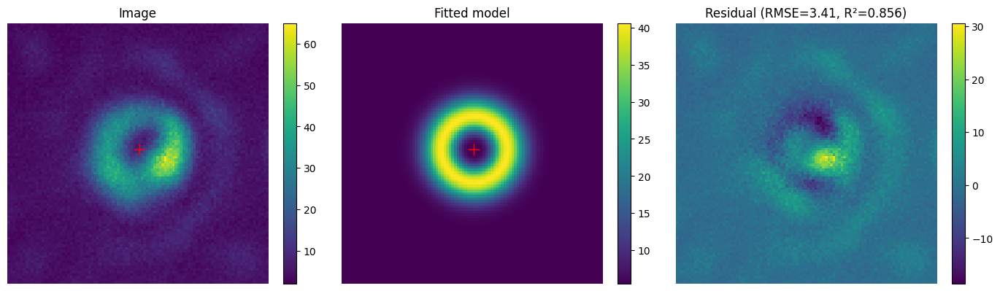

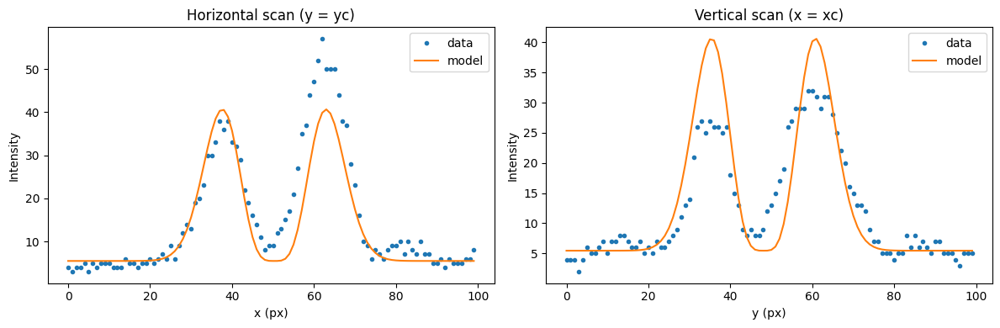

Params: {'A': 0.010889054488687008, 'w': 9.014240358826214, 'xc': 49.889297103933956, 'yc': 47.46785777280142, 'B': 6.694134213073802}
Uncertainties: {'A': 9.102483718554676e-05, 'w': 0.013979546407381112, 'xc': 0.03076261603895583, 'yc': 0.030762616035294843, 'B': 0.037116786373730865}
RMSE: 3.3941180193573666 R^2: 0.8812508347943917


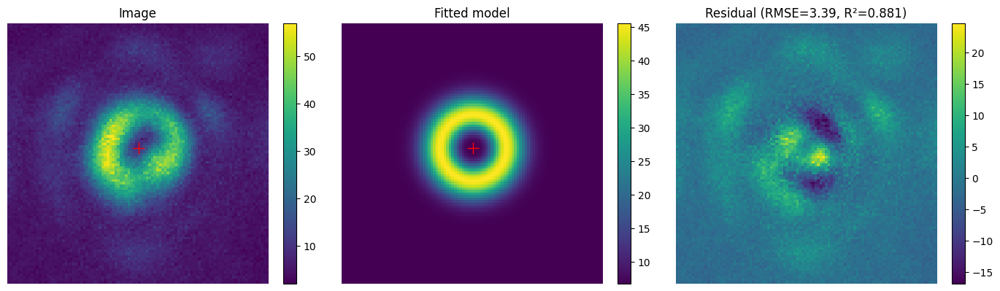

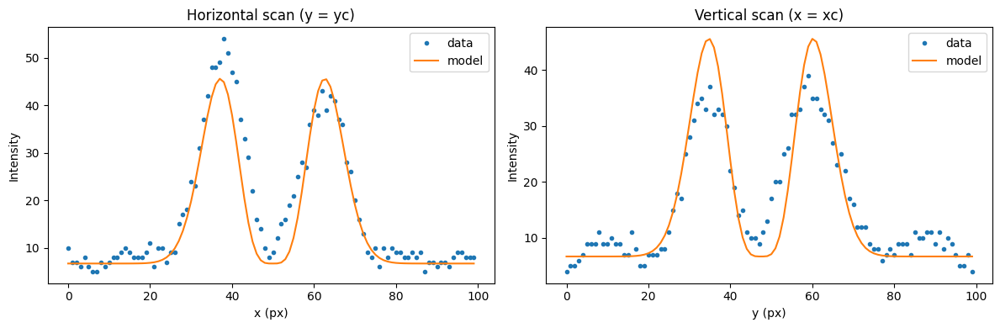

Params: {'A': 0.011041887862206886, 'w': 9.265463033361371, 'xc': 49.62552273383669, 'yc': 48.412593600678086, 'B': 6.9867896970247605}
Uncertainties: {'A': 0.00011096843205318037, 'w': 0.01729356292556708, 'xc': 0.038014355874237106, 'yc': 0.038014355872498164, 'B': 0.052204714012811224}
RMSE: 4.747406787422755 R^2: 0.8357625092001675


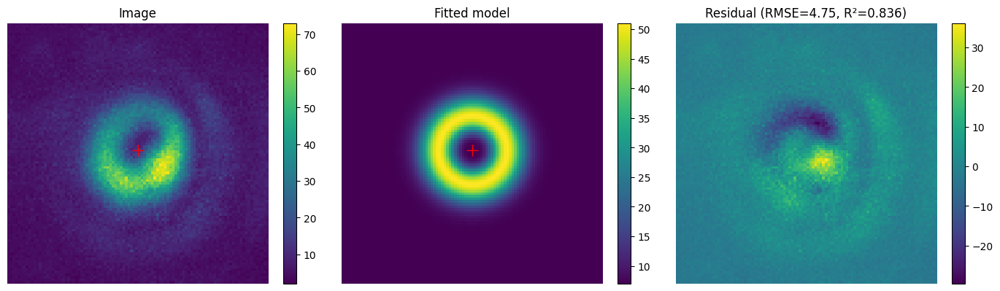

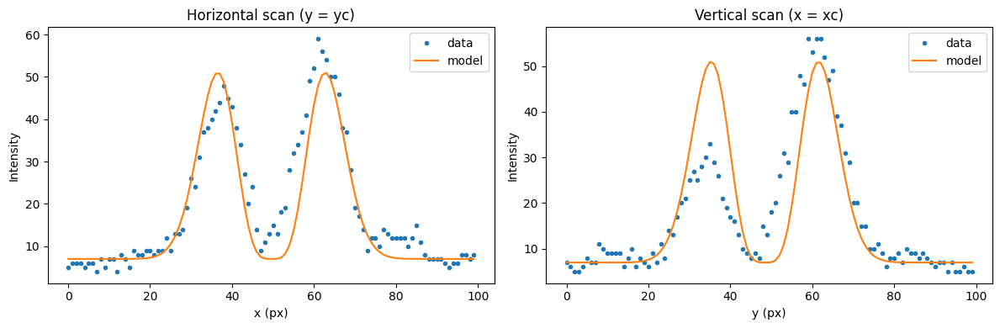

Params: {'A': 0.010051841485512625, 'w': 8.930536042282911, 'xc': 49.47573752710601, 'yc': 48.79435527506276, 'B': 4.159213584645667}
Uncertainties: {'A': 0.00012304163667303366, 'w': 0.020273440547905395, 'xc': 0.0446280988819946, 'yc': 0.0446280988869881, 'B': 0.047799358990782234}
RMSE: 4.378860355802407 R^2: 0.7763381193105855


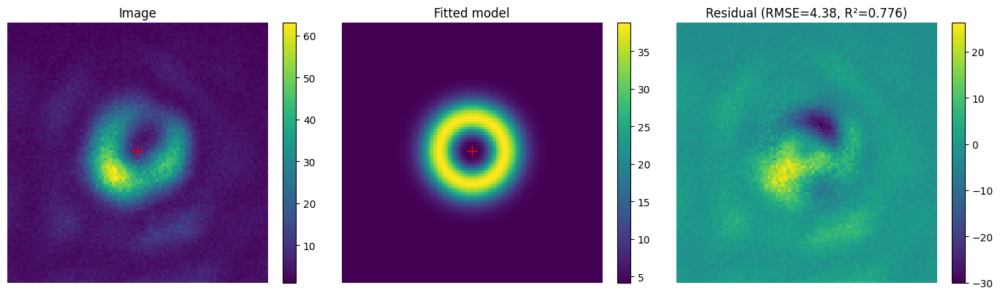

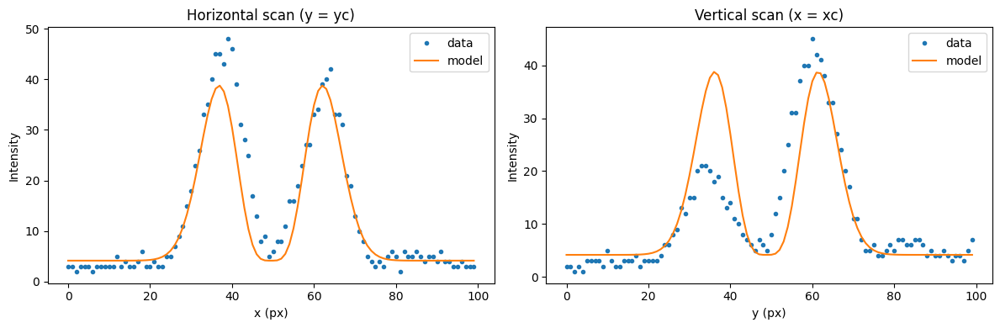

Params: {'A': 0.011610197295329226, 'w': 8.94521203925376, 'xc': 49.53815633678939, 'yc': 47.860006610401946, 'B': 6.355454003829901}
Uncertainties: {'A': 0.00010725347778014588, 'w': 0.015326117181992756, 'xc': 0.033735473814185284, 'yc': 0.033735473814877105, 'B': 0.04202264404577119}
RMSE: 3.848450810426203 R^2: 0.8589815520574133


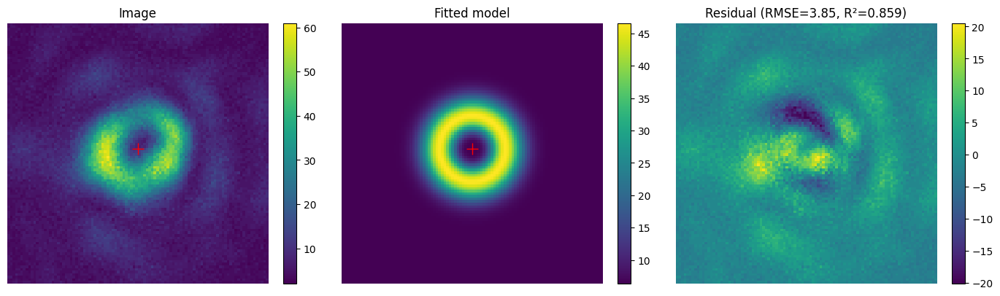

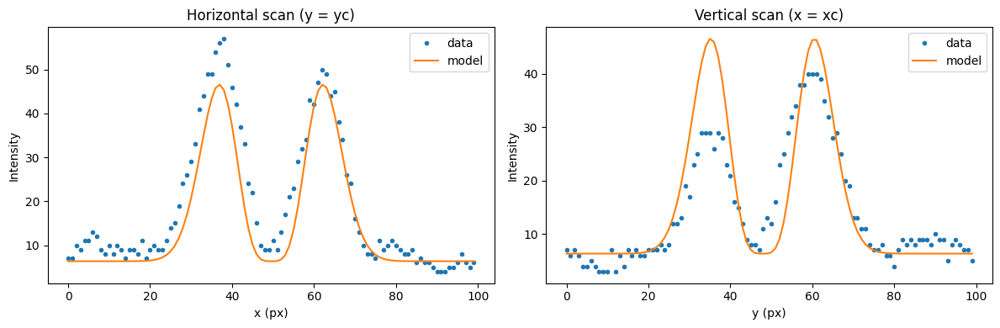

Params: {'A': 0.011060991898016797, 'w': 9.34075608281211, 'xc': 49.27040255823382, 'yc': 48.307468623158, 'B': 6.926696479305095}
Uncertainties: {'A': 0.0001120312858768727, 'w': 0.01757651876717507, 'xc': 0.0386235037987374, 'yc': 0.03862350379140209, 'B': 0.05497492098848395}
RMSE: 4.990807695269128 R^2: 0.8332277767827221


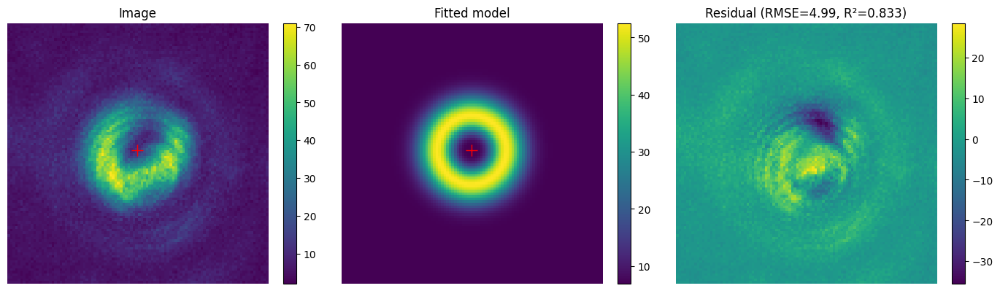

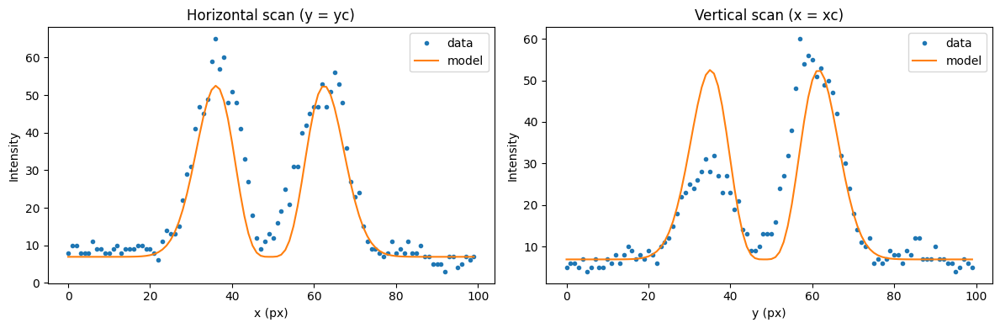

Params: {'A': 0.009565178084163297, 'w': 9.034628504503948, 'xc': 49.33335970301441, 'yc': 48.336111761397, 'B': 6.378103588019843}
Uncertainties: {'A': 9.756841155939798e-05, 'w': 0.01709849003417597, 'xc': 0.03762277844752198, 'yc': 0.03762277844628762, 'B': 0.04025479680283157}
RMSE: 3.6794430923247843 R^2: 0.8327876820714266


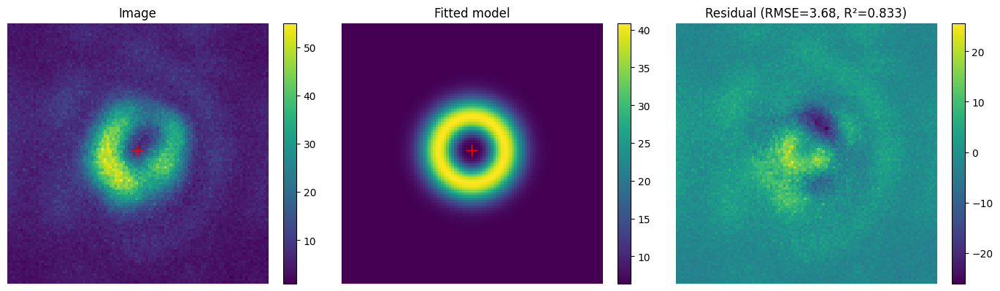

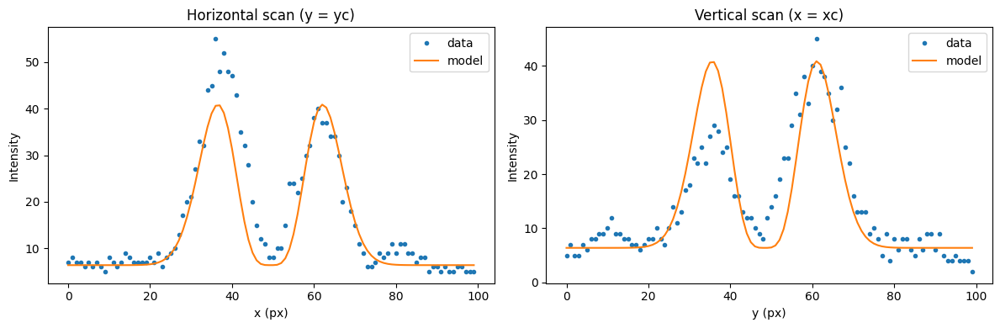

Params: {'A': 0.010375317214578867, 'w': 9.060873596057384, 'xc': 49.1306579858768, 'yc': 48.08218319593292, 'B': 4.4390386807228195}
Uncertainties: {'A': 8.842094160800115e-05, 'w': 0.014328576590284572, 'xc': 0.03152450052654022, 'yc': 0.03152450053429714, 'B': 0.037034851096530014}
RMSE: 3.3831936161854888 R^2: 0.8769741340261185


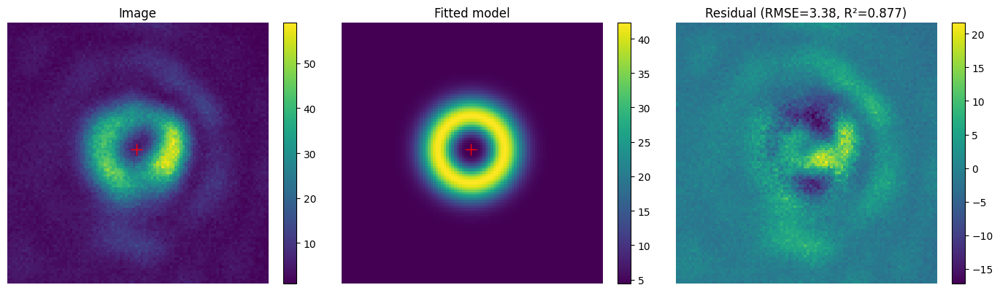

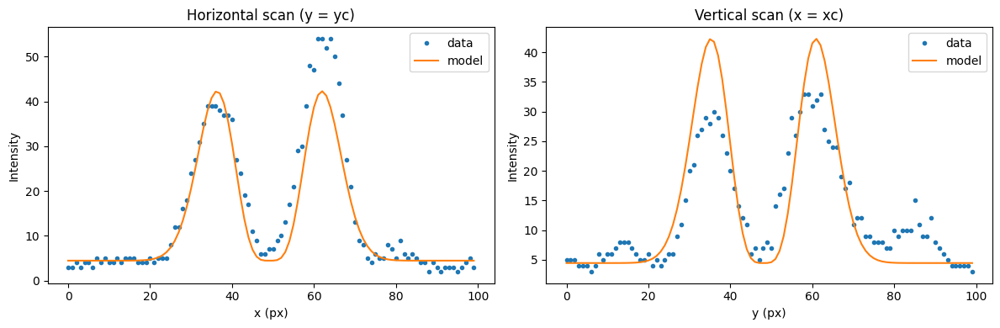

Params: {'A': 0.008879466822765204, 'w': 9.131196589275282, 'xc': 48.7423720381262, 'yc': 47.85351100562162, 'B': 5.448852869629712}
Uncertainties: {'A': 9.305078095324916e-05, 'w': 0.01776109335358844, 'xc': 0.03906476512449428, 'yc': 0.039064765131419946, 'B': 0.04057267195473137}
RMSE: 3.7006656206808266 R^2: 0.8246456554445045


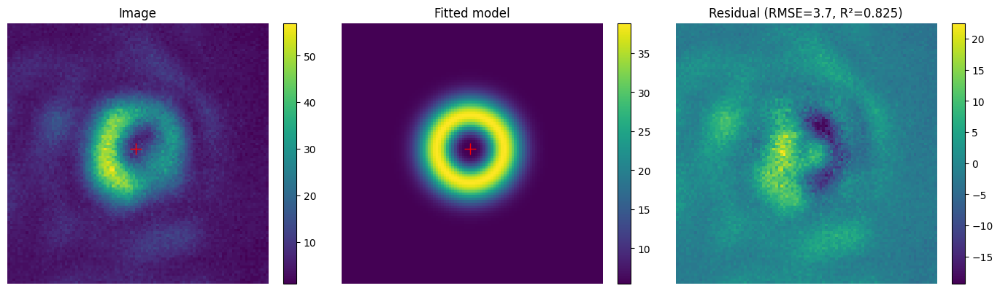

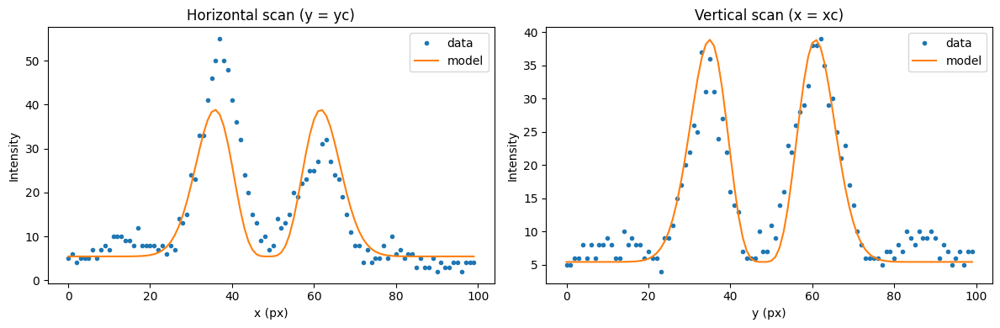

Params: {'A': 0.010434057435765778, 'w': 8.910388333210797, 'xc': 48.95636539238982, 'yc': 47.703059565549786, 'B': 5.929549741668775}
Uncertainties: {'A': 8.816362651765793e-05, 'w': 0.013961767105241453, 'xc': 0.03073670054225468, 'yc': 0.03073670054522597, 'B': 0.033850735681770584}
RMSE: 3.1023726554308038 R^2: 0.8793663144745227


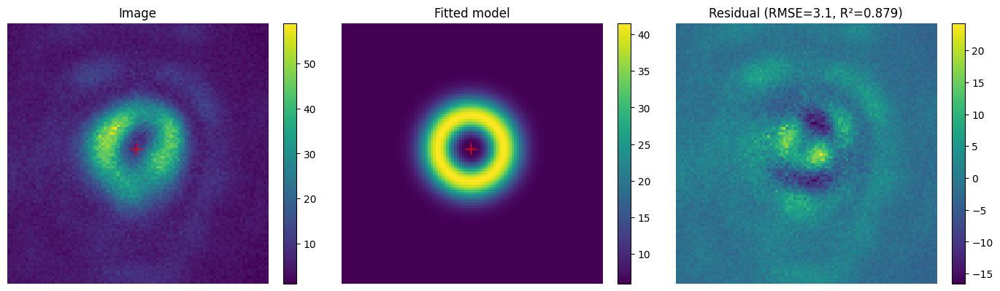

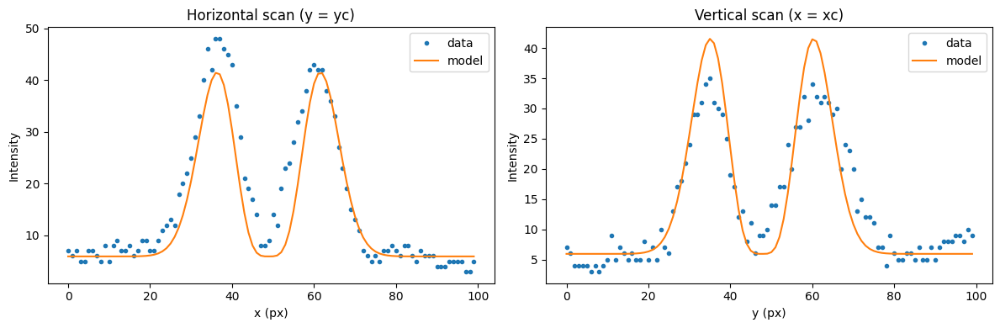

Params: {'A': 0.008417603501009799, 'w': 9.012733577213906, 'xc': 48.89764919196177, 'yc': 48.720266909904474, 'B': 5.120797199252291}
Uncertainties: {'A': 8.523687057057927e-05, 'w': 0.016931172485051518, 'xc': 0.037258035782726656, 'yc': 0.03725803577620574, 'B': 0.034726480795898594}
RMSE: 3.1756418793141084 R^2: 0.8349209105020023


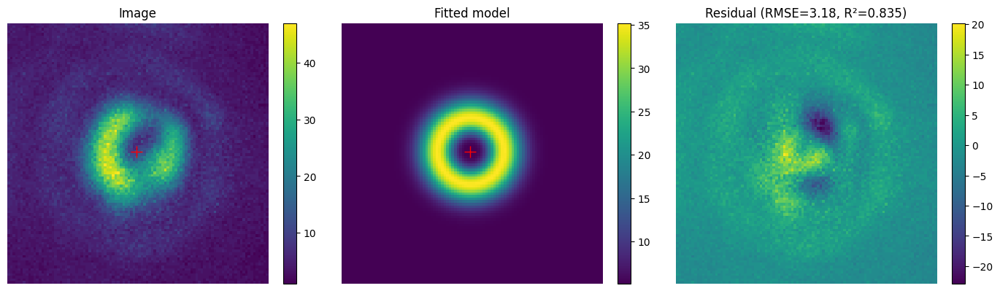

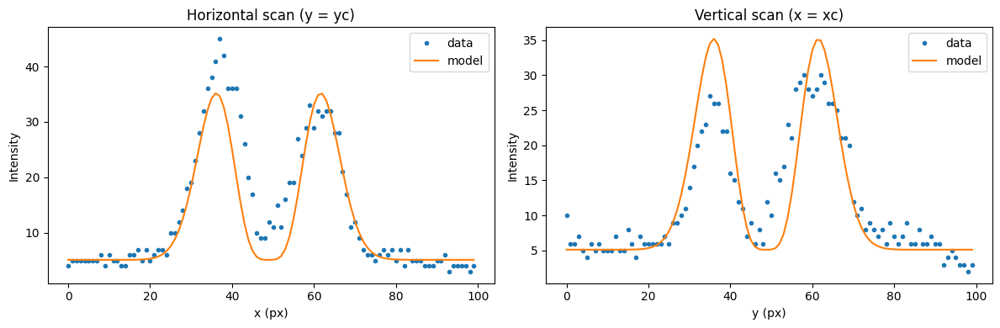

writing phase
Params: {'A': 0.009408934854334312, 'w': 9.072706163709785, 'xc': 50.349968656159575, 'yc': 48.409666948135914, 'B': 3.712629507565088}
Uncertainties: {'A': 8.512943936595027e-05, 'w': 0.015232706644340448, 'xc': 0.03351201550795719, 'yc': 0.03351201550873619, 'B': 0.03589891643278406}
RMSE: 3.278576788839071 R^2: 0.8634208589165865


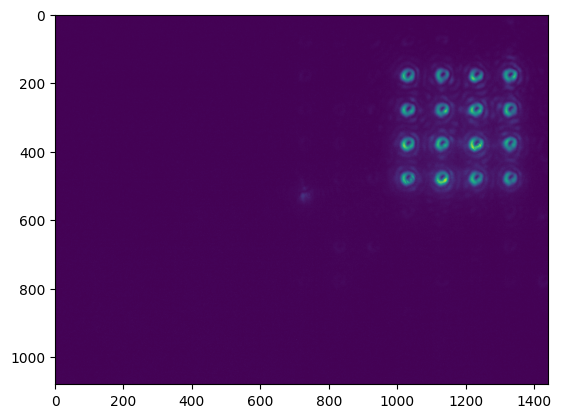

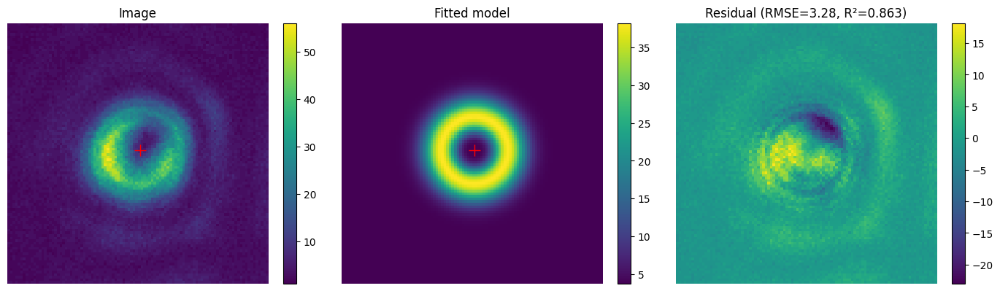

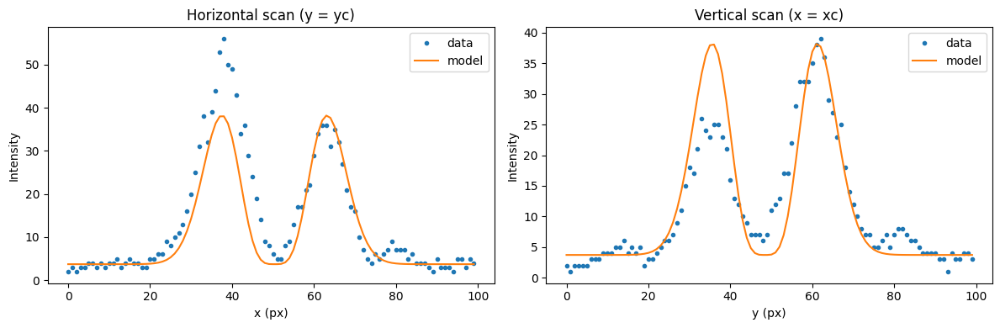

Params: {'A': 0.009564604107659365, 'w': 8.919269002528372, 'xc': 50.46250003995833, 'yc': 48.43785454324486, 'B': 4.441223854962682}
Uncertainties: {'A': 0.00010246961559895565, 'w': 0.017720693884418926, 'xc': 0.03901052199189854, 'yc': 0.03901052200281577, 'B': 0.03954751533606558}
RMSE: 3.623787952680349 R^2: 0.8192658191484223


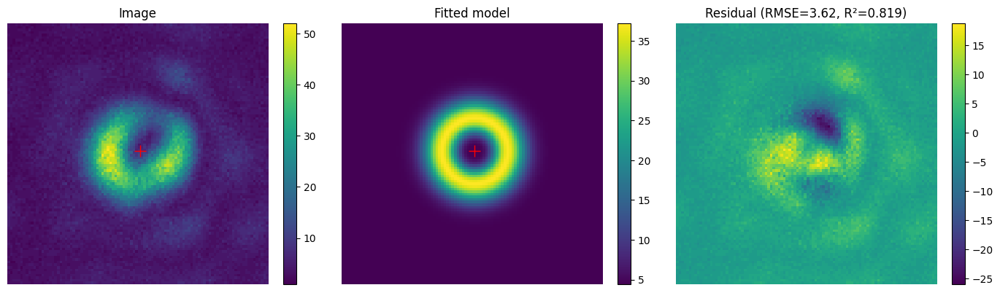

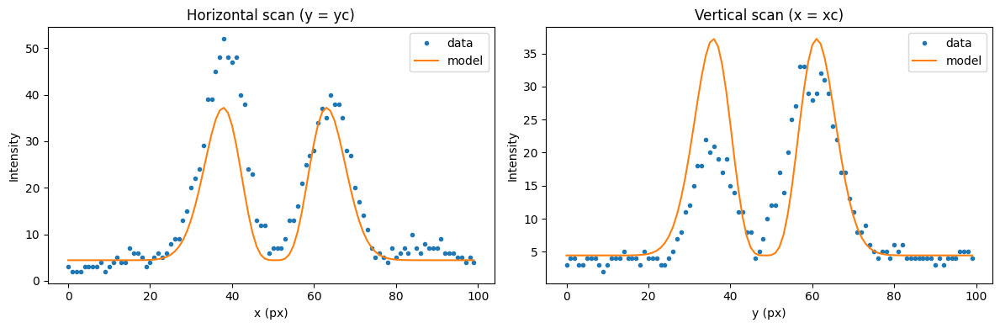

Params: {'A': 0.011367259772221902, 'w': 9.038651059273286, 'xc': 50.32719964493684, 'yc': 48.42953574795455, 'B': 5.8285491678743835}
Uncertainties: {'A': 0.0001090497920363158, 'w': 0.016088342174119974, 'xc': 0.03539949515960322, 'yc': 0.035399495150332874, 'B': 0.04509597984517414}
RMSE: 4.121585400745027 R^2: 0.8491676590309677


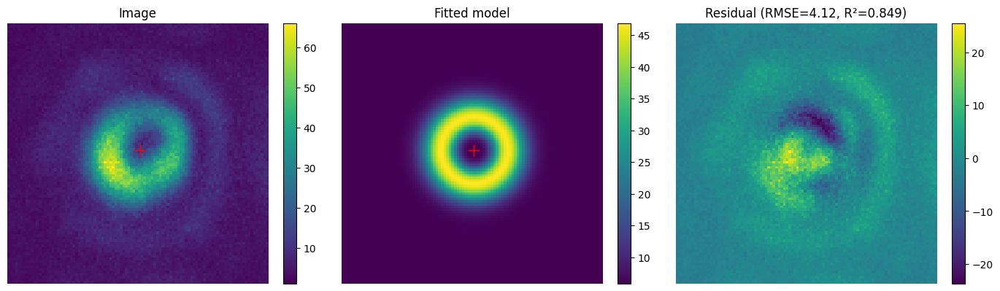

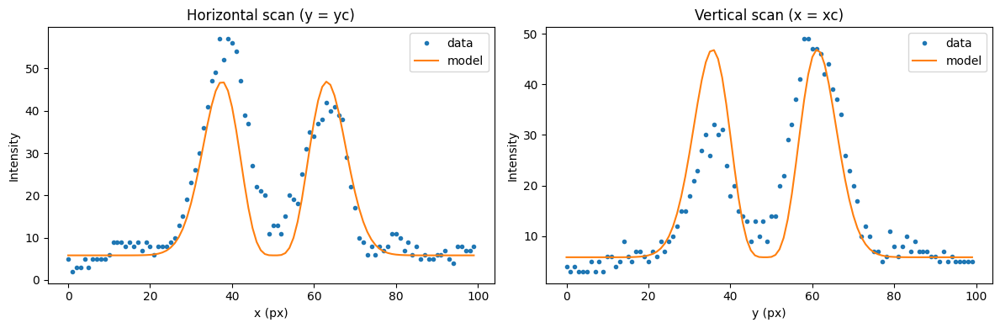

Params: {'A': 0.009037802788401085, 'w': 9.200129374070471, 'xc': 50.2545800864606, 'yc': 48.44347385805948, 'B': 5.781350456359246}
Uncertainties: {'A': 9.009299142952359e-05, 'w': 0.017027846036155155, 'xc': 0.03744091661063883, 'yc': 0.037440916610561085, 'B': 0.04085071230799863}
RMSE: 3.7203349168429574 R^2: 0.8383003861019038


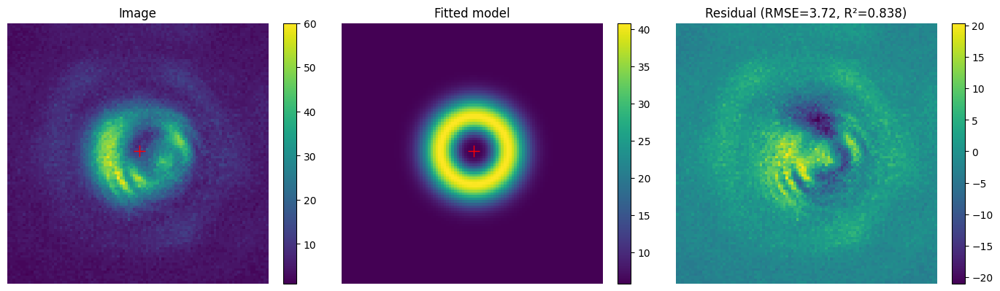

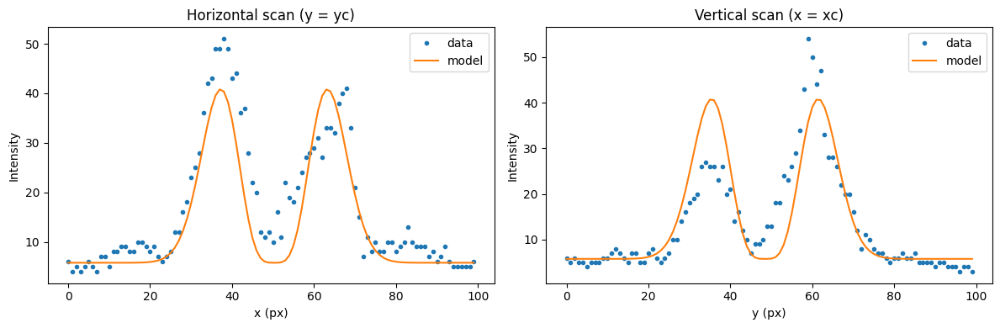

Params: {'A': 0.0073708311322062256, 'w': 9.193340069653885, 'xc': 50.755810761969755, 'yc': 48.12432462861296, 'B': 4.156305696980253}
Uncertainties: {'A': 7.801082062784062e-05, 'w': 0.018064942575947637, 'xc': 0.039722456783561184, 'yc': 0.03972245678324779, 'B': 0.035236659750055785}
RMSE: 3.209540286219766 R^2: 0.8214347349463678


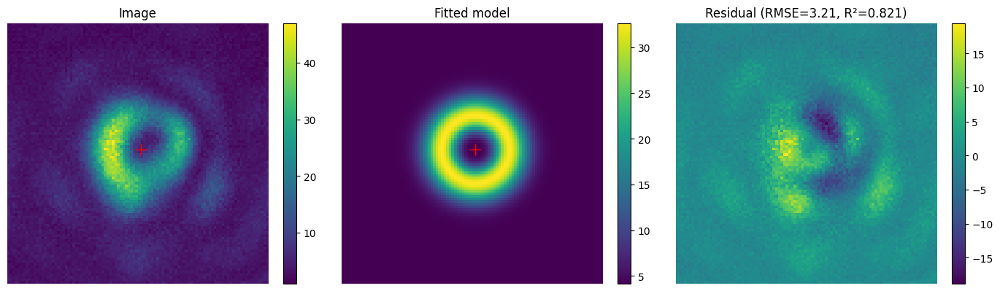

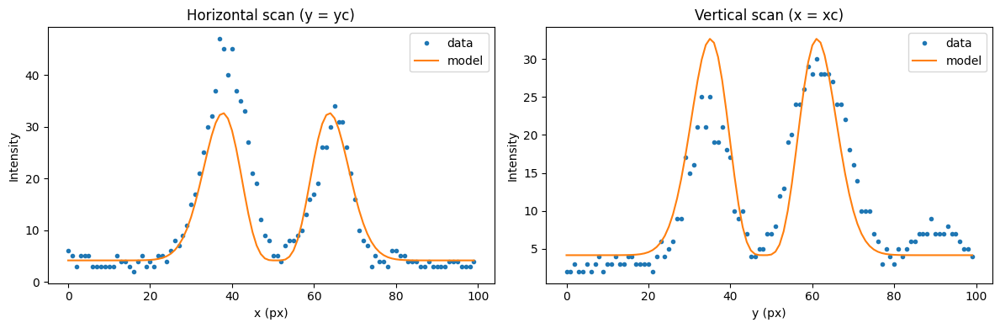

Params: {'A': 0.009573293627543144, 'w': 8.976985280743476, 'xc': 50.306349763113204, 'yc': 47.93585419429587, 'B': 5.4771753629167845}
Uncertainties: {'A': 9.251130611273734e-05, 'w': 0.01609128631304435, 'xc': 0.035415088948879674, 'yc': 0.03541508895666762, 'B': 0.036920082396898174}
RMSE: 3.378848630715098 R^2: 0.8475702066247882


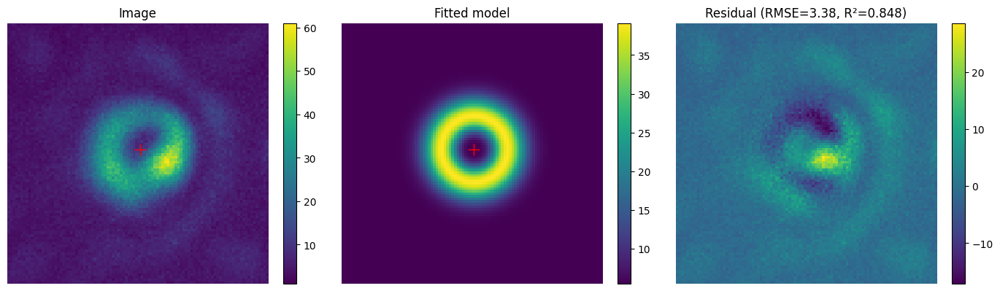

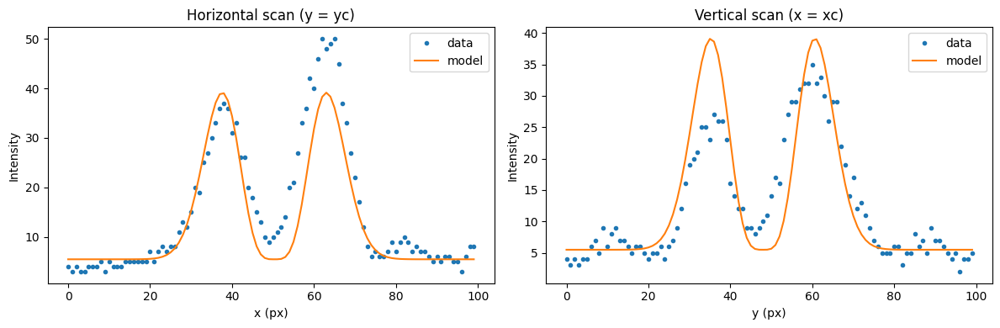

Params: {'A': 0.010411197173969008, 'w': 9.024873117616028, 'xc': 49.902009162418445, 'yc': 47.395596932636224, 'B': 6.698306652130391}
Uncertainties: {'A': 9.380201555873261e-05, 'w': 0.015085722965142438, 'xc': 0.03319533032473245, 'yc': 0.03319533031945156, 'B': 0.038484212049923465}
RMSE: 3.5183500993625882 R^2: 0.8646073572172954


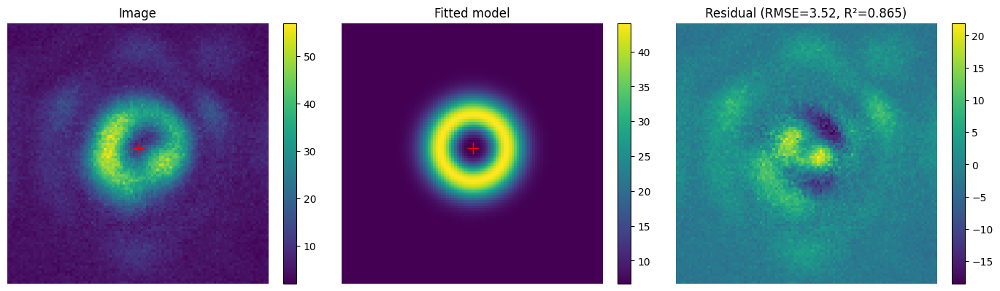

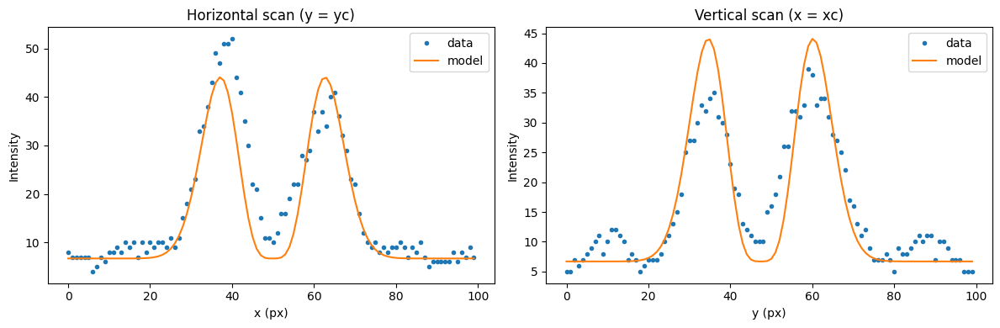

Params: {'A': 0.010603810207611055, 'w': 9.292342691044164, 'xc': 49.60212070202648, 'yc': 48.35224770277928, 'B': 6.993433845137175}
Uncertainties: {'A': 0.00011038055258347793, 'w': 0.017966702091900585, 'xc': 0.039489371952974375, 'yc': 0.03948937195543582, 'B': 0.052717725941013115}
RMSE: 4.79115267868367 R^2: 0.8257372829584895


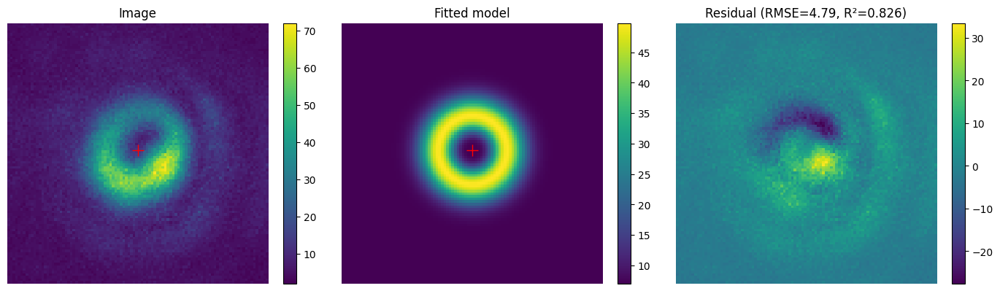

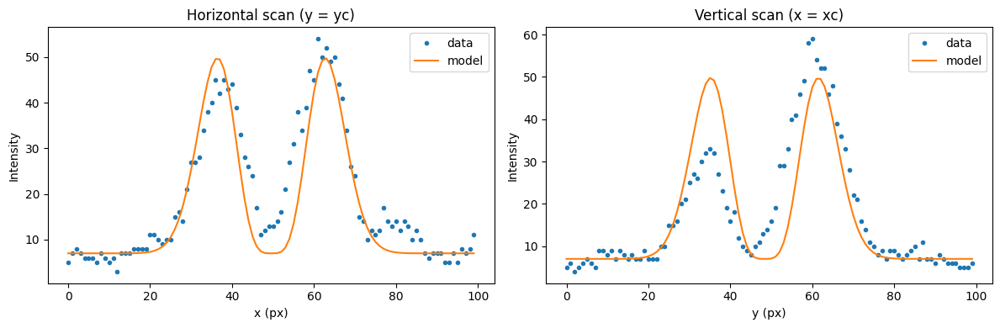

Params: {'A': 0.009717131229421088, 'w': 8.931665634848553, 'xc': 49.41991300588549, 'yc': 48.799922814667894, 'B': 4.173249873950522}
Uncertainties: {'A': 0.00012504270554908602, 'w': 0.02131563297267067, 'xc': 0.0469220676778222, 'yc': 0.046922067675539525, 'B': 0.048608640142086317}
RMSE: 4.452890366870945 R^2: 0.7584898303415692


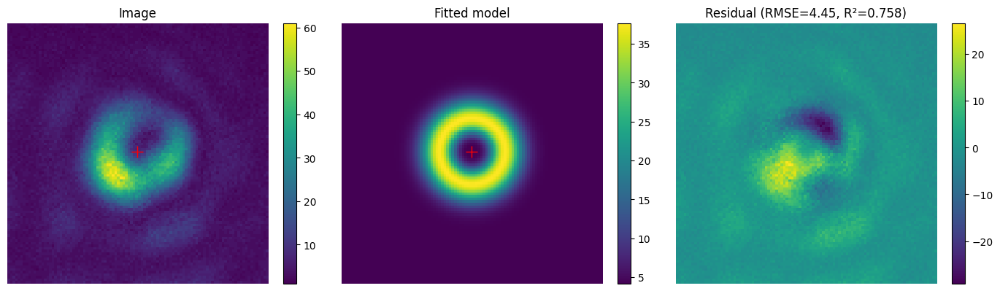

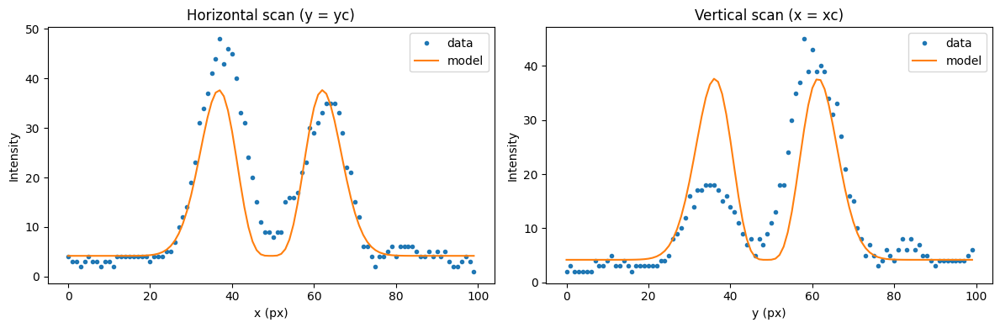

Params: {'A': 0.010966639460017573, 'w': 8.98007599575362, 'xc': 49.565546553170805, 'yc': 47.87031572192953, 'B': 6.38945468289505}
Uncertainties: {'A': 0.00010904508914923497, 'w': 0.016563226777547787, 'xc': 0.036453308341668995, 'yc': 0.036453308343114214, 'B': 0.043596374453633846}
RMSE: 3.989583234342878 R^2: 0.8400314391497152


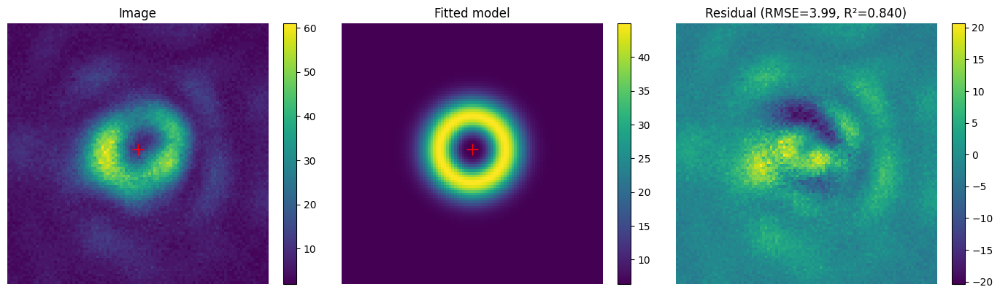

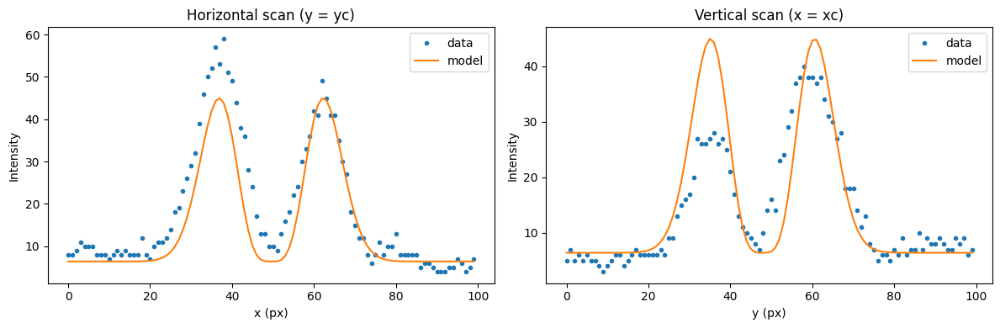

Params: {'A': 0.010489880158628586, 'w': 9.374680952223946, 'xc': 49.212949544138276, 'yc': 48.29250421187101, 'B': 6.930468059460946}
Uncertainties: {'A': 0.00011200659751074764, 'w': 0.01859948301380568, 'xc': 0.040865231669058755, 'yc': 0.04086523166671344, 'B': 0.05601155931257685}
RMSE: 5.0809795218614235 R^2: 0.8178494592850224


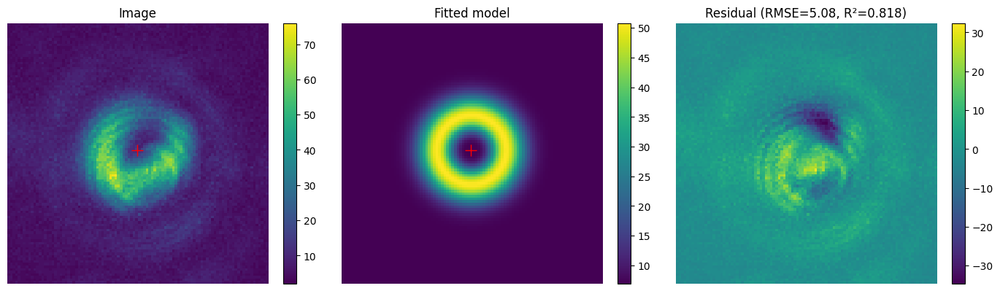

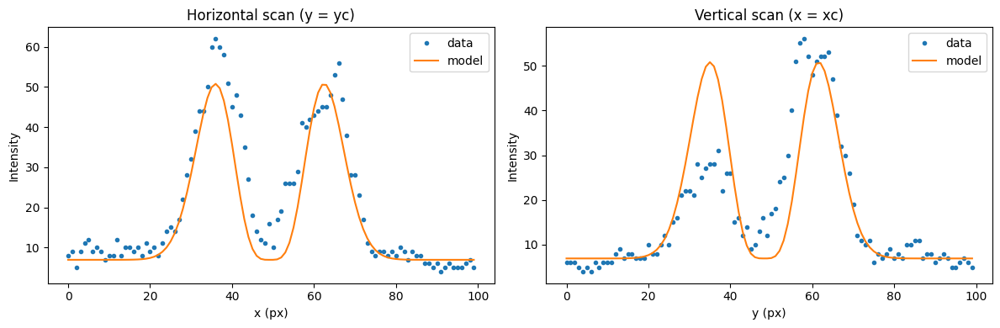

Params: {'A': 0.009074602949446363, 'w': 9.070987795526575, 'xc': 49.33753539893303, 'yc': 48.26074191746686, 'B': 6.395301397368709}
Uncertainties: {'A': 9.878727018350178e-05, 'w': 0.018324228599871574, 'xc': 0.040313669055691996, 'yc': 0.040313669054129926, 'B': 0.04161739812927336}
RMSE: 3.8009771260817793 R^2: 0.8136807774490509


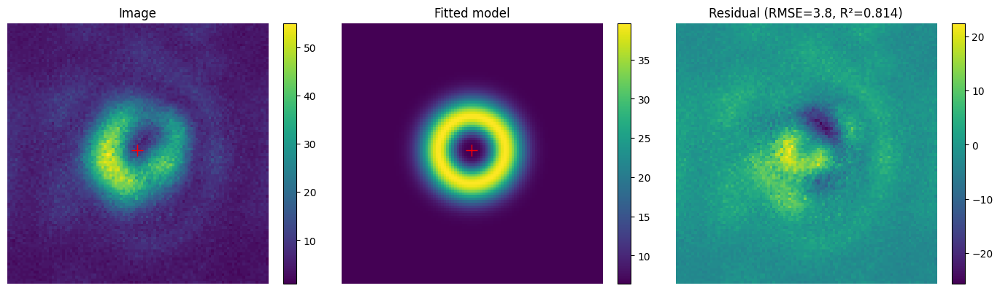

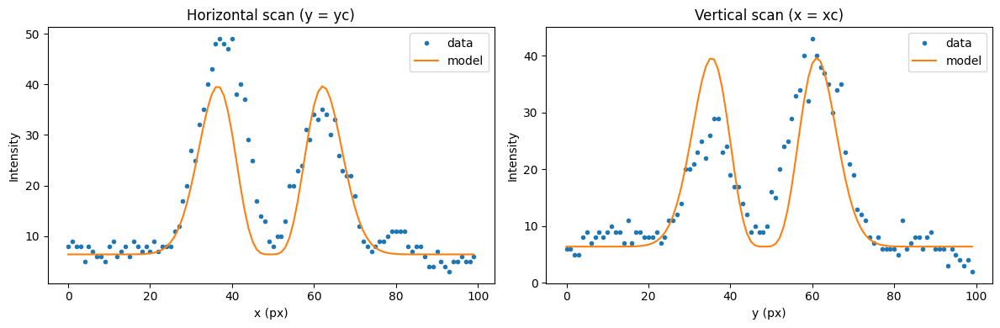

Params: {'A': 0.009978884669110151, 'w': 9.067262820681853, 'xc': 49.17172265039207, 'yc': 48.00113832694113, 'B': 4.460071469473172}
Uncertainties: {'A': 8.760160698126095e-05, 'w': 0.014770568506851052, 'xc': 0.032496056782041004, 'yc': 0.032496056787716075, 'B': 0.03682635861887165}
RMSE: 3.363678291897975 R^2: 0.8704067792008585


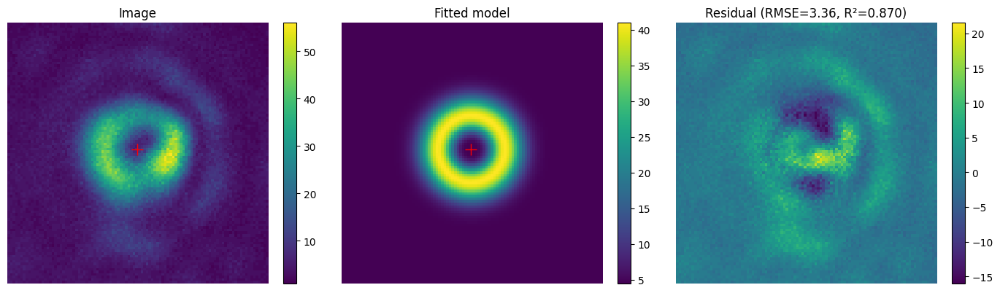

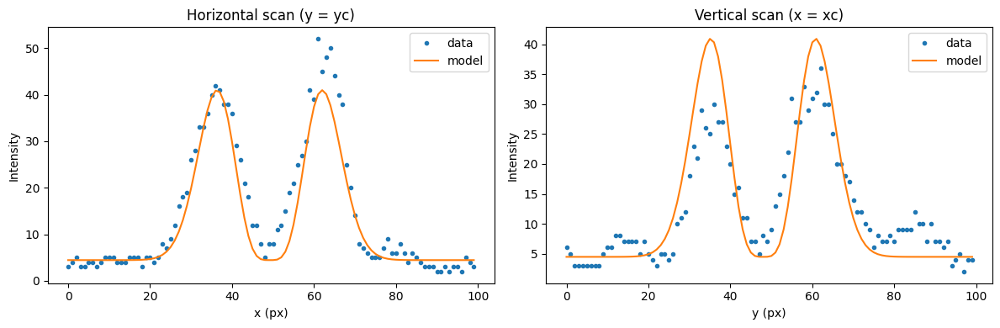

Params: {'A': 0.00868807110521369, 'w': 9.12119560957955, 'xc': 48.70894241807741, 'yc': 47.845553998075495, 'B': 5.4541971949626715}
Uncertainties: {'A': 9.656189341165568e-05, 'w': 0.018815878616655506, 'xc': 0.04138648727852867, 'yc': 0.0413864872931501, 'B': 0.04186431740312525}
RMSE: 3.8193194010116334 R^2: 0.8070324347211635


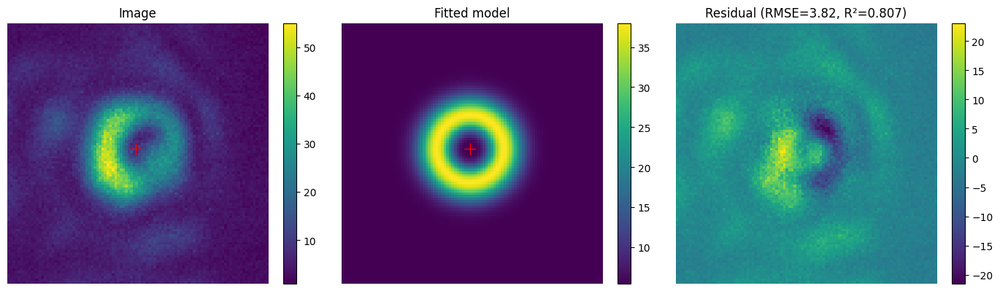

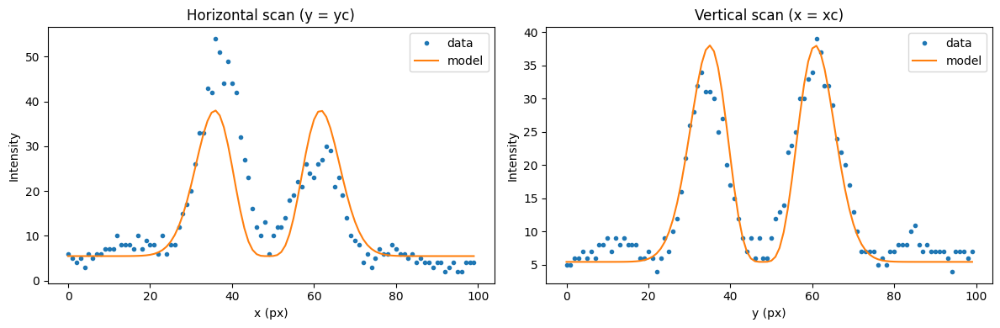

Params: {'A': 0.00983228259529957, 'w': 8.946481906938619, 'xc': 49.046691454337086, 'yc': 47.7670738537585, 'B': 5.954271521918319}
Uncertainties: {'A': 8.786197490666644e-05, 'w': 0.014827601059547542, 'xc': 0.03263798116486817, 'yc': 0.03263798116473409, 'B': 0.03445030056531833}
RMSE: 3.1548866399908624 R^2: 0.866833091208121


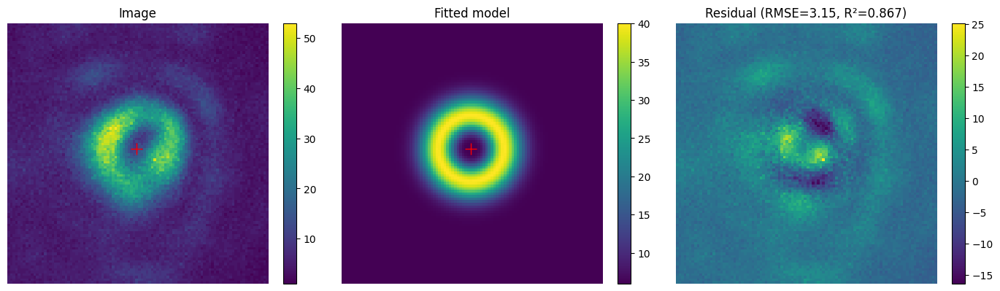

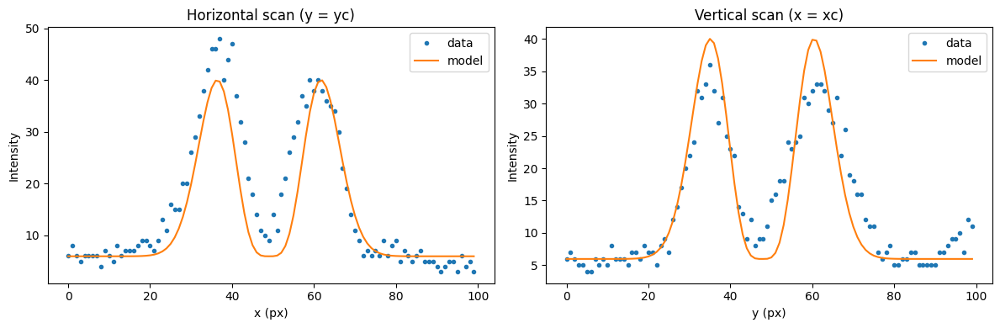

Params: {'A': 0.008011384468958764, 'w': 9.034910177378698, 'xc': 48.88900063286211, 'yc': 48.71824110975508, 'B': 5.141318694364093}
Uncertainties: {'A': 8.765057682613127e-05, 'w': 0.018340148307843338, 'xc': 0.04035482188195949, 'yc': 0.04035482187909597, 'B': 0.03616875336328466}
RMSE: 3.3059427862069986 R^2: 0.8123517762063865


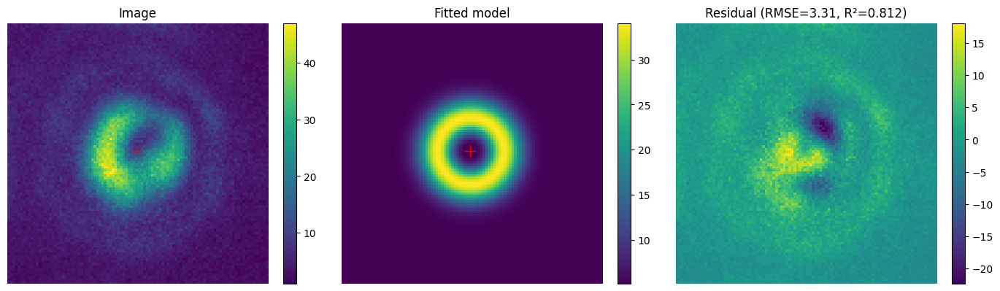

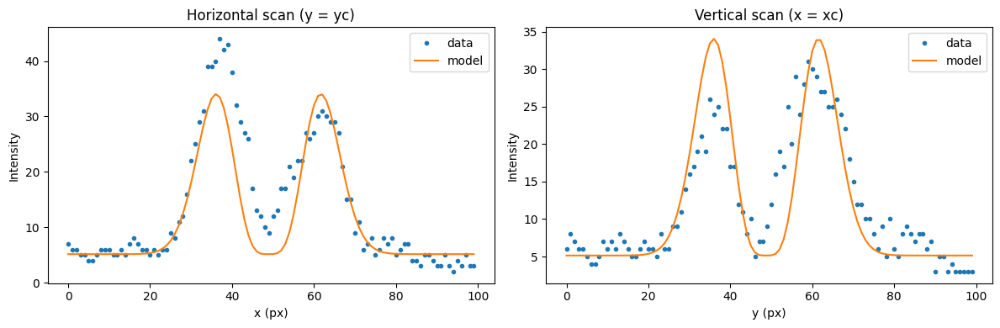

writing phase
Params: {'A': 0.008962445686799488, 'w': 9.11230722238958, 'xc': 50.27650412543368, 'yc': 48.485881977733115, 'B': 3.8197373815465596}
Uncertainties: {'A': 8.931845286774858e-05, 'w': 0.01685453931877218, 'xc': 0.03707382533735584, 'yc': 0.037073825327645284, 'B': 0.03852808276728805}
RMSE: 3.515639360336167 R^2: 0.838795579211709


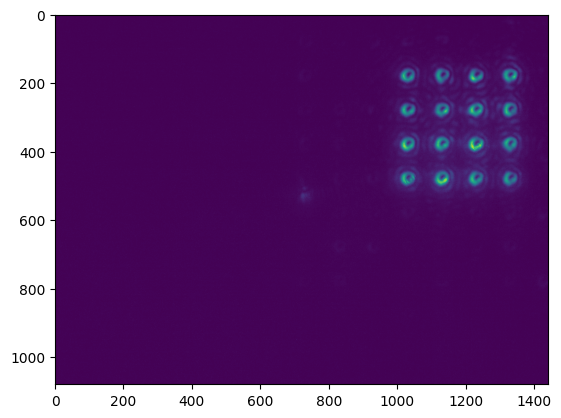

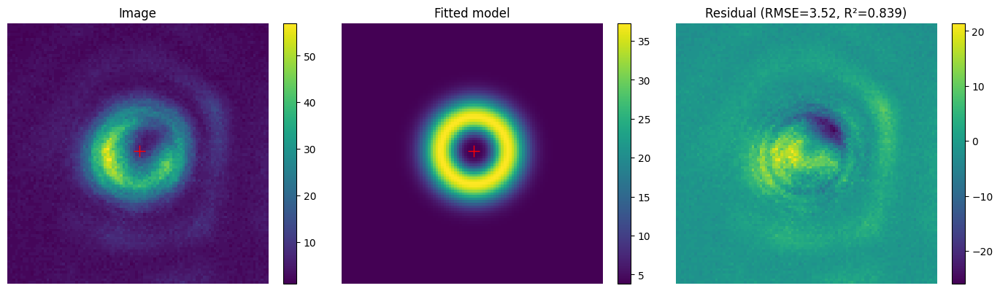

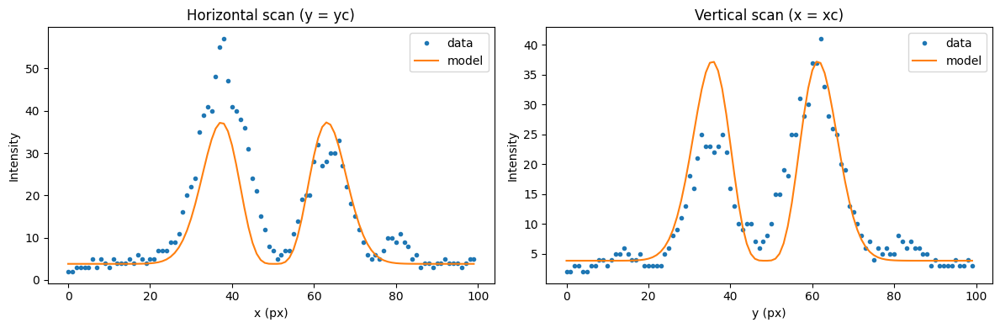

Params: {'A': 0.009258199035330391, 'w': 8.935561706741387, 'xc': 50.426447893618885, 'yc': 48.520293902605516, 'B': 4.518505968554046}
Uncertainties: {'A': 0.00010515051297739028, 'w': 0.018821714772451016, 'xc': 0.041431545310278886, 'yc': 0.041431545323684385, 'B': 0.04096846727759665}
RMSE: 3.7526844315329995 R^2: 0.8012374531046338


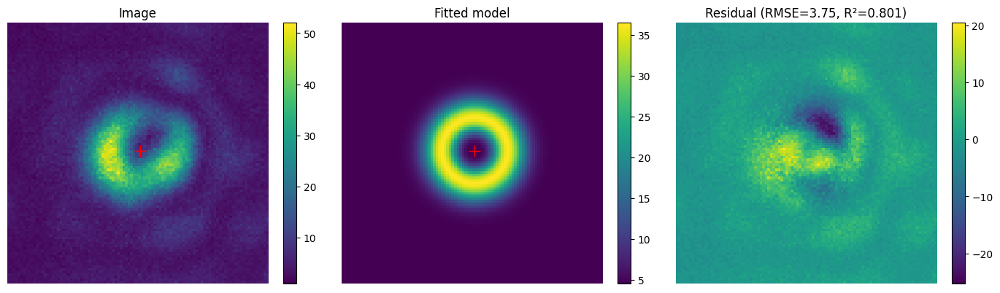

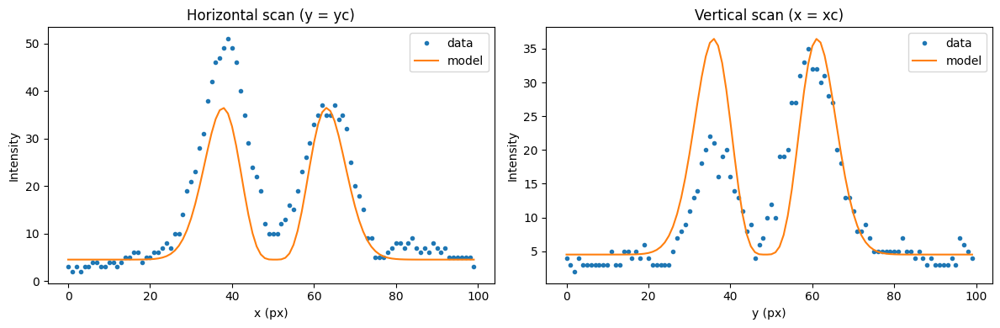

Params: {'A': 0.011160986766067152, 'w': 9.030999246844152, 'xc': 50.28128514876392, 'yc': 48.51717304169947, 'B': 5.958402543873998}
Uncertainties: {'A': 0.00011729227930436263, 'w': 0.017608700732023624, 'xc': 0.038746013895376116, 'yc': 0.03874601389771809, 'B': 0.048291547165431985}
RMSE: 4.414381006668266 R^2: 0.824335491525974


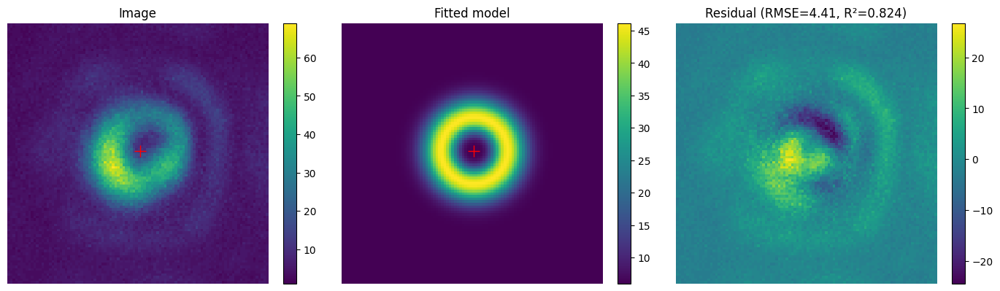

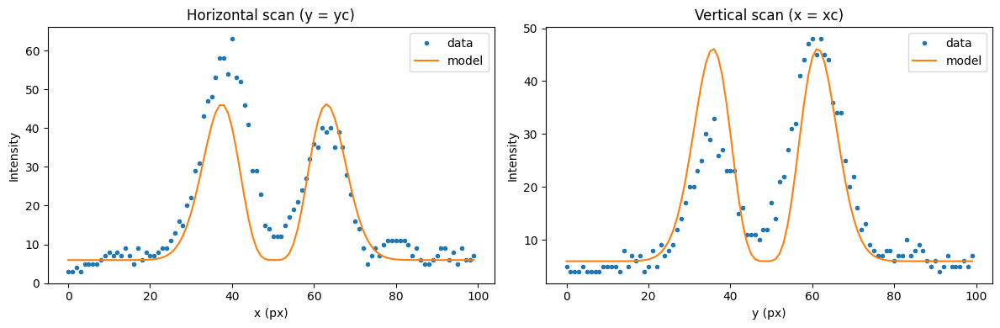

Params: {'A': 0.008615036309851927, 'w': 9.257525528826882, 'xc': 50.288483363089085, 'yc': 48.497778364743915, 'B': 5.848430456966447}
Uncertainties: {'A': 9.153598965756768e-05, 'w': 0.018267361463207257, 'xc': 0.04015633591212482, 'yc': 0.04015633591471646, 'B': 0.04287099236465623}
RMSE: 3.8993106091693095 R^2: 0.8199445541605692


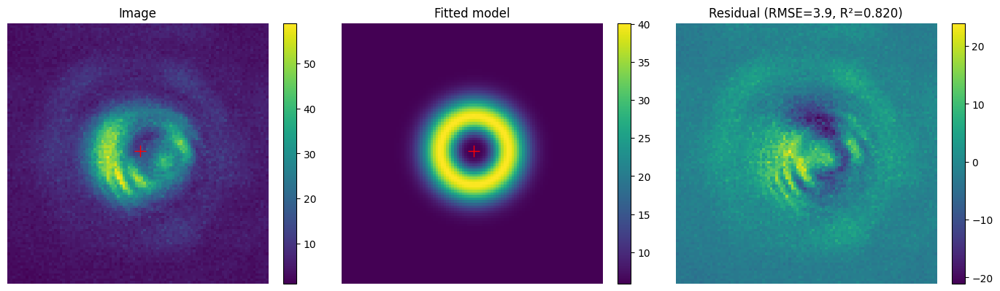

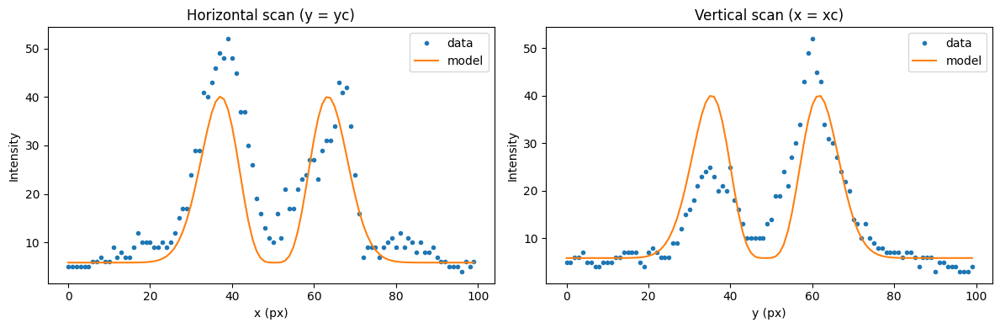

Params: {'A': 0.006920054118996162, 'w': 9.24993300654389, 'xc': 50.728855990228844, 'yc': 48.20181565836299, 'B': 4.278640737613107}
Uncertainties: {'A': 8.140835014808227e-05, 'w': 0.02020829924202611, 'xc': 0.04442448897837503, 'yc': 0.044424488977107435, 'B': 0.03796512579536148}
RMSE: 3.453689165737497 R^2: 0.7879453188260569


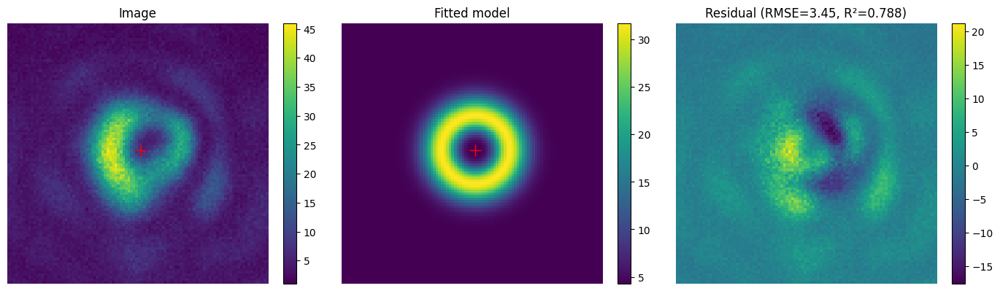

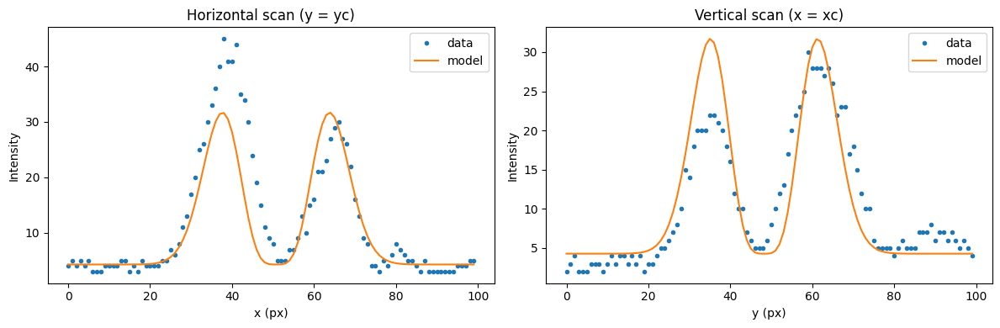

Params: {'A': 0.009104085319430827, 'w': 9.024846990673073, 'xc': 50.3193838542579, 'yc': 47.98316994783928, 'B': 5.571311241377906}
Uncertainties: {'A': 9.037180484849172e-05, 'w': 0.016620724933871362, 'xc': 0.03657302435946755, 'yc': 0.036573024360298106, 'B': 0.037076339647787726}
RMSE: 3.3896398097906353 R^2: 0.840276680161152


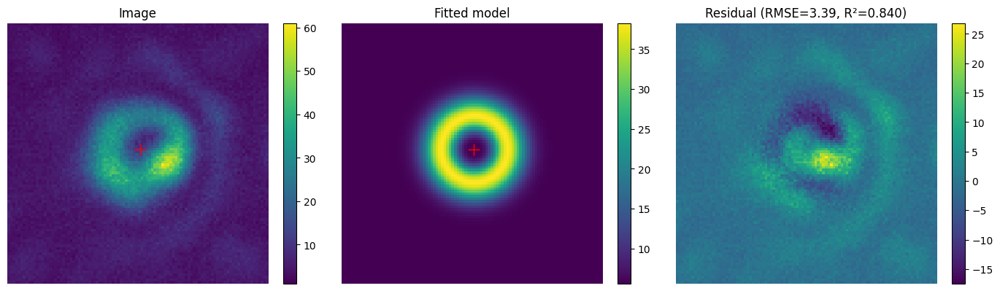

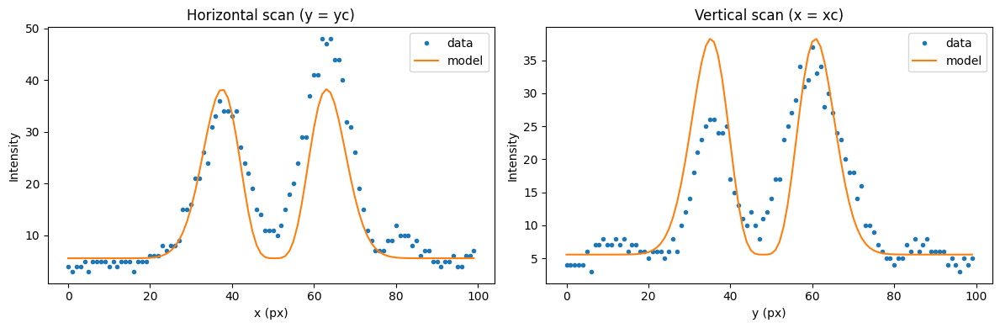

Params: {'A': 0.009989747095677064, 'w': 9.065427061492395, 'xc': 49.874430313052336, 'yc': 47.444762684748866, 'B': 6.843513720602194}
Uncertainties: {'A': 9.774821931315523e-05, 'w': 0.016460013901408287, 'xc': 0.03621320974063228, 'yc': 0.03621320973501442, 'B': 0.04104861114582491}
RMSE: 3.749484415671866 R^2: 0.8439095259862612


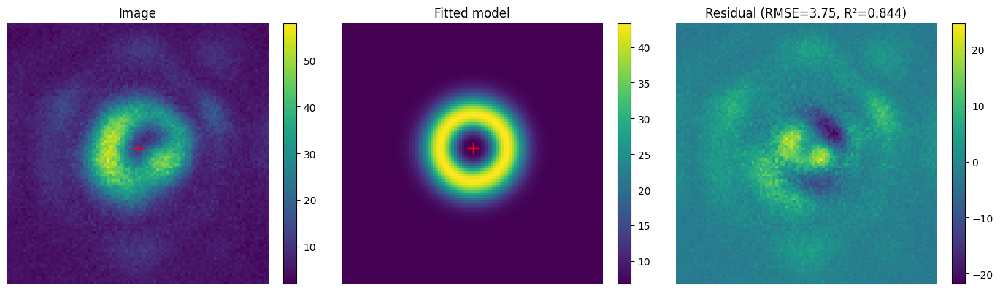

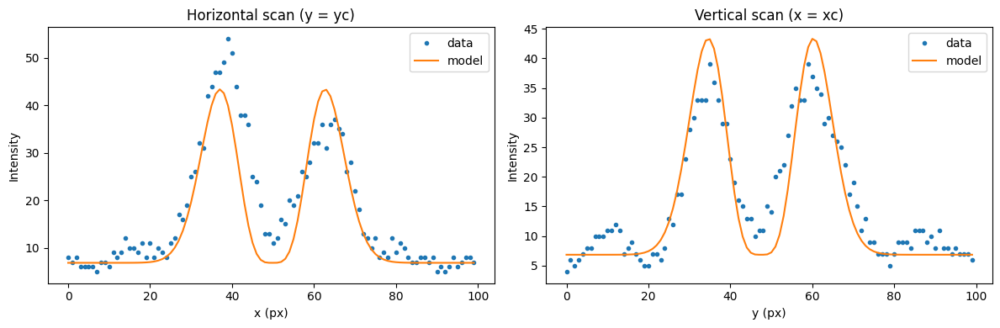

Params: {'A': 0.01000150120918707, 'w': 9.344582824894552, 'xc': 49.61529071365865, 'yc': 48.38558214888892, 'B': 7.13817580832592}
Uncertainties: {'A': 0.0001099072053550547, 'w': 0.019078044879249655, 'xc': 0.04192231741054734, 'yc': 0.04192231740741548, 'B': 0.05404789114106511}
RMSE: 4.906221053902959 R^2: 0.8092960114744594


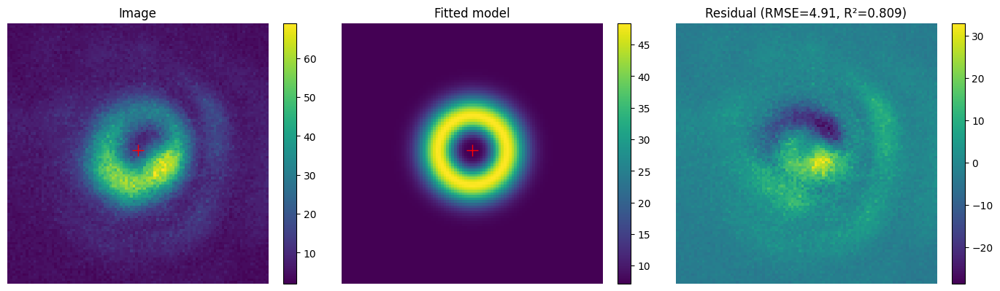

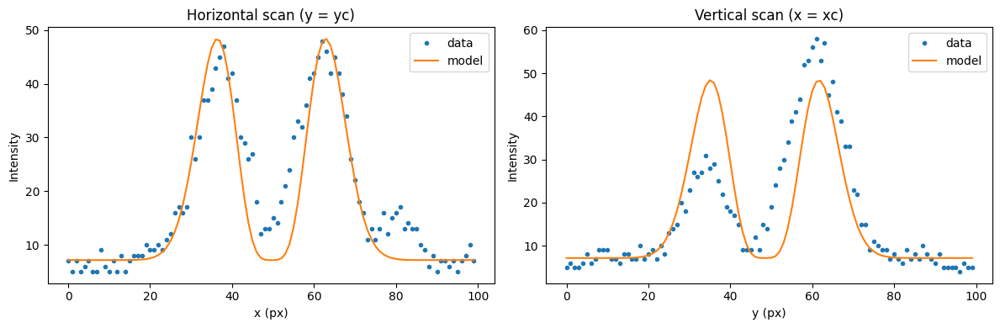

Params: {'A': 0.009385121900332225, 'w': 8.95223711456018, 'xc': 49.40616383630416, 'yc': 48.85185211430757, 'B': 4.261146703804931}
Uncertainties: {'A': 0.00012930390564585818, 'w': 0.022876291260678968, 'xc': 0.050353271546589445, 'yc': 0.0503532715461001, 'B': 0.050869064156604436}
RMSE: 4.657907766401994 R^2: 0.7324632343767076


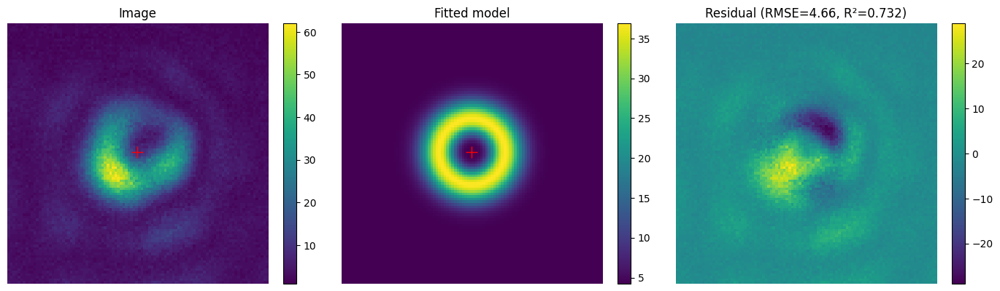

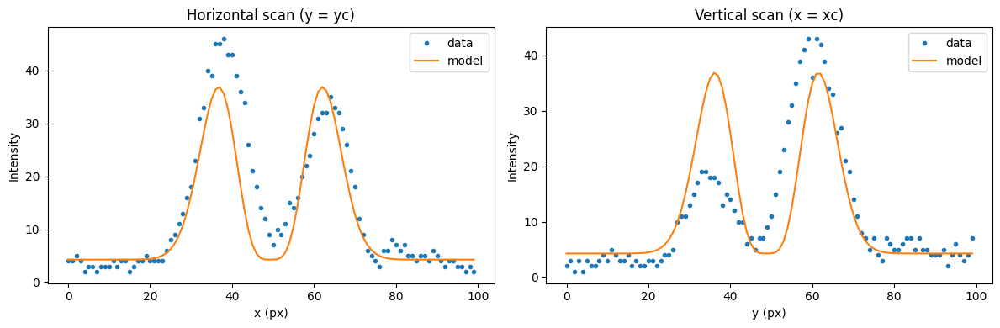

Params: {'A': 0.010372464665367424, 'w': 9.025819994844714, 'xc': 49.563293409505434, 'yc': 47.874214872261014, 'B': 6.521538624666814}
Uncertainties: {'A': 0.00011150338659791119, 'w': 0.018001471579409005, 'xc': 0.03961112281516531, 'yc': 0.03961112282951368, 'B': 0.04577150858715088}
RMSE: 4.184492138674361 R^2: 0.8177044408069789


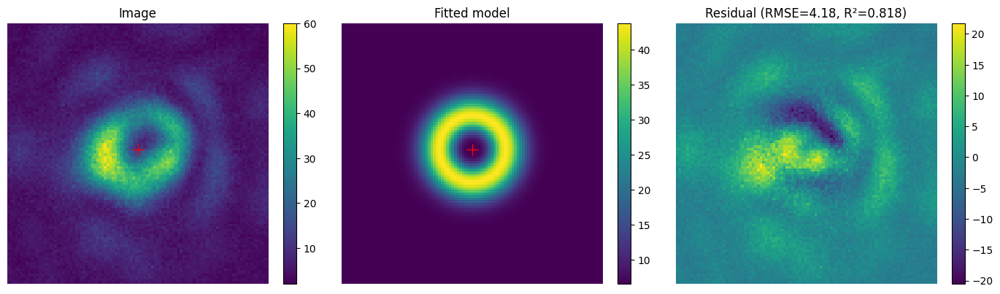

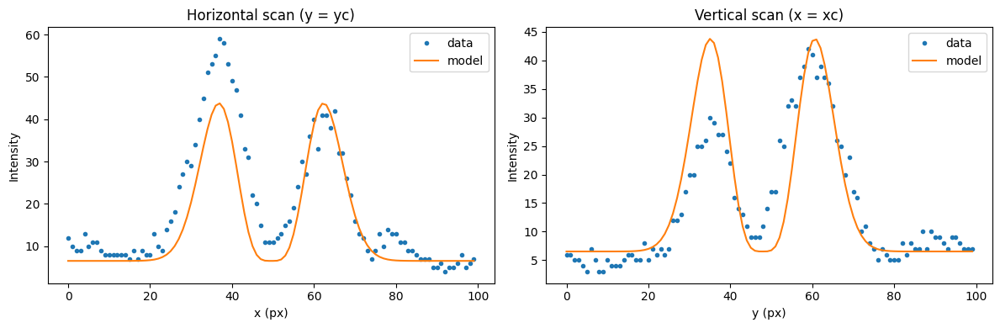

Params: {'A': 0.010070327975536624, 'w': 9.414420999994995, 'xc': 49.18431082462052, 'yc': 48.29601849909251, 'B': 7.0396017306331915}
Uncertainties: {'A': 0.00011464962897618039, 'w': 0.01991918073687775, 'xc': 0.04375695023071788, 'yc': 0.043756950226122845, 'B': 0.05861228311984355}
RMSE: 5.3120492044970975 R^2: 0.7977184489524077


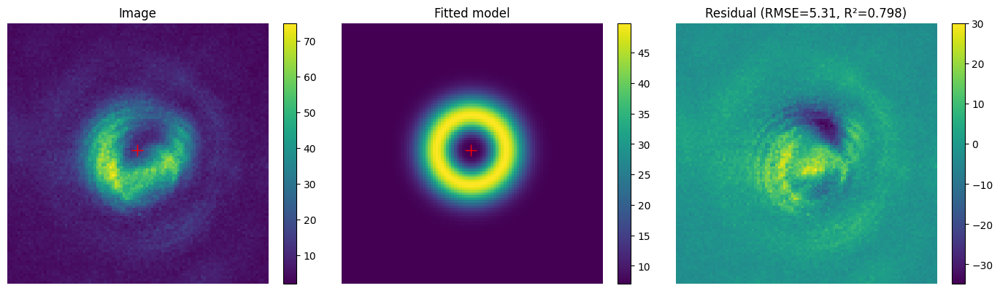

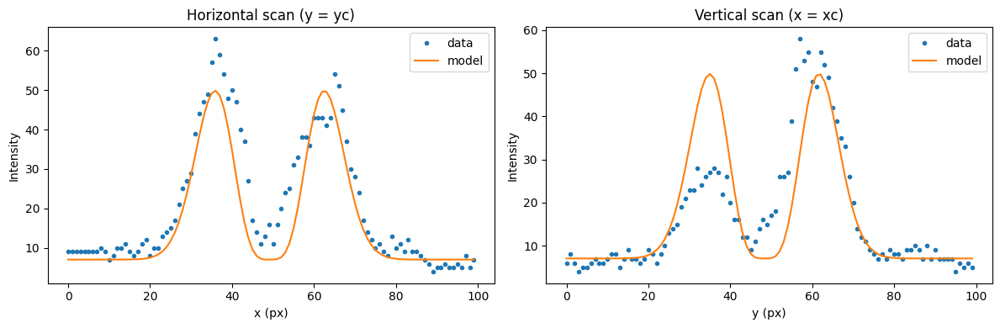

Params: {'A': 0.00857876360142336, 'w': 9.130263234525541, 'xc': 49.21261555648776, 'yc': 48.323459735864716, 'B': 6.497686229739293}
Uncertainties: {'A': 0.00010095189207819853, 'w': 0.019942527424441355, 'xc': 0.04386291119441091, 'yc': 0.04386291119445762, 'B': 0.0439943737049217}
RMSE: 4.012844359656028 R^2: 0.7885616931377847


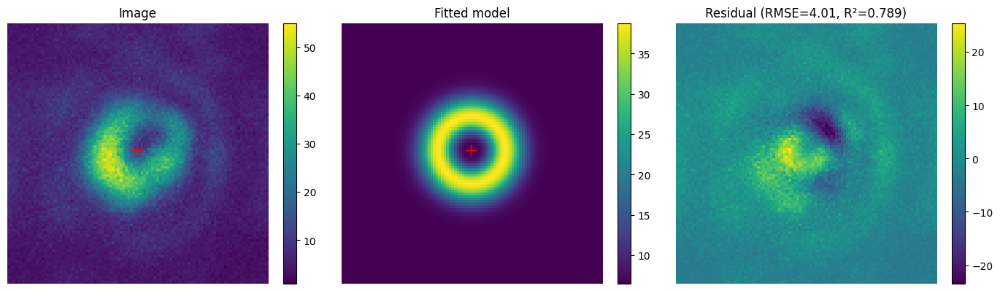

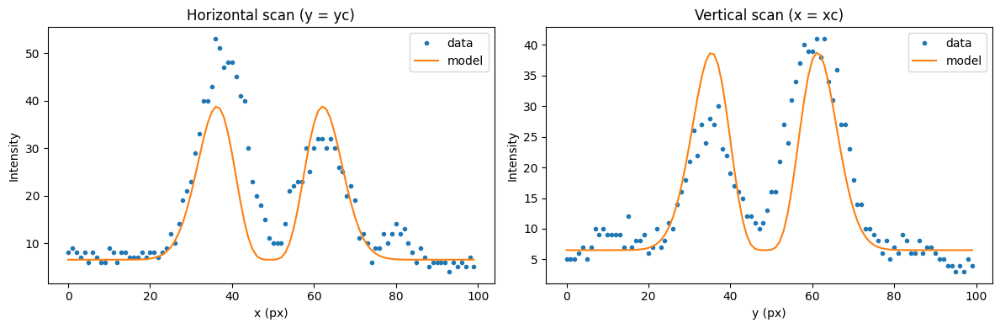

Params: {'A': 0.009555068570455823, 'w': 9.10048293999099, 'xc': 49.17276570461599, 'yc': 47.97569531871248, 'B': 4.579339295984948}
Uncertainties: {'A': 8.940191725146708e-05, 'w': 0.01580263465269795, 'xc': 0.03476176786772988, 'yc': 0.03476176787081364, 'B': 0.03830457367082302}
RMSE: 3.4961526761069233 R^2: 0.8551901078272168


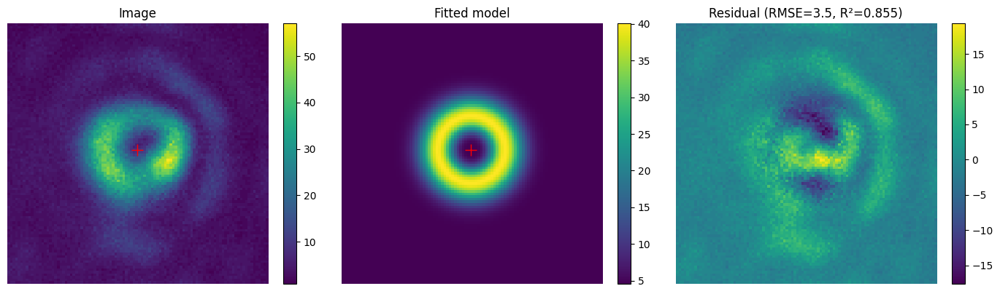

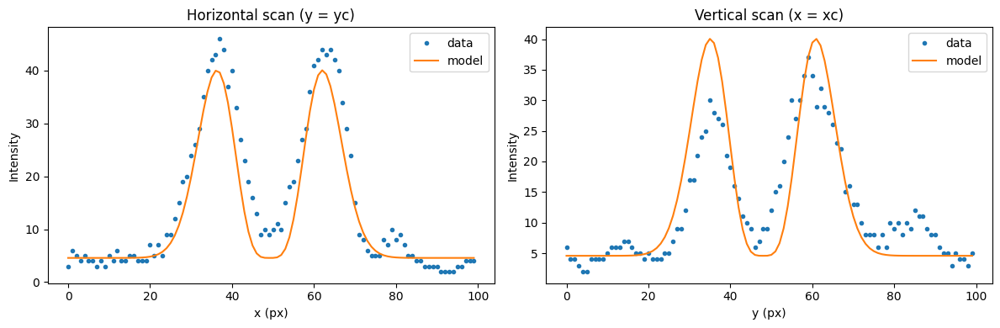

Params: {'A': 0.008287528696975723, 'w': 9.174919163507434, 'xc': 48.6081026164584, 'yc': 47.87794299268141, 'B': 5.514478833492506}
Uncertainties: {'A': 9.791131014872822e-05, 'w': 0.02012335604972569, 'xc': 0.04425215798384509, 'yc': 0.04425215799091548, 'B': 0.04376626203524089}
RMSE: 3.988094613478917 R^2: 0.786972526650912


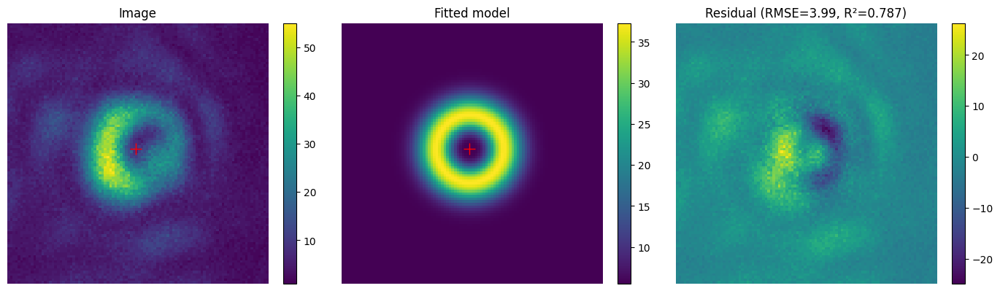

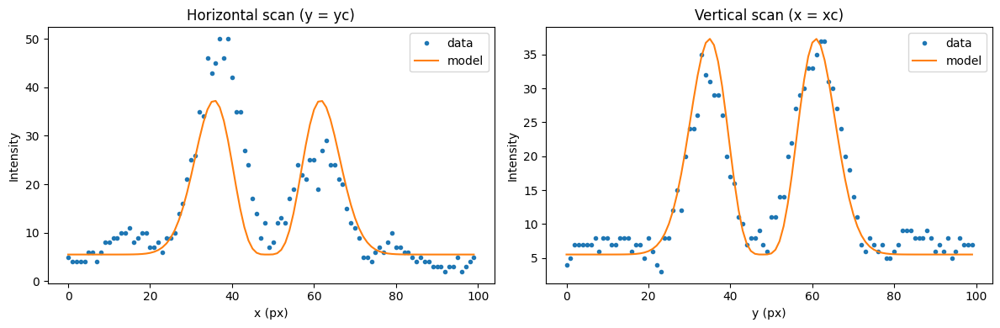

Params: {'A': 0.009459535438082782, 'w': 8.973154405211687, 'xc': 49.063543744332016, 'yc': 47.79724863184236, 'B': 6.088537619248678}
Uncertainties: {'A': 8.945189099155217e-05, 'w': 0.015739276789209423, 'xc': 0.03464090657410808, 'yc': 0.034640906571407476, 'B': 0.035620063477350486}
RMSE: 3.2601425401093334 R^2: 0.8531037371298373


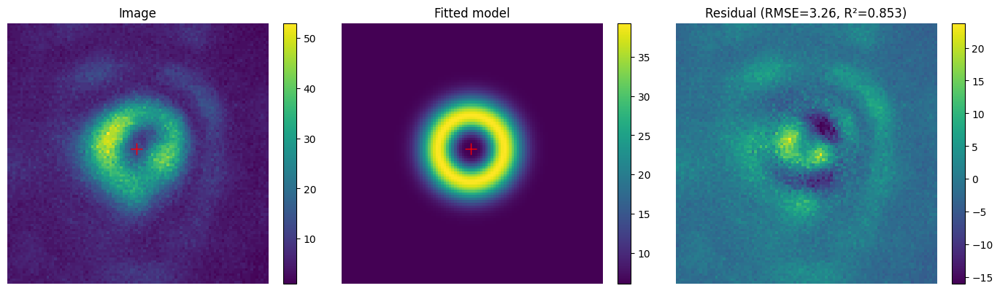

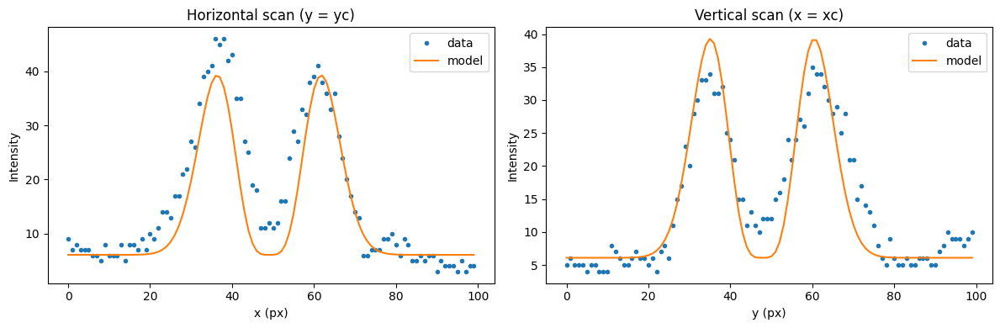

Params: {'A': 0.007617111740219206, 'w': 9.08264195410592, 'xc': 48.817232955609384, 'yc': 48.8767480283969, 'B': 5.255650377660347}
Uncertainties: {'A': 9.08644453062556e-05, 'w': 0.020106432485970563, 'xc': 0.04423237290351498, 'yc': 0.044232372910141024, 'B': 0.03853600475273061}
RMSE: 3.5186519400574348 R^2: 0.7842708295102496


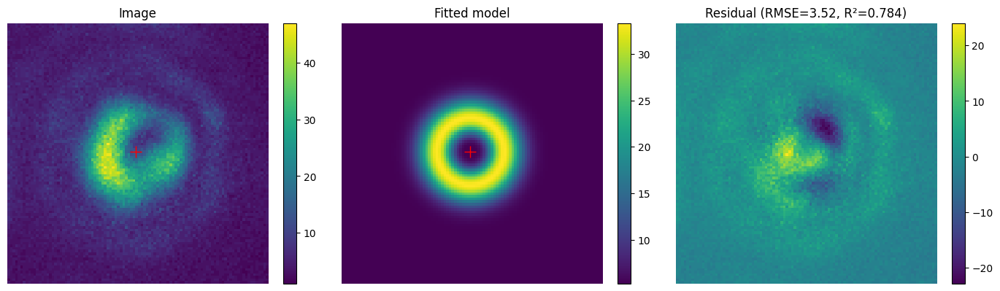

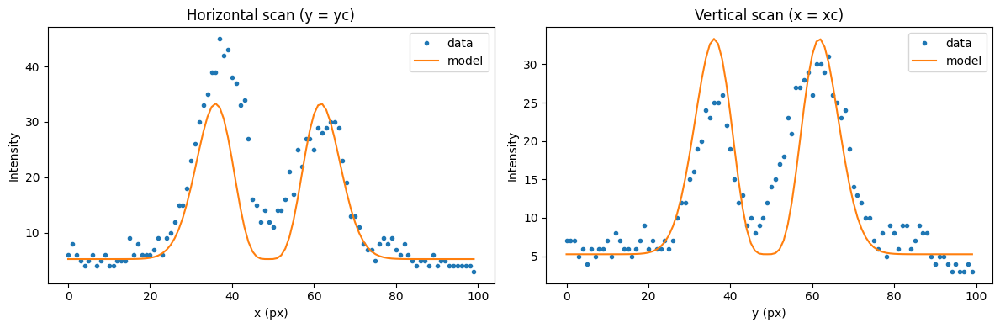

writing phase
Params: {'A': 0.008612617197121865, 'w': 9.13791889378929, 'xc': 50.36481327568897, 'yc': 48.54786132005314, 'B': 3.9082598215124067}
Uncertainties: {'A': 9.328033571751323e-05, 'w': 0.018370611205339813, 'xc': 0.04040421242675943, 'yc': 0.04040421242727779, 'B': 0.040828755818304495}
RMSE: 3.7234708124988742 R^2: 0.8148671457204032


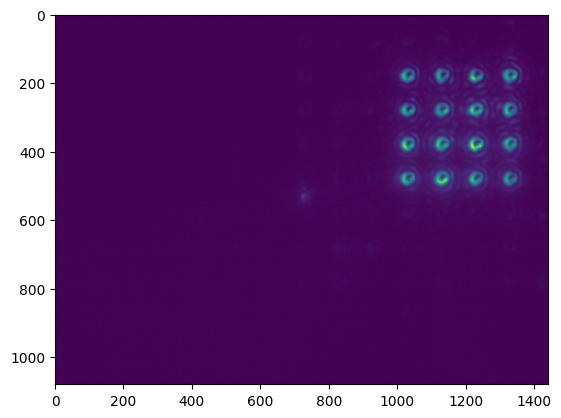

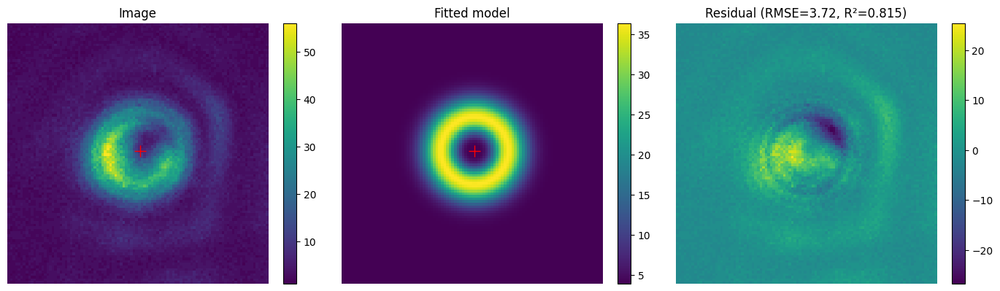

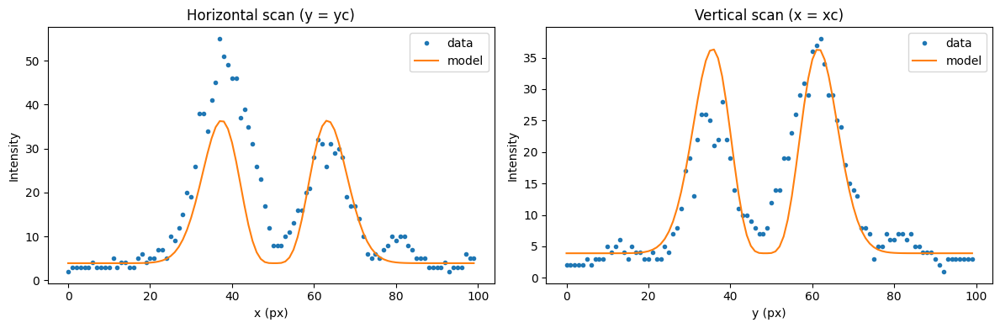

Params: {'A': 0.008932762580859411, 'w': 8.958844013642983, 'xc': 50.616676154134325, 'yc': 48.55761380891222, 'B': 4.618432963089232}
Uncertainties: {'A': 0.00010909461020211691, 'w': 0.02029381297734513, 'xc': 0.04466772869389704, 'yc': 0.044667728682082596, 'B': 0.04308330291160668}
RMSE: 3.944432495509568 R^2: 0.7769581713423674


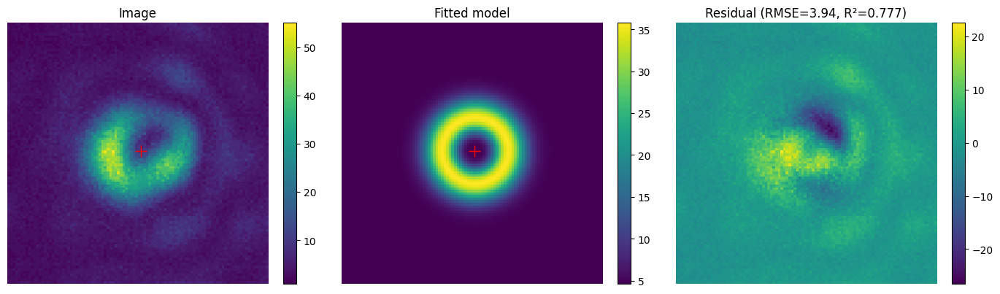

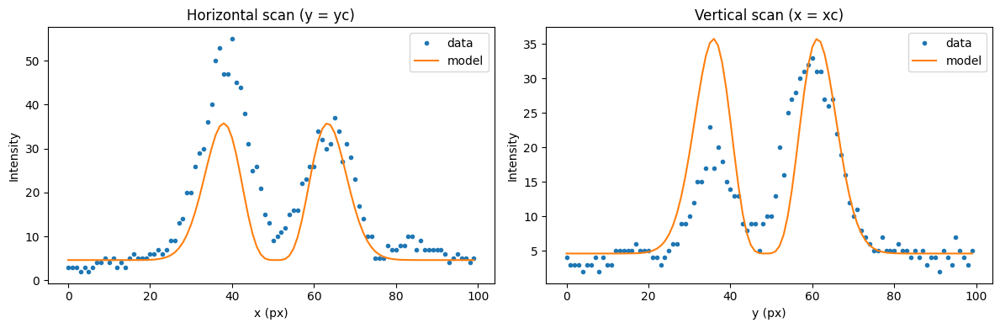

Params: {'A': 0.010684855772694008, 'w': 9.058582361481474, 'xc': 50.44829167120835, 'yc': 48.56970903765583, 'B': 6.089246279110755}
Uncertainties: {'A': 0.00012294480698447013, 'w': 0.019340905094877247, 'xc': 0.04255260515210139, 'yc': 0.04255260515444335, 'B': 0.05142742461472413}
RMSE: 4.698213348541799 R^2: 0.7963613014987941


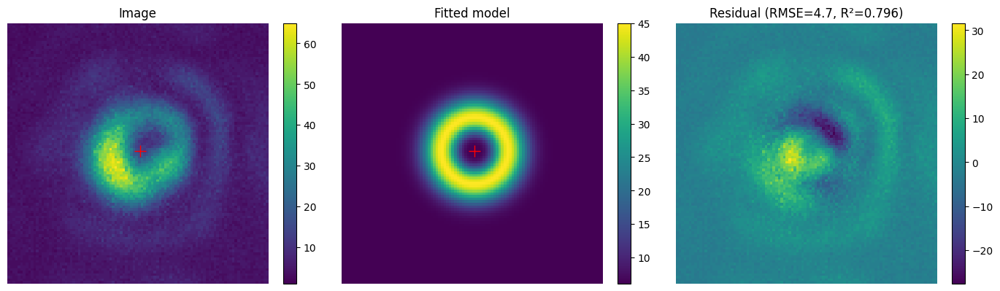

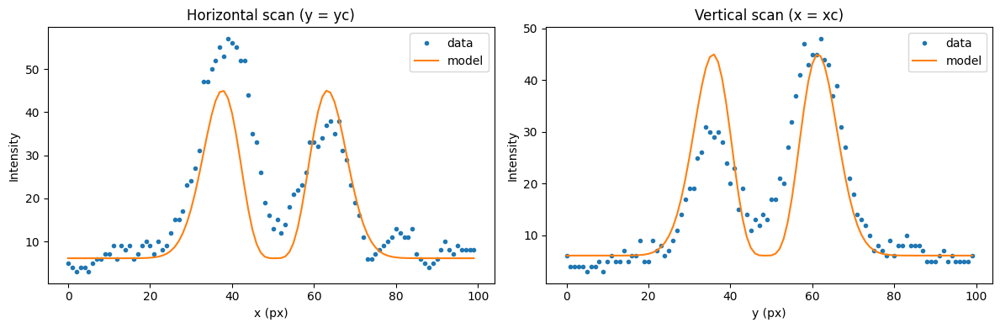

Params: {'A': 0.008297688297250715, 'w': 9.291572105643317, 'xc': 50.50160853407359, 'yc': 48.496199349016834, 'B': 5.932857049696981}
Uncertainties: {'A': 9.375093388489865e-05, 'w': 0.01949928748657201, 'xc': 0.042858017575023916, 'yc': 0.042858017566345774, 'B': 0.04475608190487658}
RMSE: 4.067644298932107 R^2: 0.8008878194154556


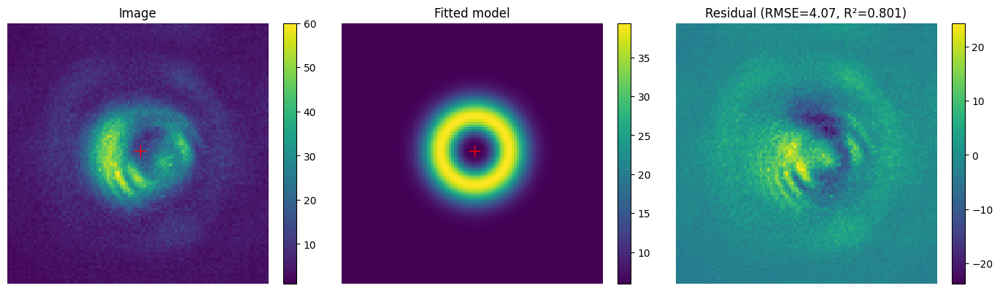

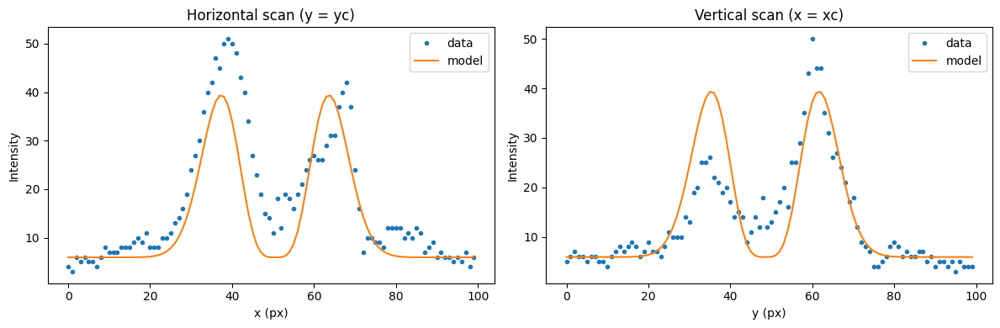

Params: {'A': 0.006532315560254242, 'w': 9.306630279962853, 'xc': 50.99137064584453, 'yc': 48.288803175369424, 'B': 4.358630329902202}
Uncertainties: {'A': 8.320519518103765e-05, 'w': 0.022019915687029695, 'xc': 0.048394960491475146, 'yc': 0.048394960492143396, 'B': 0.04005817917651555}
RMSE: 3.639436180292644 R^2: 0.7597914503741682


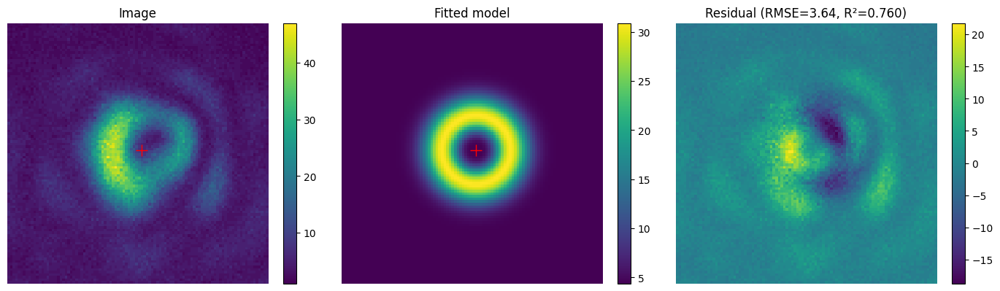

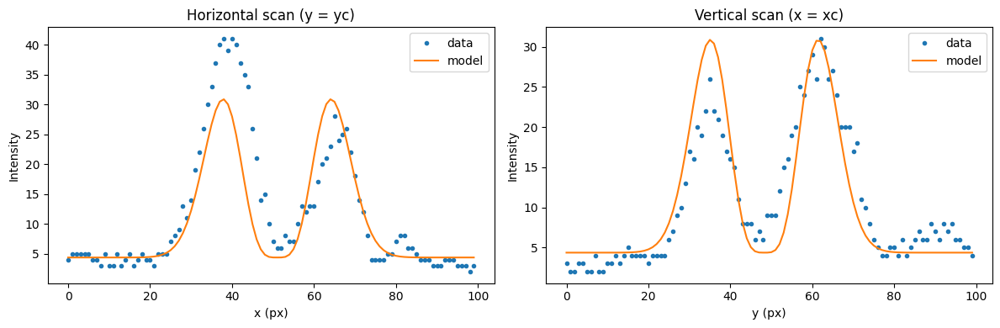

Params: {'A': 0.008642684906536805, 'w': 9.075636356314734, 'xc': 50.574514346217036, 'yc': 47.946876142466174, 'B': 5.674672587739692}
Uncertainties: {'A': 8.869772501072246e-05, 'w': 0.017284116613991665, 'xc': 0.03802465463551255, 'yc': 0.03802465463080531, 'B': 0.03746649566864766}
RMSE: 3.4215214746499614 R^2: 0.8308803094187023


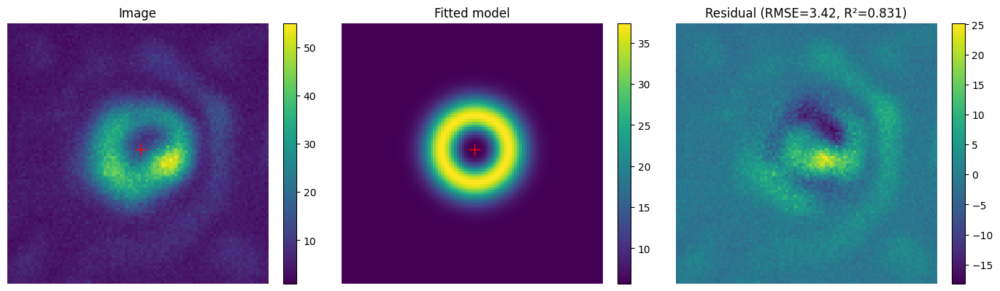

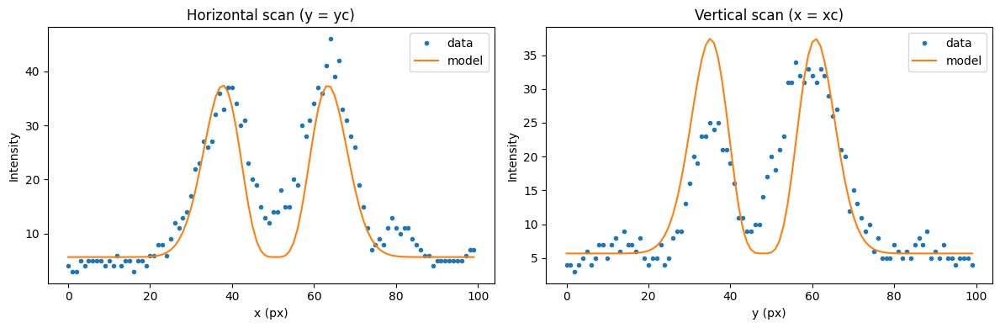

Params: {'A': 0.009704088009281927, 'w': 9.082489329821271, 'xc': 50.08973222882926, 'yc': 47.51285955580496, 'B': 6.939138314819945}
Uncertainties: {'A': 0.0001027169590782403, 'w': 0.01784067231066353, 'xc': 0.0392479262086659, 'yc': 0.03924792621471284, 'B': 0.0435589016273605}
RMSE: 3.9772967332388975 R^2: 0.821979840570318


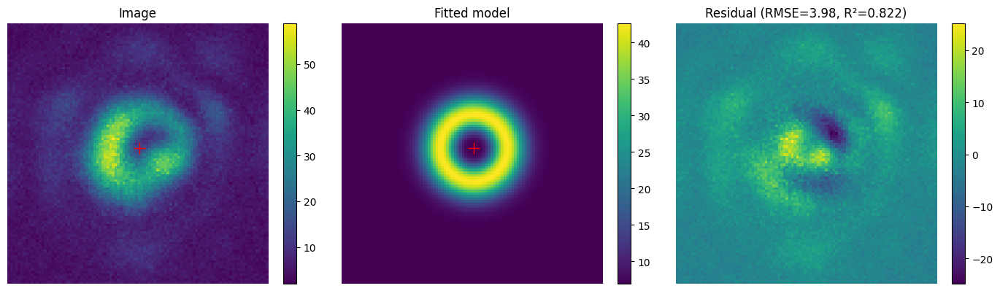

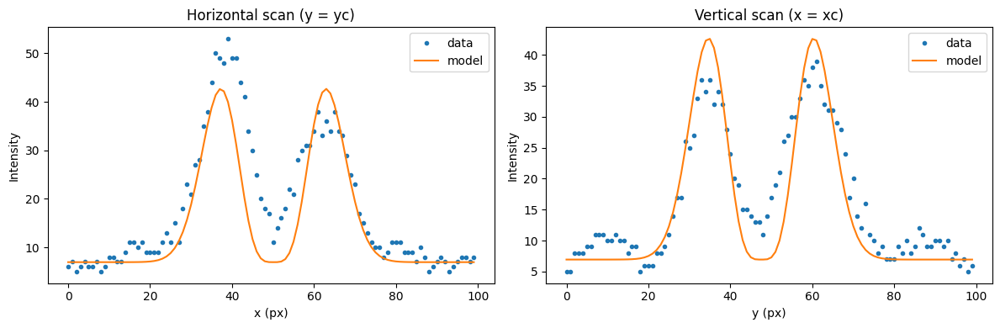

Params: {'A': 0.009618467279517992, 'w': 9.370836245247022, 'xc': 49.750552561599704, 'yc': 48.38969469326961, 'B': 7.237609596361647}
Uncertainties: {'A': 0.00011075978508717633, 'w': 0.020050186292181353, 'xc': 0.044053353294521584, 'yc': 0.04405335330103395, 'B': 0.055269712852466804}
RMSE: 5.0141255706404335 R^2: 0.794280369199222


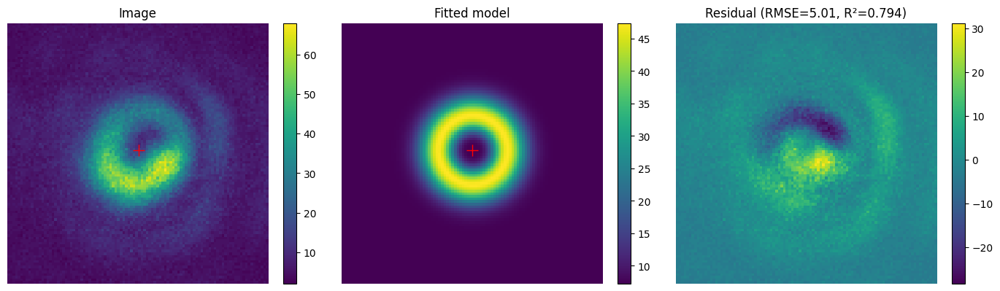

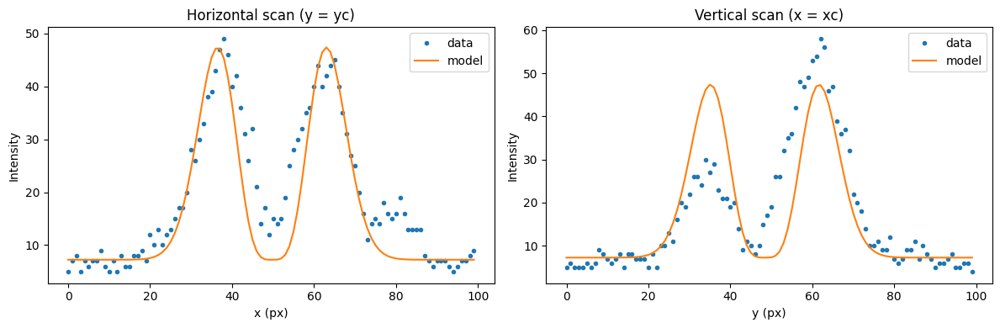

Params: {'A': 0.009246224919247264, 'w': 8.942621225416996, 'xc': 49.547283033488206, 'yc': 48.824236016158466, 'B': 4.379790059026743}
Uncertainties: {'A': 0.00013384361640000564, 'w': 0.024008394779968825, 'xc': 0.05284725522914674, 'yc': 0.052847255239090056, 'B': 0.05236203588886239}
RMSE: 4.7956027596459165 R^2: 0.7127249251689638


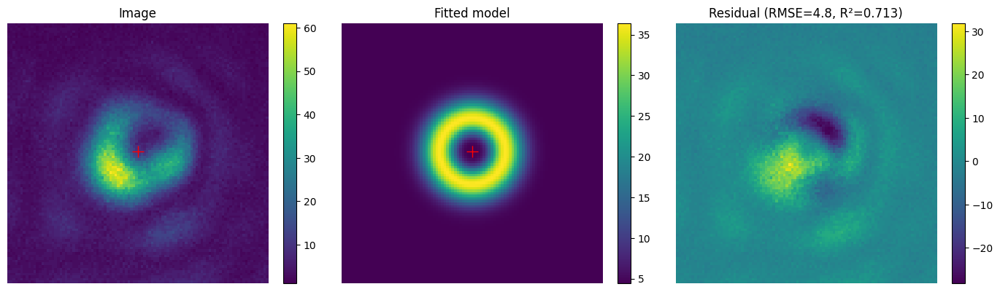

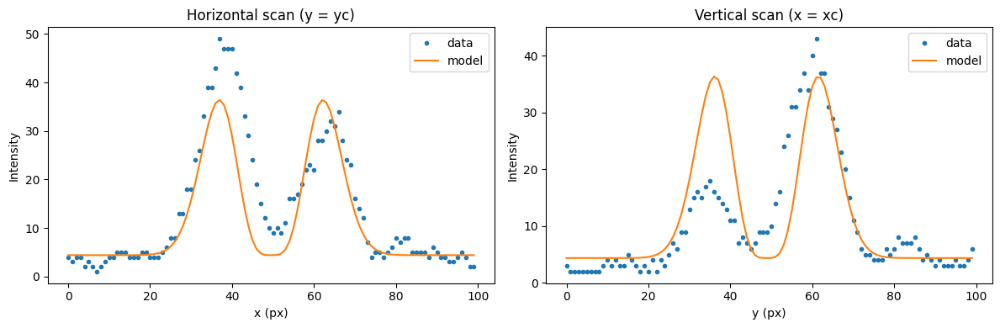

Params: {'A': 0.009952039426558036, 'w': 9.049792607084548, 'xc': 49.68490385431474, 'yc': 47.930472448365855, 'B': 6.660723922059468}
Uncertainties: {'A': 0.00011749939903159339, 'w': 0.019825362718943272, 'xc': 0.04362009178313233, 'yc': 0.043620091786914186, 'B': 0.04890226456763975}
RMSE: 4.468380386946154 R^2: 0.7879344753902979


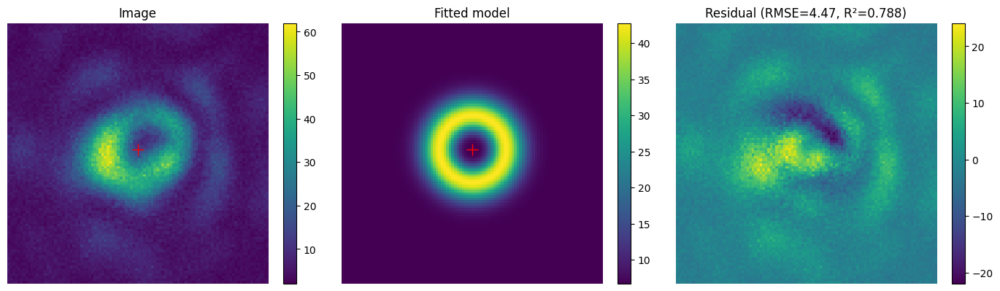

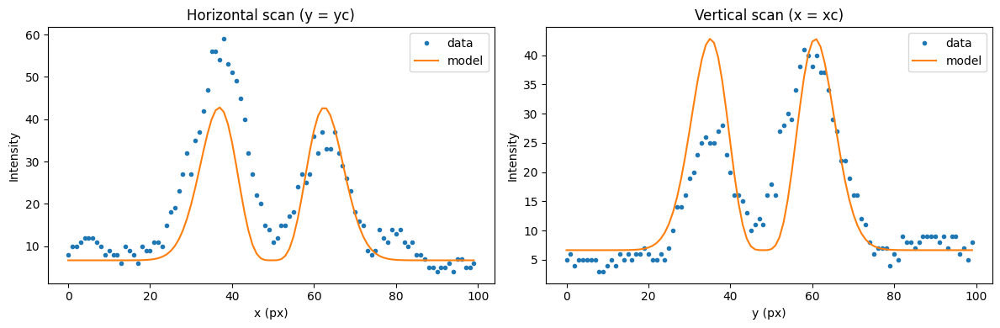

Params: {'A': 0.00981020665952254, 'w': 9.437253572562877, 'xc': 49.31078682416794, 'yc': 48.30942408584072, 'B': 7.1579654079977}
Uncertainties: {'A': 0.00011699957688278852, 'w': 0.020919214832161415, 'xc': 0.04594900910893578, 'yc': 0.04594900910292404, 'B': 0.06057439982363548}
RMSE: 5.4869849796941415 R^2: 0.7821651795981265


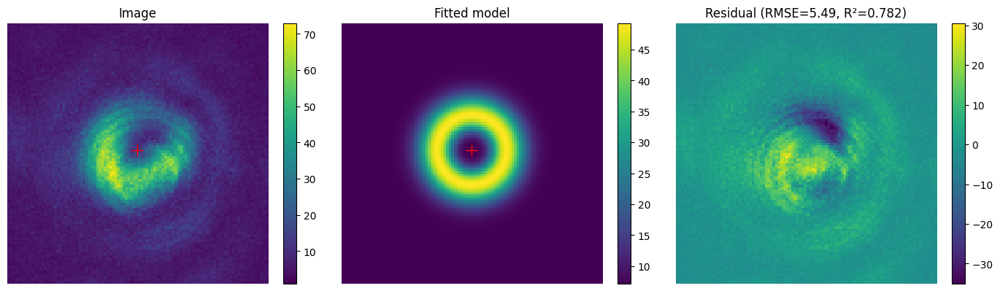

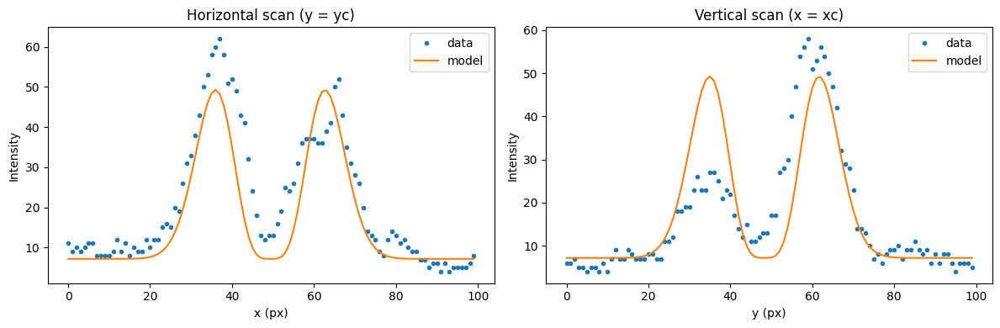

Params: {'A': 0.008622618861659322, 'w': 9.090424705946964, 'xc': 49.231230335327865, 'yc': 48.45961806228349, 'B': 6.617698227943472}
Uncertainties: {'A': 0.00010816291945118778, 'w': 0.021162008349394454, 'xc': 0.04655301100405328, 'yc': 0.04655301101442667, 'B': 0.04607709065642709}
RMSE: 4.206497440994402 R^2: 0.7667230253669565


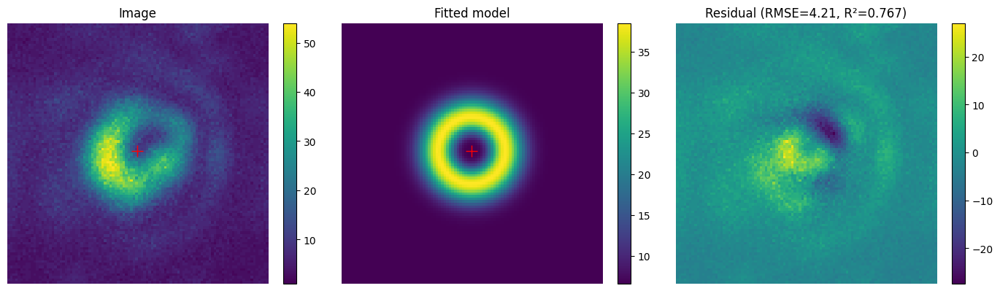

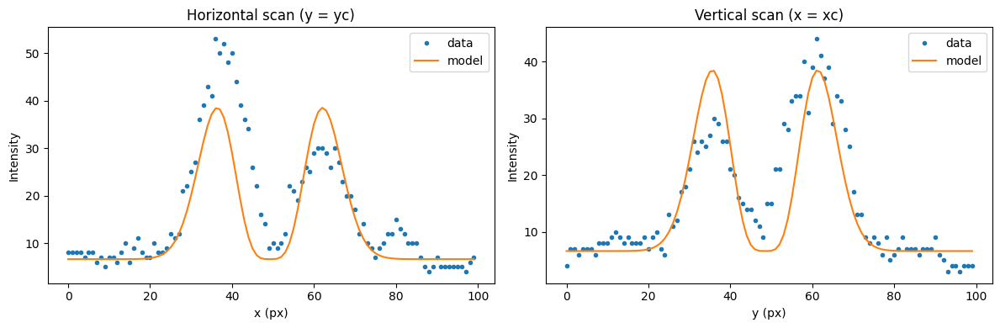

Params: {'A': 0.009193774466712306, 'w': 9.11576176701268, 'xc': 49.37865489855102, 'yc': 48.03763282027084, 'B': 4.714397035923404}
Uncertainties: {'A': 9.182791338722076e-05, 'w': 0.016898731416872037, 'xc': 0.03717048499860794, 'yc': 0.03717048499495822, 'B': 0.03968871086627375}
RMSE: 3.6212700084769214 R^2: 0.83817638605537


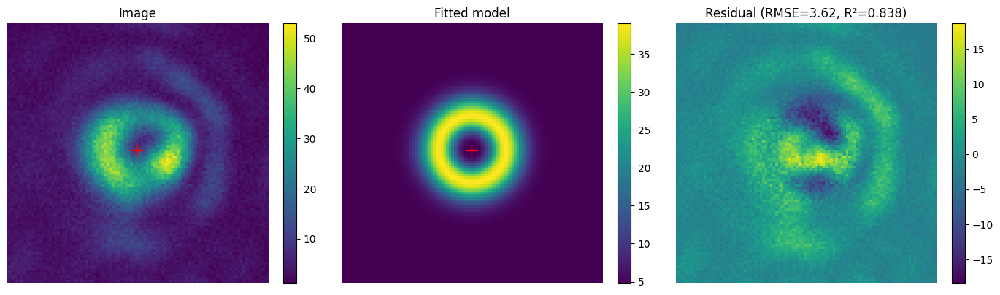

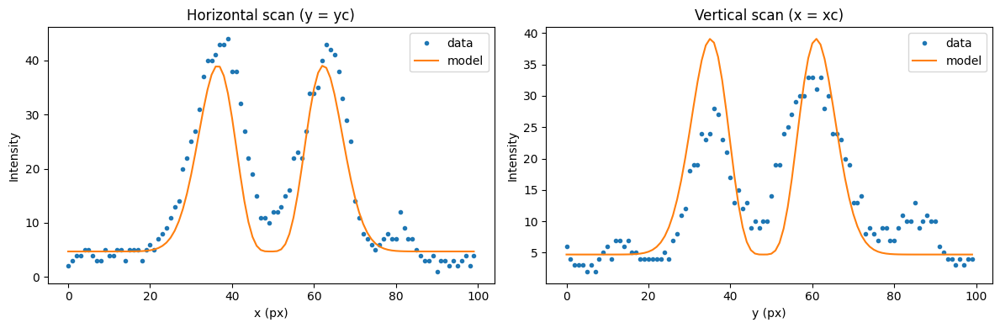

Params: {'A': 0.008248015311757624, 'w': 9.153072835129908, 'xc': 48.57872904662088, 'yc': 47.864659823292236, 'B': 5.64049036230626}
Uncertainties: {'A': 0.00010274683836577042, 'w': 0.02116583840870016, 'xc': 0.04654899594199973, 'yc': 0.04654899593911928, 'B': 0.04536157144612619}
RMSE: 4.135465636889901 R^2: 0.7688061774535053


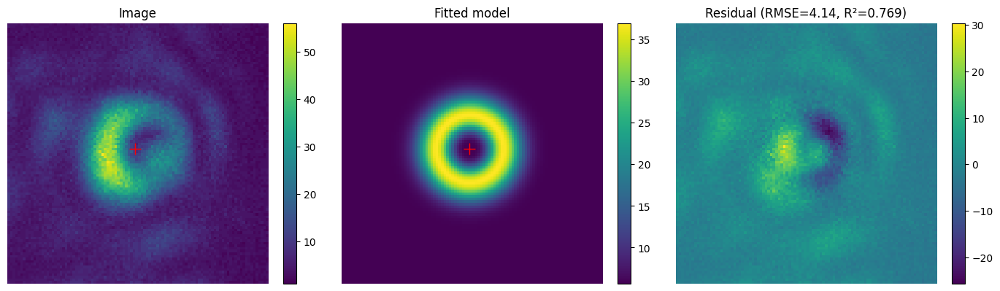

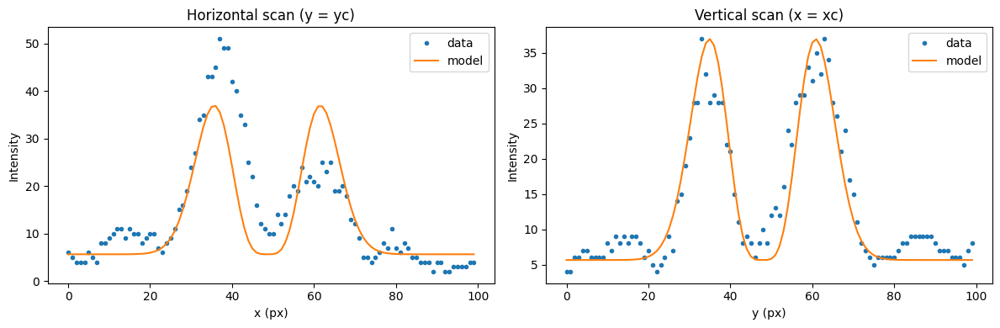

Params: {'A': 0.009068492378070987, 'w': 8.994134618009797, 'xc': 49.2801968516005, 'yc': 47.87196490201931, 'B': 6.2026227255598085}
Uncertainties: {'A': 9.265001987020774e-05, 'w': 0.017046200217799873, 'xc': 0.03751407124443672, 'yc': 0.037514071241208403, 'B': 0.037343786539164536}
RMSE: 3.4163612914136645 R^2: 0.8325395086823474


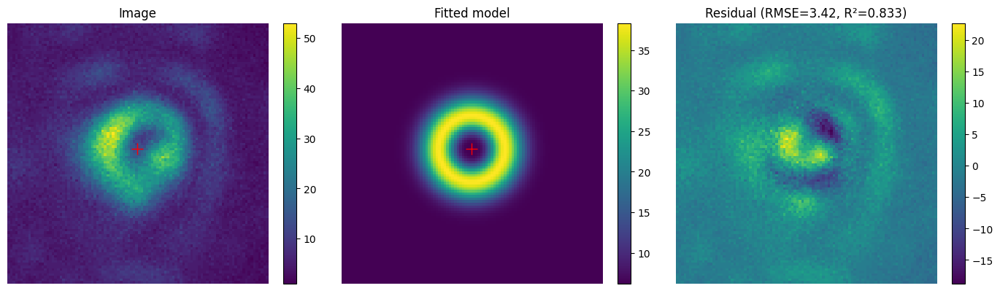

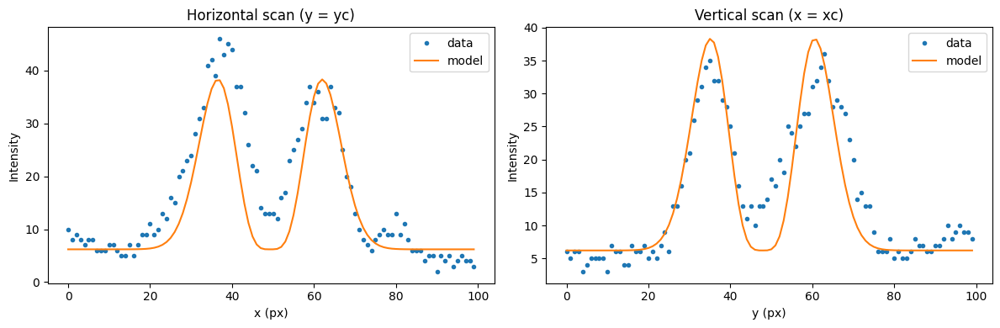

Params: {'A': 0.007460264462651198, 'w': 9.069475226883261, 'xc': 48.86164559906972, 'yc': 49.02638241254983, 'B': 5.353582540073689}
Uncertainties: {'A': 9.51450878513467e-05, 'w': 0.021463932748277646, 'xc': 0.04722138253280932, 'yc': 0.04722138253137471, 'B': 0.04004827727458831}
RMSE: 3.65778794329038 R^2: 0.7608807098661525


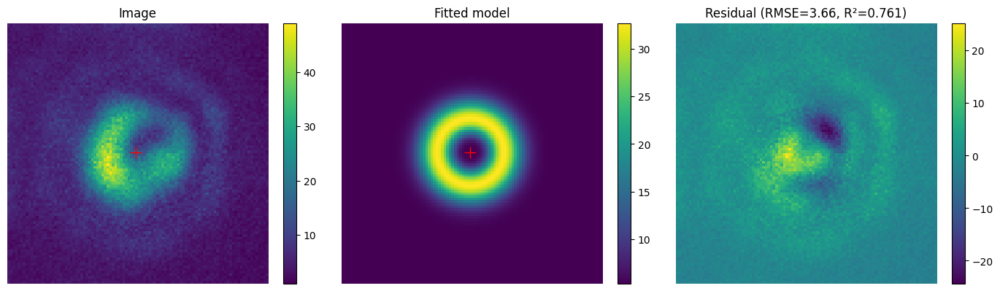

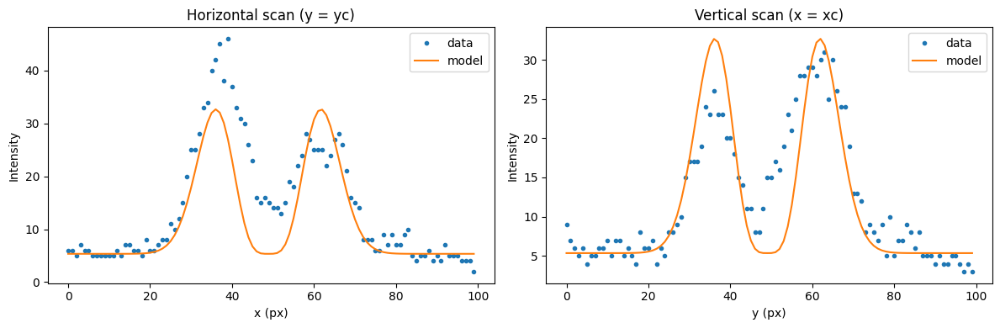

writing phase
Params: {'A': 0.008243767045913251, 'w': 9.163369444728957, 'xc': 50.13610051291413, 'yc': 48.654535449365035, 'B': 3.99544384467007}
Uncertainties: {'A': 9.678387540943164e-05, 'w': 0.01997106618886732, 'xc': 0.043919449177972573, 'yc': 0.04391944918875691, 'B': 0.0429796691880491}
RMSE: 3.9174219228843192 R^2: 0.7891417361280082


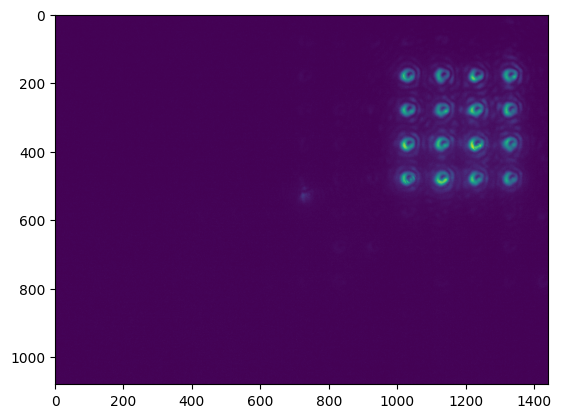

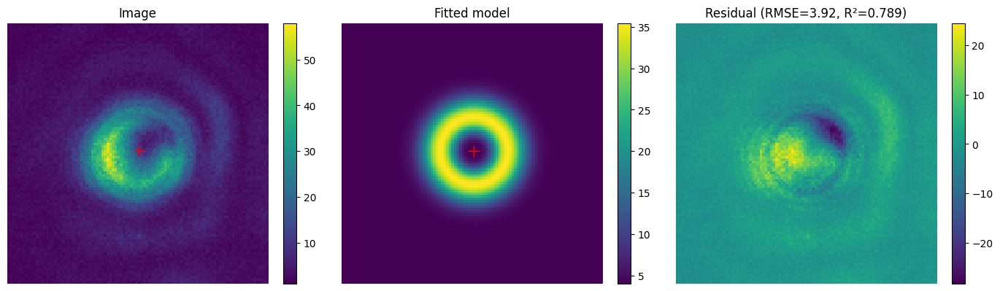

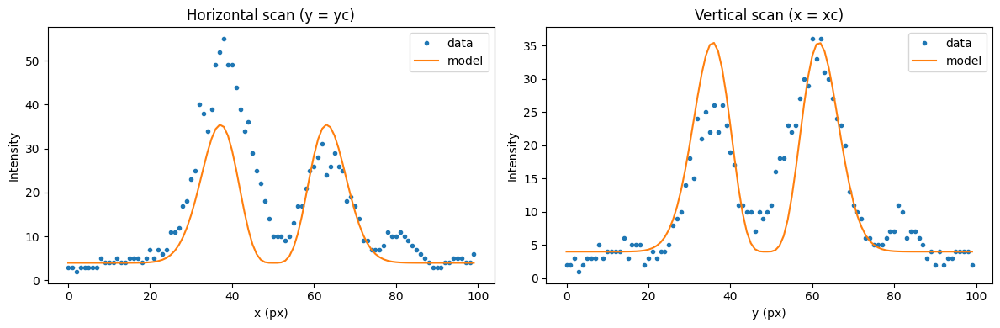

Params: {'A': 0.008478134204322998, 'w': 8.979130688292223, 'xc': 50.40940172267159, 'yc': 48.6560139384545, 'B': 4.7290896616037}
Uncertainties: {'A': 0.000111392590565664, 'w': 0.021883712167414904, 'xc': 0.048163129757150175, 'yc': 0.048163129760859284, 'B': 0.04451056661493231}
RMSE: 4.073325587703055 R^2: 0.7504776219511967


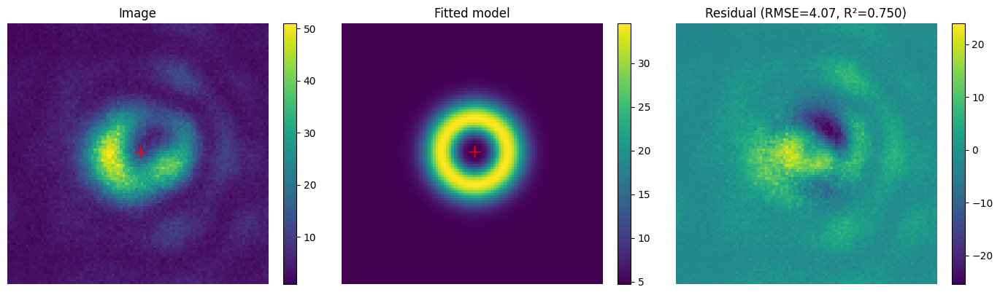

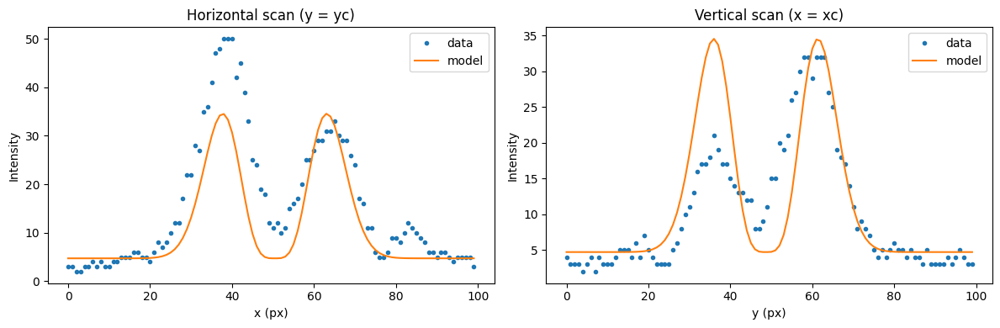

Params: {'A': 0.010314873479637115, 'w': 9.064968521833798, 'xc': 50.28145116791018, 'yc': 48.640846956749044, 'B': 6.2256187173946}
Uncertainties: {'A': 0.00012946301328994178, 'w': 0.02111226531099818, 'xc': 0.04644858593494075, 'yc': 0.04644858594191071, 'B': 0.05435270188743741}
RMSE: 4.964763565470004 R^2: 0.7666838926129629


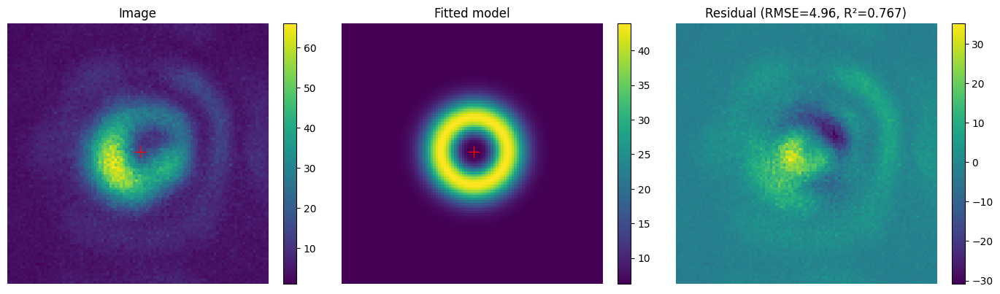

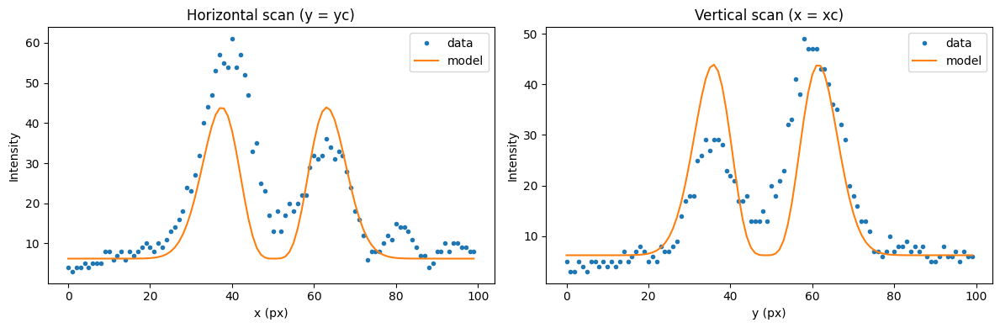

Params: {'A': 0.007902006978899031, 'w': 9.338197546944045, 'xc': 50.37059894682598, 'yc': 48.54072059549877, 'B': 5.982628671732766}
Uncertainties: {'A': 9.545710945868367e-05, 'w': 0.02095726343649, 'xc': 0.046053041565281866, 'yc': 0.046053041576140895, 'B': 0.04677495703602611}
RMSE: 4.2466348833829874 R^2: 0.7783985826114466


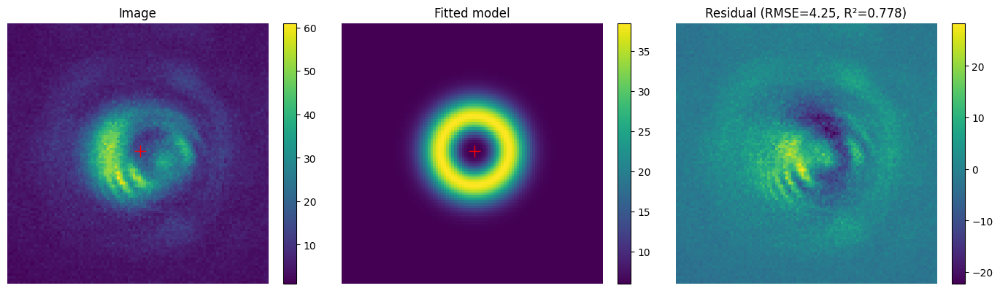

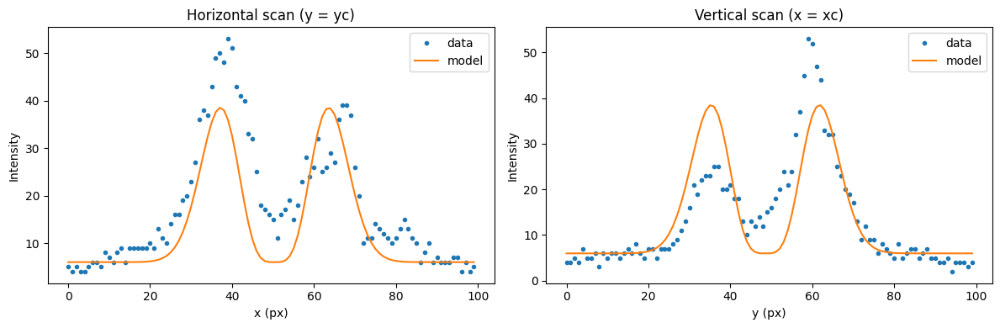

Params: {'A': 0.006149812998433022, 'w': 9.359702376932976, 'xc': 50.738322740773505, 'yc': 48.44486891787204, 'B': 4.443750342628701}
Uncertainties: {'A': 8.567705805859855e-05, 'w': 0.0242274054623558, 'xc': 0.053233995738135226, 'yc': 0.05323399574397143, 'B': 0.04248910246934622}
RMSE: 3.855636645411732 R^2: 0.7251917927010714


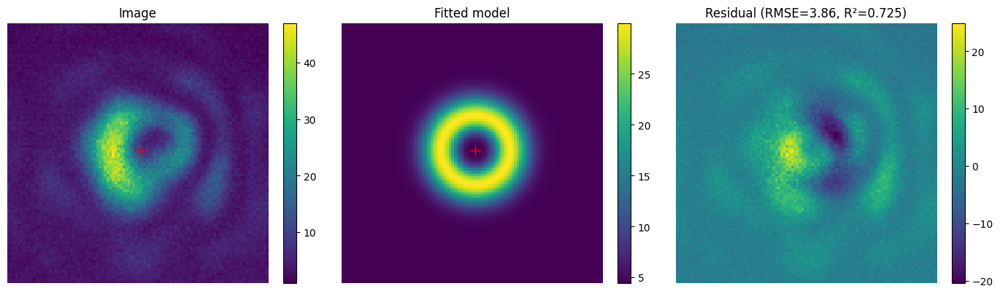

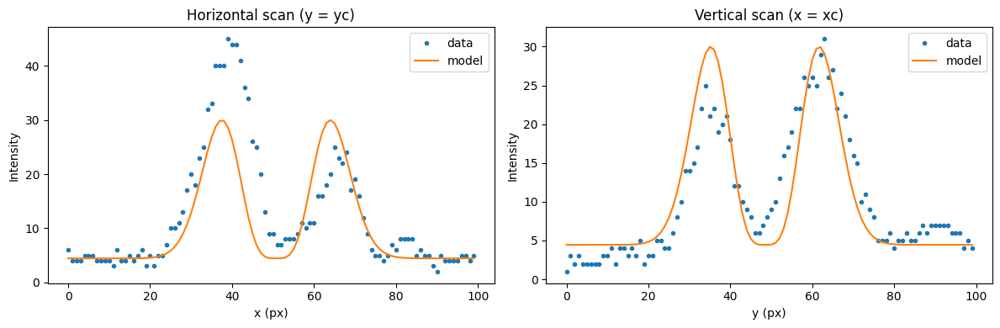

Params: {'A': 0.008178204158654154, 'w': 9.108239629034879, 'xc': 50.38844238678786, 'yc': 47.94201005577396, 'B': 5.761405425123647}
Uncertainties: {'A': 8.886854678796896e-05, 'w': 0.018369229302034978, 'xc': 0.040406289341723606, 'yc': 0.04040628932236599, 'B': 0.03824511024439226}
RMSE: 3.49013058395263 R^2: 0.8140276840351042


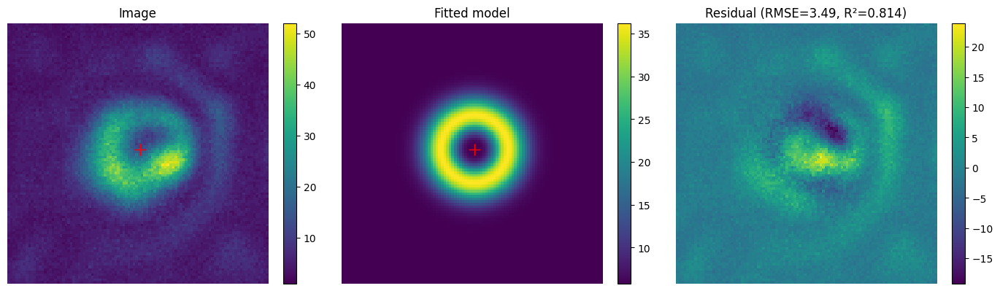

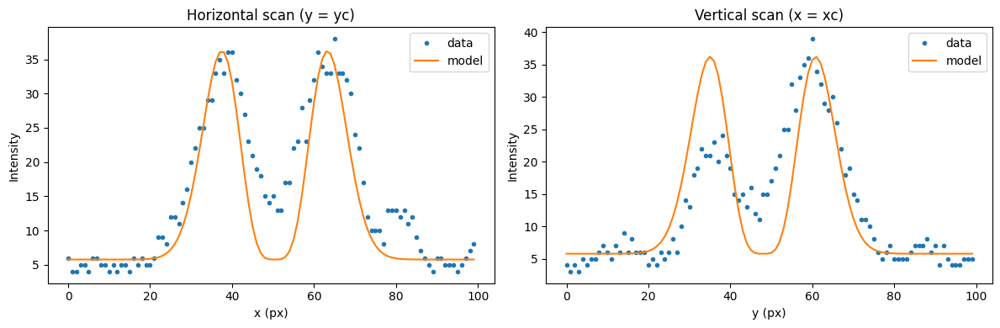

Params: {'A': 0.009279312352281957, 'w': 9.11093615068284, 'xc': 49.83969119017217, 'yc': 47.57039590871723, 'B': 7.054770143935637}
Uncertainties: {'A': 0.0001061076399559622, 'w': 0.019335936288001117, 'xc': 0.04253223993236512, 'yc': 0.04253223995117022, 'B': 0.045734403027502}
RMSE: 4.1733328975498125 R^2: 0.7980802975917826


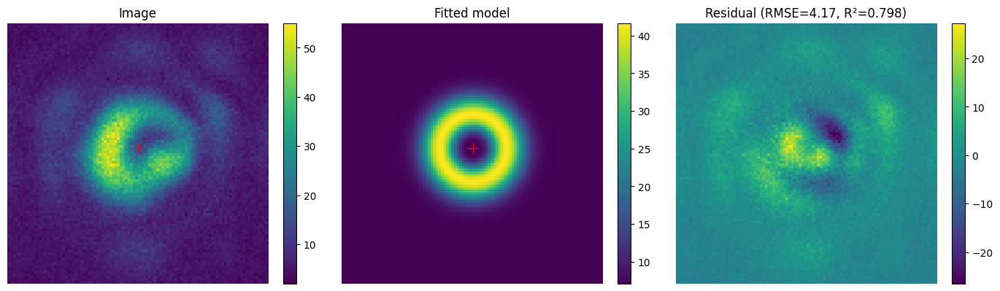

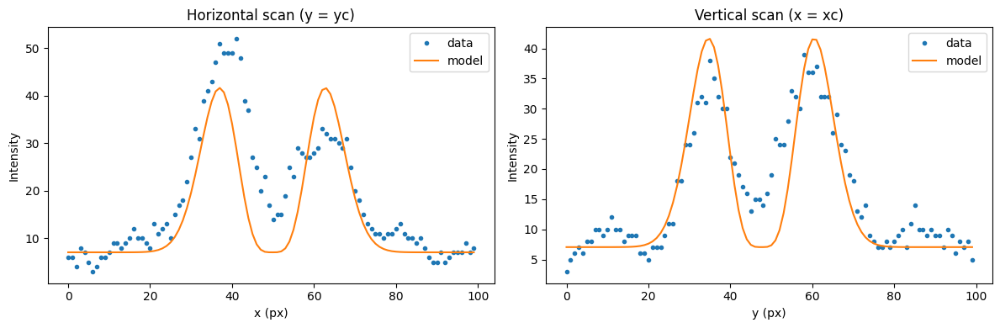

Params: {'A': 0.009234482595443912, 'w': 9.392708367988913, 'xc': 49.51903855077801, 'yc': 48.48910109891357, 'B': 7.324133633289767}
Uncertainties: {'A': 0.00011173400882409163, 'w': 0.021118839245383447, 'xc': 0.046396801585236146, 'yc': 0.04639680157689943, 'B': 0.05643787332537174}
RMSE: 5.117536280227054 R^2: 0.7774937281042729


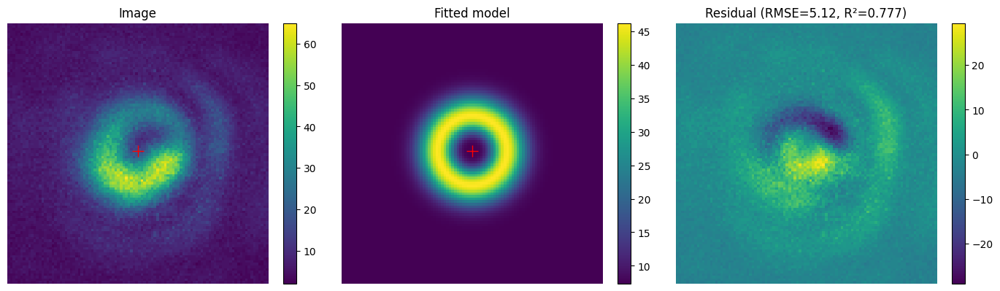

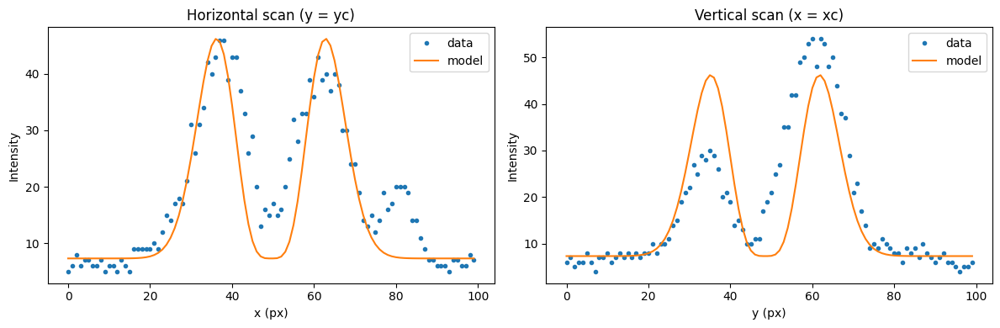

Params: {'A': 0.009098796591690793, 'w': 8.915324209855598, 'xc': 49.318182724698474, 'yc': 48.86270856315353, 'B': 4.48570751345671}
Uncertainties: {'A': 0.000140259388737273, 'w': 0.025485986561403943, 'xc': 0.0561060271926016, 'yc': 0.05610602719155116, 'B': 0.05400809637970538}
RMSE: 4.949245602154943 R^2: 0.6865004236121804


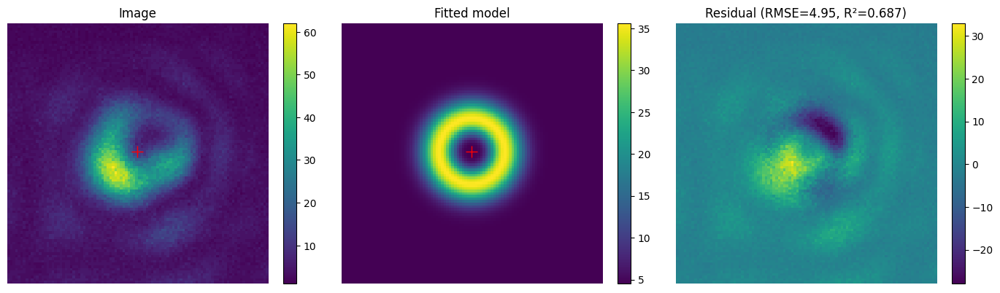

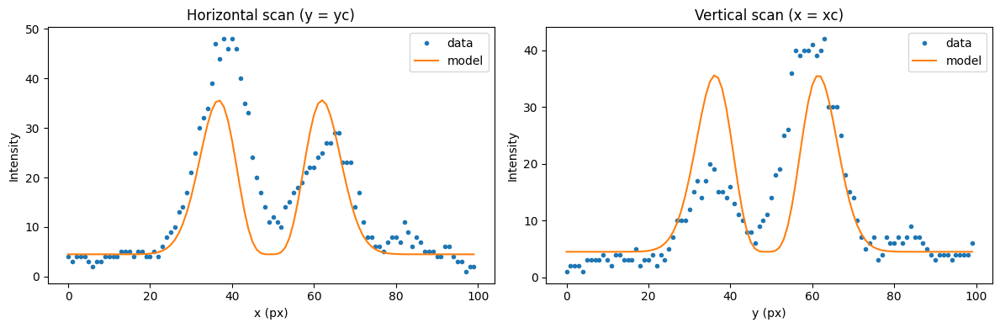

Params: {'A': 0.009622367480124539, 'w': 9.038562192886248, 'xc': 49.422682331011515, 'yc': 47.98860218090796, 'B': 6.819063325051909}
Uncertainties: {'A': 0.00012370408870405024, 'w': 0.021559561350865855, 'xc': 0.047437943912167546, 'yc': 0.047437943901840765, 'B': 0.05115344079660165}
RMSE: 4.675221224537578 R^2: 0.7581606240540388


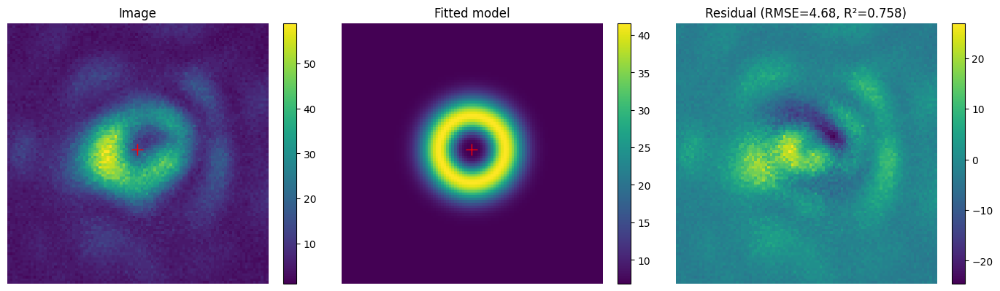

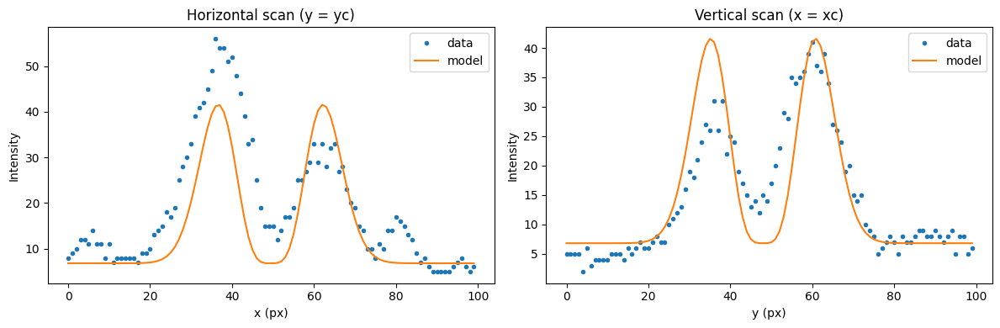

Params: {'A': 0.009436977165097086, 'w': 9.457846537117701, 'xc': 49.12965782417686, 'yc': 48.37171964103607, 'B': 7.263488187011458}
Uncertainties: {'A': 0.00011902224508784498, 'w': 0.022172858827689042, 'xc': 0.0486980854810633, 'yc': 0.04869808547636967, 'B': 0.062326565869493984}
RMSE: 5.6430098805589255 R^2: 0.7623681304201311


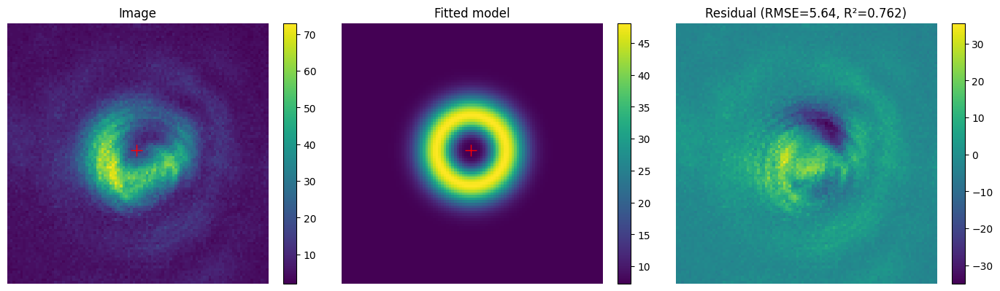

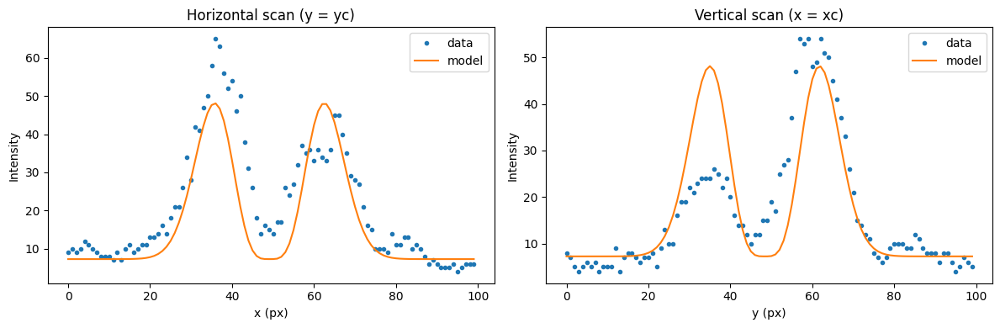

Params: {'A': 0.008510121903902261, 'w': 9.061650514600505, 'xc': 48.92280866624201, 'yc': 48.53031798568673, 'B': 6.701837929404544}
Uncertainties: {'A': 0.000115656511306165, 'w': 0.022851897420842347, 'xc': 0.05027661224169772, 'yc': 0.050276612243037075, 'B': 0.04846398276887577}
RMSE: 4.427188245548899 R^2: 0.7370471393978388


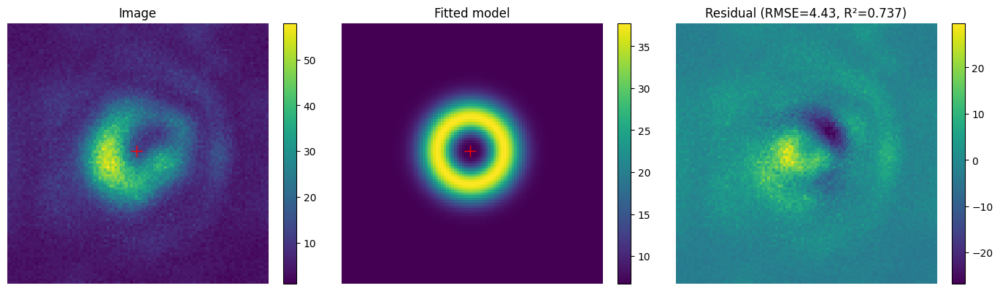

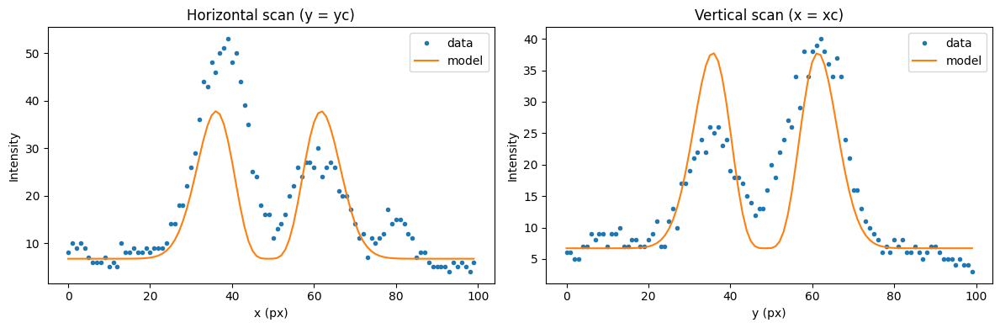

Params: {'A': 0.00876161194119299, 'w': 9.14397925144726, 'xc': 49.23168844640221, 'yc': 48.03327819699225, 'B': 4.837179772289819}
Uncertainties: {'A': 9.37417132102697e-05, 'w': 0.018160036809354446, 'xc': 0.03994003997987717, 'yc': 0.03994003997690412, 'B': 0.04117245249724526}
RMSE: 3.7543123692564753 R^2: 0.8184930480445162


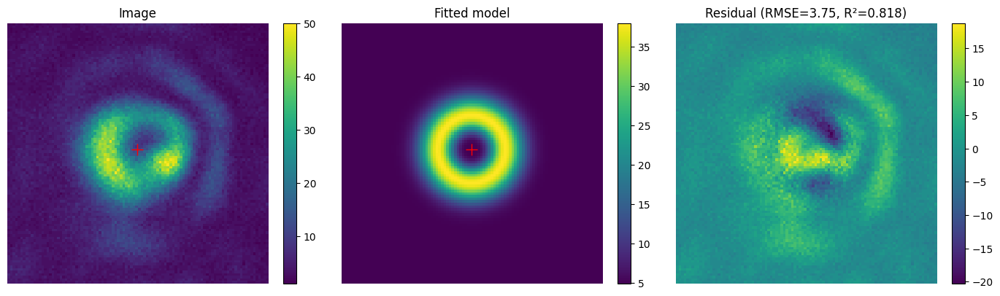

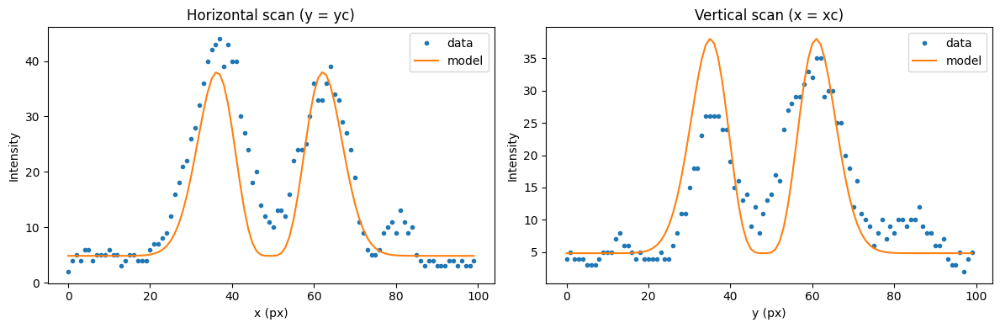

Params: {'A': 0.007962495738710211, 'w': 9.163843258216753, 'xc': 48.165470496249085, 'yc': 47.92846362854043, 'B': 5.708450078335558}
Uncertainties: {'A': 0.00010605528586849809, 'w': 0.022658460548985484, 'xc': 0.04982934164580038, 'yc': 0.04982934163849257, 'B': 0.04710957852128448}
RMSE: 4.293801252620341 R^2: 0.7440931586533834


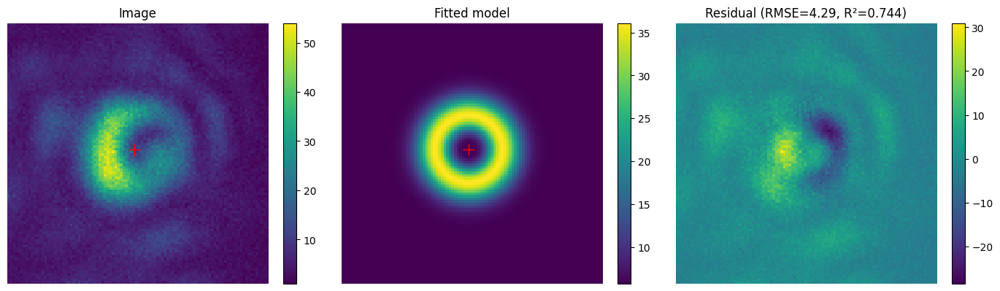

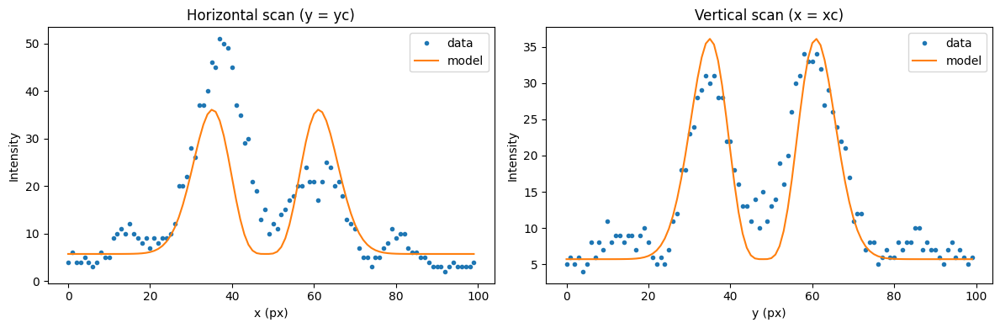

Params: {'A': 0.008516976528975297, 'w': 9.034689957530576, 'xc': 49.119722751570556, 'yc': 48.094158547386776, 'B': 6.31245255140147}
Uncertainties: {'A': 9.563501791834373e-05, 'w': 0.018822449616191752, 'xc': 0.04141609399006559, 'yc': 0.0414160939930221, 'B': 0.03945851145034709}
RMSE: 3.606654735521415 R^2: 0.8043026129483924


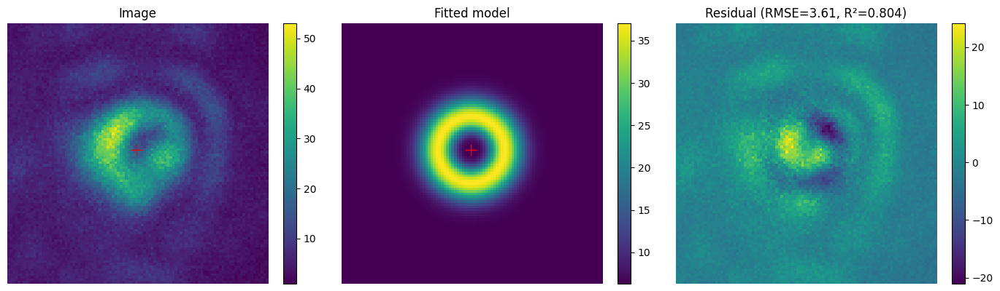

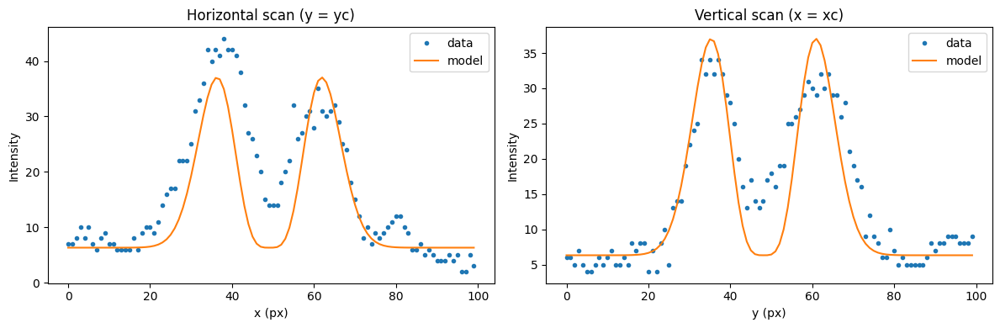

Params: {'A': 0.007240556335276392, 'w': 9.054104732151556, 'xc': 48.467330297477254, 'yc': 49.18766753518225, 'B': 5.4387471203268705}
Uncertainties: {'A': 9.923476648910337e-05, 'w': 0.023025245418847425, 'xc': 0.050659607416455456, 'yc': 0.05065960741358976, 'B': 0.04140305809281667}
RMSE: 3.7827947660392174 R^2: 0.7338215059666802


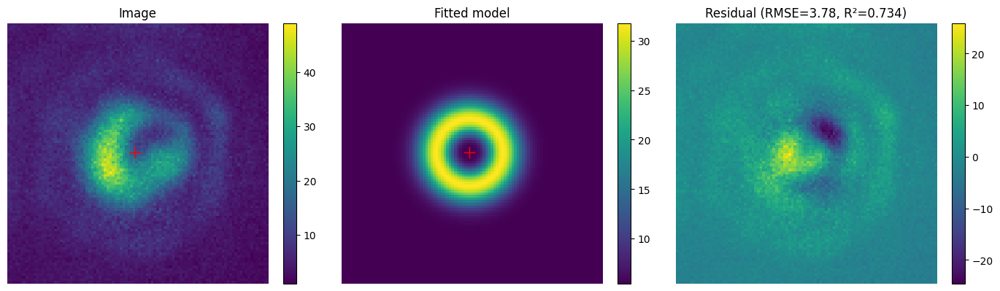

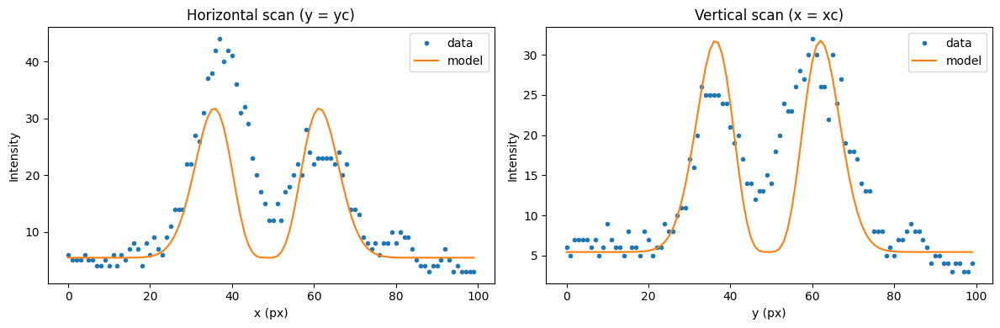

writing phase
Params: {'A': 0.008156170565114002, 'w': 9.120356239358578, 'xc': 49.76886986314235, 'yc': 48.86333023843838, 'B': 4.079577556488579}
Uncertainties: {'A': 0.00010263061998511254, 'w': 0.021300570095375303, 'xc': 0.04685186099613448, 'yc': 0.046851860995479944, 'B': 0.04447411647511161}
RMSE: 4.057488721126789 R^2: 0.7654176438074735


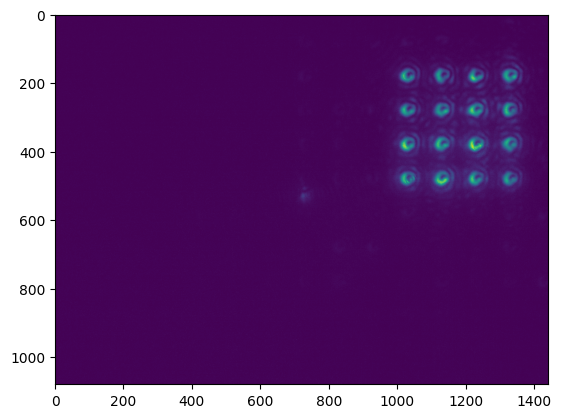

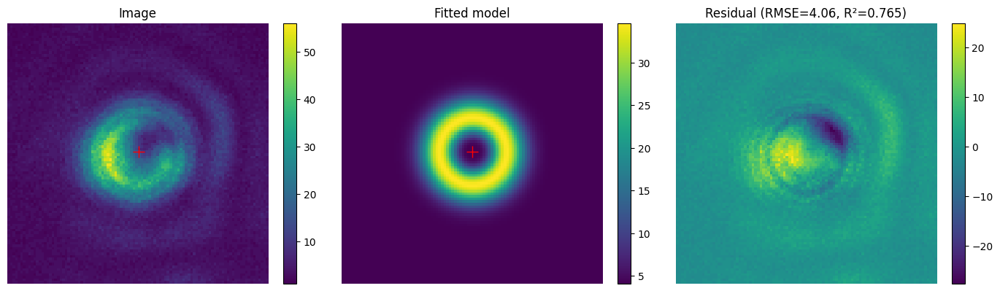

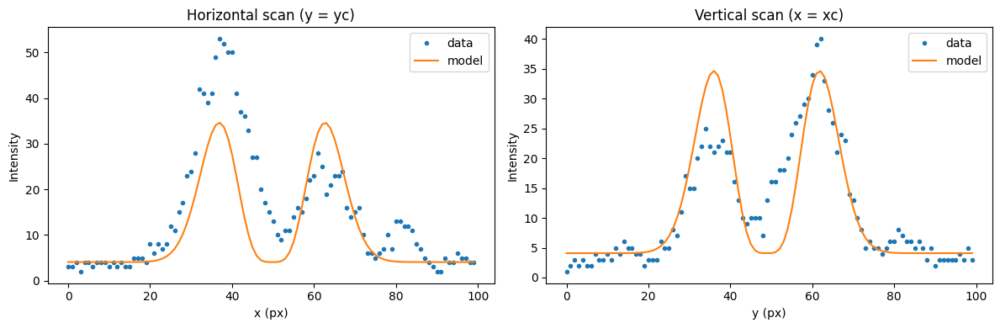

Params: {'A': 0.008415348409490502, 'w': 8.922754185537077, 'xc': 50.052047488183874, 'yc': 48.83846294590387, 'B': 4.83423311453268}
Uncertainties: {'A': 0.00011767336558685554, 'w': 0.023138466401997404, 'xc': 0.05093653442557019, 'yc': 0.05093653441492709, 'B': 0.04550749433307802}
RMSE: 4.16959791333812 R^2: 0.7268192836462033


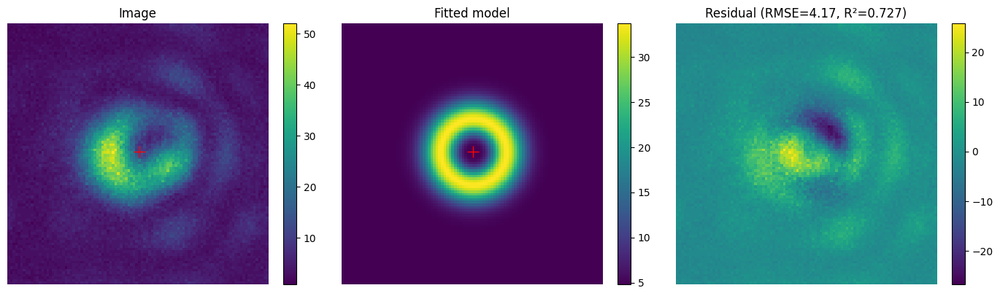

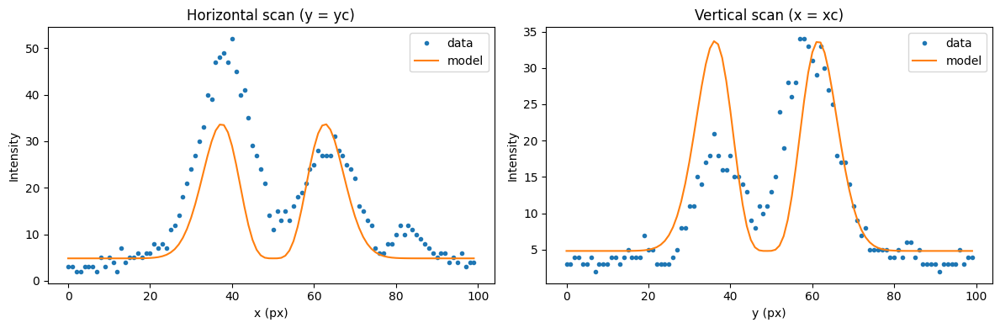

Params: {'A': 0.010192348505150753, 'w': 9.022560056781384, 'xc': 49.92667005682791, 'yc': 48.80581008217298, 'B': 6.321121151924848}
Uncertainties: {'A': 0.00013804291061179577, 'w': 0.022671431386316367, 'xc': 0.04988776128249596, 'yc': 0.049887761261501753, 'B': 0.056559573563803436}
RMSE: 5.171117114130399 R^2: 0.7386438447888507


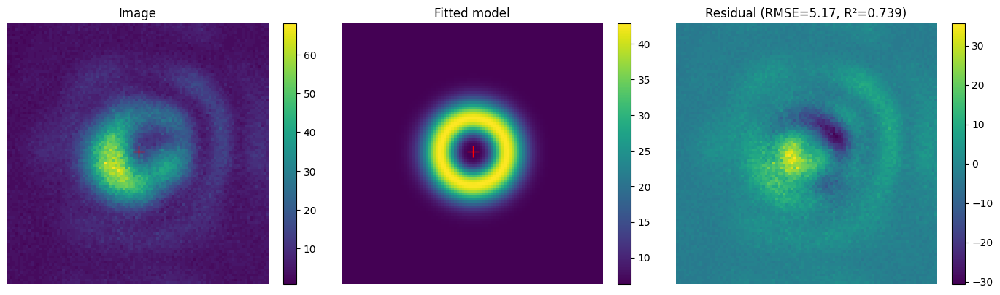

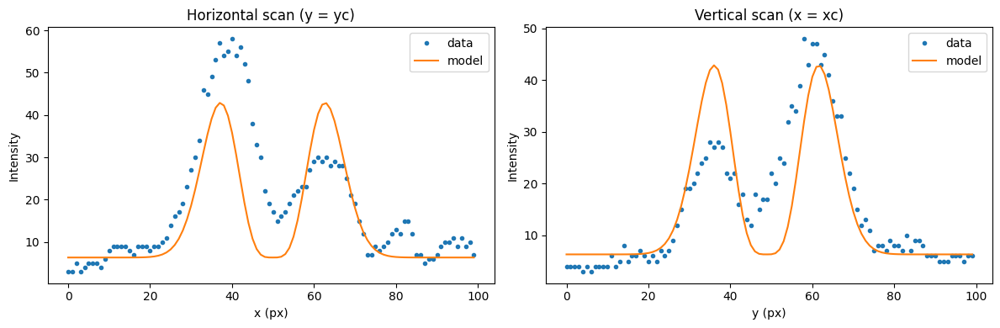

Params: {'A': 0.007629520137462078, 'w': 9.342073681178869, 'xc': 50.1397031852639, 'yc': 48.64986520347701, 'B': 6.08493198204643}
Uncertainties: {'A': 9.708467124163918e-05, 'w': 0.022085379048611124, 'xc': 0.04853121004025294, 'yc': 0.048531210031637455, 'B': 0.0476755021298717}
RMSE: 4.328012075019109 R^2: 0.7599161192556627


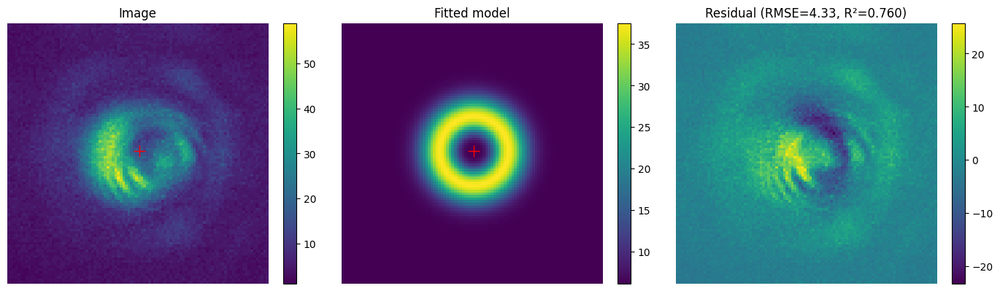

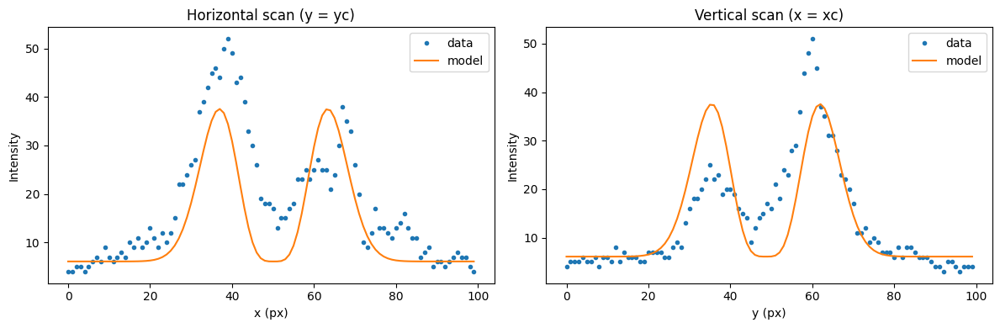

Params: {'A': 0.005901861767620386, 'w': 9.352799081249909, 'xc': 50.39089080741436, 'yc': 48.576352994761216, 'B': 4.527404246824792}
Uncertainties: {'A': 8.855752289574245e-05, 'w': 0.026073953986783294, 'xc': 0.05729311333396262, 'yc': 0.05729311334337625, 'B': 0.04374897216001533}
RMSE: 3.9705881542619608 R^2: 0.6946976848195202


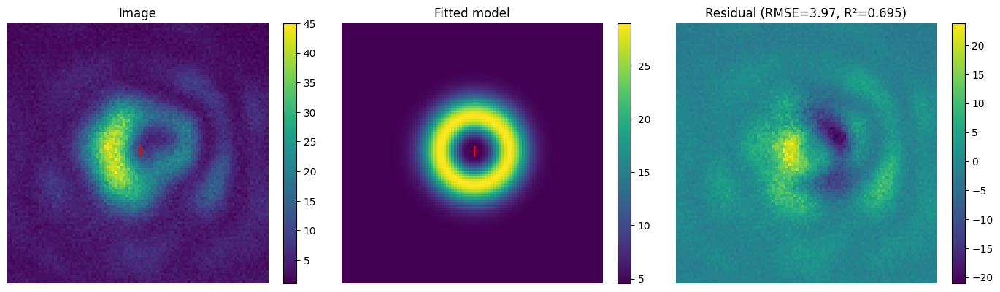

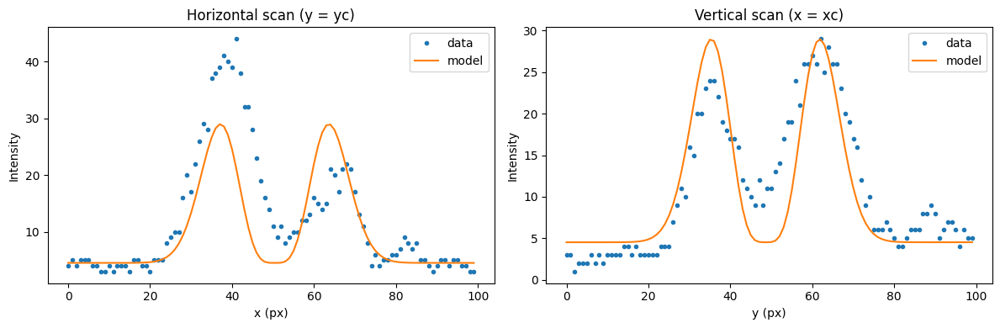

Params: {'A': 0.007926963141596563, 'w': 9.089838303337608, 'xc': 50.132007107301064, 'yc': 47.96474638867495, 'B': 5.8911348210302785}
Uncertainties: {'A': 9.2130757245822e-05, 'w': 0.019605881574281375, 'xc': 0.04312989001108239, 'yc': 0.04312989000579518, 'B': 0.03923427450606316}
RMSE: 3.5818449947929856 R^2: 0.7929076123630805


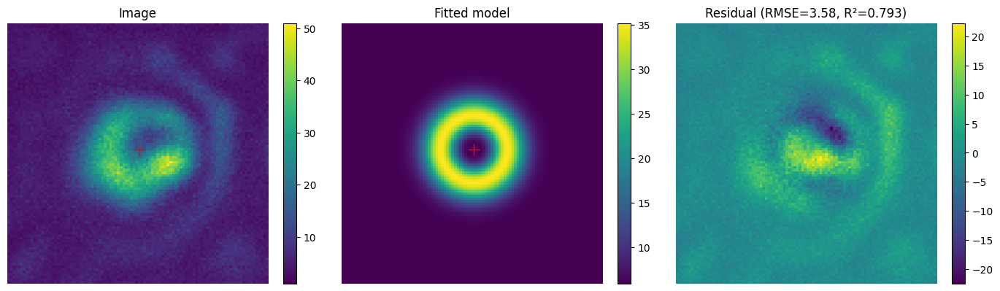

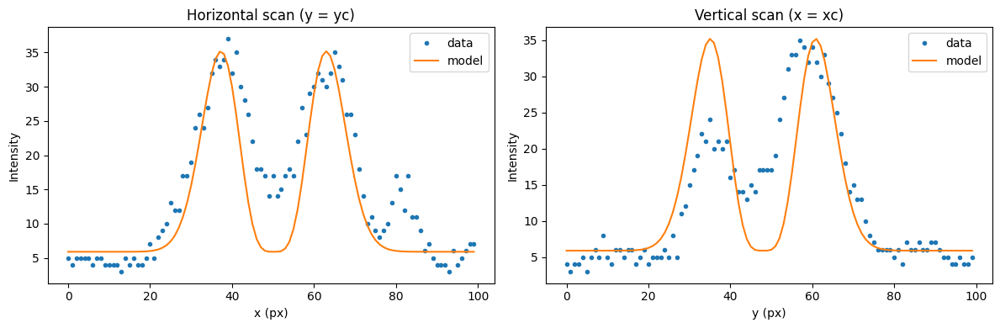

Params: {'A': 0.009111039952541823, 'w': 9.08604896594801, 'xc': 49.51063278540961, 'yc': 47.73902111099202, 'B': 7.150444132965937}
Uncertainties: {'A': 0.00011129124289160187, 'w': 0.02059650612342067, 'xc': 0.04530983759051557, 'yc': 0.045309837589146806, 'B': 0.0472912175763459}
RMSE: 4.317752214581158 R^2: 0.7761250265209841


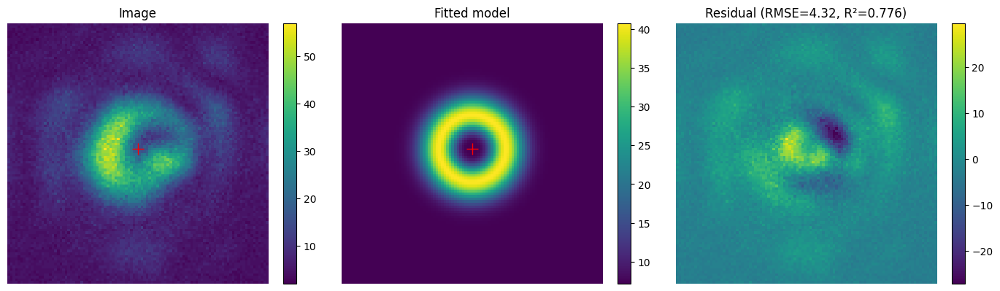

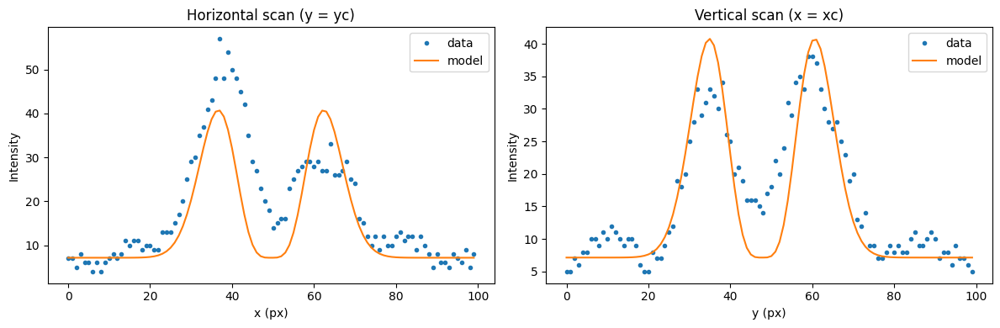

Params: {'A': 0.008850784047865644, 'w': 9.401572762908458, 'xc': 49.257224288574214, 'yc': 48.62165018822729, 'B': 7.46970415028576}
Uncertainties: {'A': 0.00011421736581905324, 'w': 0.022546264471078267, 'xc': 0.04953079489449017, 'yc': 0.04953079491075557, 'B': 0.057976795395511004}
RMSE: 5.256008465126093 R^2: 0.7543504551818464


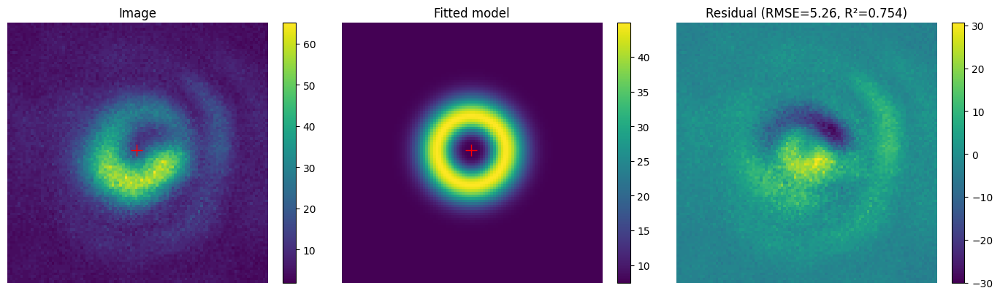

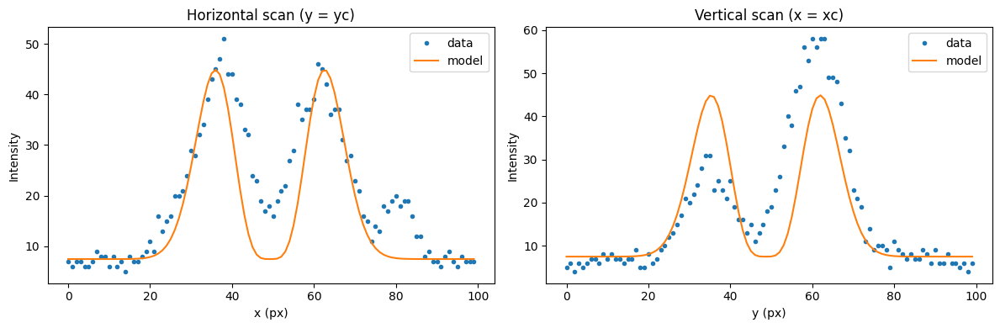

Params: {'A': 0.009257617785178317, 'w': 8.82153750487429, 'xc': 48.83953307251399, 'yc': 49.03691466031702, 'B': 4.58507410968598}
Uncertainties: {'A': 0.00015024534385079047, 'w': 0.026539746725841425, 'xc': 0.05844810722257981, 'yc': 0.05844810720930685, 'B': 0.05476473176221166}
RMSE: 5.028561947048673 R^2: 0.6646478269783014


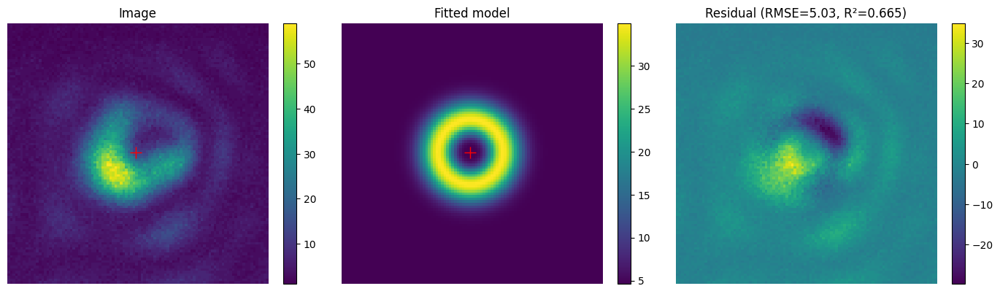

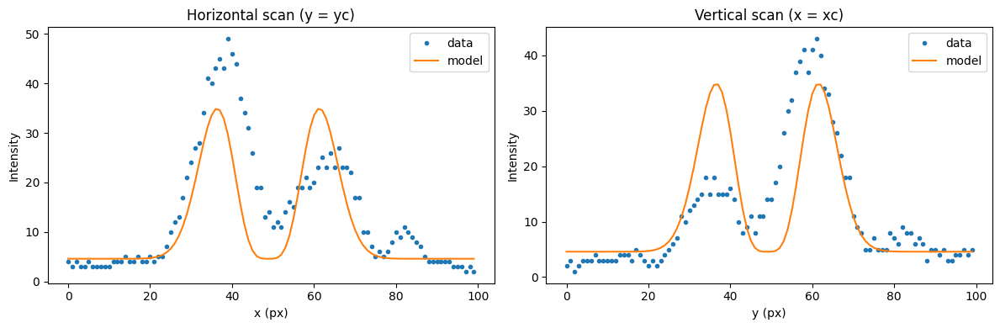

Params: {'A': 0.009500330829626442, 'w': 8.998937070096746, 'xc': 49.06936558991007, 'yc': 48.19969224008373, 'B': 6.918751649346841}
Uncertainties: {'A': 0.0001313866113296513, 'w': 0.023087136049785954, 'xc': 0.05080751900849851, 'yc': 0.050807519023560635, 'B': 0.05310411346476913}
RMSE: 4.857675990303851 R^2: 0.7306606144547065


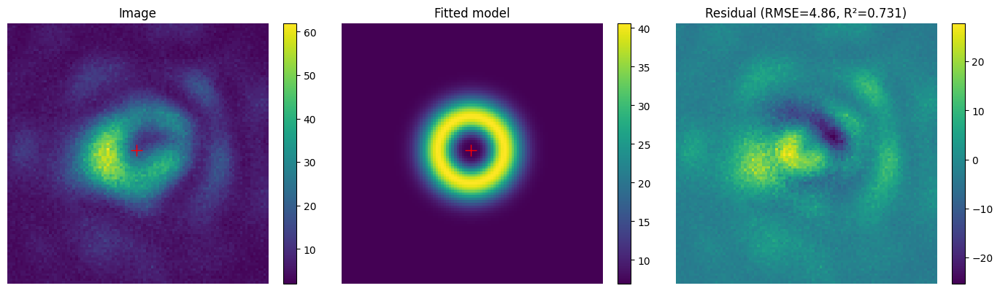

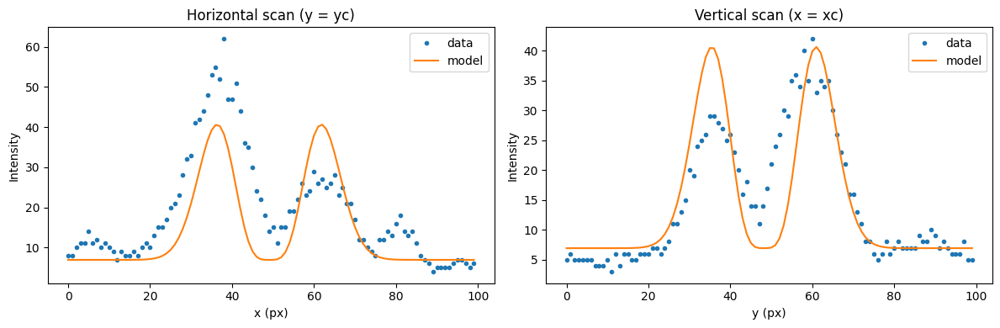

Params: {'A': 0.0091945452601773, 'w': 9.44565333850239, 'xc': 48.893580826416844, 'yc': 48.52988690443983, 'B': 7.333594109540695}
Uncertainties: {'A': 0.00012096766086393525, 'w': 0.023098361902999628, 'xc': 0.05073356975975087, 'yc': 0.050733569758489694, 'B': 0.06292024059280987}
RMSE: 5.698370123701659 R^2: 0.7468126697337881


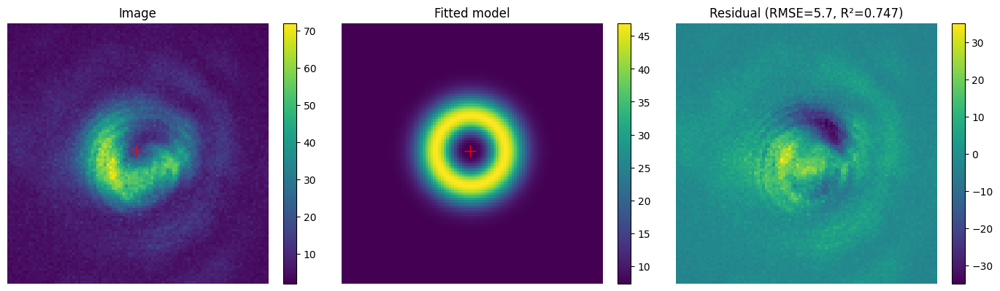

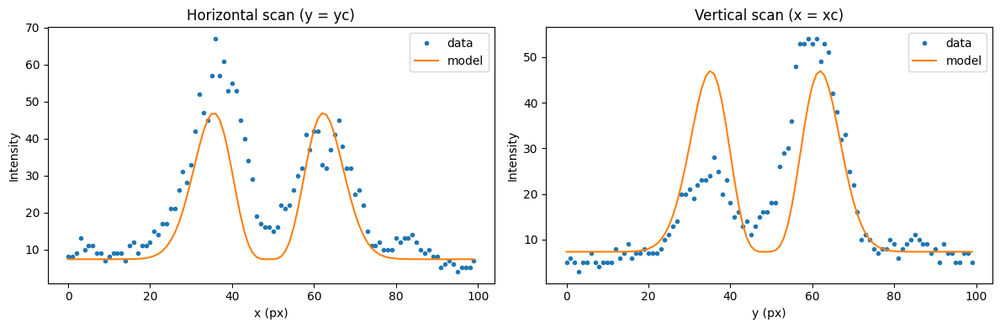

Params: {'A': 0.008874543506126386, 'w': 8.937376974197166, 'xc': 48.39317027446002, 'yc': 48.857026585052, 'B': 6.861446838030195}
Uncertainties: {'A': 0.0001260259707091466, 'w': 0.023538555053474002, 'xc': 0.051814164075002285, 'yc': 0.0518141640719455, 'B': 0.04915371400096787}
RMSE: 4.502272661483977 R^2: 0.720541252795853


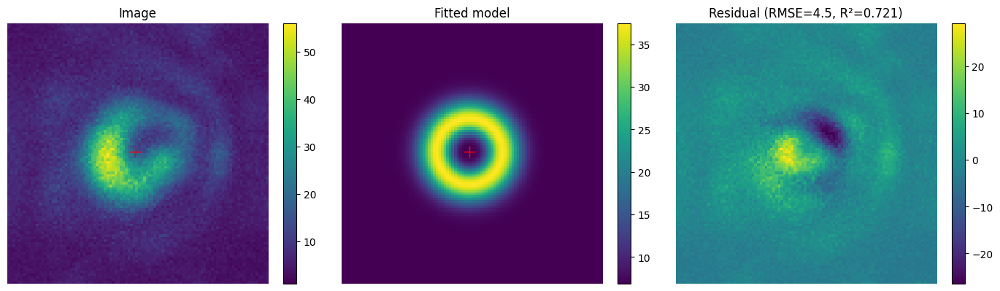

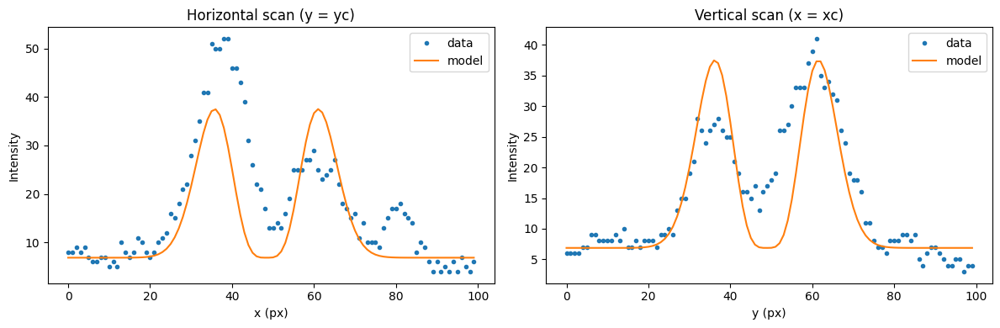

Params: {'A': 0.008457904713812971, 'w': 9.145686642215507, 'xc': 49.0499596270885, 'yc': 48.15095732561712, 'B': 4.931141998578438}
Uncertainties: {'A': 9.622368008130757e-05, 'w': 0.019313958218847124, 'xc': 0.04247759135825761, 'yc': 0.04247759136050017, 'B': 0.042303629415515125}
RMSE: 3.8573132259625917 R^2: 0.7995186798205656


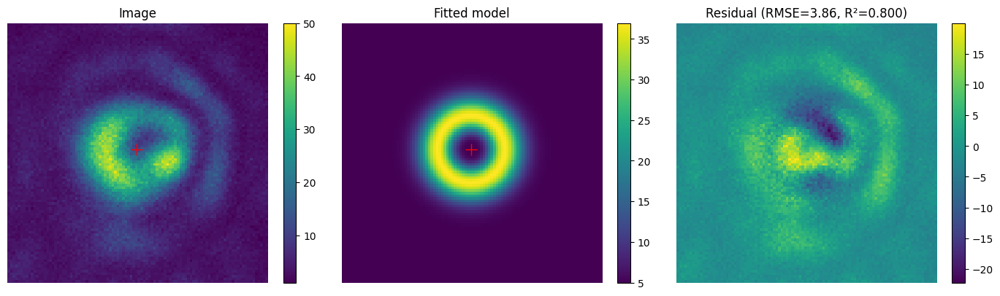

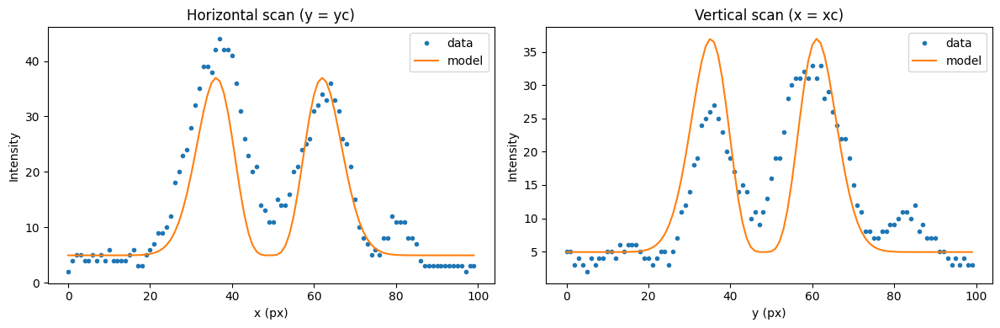

Params: {'A': 0.008061416098292805, 'w': 9.111122595259658, 'xc': 47.64314500060853, 'yc': 48.05916328412663, 'B': 5.752505974391867}
Uncertainties: {'A': 0.00011132782290946346, 'w': 0.023352638418134408, 'xc': 0.05136752714985613, 'yc': 0.051367527169001385, 'B': 0.04798950743719448}
RMSE: 4.379096606416297 R^2: 0.7304458426048547


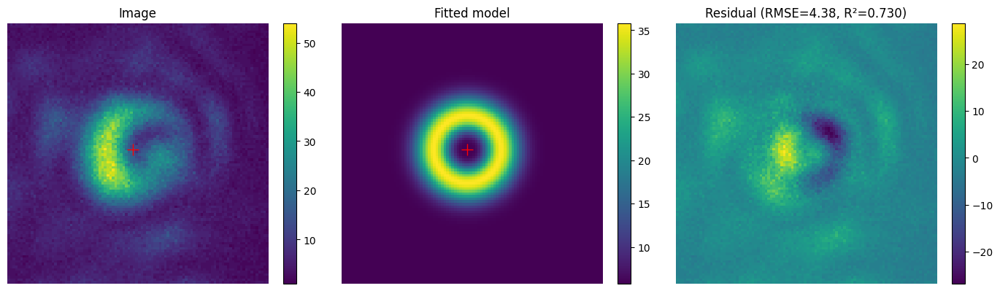

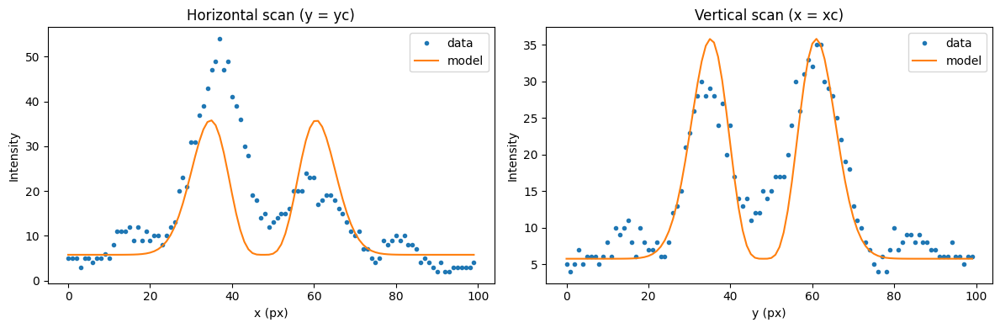

Params: {'A': 0.008268966086942586, 'w': 9.016082210785754, 'xc': 48.68460625896997, 'yc': 48.296028219302414, 'B': 6.4322386756437355}
Uncertainties: {'A': 0.00010088415771785736, 'w': 0.020407376338566947, 'xc': 0.04490699716507264, 'yc': 0.04490699716960367, 'B': 0.041180764527492246}
RMSE: 3.7655953240837734 R^2: 0.7769684012174559


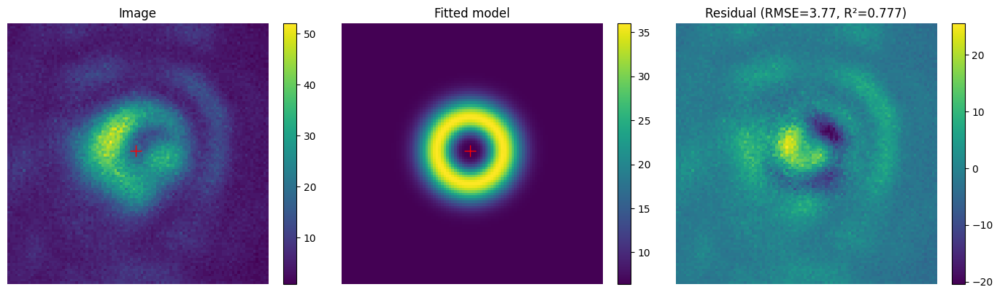

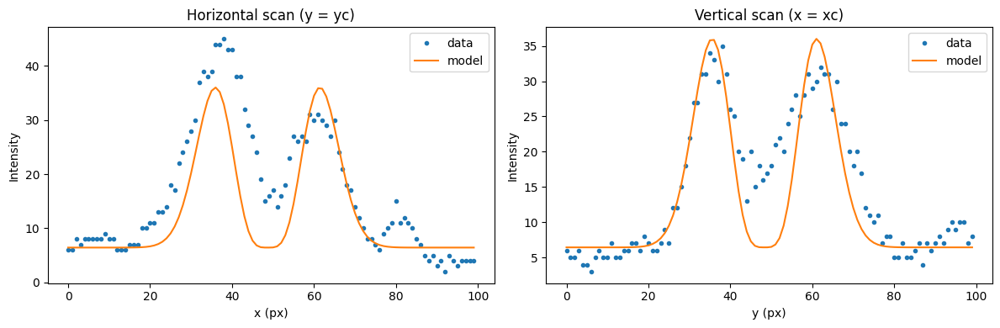

Params: {'A': 0.007436159905223314, 'w': 8.958648042933152, 'xc': 47.953068851523405, 'yc': 49.52428329810939, 'B': 5.534531276694808}
Uncertainties: {'A': 0.00010632880216985065, 'w': 0.023759565786261823, 'xc': 0.052296071667095184, 'yc': 0.05229607165933349, 'B': 0.041986269435951}
RMSE: 3.8440112852845596 R^2: 0.717612665248166


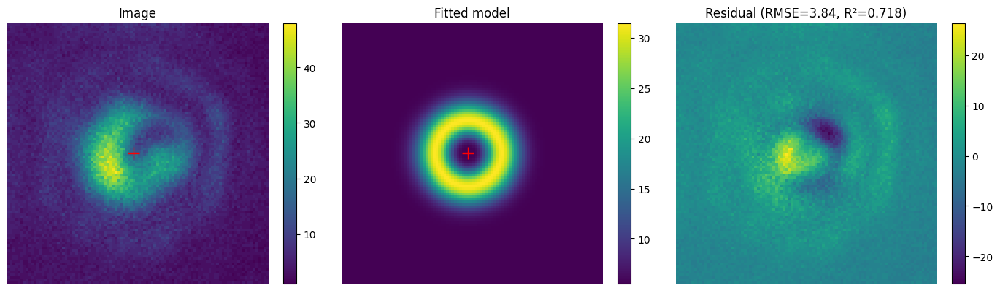

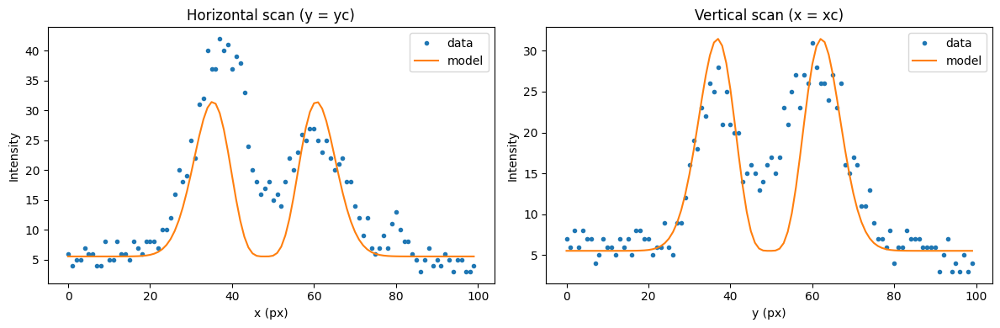

writing phase
Params: {'A': 0.008044141628659652, 'w': 9.049091290482448, 'xc': 49.29026243443739, 'yc': 49.0707415319779, 'B': 4.172231262295614}
Uncertainties: {'A': 0.0001116343452968767, 'w': 0.023301332881469593, 'xc': 0.05126813059552926, 'yc': 0.0512681305951128, 'B': 0.04644256906530675}
RMSE: 4.243693756489515 R^2: 0.7289469437502897


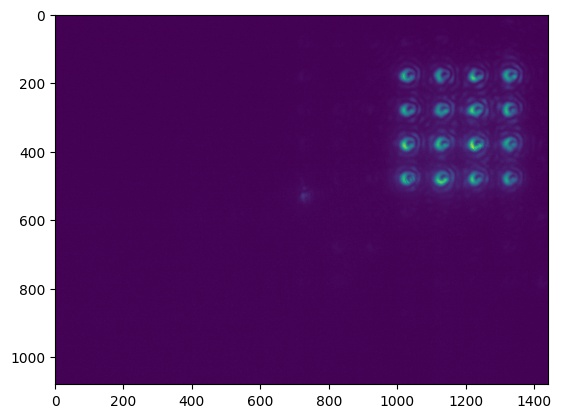

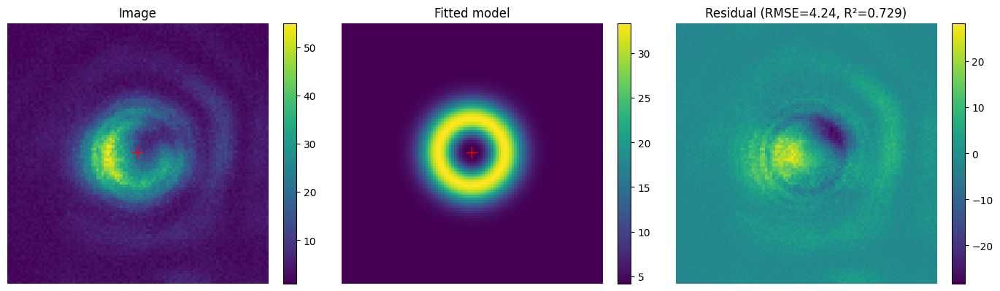

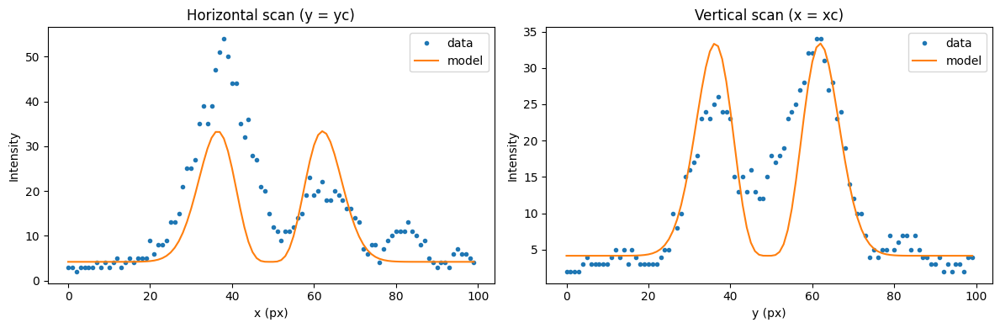

Params: {'A': 0.008102737310373781, 'w': 8.888652536539432, 'xc': 49.56133038440599, 'yc': 49.07948871592091, 'B': 4.868512780069932}
Uncertainties: {'A': 0.00012254300758729835, 'w': 0.024926518916087374, 'xc': 0.0548803782945248, 'yc': 0.05488037828418862, 'B': 0.04645824354344247}
RMSE: 4.259803260135184 R^2: 0.6948534320890976


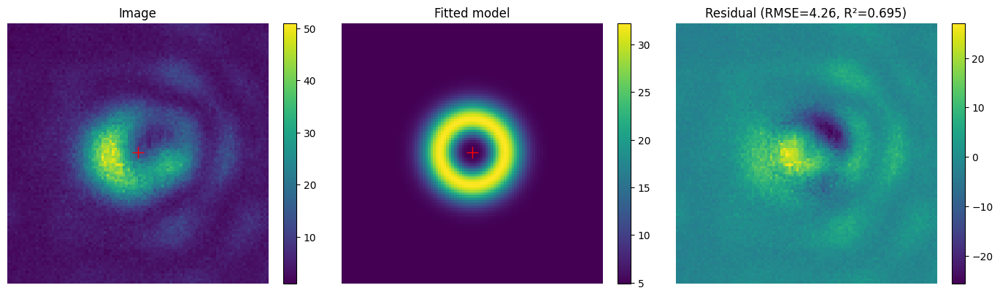

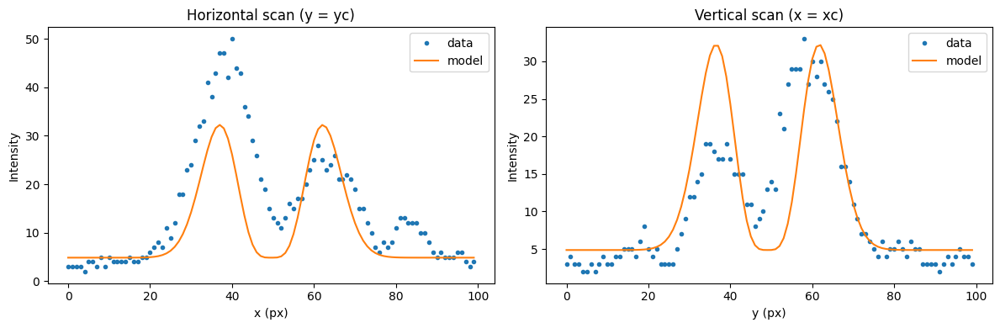

Params: {'A': 0.009907088780770606, 'w': 8.981249644287624, 'xc': 49.49805552094956, 'yc': 49.01791818973767, 'B': 6.3925195630307705}
Uncertainties: {'A': 0.00014595588128682826, 'w': 0.024544083536430113, 'xc': 0.0540177765337914, 'yc': 0.054017776538989044, 'B': 0.058392978483562445}
RMSE: 5.343512124791221 R^2: 0.7051867631095039


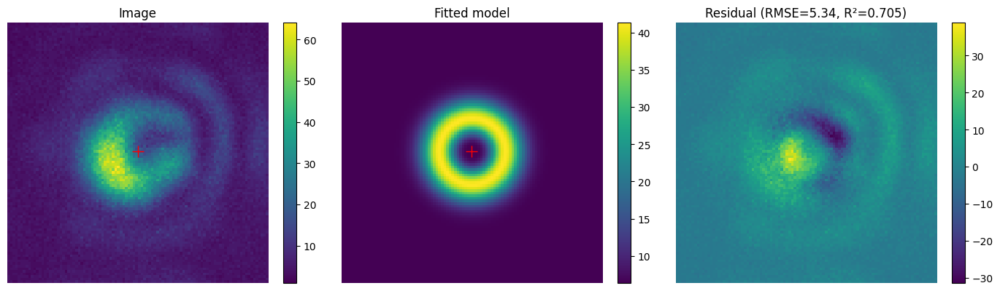

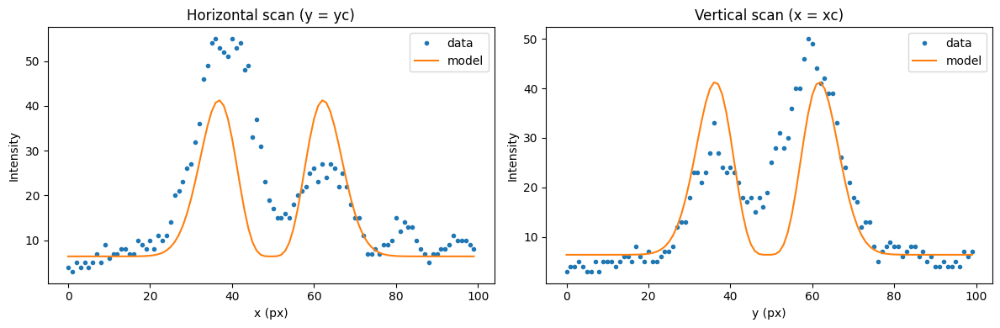

Params: {'A': 0.007336406638523857, 'w': 9.328349222305624, 'xc': 49.7333695266031, 'yc': 48.79547806477956, 'B': 6.129269564773962}
Uncertainties: {'A': 0.00010132251851315683, 'w': 0.023933655386811102, 'xc': 0.052595885148216545, 'yc': 0.05259588514366886, 'B': 0.0493767482631154}
RMSE: 4.483852480303643 R^2: 0.7288746464593165


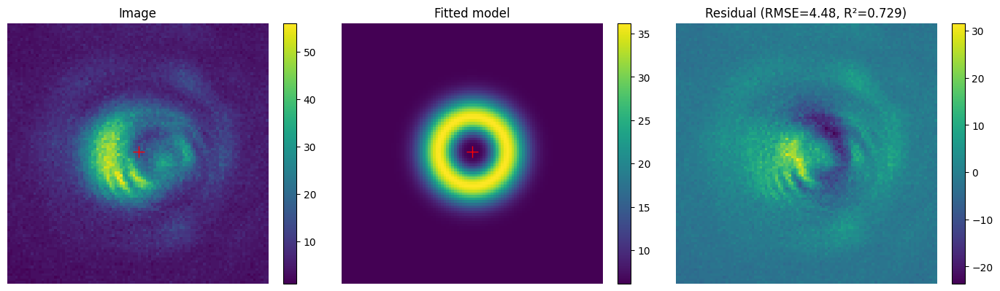

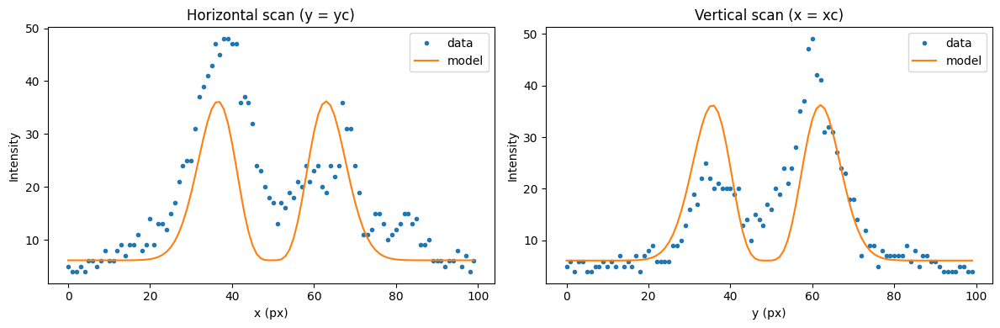

Params: {'A': 0.005595134268689098, 'w': 9.341830975148726, 'xc': 49.89291610267076, 'yc': 48.695682155677524, 'B': 4.590310537046479}
Uncertainties: {'A': 9.205987905353762e-05, 'w': 0.028556143113000962, 'xc': 0.06275036888109799, 'yc': 0.06275036887274114, 'B': 0.04520184845613945}
RMSE: 4.103474927138178 R^2: 0.6543604583411933


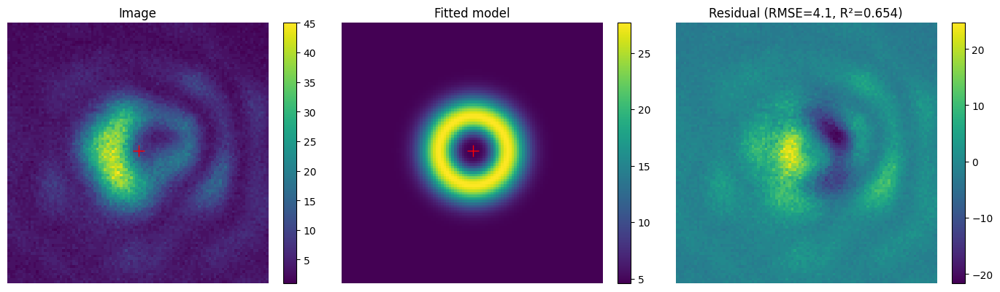

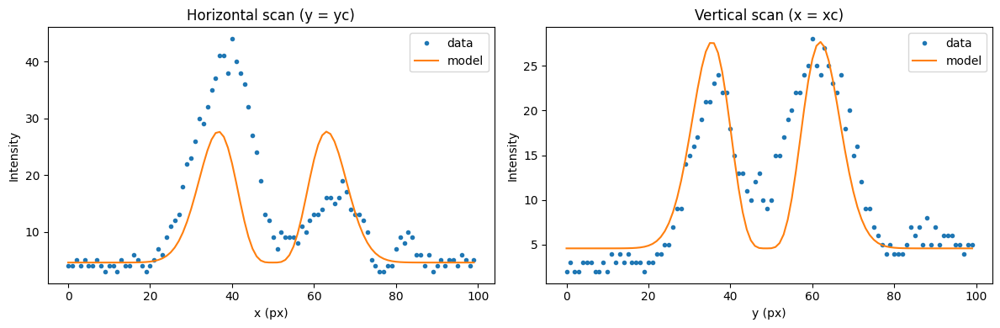

Params: {'A': 0.007491938919868084, 'w': 9.087070582598809, 'xc': 49.68443709665483, 'yc': 48.2012761465101, 'B': 5.946462881162218}
Uncertainties: {'A': 9.383205969746806e-05, 'w': 0.021120696853436444, 'xc': 0.04646279310921149, 'yc': 0.046462793106575584, 'B': 0.039895564473616765}
RMSE: 3.642437551530922 R^2: 0.7673056271882721


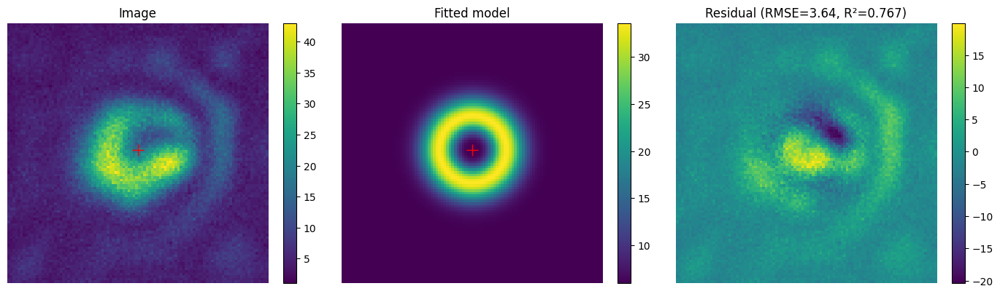

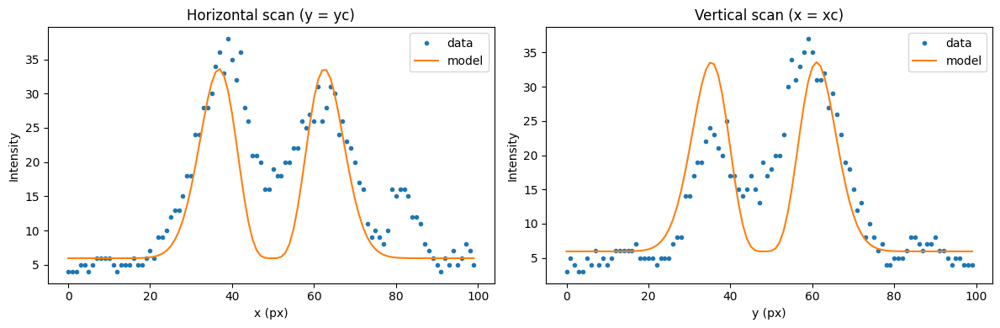

Params: {'A': 0.008788586105749516, 'w': 9.065464725860402, 'xc': 49.06190960966639, 'yc': 47.838605777633745, 'B': 7.166837639985233}
Uncertainties: {'A': 0.00011625807012374397, 'w': 0.022252653621022963, 'xc': 0.04895742425832573, 'yc': 0.04895742426416411, 'B': 0.048822734672417}
RMSE: 4.4595889383003895 R^2: 0.7473563936427172


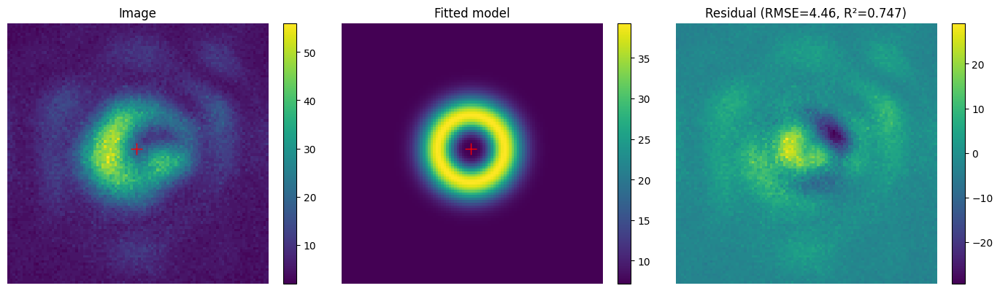

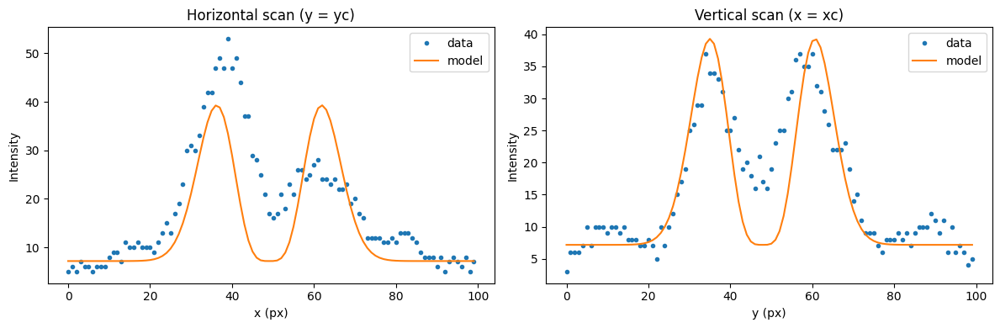

Params: {'A': 0.00856296073879055, 'w': 9.368425703986603, 'xc': 48.85113945842943, 'yc': 48.77022000474154, 'B': 7.496995629940863}
Uncertainties: {'A': 0.00011588843110605996, 'w': 0.023558188859522326, 'xc': 0.05176153398951799, 'yc': 0.05176153398304063, 'B': 0.0577514083289122}
RMSE: 5.239556483258714 R^2: 0.7365289127499075


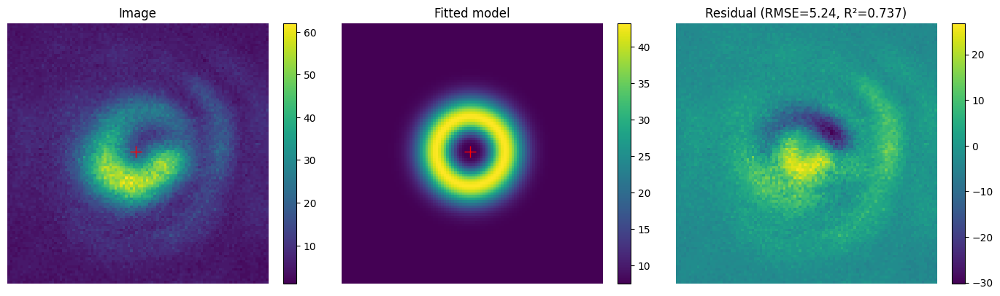

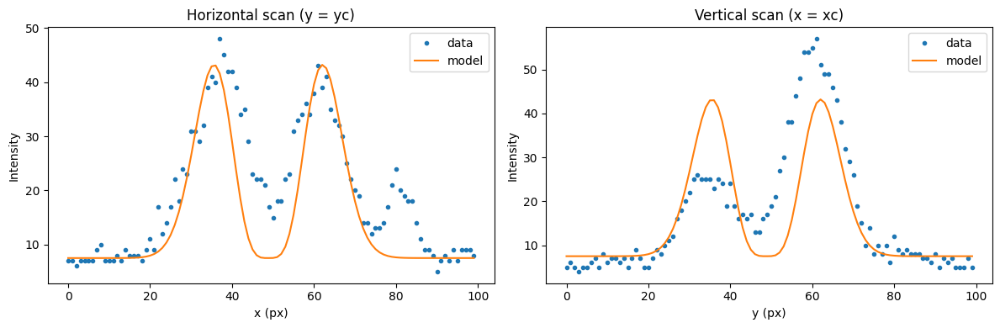

Params: {'A': 0.009425629172210733, 'w': 8.705180569649508, 'xc': 48.324138600012716, 'yc': 49.15267118131514, 'B': 4.659747773180933}
Uncertainties: {'A': 0.00016159788078536948, 'w': 0.027653645912465698, 'xc': 0.060929482104400516, 'yc': 0.06092948209388473, 'B': 0.054985745576253124}
RMSE: 5.061111899542237 R^2: 0.6406729757405383


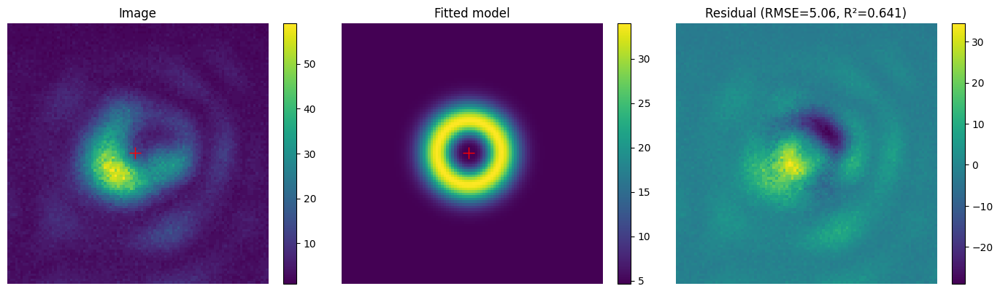

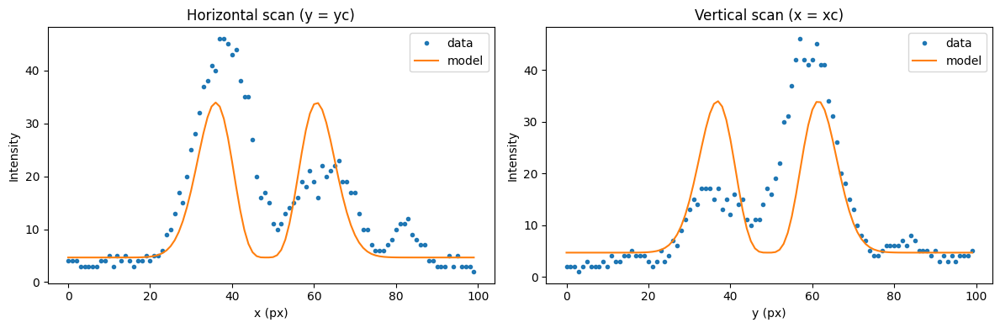

Params: {'A': 0.009406523574757304, 'w': 8.921959519108269, 'xc': 48.546181906814205, 'yc': 48.47220734306514, 'B': 7.002841439345676}
Uncertainties: {'A': 0.00014193366477231127, 'w': 0.024965752966304097, 'xc': 0.054959263951127706, 'yc': 0.05495926394841837, 'B': 0.054864243190972564}
RMSE: 5.026989949928192 R^2: 0.6955868328591259


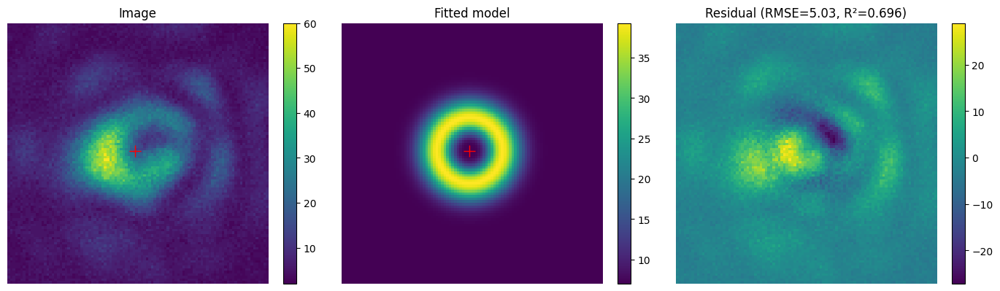

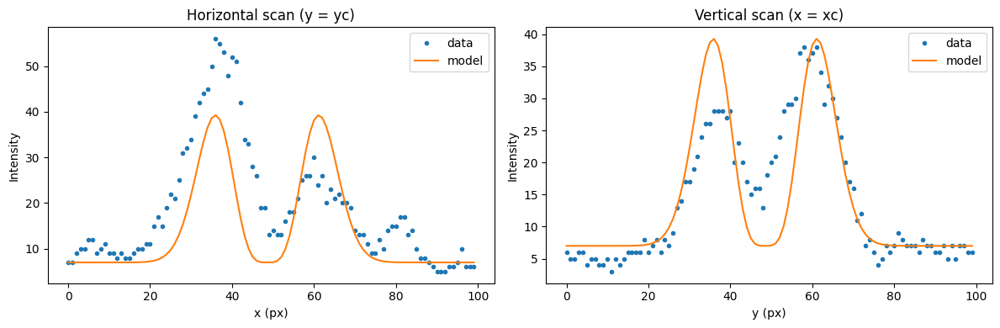

Params: {'A': 0.008877171993848125, 'w': 9.43011203204517, 'xc': 48.542543235728395, 'yc': 48.60654462481265, 'B': 7.370766243340323}
Uncertainties: {'A': 0.00012429550229470143, 'w': 0.02454015021515912, 'xc': 0.05390412773679318, 'yc': 0.053904127724453646, 'B': 0.06409803755474583}
RMSE: 5.807123115496396 R^2: 0.7226672046559158


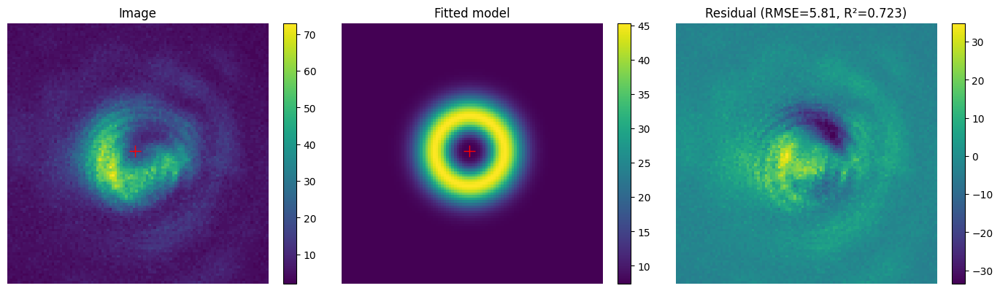

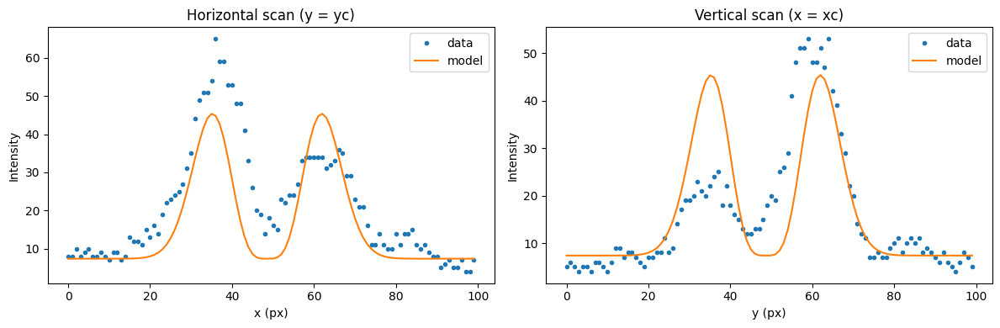

Params: {'A': 0.009230447382074885, 'w': 8.780637458213251, 'xc': 47.87355933125223, 'yc': 49.13340878491511, 'B': 6.89797601168099}
Uncertainties: {'A': 0.00014147432090934133, 'w': 0.024943668187179618, 'xc': 0.054942106195481316, 'yc': 0.05494210618702675, 'B': 0.05034009854485366}
RMSE: 4.626251152723819 R^2: 0.6899501959359942


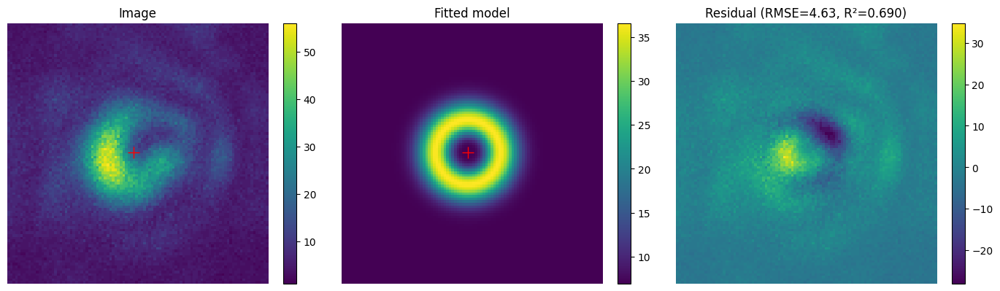

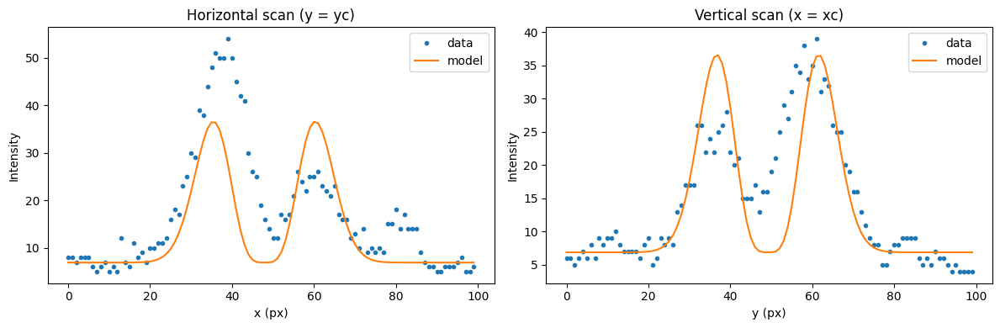

Params: {'A': 0.008061195984810502, 'w': 9.128901679777542, 'xc': 48.733590385586396, 'yc': 48.24027478793517, 'B': 5.012395764571762}
Uncertainties: {'A': 0.0001003112601022742, 'w': 0.021084987451846334, 'xc': 0.04637598285119617, 'yc': 0.046375982852496306, 'B': 0.043681292154942854}
RMSE: 3.984406983088029 R^2: 0.7693424998224361


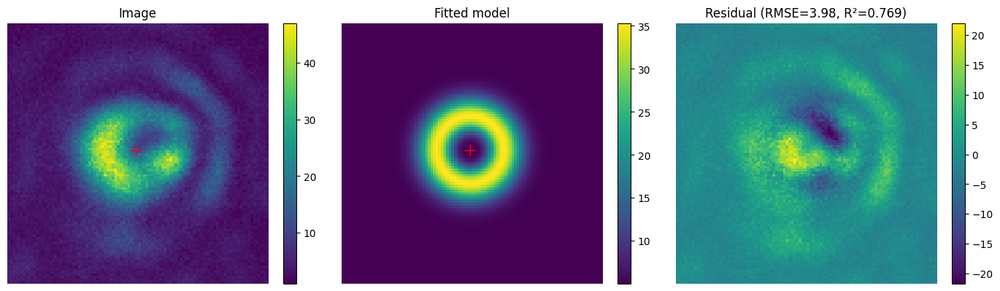

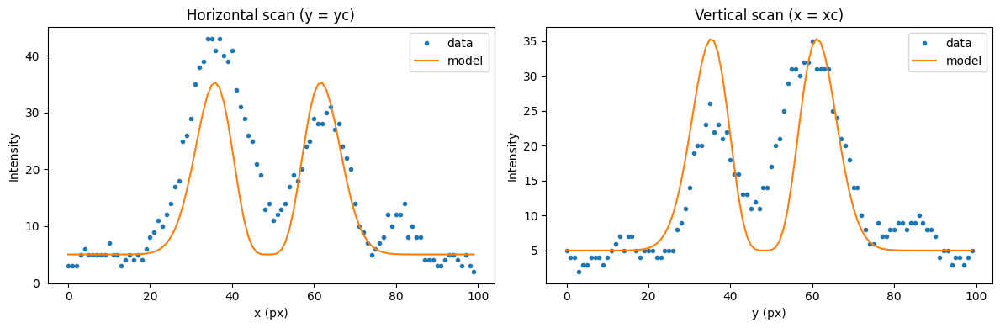

Params: {'A': 0.00783209480716658, 'w': 9.090470879206912, 'xc': 47.09708214579534, 'yc': 48.09804256630314, 'B': 5.750398694263307}
Uncertainties: {'A': 0.0001151217802595151, 'w': 0.02479702170530815, 'xc': 0.05454944444964068, 'yc': 0.05454944445085812, 'B': 0.049042840372238446}
RMSE: 4.477243914223919 R^2: 0.7053437772511463


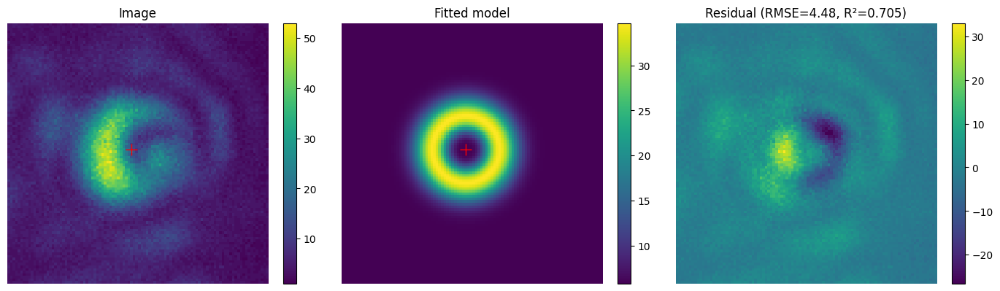

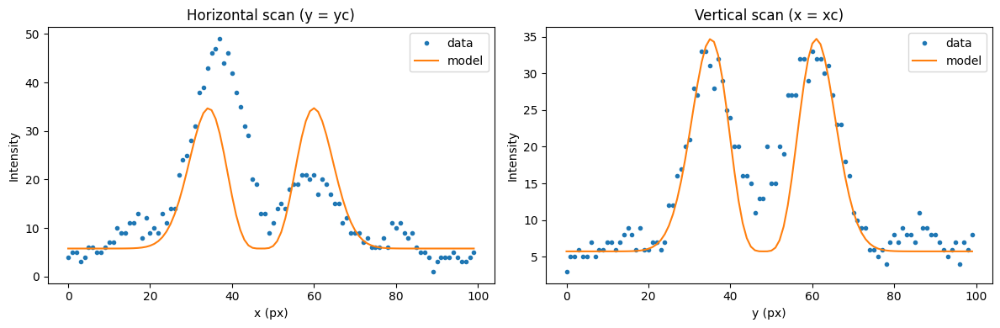

Params: {'A': 0.007898858338030479, 'w': 9.002307770606402, 'xc': 48.17366161676308, 'yc': 48.48229810461685, 'B': 6.445098315514099}
Uncertainties: {'A': 0.00010460718777862869, 'w': 0.022116868076294816, 'xc': 0.048671580522357004, 'yc': 0.04867158051397045, 'B': 0.042362680568160005}
RMSE: 3.8748256654286473 R^2: 0.7473458137186332


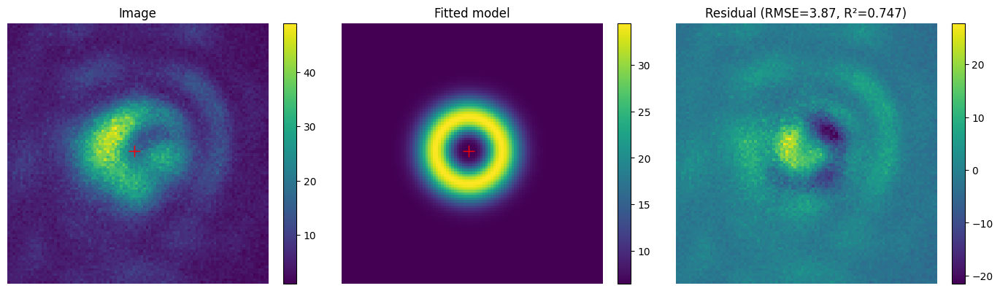

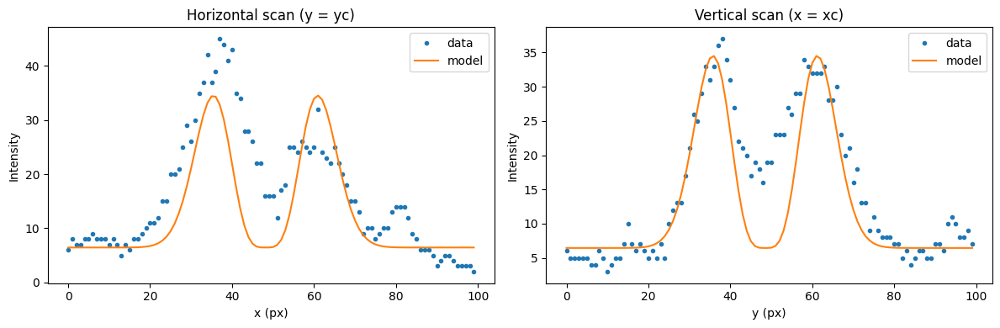

Params: {'A': 0.007433756319780727, 'w': 8.891676915726666, 'xc': 47.357221845763306, 'yc': 49.60805924988649, 'B': 5.5432107268348805}
Uncertainties: {'A': 0.00011444262569015648, 'w': 0.025382678959429313, 'xc': 0.05588400946887948, 'yc': 0.0558840094774486, 'B': 0.04346390070433833}
RMSE: 3.984992803910784 R^2: 0.6872384938579034


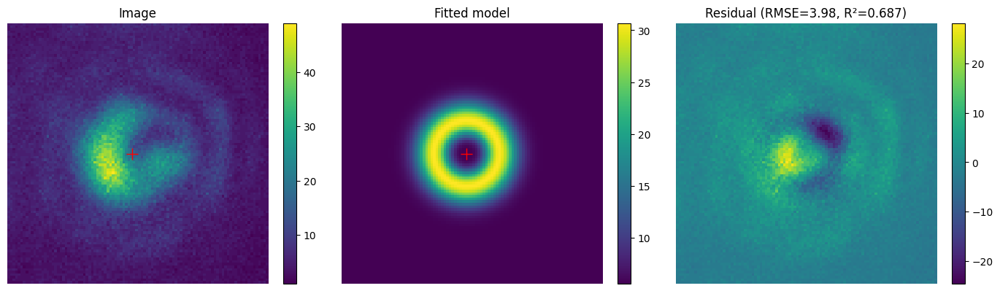

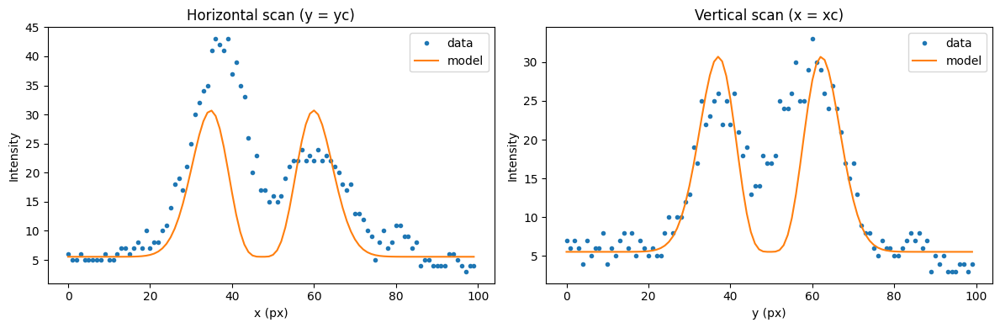

writing phase
Params: {'A': 0.008293404060365767, 'w': 8.938894650753559, 'xc': 49.024355298057486, 'yc': 49.29095752625718, 'B': 4.250728898132688}
Uncertainties: {'A': 0.00012072355068258852, 'w': 0.024132449412581844, 'xc': 0.05312113983948436, 'yc': 0.05312113982113987, 'B': 0.04712714282875403}
RMSE: 4.3165070363934355 R^2: 0.7104585766270426


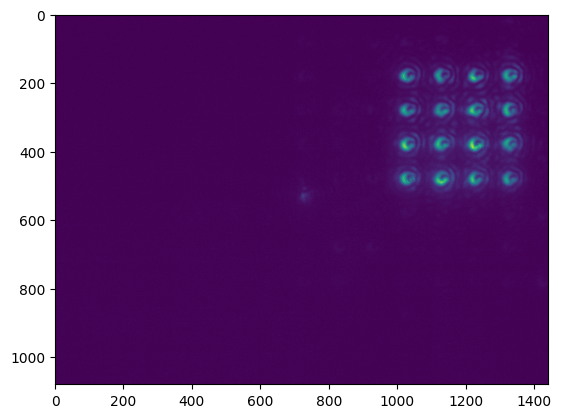

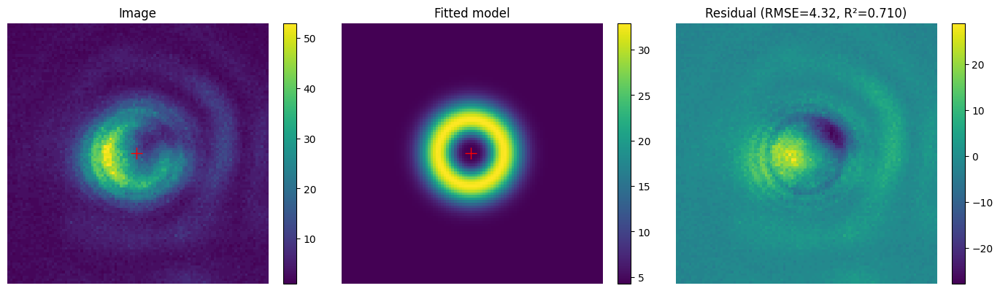

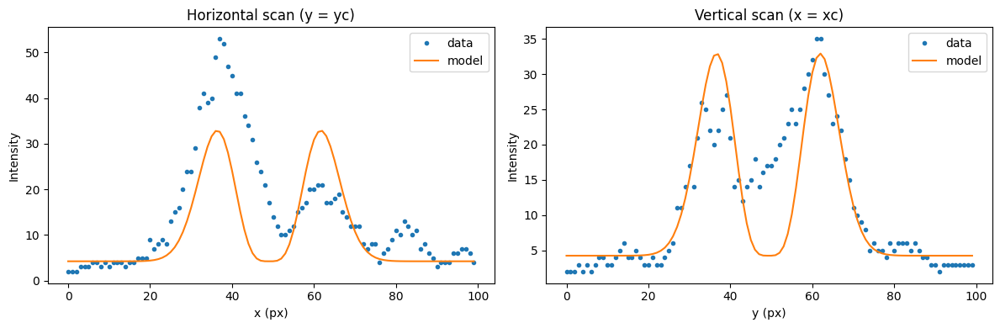

Params: {'A': 0.008498720197968915, 'w': 8.740728498614967, 'xc': 49.054747878366584, 'yc': 49.36643640171966, 'B': 4.98717219287921}
Uncertainties: {'A': 0.00013471794712937562, 'w': 0.025676151005240015, 'xc': 0.05656449922029002, 'yc': 0.05656449921099182, 'B': 0.04681756440538356}
RMSE: 4.30610848787409 R^2: 0.6756642313530297


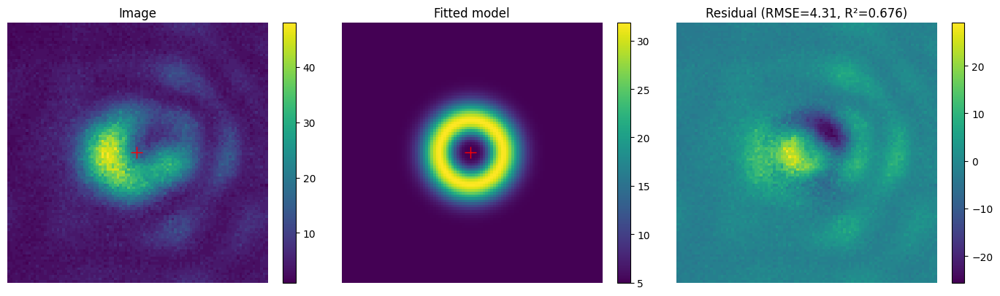

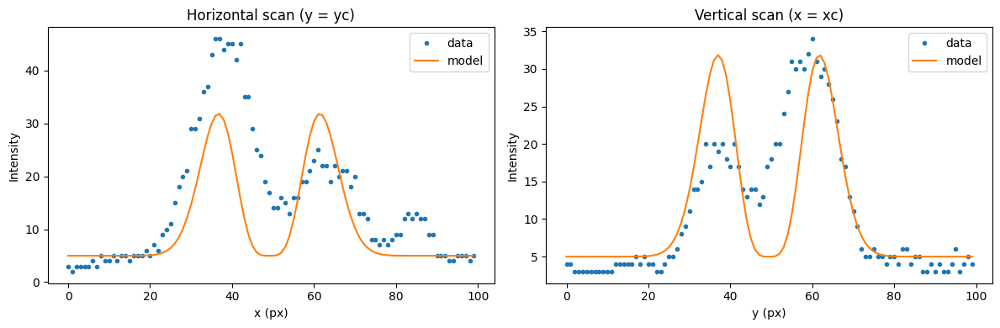

Params: {'A': 0.010540080410236468, 'w': 8.816829478488334, 'xc': 49.023634404448636, 'yc': 49.28644570523736, 'B': 6.512811242747903}
Uncertainties: {'A': 0.00016264820957733386, 'w': 0.025220882823452098, 'xc': 0.05554464497687161, 'yc': 0.05554464496780291, 'B': 0.05912171662933025}
RMSE: 5.429162644767292 R^2: 0.6867723803570023


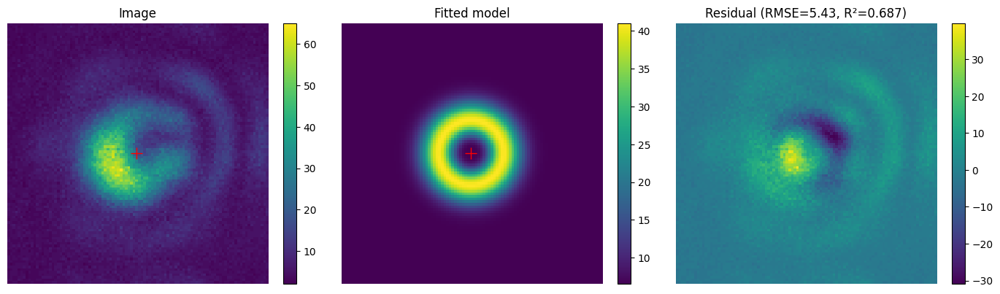

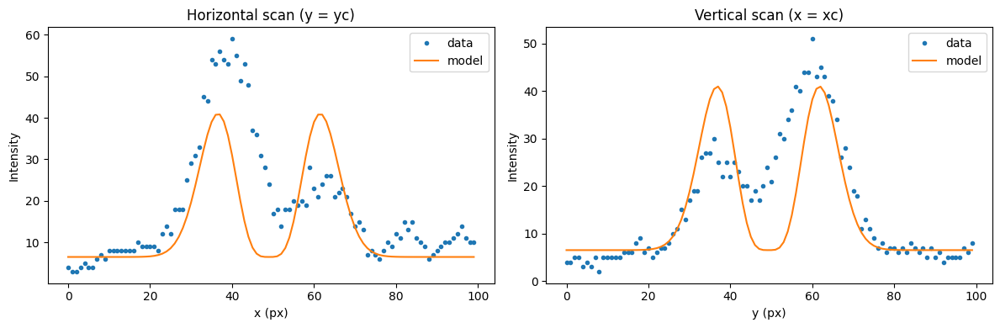

Params: {'A': 0.007466555671426154, 'w': 9.249636933583906, 'xc': 49.49255656961829, 'yc': 48.93848963378302, 'B': 6.22272366127968}
Uncertainties: {'A': 0.00010740879257020836, 'w': 0.0247101490381381, 'xc': 0.0543211060539276, 'yc': 0.0543211060447142, 'B': 0.050082192186758044}
RMSE: 4.556009527960448 R^2: 0.7130589448663345


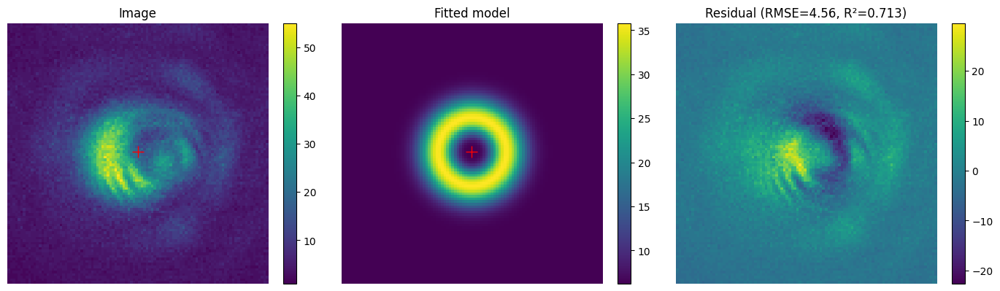

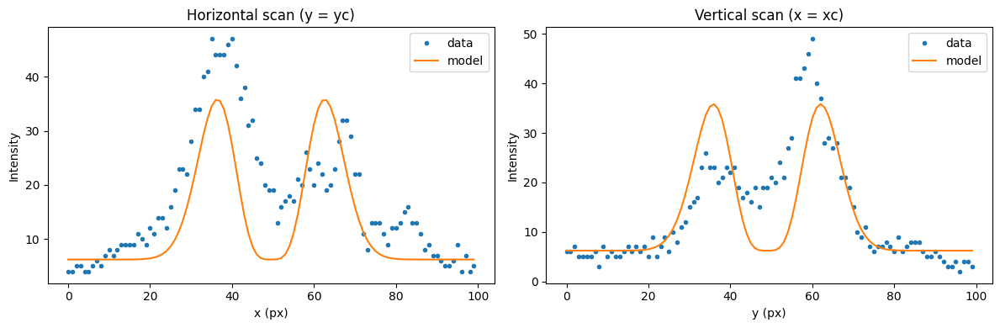

Params: {'A': 0.0059666686284808555, 'w': 9.18557350904146, 'xc': 49.31465642110127, 'yc': 48.80292005895441, 'B': 4.668298187082664}
Uncertainties: {'A': 0.00010287096002963223, 'w': 0.029402039368596224, 'xc': 0.06465342579568616, 'yc': 0.06465342578446895, 'B': 0.04626178346576413}
RMSE: 4.214494934381817 R^2: 0.6342371541563989


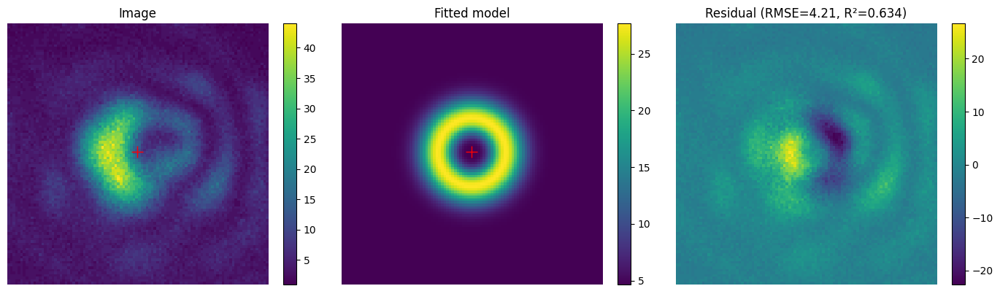

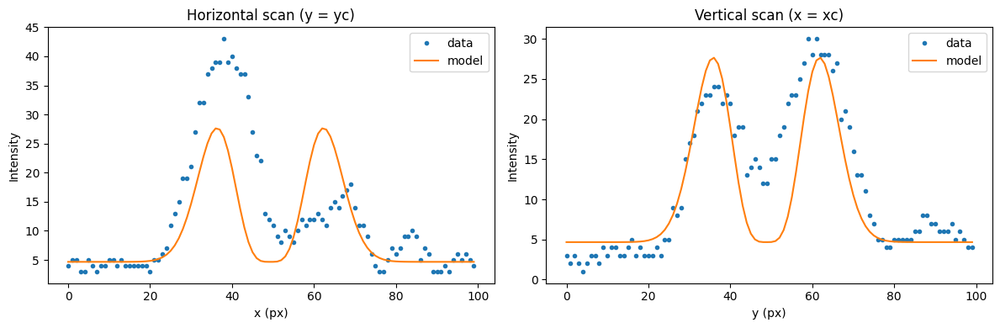

Params: {'A': 0.00769609516865978, 'w': 8.980698572595129, 'xc': 49.34507123152243, 'yc': 48.32444521962538, 'B': 6.064455197907637}
Uncertainties: {'A': 0.0001014650878706347, 'w': 0.021962907887954207, 'xc': 0.04833711403840536, 'yc': 0.048337114028402746, 'B': 0.04058048794806997}
RMSE: 3.7135441713234543 R^2: 0.7491800705407317


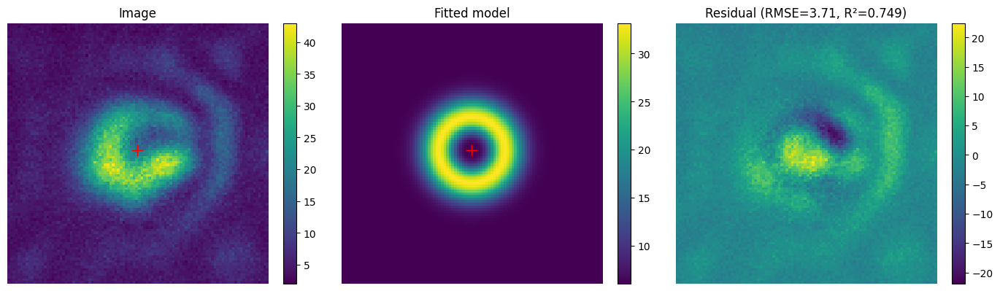

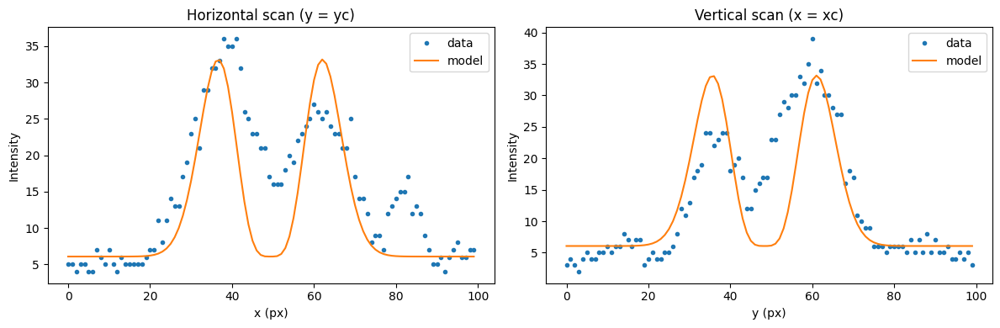

Params: {'A': 0.008887061445609346, 'w': 8.996044839682142, 'xc': 48.81030698330796, 'yc': 47.97811955705124, 'B': 7.268399810224893}
Uncertainties: {'A': 0.0001225143117431377, 'w': 0.023006019718157165, 'xc': 0.05062961724553652, 'yc': 0.05062961723871218, 'B': 0.04943547580168238}
RMSE: 4.522371548179928 R^2: 0.7319326188497546


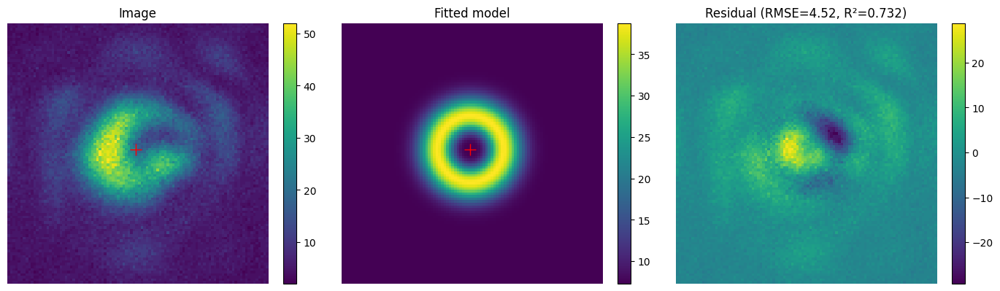

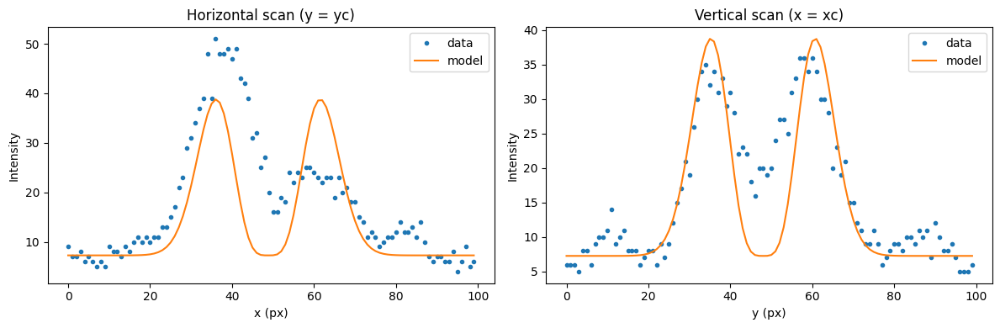

Params: {'A': 0.008512084991535114, 'w': 9.314470792305139, 'xc': 48.64607474712636, 'yc': 48.93420112680144, 'B': 7.624170664796805}
Uncertainties: {'A': 0.00012033770742154262, 'w': 0.02446126562231951, 'xc': 0.05375865053442464, 'yc': 0.053758650530994746, 'B': 0.05818999401965111}
RMSE: 5.285840056687784 R^2: 0.7196480916911867


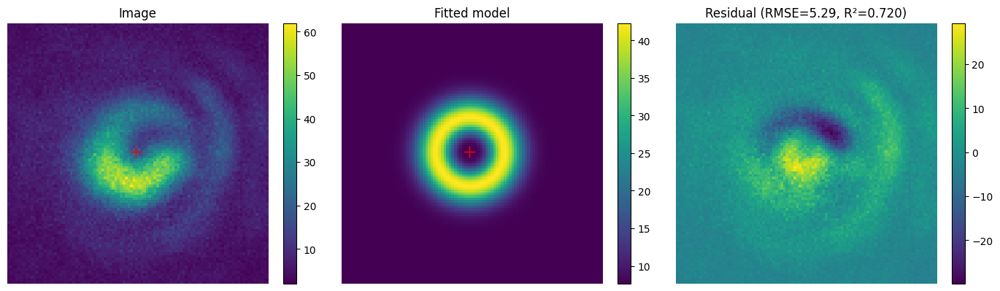

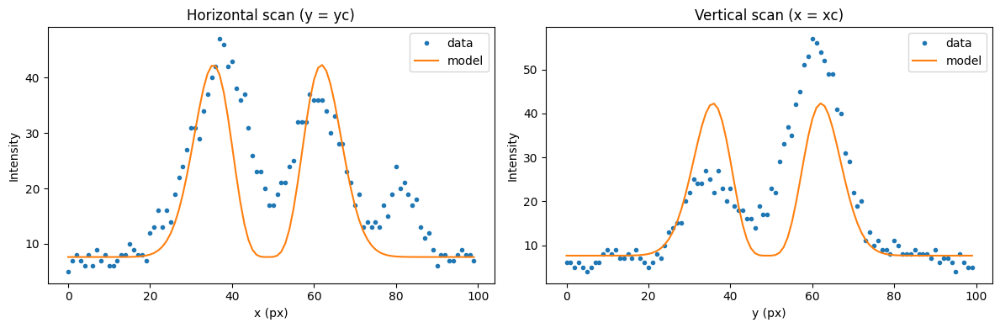

Params: {'A': 0.010076098263488861, 'w': 8.545180240618791, 'xc': 47.827513493883664, 'yc': 49.382454490530016, 'B': 4.7730981587094075}
Uncertainties: {'A': 0.00017835874852060334, 'w': 0.02800933144673665, 'xc': 0.06175151839634749, 'yc': 0.06175151840390428, 'B': 0.055132675589516573}
RMSE: 5.091220569417051 R^2: 0.6270693720537672


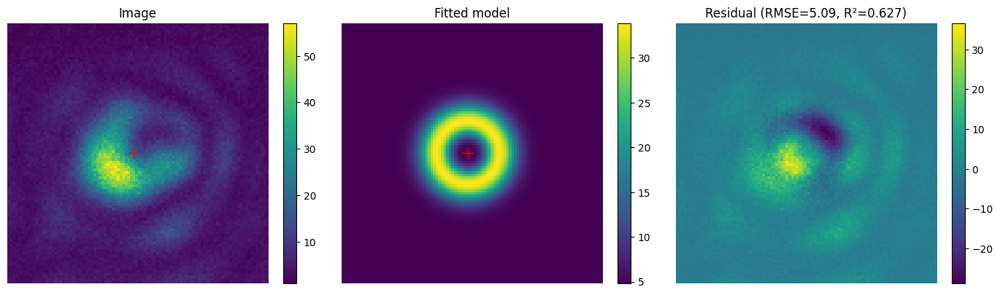

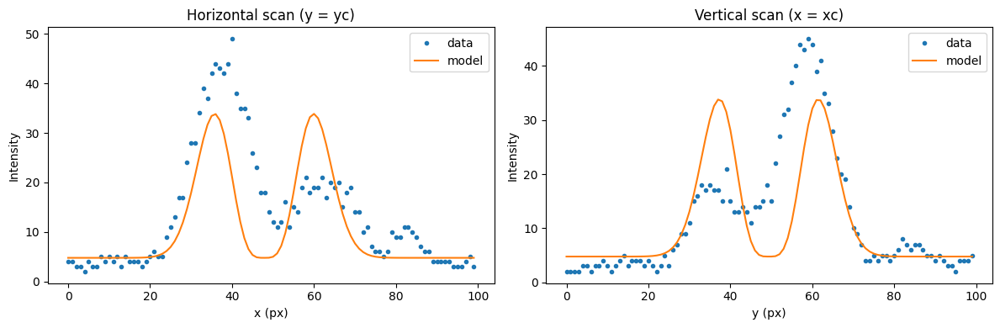

Params: {'A': 0.009808166568931418, 'w': 8.790570364686669, 'xc': 48.17580135867626, 'yc': 48.70774122590062, 'B': 7.1318900217825565}
Uncertainties: {'A': 0.0001559349493445463, 'w': 0.025904150948230766, 'xc': 0.0570554422847201, 'yc': 0.057055442298147935, 'B': 0.05581168693965711}
RMSE: 5.128024539921273 R^2: 0.6739982747773148


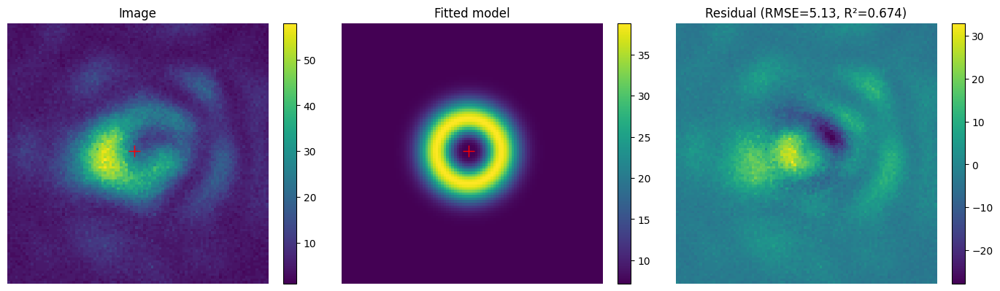

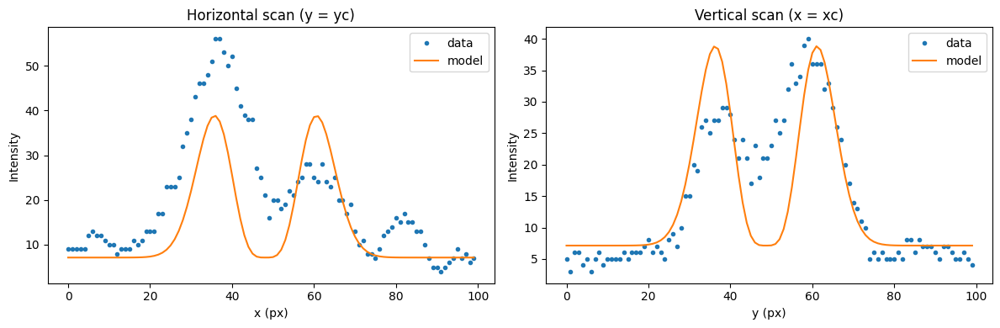

Params: {'A': 0.008876713947383796, 'w': 9.377028118298645, 'xc': 48.437829203376985, 'yc': 48.7602959279042, 'B': 7.476392235275149}
Uncertainties: {'A': 0.0001293727101131448, 'w': 0.02539402434798504, 'xc': 0.055793044467996426, 'yc': 0.05579304446818762, 'B': 0.06478040908815587}
RMSE: 5.876112821671472 R^2: 0.7067227060010963


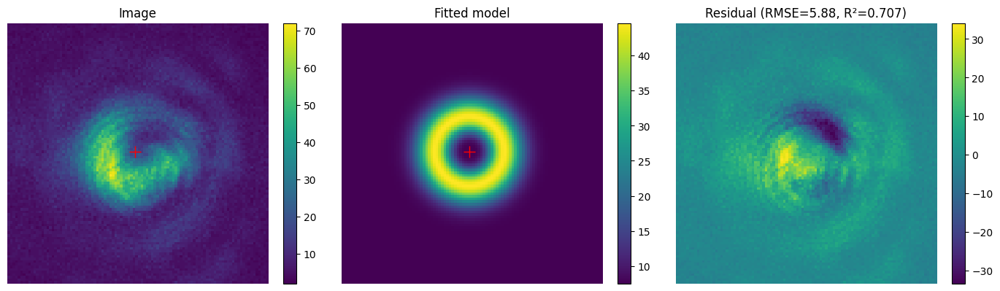

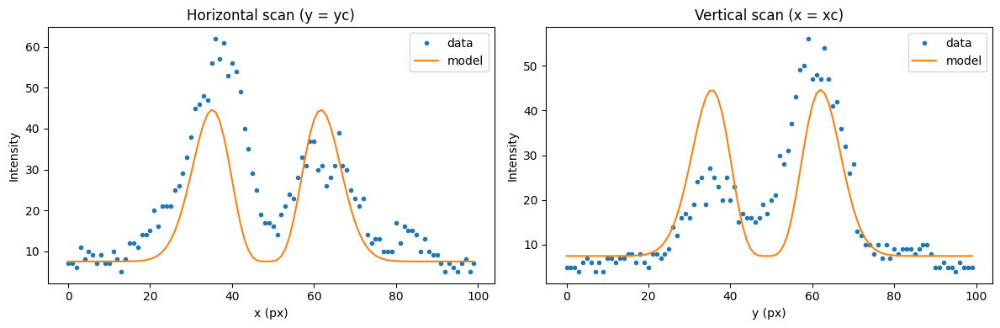

Params: {'A': 0.009420414703280401, 'w': 8.699241667302815, 'xc': 47.690625374371486, 'yc': 49.271964314464235, 'B': 6.975999382679189}
Uncertainties: {'A': 0.0001495160807251499, 'w': 0.025582230994525338, 'xc': 0.05636683754010311, 'yc': 0.056366837530384045, 'B': 0.05069524035269315}
RMSE: 4.6667683260330595 R^2: 0.6754176602813671


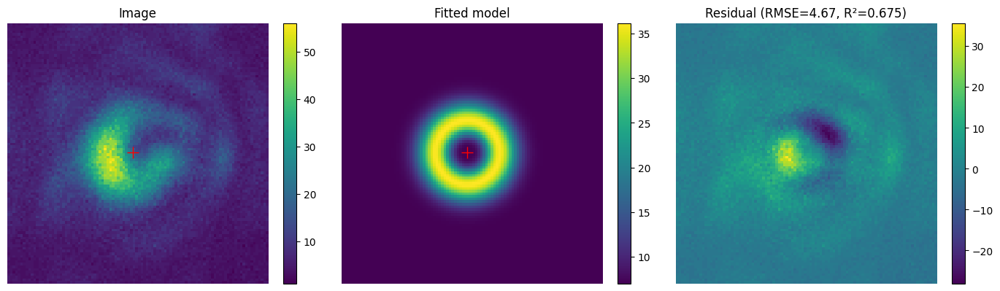

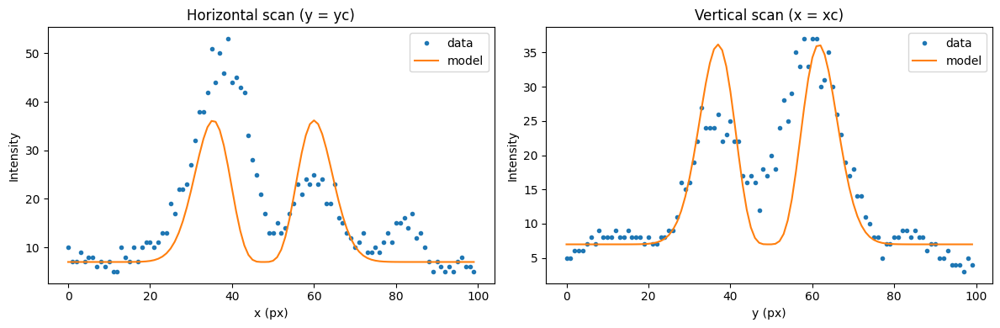

Params: {'A': 0.007991514457895104, 'w': 9.079239376811925, 'xc': 48.459373183338165, 'yc': 48.38068787590705, 'B': 5.139914347883547}
Uncertainties: {'A': 0.00010582669457724686, 'w': 0.022311487486893978, 'xc': 0.04908400588588284, 'yc': 0.049084005865567756, 'B': 0.04479421774753803}
RMSE: 4.090382507003255 R^2: 0.7468625959017299


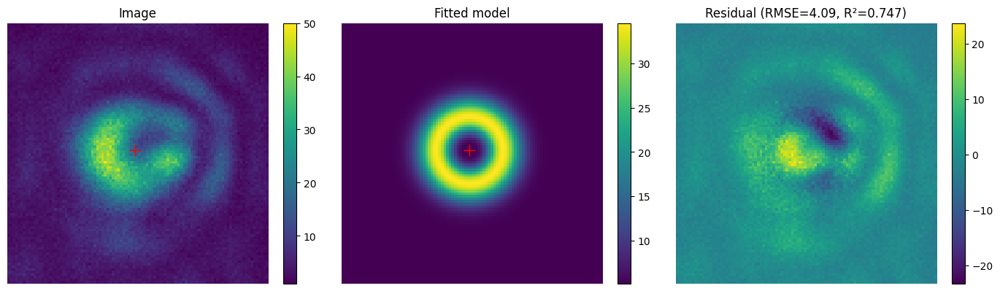

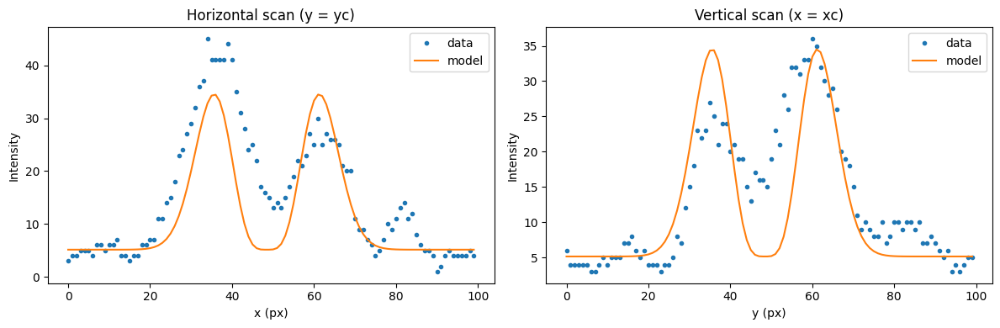

Params: {'A': 0.008132216437516687, 'w': 8.99036243840988, 'xc': 46.61093351831786, 'yc': 48.373455860131486, 'B': 5.796237538577497}
Uncertainties: {'A': 0.0001216652738284121, 'w': 0.024950880188601976, 'xc': 0.05491099336235955, 'yc': 0.05491099336922186, 'B': 0.048932024807837704}
RMSE: 4.476864991134448 R^2: 0.69868226493246


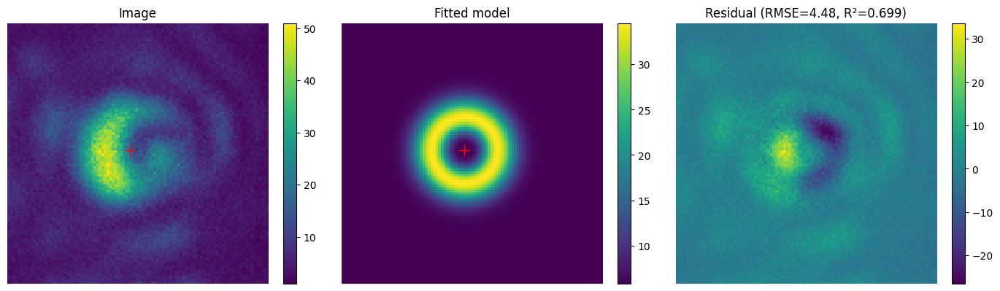

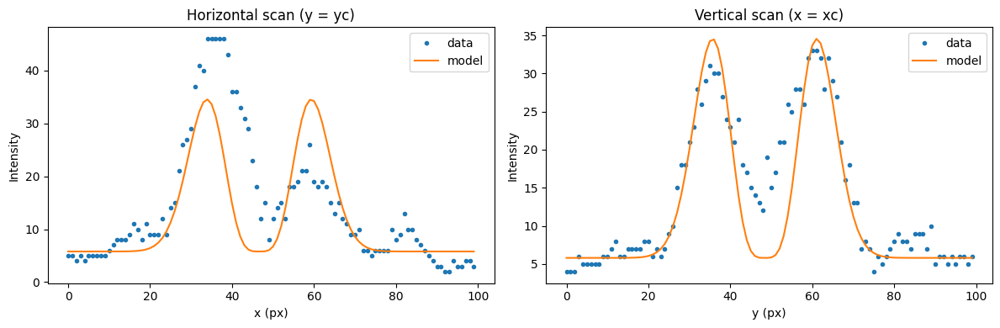

Params: {'A': 0.008318675163491506, 'w': 8.847066578693967, 'xc': 47.680249490825396, 'yc': 48.64753045494944, 'B': 6.571118733821605}
Uncertainties: {'A': 0.00011600450873681977, 'w': 0.02287259818991014, 'xc': 0.050366803561784856, 'yc': 0.05036680356989957, 'B': 0.04292234633366863}
RMSE: 3.9390609914441517 R^2: 0.728415867323863


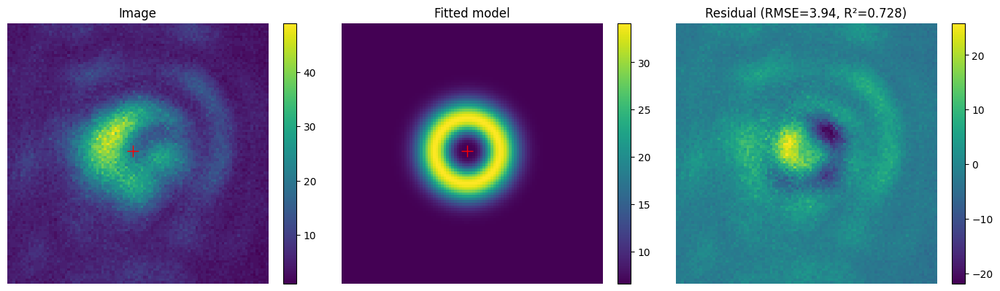

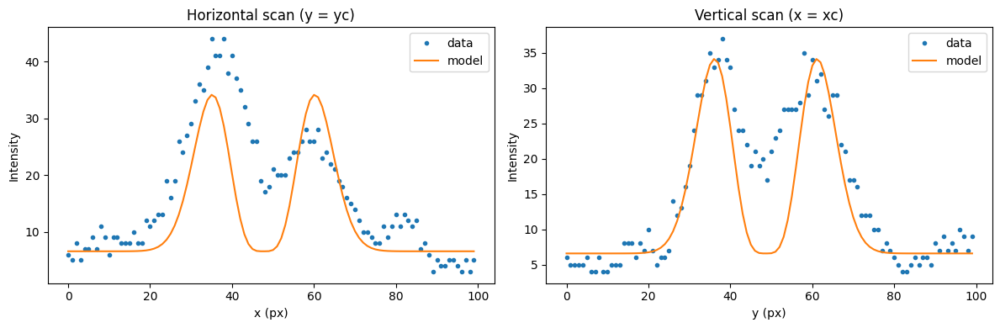

Params: {'A': 0.0074387234719691326, 'w': 8.846044060839088, 'xc': 46.96073096105816, 'yc': 49.706382770187616, 'B': 5.601087549796977}
Uncertainties: {'A': 0.00011746448860852983, 'w': 0.025897090873853668, 'xc': 0.057027149894661365, 'yc': 0.05702714989342014, 'B': 0.04343649931463047}
RMSE: 3.986331775779499 R^2: 0.676561320420632


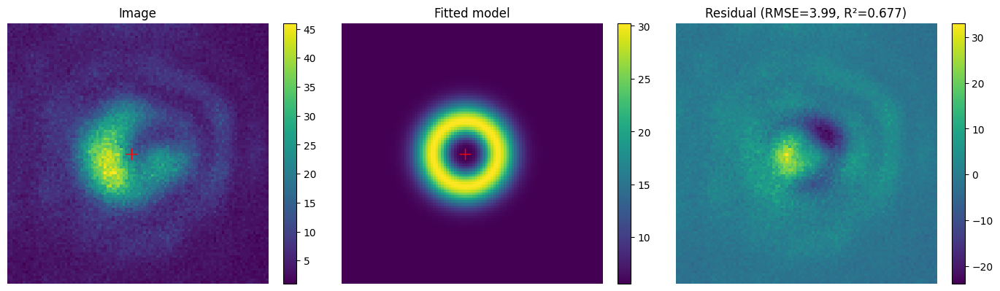

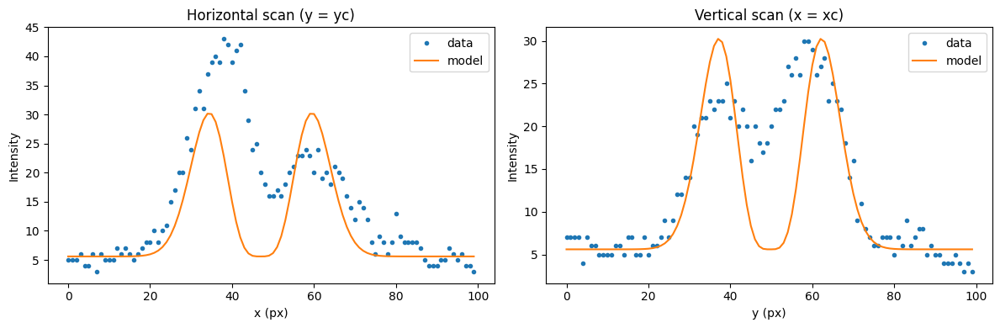

In [162]:
# image: 2D numpy array
# If you have an approximate center (xc,yc), pass it (x=cols, y=rows). Use a patch for robustness/speed.
i = 0
zi = 7
rmses = []
rsquareds = []
for w in np.linspace(-1,1,21):
    image = plot_cam(fs=fs,phase= phase+bottle_beam_phase(fs)+w*zernike(fs.slm, zi,use_mask = False))
    rmse_w = []
    rsquared_w = []
    for i in range(16):
        patch = image[spot_locations[i][1]-50:spot_locations[i][1]+50,spot_locations[i][0]-50:spot_locations[i][0]+50]
        fitres = fit_bottle_beam(patch, patch_size=80)

        print("Params:", fitres["params"])
        print("Uncertainties:", fitres["param_err"])
        print("RMSE:", fitres["rmse"], "R^2:", fitres["r2"])

        plot_fit_overview(patch, fitres)
        plot_line_scans(fitres)
        rmse_w.append(fitres["rmse"])
        rsquared_w.append(fitres["r2"])
        
    rmses.append(rmse_w)
    rsquareds.append(rsquared_w)

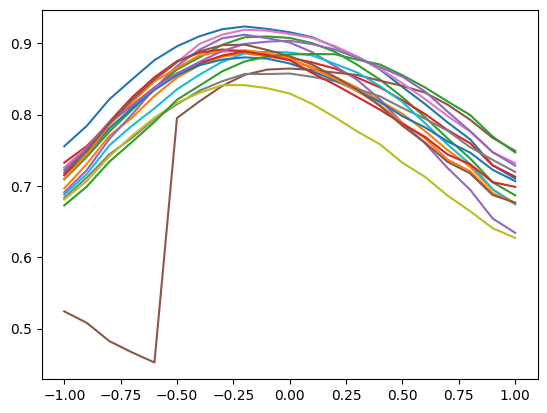

In [163]:
plt.plot(np.linspace(-1,1,21),np.array(rsquareds))

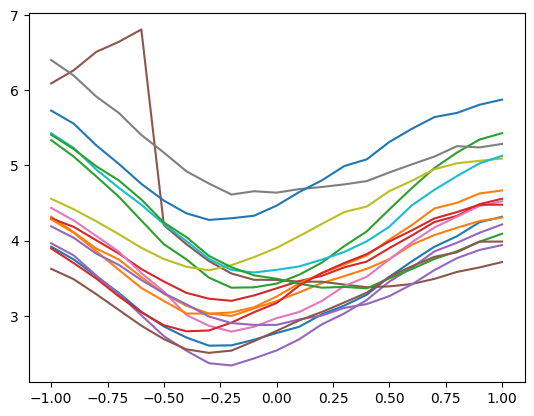

In [164]:
plt.plot(np.linspace(-1,1,21),np.array(rmses))

In [ ]:
plt.plot(np.linspace(-1,1,21),np.array(rmses).T[9])

NameError: name 'rmses' is not defined

In [206]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)])



zernike_calibrations = []
nz = 20
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10,1024+65] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations.append({i+1: float(v) for i, v in enumerate(zernike_arr)})
zernike_indices = [i+1 for i in range(nz)]

In [207]:
zernike_calibrations

[{1: -77.65764114910289,
  2: 83.13297385555853,
  3: 0.0,
  4: 0.0,
  5: 0.0,
  6: 0.0,
  7: 0.0,
  8: 0.0,
  9: 0.0,
  10: 0.0,
  11: 0.0,
  12: 0.0,
  13: 0.0,
  14: 0.0,
  15: 0.0,
  16: 0.0,
  17: 0.0,
  18: 0.0,
  19: 0.0,
  20: 0.0},
 {1: -76.53406807061802,
  2: 59.28491287655021,
  3: 0.0,
  4: 0.0,
  5: 0.0,
  6: 0.0,
  7: 0.0,
  8: 0.0,
  9: 0.0,
  10: 0.0,
  11: 0.0,
  12: 0.0,
  13: 0.0,
  14: 0.0,
  15: 0.0,
  16: 0.0,
  17: 0.0,
  18: 0.0,
  19: 0.0,
  20: 0.0},
 {1: -75.41049499213317,
  2: 35.436851897541885,
  3: 0.0,
  4: 0.0,
  5: 0.0,
  6: 0.0,
  7: 0.0,
  8: 0.0,
  9: 0.0,
  10: 0.0,
  11: 0.0,
  12: 0.0,
  13: 0.0,
  14: 0.0,
  15: 0.0,
  16: 0.0,
  17: 0.0,
  18: 0.0,
  19: 0.0,
  20: 0.0},
 {1: -74.28692191364831,
  2: 11.588790918533554,
  3: 0.0,
  4: 0.0,
  5: 0.0,
  6: 0.0,
  7: 0.0,
  8: 0.0,
  9: 0.0,
  10: 0.0,
  11: 0.0,
  12: 0.0,
  13: 0.0,
  14: 0.0,
  15: 0.0,
  16: 0.0,
  17: 0.0,
  18: 0.0,
  19: 0.0,
  20: 0.0},
 {1: -101.75377388330543,
  2: 81.

In [212]:
zcnew = [{7:2.5} for i in range(len(zernike_calibrations))]
zernike_calibrations = [{k: d1[k] -  d2.get(k, 0) for k in d1} for d1, d2 in zip(zernike_calibrations, zcnew)]

In [213]:
phase = get_cholo_phase(zernike_calibrations=zernike_calibrations,fs = fs)

In [214]:
zi = 7
rmses = []
rsquareds = []
for w in np.linspace(-1,1,21):
    image = get_cam(fs=fs,phase= phase+bottle_beam_phase(fs)+w*zernike(fs.slm, zi,use_mask = False))
    rmse_w = []
    rsquared_w = []
    for i in range(16):
        patch = image[spot_locations[i][1]-50:spot_locations[i][1]+50,spot_locations[i][0]-50:spot_locations[i][0]+50]
        fitres = fit_bottle_beam(patch, patch_size=80)

        # print("Params:", fitres["params"])
        # print("Uncertainties:", fitres["param_err"])
        # print("RMSE:", fitres["rmse"], "R^2:", fitres["r2"])

        # plot_fit_overview(patch, fitres)
        # plot_line_scans(fitres)
        rmse_w.append(fitres["rmse"])
        rsquared_w.append(fitres["r2"])
        
    rmses.append(rmse_w)
    rsquareds.append(rsquared_w)

writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase


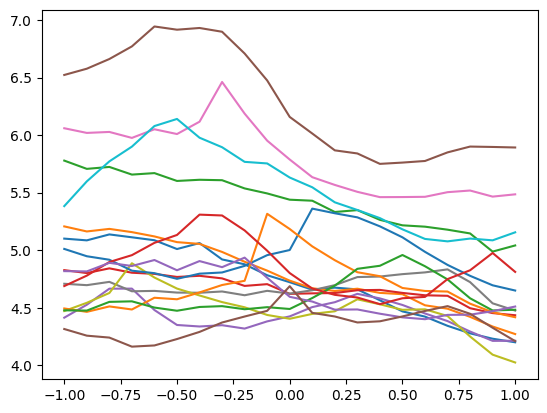

In [215]:
plt.plot(np.linspace(-1,1,21),rmses)

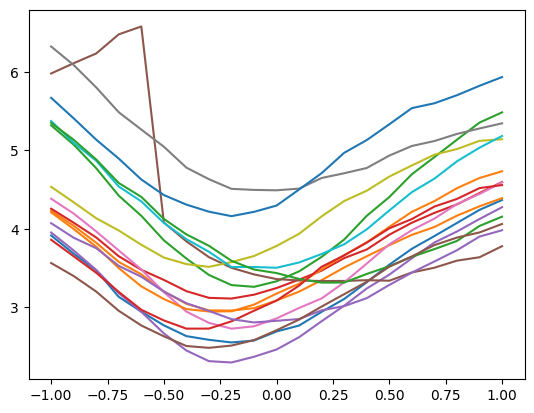

In [210]:
# no corr
plt.plot(np.linspace(-1,1,21),rmses)

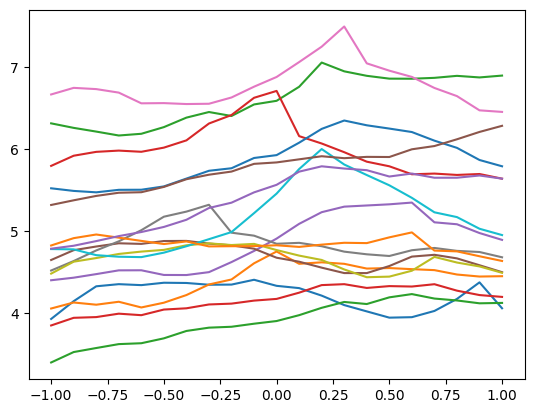

In [ ]:
plt.plot(np.linspace(-1,1,21),rmses)

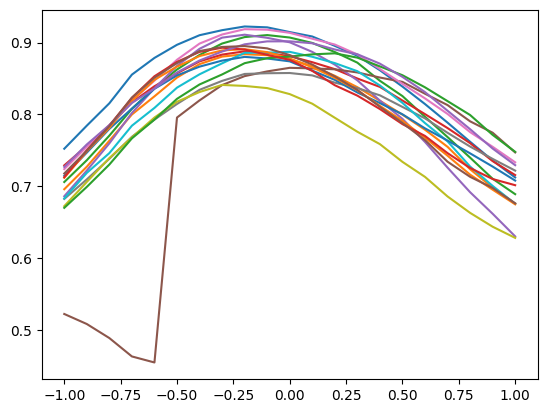

In [211]:
#old
plt.plot(np.linspace(-1,1,21),rsquareds)

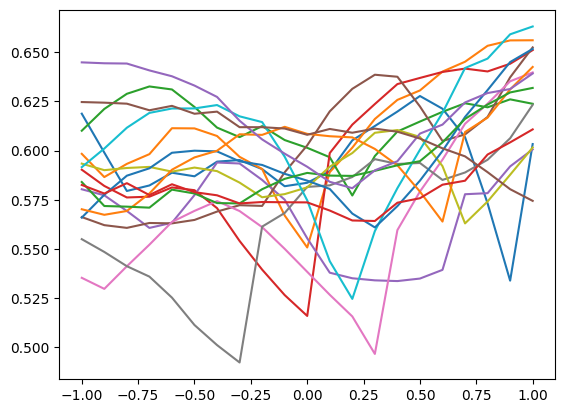

In [201]:
plt.plot(np.linspace(-1,1,21),rsquareds)

# Bayesian opt for bottle beam

In [29]:
# ! pip install scikit-optimize

In [315]:
import numpy as np
np.random.seed(237)
import matplotlib.pyplot as plt
from skopt.plots import plot_gaussian_process

In [316]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)])



zernike_calibrations = []
nz = 10
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10-20,1024+65+20] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations.append({i+1: float(v) for i, v in enumerate(zernike_arr)})
zernike_indices = [i+1 for i in range(nz)]

In [ ]:
s = 9
base_phase = get_cholo_phase(zernike_calibrations=zernike_calibrations,fs = fs) + bottle_beam_phase(fs)
best = -1

In [318]:
def f(x): 
    zernike_list = [i for i in range(3,nz+1)]
    # zernike_list = [4]
    phase = base_phase + zernike_sum(fs,tuple(zernike_list),tuple(x),use_mask = False)
    image = get_cam(fs=fs,phase = phase)
    patch = image[spot_locations[s][1]-50:spot_locations[s][1]+50,spot_locations[s][0]-50:spot_locations[s][0]+50]
    fitres = fit_bottle_beam(patch, patch_size=80)
    print(fitres['r2'])
    return -fitres["r2"]

In [319]:
from skopt import gp_minimize
from skopt.learning import GaussianProcessRegressor
from skopt.learning.gaussian_process.kernels import Matern, WhiteKernel,RationalQuadratic
res = gp_minimize(f,                  # the function to minimize
                  [(-1.0, 1.0) for i in range(nz-2)],      # the bounds on each dimension of x
                  acq_func="LCB",      # the acquisition function
                  base_estimator = GaussianProcessRegressor(kernel=1**2 * RationalQuadratic(length_scale=1.0, alpha=0.1) + WhiteKernel(noise_level=0.01),
                        n_restarts_optimizer=2, noise=0.1,
                        normalize_y=True, random_state=822569775),
                  x0 = [0.0 for i in range(nz-2)],
                  n_calls=500,         # the number of evaluations of f
                  n_initial_points=1,  # the number of random initialization points
                  noise=0.1,       # the noise level (optional)
                  random_state=1234)

writing phase
0.9083897519431949
writing phase
0.7479424212904131
writing phase
0.870679232418914
writing phase
0.8863465606715958
writing phase
0.7955550027095797
writing phase
0.8874830320371447
writing phase
0.909197263402741
writing phase
0.8426497256635217
writing phase
0.8744540988231496
writing phase
0.8987988267211895
writing phase
0.4900813187568749
writing phase
0.5457384218551145
writing phase
0.7836668140229821
writing phase
0.8553406527568618
writing phase
0.8605493055324043
writing phase
0.868714188643346
writing phase
0.8697165721653406
writing phase
0.8719599100607667
writing phase
0.8403362287974816
writing phase
0.9019861893938709
writing phase
0.7949761947210363
writing phase
0.906272203668713
writing phase
0.8983410485745998
writing phase
0.8924244643656106
writing phase
0.9197954131086168
writing phase
0.8557009936503279
writing phase
0.8888186214881897
writing phase
0.9224618238299679
writing phase
0.9094505502821765
writing phase
0.6589653005108767
writing phase


In [173]:
f([0.0 for i in range(nz-2)]),f(res['x'])

writing phase
0.914934540255725
writing phase
0.9407448333002902


(-0.914934540255725, -0.9407448333002902)

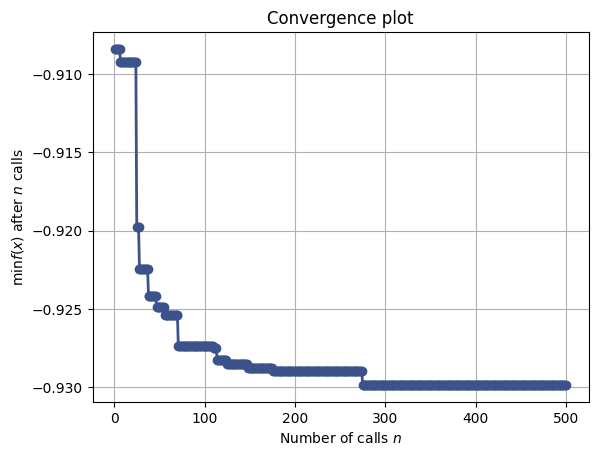

In [331]:
from skopt.plots import plot_convergence
plot_convergence(res);

In [170]:
from pathlib import Path
from skopt import dump, load

save_dir = Path(base_path) / "data" / "zernike" / "raw"
save_dir.mkdir(parents=True, exist_ok=True)
save_path = save_dir / "gp_500_25z.skopt"

# save without the objective function
dump(res, save_path, store_objective=False)

# load later
res3 = load(save_path)

# (optional) resume optimization later
# res2 has x_iters and func_vals:
# res_cont = gp_minimize(f, space, x0=res2.x_iters, y0=res2.func_vals, n_calls=50)


In [150]:
res['x']

[0.307577893294279,
 0.07452123955746726,
 -0.4846132349254517,
 0.03621326038583583,
 -0.31850003759186585,
 0.08384704320086755,
 0.26004944723851153,
 -0.06818263415750725]

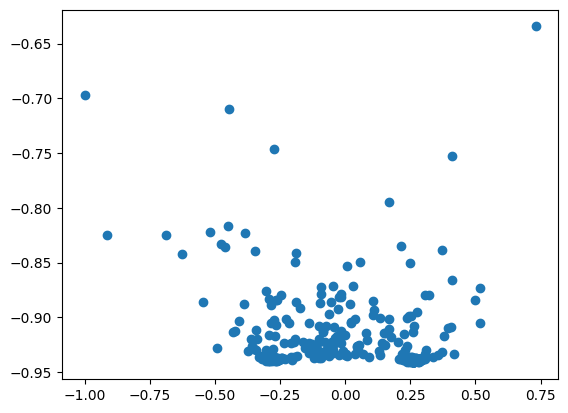

In [155]:
plt.scatter(np.array(res['x_iters']).T[6],res['func_vals'])

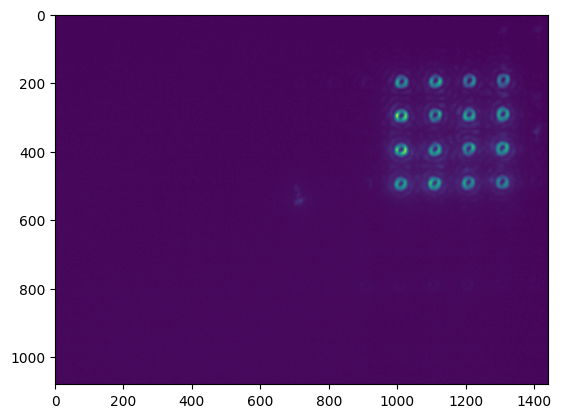

In [47]:
plt.imshow(image)

In [71]:
spot_locations[5]

array([1130,  280])

In [130]:
fs.slm.get_source_center()

array([642.431399  , 519.73373254])

In [135]:
1024/1280

0.8

In [178]:
1.25**2

1.5625

In [40]:
def bottle_beam_phase(fs):
    ro = 220
    return np.array([[np.pi if ((i-fs.slm.get_source_center()[1])**2/1.2 + (j-fs.slm.get_source_center()[0])**2) <= ro**2 else 0 for j in range(1280)] for i in range(1024)])

In [41]:
base_phase = get_cholo_phase(zernike_calibrations=zernike_calibrations,fs = fs) + bottle_beam_phase(fs)

NameError: name 'zernike_calibrations' is not defined

writing phase


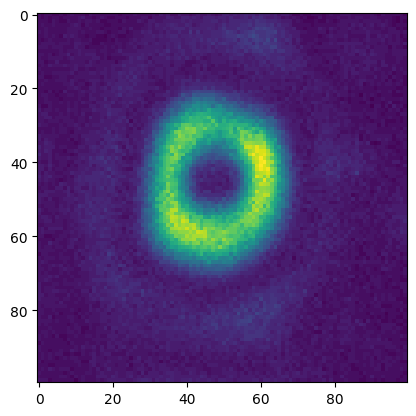

In [42]:
s = 9
# phase = base_phase #+ zernike_sum(fs,tuple([i for i in range(3,nz+1)]),tuple(res['x']),use_mask = False)
phase = phi_nf_gs.numpy()+bottle_beam_phase(fs=fs)
image = get_cam(fs=fs,phase = phase)
patch = image[spot_locations[s][1]-50:spot_locations[s][1]+50,spot_locations[s][0]-50:spot_locations[s][0]+50]
plt.imshow(patch)

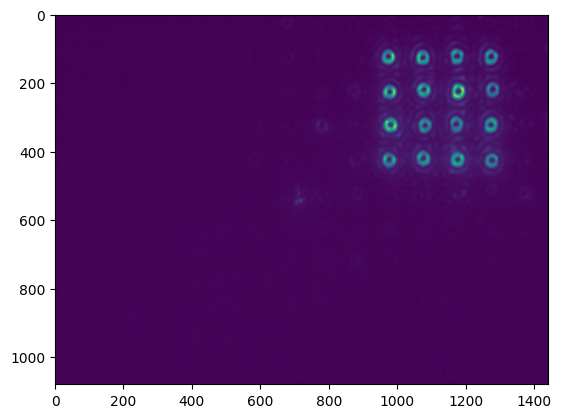

In [43]:
plt.imshow(image)

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import center_of_mass, map_coordinates

# bottle-beam model over an (x,y) grid
def bbn(xy, A, w, xc, yc, B):
    x, y = xy
    r2 = (x - xc)**2 + (y - yc)**2
    return B + A * (r2**2) * np.exp(-r2 / (w**2))  # r^4 = (r^2)^2

def fit_bottle_beam(
    img,
    top_percentile_for_peak=99.5,
    n_ring_samples=720,
    n_line_samples=1024,
    make_plots=True
):
    img = np.asarray(img, dtype=float)
    H, W = img.shape
    yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing="ij")  # rows, cols

    # ---- initial guesses ----
    B0 = np.median(img)
    thresh = np.percentile(img, top_percentile_for_peak)
    weights = np.clip(img - B0, 0, None) * (img >= thresh)
    if weights.sum() == 0:
        weights = np.clip(img - B0, 0, None) + 1e-12
    yc0, xc0 = H/2,W/2
    yc0 = np.nan_to_num(yc0, nan=H/2)
    xc0 = np.nan_to_num(xc0, nan=W/2)

    # coarse radial profile to locate initial peak radius
    r = np.sqrt((xx - xc0)**2 + (yy - yc0)**2)
    r_int = r.astype(int)
    r_max_possible = int(np.ceil(r.max()))
    sums   = np.bincount(r_int.ravel(), weights=img.ravel(), minlength=r_max_possible+1)
    counts = np.bincount(r_int.ravel(), minlength=r_max_possible+1)
    radial_profile = sums / np.maximum(counts, 1)
    r_peak0 = int(np.nanargmax(radial_profile))
    w0 = max(r_peak0 / np.sqrt(2), 1.0)
    I_peak = radial_profile[r_peak0]
    A0 = max((I_peak - B0) / ( (r_peak0**4) * np.exp(-(r_peak0**2)/(w0**2)) + 1e-12 ), 1e-6)
    p0 = [A0, w0, xc0, yc0, B0]

    # sane bounds
    lower = [0.0,  1e-3,         0.0,     0.0,     np.min(img)-abs(np.ptp(img))]
    upper = [np.inf, max(H, W),  W-1+0.5, H-1+0.5, np.max(img)+abs(np.ptp(img))]

    # ---- fit ----
    print(p0)
    popt, pcov = curve_fit(
        bbn,
        (xx.ravel(), yy.ravel()),
        img.ravel(),
        p0=p0, bounds=(lower, upper), maxfev=20000
    )
    A, w, xc, yc, B = popt
    r_peak = np.sqrt(2) * w

    if make_plots:
        # 1) image with center + peak ring
        fig1, ax1 = plt.subplots(figsize=(5.5, 5))
        im = ax1.imshow(img, origin="upper", aspect="equal")
        ax1.scatter([xc], [yc], s=60, edgecolor="white", facecolor="none", linewidth=1.5, label="Center")
        th = np.linspace(0, 2*np.pi, 400)
        ax1.plot(xc + r_peak*np.cos(th), yc + r_peak*np.sin(th), 'w--', lw=1.2, label="Peak ring")
        ax1.set_title("Fit: center & peak ring")
        ax1.set_xlim(0, W-1); ax1.set_ylim(H-1, 0)
        ax1.legend(loc="lower right"); fig1.colorbar(im, ax=ax1, shrink=0.85)
        plt.tight_layout()

        # 2) radial profile (data vs model)
        r_bins = np.arange(0, int(np.ceil(r.max())) + 1).astype(float)
        model_profile = B + A * (r_bins**4) * np.exp(-(r_bins**2)/(w**2))
        fig2, ax2 = plt.subplots(figsize=(6.5, 4))
        ax2.plot(r_bins, radial_profile[:len(r_bins)], label="Data (azimuthal avg)")
        ax2.plot(r_bins, model_profile, '--', label="Model fit")
        ax2.axvline(r_peak, linestyle=':', lw=1, label=f"r_peak ≈ {r_peak:.2f}")
        ax2.set_xlabel("Radius (px)"); ax2.set_ylabel("Intensity"); ax2.set_title("Radial profile")
        ax2.legend(); ax2.grid(True, alpha=0.3); plt.tight_layout()

        # 3) ring scan at r = r_peak
        theta = np.linspace(0, 2*np.pi, n_ring_samples, endpoint=False)
        x_ring = xc + r_peak * np.cos(theta)
        y_ring = yc + r_peak * np.sin(theta)
        ring_vals = map_coordinates(img, [y_ring, x_ring], order=1, mode="nearest")
        fig3, ax3 = plt.subplots(figsize=(7.5, 3.5))
        ax3.plot(np.degrees(theta), ring_vals)
        ax3.set_xlim(0, 360)
        ax3.set_xlabel("Angle (deg)"); ax3.set_ylabel("Intensity")
        ax3.set_title("Ring scan at peak radius")
        ax3.grid(True, alpha=0.3)
        mu, std = np.mean(ring_vals), np.std(ring_vals)
        ax3.text(0.01, 0.95, f"mean={mu:.3g}, std={std:.3g}, CV={std/max(mu,1e-12):.2%}",
                 transform=ax3.transAxes, va="top")
        plt.tight_layout()

        # 4) X-scan through center (y = yc)
        x_line = np.linspace(0, W-1, n_line_samples)
        y_line = np.full_like(x_line, yc, dtype=float)
        x_scan = map_coordinates(img, [y_line, x_line], order=1, mode="nearest")
        # model along x: r^2 = (x-xc)^2
        dx = x_line - xc
        x_model = B + A * (dx**4) * np.exp(-(dx**2)/(w**2))
        fig4, ax4 = plt.subplots(figsize=(7.5, 3.5))
        ax4.plot(x_line, x_scan, label="Data")
        ax4.plot(x_line, x_model, '--', label="Model")
        ax4.set_xlabel("x (px)"); ax4.set_ylabel("Intensity")
        ax4.set_title("X-scan through fitted center")
        ax4.grid(True, alpha=0.3); ax4.legend(); plt.tight_layout()

        # 5) Y-scan through center (x = xc)
        y_line2 = np.linspace(0, H-1, n_line_samples)
        x_line2 = np.full_like(y_line2, xc, dtype=float)
        y_scan = map_coordinates(img, [y_line2, x_line2], order=1, mode="nearest")
        dy = y_line2 - yc
        y_model = B + A * (dy**4) * np.exp(-(dy**2)/(w**2))
        fig5, ax5 = plt.subplots(figsize=(7.5, 3.5))
        ax5.plot(y_line2, y_scan, label="Data")
        ax5.plot(y_line2, y_model, '--', label="Model")
        ax5.set_xlabel("y (px)"); ax5.set_ylabel("Intensity")
        ax5.set_title("Y-scan through fitted center")
        ax5.grid(True, alpha=0.3); ax5.legend(); plt.tight_layout()

    return dict(A=A, w=w, xc=xc, yc=yc, B=B, r_peak=r_peak)

# usage:
# params = fit_bottle_beam(img, make_plots=True)
# print(params)


[0.005864281665733185, 9.899494936611665, 50.0, 50.0, 5.0]
{'A': 0.008159118862817396, 'w': 9.647836534007922, 'xc': 47.704008040847306, 'yc': 45.549017629132415, 'B': 4.483592776557029, 'r_peak': 13.64410127395264}


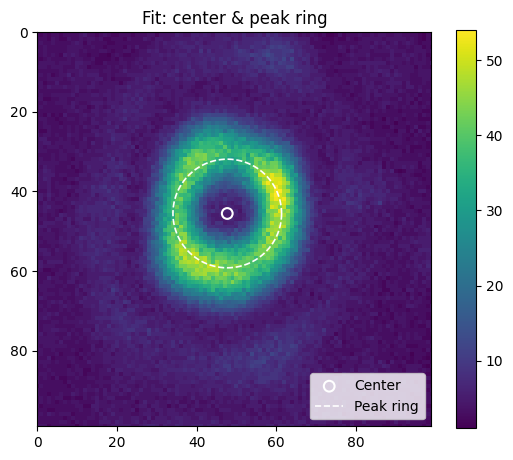

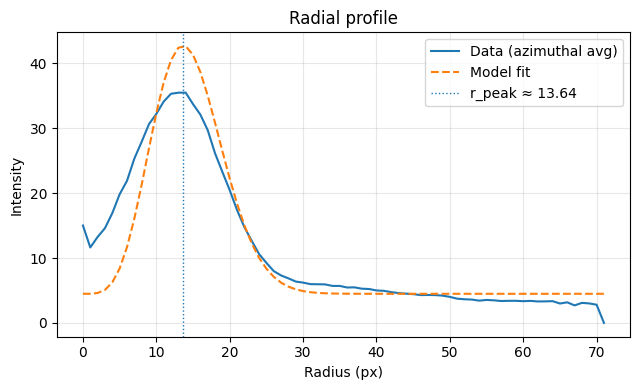

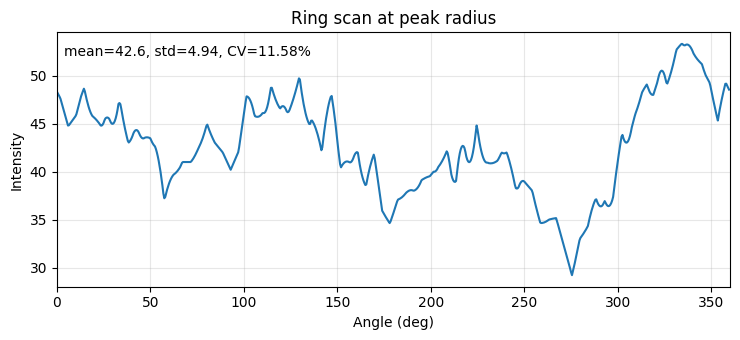

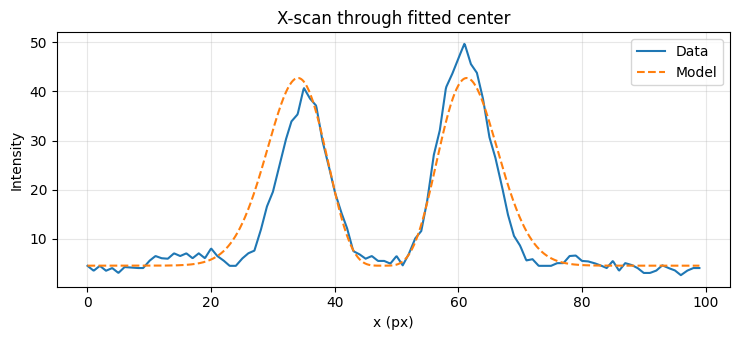

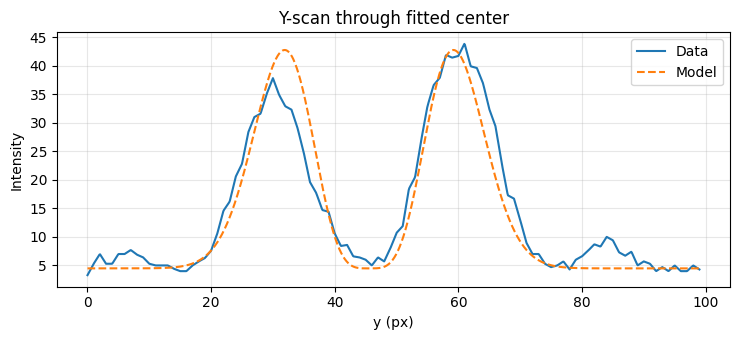

In [45]:
params = fit_bottle_beam(patch, make_plots=True)
print(params)

In [325]:
ZERNIKE_NAMES

['Piston',
 'Vertical tilt',
 'Horizontal tilt',
 'Oblique astigmatism',
 'Defocus',
 'Vertical astigmatism',
 'Vertical trefoil',
 'Vertical coma',
 'Horizontal coma',
 'Oblique trefoil',
 'Oblique quadrafoil',
 'Oblique secondary astigmatism',
 'Spherical aberration',
 'Vertical secondary astigmatism',
 'Vertical quadrafoil',
 'Vertical pentafoil',
 'Vertical secondary trefoil',
 'Vertical secondary coma',
 'Horizontal secondary coma',
 'Oblique secondary trefoil',
 'Oblique pentafoil',
 'Oblique hexafoil',
 'Oblique secondary quadrafoil',
 'Oblique trinary astigmatism',
 'Secondary spherical aberration',
 'Vertical trinary astigmatism',
 'Vertical secondary quadrafoil',
 'Vertical hexafoil']

In [326]:
x = [ZERNIKE_NAMES[i] if i <len(ZERNIKE_NAMES) else f'Z_{i}' for i in range(3,nz+1)]
y = res2['x']

NameError: name 'res2' is not defined

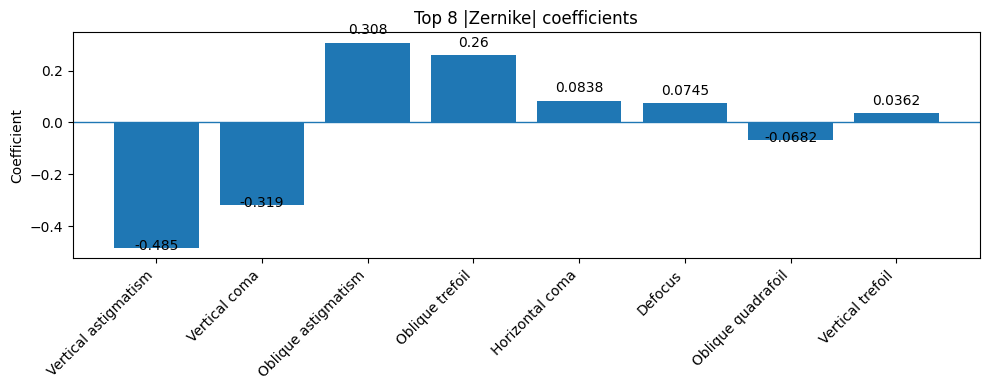

In [211]:
import numpy as np
import matplotlib.pyplot as plt

# x: list of names (for indices 3..nz)
# y: coefficients from res['x']
y = np.asarray(y, dtype=float)

# align lengths just in case
n = min(len(x), len(y))
x = x[:n]
y = y[:n]

# choose how many to show
top_k = 12  # change as you like

# indices of top-|coeff| entries
idx = np.argsort(-np.abs(y))[:top_k]
x_top = [x[i] for i in idx]
y_top = y[idx]

plt.figure(figsize=(10, 4))
plt.bar(range(len(y_top)), y_top)
plt.axhline(0, linewidth=1)
plt.xticks(range(len(x_top)), x_top, rotation=45, ha="right")
plt.ylabel("Coefficient")
plt.title(f"Top {len(y_top)} |Zernike| coefficients")
plt.tight_layout()

# annotate bar values
for i, v in enumerate(y_top):
    plt.text(i, v + (0.02 * np.sign(v) if v != 0 else 0.02), f"{v:.3g}", ha="center", va="bottom")

plt.show()


writing phase


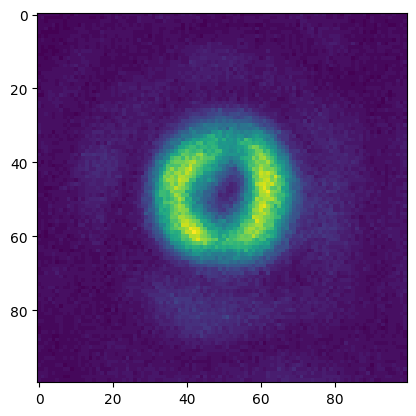

In [152]:
phase = base_phase + zernike_sum(fs,tuple([i for i in range(3,nz+1)]),tuple(res['x']),use_mask = False)
image = get_cam(fs=fs,phase = phase)
patch = image[spot_locations[s][1]-50:spot_locations[s][1]+50,spot_locations[s][0]-50:spot_locations[s][0]+50]
plt.imshow(patch)

writing phase


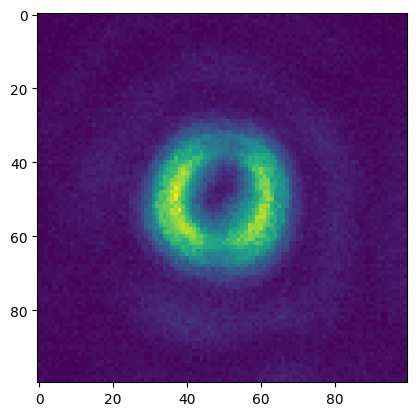

In [232]:
phase = base_phase
image = get_cam(fs=fs,phase = phase)
patch = image[spot_locations[s][1]-50:spot_locations[s][1]+50,spot_locations[s][0]-50:spot_locations[s][0]+50]
plt.imshow(patch)

In [322]:
params = fit_bottle_beam(patch, make_plots=True)
print(params)

TypeError: fit_bottle_beam() got an unexpected keyword argument 'make_plots'

In [ ]:
res[]

[0.060713296949333806,
 -0.060685519055637904,
 0.12693946404982048,
 -0.07939892332073772,
 -0.0902943464497904,
 0.0637313901524641,
 0.051713989580121744,
 0.12117135092391207,
 0.04014959590898881,
 0.04749633765543693,
 0.07442852208874107,
 0.1317079315243519,
 0.1554932827873261,
 -0.30899582246995294,
 -0.010812365958868586,
 -0.1876382165555016,
 -0.3124188169262947,
 -0.010896870852647011,
 -0.2221642834848757,
 0.0780920564634473,
 0.13364929743710352,
 0.07255761274166694,
 0.0951458002804546]

# Surface code

In [22]:
def bb(x, y, A, w, xc, yc, B):
    r = np.sqrt((x - xc)**2 + (y - yc)**2)
    return B + A * (r**4) * np.exp(-(r**2)/(w**2))

def g(x, y, A, w, xc, yc, B):
    r = np.sqrt((x - xc)**2 + (y - yc)**2)
    return B + A * np.exp(-(r**2)/(w**2))

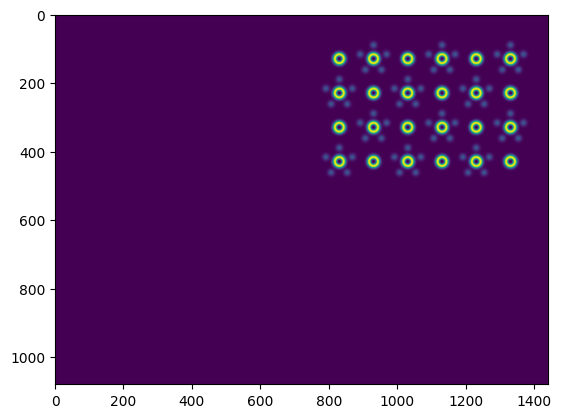

In [23]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 40
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-4)*rad +50 ,centrey + (j-1)*rad] for i in range(6) for j in range(4)]).T
# spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)]).T
spot_locations_list = []
for k in range(bb_locations.T.shape[0]):
    if (k -(k//4))%2 == 1:
        for theta in np.arange(0,2*np.pi,2*np.pi/5):
            spot_locations_list.append([int(bb_locations.T[k][0]+r*np.sin(theta)) , int(bb_locations.T[k][1]-+r*np.cos(theta))])
spot_locations2 = np.array(spot_locations_list).T
target = np.zeros(target_shape)
for spot_location in spot_locations2.T:
    xc, yc = spot_location
    target = target + g(i,j,0.012757392269578168e3,8.997853311827269,xc, yc,0)
for bb_location in bb_locations.T:
    xc, yc = bb_location
    # target = target + bb(i,j,1.30590871e+04,1.30660485e+04,8.56061191e+00,8.54272142e+00,xc,yc)
    target = target + bb(i, j,0.012757392269578168,8.997853311827269, xc, yc, 0)
plt.imshow(target)

In [24]:
spot_locations2.T.shape

(60, 2)

In [25]:
spot_locations = np.array(spot_locations2.T.tolist() + bb_locations.T.tolist())

In [26]:
zernike_calibrations = []
nz = 20
for i in range(len(spot_locations)):
    zernike_xy = np.flip(toolbox.convert_vector([1440+10,1024+65] - spot_locations[i],from_units="ij",to_units="zernike",hardware=fs).T[0])
    zernike_arr = np.concatenate([zernike_xy, np.zeros(nz -2, dtype=zernike_xy.dtype)])
    zernike_calibrations.append({i+1: float(v) for i, v in enumerate(zernike_arr)})
zernike_indices = [i+1 for i in range(nz)]

In [29]:
phase = get_cholo_bb_g_phase(zernike_calibrations=zernike_calibrations,fs = fs,bb_phase = bottle_beam_phase(fs),n=60)

writing phase


array([[2, 1, 1, ..., 2, 2, 2],
       [1, 1, 2, ..., 2, 3, 2],
       [1, 1, 1, ..., 1, 2, 2],
       ...,
       [1, 2, 2, ..., 1, 2, 2],
       [1, 3, 2, ..., 2, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]], dtype=uint16)

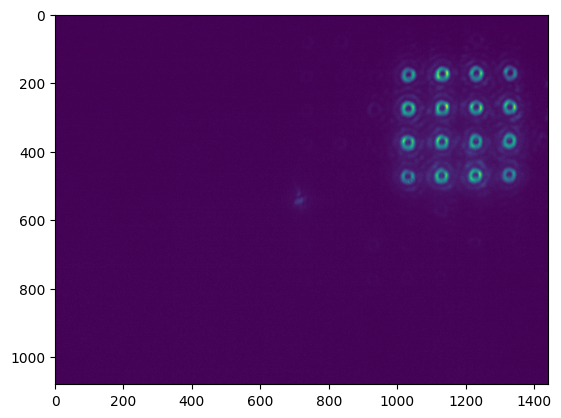

In [400]:
plot_cam(fs=fs,phase = phase)

# Spot array

In [127]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 7
rad = 8*3.4*1.4
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)])
spot_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad ] for i in range(n) for j in range(n)])

In [128]:
spot_locations

array([[1103.84,  191.92],
       [1103.84,  230.  ],
       [1103.84,  268.08],
       [1103.84,  306.16],
       [1103.84,  344.24],
       [1103.84,  382.32],
       [1103.84,  420.4 ],
       [1141.92,  191.92],
       [1141.92,  230.  ],
       [1141.92,  268.08],
       [1141.92,  306.16],
       [1141.92,  344.24],
       [1141.92,  382.32],
       [1141.92,  420.4 ],
       [1180.  ,  191.92],
       [1180.  ,  230.  ],
       [1180.  ,  268.08],
       [1180.  ,  306.16],
       [1180.  ,  344.24],
       [1180.  ,  382.32],
       [1180.  ,  420.4 ],
       [1218.08,  191.92],
       [1218.08,  230.  ],
       [1218.08,  268.08],
       [1218.08,  306.16],
       [1218.08,  344.24],
       [1218.08,  382.32],
       [1218.08,  420.4 ],
       [1256.16,  191.92],
       [1256.16,  230.  ],
       [1256.16,  268.08],
       [1256.16,  306.16],
       [1256.16,  344.24],
       [1256.16,  382.32],
       [1256.16,  420.4 ],
       [1294.24,  191.92],
       [1294.24,  230.  ],
 

In [129]:
phi_nf_gs,phi_ff_gs = gs_spots(bb_locations,fs,n_iters = 100)

1.0204081632653061
0.007967706929012983
0.007967706929012981
0.007967706929012981
0.007967706929012983
0.007967706929012983
0.007967706929012983
0.007967706929012983
0.007967706929012983
0.007967706929012981
0.007967706929012983
0.00796770692901298
0.007967706929012964
0.007967706929011885
0.007967706928941908
0.007967706924414656
0.007967706632371539
0.007967705545709993
0.007966738416521306
0.007913411809451907
0.006395885769294254
0.006730973826099411
0.005016822202514787
0.003442592499589377
0.0024622532695452457
0.0019215906238664302
0.0016079092873063697
0.0014203483892769107
0.001299225776451616
0.001207531069852562
0.0011308798462526485
0.0010630074808799853
0.0010015986854046944
0.0009483993814919187
0.0009025490134804554
0.0008637556622676381
0.0008314837122595604
0.0008056403667293942
0.0007852726362774201
0.0007692307249565079
0.0007571919403939893
0.0007480383018901129
0.000741297815699229
0.000736254411175969
0.0007320104489036085
0.0007284298478747902
0.00072488418831281

writing phase


c:\Users\QC\Envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


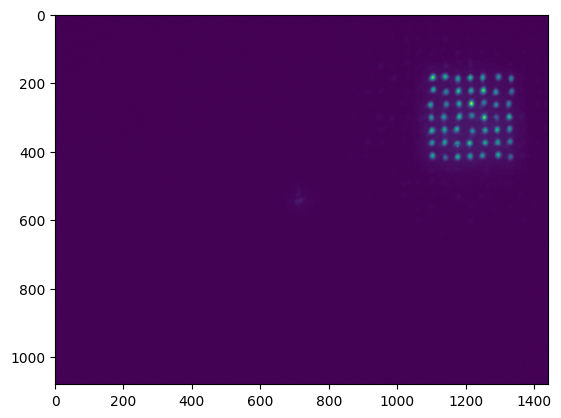

In [130]:
img = plot_cam(fs = fs, phase = phi_nf_gs.numpy())

NameError: name 'mag' is not defined

In [110]:
toolbox.convert_radius(hardware=fs,radius = 1,from_units="ij",to_units="mag_um")

3.4500000000003923

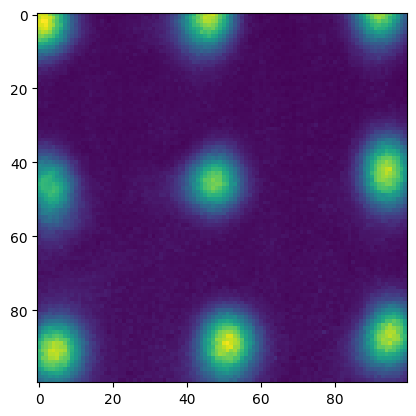

In [98]:
plt.imshow(img[230-50:230+50,1180-50:1180+50])

In [83]:
from src.plots import get_fit_params

optimised params are [322.21214547  -7.80044296  44.9511064   48.07018576   4.13631485]


array([322.21214547,  -7.80044296,  44.9511064 ,  48.07018576,
         4.13631485])

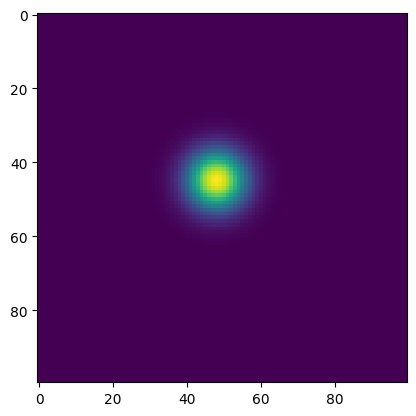

In [89]:
s = 9
get_fit_params(img[int(spot_locations[s][1])-50:int(spot_locations[s][1])+50,int(spot_locations[s][0])-50:int(spot_locations[s][0])+50],trap='g',plot = True)